##### 실행 전 준비사항

**⚙️ 필수 데이터 파일**

- 본 노트북은 원본 데이터를 포함하지 않습니다.
- 전체 코드를 위에서부터 순차적으로 실행하려면 아래 파일을 지정된 경로에 배치하고 개인 API 인증정보를 설정해야 합니다.
- `CARD_SUBWAY_MONTH*.csv`에는 분석 기간인 2021-05-02~2024-01-02의 지하철 승하차 데이터가 모두 포함되어야 합니다.

  ```text
  /content/drive/MyDrive/data
  ├─ raw_data/
  │  ├─ trial_register.csv
  │  ├─ trial_payment.csv
  │  ├─ trial_visit_info.csv
  │  ├─ trial_access_log.csv
  │  └─ site_area.csv
  ├─ subway/
  ├─ 서울시 역사마스터 정보.csv
  ├─ CARD_SUBWAY_MONTH*.csv
  │
  └─covid_data.csv
  ```

**⚙️ 필수 API 설정**

- API 키는 노트북에 직접 입력하지 않고 Google Colab 보안 비밀 또는 별도의 환경변수로 설정하는 것을 권장합니다.
- 개인정보 및 원본 데이터는 제출 파일에서 제외하였으며 데이터 접근 권한이 있는 환경에서만 전체 분석을 재현할 수 있습니다.

| API               | 코드 변수                        | 용도                |
| ----------------- | ---------------------------- | ----------------- |
| 카카오 로컬 API        | `REST_API_KEY`               | 지점 좌표 및 주변 인프라 수집 |
| 네이버 검색 API        | `CLIENT_ID`, `CLIENT_SECRET` | 지점별 블로그 게시글 수집    |
| Google Places API | `GOOGLE_API_KEY`             | 구글 지도 리뷰 수집       |
| Open-Meteo API    | 별도 키 불필요                     | 지점별 과거 기상 데이터 수집  |


# **0\. 프로젝트 개요**

## **🎯 유입에서 수익화까지: 무료체험 전환 체계 진단**

> **방문 수요와 고객 행동·지점별 병목을 반영한 실행 전략 제안**

**7팀 | 김도영 · 김유림 · 김형준 · 이지현 · 임유주 · 정용택**

### **0-1. 분석 배경**

공유오피스의 3일 무료체험은 고객이 공간을 직접 경험하도록 만드는 핵심 유입 장치이다. 그러나 체험 신청자가 늘거나 실제 방문이 유지되더라도, 그 경험이 유료 결제로 이어지지 않으면 사업 성과로 연결되기 어렵다.

따라서 본 프로젝트는 전체 결제율만 확인하는 대신, 고객이 이동하는 과정을 다음과 같이 분리하였다.

> **체험 시작 → 실제 방문 → 서로 다른 날짜의 반복 방문 → 유료 결제 → 이용 지속**

각 단계의 규모와 전환을 따로 확인하여 문제가 발생한 시점과 퍼널 단계, 결제와 연결된 행동, 지점별 병목의 차이를 진단하였다.

### **0-2. 핵심 문제 정의**

> **신청과 방문이 유지되고 있는데 결제율이 낮아졌다면, 고객은 어느 단계에서 멈추고 있으며 어떤 행동과 운영 조건을 바꿔야 하는가?**

본 프로젝트는 이 질문을 세 가지 관점으로 나누어 분석하였다.

| 분석 관점 | 핵심 질문 | 분석 역할 |
| --- | --- | --- |
| 시간·퍼널 | 결제 전환의 이상 신호는 언제, 어느 단계에서 발생했는가? | 전환 구조의 변화 시점과 병목 위치 진단 |
| 사용자 행동 | 결제자에게 공통적으로 나타나는 행동은 무엇이며, 언제 개입해야 하는가? | 전환 행동과 CRM 개입 시점 도출 |
| 지점·입지 | 같은 서비스인데 지점별 성과가 다른 이유는 무엇인가? | 유입·경험·전환 병목과 출점 검증 기준 도출 |

### **0-3. 분석 범위 및 데이터**

- 분석 기간: 2021년 5월 ~ 2023년 12월  
- 기준 모집단: 무료체험 신청자 9,624명  
- 핵심 행동 분석 대상: D0~D2 내 실제 방문자 6,026명  
- 지점 범위: 9개 지점  
- 내부 데이터: 체험 신청, 결제 여부, 방문 요약, 출입 로그, 지점 면적  
- 외부 데이터: 기상·사회적 거리두기, 지하철 유동인구, 주변 인프라, 지도 리뷰, 블로그 게시글  

### **0-4. 분석 설계**

| 단계 | 주요 분석 | 활용 목적 |
| --- | --- | --- |
| Diagnose | 결제율 변화점 탐지, 퍼널 분해, 방문 수요 예측 | 유입과 결제를 분리하고 문제 발생 지점 확인 |
| Convert | 행동 비교, 군집화, 통제 분석, 랜드마크 모델 | 결제와 연결된 행동 및 개입 가능 시점 확인 |
| Expand | 지점 KPI, 유동인구·인프라·리뷰 결합, 지점 유형화 | 기존 지점 운영과 신규 출점의 판단 기준 제안 |

### **0-5. 해석 원칙**

1. 전체 평균보다 단계를 분리한다. 신청·방문·반복 방문·결제를 각각 관리한다.  
2. 상관관계를 인과관계로 단정하지 않는다. 관찰 데이터에서 발견한 신호는 실험으로 검증한다.  
3. 모델은 자동 판정이 아니라 의사결정 보조로 사용한다. 예측값과 점수보다 원시 KPI와 운영 맥락을 우선한다.  
4. 지점 비교는 순위가 아니라 병목 진단으로 해석한다. 각 지점이 유입·경험·전환 중 어디에서 막히는지 구분한다.

# **1\. 라이브러리 및 데이터 불러오기**

**📚 작업 요약**
- 분석에 필요한 라이브러리를 불러오고 Google Drive의 작업 경로를 설정한다.
- 원본 CSV 파일을 테이블별 데이터프레임으로 불러와 이후 점검과 전처리의 기준 데이터를 준비한다.

In [ ]:
# 필요한 라이브러리 및 폰트 설치

!pip install koreanize-matplotlib
!pip install kiwipiepy --quiet
!pip install optuna
!apt-get update -qq
!apt-get install -y fonts-nanum > /dev/null
!fc-cache -fv > /dev/null

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
# 라이브러리 불러오기

import ast
import hashlib
import importlib.util
import math
import os
import re
import subprocess
import sys
import time
import warnings
from collections import Counter
from functools import reduce
from itertools import combinations
from pathlib import Path
import holidays
import numpy as np
import pandas as pd
import requests
import folium
import koreanize_matplotlib
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import networkx as nx
import plotly.express as px
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from PIL import Image, ImageDraw
from wordcloud import WordCloud
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.optimize import brentq
from scipy.stats import (
    chi2_contingency,
    fisher_exact,
    mannwhitneyu,
    pearsonr,
    rankdata,
    spearmanr,
)
from statsmodels.stats.contingency_tables import (
    StratifiedTable,
    mcnemar,
)
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (
    proportion_confint,
    proportion_effectsize,
    proportions_ztest,
)
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.calibration import CalibrationDisplay
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import LatentDirichletAllocation, PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer,
)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    make_scorer,
    mean_absolute_error,
    mean_squared_error,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    silhouette_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    MinMaxScaler,
    OneHotEncoder,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    export_text,
    plot_tree,
)
from lightgbm import LGBMRegressor
from xgboost import XGBClassifier, XGBRegressor
import optuna
import shap
from kiwipiepy import Kiwi
from transformers import pipeline as hf_pipeline
from google.colab import data_table, files

In [ ]:
# Google Drive mount

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 작업 폴더 변경

os.chdir('/content/drive/MyDrive/data')

In [ ]:
# 원본 csv 호출

trial_register = pd.read_csv('raw_data/trial_register.csv')
trial_payment = pd.read_csv('raw_data/trial_payment.csv')
trial_visit_info = pd.read_csv('raw_data/trial_visit_info.csv')
trial_access_log = pd.read_csv('raw_data/trial_access_log.csv')
site_area = pd.read_csv('raw_data/site_area.csv')

# **2\. 원본 데이터 확인**

**🔍 작업 요약**
- 원본 데이터를 변경하기 전에 테이블별 구조, 기간, 결측치, 중복값과 키 정합성을 확인한다.
- 확인 결과와 전처리 방향을 정리하고 데이터 품질 이슈를 체계화한다.

## **2-1. trial_register (체험 시작일 데이터)**

**📌 데이터 요약**

- 무료 체험 사용자의 체험 시작일과 사용자 식별자를 담은 데이터이다.
- 총 9,659행, 고유 사용자는 9,624명이며, 체험 시작일은 2021-05-01 ~ 2023-12-31에 분포한다.
- 결측치는 없으며, 완전 중복 28건과 서로 다른 체험 시작일이 기록된 사용자 7명이 확인되었다.

### 2-1-1. 데이터 구조 확인

In [ ]:
# 규모 확인

trial_register.shape

(9659, 2)

In [ ]:
# 데이터 확인

trial_register.head(10)

,trial_date,user_uuid
0,2023-12-21,2b251333-8676-4c11-a736-dcf2350f8821
1,2023-12-21,e111619a-0975-451b-9a4a-bc8aea7b7b84
2,2023-12-21,4a184795-b056-4572-a874-644f68609ea3
3,2023-12-21,2ba8ab19-2d40-4423-ad04-f0f9ca814871
4,2023-12-21,1d49ba36-6c23-405b-9514-aa7f4aeceff0
5,2023-12-22,283a7a94-8d9e-477a-beb5-29d4d25e4c10
6,2023-12-22,b2d80cf6-2ced-4270-9d7a-43119bba35d2
7,2023-12-22,1c0835bb-8c29-4a0f-a135-9602f87f5690
8,2023-12-22,bde82845-e0dc-48d6-858b-74f7f26ef103
9,2023-12-23,34d68334-ee08-4a87-8879-9320746a52d9


In [ ]:
# 데이터 수집 기간 확인

print(trial_register['trial_date'].min(), ' - ', trial_register['trial_date'].max())

2021-05-01  -  2023-12-31


> **💡 결과 요약**
>
> - `trial_register`는 9,659행, 2개 컬럼으로 구성
> - 주요 컬럼은 체험 시작일인 `trial_date`와 사용자 식별자인 `user_uuid`
> - 데이터 수집 기간은 2021-05-01 ~ 2023-12-31

### 2-1-2. 컬럼별 결측치 및 고유값 확인

In [ ]:
# 컬럼 타입과 결측 여부 확인

trial_register.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9659 entries, 0 to 9658
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   trial_date  9659 non-null   object
 1   user_uuid   9659 non-null   object
dtypes: object(2)
memory usage: 151.1+ KB


In [ ]:
# 컬럼별 고유값 수 확인

trial_register.nunique()

,0
trial_date,855
user_uuid,9624


> **💡 결과 요약**
>
> - 두 컬럼 모두 결측치 없음
> - `trial_date`는 855개, `user_uuid`는 9,624개의 고유값 존재

### 2-1-3. 중복값 확인

In [ ]:
# 완전 중복 행 수 확인

trial_register.duplicated().sum()

np.int64(28)

In [ ]:
# 동일 사용자, 동일 시작일에 중복된 모든 행

same_date = trial_register[
    trial_register.duplicated(
        subset=['user_uuid', 'trial_date'],
        keep=False
    )
].sort_values(['user_uuid', 'trial_date'])

same_date

,trial_date,user_uuid
340,2023-12-11,02458b10-7f2b-4030-950b-ba650ce2fb49
341,2023-12-11,02458b10-7f2b-4030-950b-ba650ce2fb49
132,2023-11-24,039fa563-fc65-4b0c-9087-4beb5cd17fd7
133,2023-11-24,039fa563-fc65-4b0c-9087-4beb5cd17fd7
175,2023-11-27,06e78cdd-c7f0-4b45-af6d-9126125d0686
176,2023-11-27,06e78cdd-c7f0-4b45-af6d-9126125d0686
313,2023-12-09,091cdea5-fc99-47fd-a722-3fe190f9cb26
314,2023-12-09,091cdea5-fc99-47fd-a722-3fe190f9cb26
103,2022-12-27,19c8e329-9654-4178-989d-c93617655650
104,2022-12-27,19c8e329-9654-4178-989d-c93617655650


In [ ]:
# 동일 사용자, 동일 시작일 중복 행 수

len(same_date)

56

In [ ]:
# 서로 다른 날짜에 체험을 재시작한 사용자 기록 확인

different_date = trial_register[
    trial_register['user_uuid'].isin(
        trial_register.groupby('user_uuid')['trial_date']
        .nunique()
        .loc[lambda x: x >= 2]
        .index
    )
].sort_values(['user_uuid', 'trial_date'])

different_date

,trial_date,user_uuid
5624,2022-01-28,14872783-3af7-492a-b51c-12f3003b76f1
5625,2023-02-10,14872783-3af7-492a-b51c-12f3003b76f1
1682,2021-09-06,4008307f-486f-408f-b90b-e01398972029
1683,2022-03-25,4008307f-486f-408f-b90b-e01398972029
3554,2022-03-14,5b16f32b-3344-4b39-b2bf-8cf1caac78fa
3555,2023-03-22,5b16f32b-3344-4b39-b2bf-8cf1caac78fa
4968,2022-09-05,6a88014b-fbbd-4e73-8036-04435c062a97
4969,2023-02-10,6a88014b-fbbd-4e73-8036-04435c062a97
4674,2022-08-02,bd3ed6c2-f139-4e0c-b53e-b956101b2822
4675,2022-10-21,bd3ed6c2-f139-4e0c-b53e-b956101b2822


In [ ]:
# 서로 다른 날짜 재시작 사용자 행 수

len(different_date)

14

> **💡 결과 요약**
>
> - 완전 중복으로 판정된 건은 28건, 서로 다른 체험 시작일이 기록된 사용자는 7명으로 확인
> - 동일 사용자/동일 체험 시작일의 완전 중복은 1건 씩으로 병합 필요, 서로 다른 체험 시작일 기록은 복수 체험 기록일 수 있으므로 우선 보존

## **2-2. trial_payment (결제 데이터)**

**📌 데이터 요약**

- 체험 신청자의 최종 결제 여부를 담은 데이터이다.
- 총 9,659행, 고유 사용자는 9,624명이며, 결제 여부는 결제와 미결제 두 값으로 구성된다.
- 결측치는 없으며, 완전 중복 35건이 존재하지만 동일 사용자에게 서로 다른 결제값이 부여된 사례는 없다.

### 2-2-1. 데이터 구조 확인

In [ ]:
# 규모 확인

trial_payment.shape

(9659, 2)

In [ ]:
# 데이터 확인

trial_payment.head(10)

,is_payment,user_uuid
0,0,2b251333-8676-4c11-a736-dcf2350f8821
1,0,e111619a-0975-451b-9a4a-bc8aea7b7b84
2,1,4a184795-b056-4572-a874-644f68609ea3
3,0,2ba8ab19-2d40-4423-ad04-f0f9ca814871
4,0,1d49ba36-6c23-405b-9514-aa7f4aeceff0
5,0,283a7a94-8d9e-477a-beb5-29d4d25e4c10
6,0,b2d80cf6-2ced-4270-9d7a-43119bba35d2
7,1,1c0835bb-8c29-4a0f-a135-9602f87f5690
8,0,bde82845-e0dc-48d6-858b-74f7f26ef103
9,1,34d68334-ee08-4a87-8879-9320746a52d9


In [ ]:
# 고유 사용자 기준 결제 여부 비율 확인

trial_payment.drop_duplicates('user_uuid')['is_payment'].value_counts(
    normalize=True
).sort_index().mul(100).round(2)

,proportion
is_payment,
0,62.05
1,37.95


> **💡 결과 요약**
>
> - `trial_payment`는 9,659행, 2개 컬럼으로 구성
> - 고유 사용자 기준 미결제 비율은 62.05%, 결제 비율은 37.95%
> - 결제 전환 여부를 나타내는 `is_payment`를 사용자 단위 타깃 변수로 활용할 수 있음

### 2-2-2. 컬럼별 결측치 및 고유값 확인

In [ ]:
# 컬럼 타입과 결측 여부 확인

trial_payment.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9659 entries, 0 to 9658
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   is_payment  9659 non-null   int64 
 1   user_uuid   9659 non-null   object
dtypes: int64(1), object(1)
memory usage: 151.1+ KB


In [ ]:
# 컬럼별 고유값 수 확인

trial_payment.nunique()

,0
is_payment,2
user_uuid,9624


> **💡 결과 요약**
>
> - 두 컬럼 모두 결측치 없음
> - `is_payment`는 2개, `user_uuid`는 9,624개의 고유값 존재

### 2-2-3. 중복값 및 일관성 확인

In [ ]:
# 완전 중복 행 수 확인

trial_payment.duplicated().sum()

np.int64(35)

In [ ]:
# 동일 사용자에게 서로 다른 결제 라벨이 존재하는지 확인

payment_conflict_users = (
    trial_payment.groupby('user_uuid')['is_payment']
    .nunique()
    .loc[lambda x: x >= 2]
    .index
)

trial_payment[
    trial_payment['user_uuid'].isin(payment_conflict_users)
].sort_values(['user_uuid', 'is_payment'])

,is_payment,user_uuid


> **💡 결과 요약**
>
> - 완전 중복으로 판정된 추가 행은 35건
> - 동일 사용자에게 결제와 미결제 값이 동시에 부여된 사례는 없음
> - 완전 중복을 제거한 뒤 사용자별 결제 여부를 1건만 유지해도 결제 라벨의 일관성은 보존됨

## **2-3. trial_visit_info (방문 데이터)**

**📌 데이터 요약**

- 사용자의 방문일, 지점, 입/퇴실 시각과 체류시간을 담은 방문 요약 데이터이다.
- 총 11,477행, 고유 사용자는 6,534명, 지점은 9개이며, 방문일은 2021-05-02~2024-01-02에 분포한다.
- 완전 중복 48건, 입/퇴실 시각 동시 결측 555건, 동일 사용자/지점/날짜의 복수 기록 84개가 확인되었다.
- 자정 전후로 연결되는 기록은 605건이며, 하나의 방문이 날짜 경계에서 분리된 경우가 다수 존재한다.

### 2-3-1. 데이터 구조 확인

In [ ]:
# 규모 확인

trial_visit_info.shape

(11477, 7)

In [ ]:
# 데이터 확인

trial_visit_info.head(10)

,site_id,date,stay_time,stay_time_second,first_enter_time,last_leave_time,user_uuid
0,1,2023-12-23,01:11:19.983486,4279,2023-12-23 16:11:25.345793,2023-12-23 17:25:32.233995,939fc566-61cd-47f0-a3ce-e2936fdcff73
1,1,2023-12-24,04:35:10.361341,16510,2023-12-24 16:10:45.668026,2023-12-24 20:53:34.842447,939fc566-61cd-47f0-a3ce-e2936fdcff73
2,1,2023-12-25,02:09:54.117163,7794,2023-12-25 10:19:47.087268,2023-12-25 12:39:51.221372,939fc566-61cd-47f0-a3ce-e2936fdcff73
3,1,2023-12-23,04:37:36.134901,16656,2023-12-23 14:49:40.302823,2023-12-23 19:27:39.406803,ba49324f-d317-4053-adf9-2b17b3f07594
4,3,2023-12-26,04:32:05.289251,16325,2023-12-26 14:57:10.220793,2023-12-26 19:34:36.971542,ba49324f-d317-4053-adf9-2b17b3f07594
5,6,2023-12-25,05:51:31.276580,21091,2023-12-25 14:38:26.896366,2023-12-25 20:29:58.172946,ba49324f-d317-4053-adf9-2b17b3f07594
6,1,2023-12-23,05:27:51.797120,19671,2023-12-23 15:53:41.172357,2023-12-23 22:34:21.779882,4c5b26a3-24d4-4b8f-a591-be80271c0aeb
7,1,2023-12-23,05:27:51.797120,19671,2023-12-23 15:53:41.172357,2023-12-23 22:34:21.779882,4c5b26a3-24d4-4b8f-a591-be80271c0aeb
8,1,2023-12-24,07:58:18.169248,28698,2023-12-24 13:33:07.764120,2023-12-24 22:41:41.588923,4c5b26a3-24d4-4b8f-a591-be80271c0aeb
9,1,2023-12-24,07:58:18.169248,28698,2023-12-24 13:33:07.764120,2023-12-24 22:41:41.588923,4c5b26a3-24d4-4b8f-a591-be80271c0aeb


In [ ]:
# 데이터 수집 기간 확인

print(trial_visit_info['date'].min(), ' - ', trial_visit_info['date'].max())

2021-05-02  -  2024-01-02


In [ ]:
# 체류시간(초 단위) 분포 확인

trial_visit_info['stay_time_second'].describe()

,stay_time_second
count,11477.000000
mean,16689.460922
std,11968.841154
min,1.000000
25%,7776.000000
50%,14699.000000
75%,23326.000000
max,86377.000000


In [ ]:
# 방문일과 입/퇴실 시각을 datetime으로 변환해 시간값을 확인

visit_check = trial_visit_info.copy()

visit_check['date'] = pd.to_datetime(
    visit_check['date'],
    errors='coerce'
)

visit_check[['first_enter_time', 'last_leave_time']] = (
    visit_check[['first_enter_time', 'last_leave_time']]
    .apply(
        lambda x: pd.to_datetime(
            x,
            format='mixed',
            errors='coerce'
        )
    )
)

visit_check[['first_enter_time', 'last_leave_time']].apply(
    lambda x: x.dt.strftime('%H:%M:%S')
).describe()

,first_enter_time,last_leave_time
count,10922,10922
unique,9105,8963
top,00:00:00,23:59:59
freq,747,734


In [ ]:
# 지점별 고유 이용자 수와 지점 단위 이용자 비중 확인

site_ratio = (
    trial_visit_info.groupby('site_id')['user_uuid']
    .nunique()
    .reset_index(name='이용자수')
)

site_ratio['비율'] = (
    site_ratio['이용자수']
    / site_ratio['이용자수'].sum()
    * 100
).round(2)

site_ratio.sort_values('비율', ascending=False)

,site_id,이용자수,비율
2,3,1402,20.39
5,6,1331,19.35
1,2,1131,16.45
0,1,918,13.35
4,5,619,9.00
3,4,517,7.52
6,17,482,7.01
7,47,332,4.83
8,49,145,2.11


> **💡 결과 요약**
>
> - `trial_visit_info`는 11,477행, 7개 컬럼으로 구성
> - 방문일은 2021-05-02 ~ 2024-01-02에 분포
> - 체류시간은 1초 ~ 86,377초이며 중앙값은 14,699초
> - 시간 컬럼의 freq 값(00:00:00, 23:59:59) 확인 필요 (700건 이상 분포)
> - 지점별 이용자 비중은 3번 지점과 6번 지점이 상대적으로 높게 나타남

### 2-3-2. 컬럼별 결측치 및 고유값 확인

In [ ]:
# 컬럼 타입과 결측 여부 확인

trial_visit_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11477 entries, 0 to 11476
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   site_id           11477 non-null  int64 
 1   date              11477 non-null  object
 2   stay_time         11477 non-null  object
 3   stay_time_second  11477 non-null  int64 
 4   first_enter_time  10922 non-null  object
 5   last_leave_time   10922 non-null  object
 6   user_uuid         11477 non-null  object
dtypes: int64(2), object(5)
memory usage: 627.8+ KB


In [ ]:
# 컬럼별 결측치 수 확인

trial_visit_info.isna().sum()

,0
site_id,0
date,0
stay_time,0
stay_time_second,0
first_enter_time,555
last_leave_time,555
user_uuid,0


In [ ]:
# 입실/퇴실 시각의 동시 결측과 한쪽만 결측인 기록 구분

both_missing = (
    trial_visit_info['first_enter_time'].isna()
    & trial_visit_info['last_leave_time'].isna()
)

one_missing = (
    trial_visit_info['first_enter_time'].isna()
    != trial_visit_info['last_leave_time'].isna()
)

pd.Series({
    '두 컬럼 결측': both_missing.sum(),
    '한쪽만 결측': one_missing.sum()
})

,0
두 컬럼 결측,555
한쪽만 결측,0


In [ ]:
# 입/퇴실 시각이 모두 결측인 기록의 발생 기간 확인

trial_visit_info.loc[
    both_missing, 'date'
].agg(['min', 'max'])

,date
min,2021-05-02
max,2021-06-29


In [ ]:
# 입/퇴실 시각이 모두 결측인 기록의 날짜별 발생 건수 확인

trial_visit_info.loc[
    both_missing, 'date'
].value_counts().sort_index()

,count
date,
2021-05-02,1
2021-05-03,1
2021-05-04,1
2021-05-05,3
2021-05-06,3
2021-05-07,3
2021-05-08,1
2021-05-09,1
2021-05-10,2


In [ ]:
# 입/퇴실 시각이 모두 결측인 고유 사용자 수 확인

missing_users = trial_visit_info[
    trial_visit_info['first_enter_time'].isna()
    & trial_visit_info['last_leave_time'].isna()
]['user_uuid'].nunique()

missing_users

332

In [ ]:
# 방문 데이터의 컬럼별 고유값 수 확인

trial_visit_info.nunique()

,0
site_id,9
date,972
stay_time,11429
stay_time_second,9725
first_enter_time,10599
last_leave_time,10599
user_uuid,6534


> **💡 결과 요약**
>
> - `first_enter_time`과 `last_leave_time`에서 각각 555건의 결측치가 확인
> - 두 시간 컬럼은 항상 함께 결측되며 한쪽만 결측인 기록은 없음
> - 결측 기록은 2021-05-02~2021-06-29에 집중되어 있으며 332명에게 발생
> - 고유 사용자 6,534명, 지점 9개로 구성

### 2-3-3. 중복값 및 사용자/지점/날짜 기준 복수 기록 확인

In [ ]:
# 완전 중복 행 수 확인

trial_visit_info.duplicated().sum()

np.int64(48)

In [ ]:
# 동일 사용자/지점/날짜에 복수 기록이 존재하는 키 확인

visit_daily_count = (
    trial_visit_info
    .groupby(['user_uuid', 'site_id', 'date'])
    .size()
    .reset_index(name='기록수')
)

visit_daily_count[
    visit_daily_count['기록수'] >= 2
].sort_values('기록수', ascending=False)

,user_uuid,site_id,date,기록수
3856,53c0a5d6-8622-4ec9-8800-f731df46ecec,17,2023-02-10,4
1180,171e2bf6-67f8-4b62-9ae4-52e129278df2,3,2023-02-20,3
10844,f2f2af5a-2d07-4b23-8b79-f0c80e00a1b4,1,2023-02-08,3
104,02458b10-7f2b-4030-950b-ba650ce2fb49,1,2023-12-11,2
160,039fa563-fc65-4b0c-9087-4beb5cd17fd7,1,2023-11-25,2
...,...,...,...,...
10998,f655be50-4b26-46cb-823b-bcc01108b3cc,2,2023-12-04,2
10999,f655be50-4b26-46cb-823b-bcc01108b3cc,2,2023-12-05,2
11000,f655be50-4b26-46cb-823b-bcc01108b3cc,2,2023-12-06,2
11011,f686e1ee-d37a-4fc2-96ca-b3ead1c8fd06,3,2022-03-25,2


> **💡 결과 요약**
>
> - 완전 중복으로 판정된 추가 행은 48건
> - 동일 사용자/지점/날짜에 복수 기록이 존재하는 키는 84개
> - 복수 기록에는 완전 중복이 아닌 서로 다른 기록도 포함되어 있어 실제 재방문 여부를 세부 행 기준으로 추가 확인해야 함

### 2-3-4. stay_time, stay_time_second 일치 여부 확인

In [ ]:
# 문자열 체류시간과 초 단위 체류시간의 정수부가 일치하는지 확인

stay_time_seconds = pd.to_timedelta(
    trial_visit_info['stay_time']
).dt.total_seconds()

(stay_time_seconds.astype(int) == trial_visit_info['stay_time_second']).value_counts()

,count
True,11477


In [ ]:
# 두 체류시간 컬럼 소수점 단위 차이 확인

(stay_time_seconds - trial_visit_info['stay_time_second']).describe()

,0
count,11477.000000
mean,0.498640
std,0.288079
min,0.000000
25%,0.247809
50%,0.497017
75%,0.749784
max,0.999967


> **💡 결과 요약**
>
> - 전체 11,477행에서 `stay_time`의 정수 초와 `stay_time_second`가 일치
> - 두 컬럼의 차이는 소수점 이하 시간으로 0초 이상 1초 미만
> - 이후 체류시간 집계와 모델링에는 수치형인 `stay_time_second`를 대표 변수로 사용하는 것이 적절

### 2-3-5. 입실/퇴실 순서 및 이용시간 일관성 확인

In [ ]:
# 입/퇴실 시각이 모두 존재하는 방문 기록 생성

visit_time = trial_visit_info.dropna(
    subset=['first_enter_time', 'last_leave_time']
).copy()

In [ ]:
# 입/퇴실 시각을 datetime으로 변환

visit_time['first_enter_time'] = pd.to_datetime(
    visit_time['first_enter_time'],
    format='mixed'
)

visit_time['last_leave_time'] = pd.to_datetime(
    visit_time['last_leave_time'],
    format='mixed'
)

In [ ]:
# 입실부터 퇴실까지의 전체 경과시간을 초 단위로 계산

visit_time['total_time_second'] = (
    visit_time['last_leave_time']
    - visit_time['first_enter_time']
).dt.total_seconds()

In [ ]:
# 전체 경과시간이 실제 체류시간보다 짧은 비정상 기록 확인

(
    visit_time['total_time_second']
    >= visit_time['stay_time_second']
).value_counts()

,count
True,10922


> **💡 결과 요약**
>
> - 입·퇴실 시각이 모두 존재하는 10,922건에서 입실부터 퇴실까지의 경과시간은 모두 `stay_time_second` 이상
> - 퇴실 시각이 입실 시각보다 앞서는 비정상적인 시간 순서는 확인되지 않음
> - 입실부터 퇴실까지의 전체 경과시간과 실제 체류시간은 서로 다른 개념이므로 별도 변수로 구분해 사용

### 2-3-6. 자정 경계값 확인

In [ ]:
# 자정에 시작하거나 하루 마지막 시각에 종료된 방문 수 확인

pd.Series({
    '00:00:00 입실': (
        visit_check['first_enter_time'].dt.strftime('%H:%M:%S')
        == '00:00:00'
    ).sum(),

    '23:59:59 퇴실': (
        visit_check['last_leave_time'].dt.strftime('%H:%M:%S')
        == '23:59:59'
    ).sum()
})

,0
00:00:00 입실,747
23:59:59 퇴실,734


In [ ]:
# 자정에 입실한 방문 기록 확인

visit_check[
    visit_check['first_enter_time'].dt.strftime('%H:%M:%S')
    == '00:00:00'
].head()

,site_id,date,stay_time,stay_time_second,first_enter_time,last_leave_time,user_uuid
56,2,2023-12-31,00:29:10.819442,1750,2023-12-31,2023-12-31 00:30:23.216706,a806f6d6-4bea-40df-b870-212859386e9d
86,3,2023-12-29,15:20:42.919489,55242,2023-12-29,2023-12-29 15:26:42.106259,f70fa4ed-8364-499c-8c49-6d232e6c271b
104,6,2023-12-21,07:26:24.856611,26784,2023-12-21,2023-12-21 13:48:44.547279,4df43903-b549-405f-90e2-aa769c301ba9
124,6,2023-12-28,00:04:29.487973,269,2023-12-28,2023-12-28 00:04:29.487973,868bd6d8-a092-4e16-8974-87c11ac0e357
130,6,2023-12-30,19:35:03.337942,70503,2023-12-30,2023-12-30 20:38:07.472557,fa06b23d-3a20-448f-8791-557beff8df9f


In [ ]:
# 23시 59분 59초에 퇴실한 방문 기록 확인

visit_check[
    visit_check['last_leave_time'].dt.strftime('%H:%M:%S')
    == '23:59:59'
].head()

,site_id,date,stay_time,stay_time_second,first_enter_time,last_leave_time,user_uuid
55,2,2023-12-30,01:51:51.539863,6711,2023-12-30 22:05:32.822669,2023-12-30 23:59:59,a806f6d6-4bea-40df-b870-212859386e9d
105,6,2023-12-20,01:42:00.461017,6120,2023-12-20 22:17:58.538983,2023-12-20 23:59:59,4df43903-b549-405f-90e2-aa769c301ba9
123,6,2023-12-27,01:40:41.572004,6041,2023-12-27 22:06:43.013016,2023-12-27 23:59:59,868bd6d8-a092-4e16-8974-87c11ac0e357
129,6,2023-12-29,10:51:25.456197,39085,2023-12-29 12:39:05.814511,2023-12-29 23:59:59,fa06b23d-3a20-448f-8791-557beff8df9f
134,6,2023-12-29,02:12:38.389004,7958,2023-12-29 21:30:20.638522,2023-12-29 23:59:59,ad815a70-8cb6-4476-ba57-b58463ea127f


In [ ]:
# 사용자/지점별 이전 방문일과 이전 퇴실 시각 연결

visit_midnight_check = visit_check.sort_values(
    ['user_uuid', 'site_id', 'date', 'first_enter_time']
).copy()

visit_midnight_check['previous_date'] = (
    visit_midnight_check
    .groupby(['user_uuid', 'site_id'])['date']
    .shift()
)

visit_midnight_check['previous_leave_time'] = (
    visit_midnight_check
    .groupby(['user_uuid', 'site_id'])['last_leave_time']
    .shift()
)

In [ ]:
# 전날 23시 59분 59초 퇴실과 다음 날 자정 입실이 연결된 기록 확인

midnight_visit = visit_midnight_check[
    (
        visit_midnight_check['first_enter_time']
        .dt.strftime('%H:%M:%S')
        == '00:00:00'
    )
    & (
        visit_midnight_check['previous_leave_time']
        .dt.strftime('%H:%M:%S')
        == '23:59:59'
    )
    & (
        (
            visit_midnight_check['date']
            - visit_midnight_check['previous_date']
        ).dt.days
        == 1
    )
]

print('자정 기준으로 연결되는 기록 수:', len(midnight_visit))

midnight_visit[
    [
        'user_uuid',
        'site_id',
        'previous_date',
        'previous_leave_time',
        'date',
        'first_enter_time'
    ]
]

자정 기준으로 연결되는 기록 수: 605


,user_uuid,site_id,previous_date,previous_leave_time,date,first_enter_time
9425,007ffab4-0b86-4683-a6c1-cff33a587503,6,2022-11-01,2022-11-01 23:59:59,2022-11-02,2022-11-02
9423,007ffab4-0b86-4683-a6c1-cff33a587503,6,2022-11-02,2022-11-02 23:59:59,2022-11-03,2022-11-03
2028,00a94a4e-2cb0-4b49-b250-349bd51aff31,2,2023-11-26,2023-11-26 23:59:59,2023-11-27,2023-11-27
1554,0152c8d8-de3e-4561-8941-65f3c1b00b2e,17,2023-08-30,2023-08-30 23:59:59,2023-08-31,2023-08-31
4003,01f34380-e3f2-4f43-9e1c-32a28cfef3b1,3,2022-11-08,2022-11-08 23:59:59,2022-11-09,2022-11-09
...,...,...,...,...,...,...
1297,fe23b21e-eae2-4eca-8b15-05a6565406fe,6,2021-11-25,2021-11-25 23:59:59,2021-11-26,2021-11-26
1298,fe23b21e-eae2-4eca-8b15-05a6565406fe,6,2021-11-26,2021-11-26 23:59:59,2021-11-27,2021-11-27
1541,fe29a881-a94c-42d5-a186-a555900fe689,6,2021-12-05,2021-12-05 23:59:59,2021-12-06,2021-12-06
1540,fe29a881-a94c-42d5-a186-a555900fe689,6,2021-12-06,2021-12-06 23:59:59,2021-12-07,2021-12-07


> **💡 결과 요약**
>
> - `00:00:00` 입실은 747건, `23:59:59` 퇴실은 734건
> - 전날 `23:59:59` 퇴실과 다음 날 `00:00:00` 입실이 연결되는 기록은 605건
> - 하나의 연속 방문이 날짜 경계에서 두 행으로 분리되었을 가능성이 높음

## **2-4. trial_access_log (출입 로그 데이터)**

**📌 데이터 요약**

- 사용자의 입실과 퇴실이 각각 하나의 행으로 기록된 출입 이벤트 데이터이다.
- 총 63,708행, 고유 사용자는 6,026명, 지점은 9개로 구성되어 있다.
- 결측치는 없으며, 완전 중복 359건이 확인되었다.
- 출입 로그에 9시간을 더했을 때 방문 데이터와 가장 많은 시각이 일치하여 이는 UTC로 추정되며, 사용자별 입/퇴실 횟수가 일치하지 않는 사례도 존재한다.

### 2-4-1. 데이터 구조 확인

In [ ]:
# 규모 확인

trial_access_log.shape

(63708, 5)

In [ ]:
# 데이터 확인

trial_access_log.head(10)

,id,checkin,cdate,site_id,user_uuid
0,1719038,1,2023-07-07 07:11:55.201673,49,cacd0adb-2c87-450f-8a00-2b2ea6b8fa89
1,1716702,2,2023-07-06 15:15:58.761284,49,cacd0adb-2c87-450f-8a00-2b2ea6b8fa89
2,1719956,2,2023-07-07 14:10:41.848998,49,cacd0adb-2c87-450f-8a00-2b2ea6b8fa89
3,1716588,1,2023-07-06 13:09:48.758097,49,cacd0adb-2c87-450f-8a00-2b2ea6b8fa89
4,1719649,1,2023-07-07 10:12:42.083352,49,cacd0adb-2c87-450f-8a00-2b2ea6b8fa89
5,1716712,1,2023-07-06 15:28:39.279318,49,cacd0adb-2c87-450f-8a00-2b2ea6b8fa89
6,1716731,2,2023-07-06 18:17:33.011298,49,cacd0adb-2c87-450f-8a00-2b2ea6b8fa89
7,1719953,1,2023-07-07 14:08:25.192590,49,cacd0adb-2c87-450f-8a00-2b2ea6b8fa89
8,1719535,2,2023-07-07 09:22:36.745763,49,cacd0adb-2c87-450f-8a00-2b2ea6b8fa89
9,1719752,2,2023-07-07 11:09:52.861538,49,cacd0adb-2c87-450f-8a00-2b2ea6b8fa89


> **💡 결과 요약**
>
> - `trial_access_log`는 63,708행, 5개 컬럼으로 구성
> - 주요 컬럼은 이벤트 ID, 입·퇴실 구분값, 발생 시각, 지점 ID와 사용자 ID
> - 한 사용자의 방문을 여러 개의 출입 이벤트로 기록한 로그 단위 데이터

### 2-4-2. 컬럼별 결측치 및 고유값 확인

In [ ]:
# 컬럼 타입과 결측 여부 확인

trial_access_log.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63708 entries, 0 to 63707
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         63708 non-null  int64 
 1   checkin    63708 non-null  int64 
 2   cdate      63708 non-null  object
 3   site_id    63708 non-null  int64 
 4   user_uuid  63708 non-null  object
dtypes: int64(3), object(2)
memory usage: 2.4+ MB


In [ ]:
# 컬럼별 고유값 수 확인

trial_access_log.nunique()

,0
id,63349
checkin,2
cdate,63349
site_id,9
user_uuid,6026


> **💡 결과 요약**
>
> - 모든 컬럼에서 결측치는 없음
> - 이벤트 ID와 발생 시각은 각각 63,349개, 사용자는 6,026명, 지점은 9개의 고유값 존재

### 2-4-3. 중복값 확인

In [ ]:
# 완전 중복 행 수 확인

trial_access_log.duplicated().sum()

np.int64(359)

> **💡 결과 요약**
>
> - 완전 중복으로 판정된 추가 행은 359건

### 2-4-4. trial_access_log와 visit_info 시간 확인


In [ ]:
# 완전 중복을 제거한 출입 로그의 발생 시각을 초 단위 datetime으로 변환

access_time = trial_access_log.drop_duplicates()[
    ['user_uuid', 'site_id', 'cdate']
].copy()

access_time['cdate'] = pd.to_datetime(
    access_time['cdate'],
    format='mixed'
).dt.floor('s')

In [ ]:
# 방문 데이터의 입실/퇴실 시각을 하나의 경계시각 데이터로 구성

visit_boundary_time = pd.concat([
    trial_visit_info[
        ['user_uuid', 'site_id', 'first_enter_time']
    ].rename(columns={'first_enter_time': 'visit_time'}),

    trial_visit_info[
        ['user_uuid', 'site_id', 'last_leave_time']
    ].rename(columns={'last_leave_time': 'visit_time'})
]).dropna().drop_duplicates()

visit_boundary_time['visit_time'] = pd.to_datetime(
    visit_boundary_time['visit_time'],
    format='mixed'
).dt.floor('s')

In [ ]:
# 출입 로그와 방문 시각의 일치 건수 확인

access_time.merge(
    visit_boundary_time,
    left_on=['user_uuid', 'site_id', 'cdate'],
    right_on=['user_uuid', 'site_id', 'visit_time']
).shape[0]

0

In [ ]:
# 출입 로그에 시간대별 보정을 적용해 방문 경계시각과 일치 건수 비교

time_match = {}

for hour in range(24):
    temp = access_time.copy()

    temp['adjusted_time'] = (
        temp['cdate'] + pd.Timedelta(hours=hour)
    )

    time_match[hour] = temp.merge(
        visit_boundary_time,
        left_on=['user_uuid', 'site_id', 'adjusted_time'],
        right_on=['user_uuid', 'site_id', 'visit_time']
    ).shape[0]

In [ ]:
# 시간 보정값별 일치 건수 확인

pd.Series(time_match).sort_values(ascending=False)

,0
9,9170
7,3
8,3
5,3
15,2
11,2
4,2
3,1
22,1
12,1


> **💡 결과 요약**
>
> - 시간 보정 전에는 출입 로그와 방문 데이터의 입·퇴실 시각이 정확히 일치하는 기록이 없음
> - 출입 로그에 9시간을 더했을 때 9,170건으로 가장 많은 시각이 일치
> - UTC와 KST 간 시차일 가능성이 있음
> - 원본 시각을 유지한 채 보정 컬럼을 별도로 생성할 필요가 있음

### 2-4-5. 입/퇴실 수 일치 여부

In [ ]:
# 원본 출입 로그에서 사용자별 입실/퇴실 횟수 차이 확인

access_inout_raw = (
    trial_access_log
    .groupby(['user_uuid', 'checkin'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[1, 2], fill_value=0)
    .rename(columns={1: 'enter_count', 2: 'leave_count'})
)

access_inout_raw['diff'] = (
    access_inout_raw['enter_count']
    - access_inout_raw['leave_count']
)

access_inout_raw['diff'].abs().value_counts().sort_index()

,count
diff,
0,4264
1,1407
2,276
3,55
4,14
5,1
6,2
7,1
8,4


> **💡 결과 요약**
>
> - 전체 사용자 중 4,264명은 입실과 퇴실 횟수 일치
> - 나머지 1,762명은 입/퇴실 횟수에 차이가 있으며 대부분의 차이는 1건
> - 중복 제거와 분석 기간 경계의 영향을 반영한 뒤 다시 검증 필요

## **2-5. site_area (지점 데이터)**

**📌 데이터 요약**

- 각 지점의 면적 정보를 담은 지점 단위 기준 데이터이다.
- 총 9행, 지점 9개로 구성되어 있으며, 면적은 50평, 100평, 150평으로 구분된다.
- 결측치는 없으며, 방문 및 출입 데이터에 존재하는 모든 지점이 `site_area`에 포함되어 있다.

In [ ]:
# 규모 확인

site_area.shape

(9, 2)

In [ ]:
# 데이터 확인

site_area

,site_id,area_pyeong
0,1,50
1,2,100
2,3,150
3,4,100
4,5,150
5,6,150
6,17,50
7,47,50
8,49,50


In [ ]:
# 지점 면적의 기초통계량 확인

site_area['area_pyeong'].describe()

,area_pyeong
count,9.000000
mean,94.444444
std,46.398036
min,50.000000
25%,50.000000
50%,100.000000
75%,150.000000
max,150.000000


In [ ]:
# 컬럼 타입과 결측 여부 확인

site_area.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   site_id      9 non-null      int64
 1   area_pyeong  9 non-null      int64
dtypes: int64(2)
memory usage: 276.0 bytes


In [ ]:
# 방문/출입 데이터와 지점 기준정보의 site_id 일치 여부 확인

area_sites = set(site_area['site_id'])
visit_sites = set(trial_visit_info['site_id'])
access_sites = set(trial_access_log['site_id'])

pd.Series({
    '방문 데이터에만 존재하는 지점': visit_sites - area_sites,
    '출입 로그에만 존재하는 지점': access_sites - area_sites,
    'site_area에만 존재하는 지점': (
        area_sites - visit_sites - access_sites
    )
})

,0
방문 데이터에만 존재하는 지점,{}
출입 로그에만 존재하는 지점,{}
site_area에만 존재하는 지점,{}


> **💡 결과 요약**
>
> - `site_area`는 9행, 2개 컬럼으로 지점별 면적 정보가 한 행씩 구성
> - 결측치는 없으며 면적은 50평, 100평, 150평 세 구간으로 분포
> - 방문 및 출입 데이터에 존재하는 모든 지점이 site_area에 포함됨

## **2-6. 원본 데이터 요약 및 품질 이슈 정리**

### 2-6-1. 원본 데이터 기본 구조

| 테이블 | 원본 행 단위 | 원본 규모 | 주요 컬럼 | 날짜·시간 관련 컬럼 |
|---|---|---|---|---|
| `trial_register` | 체험 신청 기록 1건 | 9,659행 / 고유 사용자 9,624명 | `user_uuid`, `trial_date` | `trial_date` |
| `trial_payment` | 사용자별 결제 여부 기록 1건 | 9,659행 / 고유 사용자 9,624명 | `user_uuid`, `is_payment` | 없음 |
| `trial_visit_info` | 사용자 방문 기록 1건 | 11,477행 / 고유 사용자 6,534명 / 지점 9개 | `user_uuid`, `site_id`, `date`, `stay_time`, `stay_time_second`, `first_enter_time`, `last_leave_time` | `date`, `first_enter_time`, `last_leave_time` |
| `trial_access_log` | 출입 이벤트 기록 1건 | 63,708행 / 고유 사용자 6,026명 / 지점 9개 | `id`, `user_uuid`, `site_id`, `cdate`, `checkin` | `cdate` |
| `site_area` | 지점 정보 1건 | 9행 / 지점 9개 | `site_id`, `area_pyeong` | 없음 |


### 2-6-2. 원본 데이터 요약 및 품질 이슈 정리

| 테이블 | 원본 규모 | 주요 품질 이슈 | 주의사항 |
|---|---|---|---|
| `trial_register` | 9,659행 / 고유 사용자 9,624명 | 완전 중복 28건, 서로 다른 날짜의 재신청 사용자 7명 | 정확한 72시간 분석 불가능, 신청일만으로 결제/방문 순서를 세부 시간 단위로 해석 금지 |
| `trial_payment` | 9,659행 / 고유 사용자 9,624명 | 완전 중복 35건 | 결제 날짜가 없어 결제까지 걸린 시간이나 신청 후 일정 기간 내 결제율 계산 불가 |
| `trial_visit_info` | 11,477행 / 고유 사용자 6,534명 | 완전 중복 48건, 동일 사용자/지점/날짜 복수 기록 84개, 입/퇴실 시각 결측 555건, 자정 전후 연결 기록 605건 | 시간 결측 기록을 모두 삭제하면 방문자와 방문량이 과소계상될 수 있음, 하나의 연속 방문이 날짜 경계에서 두 개의 방문으로 분리될 수 있음 |
| `trial_access_log` | 63,708행 / 고유 사용자 6,026명 | 완전 중복 359건, 입/퇴실 횟수 불일치 사용자 1,762명, cdate는 UTC로 추정 | 중복 이벤트와 미완결 출입 기록으로 출입 횟수 및 세션 수가 왜곡될 수 있음 |
| `site_area` | 9행 / 지점 9개 | 결측치와 중복값이 확인되지 않음 | 지점 수가 적어 면적별 결과를 일반화하거나 과도하게 순위화하기 어려움 |

# **3\. 데이터 전처리**

**🧹 작업 요약**
- 5개 원본 테이블의 사용자 식별자, 자료형과 중복값을 공통 기준으로 정리한다.
- 최신 체험 시작일 기준으로 방문/출입 데이터를 연결하고 출입로그를 활용해 방문 시간 결측을 보완한다.
- 사용자 단위 마스터 테이블 생성에 필요한 전처리 데이터셋을 준비한다.

## **3-1. 테이블별 기본 전처리**

**📌 작업 요약**
- 원본 테이블을 복사해 전처리용 데이터프레임을 생성한다.
- 사용자 식별자를 `user_id`로 통일하고 날짜/시간 컬럼의 자료형을 변경한다.
- 완전 중복을 제거하고 체험 시작일 데이터는 사용자별 최신 체험 시작일만 유지한다.

### 3-1-1. trial_register (체험 시작일 데이터)

In [ ]:
# 사용자 ID 컬럼명 통일

register_clean = trial_register.rename(
    columns={"user_uuid": "user_id"}
).copy()

In [ ]:
# 사용자 ID 공백 제거

register_clean["user_id"] = (
    register_clean["user_id"]
    .str.strip()
)

In [ ]:
# 시작일 자료형 변환

register_clean["trial_date"] = pd.to_datetime(
    register_clean["trial_date"],
    format="mixed",
    errors="raise",
)

In [ ]:
# 중복 제거 및 최신 시작일 유지

register_clean = (
    register_clean
    .drop_duplicates(["user_id", "trial_date"])
    .sort_values(["user_id", "trial_date"])
    .drop_duplicates("user_id", keep="last")
    .reset_index(drop=True)
)

In [ ]:
# object 컬럼을 string 타입으로 변환

object_cols = register_clean.select_dtypes(include="object").columns
register_clean[object_cols] = register_clean[object_cols].astype("string")

In [ ]:
# 신청 데이터 전처리 결과 및 자료형 확인

display(
    pd.DataFrame({
        "검증 항목": [
            "최종 행 수",
            "고유 사용자 수",
            "사용자 중복 수",
            "user_id 결측 수",
            "trial_date 결측 수",
        ],
        "결과": [
            len(register_clean),
            register_clean["user_id"].nunique(),
            register_clean["user_id"].duplicated().sum(),
            register_clean["user_id"].isna().sum(),
            register_clean["trial_date"].isna().sum(),
        ],
    })
)

display(
    pd.DataFrame({
        "컬럼명": register_clean.columns,
        "자료형": register_clean.dtypes.astype(str).values,
    })
)

display(register_clean.head())

,검증 항목,결과
0,최종 행 수,9624
1,고유 사용자 수,9624
2,사용자 중복 수,0
3,user_id 결측 수,0
4,trial_date 결측 수,0


,컬럼명,자료형
0,trial_date,datetime64[ns]
1,user_id,string


,trial_date,user_id
0,2023-09-04,000590dc-046f-462b-8225-4c81a97b7166
1,2021-10-16,000a5d24-2da9-4c51-8a2b-ea3caba1553b
2,2021-09-29,000be14f-ba0f-4af6-bc2c-7b00dfcbc98c
3,2023-04-03,0013f481-efed-4508-8836-70cbd64c477e
4,2023-11-14,0018e22d-a2cc-4e06-bca2-d6a041770f3b


> **💡 결과 요약**
>
> - 사용자 ID 컬럼명 통일 및 앞뒤 공백 제거
> - 체험 시작일 날짜 자료형 변환
> - 동일 사용자/동일 체험 시작일 중복 제거 (28건)
> - 서로 다른 체험 시작일이 기록된 사용자는 최신 체험 시작일 기준 1건씩 유지 (7건)

### 3-1-2. trial_payment (결제 데이터)

In [ ]:
# 사용자 ID 컬럼명 통일

payment_clean = trial_payment.rename(
    columns={"user_uuid": "user_id"}
).copy()

In [ ]:
# 사용자 ID 공백 제거

payment_clean["user_id"] = (
    payment_clean["user_id"]
    .str.strip()
)

In [ ]:
# 완전 중복 제거

payment_clean = payment_clean.drop_duplicates()

In [ ]:
# object 컬럼을 string 타입으로 변환

object_cols = payment_clean.select_dtypes(include="object").columns
payment_clean[object_cols] = payment_clean[object_cols].astype("string")

In [ ]:
# 결제 데이터 전처리 결과 및 자료형 확인

display(
    pd.DataFrame({
        "검증 항목": [
            "최종 행 수",
            "고유 사용자 수",
            "사용자 중복 수",
            "결제값 결측 수",
        ],
        "결과": [
            len(payment_clean),
            payment_clean["user_id"].nunique(),
            payment_clean["user_id"].duplicated().sum(),
            payment_clean["is_payment"].isna().sum(),
        ],
    })
)

display(
    pd.DataFrame({
        "컬럼명": payment_clean.columns,
        "자료형": payment_clean.dtypes.astype(str).values,
    })
)

display(payment_clean.head())

,검증 항목,결과
0,최종 행 수,9624
1,고유 사용자 수,9624
2,사용자 중복 수,0
3,결제값 결측 수,0


,컬럼명,자료형
0,is_payment,int64
1,user_id,string


,is_payment,user_id
0,0,2b251333-8676-4c11-a736-dcf2350f8821
1,0,e111619a-0975-451b-9a4a-bc8aea7b7b84
2,1,4a184795-b056-4572-a874-644f68609ea3
3,0,2ba8ab19-2d40-4423-ad04-f0f9ca814871
4,0,1d49ba36-6c23-405b-9514-aa7f4aeceff0


> **💡 결과 요약**
>
> - 사용자 ID 컬럼명 통일 및 공백 제거
> - 완전히 동일한 중복 행 제거 (35건)

### 3-1-3. trial_visit_info (방문 데이터)

In [ ]:
# 사용자 ID 컬럼명 통일

visit_clean = trial_visit_info.rename(
    columns={"user_uuid": "user_id"}
).copy()

In [ ]:
# 사용자 ID 공백 제거

visit_clean["user_id"] = (
    visit_clean["user_id"]
    .str.strip()
)

In [ ]:
# 방문일 자료형 변환

visit_clean["date"] = pd.to_datetime(
    visit_clean["date"],
    format="mixed",
    errors="raise",
)

In [ ]:
# 입/퇴실 시각 자료형 변환

for column in ["first_enter_time", "last_leave_time"]:
    visit_clean[column] = pd.to_datetime(
        visit_clean[column],
        format="mixed",
        errors="coerce",
    )

In [ ]:
# 완전 중복 제거

visit_clean = visit_clean.drop_duplicates()

In [ ]:
# object 컬럼을 string 타입으로 변환

object_cols = visit_clean.select_dtypes(include="object").columns
visit_clean[object_cols] = visit_clean[object_cols].astype("string")

In [ ]:
# 방문 데이터 전처리 결과 및 자료형 확인

display(
    pd.DataFrame({
        "검증 항목": [
            "최종 행 수",
            "고유 사용자 수",
            "완전 중복 수",
            "입실시간 결측 수",
            "퇴실시간 결측 수",
            "체류시간 결측 수",
        ],
        "결과": [
            len(visit_clean),
            visit_clean["user_id"].nunique(),
            visit_clean.duplicated().sum(),
            visit_clean["first_enter_time"].isna().sum(),
            visit_clean["last_leave_time"].isna().sum(),
            visit_clean["stay_time_second"].isna().sum(),
        ],
    })
)

display(
    pd.DataFrame({
        "컬럼명": visit_clean.columns,
        "자료형": visit_clean.dtypes.astype(str).values,
    })
)

display(visit_clean.head())

,검증 항목,결과
0,최종 행 수,11429
1,고유 사용자 수,6534
2,완전 중복 수,0
3,입실시간 결측 수,555
4,퇴실시간 결측 수,555
5,체류시간 결측 수,0


,컬럼명,자료형
0,site_id,int64
1,date,datetime64[ns]
2,stay_time,string
3,stay_time_second,int64
4,first_enter_time,datetime64[ns]
5,last_leave_time,datetime64[ns]
6,user_id,string


,site_id,date,stay_time,stay_time_second,first_enter_time,last_leave_time,user_id
0,1,2023-12-23,01:11:19.983486,4279,2023-12-23 16:11:25.345793,2023-12-23 17:25:32.233995,939fc566-61cd-47f0-a3ce-e2936fdcff73
1,1,2023-12-24,04:35:10.361341,16510,2023-12-24 16:10:45.668026,2023-12-24 20:53:34.842447,939fc566-61cd-47f0-a3ce-e2936fdcff73
2,1,2023-12-25,02:09:54.117163,7794,2023-12-25 10:19:47.087268,2023-12-25 12:39:51.221372,939fc566-61cd-47f0-a3ce-e2936fdcff73
3,1,2023-12-23,04:37:36.134901,16656,2023-12-23 14:49:40.302823,2023-12-23 19:27:39.406803,ba49324f-d317-4053-adf9-2b17b3f07594
4,3,2023-12-26,04:32:05.289251,16325,2023-12-26 14:57:10.220793,2023-12-26 19:34:36.971542,ba49324f-d317-4053-adf9-2b17b3f07594


> **💡 결과 요약**
>
> - 사용자 ID 컬럼명 통일 및 공백 제거
> - 방문일과 입/퇴실 시각의 날짜/시간 자료형 변환
> - 입/퇴실 시각 결측값은 삭제하지 않고 일단 `NaT`로 유지
> - 완전히 동일한 중복 행 제거 (48건)

### 3-1-4. trial_access_log (출입 로그 데이터)

In [ ]:
# 사용자 ID 컬럼명 통일

access_clean = trial_access_log.rename(
    columns={"user_uuid": "user_id"}
).copy()

In [ ]:
# 사용자 ID 공백 제거

access_clean["user_id"] = (
    access_clean["user_id"]
    .str.strip()
)

In [ ]:
# 출입시각 자료형 변환

access_clean["cdate"] = pd.to_datetime(
    access_clean["cdate"],
    format="mixed",
    errors="raise",
)

In [ ]:
# 완전 중복 제거

access_clean = access_clean.drop_duplicates(
    ["id", "checkin", "cdate", "site_id", "user_id"]
)

In [ ]:
# 출입시각 9시간 보정

access_clean["access_time_kst"] = (
    access_clean["cdate"]
    + pd.Timedelta(hours=9)
)

In [ ]:
# 보정 시각 기준 출입일 생성

access_clean["access_date"] = (
    access_clean["access_time_kst"]
    .dt.normalize()
)

In [ ]:
# 문자형 컬럼 자료형 변환

object_cols = access_clean.select_dtypes(include="object").columns
access_clean[object_cols] = access_clean[object_cols].astype("string")

In [ ]:
# 출입로그 전처리 결과 및 자료형 확인

display(
    pd.DataFrame({
        "검증 항목": [
            "최종 행 수",
            "고유 사용자 수",
            "완전 중복 수",
            "checkin 범위 이탈 수",
            "원본 출입시각 결측 수",
            "9시간 보정 시각 결측 수",
            "출입일 결측 수",
        ],
        "결과": [
            len(access_clean),
            access_clean["user_id"].nunique(),
            access_clean.duplicated().sum(),
            (~access_clean["checkin"].isin([1, 2])).sum(),
            access_clean["cdate"].isna().sum(),
            access_clean["access_time_kst"].isna().sum(),
            access_clean["access_date"].isna().sum(),
        ],
    })
)

display(
    pd.DataFrame({
        "컬럼명": access_clean.columns,
        "자료형": access_clean.dtypes.astype(str).values,
    })
)

display(access_clean.head())

,검증 항목,결과
0,최종 행 수,63349
1,고유 사용자 수,6026
2,완전 중복 수,0
3,checkin 범위 이탈 수,0
4,원본 출입시각 결측 수,0
5,9시간 보정 시각 결측 수,0
6,출입일 결측 수,0


,컬럼명,자료형
0,id,int64
1,checkin,int64
2,cdate,datetime64[ns]
3,site_id,int64
4,user_id,string
5,access_time_kst,datetime64[ns]
6,access_date,datetime64[ns]


,id,checkin,cdate,site_id,user_id,access_time_kst,access_date
0,1719038,1,2023-07-07 07:11:55.201673,49,cacd0adb-2c87-450f-8a00-2b2ea6b8fa89,2023-07-07 16:11:55.201673,2023-07-07
1,1716702,2,2023-07-06 15:15:58.761284,49,cacd0adb-2c87-450f-8a00-2b2ea6b8fa89,2023-07-07 00:15:58.761284,2023-07-07
2,1719956,2,2023-07-07 14:10:41.848998,49,cacd0adb-2c87-450f-8a00-2b2ea6b8fa89,2023-07-07 23:10:41.848998,2023-07-07
3,1716588,1,2023-07-06 13:09:48.758097,49,cacd0adb-2c87-450f-8a00-2b2ea6b8fa89,2023-07-06 22:09:48.758097,2023-07-06
4,1719649,1,2023-07-07 10:12:42.083352,49,cacd0adb-2c87-450f-8a00-2b2ea6b8fa89,2023-07-07 19:12:42.083352,2023-07-07


> **💡 결과 요약**
>
> - 사용자 ID 컬럼명 통일 및 공백 제거
> - 출입시각 날짜/시간 자료형 변환
> - 완전히 동일한 중복 출입로그 제거 (359건)
> - 원본 출입시각을 유지한 상태에서 9시간 보정 시각 별도 생성
> - 보정된 출입시각을 기준으로 날짜 단위 `access_date` 생성

## **3-2. 체험 시작일 기준 행동 경과일 생성**

**📌 생성 기준**
- 체험 시작일 기준표를 방문 데이터와 출입로그에 연결한 후 체험 시작일로부터 각 행동이 발생한 경과일을 계산한다.
- D0부터 D3까지의 기록은 전처리 단계에서 유지하며 실제 체험기간 분석 시 D3를 제외하고 D0~D2를 사용한다.

In [ ]:
# 신청자 기준표 생성

cohort = register_clean[
    ["user_id", "trial_date"]
].copy()

In [ ]:
# 방문 데이터 시작일 연결

visit_linked = visit_clean.merge(
    cohort,
    on="user_id",
    how="left",
    validate="m:1",
)

In [ ]:
# 출입로그 시작일 연결

access_linked = access_clean.merge(
    cohort,
    on="user_id",
    how="left",
    validate="m:1",
)

In [ ]:
# 방문일 기준 시작 후 경과일 계산

visit_linked["day_from_trial"] = (
    visit_linked["date"]
    - visit_linked["trial_date"]
).dt.days

In [ ]:
# 출입일 기준 시작 후 경과일 계산

access_linked["day_from_trial"] = (
    access_linked["access_date"]
    - access_linked["trial_date"]
).dt.days

In [ ]:
# D0부터 D3까지의 방문 데이터 생성

visit_d0d3 = visit_linked.loc[
    visit_linked["day_from_trial"].between(0, 3)
].copy()

In [ ]:
# D0부터 D3까지의 출입로그 생성

access_d0d3 = access_linked.loc[
    access_linked["day_from_trial"].between(0, 3)
].copy()

In [ ]:
# 시작일 연결 및 경과일 생성 결과 확인

display(
    pd.DataFrame({
        "검증 항목": [
            "시작자 기준표 행 수",
            "시작자 기준표 고유 사용자 수",
            "시작자 기준표 사용자 중복 수",
            "방문 데이터 시작일 미연결 수",
            "출입로그 시작일 미연결 수",
            "D0~D3 방문 데이터 행 수",
            "D0~D3 출입로그 행 수",
        ],
        "결과": [
            len(cohort),
            cohort["user_id"].nunique(),
            cohort["user_id"].duplicated().sum(),
            visit_linked["trial_date"].isna().sum(),
            access_linked["trial_date"].isna().sum(),
            len(visit_d0d3),
            len(access_d0d3),
        ],
    })
)

display(
    visit_d0d3["day_from_trial"]
    .value_counts()
    .sort_index()
    .rename_axis("day_from_trial")
    .reset_index(name="방문 기록 수")
)

display(
    access_d0d3["day_from_trial"]
    .value_counts()
    .sort_index()
    .rename_axis("day_from_trial")
    .reset_index(name="출입로그 수")
)

,검증 항목,결과
0,시작자 기준표 행 수,9624
1,시작자 기준표 고유 사용자 수,9624
2,시작자 기준표 사용자 중복 수,0
3,방문 데이터 시작일 미연결 수,0
4,출입로그 시작일 미연결 수,0
5,D0~D3 방문 데이터 행 수,11429
6,D0~D3 출입로그 행 수,63349


,day_from_trial,방문 기록 수
0,0,1697
1,1,4119
2,2,3322
3,3,2291


,day_from_trial,출입로그 수
0,0,11135
1,1,29368
2,2,22846


> **💡 결과 요약**
>
> - 최신 체험 시작일 기준 사용자별 체험 시작일 기준표 생성
> - 방문 데이터와 출입로그에 사용자별 체험 시작일 연결
> - 체험 시작일로부터 행동 발생일까지의 차이를 `day_from_trial`로 계산
> - 0은 D0, 1은 D1, 2는 D2, 3은 D3으로 구분
> - 전처리 단계에서는 D0~D3 기록을 모두 유지
> - 실제 체험기간 분석 및 사용자 마스터 집계 시 D3를 제외하고 D0~D2 사용

## **3-3. trial_visit_info 결측치 처리**

**📌 처리 기준**

- 출입로그를 사용자/지점/날짜 단위로 집계하여 최초 입실 시각과 최종 퇴실 시각을 생성한다.
- 방문 데이터의 입/퇴실 시각이 결측인 경우 출입로그의 시각으로 보완한다.

In [ ]:
# D0부터 D3까지의 방문 데이터 생성

visit_d0d3 = visit_linked.loc[
    visit_linked["day_from_trial"].between(0, 3)
].copy()

In [ ]:
# 일별 최초 입실 및 최종 퇴실 시각 집계

daily_access = (
    access_d0d3
    .assign(
        first_from_access=access_d0d3["access_time_kst"].where(
            access_d0d3["checkin"].eq(1)
        ),
        last_from_access=access_d0d3["access_time_kst"].where(
            access_d0d3["checkin"].eq(2)
        ),
    )
    .groupby(
        ["user_id", "site_id", "access_date"],
        as_index=False,
    )
    .agg(
        first_from_access=("first_from_access", "min"),
        last_from_access=("last_from_access", "max"),
    )
)

In [ ]:
# 방문 데이터와 일별 출입시간 연결

visit_d0d3 = visit_d0d3.merge(
    daily_access,
    left_on=["user_id", "site_id", "date"],
    right_on=["user_id", "site_id", "access_date"],
    how="left",
    validate="m:1",
)

In [ ]:
# 방문시간 보완 여부 기록

visit_d0d3["first_enter_imputed"] = (
    visit_d0d3["first_enter_time"].isna()
    & visit_d0d3["first_from_access"].notna()
)

visit_d0d3["last_leave_imputed"] = (
    visit_d0d3["last_leave_time"].isna()
    & visit_d0d3["last_from_access"].notna()
)

In [ ]:
# 입·퇴실시간 결측값 보완

visit_d0d3["first_enter_time"] = (
    visit_d0d3["first_enter_time"]
    .fillna(visit_d0d3["first_from_access"])
)

visit_d0d3["last_leave_time"] = (
    visit_d0d3["last_leave_time"]
    .fillna(visit_d0d3["last_from_access"])
)

In [ ]:
# 병합용 보조 컬럼 제거

visit_d0d3 = visit_d0d3.drop(
    columns=[
        "access_date",
        "first_from_access",
        "last_from_access",
    ]
)

In [ ]:
# 방문시간 보완 결과 확인

display(
    pd.DataFrame({
        "검증 항목": [
            "D0~D3 방문 행 수",
            "입·퇴실 모두 보완",
            "입실만 보완",
            "퇴실만 보완",
            "한쪽 시간 결측 유지",
            "양쪽 시간 결측 유지",
        ],
        "결과": [
            len(visit_d0d3),
            (
                visit_d0d3["first_enter_imputed"]
                & visit_d0d3["last_leave_imputed"]
            ).sum(),
            (
                visit_d0d3["first_enter_imputed"]
                & ~visit_d0d3["last_leave_imputed"]
            ).sum(),
            (
                ~visit_d0d3["first_enter_imputed"]
                & visit_d0d3["last_leave_imputed"]
            ).sum(),
            (
                visit_d0d3["first_enter_time"].isna()
                ^ visit_d0d3["last_leave_time"].isna()
            ).sum(),
            (
                visit_d0d3["first_enter_time"].isna()
                & visit_d0d3["last_leave_time"].isna()
            ).sum(),
        ],
    })
)

display(visit_d0d3.head())

,검증 항목,결과
0,D0~D3 방문 행 수,11429
1,입·퇴실 모두 보완,473
2,입실만 보완,7
3,퇴실만 보완,10
4,한쪽 시간 결측 유지,17
5,양쪽 시간 결측 유지,65


,site_id,date,stay_time,stay_time_second,first_enter_time,last_leave_time,user_id,trial_date,day_from_trial,first_enter_imputed,last_leave_imputed
0,1,2023-12-23,01:11:19.983486,4279,2023-12-23 16:11:25.345793,2023-12-23 17:25:32.233995,939fc566-61cd-47f0-a3ce-e2936fdcff73,2023-12-23,0,False,False
1,1,2023-12-24,04:35:10.361341,16510,2023-12-24 16:10:45.668026,2023-12-24 20:53:34.842447,939fc566-61cd-47f0-a3ce-e2936fdcff73,2023-12-23,1,False,False
2,1,2023-12-25,02:09:54.117163,7794,2023-12-25 10:19:47.087268,2023-12-25 12:39:51.221372,939fc566-61cd-47f0-a3ce-e2936fdcff73,2023-12-23,2,False,False
3,1,2023-12-23,04:37:36.134901,16656,2023-12-23 14:49:40.302823,2023-12-23 19:27:39.406803,ba49324f-d317-4053-adf9-2b17b3f07594,2023-12-23,0,False,False
4,3,2023-12-26,04:32:05.289251,16325,2023-12-26 14:57:10.220793,2023-12-26 19:34:36.971542,ba49324f-d317-4053-adf9-2b17b3f07594,2023-12-23,3,False,False


> **💡 결과 요약**
>
> - D0~D3 방문 및 출입 기록 유지
> - 출입로그를 사용자/지점/날짜 단위로 집계
> - 일별 최초 입실 시각과 최종 퇴실 시각 생성
> - 기존 입/퇴실 시각이 결측인 경우에만 출입로그로 보완
> - 기존 방문시간 원본 값 유지
> - 입실 및 퇴실시간 보완 여부 별도 기록
> - D0~D3 방문 11,429건 중 입/퇴실 모두 473건, 입실만 7건, 퇴실만 10건 보완되었으며 한쪽 결측 17건과 양쪽 결측 65건은 유지

## **3-4. trial_visit_info 동일 사용자/지점/날짜 복수 방문 처리**

**📌 처리 기준**

- 동일한 사용자/지점/날짜에 여러 방문 기록이 존재하는 경우 가장 빠른 입실 시각과 가장 늦은 퇴실 시각을 유지하고, 개별 방문 기록의 체류시간을 합산하여 1건으로 통합한다.
- 통합 후 퇴실 시각이 입실 시각보다 이른 기록은 시간 정보의 신뢰성을 확보하기 어려워 입/퇴실 시각만 결측 처리하고 기존 체류시간은 유지한다.

In [ ]:
# 사용자/지점/날짜별 일별 방문 요약 생성

visit_d0d3 = (
    visit_d0d3
    .groupby(
        ["user_id", "site_id", "date"],
        as_index=False,
    )
    .agg(
        trial_date=("trial_date", "first"),
        day_from_trial=("day_from_trial", "first"),
        first_enter_time=("first_enter_time", "min"),
        last_leave_time=("last_leave_time", "max"),
        stay_time_second=("stay_time_second", "sum"),
        first_enter_imputed=("first_enter_imputed", "any"),
        last_leave_imputed=("last_leave_imputed", "any"),
    )
)

In [ ]:
# 입/퇴실 시각 역전 여부 확인

time_reversed = (
    visit_d0d3["first_enter_time"].notna()
    & visit_d0d3["last_leave_time"].notna()
    & (
        visit_d0d3["last_leave_time"]
        < visit_d0d3["first_enter_time"]
    )
)

In [ ]:
# 시간 역전 기록 결측 처리

visit_d0d3["time_reversed_flag"] = time_reversed

visit_d0d3.loc[
    time_reversed,
    ["first_enter_time", "last_leave_time"],
] = pd.NaT

In [ ]:
# 원본 체류시간은 보존하고, 시간 역전 행만 집계용 체류시간에서 제외

visit_d0d3["stay_seconds_for_aggregation"] = (
    visit_d0d3["stay_time_second"]
    .where(
        ~visit_d0d3["time_reversed_flag"]
    )
    .astype("Int64")
)

In [ ]:
# 일별 방문 요약 및 시간 이상 처리 결과 확인

display(
    pd.DataFrame({
        "검증 항목": [
            "일별 방문 요약 행 수",
            "사용자/지점/날짜 중복 수",
            "시간 역전 결측 처리 수",
            "입실시간 결측 수",
            "퇴실시간 결측 수",
            "양쪽 시간 결측 수",
            "처리 후 시각 역전 수",
            "24시간 초과 체류 수",
        ],
        "결과": [
            len(visit_d0d3),
            visit_d0d3.duplicated(
                ["user_id", "site_id", "date"]
            ).sum(),
            time_reversed.sum(),
            visit_d0d3["first_enter_time"].isna().sum(),
            visit_d0d3["last_leave_time"].isna().sum(),
            (
                visit_d0d3["first_enter_time"].isna()
                & visit_d0d3["last_leave_time"].isna()
            ).sum(),
            (
                visit_d0d3["first_enter_time"].notna()
                & visit_d0d3["last_leave_time"].notna()
                & (
                    visit_d0d3["last_leave_time"]
                    < visit_d0d3["first_enter_time"]
                )
            ).sum(),
            (visit_d0d3["stay_time_second"] > 86400).sum(),
        ],
    })
)
display(visit_d0d3.head())

,검증 항목,결과
0,일별 방문 요약 행 수,11389
1,사용자/지점/날짜 중복 수,0
2,시간 역전 결측 처리 수,2
3,입실시간 결측 수,77
4,퇴실시간 결측 수,74
5,양쪽 시간 결측 수,67
6,처리 후 시각 역전 수,0
7,24시간 초과 체류 수,0


,user_id,site_id,date,trial_date,day_from_trial,first_enter_time,last_leave_time,stay_time_second,first_enter_imputed,last_leave_imputed,time_reversed_flag,stay_seconds_for_aggregation
0,000590dc-046f-462b-8225-4c81a97b7166,6,2023-09-05,2023-09-04,1,2023-09-05 11:57:01.148452,2023-09-05 17:59:45.443621,21417,False,False,False,21417
1,000be14f-ba0f-4af6-bc2c-7b00dfcbc98c,3,2021-09-30,2021-09-29,1,2021-09-30 16:31:14.683437,2021-09-30 20:25:41.659501,10222,False,False,False,10222
2,000be14f-ba0f-4af6-bc2c-7b00dfcbc98c,3,2021-10-01,2021-09-29,2,2021-10-01 19:30:20.712177,2021-10-01 22:08:58.748107,9382,False,False,False,9382
3,000be14f-ba0f-4af6-bc2c-7b00dfcbc98c,3,2021-10-02,2021-09-29,3,2021-10-02 13:41:08.211652,2021-10-02 22:20:02.600559,25965,False,False,False,25965
4,0018e22d-a2cc-4e06-bca2-d6a041770f3b,6,2023-11-15,2023-11-14,1,2023-11-15 09:44:07.947297,2023-11-15 21:47:12.944689,42900,False,False,False,42900


> **💡 결과 요약**
>
> - 동일 사용자/지점/날짜 복수 기록을 일별 1건으로 통합
> - 가장 빠른 입실 시각과 가장 늦은 퇴실 시각 유지
> - 개별 방문 기록의 체류시간 합산
> - 통합 후 사용자/지점/날짜 중복 0건 확인
> - 입/퇴실 시각이 역전된 2건은 입실/퇴실 시각만 결측 처리하고 기존 체류시간은 유지
> - 시간 이상 기록의 방문 여부와 방문일 정보는 유지

## **3-5. trial_access_log 입/퇴실 이벤트 수 불일치 처리**

**📌 처리 기준**

- 사용자/지점/날짜별 입실 및 퇴실 이벤트 수를 집계하고 일치 여부를 확인한다.
- 불일치 원인을 명확하게 판단하기 어려우므로 기록을 임의로 삭제하거나 보정하지 않고 일치 여부만 별도 변수로 생성한다.

In [ ]:
# 사용자/지점/날짜별 입·퇴실 이벤트 수 집계

access_count_check = (
    access_d0d3
    .groupby(
        ["user_id", "site_id", "access_date"],
        as_index=False,
    )
    .agg(
        enter_count=(
            "checkin",
            lambda x: x.eq(1).sum(),
        ),
        leave_count=(
            "checkin",
            lambda x: x.eq(2).sum(),
        ),
    )
)

In [ ]:
# 입/퇴실 이벤트 수 일치 여부 생성

access_count_check["access_count_match"] = (
    access_count_check["enter_count"]
    .eq(access_count_check["leave_count"])
)

In [ ]:
# 출입로그 원본 행에 일별 입/퇴실 수 및 일치 여부 연결

access_d0d3 = access_d0d3.merge(
    access_count_check,
    on=["user_id", "site_id", "access_date"],
    how="left",
    validate="m:1",
)

In [ ]:
# 입/퇴실 이벤트 수 불일치 결과 확인

display(
    pd.DataFrame({
        "검증 항목": [
            "전체 사용자·지점·날짜 수",
            "입·퇴실 이벤트 수 일치",
            "입·퇴실 이벤트 수 불일치",
        ],
        "결과": [
            len(access_count_check),
            access_count_check["access_count_match"].sum(),
            (~access_count_check["access_count_match"]).sum(),
        ],
    })
)

display(
    access_count_check.loc[
        ~access_count_check["access_count_match"]
    ].head()
)

,검증 항목,결과
0,전체 사용자·지점·날짜 수,9119
1,입·퇴실 이벤트 수 일치,6581
2,입·퇴실 이벤트 수 불일치,2538


,user_id,site_id,access_date,enter_count,leave_count,access_count_match
3,0018e22d-a2cc-4e06-bca2-d6a041770f3b,6,2023-11-15,7,6,False
4,0018e22d-a2cc-4e06-bca2-d6a041770f3b,6,2023-11-16,4,2,False
8,0038199b-5063-4500-9f5a-f9ad5aed0847,2,2023-04-25,11,15,False
14,007ffab4-0b86-4683-a6c1-cff33a587503,6,2022-11-01,1,0,False
20,00a94a4e-2cb0-4b49-b250-349bd51aff31,2,2023-11-26,3,1,False


> **💡 결과 요약**
>
> - 사용자/지점/날짜별 입실 및 퇴실 이벤트 수 집계
> - 입/퇴실 이벤트 수 일치 여부를 `access_count_match`로 구분
> - 이벤트 수 불일치 기록은 원인을 확정할 수 없어 별도 보정 없이 유지
> - 최초 입실 및 최종 퇴실 시각은 존재하는 출입로그 범위에서 활용
> - 정확한 출입 세션 분석 시 `access_count_match = True`인 기록만 사용

## **3-6. 전처리 기준서**

| 테이블 | 검증 항목 | 처리 | 근거 |
|---|---|---|---|
| trial_register | 중복값 28건 | 제거 | 중복 집계 방지 |
| trial_register | 동일 사용자의 서로 다른 날짜 재시작 7건 | 사용자별 최신 시작일 1건 유지 | visit 테이블과 대조한 결과, 실제 방문 기록은 최신 시작일자를 기준으로 존재, 즉 과거 시작 때는 방문하지 않았고 최신(재시작) 시점 이후에 방문이 발생한 것으로 확인됨 |
| trial_payment | 중복값 35건 | 제거 | 중복 집계 방지 |
| trial_visit_info | 중복값 48건 | 제거 | 중복 집계 방지 |
| trial_visit_info | 입/퇴실 시각 양쪽 결측 555행 | 동일 사용자/지점/날짜의 출입 로그를 연결하여 최초 입실 및 최종 퇴실 시각 보완 | 기존 데이터도 체류시간이 입실/퇴실 시간 차이와 같지 않기 때문에 `trial_access_log` 테이블에서 입실/퇴실 시간을 가지고 와도 된다 판단 |
| trial_visit_info | 동일 사용자/지점/날짜의 복수 방문 기록 | 가장 빠른 입실 시각과 가장 늦은 퇴실 시각을 유지하고 체류시간을 합산하여 1건으로 통합 | 사용자/지점/날짜별 방문 기록 단위를 일관되게 설정하고 중복 집계 방지 |
| trial_access_log | 중복값 359건 | 제거 | 중복 집계 방지 |
| trial_access_log | `cdate`와 방문 데이터 시각의 9시간 차이 | 원본 `cdate`는 유지하고 9시간을 더한 보정 시각을 별도 컬럼으로 생성 | 방문 데이터와의 시각 비교 결과 UTC 기록 가능성이 확인되어 한국 표준시 기준으로 활용 |
| trial_access_log | 입실/퇴실 이벤트 수 불일치 | 기록을 임의로 삭제하거나 추가하지 않고 원본 유지 및 일치 여부 플래그 생성 | 로그 누락, 중복 태깅, 재입실 등 원인을 확정할 수 없어 임의 보정 시 데이터 왜곡 가능 |
| 공통 | 시작일 기준 행동 경과일 | 시작일과 방문일/출입일의 차이를 `day_from_trial`로 계산 | 시작 후 D0, D1, D2, D3 행동을 동일한 기준으로 구분 |

# **4\. 데이터 결합 및 분석용 데이터 생성**

**🧩 작업 요약**
- 마스터 테이블을 기준에 맞춰 각각 생성한다.

## **4-1. 사용자 단위 마스터 테이블**

**📌 생성 기준**
- 기준 모집단은 전처리 후 최신 신청일만 남긴 `trial_register_clean`의 사용자이다.
- 사용자 행동은 최신 `trial_date` 기준 D0~D2만 집계하고 D3는 제외한다.
- 방문 여부, 방문일 수와 이용 지점 수는 방문 요약 테이블과 출입로그의 합집합으로 계산한다.
- 방문 데이터에서 보완된 입/퇴실 시각을 우선 사용하고, 방문 요약 기록이 전혀 없는 사용자는 KST 변환 출입로그에서 최초 입실 및 최종 퇴실 시각을 집계한다.
- 시간 역전으로 판정된 2건은 사용자 단위 시각 및 집계용 체류시간 계산에서 제외한다.

### 4-1-1. D0 ~ D2 체험 데이터 생성

In [ ]:
# 데이터프레임명 통일

site_area_clean = site_area
trial_register_clean = register_clean
trial_payment_clean = payment_clean
trial_access_log_clean = access_d0d3
trial_visit_info_clean = visit_d0d3

In [ ]:
# 체험기간 데이터 분리

trial_visit_info_d0d2 = trial_visit_info_clean.loc[
    trial_visit_info_clean["day_from_trial"].between(0, 2)
].copy()

trial_access_log_d0d2 = trial_access_log_clean.loc[
    trial_access_log_clean["day_from_trial"].between(0, 2)
].copy()

### 4-1-2. 사용자별 행동 지표 집계

In [ ]:
# 방문일수 방문여부 집계

visit_dates = (
    trial_visit_info_d0d2[
        ["user_id", "date"]
    ]
    .dropna()
    .drop_duplicates()
)

access_dates = (
    trial_access_log_d0d2[
        ["user_id", "access_date"]
    ]
    .rename(columns={"access_date": "date"})
    .dropna()
    .drop_duplicates()
)

used_dates = (
    pd.concat(
        [visit_dates, access_dates],
        ignore_index=True,
    )
    .drop_duplicates()
)

usage_summary = (
    used_dates
    .groupby("user_id", as_index=False)
    .agg(visit_days=("date", "nunique"))
    .assign(visited_flag=1)
)

In [ ]:
# 체류시간 집계

stay_summary = (
    trial_visit_info_d0d2
    .groupby("user_id")[
        "stay_seconds_for_aggregation"
    ]
    .sum(min_count=1)
    .rename("total_stay_seconds")
    .reset_index()
)

In [ ]:
# 사용자별 최초 입실 및 최종 퇴실 시각 집계

visit_time_summary = (
    trial_visit_info_d0d2
    .groupby("user_id", as_index=False)
    .agg(
        first_enter_at=("first_enter_time", "min"),
        last_leave_at=("last_leave_time", "max"),
    )
)

visit_user_ids = (
    trial_visit_info_d0d2["user_id"]
    .dropna()
    .unique()
)

access_only_d0d2 = trial_access_log_d0d2.loc[
    ~trial_access_log_d0d2["user_id"].isin(visit_user_ids)
].copy()

access_only_time_summary = (
    access_only_d0d2
    .assign(
        first_enter_at=access_only_d0d2[
            "access_time_kst"
        ].where(
            access_only_d0d2["checkin"].eq(1)
        ),
        last_leave_at=access_only_d0d2[
            "access_time_kst"
        ].where(
            access_only_d0d2["checkin"].eq(2)
        ),
    )
    .groupby("user_id", as_index=False)
    .agg(
        first_enter_at=("first_enter_at", "min"),
        last_leave_at=("last_leave_at", "max"),
    )
)

time_summary = pd.concat(
    [
        visit_time_summary,
        access_only_time_summary,
    ],
    ignore_index=True,
)

assert time_summary["user_id"].is_unique

In [ ]:
# 출입횟수 집계

access_count_summary = (
    trial_access_log_d0d2
    .assign(
        checkin_event=trial_access_log_d0d2[
            "checkin"
        ].eq(1).astype("int64"),
        checkout_event=trial_access_log_d0d2[
            "checkin"
        ].eq(2).astype("int64"),
    )
    .groupby("user_id", as_index=False)
    .agg(
        checkin_count=("checkin_event", "sum"),
        checkout_count=("checkout_event", "sum"),
    )
)

In [ ]:
# 이용지점수 집계

used_sites = (
    pd.concat(
        [
            trial_visit_info_d0d2[
                ["user_id", "site_id"]
            ],
            trial_access_log_d0d2[
                ["user_id", "site_id"]
            ],
        ],
        ignore_index=True,
    )
    .dropna()
    .drop_duplicates()
)

site_summary = (
    used_sites
    .groupby("user_id", as_index=False)
    .agg(
        distinct_site_count=("site_id", "nunique")
    )
)

### 4-1-3. 사용자 마스터 결합 및 검증

In [ ]:
# 사용자 마스터 병합

user_df = (
    trial_register_clean[
        ["user_id", "trial_date"]
    ]
    .merge(
        trial_payment_clean[
            ["user_id", "is_payment"]
        ],
        on="user_id",
        how="left",
        validate="1:1",
    )
    .merge(
        usage_summary,
        on="user_id",
        how="left",
        validate="1:1",
    )
    .merge(
        time_summary,
        on="user_id",
        how="left",
        validate="1:1",
    )
    .merge(
        stay_summary,
        on="user_id",
        how="left",
        validate="1:1",
    )
    .merge(
        access_count_summary,
        on="user_id",
        how="left",
        validate="1:1",
    )
    .merge(
        site_summary,
        on="user_id",
        how="left",
        validate="1:1",
    )
)

In [ ]:
# 결측값 자료형 정리

user_df["user_id"] = (
    user_df["user_id"]
    .astype("string")
)

user_df["trial_date"] = (
    pd.to_datetime(
        user_df["trial_date"],
        errors="raise",
    )
    .dt.normalize()
)

user_df["is_payment"] = (
    pd.to_numeric(
        user_df["is_payment"],
        errors="raise",
    )
    .astype("Int64")
)

for column in [
    "visited_flag",
    "visit_days",
    "checkin_count",
    "checkout_count",
    "distinct_site_count",
]:
    user_df[column] = (
        user_df[column]
        .fillna(0)
        .astype("Int64")
    )

user_df.loc[
    user_df["visited_flag"].eq(0),
    "total_stay_seconds",
] = 0

user_df["total_stay_seconds"] = (
    pd.to_numeric(
        user_df["total_stay_seconds"],
        errors="coerce",
    )
    .astype("Int64")
)

In [ ]:
# 컬럼순서 정리

user_df = user_df[
    [
        "user_id",
        "trial_date",
        "is_payment",
        "visited_flag",
        "first_enter_at",
        "last_leave_at",
        "visit_days",
        "total_stay_seconds",
        "checkin_count",
        "checkout_count",
        "distinct_site_count",
    ]
].copy()

In [ ]:
# 사용자 마스터 검증

assert (
    len(user_df)
    == trial_register_clean["user_id"].nunique()
)

assert user_df["user_id"].is_unique

assert user_df["trial_date"].notna().all()

assert user_df["is_payment"].notna().all()

assert user_df["visit_days"].between(0, 3).all()

assert user_df["visited_flag"].isin([0, 1]).all()

assert (
    trial_visit_info_d0d2["day_from_trial"]
    .between(0, 2)
    .all()
)

assert (
    trial_access_log_d0d2["day_from_trial"]
    .between(0, 2)
    .all()
)

user_master_check = pd.DataFrame(
    {
        "검증 항목": [
            "최종 행 수",
            "고유 사용자 수",
            "집계 시작일",
            "집계 종료일",
            "중복 user_id 수",
            "결제값 결측 수",
            "방문자 수",
            "미방문자 수",
            "방문자 중 체류시간 결측 수",
            "D3 포함 행 수",
        ],
        "결과": [
            len(user_df),
            user_df["user_id"].nunique(),
            user_df["trial_date"].min(),
            user_df["trial_date"].max(),
            user_df["user_id"].duplicated().sum(),
            user_df["is_payment"].isna().sum(),
            user_df["visited_flag"].eq(1).sum(),
            user_df["visited_flag"].eq(0).sum(),
            (
                user_df["visited_flag"].eq(1)
                & user_df["total_stay_seconds"].isna()
            ).sum(),
            (
                trial_visit_info_d0d2[
                    "day_from_trial"
                ].eq(3).sum()
                + trial_access_log_d0d2[
                    "day_from_trial"
                ].eq(3).sum()
            ),
        ],
    }
)

display(user_master_check)

,검증 항목,결과
0,최종 행 수,9624
1,고유 사용자 수,9624
2,집계 시작일,2021-05-01 00:00:00
3,집계 종료일,2023-12-31 00:00:00
4,중복 user_id 수,0
5,결제값 결측 수,0
6,방문자 수,6026
7,미방문자 수,3598
8,방문자 중 체류시간 결측 수,3
9,D3 포함 행 수,0


In [ ]:
# 사용자 마스터 확인

display(user_df.head(10))
user_df.info()

,user_id,trial_date,is_payment,visited_flag,first_enter_at,last_leave_at,visit_days,total_stay_seconds,checkin_count,checkout_count,distinct_site_count
0,000590dc-046f-462b-8225-4c81a97b7166,2023-09-04,0,1,2023-09-05 11:57:01.148452,2023-09-05 17:59:45.443621,1,21417,3,3,1
1,000a5d24-2da9-4c51-8a2b-ea3caba1553b,2021-10-16,0,0,NaT,NaT,0,0,0,0,0
2,000be14f-ba0f-4af6-bc2c-7b00dfcbc98c,2021-09-29,1,1,2021-09-30 16:31:14.683437,2021-10-01 22:08:58.748107,2,19604,9,9,1
3,0013f481-efed-4508-8836-70cbd64c477e,2023-04-03,1,0,NaT,NaT,0,0,0,0,0
4,0018e22d-a2cc-4e06-bca2-d6a041770f3b,2023-11-14,0,1,2023-11-15 09:44:07.947297,2023-11-16 18:39:26.385388,2,77372,11,8,1
5,002606d9-38ca-48f3-910c-cbfada9a9109,2023-01-06,0,1,2023-01-07 17:25:54.220112,2023-01-08 19:24:53.532901,2,25024,4,4,1
6,002a7570-90dd-4cab-b0aa-b0e40f7ef27a,2021-09-07,1,1,2021-09-08 16:37:24.278794,2021-09-08 22:25:09.935393,1,18722,5,5,1
7,0033f84b-2c5b-4a42-a115-80cbbf4fdf80,2022-12-08,0,0,NaT,NaT,0,0,0,0,0
8,0038199b-5063-4500-9f5a-f9ad5aed0847,2023-04-24,0,1,2023-04-25 11:38:49.870347,2023-04-25 20:00:25.900006,1,28201,11,15,1
9,003e68d8-5f45-4549-b00d-3da0a10833ae,2022-11-01,0,1,2022-11-02 15:24:37.546968,2022-11-02 16:29:04.583467,1,3867,1,1,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9624 entries, 0 to 9623
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   user_id              9624 non-null   string        
 1   trial_date           9624 non-null   datetime64[ns]
 2   is_payment           9624 non-null   Int64         
 3   visited_flag         9624 non-null   Int64         
 4   first_enter_at       6021 non-null   datetime64[ns]
 5   last_leave_at        6024 non-null   datetime64[ns]
 6   visit_days           9624 non-null   Int64         
 7   total_stay_seconds   9621 non-null   Int64         
 8   checkin_count        9624 non-null   Int64         
 9   checkout_count       9624 non-null   Int64         
 10  distinct_site_count  9624 non-null   Int64         
dtypes: Int64(7), datetime64[ns](3), string(1)
memory usage: 893.0 KB


> **💡 결과 요약**
>
> - 사용자 마스터 테이블은 체험 신청자 9,624명을 기준으로 사용자당 1행으로 구성
> - 방문자는 6,026명, 미방문자는 3,598명이며 `user_id` 중복과 결제값 결측은 없음
> - 방문일 수는 D0 ~ D2 범위에서 0 ~ 3일로 집계되었고 D3 기록은 포함되지 않음
> - 방문자 중 체류시간을 확인할 수 없는 사용자는 3명으로, 체류시간 분석 시 별도 확인이 필요함

## **4-2. 사용자 단위 랜드마크 모델링 테이블**

**📌 생성 기준**
- 모든 체험 신청자에 대해 D0, D1, D2 날짜를 각각 한 행씩 생성한다.
- 날짜별 방문 여부, 체류시간, 입/퇴실 이벤트 수와 이용 지점 수를 집계한다.
- D0, D1, D2 각 시점까지의 누적 행동변수를 생성해 어느 시점부터 결제 전환 신호가 나타나는지 비교할 수 있도록 한다.
- 누적 변수를 사용자 1행 형태로 변환한 뒤 신청 시점 정보만 사용하는 기준 모델부터 D2 누적 행동까지 포함하는 모델 입력 변수 목록을 구성한다.

### 4-2-1. 사용자/날짜별 행동 요약 테이블 생성

In [ ]:
# 날짜별 누적 행동변수 생성용 공통 입력 테이블

visit_feature_source = trial_visit_info_d0d2.copy()
access_feature_source = trial_access_log_d0d2.copy()
master_feature_base = user_df.copy()

In [ ]:
# 사용자·날짜별 행동 요약 테이블 생성

master_feature_base["trial_date"] = pd.to_datetime(
    master_feature_base["trial_date"],
    errors="raise",
).dt.normalize()

In [ ]:
# 모든 사용자의 D0, D1, D2 날짜 생성

landmark_days = pd.DataFrame(
    {
        "day_from_trial": [0, 1, 2],
    }
)

user_day_index = (
    master_feature_base[
        ["user_id", "trial_date"]
    ]
    .merge(
        landmark_days,
        how="cross",
    )
)

user_day_index["date"] = (
    user_day_index["trial_date"]
    + pd.to_timedelta(
        user_day_index["day_from_trial"],
        unit="D",
    )
)

In [ ]:
# 방문 요약 기반 일별 행동 집계

visit_user_day = (
    visit_feature_source
    .groupby(
        ["user_id", "day_from_trial"],
        as_index=False,
    )
    .agg(
        daily_stay_seconds=(
            "stay_seconds_for_aggregation",
            lambda values: values.sum(min_count=1),
        ),
        daily_first_enter_at=(
            "first_enter_time",
            "min",
        ),
        daily_last_leave_at=(
            "last_leave_time",
            "max",
        ),
        daily_visit_site_count=(
            "site_id",
            "nunique",
        ),
    )
    .assign(
        visit_info_flag=1,
    )
)

In [ ]:
# 출입 로그 기반 일별 행동 집계

access_user_day = (
    access_feature_source
    .assign(
        checkin_event=access_feature_source[
            "checkin"
        ].eq(1).astype("int64"),
        checkout_event=access_feature_source[
            "checkin"
        ].eq(2).astype("int64"),
    )
    .groupby(
        ["user_id", "day_from_trial"],
        as_index=False,
    )
    .agg(
        daily_checkin_count=(
            "checkin_event",
            "sum",
        ),
        daily_checkout_count=(
            "checkout_event",
            "sum",
        ),
        daily_access_site_count=(
            "site_id",
            "nunique",
        ),
    )
    .assign(
        access_log_flag=1,
    )
)

In [ ]:
# 방문 요약과 출입 로그를 사용자·날짜 기준으로 결합

user_day_behavior = (
    user_day_index
    .merge(
        visit_user_day,
        on=["user_id", "day_from_trial"],
        how="left",
        validate="1:1",
    )
    .merge(
        access_user_day,
        on=["user_id", "day_from_trial"],
        how="left",
        validate="1:1",
    )
)

In [ ]:
# 방문·출입 로그 존재 여부 정리

for column in [
    "visit_info_flag",
    "access_log_flag",
]:
    user_day_behavior[column] = (
        user_day_behavior[column]
        .fillna(0)
        .astype("Int64")
    )

In [ ]:
# 방문 요약 또는 출입 로그가 있으면 해당 날짜 방문으로 판단

user_day_behavior["daily_visit_flag"] = (
    user_day_behavior["visit_info_flag"].eq(1)
    | user_day_behavior["access_log_flag"].eq(1)
).astype("Int64")

In [ ]:
# 출입 로그만 있는 방문 여부

user_day_behavior["daily_access_only_visit_flag"] = (
    user_day_behavior["access_log_flag"].eq(1)
    & user_day_behavior["visit_info_flag"].eq(0)
).astype("Int64")

In [ ]:
# 일별 체류시간 자료형 정리

user_day_behavior["daily_stay_seconds"] = (
    pd.to_numeric(
        user_day_behavior["daily_stay_seconds"],
        errors="coerce",
    )
    .astype("Int64")
)

In [ ]:
# 유효한 체류시간이 있는 날짜만 체류시간 확인 가능으로 표시

user_day_behavior["daily_stay_known_flag"] = (
    user_day_behavior["daily_stay_seconds"]
    .notna()
    .astype("Int64")
)

In [ ]:
# 누적 계산용 체류시간

user_day_behavior["daily_stay_seconds_for_cum"] = (
    user_day_behavior["daily_stay_seconds"]
    .fillna(0)
    .astype("Int64")
)

In [ ]:
# 입·퇴실 태그 수 결측값은 0 처리

for column in [
    "daily_checkin_count",
    "daily_checkout_count",
]:
    user_day_behavior[column] = (
        user_day_behavior[column]
        .fillna(0)
        .astype("Int64")
    )

In [ ]:
# 사용자·날짜별 이용 지점 목록 생성

used_sites_by_day = (
    pd.concat(
        [
            visit_feature_source[
                ["user_id", "day_from_trial", "site_id"]
            ],
            access_feature_source[
                ["user_id", "day_from_trial", "site_id"]
            ],
        ],
        ignore_index=True,
    )
    .dropna()
    .drop_duplicates()
)

> **💡 결과 요약**
>
> - `user_day_behavior`는 모든 사용자에 대해 D0, D1, D2를 각각 생성하므로 사용자당 3행으로 구성된다.
> - `user_id`와 `day_from_trial`의 조합이 한 행을 식별하는 키이며, 전체 행 수는 9,624명 x 3일 = 28,872행이다.

### 4-2-2. D0, D1, D2 누적 행동변수 생성

In [ ]:
# 날짜별 누적 행동변수 생성

user_day_behavior = user_day_behavior.sort_values(
    ["user_id", "day_from_trial"]
).copy()


In [ ]:
# 방문일수 누적

user_day_behavior["cum_visit_days"] = (
    user_day_behavior
    .groupby("user_id")["daily_visit_flag"]
    .cumsum()
)

In [ ]:
# 누적 체류시간

user_day_behavior["cum_stay_seconds"] = (
    user_day_behavior
    .groupby("user_id")["daily_stay_seconds_for_cum"]
    .cumsum()
)

In [ ]:
# 체류시간 확인 가능 일수 누적

user_day_behavior["cum_stay_known_days"] = (
    user_day_behavior
    .groupby("user_id")["daily_stay_known_flag"]
    .cumsum()
)

In [ ]:
# 출입 로그만 있는 방문일수 누적

user_day_behavior["cum_access_only_visit_days"] = (
    user_day_behavior
    .groupby("user_id")["daily_access_only_visit_flag"]
    .cumsum()
)

In [ ]:
# 입실 태그 수 누적

user_day_behavior["cum_checkin_count"] = (
    user_day_behavior
    .groupby("user_id")["daily_checkin_count"]
    .cumsum()
)

In [ ]:
# 퇴실 태그 수 누적

user_day_behavior["cum_checkout_count"] = (
    user_day_behavior
    .groupby("user_id")["daily_checkout_count"]
    .cumsum()
)

In [ ]:
# D0, D1, D2 기준 누적 이용 지점 수 계산

site_count_parts = []

for cutoff_day in [0, 1, 2]:
    site_count_part = (
        used_sites_by_day.loc[
            used_sites_by_day["day_from_trial"].le(cutoff_day)
        ]
        .groupby("user_id", as_index=False)
        .agg(
            cum_distinct_site_count=(
                "site_id",
                "nunique",
            )
        )
    )

    site_count_part["day_from_trial"] = cutoff_day

    site_count_parts.append(site_count_part)


cum_site_count = pd.concat(
    site_count_parts,
    ignore_index=True,
)

In [ ]:
# 누적 이용 지점 수 결합

user_day_behavior = user_day_behavior.merge(
    cum_site_count,
    on=["user_id", "day_from_trial"],
    how="left",
    validate="1:1",
)

user_day_behavior["cum_distinct_site_count"] = (
    user_day_behavior["cum_distinct_site_count"]
    .fillna(0)
    .astype("Int64")
)

> **💡 결과 요약**
>
> - `cum_distinct_site_count`는 단순 일별 지점 수를 더하는 값이 아니라, 해당 시점까지 실제로 이용한 서로 다른 지점 수를 계산한다.
> - 예를 들어 D0와 D1에 같은 지점을 방문했다면 누적 이용 지점 수는 2가 아니라 1이다.

### 4-2-3. 사용자 단위 마스터 테이블에 D0, D1, D2 누적 변수 붙이기

In [ ]:
# 랜드마크 모델용 사용자 단위 누적 행동변수 생성

cumulative_columns = [
    "cum_visit_days",
    "cum_stay_seconds",
    "cum_stay_known_days",
    "cum_access_only_visit_days",
    "cum_checkin_count",
    "cum_checkout_count",
    "cum_distinct_site_count",
]

In [ ]:
# D0, D1, D2 행을 사용자 1행의 컬럼으로 변환

landmark_feature_wide = (
    user_day_behavior
    .set_index(
        ["user_id", "day_from_trial"]
    )[cumulative_columns]
    .unstack("day_from_trial")
)

landmark_feature_wide.columns = [
    f"{column}_to_d{day}"
    for column, day in landmark_feature_wide.columns
]

landmark_feature_wide = (
    landmark_feature_wide
    .reset_index()
)

In [ ]:
# 신청 시점 기준 기본 변수 생성

master_feature_base["trial_month"] = (
    master_feature_base["trial_date"]
    .dt.month
    .astype("Int64")
)

master_feature_base["trial_weekday"] = (
    master_feature_base["trial_date"]
    .dt.weekday
    .astype("Int64")
)

In [ ]:
# 사용자 마스터에 누적 행동변수 결합

master_trial_user_landmark = (
    master_feature_base
    .merge(
        landmark_feature_wide,
        on="user_id",
        how="left",
        validate="1:1",
    )
)

In [ ]:
# 누적 행동변수 결측값은 행동이 없었다는 의미로 0 처리

landmark_columns = [
    column
    for column in master_trial_user_landmark.columns
    if "_to_d" in column
]

master_trial_user_landmark[landmark_columns] = (
    master_trial_user_landmark[landmark_columns]
    .fillna(0)
    .astype("Int64")
)

In [ ]:
# 검증

assert (
    len(master_trial_user_landmark)
    == master_trial_user_landmark["user_id"].nunique()
)

assert (
    master_trial_user_landmark[
        "cum_visit_days_to_d2"
    ]
    .eq(master_trial_user_landmark["visit_days"])
    .all()
)

display(
    master_trial_user_landmark.head()
)

display(
    user_day_behavior.head(10)
)

,user_id,trial_date,is_payment,visited_flag,first_enter_at,last_leave_at,visit_days,total_stay_seconds,checkin_count,checkout_count,...,cum_access_only_visit_days_to_d2,cum_checkin_count_to_d0,cum_checkin_count_to_d1,cum_checkin_count_to_d2,cum_checkout_count_to_d0,cum_checkout_count_to_d1,cum_checkout_count_to_d2,cum_distinct_site_count_to_d0,cum_distinct_site_count_to_d1,cum_distinct_site_count_to_d2
0,000590dc-046f-462b-8225-4c81a97b7166,2023-09-04,0,1,2023-09-05 11:57:01.148452,2023-09-05 17:59:45.443621,1,21417,3,3,...,0,0,3,3,0,3,3,0,1,1
1,000a5d24-2da9-4c51-8a2b-ea3caba1553b,2021-10-16,0,0,NaT,NaT,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,000be14f-ba0f-4af6-bc2c-7b00dfcbc98c,2021-09-29,1,1,2021-09-30 16:31:14.683437,2021-10-01 22:08:58.748107,2,19604,9,9,...,0,0,7,9,0,7,9,0,1,1
3,0013f481-efed-4508-8836-70cbd64c477e,2023-04-03,1,0,NaT,NaT,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0018e22d-a2cc-4e06-bca2-d6a041770f3b,2023-11-14,0,1,2023-11-15 09:44:07.947297,2023-11-16 18:39:26.385388,2,77372,11,8,...,0,0,7,11,0,6,8,0,1,1


,user_id,trial_date,day_from_trial,date,daily_stay_seconds,daily_first_enter_at,daily_last_leave_at,daily_visit_site_count,visit_info_flag,daily_checkin_count,...,daily_access_only_visit_flag,daily_stay_known_flag,daily_stay_seconds_for_cum,cum_visit_days,cum_stay_seconds,cum_stay_known_days,cum_access_only_visit_days,cum_checkin_count,cum_checkout_count,cum_distinct_site_count
0,000590dc-046f-462b-8225-4c81a97b7166,2023-09-04,0,2023-09-04,<NA>,NaT,NaT,NaN,0,0,...,0,0,0,0,0,0,0,0,0,0
1,000590dc-046f-462b-8225-4c81a97b7166,2023-09-04,1,2023-09-05,21417,2023-09-05 11:57:01.148452,2023-09-05 17:59:45.443621,1.0,1,3,...,0,1,21417,1,21417,1,0,3,3,1
2,000590dc-046f-462b-8225-4c81a97b7166,2023-09-04,2,2023-09-06,<NA>,NaT,NaT,NaN,0,0,...,0,0,0,1,21417,1,0,3,3,1
3,000a5d24-2da9-4c51-8a2b-ea3caba1553b,2021-10-16,0,2021-10-16,<NA>,NaT,NaT,NaN,0,0,...,0,0,0,0,0,0,0,0,0,0
4,000a5d24-2da9-4c51-8a2b-ea3caba1553b,2021-10-16,1,2021-10-17,<NA>,NaT,NaT,NaN,0,0,...,0,0,0,0,0,0,0,0,0,0
5,000a5d24-2da9-4c51-8a2b-ea3caba1553b,2021-10-16,2,2021-10-18,<NA>,NaT,NaT,NaN,0,0,...,0,0,0,0,0,0,0,0,0,0
6,000be14f-ba0f-4af6-bc2c-7b00dfcbc98c,2021-09-29,0,2021-09-29,<NA>,NaT,NaT,NaN,0,0,...,0,0,0,0,0,0,0,0,0,0
7,000be14f-ba0f-4af6-bc2c-7b00dfcbc98c,2021-09-29,1,2021-09-30,10222,2021-09-30 16:31:14.683437,2021-09-30 20:25:41.659501,1.0,1,7,...,0,1,10222,1,10222,1,0,7,7,1
8,000be14f-ba0f-4af6-bc2c-7b00dfcbc98c,2021-09-29,2,2021-10-01,9382,2021-10-01 19:30:20.712177,2021-10-01 22:08:58.748107,1.0,1,2,...,0,1,9382,2,19604,2,0,9,9,1
9,0013f481-efed-4508-8836-70cbd64c477e,2023-04-03,0,2023-04-03,<NA>,NaT,NaT,NaN,0,0,...,0,0,0,0,0,0,0,0,0,0


### 4-2-4. 모델별로 보여줄 변수 목록

In [ ]:
# 모델별 누적 행동변수 목록

behavior_feature_bases = [
    "cum_visit_days",
    "cum_stay_seconds",
    "cum_stay_known_days",
    "cum_access_only_visit_days",
    "cum_checkin_count",
    "cum_checkout_count",
    "cum_distinct_site_count",
]

In [ ]:
# 신청 시점 정보만 사용하는 기준 모델

m0_feature_columns = [
    "trial_month",
    "trial_weekday",
]

In [ ]:
# D0까지 행동을 사용하는 모델

m1_feature_columns = (
    m0_feature_columns
    + [
        f"{column}_to_d0"
        for column in behavior_feature_bases
    ]
)

In [ ]:
# D0~D1까지 행동을 사용하는 모델

m2_feature_columns = (
    m0_feature_columns
    + [
        f"{column}_to_d1"
        for column in behavior_feature_bases
    ]
)

In [ ]:
# D0~D2까지 행동을 사용하는 모델

m3_feature_columns = (
    m0_feature_columns
    + [
        f"{column}_to_d2"
        for column in behavior_feature_bases
    ]
)

In [ ]:
# 사용자 단위 v2 테이블 확정, 검증 및 저장

user_day_behavior_v2_columns = [
    "user_id",
    "trial_date",
    "day_from_trial",
    "date",
    "daily_stay_seconds",
    "daily_first_enter_at",
    "daily_last_leave_at",
    "daily_visit_site_count",
    "visit_info_flag",
    "daily_checkin_count",
    "daily_checkout_count",
    "daily_access_site_count",
    "access_log_flag",
    "daily_visit_flag",
    "daily_access_only_visit_flag",
    "daily_stay_known_flag",
    "daily_stay_seconds_for_cum",
    "cum_visit_days",
    "cum_stay_seconds",
    "cum_stay_known_days",
    "cum_access_only_visit_days",
    "cum_checkin_count",
    "cum_checkout_count",
    "cum_distinct_site_count",
]

user_day_behavior_d0_d2_v2 = (
    user_day_behavior[
        user_day_behavior_v2_columns
    ]
    .sort_values(
        ["user_id", "day_from_trial"]
    )
    .reset_index(drop=True)
)

user_df_landmark_v2 = (
    master_trial_user_landmark
    .sort_values("user_id")
    .reset_index(drop=True)
)

In [ ]:
# 사용자·날짜 Key 검증

if user_day_behavior_d0_d2_v2.duplicated(
    ["user_id", "day_from_trial"]
).any():
    raise ValueError("user_day_behavior_d0_d2_v2에 중복 Key가 있습니다.")

if not user_day_behavior_d0_d2_v2[
    "day_from_trial"
].isin([0, 1, 2]).all():
    raise ValueError("user_day_behavior_d0_d2_v2에 D0~D2 밖의 기록이 있습니다.")

expected_behavior_date = (
    user_day_behavior_d0_d2_v2["trial_date"]
    + pd.to_timedelta(
        user_day_behavior_d0_d2_v2["day_from_trial"],
        unit="D",
    )
)

if not user_day_behavior_d0_d2_v2[
    "date"
].eq(expected_behavior_date).all():
    raise ValueError("사용자·날짜별 행동 테이블의 날짜가 체험일 차와 맞지 않습니다.")

In [ ]:
# 랜드마크 D2 값과 사용자 마스터 값 일치 여부 검증

if not user_df_landmark_v2[
    "cum_visit_days_to_d2"
].eq(
    user_df_landmark_v2["visit_days"]
).all():
    raise ValueError("D2 누적 방문일 수와 사용자 마스터 방문일 수가 다릅니다.")

if not user_df_landmark_v2[
    "cum_checkin_count_to_d2"
].eq(
    user_df_landmark_v2["checkin_count"]
).all():
    raise ValueError("D2 누적 입실 이벤트 수와 사용자 마스터 값이 다릅니다.")

if not user_df_landmark_v2[
    "cum_checkout_count_to_d2"
].eq(
    user_df_landmark_v2["checkout_count"]
).all():
    raise ValueError("D2 누적 퇴실 이벤트 수와 사용자 마스터 값이 다릅니다.")

if not user_df_landmark_v2[
    "cum_distinct_site_count_to_d2"
].eq(
    user_df_landmark_v2["distinct_site_count"]
).all():
    raise ValueError("D2 누적 이용 지점 수와 사용자 마스터 값이 다릅니다.")

In [ ]:
# 체류시간이 확인 가능한 사용자만 D2 누적값과 비교

stay_known_user_mask = (
    user_df_landmark_v2["total_stay_seconds"]
    .notna()
)

if not user_df_landmark_v2.loc[
    stay_known_user_mask,
    "cum_stay_seconds_to_d2",
].eq(
    user_df_landmark_v2.loc[
        stay_known_user_mask,
        "total_stay_seconds",
    ]
).all():
    raise ValueError("체류시간 확인 가능 사용자의 D2 누적 체류시간이 다릅니다.")

In [ ]:
# 사용자 단위 랜드마크와 사용자·날짜별 행동 테이블의 체류시간 합계 일치 여부 검증

if int(
    user_df_landmark_v2[
        "total_stay_seconds"
    ].sum()
) != int(
    user_day_behavior_d0_d2_v2[
        "daily_stay_seconds"
    ].sum()
):
    raise ValueError(
        "사용자 단위 랜드마크와 사용자·날짜별 행동 테이블의 체류시간 합계가 다릅니다."
    )

display(user_df_landmark_v2.head())
display(user_day_behavior_d0_d2_v2.head())

,user_id,trial_date,is_payment,visited_flag,first_enter_at,last_leave_at,visit_days,total_stay_seconds,checkin_count,checkout_count,...,cum_access_only_visit_days_to_d2,cum_checkin_count_to_d0,cum_checkin_count_to_d1,cum_checkin_count_to_d2,cum_checkout_count_to_d0,cum_checkout_count_to_d1,cum_checkout_count_to_d2,cum_distinct_site_count_to_d0,cum_distinct_site_count_to_d1,cum_distinct_site_count_to_d2
0,000590dc-046f-462b-8225-4c81a97b7166,2023-09-04,0,1,2023-09-05 11:57:01.148452,2023-09-05 17:59:45.443621,1,21417,3,3,...,0,0,3,3,0,3,3,0,1,1
1,000a5d24-2da9-4c51-8a2b-ea3caba1553b,2021-10-16,0,0,NaT,NaT,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,000be14f-ba0f-4af6-bc2c-7b00dfcbc98c,2021-09-29,1,1,2021-09-30 16:31:14.683437,2021-10-01 22:08:58.748107,2,19604,9,9,...,0,0,7,9,0,7,9,0,1,1
3,0013f481-efed-4508-8836-70cbd64c477e,2023-04-03,1,0,NaT,NaT,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0018e22d-a2cc-4e06-bca2-d6a041770f3b,2023-11-14,0,1,2023-11-15 09:44:07.947297,2023-11-16 18:39:26.385388,2,77372,11,8,...,0,0,7,11,0,6,8,0,1,1


,user_id,trial_date,day_from_trial,date,daily_stay_seconds,daily_first_enter_at,daily_last_leave_at,daily_visit_site_count,visit_info_flag,daily_checkin_count,...,daily_access_only_visit_flag,daily_stay_known_flag,daily_stay_seconds_for_cum,cum_visit_days,cum_stay_seconds,cum_stay_known_days,cum_access_only_visit_days,cum_checkin_count,cum_checkout_count,cum_distinct_site_count
0,000590dc-046f-462b-8225-4c81a97b7166,2023-09-04,0,2023-09-04,<NA>,NaT,NaT,NaN,0,0,...,0,0,0,0,0,0,0,0,0,0
1,000590dc-046f-462b-8225-4c81a97b7166,2023-09-04,1,2023-09-05,21417,2023-09-05 11:57:01.148452,2023-09-05 17:59:45.443621,1.0,1,3,...,0,1,21417,1,21417,1,0,3,3,1
2,000590dc-046f-462b-8225-4c81a97b7166,2023-09-04,2,2023-09-06,<NA>,NaT,NaT,NaN,0,0,...,0,0,0,1,21417,1,0,3,3,1
3,000a5d24-2da9-4c51-8a2b-ea3caba1553b,2021-10-16,0,2021-10-16,<NA>,NaT,NaT,NaN,0,0,...,0,0,0,0,0,0,0,0,0,0
4,000a5d24-2da9-4c51-8a2b-ea3caba1553b,2021-10-16,1,2021-10-17,<NA>,NaT,NaT,NaN,0,0,...,0,0,0,0,0,0,0,0,0,0


> **💡 결과 요약**
>
> - `user_day_behavior_d0_d2_v2`는 9,624명의 D0, D1, D2를 모두 포함해 총 28,872행으로 구성
> - `user_df_landmark_v2`는 사용자당 1행인 9,624행이며 D0, D1, D2 시점별 누적 행동변수를 각각 컬럼으로 보유
> - D2 누적 방문일 수, 입/퇴실 이벤트 수와 이용 지점 수는 기존 사용자 마스터의 최종 집계값과 일치함
> - 신청 시점 정보만 사용하는 M0부터 D0, D1, D2 누적 행동을 차례로 포함하는 M1 ~ M3 입력 변수 목록을 구성함


## **4-3. 시계열 마스터 테이블**

**📌 생성 기준**

- 집계 단위는 지점 x 실제 활동일이다.
- 별도의 지점 운영일 캘린더가 없으므로 방문 또는 출입 기록이 존재하는 날짜만 기준축으로 생성한다.
- 방문 데이터와 출입로그 모두 전처리된 D0 ~ D2 기록만 사용하며 D3는 제외한다.
- 방문 데이터와 출입로그의 사용자 수는 단순 합산하지 않고 합집합 기준 고유 사용자 수로 계산한다.
- 시간 역전 2건은 체류시간 집계에서 제외하고, 원천 간 사용자 불일치와 방문시간 결측은 품질관리 변수로 별도 보존한다.


### 4-3-1. 분석 범위 설정과 D0 ~ D2 원천 준비

In [ ]:
# 시계열 무료체험 범위 설정

TS_START_DAY = 0
TS_END_DAY = 2

if (TS_START_DAY, TS_END_DAY) not in [(0, 2), (0, 3)]:
    raise ValueError("시계열 분석 범위는 D0~D2 또는 D0~D3만 허용합니다.")

In [ ]:
# 기존 D0~D3 보존 데이터에서 시계열 분석 범위만 분리

ts_visit = visit_d0d3.loc[
    visit_d0d3["day_from_trial"].between(
        TS_START_DAY,
        TS_END_DAY,
    )
].copy()

ts_access = access_d0d3.loc[
    access_d0d3["day_from_trial"].between(
        TS_START_DAY,
        TS_END_DAY,
    )
].copy()

ts_site = site_area_clean[
    ["site_id", "area_pyeong"]
].copy()

In [ ]:
# 시계열 집계용 자료형 정리

ts_visit["date"] = pd.to_datetime(
    ts_visit["date"],
    errors="raise",
).dt.normalize()

ts_access["access_date"] = pd.to_datetime(
    ts_access["access_date"],
    errors="raise",
).dt.normalize()

ts_visit["site_id"] = pd.to_numeric(
    ts_visit["site_id"],
    errors="raise",
).astype("Int64")

ts_access["site_id"] = pd.to_numeric(
    ts_access["site_id"],
    errors="raise",
).astype("Int64")

ts_site["site_id"] = pd.to_numeric(
    ts_site["site_id"],
    errors="raise",
).astype("Int64")

ts_site["area_pyeong"] = pd.to_numeric(
    ts_site["area_pyeong"],
    errors="raise",
).astype("Int64")

if ts_site["site_id"].duplicated().any():
    raise ValueError("site_area_clean에 중복 site_id가 있습니다.")

if ts_site["area_pyeong"].isna().any():
    raise ValueError("site_area_clean.area_pyeong에 결측값이 있습니다.")

In [ ]:
# 기존 시간 역전 플래그와 실제 시각 역전을 함께 확인

if "time_reversed_flag" in ts_visit.columns:
    recorded_time_reversed = (
        ts_visit["time_reversed_flag"]
        .fillna(False)
        .astype("boolean")
    )
else:
    recorded_time_reversed = pd.Series(
        False,
        index=ts_visit.index,
        dtype="boolean",
    )

time_order_reversed = (
    ts_visit["first_enter_time"].notna()
    & ts_visit["last_leave_time"].notna()
    & ts_visit["first_enter_time"].gt(
        ts_visit["last_leave_time"]
    )
)

time_reversed_mask = (
    recorded_time_reversed
    | time_order_reversed
).fillna(False)

In [ ]:
# 시간 역전 행은 시각과 체류시간 집계에서 제외

ts_visit["time_reversed_flag"] = (
    time_reversed_mask
    .astype("boolean")
)

ts_visit.loc[
    time_reversed_mask,
    ["first_enter_time", "last_leave_time"],
] = pd.NaT

ts_visit["stay_time_second"] = pd.to_numeric(
    ts_visit["stay_time_second"],
    errors="raise",
).astype("Int64")

ts_visit["stay_seconds_for_aggregation"] = (
    ts_visit["stay_time_second"]
    .where(~time_reversed_mask)
    .astype("Int64")
)

In [ ]:
# 범위 검증

if not ts_visit["day_from_trial"].between(
    TS_START_DAY,
    TS_END_DAY,
).all():
    raise ValueError("방문 데이터에 분석 범위 밖 경과일이 있습니다.")

if not ts_access["day_from_trial"].between(
    TS_START_DAY,
    TS_END_DAY,
).all():
    raise ValueError("출입 로그에 분석 범위 밖 경과일이 있습니다.")

ts_scope_check = pd.DataFrame(
    {
        "검증 항목": [
            "시계열 분석 시작일",
            "시계열 분석 종료일",
            "방문 요약 행 수",
            "방문 요약 고유 사용자 수",
            "출입 로그 행 수",
            "출입 로그 고유 사용자 수",
            "시간 역전 체류시간 제외 행 수",
            "범위 내 D3 방문 행 수",
            "범위 내 D3 출입 로그 행 수",
        ],
        "결과": [
            f"D{TS_START_DAY}",
            f"D{TS_END_DAY}",
            len(ts_visit),
            ts_visit["user_id"].nunique(),
            len(ts_access),
            ts_access["user_id"].nunique(),
            int(ts_visit["time_reversed_flag"].sum()),
            int(ts_visit["day_from_trial"].eq(3).sum()),
            int(ts_access["day_from_trial"].eq(3).sum()),
        ],
    }
)

display(ts_scope_check)

,검증 항목,결과
0,시계열 분석 시작일,D0
1,시계열 분석 종료일,D2
2,방문 요약 행 수,9102
3,방문 요약 고유 사용자 수,6023
4,출입 로그 행 수,63349
5,출입 로그 고유 사용자 수,6026
6,시간 역전 체류시간 제외 행 수,2
7,범위 내 D3 방문 행 수,0
8,범위 내 D3 출입 로그 행 수,0


### 4-3-2. 지점/날짜 단위 집계

In [ ]:
# 방문 원천의 지점/날짜/사용자 Key 생성

visit_user_keys = (
    ts_visit[
        ["site_id", "date", "user_id"]
    ]
    .drop_duplicates()
    .rename(
        columns={
            "date": "calendar_date",
        }
    )
)

In [ ]:
# 출입 로그 원천의 지점/날짜/사용자 Key 생성

access_user_keys = (
    ts_access[
        ["site_id", "access_date", "user_id"]
    ]
    .drop_duplicates()
    .rename(
        columns={
            "access_date": "calendar_date",
        }
    )
)

In [ ]:
# 두 원천 사용자 합집합 기준 실제 활동 사용자 수

activity_user_daily = (
    pd.concat(
        [visit_user_keys, access_user_keys],
        ignore_index=True,
    )
    .drop_duplicates()
    .groupby(
        ["site_id", "calendar_date"],
        as_index=False,
    )
    .agg(
        activity_user_count=("user_id", "nunique"),
    )
)

In [ ]:
# 방문 요약 일별 집계

visit_daily = (
    ts_visit
    .groupby(
        ["site_id", "date"],
        as_index=False,
    )
    .agg(
        visit_info_user_count=("user_id", "nunique"),
        visit_record_count=("user_id", "size"),
        total_stay_seconds=(
            "stay_seconds_for_aggregation",
            lambda values: values.sum(min_count=1),
        ),
    )
    .rename(
        columns={
            "date": "calendar_date",
        }
    )
)

In [ ]:
# 입실·퇴실 시각 중 하나라도 없는 방문 행 수

visit_missing_daily = (
    ts_visit
    .assign(
        visit_time_missing=(
            ts_visit["first_enter_time"].isna()
            | ts_visit["last_leave_time"].isna()
        )
    )
    .groupby(
        ["site_id", "date"],
        as_index=False,
    )
    .agg(
        visit_time_missing_row_count=(
            "visit_time_missing",
            "sum",
        ),
    )
    .rename(
        columns={
            "date": "calendar_date",
        }
    )
)

In [ ]:
# 출입 로그 일별 집계

access_daily = (
    ts_access
    .groupby(
        ["site_id", "access_date"],
        as_index=False,
    )
    .agg(
        access_log_user_count=("user_id", "nunique"),
        access_record_count=("id", "size"),
        checkin_count=(
            "checkin",
            lambda values: values.eq(1).sum(),
        ),
        checkout_count=(
            "checkin",
            lambda values: values.eq(2).sum(),
        ),
    )
    .rename(
        columns={
            "access_date": "calendar_date",
        }
    )
)

In [ ]:
# 두 원천 중 한쪽에만 있는 사용자 수

source_comparison = visit_user_keys.merge(
    access_user_keys,
    on=["site_id", "calendar_date", "user_id"],
    how="outer",
    indicator=True,
)

source_mismatch_daily = (
    source_comparison
    .loc[
        source_comparison["_merge"].ne("both")
    ]
    .groupby(
        ["site_id", "calendar_date"],
        as_index=False,
    )
    .agg(
        source_mismatch_user_count=(
            "user_id",
            "nunique",
        ),
    )
)

In [ ]:
# 실제 활동이 관측된 지점/날짜만 기준축으로 사용

ts_master = (
    activity_user_daily
    .merge(
        ts_site,
        on="site_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        visit_daily,
        on=["site_id", "calendar_date"],
        how="left",
        validate="one_to_one",
    )
    .merge(
        visit_missing_daily,
        on=["site_id", "calendar_date"],
        how="left",
        validate="one_to_one",
    )
    .merge(
        access_daily,
        on=["site_id", "calendar_date"],
        how="left",
        validate="one_to_one",
    )
    .merge(
        source_mismatch_daily,
        on=["site_id", "calendar_date"],
        how="left",
        validate="one_to_one",
    )
)

### 4-3-3. day_df_v2 생성과 검증

In [ ]:
# 원천 존재 여부는 내부 계산에만 사용

ts_master["has_visit_info"] = (
    ts_master["visit_record_count"].notna()
)

ts_master["has_access_log"] = (
    ts_master["access_record_count"].notna()
)

In [ ]:
# 한 원천에만 기록된 경우 다른 원천의 건수는 0 처리

count_columns = [
    "visit_info_user_count",
    "access_log_user_count",
    "activity_user_count",
    "visit_record_count",
    "access_record_count",
    "checkin_count",
    "checkout_count",
    "visit_time_missing_row_count",
    "source_mismatch_user_count",
]

ts_master[count_columns] = (
    ts_master[count_columns]
    .fillna(0)
    .astype("Int64")
)

In [ ]:
# 방문 원천이 없으면 체류시간은 0이 아니라 확인 불가값으로 유지

ts_master["total_stay_seconds"] = (
    pd.to_numeric(
        ts_master["total_stay_seconds"],
        errors="coerce",
    )
    .astype("Int64")
)



In [ ]:
# 출입 로그가 있는 날짜에만 입/퇴실 이벤트 수 일치 여부 계산

ts_master["is_checkin_checkout_matched"] = pd.Series(
    pd.NA,
    index=ts_master.index,
    dtype="boolean",
)

access_mask = ts_master["has_access_log"]

ts_master.loc[
    access_mask,
    "is_checkin_checkout_matched",
] = (
    ts_master.loc[
        access_mask,
        "checkin_count",
    ]
    .eq(
        ts_master.loc[
            access_mask,
            "checkout_count",
        ]
    )
)

In [ ]:
# 요일과 날짜 유형 생성

weekday_map = {
    "Monday": "월",
    "Tuesday": "화",
    "Wednesday": "수",
    "Thursday": "목",
    "Friday": "금",
    "Saturday": "토",
    "Sunday": "일",
}

ts_master["day_of_week"] = (
    ts_master["calendar_date"]
    .dt.day_name()
    .map(weekday_map)
)

kr_holidays = holidays.KR(
    years=range(
        ts_master["calendar_date"].dt.year.min(),
        ts_master["calendar_date"].dt.year.max() + 1,
    )
)

is_weekend = (
    ts_master["calendar_date"]
    .dt.dayofweek
    .isin([5, 6])
)

is_holiday = (
    ts_master["calendar_date"]
    .dt.date
    .isin(kr_holidays.keys())
)

ts_master["day_type"] = "평일"
ts_master.loc[is_weekend, "day_type"] = "주말"
ts_master.loc[is_holiday, "day_type"] = "공휴일"

In [ ]:
# 최종 16개 컬럼만 선택

day_df_v2_columns = [
    "calendar_date",
    "site_id",
    "area_pyeong",
    "visit_info_user_count",
    "access_log_user_count",
    "activity_user_count",
    "visit_record_count",
    "access_record_count",
    "total_stay_seconds",
    "checkin_count",
    "checkout_count",
    "day_of_week",
    "day_type",
    "is_checkin_checkout_matched",
    "visit_time_missing_row_count",
    "source_mismatch_user_count",
]

day_df_v2 = (
    ts_master[
        day_df_v2_columns
    ]
    .sort_values(
        ["calendar_date", "site_id"]
    )
    .reset_index(drop=True)
)

In [ ]:
# 최종 검증

if day_df_v2.duplicated(
    ["calendar_date", "site_id"]
).any():
    raise ValueError("day_df_v2에 중복된 날짜·지점 Key가 있습니다.")

if day_df_v2["area_pyeong"].isna().any():
    raise ValueError("day_df_v2에 area_pyeong 결측값이 있습니다.")

if not (
    day_df_v2["activity_user_count"]
    >= day_df_v2[
        [
            "visit_info_user_count",
            "access_log_user_count",
        ]
    ].max(axis=1)
).all():
    raise ValueError("activity_user_count가 원천별 사용자 수보다 작습니다.")

if not (
    day_df_v2["access_record_count"]
    .eq(
        day_df_v2["checkin_count"]
        + day_df_v2["checkout_count"]
    )
).all():
    raise ValueError("출입 로그 건수와 입·퇴실 이벤트 수가 일치하지 않습니다.")

if (
    day_df_v2[
        [
            "visit_info_user_count",
            "access_log_user_count",
            "activity_user_count",
            "visit_record_count",
            "access_record_count",
            "checkin_count",
            "checkout_count",
            "visit_time_missing_row_count",
            "source_mismatch_user_count",
        ]
    ] < 0
).any().any():
    raise ValueError("음수 집계값이 있습니다.")

day_df_v2_check = pd.DataFrame(
    {
        "검증 항목": [
            "최종 행 수",
            "고유 지점 수",
            "고유 날짜 수",
            "집계 시작일",
            "집계 종료일",
            "날짜·지점 중복 수",
            "방문 기록 수 합계",
            "출입 로그 수 합계",
            "전체 활동 고유 사용자 수",
            "시간 역전 체류시간 제외 행 수",
            "시간 정보 불완전 방문 행 수",
            "원천 불일치 사용자 수 합계",
        ],
        "결과": [
            len(day_df_v2),
            day_df_v2["site_id"].nunique(),
            day_df_v2["calendar_date"].nunique(),
            day_df_v2["calendar_date"].min(),
            day_df_v2["calendar_date"].max(),
            day_df_v2.duplicated(
                ["calendar_date", "site_id"]
            ).sum(),
            day_df_v2["visit_record_count"].sum(),
            day_df_v2["access_record_count"].sum(),
            pd.concat(
                [
                    visit_user_keys[["user_id"]],
                    access_user_keys[["user_id"]],
                ],
                ignore_index=True,
            )["user_id"].nunique(),
            int(ts_visit["time_reversed_flag"].sum()),
            int(
                (
                    ts_visit["first_enter_time"].isna()
                    | ts_visit["last_leave_time"].isna()
                ).sum()
            ),
            day_df_v2[
                "source_mismatch_user_count"
            ].sum(),
        ],
    }
)

display(day_df_v2_check)
display(day_df_v2.head())

,검증 항목,결과
0,최종 행 수,4029
1,고유 지점 수,9
2,고유 날짜 수,952
3,집계 시작일,2021-05-02 00:00:00
4,집계 종료일,2024-01-01 00:00:00
5,날짜·지점 중복 수,0
6,방문 기록 수 합계,9102
7,출입 로그 수 합계,63349
8,전체 활동 고유 사용자 수,6026
9,시간 역전 체류시간 제외 행 수,2


,calendar_date,site_id,area_pyeong,visit_info_user_count,access_log_user_count,activity_user_count,visit_record_count,access_record_count,total_stay_seconds,checkin_count,checkout_count,day_of_week,day_type,is_checkin_checkout_matched,visit_time_missing_row_count,source_mismatch_user_count
0,2021-05-02,3,150,1,1,1,1,6,9899,3,3,일,주말,True,0,0
1,2021-05-03,1,50,1,1,1,1,2,8546,1,1,월,평일,True,0,0
2,2021-05-04,3,150,1,1,1,1,4,14296,2,2,화,평일,True,0,0
3,2021-05-05,3,150,2,2,2,2,17,28181,9,8,수,공휴일,False,0,0
4,2021-05-06,2,100,2,2,2,2,10,34560,6,4,목,평일,False,0,0


> **💡 결과 요약**
>
> - `day_df_v2`는 D0~D2 활동을 지점/날짜 단위로 집계한 4,029행, 16개 컬럼의 시계열 마스터 테이블
> - 9개 지점과 952개 활동일을 포함하며 집계 기간은 2021-05-02 ~ 2024-01-01
> - 방문 기록 9,102건과 출입 로그 63,349건을 집계했고 전체 활동 고유 사용자는 6,026명
> - 날짜/지점 Key 중복은 없으며, 시간 역전 2건은 체류시간 집계에서 제외하고 시간 정보 불완전 방문 19건과 원천 불일치 사용자 21건은 품질관리 변수로 보존함


## **4-4. 외부 데이터 결합 - 코로나 19 데이터**


😷 **데이터 출처**: [공공데이터포털「질병관리청 사회적 거리두기 시행연혁」](https://www.data.go.kr/data/15106451/fileData.do)

**📌 결합 기준**

- 코로나19 방역정책이 지점별 체험 수요에 미친 영향을 함께 확인하기 위해 외부 정책 데이터를 결합한다.
- 2021년 11월 이전에는 공유오피스 지점이 위치한 수도권 및 서울/경기 정책을 우선 적용하고, 이후에는 전국 단위 정책을 사용한다.
- 시기별 정책 명칭과 운영 기준이 달라 단순 숫자 추출 대신 제한 수준을 기준으로 방역 강도를 1~4단계로 재분류한다.
- `covid_stage`는 1단계 거리두기 해제, 2단계 완화된 제한, 3단계 중간 수준 제한, 4단계 강한 제한을 의미한다.
- `covid_period_flag`는 거리두기 정책이 적용된 2022-04-17까지 1, 거리두기 해제일인 2022-04-18부터 0으로 구분한다.
- 일자 단위로 변환한 코로나 변수를 `calendar_date` 기준으로 시계열 마스터 테이블에 다대일 결합한다.

### 4-4-1. 데이터 불러오기

In [ ]:
# 코로나19 외부 데이터 불러오기

covid_df = pd.read_csv(
    "covid_data.csv",
    encoding="utf-8-sig",
)

covid_df["시작일"] = pd.to_datetime(
    covid_df["시작일"],
    errors="coerce",
)

day_df_v2["calendar_date"] = pd.to_datetime(
    day_df_v2["calendar_date"],
    errors="coerce",
)

print("코로나 데이터 크기:", covid_df.shape)
print("시계열 마스터 크기:", day_df_v2.shape)
print("시작일 결측 수:", covid_df["시작일"].isna().sum())

display(covid_df.head())

코로나 데이터 크기: (92, 7)
시계열 마스터 크기: (4029, 16)
시작일 결측 수: 4


,날짜,지역,단계,주요 조치 내용,시작일,종료일,프로젝트기간_겹침
0,’20.5.6~,전국,1단계,"<생활 속 거리두기 체계 진입>① 생활방역 지침 마련·배포 ② 고위험시설 지정, 핵...",2020-05-06,NaN,True
1,’20.8.16~,서울·경기,2단계,"<서울·경기 2단계 격상, 일부 조치 권고 형태로 시행>① 일부 고위험시설 방역수칙...",2020-08-16,NaN,True
2,’20.8.19~8.30,수도권,2단계,"<수도권 2단계 격상, 방역 조치 강화>①실내 50인, 실외 100인 이상 집합·모...",2020-08-19,2020-08-30,False
3,’20.8.23~9.6,전국,2단계,"<전국 2단계 격상>①실내 50인, 실외 100인 이상 집합·모임·행사 금지② 고위...",2020-08-23,2020-09-06,False
4,’20.8.30~9.6,수도권,2단계(2.5단계),<수도권 강화된 2단계 실시>① 일반음식점·휴게음식점·제과점 21시~익일 05시까지...,2020-08-30,2020-09-06,False


### 4-4-2. 정책 단계 재분류

In [ ]:
# 코로나19 방역 강도 재분류

stage_map = {

    "2단계": 3,
    "새로운 거리두기 적용유예": 3,
    "새로운 거리두기4단계": 4,
    "단계적 일상회복(1차)": 2,
    "단계적 일상회복(1차)<특별방역>": 3,
    "단계적 일상회복(1차)<비상조치>": 4,
    "단계적 일상회복(1차)<비상조치 연장1>": 4,
    "단계적 일상회복(1차)<비상조치 연장2>": 4,
    "단계적 일상회복(1차)<비상조치 연장3>": 4,
    "단계적 일상회복(1차)<비상조치 연장4>": 3,
    "단계적 일상회복(1차)<비상조치 연장5>": 2,
    "단계적 일상회복(1차)<비상조치 연장6>": 2,
    "단계적 일상회복거리두기 조정(1)": 2,
    "새로운 일상을 위한 거리두기 조정": 1,
}

In [ ]:
# 2021-11-01 이전에는 수도권 정책 사용

capital_mask = (
    covid_df["시작일"].lt(
        pd.Timestamp("2021-11-01")
    )
    & covid_df["지역"].isin(
        [
            "수도권",
            "서울·경기",
        ]
    )
)

In [ ]:
# 2021-11-01 이후에는 전국 정책 사용

national_mask = (
    covid_df["시작일"].ge(
        pd.Timestamp("2021-11-01")
    )
    & covid_df["지역"].eq("전국")
)

stage_events = covid_df.loc[
    (capital_mask | national_mask)
    & covid_df["단계"].isin(stage_map),
    [
        "시작일",
        "단계",
    ],
].copy()

stage_events["covid_stage"] = (
    stage_events["단계"]
    .map(stage_map)
    .astype("Int64")
)

stage_events = (
    stage_events
    .rename(
        columns={
            "시작일": "calendar_date",
        }
    )
    .sort_values(
        [
            "calendar_date",
            "covid_stage",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .drop_duplicates(
        subset=["calendar_date"],
        keep="first",
    )
    .sort_values("calendar_date")
    .reset_index(drop=True)
)

> **💡 결과 요약**
>
> - 시기마다 다른 정책 명칭을 제한 수준 기준 컬럼 `covid_stage`에서 1~4단계로 통일

### 4-4-3. 분석 기간에 필요한 단계 변경 시점 정리

In [ ]:
# 코로나19 단계 변경 시점 정리

project_start_date = day_df_v2["calendar_date"].min()
project_end_date = day_df_v2["calendar_date"].max()

In [ ]:
# 분석 시작일 이전의 가장 최근 정책 1개 포함

previous_stage = (
    stage_events[
        stage_events["calendar_date"]
        <= project_start_date
    ]
    .tail(1)
)

In [ ]:
# 분석 시작일 이후 정책만 선택

project_stage_events = stage_events[
    stage_events["calendar_date"]
    > project_start_date
].copy()

stage_events = pd.concat(
    [
        previous_stage,
        project_stage_events,
    ],
    ignore_index=True,
)

stage_events = stage_events[
    stage_events["calendar_date"]
    <= project_end_date
].copy()

In [ ]:
# 같은 강도가 연속되는 정책은 최초 변경 시점만 유지

stage_change_mask = (
    stage_events["covid_stage"]
    .ne(
        stage_events["covid_stage"].shift()
    )
    .fillna(True)
)

stage_events = (
    stage_events[
        stage_change_mask
    ]
    .reset_index(drop=True)
)

display(stage_events)

print("단계 변경 시점 수:", len(stage_events))
print(
    "단계 결측 수:",
    stage_events["covid_stage"].isna().sum(),
)

,calendar_date,단계,covid_stage
0,2021-04-12,2단계,3
1,2021-07-12,새로운 거리두기4단계,4
2,2021-11-01,단계적 일상회복(1차),2
3,2021-12-06,단계적 일상회복(1차)<특별방역>,3
4,2021-12-18,단계적 일상회복(1차)<비상조치>,4
5,2022-02-19,단계적 일상회복(1차)<비상조치 연장4>,3
6,2022-03-05,단계적 일상회복(1차)<비상조치 연장5>,2
7,2022-04-18,새로운 일상을 위한 거리두기 조정,1


단계 변경 시점 수: 8
단계 결측 수: 0


### 4-4-4. 날짜별 코로나 변수 생성

In [ ]:
# 코로나19 일자별 변수 생성

covid_daily = pd.DataFrame(
    {
        "calendar_date": pd.date_range(
            start=project_start_date,
            end=project_end_date,
            freq="D",
        )
    }
)

In [ ]:
# 각 날짜에 가장 최근의 방역 강도 적용

covid_daily = pd.merge_asof(
    covid_daily.sort_values("calendar_date"),
    stage_events[
        [
            "calendar_date",
            "covid_stage",
        ]
    ].sort_values("calendar_date"),
    on="calendar_date",
    direction="backward",
)

In [ ]:
# 거리두기 정책 기간 여부 (2022-04-17까지 1, 2022-04-18부터 0)

covid_daily["covid_period_flag"] = (
    covid_daily["calendar_date"]
    .lt(pd.Timestamp("2022-04-18"))
    .astype("Int64")
)

covid_daily["covid_stage"] = (
    covid_daily["covid_stage"]
    .astype("Int64")
)

display(covid_daily.head())
display(covid_daily.tail())

print("일자별 데이터 크기:", covid_daily.shape)
print(
    "날짜 중복 수:",
    covid_daily["calendar_date"]
    .duplicated()
    .sum(),
)
print(
    "코로나 변수 결측 수:",
    covid_daily[
        [
            "covid_stage",
            "covid_period_flag",
        ]
    ]
    .isna()
    .sum()
    .sum(),
)

,calendar_date,covid_stage,covid_period_flag
0,2021-05-02,3,1
1,2021-05-03,3,1
2,2021-05-04,3,1
3,2021-05-05,3,1
4,2021-05-06,3,1


,calendar_date,covid_stage,covid_period_flag
970,2023-12-28,1,0
971,2023-12-29,1,0
972,2023-12-30,1,0
973,2023-12-31,1,0
974,2024-01-01,1,0


일자별 데이터 크기: (975, 3)
날짜 중복 수: 0
코로나 변수 결측 수: 0


### 4-4-5. 단계별 날짜 구간 확인 및 병합

In [ ]:
# 코로나19 단계 구간 확인

stage_period_check = (
    covid_daily
    .assign(
        stage_group=(
            covid_daily["covid_stage"]
            .ne(
                covid_daily["covid_stage"].shift()
            )
            .cumsum()
        )
    )
    .groupby(
        [
            "stage_group",
            "covid_stage",
            "covid_period_flag",
        ],
        as_index=False,
    )
    .agg(
        start_date=(
            "calendar_date",
            "min",
        ),
        end_date=(
            "calendar_date",
            "max",
        ),
        day_count=(
            "calendar_date",
            "size",
        ),
    )
    .drop(
        columns=[
            "stage_group",
        ]
    )
)

display(stage_period_check)

,covid_stage,covid_period_flag,start_date,end_date,day_count
0,3,1,2021-05-03,2021-07-11,70
1,4,1,2021-07-12,2021-10-31,112
2,2,1,2021-11-01,2021-12-05,35
3,3,1,2021-12-06,2021-12-17,12
4,4,1,2021-12-18,2022-02-18,63
5,3,1,2022-02-19,2022-03-04,14
6,2,1,2022-03-05,2022-04-17,44
7,1,0,2022-04-18,2024-01-01,624


### 4-4-6. 코로나 변수 시계열 마스터 결합 및 검증

In [ ]:
# 코로나 변수는 기본 day_df_v2를 바꾸지 않고 별도 테이블에 결합

before_row_count = len(day_df_v2)

day_covid_df_v2 = day_df_v2.merge(
    covid_daily[
        [
            "calendar_date",
            "covid_stage",
            "covid_period_flag",
        ]
    ],
    on="calendar_date",
    how="left",
    validate="many_to_one",
)

day_covid_df_v2_columns = (
    day_df_v2_columns
    + [
        "covid_stage",
        "covid_period_flag",
    ]
)

day_covid_df_v2 = day_covid_df_v2[
    day_covid_df_v2_columns
].copy()

In [ ]:
# 코로나 변수 결합 결과 검증

if len(day_covid_df_v2) != before_row_count:
    raise ValueError("코로나 결합 후 행 수가 달라졌습니다.")

if day_covid_df_v2.duplicated(
    ["calendar_date", "site_id"]
).any():
    raise ValueError("코로나 결합 후 날짜·지점 Key가 중복되었습니다.")

if day_covid_df_v2[
    ["covid_stage", "covid_period_flag"]
].isna().any().any():
    raise ValueError("코로나 변수에 결측값이 있습니다.")

same_date_covid_check = (
    day_covid_df_v2
    .groupby("calendar_date")[
        ["covid_stage", "covid_period_flag"]
    ]
    .nunique(dropna=False)
)

if same_date_covid_check.gt(1).any(axis=1).any():
    raise ValueError("같은 날짜 안에서 코로나 변수 값이 일치하지 않습니다.")

In [ ]:
# 코로나 결합 테이블 검증 결과 확인

day_covid_df_v2_check = pd.DataFrame(
    {
        "검증 항목": [
            "day_df_v2 컬럼 수",
            "day_covid_df_v2 컬럼 수",
            "코로나 결합 전 행 수",
            "코로나 결합 후 행 수",
            "날짜·지점 중복 수",
            "코로나 변수 결측 수",
        ],
        "결과": [
            len(day_df_v2.columns),
            len(day_covid_df_v2.columns),
            before_row_count,
            len(day_covid_df_v2),
            day_covid_df_v2.duplicated(
                ["calendar_date", "site_id"]
            ).sum(),
            day_covid_df_v2[
                ["covid_stage", "covid_period_flag"]
            ].isna().sum().sum(),
        ],
    }
)

display(day_covid_df_v2_check)
display(day_covid_df_v2.head())

,검증 항목,결과
0,day_df_v2 컬럼 수,16
1,day_covid_df_v2 컬럼 수,18
2,코로나 결합 전 행 수,4029
3,코로나 결합 후 행 수,4029
4,날짜·지점 중복 수,0
5,코로나 변수 결측 수,0


,calendar_date,site_id,area_pyeong,visit_info_user_count,access_log_user_count,activity_user_count,visit_record_count,access_record_count,total_stay_seconds,checkin_count,checkout_count,day_of_week,day_type,is_checkin_checkout_matched,visit_time_missing_row_count,source_mismatch_user_count,covid_stage,covid_period_flag
0,2021-05-02,3,150,1,1,1,1,6,9899,3,3,일,주말,True,0,0,3,1
1,2021-05-03,1,50,1,1,1,1,2,8546,1,1,월,평일,True,0,0,3,1
2,2021-05-04,3,150,1,1,1,1,4,14296,2,2,화,평일,True,0,0,3,1
3,2021-05-05,3,150,2,2,2,2,17,28181,9,8,수,공휴일,False,0,0,3,1
4,2021-05-06,2,100,2,2,2,2,10,34560,6,4,목,평일,False,0,0,3,1


> **💡 결과 요약**
>
> - 코로나19 정책 데이터를 분석 기간과 동일한 일자 단위로 변환한 후 시계열 마스터 테이블에 결합
> - 방역 강도는 정책 명칭과 제한 수준을 기준으로 `covid_stage` 1~4단계로 재분류하고, 거리두기 정책 기간 여부는 `covid_period_flag`로 구분
> - 최종 `day_covid_df_v2`는 4,029행, 18개 컬럼으로 구성되며 결합 전후 행 수가 동일하고 날짜/지점 조합의 중복은 없음
> - 코로나 관련 변수에는 결측치가 없으며 같은 날짜에는 모든 지점에 동일한 정책 정보가 적용됨
> - `covid_stage`는 정부의 공식 거리두기 단계 숫자를 그대로 사용한 값이 아니라 시기별 정책 제한 수준을 통합한 분석용 방역 강도 지표임


## **4-5. 외부 데이터 결합 - 기상 데이터**

🌦️ **데이터 출처**: [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api)

**📌 결합 기준**

- 9개 지점의 위치 기준정보와 지점 면적을 대조한 뒤 지점별 위도/경도를 기준으로 과거 일별 기상데이터를 수집한다.
- 평균/최고/최저기온, 체감온도, 습도, 강수/적설, 풍속, 일조시간을 정리하고 비/폭우/눈/폭염/영하/악천후 여부를 파생변수로 생성한다.
- 지점별 최초 활동일부터 최종 활동일까지 연속 일별 캘린더를 생성해 실제 활동이 없었던 지점/날짜도 0수요 행으로 보완한다.
- 코로나 변수와 기상 변수는 날짜/지점 Key를 기준으로 결합하고, 기상 핵심값의 결측과 날짜·지점 중복 여부를 검증한다.

### 4-5-1. 지점 위치 기준정보 생성

In [ ]:
# 지점 위치 기준정보 생성 및 검증

site_location_master = pd.DataFrame([
    {
        "site_id": 1,
        "site_name": "정동본점",
        "expected_area_pyeong": 50.0,
        "latitude": 37.56669603017,
        "longitude": 126.97596569922,
        "mapping_confidence": "중간",
    },
    {
        "site_id": 2,
        "site_name": "서울대점",
        "expected_area_pyeong": 100.0,
        "latitude": 37.478002907121,
        "longitude": 126.95261931807,
        "mapping_confidence": "중간",
    },
    {
        "site_id": 3,
        "site_name": "석촌점",
        "expected_area_pyeong": 150.0,
        "latitude": 37.5030096,
        "longitude": 127.1087356,
        "mapping_confidence": "중간",
    },
    {
        "site_id": 4,
        "site_name": "왕십리점",
        "expected_area_pyeong": 100.0,
        "latitude": 37.56324768,
        "longitude": 127.03762054,
        "mapping_confidence": "중간",
    },
    {
        "site_id": 5,
        "site_name": "목동점",
        "expected_area_pyeong": 150.0,
        "latitude": 37.5207563645425,
        "longitude": 126.872858537357,
        "mapping_confidence": "중간",
    },
    {
        "site_id": 6,
        "site_name": "일산점",
        "expected_area_pyeong": 150.0,
        "latitude": 37.6559804,
        "longitude": 126.7761487,
        "mapping_confidence": "중간",
    },
    {
        "site_id": 17,
        "site_name": "공덕점",
        "expected_area_pyeong": 50.0,
        "latitude": 37.5455788,
        "longitude": 126.9488531,
        "mapping_confidence": "높음",
    },
    {
        "site_id": 47,
        "site_name": "분당점",
        "expected_area_pyeong": 50.0,
        "latitude": 37.3817946,
        "longitude": 127.1172687,
        "mapping_confidence": "높음",
    },
    {
        "site_id": 49,
        "site_name": "영등포점",
        "expected_area_pyeong": 50.0,
        "latitude": 37.5268606,
        "longitude": 126.9051656,
        "mapping_confidence": "높음",
    },
])

site_location_master["site_id"] = (
    pd.to_numeric(
        site_location_master["site_id"],
        errors="raise",
    )
    .astype("Int64")
)

site_area_check = (
    day_covid_df_v2
    .groupby(
        "site_id",
        as_index=False,
    )
    .agg(
        area_pyeong_data=(
            "area_pyeong",
            "first",
        )
    )
    .merge(
        site_location_master[
            [
                "site_id",
                "expected_area_pyeong",
            ]
        ],
        on="site_id",
        how="outer",
        validate="1:1",
        indicator=True,
    )
)

assert site_area_check["_merge"].eq("both").all()
assert site_area_check[
    "area_pyeong_data"
].eq(
    site_area_check[
        "expected_area_pyeong"
    ]
).all()

display(
    site_location_master[
        [
            "site_id",
            "site_name",
            "expected_area_pyeong",
            "latitude",
            "longitude",
            "mapping_confidence",
        ]
    ]
)

,site_id,site_name,expected_area_pyeong,latitude,longitude,mapping_confidence
0,1,정동본점,50.0,37.566696,126.975966,중간
1,2,서울대점,100.0,37.478003,126.952619,중간
2,3,석촌점,150.0,37.503010,127.108736,중간
3,4,왕십리점,100.0,37.563248,127.037621,중간
4,5,목동점,150.0,37.520756,126.872859,중간
5,6,일산점,150.0,37.655980,126.776149,중간
6,17,공덕점,50.0,37.545579,126.948853,높음
7,47,분당점,50.0,37.381795,127.117269,높음
8,49,영등포점,50.0,37.526861,126.905166,높음


### 4-5-2. 지점별 과거 일별 기상데이터 수집

In [ ]:
# 지점별 일별 기상데이터 수집

weather_start_date = (
    pd.to_datetime(
        day_covid_df_v2["calendar_date"].min()
    )
    .strftime("%Y-%m-%d")
)

weather_end_date = (
    pd.to_datetime(
        day_covid_df_v2["calendar_date"].max()
    )
    .strftime("%Y-%m-%d")
)

weather_api_columns = [
    "weather_code",
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "apparent_temperature_mean",
    "relative_humidity_2m_mean",
    "precipitation_sum",
    "rain_sum",
    "snowfall_sum",
    "precipitation_hours",
    "wind_speed_10m_max",
    "sunshine_duration",
]

weather_core_columns = [
    "temperature_2m_mean",
    "precipitation_sum",
    "wind_speed_10m_max",
]


def request_weather_batch(
    site_master,
    model_name="era5",
    max_retry=4,
):
    """여러 지점의 기상자료를 한 번의 API 요청으로 수집합니다."""

    site_master = (
        site_master
        .sort_values("site_id")
        .reset_index(drop=True)
        .copy()
    )

    api_url = (
        "https://archive-api.open-meteo.com/"
        "v1/archive"
    )

    params = {
        "latitude": ",".join(
            site_master["latitude"]
            .astype(float)
            .astype(str)
        ),
        "longitude": ",".join(
            site_master["longitude"]
            .astype(float)
            .astype(str)
        ),
        "start_date": weather_start_date,
        "end_date": weather_end_date,
        "daily": ",".join(
            weather_api_columns
        ),
        "timezone": "Asia/Seoul",
        "temperature_unit": "celsius",
        "wind_speed_unit": "kmh",
        "precipitation_unit": "mm",
        "cell_selection": "nearest",
    }

    if model_name is not None:
        params["models"] = model_name

    last_error = None

    for attempt in range(1, max_retry + 1):
        try:
            response = requests.get(
                api_url,
                params=params,
                timeout=180,
            )

            if response.status_code == 429:
                retry_after = response.headers.get(
                    "Retry-After"
                )

                wait_seconds = (
                    int(retry_after)
                    if (
                        retry_after
                        and retry_after.isdigit()
                    )
                    else 60 * attempt
                )

                print(
                    "API 요청 제한(429) 발생: "
                    f"{wait_seconds}초 후 재시도 "
                    f"({attempt}/{max_retry})"
                )

                time.sleep(wait_seconds)
                last_error = RuntimeError(
                    "429 Too Many Requests"
                )
                continue

            response.raise_for_status()
            payload = response.json()

            if isinstance(payload, dict):
                payload = [payload]

            if not isinstance(payload, list):
                raise ValueError(
                    "API 응답 형식이 예상과 다릅니다."
                )

            if len(payload) != len(site_master):
                raise ValueError(
                    "요청 지점 수와 API 응답 수가 "
                    "일치하지 않습니다. "
                    f"요청={len(site_master)}, "
                    f"응답={len(payload)}"
                )

            weather_frames = []
            fallback_site_ids = []

            for site_row, site_payload in zip(
                site_master.itertuples(index=False),
                payload,
            ):
                if "daily" not in site_payload:
                    raise ValueError(
                        f"{site_row.site_name}: "
                        "API 응답에 daily가 없습니다."
                    )

                weather = pd.DataFrame(
                    site_payload["daily"]
                )

                required_columns = (
                    ["time"]
                    + weather_api_columns
                )

                missing_columns = [
                    column
                    for column in required_columns
                    if column not in weather.columns
                ]

                if missing_columns:
                    raise ValueError(
                        f"{site_row.site_name}: "
                        "응답 컬럼 누락 "
                        f"{missing_columns}"
                    )

                weather[
                    weather_api_columns
                ] = weather[
                    weather_api_columns
                ].apply(
                    pd.to_numeric,
                    errors="coerce",
                )

                if weather[
                    weather_core_columns
                ].isna().any().any():
                    fallback_site_ids.append(
                        int(site_row.site_id)
                    )
                    continue

                weather.insert(
                    0,
                    "site_id",
                    int(site_row.site_id),
                )
                weather.insert(
                    1,
                    "site_name",
                    site_row.site_name,
                )
                weather.insert(
                    2,
                    "weather_model",
                    (
                        model_name
                        if model_name is not None
                        else "best_match"
                    ),
                )

                weather_frames.append(weather)

            return weather_frames, fallback_site_ids

        except Exception as error:
            last_error = error

            if attempt < max_retry:
                wait_seconds = 10 * attempt
                print(
                    "기상 API 요청 실패: "
                    f"{wait_seconds}초 후 재시도 "
                    f"({attempt}/{max_retry})"
                )
                time.sleep(wait_seconds)

    raise RuntimeError(
        "기상 수집 실패: "
        f"{last_error}"
    )

In [ ]:
# 9개 지점을 한 번의 요청으로 수집하여 429 발생 가능성을 낮춤

weather_frames, fallback_site_ids = (
    request_weather_batch(
        site_location_master,
        model_name="era5",
    )
)

In [ ]:
# ERA5 핵심값이 불완전한 지점만 Best Match로 한 번 더 수집

if fallback_site_ids:
    fallback_site_master = (
        site_location_master[
            site_location_master[
                "site_id"
            ].isin(fallback_site_ids)
        ]
        .copy()
    )

    fallback_frames, still_missing_ids = (
        request_weather_batch(
            fallback_site_master,
            model_name=None,
        )
    )

    weather_frames.extend(
        fallback_frames
    )

    if still_missing_ids:
        raise RuntimeError(
            "Best Match 재수집 후에도 "
            "핵심값이 불완전한 지점: "
            f"{still_missing_ids}"
        )

weather_site_daily = (
    pd.concat(
        weather_frames,
        ignore_index=True,
    )
    .sort_values(
        [
            "site_id",
            "time",
        ]
    )
    .reset_index(drop=True)
)

collected_site_ids = set(
    weather_site_daily[
        "site_id"
    ].astype(int).unique()
)

expected_site_ids = set(
    site_location_master[
        "site_id"
    ].astype(int).unique()
)

assert collected_site_ids == expected_site_ids, (
    "수집되지 않은 지점이 있습니다: "
    f"{sorted(expected_site_ids - collected_site_ids)}"
)

print(
    "기상 수집 완료:",
    len(collected_site_ids),
    "개 지점 /",
    len(weather_site_daily),
    "행",
)

기상 수집 완료: 9 개 지점 / 8775 행


### 4-5-3. 기상 변수 정리 및 검증


In [ ]:
# 기상 변수 정리 및 품질 검증

weather_site_daily = (
    weather_site_daily
    .rename(
        columns={
            "time": "calendar_date",
            "temperature_2m_mean": (
                "weather_temp_mean_c"
            ),
            "temperature_2m_max": (
                "weather_temp_max_c"
            ),
            "temperature_2m_min": (
                "weather_temp_min_c"
            ),
            "apparent_temperature_mean": (
                "weather_apparent_temp_mean_c"
            ),
            "relative_humidity_2m_mean": (
                "weather_humidity_mean_pct"
            ),
            "precipitation_sum": (
                "weather_precip_mm"
            ),
            "rain_sum": (
                "weather_rain_mm"
            ),
            "snowfall_sum": (
                "weather_snowfall_cm"
            ),
            "precipitation_hours": (
                "weather_precip_hours"
            ),
            "wind_speed_10m_max": (
                "weather_wind_max_kmh"
            ),
            "sunshine_duration": (
                "weather_sunshine_seconds"
            ),
        }
    )
    .copy()
)

weather_site_daily[
    "calendar_date"
] = pd.to_datetime(
    weather_site_daily[
        "calendar_date"
    ],
    errors="raise",
).dt.normalize()

weather_site_daily[
    "site_id"
] = (
    pd.to_numeric(
        weather_site_daily["site_id"],
        errors="raise",
    )
    .astype("Int64")
)

weather_site_daily[
    "weather_sunshine_hours"
] = (
    weather_site_daily[
        "weather_sunshine_seconds"
    ]
    / 3600
)

weather_site_daily[
    "weather_rain_flag"
] = (
    weather_site_daily[
        "weather_precip_mm"
    ]
    .gt(0)
    .astype("Int64")
)

weather_site_daily[
    "weather_heavy_rain_10mm_flag"
] = (
    weather_site_daily[
        "weather_precip_mm"
    ]
    .ge(10)
    .astype("Int64")
)

weather_site_daily[
    "weather_snow_flag"
] = (
    weather_site_daily[
        "weather_snowfall_cm"
    ]
    .gt(0)
    .astype("Int64")
)

weather_site_daily[
    "weather_hot_30c_flag"
] = (
    weather_site_daily[
        "weather_temp_max_c"
    ]
    .ge(30)
    .astype("Int64")
)

weather_site_daily[
    "weather_freezing_flag"
] = (
    weather_site_daily[
        "weather_temp_min_c"
    ]
    .le(0)
    .astype("Int64")
)

weather_site_daily[
    "weather_adverse_flag"
] = (
    weather_site_daily[
        [
            "weather_heavy_rain_10mm_flag",
            "weather_snow_flag",
            "weather_hot_30c_flag",
            "weather_freezing_flag",
        ]
    ]
    .max(axis=1)
    .astype("Int64")
)

weather_site_daily[
    "weather_known_flag"
] = (
    weather_site_daily[
        [
            "weather_temp_mean_c",
            "weather_precip_mm",
            "weather_wind_max_kmh",
        ]
    ]
    .notna()
    .all(axis=1)
    .astype("Int64")
)

weather_site_daily = (
    weather_site_daily[
        [
            "calendar_date",
            "site_id",
            "site_name",
            "weather_code",
            "weather_temp_mean_c",
            "weather_temp_max_c",
            "weather_temp_min_c",
            "weather_apparent_temp_mean_c",
            "weather_humidity_mean_pct",
            "weather_precip_mm",
            "weather_rain_mm",
            "weather_snowfall_cm",
            "weather_precip_hours",
            "weather_wind_max_kmh",
            "weather_sunshine_hours",
            "weather_rain_flag",
            "weather_heavy_rain_10mm_flag",
            "weather_snow_flag",
            "weather_hot_30c_flag",
            "weather_freezing_flag",
            "weather_adverse_flag",
            "weather_known_flag",
            "weather_model",
        ]
    ]
    .sort_values(
        [
            "calendar_date",
            "site_id",
        ]
    )
    .reset_index(drop=True)
)

expected_weather_rows = (
    site_location_master[
        "site_id"
    ].nunique()
    * len(
        pd.date_range(
            weather_start_date,
            weather_end_date,
            freq="D",
        )
    )
)

assert len(
    weather_site_daily
) == expected_weather_rows

assert (
    weather_site_daily[
        [
            "calendar_date",
            "site_id",
        ]
    ]
    .duplicated()
    .sum()
    == 0
)

assert (
    weather_site_daily[
        "weather_known_flag"
    ]
    .eq(1)
    .all()
)

print(
    "기상데이터 행 수:",
    len(weather_site_daily),
)

display(
    weather_site_daily.head()
)


기상데이터 행 수: 8775


,calendar_date,site_id,site_name,weather_code,weather_temp_mean_c,weather_temp_max_c,weather_temp_min_c,weather_apparent_temp_mean_c,weather_humidity_mean_pct,weather_precip_mm,...,weather_wind_max_kmh,weather_sunshine_hours,weather_rain_flag,weather_heavy_rain_10mm_flag,weather_snow_flag,weather_hot_30c_flag,weather_freezing_flag,weather_adverse_flag,weather_known_flag,weather_model
0,2021-05-02,1,정동본점,53,12.3,18.6,7.7,10.5,75,2.8,...,16.9,12.158636,1,0,0,0,0,0,1,era5
1,2021-05-02,2,서울대점,53,12.3,18.6,7.7,10.5,75,2.8,...,16.9,12.158636,1,0,0,0,0,0,1,era5
2,2021-05-02,3,석촌점,53,12.5,18.7,7.8,10.7,75,2.8,...,16.9,12.158636,1,0,0,0,0,0,1,era5
3,2021-05-02,4,왕십리점,53,12.4,18.7,7.8,10.7,75,2.8,...,16.9,12.158636,1,0,0,0,0,0,1,era5
4,2021-05-02,5,목동점,53,12.4,17.1,8.8,10.4,77,2.0,...,20.3,12.430792,1,0,0,0,0,0,1,era5


### 4-5-4. 연속 일별 시계열에 기상데이터 결합

In [ ]:
# 연속 일별 시계열 생성 및 기상 결합

site_period = (
    day_covid_df_v2
    .groupby(
        "site_id",
        as_index=False,
    )
    .agg(
        site_active_start=(
            "calendar_date",
            "min",
        ),
        site_active_end=(
            "calendar_date",
            "max",
        ),
        area_pyeong=(
            "area_pyeong",
            "first",
        ),
    )
)

site_calendar = pd.concat(
    [
        pd.DataFrame(
            {
                "site_id": int(
                    row.site_id
                ),
                "calendar_date": pd.date_range(
                    row.site_active_start,
                    row.site_active_end,
                    freq="D",
                ),
                "site_active_start": (
                    row.site_active_start
                ),
                "site_active_end": (
                    row.site_active_end
                ),
                "area_pyeong": (
                    row.area_pyeong
                ),
            }
        )
        for row in site_period.itertuples(
            index=False
        )
    ],
    ignore_index=True,
)

day_df_ts_weather = (
    site_calendar
    .merge(
        day_covid_df_v2
        .drop(
            columns=[
                "area_pyeong",
                "day_of_week",
                "day_type",
                "covid_stage",
                "covid_period_flag",
            ],
            errors="ignore",
        )
        .assign(
            original_activity_row_flag=1
        ),
        on=[
            "calendar_date",
            "site_id",
        ],
        how="left",
        validate="1:1",
    )
)

day_df_ts_weather[
    "original_activity_row_flag"
] = (
    day_df_ts_weather[
        "original_activity_row_flag"
    ]
    .fillna(0)
    .astype("Int64")
)

day_df_ts_weather[
    "calendar_zero_fill_flag"
] = (
    day_df_ts_weather[
        "original_activity_row_flag"
    ]
    .eq(0)
    .astype("Int64")
)

count_columns = [
    "visit_info_user_count",
    "access_log_user_count",
    "activity_user_count",
    "visit_record_count",
    "access_record_count",
    "checkin_count",
    "checkout_count",
    "visit_time_missing_row_count",
    "source_mismatch_user_count",
]

day_df_ts_weather[
    count_columns
] = (
    day_df_ts_weather[
        count_columns
    ]
    .fillna(0)
    .astype("Int64")
)

In [ ]:
# 새 시계열 마스터에서 제외된 내부 원천 존재 여부를 집계 건수로 복원
day_df_ts_weather["has_visit_info"] = (
    day_df_ts_weather["visit_record_count"]
    .gt(0)
)

day_df_ts_weather["has_access_log"] = (
    day_df_ts_weather["access_record_count"]
    .gt(0)
)

boolean_columns = [
    "has_visit_info",
    "has_access_log",
]

day_df_ts_weather[
    boolean_columns
] = (
    day_df_ts_weather[
        boolean_columns
    ]
    .astype("boolean")
    .fillna(False)
    .astype(bool)
)

day_df_ts_weather[
    "stay_time_known_flag"
] = (
    day_df_ts_weather[
        "total_stay_seconds"
    ]
    .notna()
    .astype("Int64")
)

day_df_ts_weather[
    "total_stay_seconds"
] = (
    day_df_ts_weather[
        "total_stay_seconds"
    ]
    .astype("Int64")
)

day_df_ts_weather[
    "total_stay_seconds_model"
] = (
    day_df_ts_weather[
        "total_stay_seconds"
    ]
    .fillna(0)
    .astype("Int64")
)

weekday_map = {
    "Monday": "월",
    "Tuesday": "화",
    "Wednesday": "수",
    "Thursday": "목",
    "Friday": "금",
    "Saturday": "토",
    "Sunday": "일",
}

day_df_ts_weather[
    "day_of_week"
] = (
    day_df_ts_weather[
        "calendar_date"
    ]
    .dt.day_name()
    .map(weekday_map)
)

kr_holidays = holidays.KR(
    years=range(
        int(
            day_df_ts_weather[
                "calendar_date"
            ]
            .dt.year.min()
        ),
        int(
            day_df_ts_weather[
                "calendar_date"
            ]
            .dt.year.max()
        )
        + 1,
    )
)

is_holiday = (
    day_df_ts_weather[
        "calendar_date"
    ]
    .dt.date
    .isin(kr_holidays)
)

is_weekend = (
    day_df_ts_weather[
        "calendar_date"
    ]
    .dt.dayofweek
    .ge(5)
)

day_df_ts_weather[
    "day_type"
] = np.select(
    [
        is_holiday,
        is_weekend,
    ],
    [
        "공휴일",
        "주말",
    ],
    default="평일",
)

day_df_ts_weather = (
    day_df_ts_weather
    .merge(
        covid_daily[
            [
                "calendar_date",
                "covid_stage",
                "covid_period_flag",
            ]
        ],
        on="calendar_date",
        how="left",
        validate="m:1",
    )
    .merge(
        site_location_master[
            [
                "site_id",
                "site_name",
            ]
        ],
        on="site_id",
        how="left",
        validate="m:1",
    )
    .merge(
        weather_site_daily.drop(
            columns=["site_name"]
        ),
        on=[
            "calendar_date",
            "site_id",
        ],
        how="left",
        validate="1:1",
    )
)

day_df_ts_weather[
    "days_since_site_start"
] = (
    day_df_ts_weather[
        "calendar_date"
    ]
    - day_df_ts_weather[
        "site_active_start"
    ]
).dt.days.astype("Int64")

day_df_ts_weather[
    "week_start"
] = (
    day_df_ts_weather[
        "calendar_date"
    ]
    .dt.to_period("W-SUN")
    .dt.start_time
)

day_df_ts_weather[
    "year"
] = (
    day_df_ts_weather[
        "calendar_date"
    ]
    .dt.year
    .astype("Int64")
)

day_df_ts_weather[
    "month"
] = (
    day_df_ts_weather[
        "calendar_date"
    ]
    .dt.month
    .astype("Int64")
)

day_df_ts_weather[
    "week_of_year"
] = (
    day_df_ts_weather[
        "calendar_date"
    ]
    .dt.isocalendar()
    .week
    .astype("Int64")
)

day_df_ts_weather = (
    day_df_ts_weather
    .sort_values(
        [
            "calendar_date",
            "site_id",
        ]
    )
    .reset_index(drop=True)
)

assert (
    day_df_ts_weather[
        [
            "calendar_date",
            "site_id",
        ]
    ]
    .duplicated()
    .sum()
    == 0
)

assert (
    day_df_ts_weather[
        "weather_known_flag"
    ]
    .eq(1)
    .all()
)

assert (
    day_df_ts_weather[
        "covid_stage"
    ]
    .notna()
    .all()
)

print(
    "기존 활동일 행 수:",
    len(day_covid_df_v2),
)
print(
    "연속 달력 행 수:",
    len(day_df_ts_weather),
)
print(
    "추가된 0수요 행 수:",
    int(
        day_df_ts_weather[
            "calendar_zero_fill_flag"
        ]
        .sum()
    ),
)

display(
    day_df_ts_weather.head()
)

기존 활동일 행 수: 4029
연속 달력 행 수: 6586
추가된 0수요 행 수: 2557


,site_id,calendar_date,site_active_start,site_active_end,area_pyeong,visit_info_user_count,access_log_user_count,activity_user_count,visit_record_count,access_record_count,...,weather_hot_30c_flag,weather_freezing_flag,weather_adverse_flag,weather_known_flag,weather_model,days_since_site_start,week_start,year,month,week_of_year
0,3,2021-05-02,2021-05-02,2024-01-01,150,1,1,1,1,6,...,0,0,0,1,era5,0,2021-04-26,2021,5,17
1,1,2021-05-03,2021-05-03,2023-12-30,50,1,1,1,1,2,...,0,0,0,1,era5,0,2021-05-03,2021,5,18
2,3,2021-05-03,2021-05-02,2024-01-01,150,0,0,0,0,0,...,0,0,0,1,era5,1,2021-05-03,2021,5,18
3,1,2021-05-04,2021-05-03,2023-12-30,50,0,0,0,0,0,...,0,0,1,1,era5,1,2021-05-03,2021,5,18
4,3,2021-05-04,2021-05-02,2024-01-01,150,1,1,1,1,4,...,0,0,1,1,era5,2,2021-05-03,2021,5,18


### 4-5-5. 전체 주간 기상 시계열 생성 및 검증


In [ ]:
# 전체 주간 기상 시계열 생성

weekly_user_source = (
    pd.concat(
        [
            ts_visit[
                [
                    "site_id",
                    "date",
                    "user_id",
                ]
            ]
            .rename(
                columns={
                    "date": (
                        "calendar_date"
                    )
                }
            ),
            ts_access[
                [
                    "site_id",
                    "access_date",
                    "user_id",
                ]
            ]
            .rename(
                columns={
                    "access_date": (
                        "calendar_date"
                    )
                }
            ),
        ],
        ignore_index=True,
    )
    .drop_duplicates(
        subset=[
            "site_id",
            "calendar_date",
            "user_id",
        ]
    )
)

weekly_user_source[
    "week_start"
] = (
    weekly_user_source[
        "calendar_date"
    ]
    .dt.to_period("W-SUN")
    .dt.start_time
)

weekly_unique_users = (
    weekly_user_source
    .groupby(
        "week_start",
        as_index=False,
    )["user_id"]
    .nunique()
    .rename(
        columns={
            "user_id": (
                "weekly_unique_activity_users"
            )
        }
    )
)

weekly_trial_starts = (
    trial_register_clean[
        [
            "user_id",
            "trial_date",
        ]
    ]
    .assign(
        week_start=lambda frame: (
            pd.to_datetime(
                frame["trial_date"]
            )
            .dt.to_period("W-SUN")
            .dt.start_time
        )
    )
    .groupby(
        "week_start",
        as_index=False,
    )["user_id"]
    .nunique()
    .rename(
        columns={
            "user_id": (
                "weekly_trial_start_count"
            )
        }
    )
)

weekly_total_weather_df = (
    day_df_ts_weather
    .groupby(
        "week_start",
        as_index=False,
    )
    .agg(
        active_site_count=(
            "site_id",
            "nunique",
        ),
        site_day_count=(
            "site_id",
            "size",
        ),
        activity_user_days=(
            "activity_user_count",
            "sum",
        ),
        total_stay_seconds=(
            "total_stay_seconds_model",
            "sum",
        ),
        checkin_count=(
            "checkin_count",
            "sum",
        ),
        checkout_count=(
            "checkout_count",
            "sum",
        ),
        weather_known_site_days=(
            "weather_known_flag",
            "sum",
        ),
        weather_temp_mean_c=(
            "weather_temp_mean_c",
            "mean",
        ),
        weather_temp_max_c=(
            "weather_temp_max_c",
            "max",
        ),
        weather_temp_min_c=(
            "weather_temp_min_c",
            "min",
        ),
        weather_precip_site_day_mean_mm=(
            "weather_precip_mm",
            "mean",
        ),
        weather_rain_site_days=(
            "weather_rain_flag",
            "sum",
        ),
        weather_heavy_rain_site_days=(
            "weather_heavy_rain_10mm_flag",
            "sum",
        ),
        weather_snow_site_days=(
            "weather_snow_flag",
            "sum",
        ),
        weather_adverse_site_days=(
            "weather_adverse_flag",
            "sum",
        ),
        weather_sunshine_site_day_mean_hours=(
            "weather_sunshine_hours",
            "mean",
        ),
        weather_wind_max_kmh=(
            "weather_wind_max_kmh",
            "max",
        ),
        covid_stage_max=(
            "covid_stage",
            "max",
        ),
        covid_period_flag=(
            "covid_period_flag",
            "max",
        ),
    )
    .merge(
        weekly_unique_users,
        on="week_start",
        how="left",
        validate="1:1",
    )
    .merge(
        weekly_trial_starts,
        on="week_start",
        how="left",
        validate="1:1",
    )
)

weekly_total_weather_df[
    [
        "weekly_unique_activity_users",
        "weekly_trial_start_count",
    ]
] = (
    weekly_total_weather_df[
        [
            "weekly_unique_activity_users",
            "weekly_trial_start_count",
        ]
    ]
    .fillna(0)
    .astype("Int64")
)

weekly_total_weather_df[
    "weather_rain_site_day_rate"
] = (
    weekly_total_weather_df[
        "weather_rain_site_days"
    ]
    / weekly_total_weather_df[
        "weather_known_site_days"
    ]
)

weekly_total_weather_df[
    "weather_adverse_site_day_rate"
] = (
    weekly_total_weather_df[
        "weather_adverse_site_days"
    ]
    / weekly_total_weather_df[
        "weather_known_site_days"
    ]
)

weekly_total_weather_df = (
    weekly_total_weather_df
    .sort_values("week_start")
    .reset_index(drop=True)
)

assert (
    weekly_total_weather_df[
        "week_start"
    ]
    .duplicated()
    .sum()
    == 0
)

display(
    weekly_total_weather_df.head()
)

,week_start,active_site_count,site_day_count,activity_user_days,total_stay_seconds,checkin_count,checkout_count,weather_known_site_days,weather_temp_mean_c,weather_temp_max_c,...,weather_snow_site_days,weather_adverse_site_days,weather_sunshine_site_day_mean_hours,weather_wind_max_kmh,covid_stage_max,covid_period_flag,weekly_unique_activity_users,weekly_trial_start_count,weather_rain_site_day_rate,weather_adverse_site_day_rate
0,2021-04-26,1,1,1,9899,3,3,1,12.500000,18.7,...,0,0,12.158636,16.9,3,1,1,7,1.0,0.0
1,2021-05-03,3,18,9,113141,29,26,18,14.688889,22.3,...,0,2,10.930332,30.6,3,1,9,60,0.388889,0.111111
2,2021-05-10,4,26,30,579684,93,91,26,19.819231,30.5,...,0,8,8.020854,16.0,3,1,25,55,0.423077,0.307692
3,2021-05-17,4,28,63,1103402,176,179,28,17.610714,25.6,...,0,4,7.538255,15.5,3,1,44,70,0.428571,0.142857
4,2021-05-24,4,28,71,1124569,227,217,28,16.625000,26.3,...,0,12,9.573202,23.7,3,1,47,76,0.857143,0.428571


In [ ]:
# 최종 테이블 검증

weather_check = pd.DataFrame({
    "검증 항목": [
        "일별 시계열 행 수",
        "추가된 0수요 행 수",
        "지점 수",
        "기상 미결합 행 수",
        "지점·날짜 중복 수",
        "전체 주차 중복 수",
    ],
    "결과": [
        len(day_df_ts_weather),
        int(
            day_df_ts_weather[
                "calendar_zero_fill_flag"
            ]
            .sum()
        ),
        int(
            day_df_ts_weather[
                "site_id"
            ]
            .nunique()
        ),
        int(
            day_df_ts_weather[
                "weather_known_flag"
            ]
            .ne(1)
            .sum()
        ),
        int(
            day_df_ts_weather[
                [
                    "calendar_date",
                    "site_id",
                ]
            ]
            .duplicated()
            .sum()
        ),
        int(
            weekly_total_weather_df[
                "week_start"
            ]
            .duplicated()
            .sum()
        ),
    ],
})

assert (
    weather_check.loc[
        weather_check[
            "검증 항목"
        ] == "기상 미결합 행 수",
        "결과",
    ].iloc[0]
    == 0
)

display(weather_check)

,검증 항목,결과
0,일별 시계열 행 수,6586
1,추가된 0수요 행 수,2557
2,지점 수,9
3,기상 미결합 행 수,0
4,지점·날짜 중복 수,0
5,전체 주차 중복 수,0


> **💡 결과 요약**
>
> - 9개 지점의 과거 일별 기상데이터 8,775행을 수집하고 지점/날짜별 기상 및 악천후 파생변수를 생성
> - 지점별 활동 기간을 연속 일별 캘린더로 확장해 기존 활동일 4,029행에 0수요 지점/일 2,557행을 추가
> - 최종 일별 시계열은 6,586행이며 기상 미결합 행과 날짜·지점 Key 중복은 모두 0건
> - 일별 데이터를 주차 단위로 집계한 `weekly_total_weather_df`도 생성했으며 주차 키 중복은 없음


## **4-6. Dense 시계열 테이블**

**📌 생성 기준**

- 4-5에서 생성한 연속 일별 시계열을 최종 D0~D2 분석용 Dense 테이블로 확정한다.
- 기존 실제 활동 지점·일은 `free_trial_usage_flag = 1`, 새로 채운 0수요 지점/일은 0으로 구분한다.
- 0수요 행의 이용량과 체류시간은 0으로 유지하되,/ 출입 이벤트가 없으므로 입/퇴실 수 일치 여부는 결측값으로 둔다.
- 내부 생성용 컬럼과 실제 지점명은 최종 테이블에서 제외하고 코로나/기상 변수의 결측 및 날짜/지점 Key 중복을 검증한다.

In [ ]:
# D0~D2 무료체험 dense 시계열 마스터 v3 생성

required_weather_columns = [
    "weather_code",
    "weather_temp_mean_c",
    "weather_temp_max_c",
    "weather_temp_min_c",
    "weather_apparent_temp_mean_c",
    "weather_humidity_mean_pct",
    "weather_precip_mm",
    "weather_rain_mm",
    "weather_snowfall_cm",
    "weather_precip_hours",
    "weather_wind_max_kmh",
    "weather_sunshine_hours",
    "weather_rain_flag",
    "weather_heavy_rain_10mm_flag",
    "weather_snow_flag",
    "weather_hot_30c_flag",
    "weather_freezing_flag",
    "weather_adverse_flag",
    "weather_known_flag",
    "weather_model",
]

required_dense_columns = [
    "original_activity_row_flag",
    "calendar_zero_fill_flag",
    "covid_stage",
    "covid_period_flag",
] + required_weather_columns

missing_columns = [
    column
    for column in required_dense_columns
    if column not in day_df_ts_weather.columns
]

if missing_columns:
    raise ValueError(
        f"day_df_ts_weather에 필요한 컬럼이 없습니다: {missing_columns}"
    )

In [ ]:
# 4-5-4에서 생성한 dense·코로나·기상 결합 테이블을 복사

day_covid_weather_df_d0_d2_dense_v3 = (
    day_df_ts_weather
    .copy()
)

In [ ]:
# 기존 sparse 활동 행이면 1, 날짜를 새로 채운 무료체험 이용 0일이면 0

day_covid_weather_df_d0_d2_dense_v3[
    "free_trial_usage_flag"
] = (
    day_covid_weather_df_d0_d2_dense_v3[
        "original_activity_row_flag"
    ]
    .astype("Int64")
)

zero_usage_mask_v3 = (
    day_covid_weather_df_d0_d2_dense_v3[
        "free_trial_usage_flag"
    ]
    .eq(0)
)

count_columns_v3 = [
    "visit_info_user_count",
    "access_log_user_count",
    "activity_user_count",
    "visit_record_count",
    "access_record_count",
    "checkin_count",
    "checkout_count",
    "visit_time_missing_row_count",
    "source_mismatch_user_count",
]

In [ ]:
# 무료체험 이용 0일의 이용량 수치는 0으로 유지

assert (
    day_covid_weather_df_d0_d2_dense_v3.loc[
        zero_usage_mask_v3,
        count_columns_v3,
    ]
    .eq(0)
    .all()
    .all()
)

In [ ]:
# 무료체험 이용 0일만 체류시간을 0으로 처리

day_covid_weather_df_d0_d2_dense_v3.loc[
    zero_usage_mask_v3,
    "total_stay_seconds",
] = 0

day_covid_weather_df_d0_d2_dense_v3[
    "total_stay_seconds"
] = (
    day_covid_weather_df_d0_d2_dense_v3[
        "total_stay_seconds"
    ]
    .astype("Int64")
)

In [ ]:
# 무료체험 이용 0일은 출입 이벤트가 없으므로 일치 여부를 판단하지 않음

day_covid_weather_df_d0_d2_dense_v3[
    "is_checkin_checkout_matched"
] = (
    day_covid_weather_df_d0_d2_dense_v3[
        "is_checkin_checkout_matched"
    ]
    .astype("boolean")
)

day_covid_weather_df_d0_d2_dense_v3.loc[
    zero_usage_mask_v3,
    "is_checkin_checkout_matched",
] = pd.NA

In [ ]:
# 내부 생성용 컬럼과 실제 지점명은 최종 테이블에서 제외

drop_columns_v3 = [
    "site_name",
    "site_active_start",
    "site_active_end",
    "original_activity_row_flag",
    "calendar_zero_fill_flag",
    "has_visit_info",
    "has_access_log",
]

day_covid_weather_df_d0_d2_dense_v3 = (
    day_covid_weather_df_d0_d2_dense_v3
    .drop(
        columns=drop_columns_v3,
        errors="ignore",
    )
    .sort_values(
        [
            "calendar_date",
            "site_id",
        ]
    )
    .reset_index(drop=True)
)

In [ ]:
# 최종 검증

assert (
    day_covid_weather_df_d0_d2_dense_v3.duplicated(
        [
            "calendar_date",
            "site_id",
        ]
    )
    .sum()
    == 0
)

assert (
    day_covid_weather_df_d0_d2_dense_v3[
        [
            "covid_stage",
            "covid_period_flag",
        ]
    ]
    .isna()
    .sum()
    .sum()
    == 0
)

assert (
    day_covid_weather_df_d0_d2_dense_v3[
        "weather_known_flag"
    ]
    .eq(1)
    .all()
)

assert (
    day_covid_weather_df_d0_d2_dense_v3.loc[
        zero_usage_mask_v3,
        "is_checkin_checkout_matched",
    ]
    .isna()
    .all()
)

dense_v3_check = pd.DataFrame(
    {
        "검증 항목": [
            "기존 sparse 행 수",
            "dense 최종 행 수",
            "무료체험 실제 이용 지점·일 수",
            "무료체험 이용 0 지점·일 수",
            "코로나 변수 결측 수",
            "기상 핵심값 미확인 행 수",
        ],
        "결과": [
            len(day_covid_df_v2),
            len(day_covid_weather_df_d0_d2_dense_v3),
            int(
                day_covid_weather_df_d0_d2_dense_v3[
                    "free_trial_usage_flag"
                ]
                .eq(1)
                .sum()
            ),
            int(
                day_covid_weather_df_d0_d2_dense_v3[
                    "free_trial_usage_flag"
                ]
                .eq(0)
                .sum()
            ),
            int(
                day_covid_weather_df_d0_d2_dense_v3[
                    [
                        "covid_stage",
                        "covid_period_flag",
                    ]
                ]
                .isna()
                .sum()
                .sum()
            ),
            int(
                day_covid_weather_df_d0_d2_dense_v3[
                    "weather_known_flag"
                ]
                .ne(1)
                .sum()
            ),
        ],
    }
)

display(dense_v3_check)
display(day_covid_weather_df_d0_d2_dense_v3.head())

,검증 항목,결과
0,기존 sparse 행 수,4029
1,dense 최종 행 수,6586
2,무료체험 실제 이용 지점·일 수,4029
3,무료체험 이용 0 지점·일 수,2557
4,코로나 변수 결측 수,0
5,기상 핵심값 미확인 행 수,0


,site_id,calendar_date,area_pyeong,visit_info_user_count,access_log_user_count,activity_user_count,visit_record_count,access_record_count,total_stay_seconds,checkin_count,...,weather_freezing_flag,weather_adverse_flag,weather_known_flag,weather_model,days_since_site_start,week_start,year,month,week_of_year,free_trial_usage_flag
0,3,2021-05-02,150,1,1,1,1,6,9899,3,...,0,0,1,era5,0,2021-04-26,2021,5,17,1
1,1,2021-05-03,50,1,1,1,1,2,8546,1,...,0,0,1,era5,0,2021-05-03,2021,5,18,1
2,3,2021-05-03,150,0,0,0,0,0,0,0,...,0,0,1,era5,1,2021-05-03,2021,5,18,0
3,1,2021-05-04,50,0,0,0,0,0,0,0,...,0,1,1,era5,1,2021-05-03,2021,5,18,0
4,3,2021-05-04,150,1,1,1,1,4,14296,2,...,0,1,1,era5,2,2021-05-03,2021,5,18,1


> **💡 결과 요약**
>
> - 최종 `day_covid_weather_df_d0_d2_dense_v3`는 6,586행으로 구성
> - 실제 무료체험 이용이 관측된 지점/일은 4,029행, 새로 보완한 이용 0 지점/일은 2,557행
> - 0수요 행의 이용량과 체류시간은 0으로 처리하고 입/퇴실 수 일치 여부는 판단 불가값으로 유지
> - 코로나 변수 결측과 기상 핵심값 미확인 행은 모두 0건이며 날짜·지점 Key 중복도 없음

## **4-7. 외부 데이터 구축 - 주변 인프라 데이터**

🗂️ **데이터 출처:** [Kakao Local API](https://developers.kakao.com/docs/latest/ko/local/common)

**📌 구축 기준**

- 9개 지점의 주소를 위도/경도로 변환한 뒤 각 지점 주변의 생활, 교통, 업무 인프라를 수집한다.
- 편의점·주차장·카페는 지점 반경 300m, 지하철역·스터디카페·기업은 반경 1km를 기준으로 검색한다.
- 지하철역은 노선명이 달라도 동일한 역이면 하나로 집계하도록 역명을 정제하고 환승역 중복을 제거한다.


### 4-7-1. API 키 설정 및 호출 함수 정의

In [ ]:
# API 키 및 기본 설정

REST_API_KEY = "여기에 키를 입력하세요!"

CATEGORY_MAP = {
    "CS2": "편의점",
    "SW8": "지하철역",
    "PK6": "주차장",
    "CE7": "카페"
}

In [ ]:
# 카카오 API 호출 함수 정의

def get_coordinate(address):
    """주소를 위경도 좌표로 변환하는 함수"""
    url = "https://dapi.kakao.com/v2/local/search/address.json"
    headers = {"Authorization": f"KakaoAK {REST_API_KEY}"}
    params = {"query": address}

    try:
        response = requests.get(url, headers=headers, params=params)
        data = response.json()
        if data.get('documents'):
            return float(data['documents'][0]['y']), float(data['documents'][0]['x'])
    except Exception as e:
        print(f"좌표 변환 중 오류: {e}")
    return None, None

def get_nearby_infra(lat, lng, category_code, radius=1000):
    """카테고리 코드로 주변 인프라를 검색하는 함수"""
    url = "https://dapi.kakao.com/v2/local/search/category.json"
    headers = {"Authorization": f"KakaoAK {REST_API_KEY}"}

    infra_results = []
    for page in range(1, 10):
        params = {
            "category_group_code": category_code,
            "x": str(lng),
            "y": str(lat),
            "radius": radius,
            "page": page
        }

        response = requests.get(url, headers=headers, params=params)
        data = response.json()

        for place in data.get('documents', []):
            infra_results.append({
                "시설명": place['place_name'],
                "주소": place['road_address_name'],
                "거리(m)": int(place['distance']),
                "위도": float(place['y']),
                "경도": float(place['x'])
            })

        if data.get('meta', {}).get('is_end', True):
            break

    return infra_results

def get_nearby_keyword(lat, lng, keyword, radius=1000):
    """키워드로 주변 인프라를 검색하는 함수"""
    url = "https://dapi.kakao.com/v2/local/search/keyword.json"
    headers = {"Authorization": f"KakaoAK {REST_API_KEY}"}

    infra_results = []
    for page in range(1, 10):
        params = {
            "query": keyword,
            "x": str(lng),
            "y": str(lat),
            "radius": radius,
            "page": page
        }

        response = requests.get(url, headers=headers, params=params)
        data = response.json()

        for place in data.get('documents', []):
            infra_results.append({
                "시설명": place['place_name'],
                "주소": place['road_address_name'],
                "거리(m)": int(place['distance']),
                "위도": float(place['y']),
                "경도": float(place['x'])
            })

        if data.get('meta', {}).get('is_end', True):
            break

    return infra_results

### 4-7-2. 데이터 구축 및 전처리

In [ ]:
# 지점 주소를 인프라 분석용 좌표로 변환

print("1단계: 주소를 좌표로 변환합니다...")

infra_list = [
    {"name": "집무실 공덕점", "address": "서울 마포구 백범로31길 7 1동 114호"},
    {"name": "집무실 정동본점", "address": "서울 중구 세종대로19길 16 성공회빌딩 1층"},
    {"name": "집무실 영등포점", "address": "서울 영등포구 영중로 119 리마크빌 영등포 2층"},
    {"name": "집무실 왕십리점", "address": "서울 성동구 고산자로14길 26 지웰홈스 왕십리 아케이드동 ML층"},
    {"name": "집무실 일산점", "address": "경기 고양시 일산동구 중앙로 1228 KT고양타워 기계동 3층"},
    {"name": "집무실 서울대점", "address": "서울특별시 관악구 관악로 144 우남네오폴리스 2층"},
    {"name": "집무실 석촌점", "address": "서울특별시 송파구 송파대로 403 3층"},
    {"name": "집무실 목동점", "address": "서울특별시 양천구 신목로 59 엠제이스위트 1층"},
    {"name": "집무실 분당점", "address": "경기도 성남시 분당구 수내로 39 상가동 지하 1층"},
]

infra_site_master = pd.DataFrame(infra_list)

infra_site_master[["lat", "lng"]] = infra_site_master.apply(
    lambda row: pd.Series(get_coordinate(row["address"])),
    axis=1,
)

print("\n[지점별 좌표 변환 결과]")
display(infra_site_master)


1단계: 주소를 좌표로 변환합니다...

[지점별 좌표 변환 결과]


,name,address,lat,lng
0,집무실 공덕점,서울 마포구 백범로31길 7 1동 114호,37.545255,126.948751
1,집무실 정동본점,서울 중구 세종대로19길 16 성공회빌딩 1층,37.566723,126.976533
2,집무실 영등포점,서울 영등포구 영중로 119 리마크빌 영등포 2층,37.526766,126.905231
3,집무실 왕십리점,서울 성동구 고산자로14길 26 지웰홈스 왕십리 아케이드동 ML층,37.563405,127.037768
4,집무실 일산점,경기 고양시 일산동구 중앙로 1228 KT고양타워 기계동 3층,37.655980,126.776149
5,집무실 서울대점,서울특별시 관악구 관악로 144 우남네오폴리스 2층,37.477937,126.952601
6,집무실 석촌점,서울특별시 송파구 송파대로 403 3층,37.503010,127.108713
7,집무실 목동점,서울특별시 양천구 신목로 59 엠제이스위트 1층,37.520756,126.872859
8,집무실 분당점,경기도 성남시 분당구 수내로 39 상가동 지하 1층,37.381791,127.117264


In [ ]:
# 지점별 반경 기준에 따라 주변 인프라 수집

print("\n2단계: 인프라 데이터 수집을 시작합니다... (시간이 조금 더 소요됩니다)")

all_nearby_infra = []

for _, row in infra_site_master.iterrows():
    branch_name = row["name"]
    lat = row["lat"]
    lng = row["lng"]

    if pd.notna(lat) and pd.notna(lng):
        for code, category_name in CATEGORY_MAP.items():
            search_radius = 300 if code in ["CS2", "PK6", "CE7"] else 1000

            places = get_nearby_infra(
                lat,
                lng,
                code,
                search_radius,
            )

            for place in places:
                place["기준지점"] = branch_name
                place["카테고리"] = category_name
                all_nearby_infra.append(place)

            time.sleep(0.1)

        study_cafes = get_nearby_keyword(
            lat,
            lng,
            "스터디카페",
            1000,
        )

        for place in study_cafes:
            place["기준지점"] = branch_name
            place["카테고리"] = "스터디카페"
            all_nearby_infra.append(place)

        time.sleep(0.1)

        companies = get_nearby_keyword(
            lat,
            lng,
            "기업",
            1000,
        )

        for place in companies:
            place["기준지점"] = branch_name
            place["카테고리"] = "기업"
            all_nearby_infra.append(place)

        time.sleep(0.1)

print(f"\n총 {len(all_nearby_infra)}건의 인프라 데이터 수집 완료!")



2단계: 인프라 데이터 수집을 시작합니다... (시간이 조금 더 소요됩니다)

총 975건의 인프라 데이터 수집 완료!


In [ ]:
# 데이터 병합 및 지하철역 환승역 중복 제거 + 특정 경계역 제외

if len(all_nearby_infra) > 0:
    df_all_infra = pd.DataFrame(all_nearby_infra)
    df_all_infra = df_all_infra[
        ['기준지점', '카테고리', '시설명', '거리(m)', '주소', '위도', '경도']
    ]

    def clean_station_name(name):
        cleaned_name = re.sub(
            r'\s+.*호선.*|\s+수인분당선.*|\s+경의중앙선.*|\s+공항철도.*|\s+신분당선.*',
            '',
            name
        )
        cleaned_name = cleaned_name.split(' ')[0]
        return cleaned_name

    df_subway = df_all_infra[
        df_all_infra['카테고리'] == '지하철역'
    ].copy()
    df_subway['시설명'] = df_subway['시설명'].apply(clean_station_name)

    # 환승역 중복 제거
    df_subway = (
        df_subway
        .sort_values('거리(m)')
        .drop_duplicates(
            subset=['기준지점', '시설명'],
            keep='first'
        )
    )

    # 왕십리점 반경 데이터 중 경계역인 '한양대역' 제외
    condition_to_drop = (
        (df_subway['기준지점'] == '집무실 왕십리점')
        & (df_subway['시설명'] == '한양대역')
    )
    df_subway = df_subway[~condition_to_drop]

    df_other = df_all_infra[
        df_all_infra['카테고리'] != '지하철역'
    ].copy()

    # 정제된 인프라 상세 데이터를 변수에 할당
    infra_raw_data_cleaned = pd.concat(
        [df_subway, df_other],
        ignore_index=True
    )

    # 지점별·카테고리별 시설 수 집계
    infra_summary_table = infra_raw_data_cleaned.pivot_table(
        index='기준지점',
        columns='카테고리',
        values='시설명',
        aggfunc='count',
        fill_value=0
    )

    target_columns = [
        '지하철역',
        '주차장',
        '편의점',
        '카페',
        '스터디카페',
        '기업'
    ]
    available_columns = [
        col for col in target_columns
        if col in infra_summary_table.columns
    ]
    infra_summary_table = infra_summary_table[available_columns]

    # 뒤쪽 분석 코드와의 호환성을 위해 기존 변수명도 유지
    summary_table = infra_summary_table.copy()

    print("\n=== [환승역 중복 및 예외 역 제거 완료] 지점별 인프라 현황 요약 ===")
    display(infra_summary_table)

    print(f"\n인프라 상세 데이터: infra_raw_data_cleaned ({len(infra_raw_data_cleaned):,}행)")
    print(f"인프라 요약 데이터: infra_summary_table ({len(infra_summary_table):,}개 지점)")

else:
    infra_raw_data_cleaned = pd.DataFrame(
        columns=['기준지점', '카테고리', '시설명', '거리(m)', '주소', '위도', '경도']
    )
    infra_summary_table = pd.DataFrame()
    summary_table = infra_summary_table.copy()

    print("데이터 수집에 실패했습니다.")


=== [환승역 중복 및 예외 역 제거 완료] 지점별 인프라 현황 요약 ===


카테고리,지하철역,주차장,편의점,카페,스터디카페,기업
기준지점,,,,,,
집무실 공덕점,3,19,12,41,26,33
집무실 목동점,2,5,6,28,38,13
집무실 분당점,2,17,7,19,16,9
집무실 서울대점,2,8,13,45,37,13
집무실 석촌점,3,6,10,39,21,6
집무실 영등포점,3,20,15,30,18,41
집무실 왕십리점,4,14,17,45,22,11
집무실 일산점,2,22,8,20,10,20
집무실 정동본점,6,25,9,45,13,45



인프라 상세 데이터: infra_raw_data_cleaned (964행)
인프라 요약 데이터: infra_summary_table (9개 지점)


> **💡 생성 변수**
>
> - `infra_site_master`: 지점명·주소·위도·경도 기준정보
> - `infra_raw_data_cleaned`: 지점별 주변 인프라 상세 데이터
> - `infra_summary_table`: 지점별·카테고리별 시설 수 요약 테이블
> - `summary_table`: 이후 분석 코드와의 호환을 위한 인프라 요약 테이블 사본


## **4-8. 외부 데이터 구축 - 온라인 리뷰 데이터**

📝 **데이터 출처:** [네이버 블로그 검색 API](https://developers.naver.com/docs/serviceapi/search/blog/blog.md), [Google Places API](https://developers.google.com/maps/documentation/places/web-service/overview?hl=ko), 카카오맵 공개 리뷰

**📌 구축 기준**

- 네이버 블로그 검색 결과는 지점명, 지역명, 브랜드 관련성을 기준으로 유효 리뷰를 판별한다.
- 구글맵 리뷰는 API 수집 결과의 장소 매칭과 리뷰 수를 확인하고 API에서 누락된 리뷰는 수기 구축 데이터로 보완한다.
- 내부 데이터 분석 기간과 맞추기 위해 2021-05-01부터 2024-01-31까지의 게시물만 남긴다.


### 4-8-1. 네이버 블로그 리뷰 수집

In [ ]:
# API 설정

CLIENT_ID = "여기에 키를 입력하세요!"
CLIENT_SECRET = "여기에 키를 입력하세요!"

site_list = [
    {"site_id": 1, "site_name": "집무실 영등포점"},
    {"site_id": 2, "site_name": "집무실 왕십리점"},
    {"site_id": 3, "site_name": "집무실 공덕점"},
    {"site_id": 4, "site_name": "집무실 정동본점"},
    {"site_id": 5, "site_name": "집무실 일산점"},
    {"site_id": 6, "site_name": "집무실 서울대점"},
    {"site_id": 7, "site_name": "집무실 석촌점"},
    {"site_id": 8, "site_name": "집무실 목동점"},
    {"site_id": 9, "site_name": "집무실 분당점"},
]

In [ ]:
# 수집 함수

def search_naver_blog(query, display=30, start=1, sort="sim"):
    url = "https://openapi.naver.com/v1/search/blog.json"
    headers = {"X-Naver-Client-Id": CLIENT_ID, "X-Naver-Client-Secret": CLIENT_SECRET}
    params = {"query": query, "display": display, "start": start, "sort": sort}
    response = requests.get(url, headers=headers, params=params)
    if response.status_code != 200:
        print(f"[경고] 요청 실패 (status={response.status_code}): {query}")
        return None
    return response.json()

def clean_html_tags(text):
    return re.sub(r"<.*?>", "", text)

def collect_raw_reviews(site_list, keyword_suffix="후기"):
    """원본 그대로 수집 (전처리 없음)"""
    all_rows = []
    for site in site_list:
        query = f"{site['site_name']} {keyword_suffix}"
        print(f"검색 중: {query}")

        probe = search_naver_blog(query, display=1, start=1)
        if probe is None:
            continue
        total_count = probe.get("total", 0)
        target_count = min(total_count, 1000)

        collected = 0
        start = 1
        while collected < target_count:
            display_n = min(100, target_count - collected)
            result = search_naver_blog(query, display=display_n, start=start)
            if result is None or len(result.get("items", [])) == 0:
                break
            for item in result.get("items", []):
                all_rows.append({
                    "site_id": site["site_id"],
                    "site_name": site["site_name"],
                    "query": query,
                    "total_search_count": total_count,
                    "title": clean_html_tags(item["title"]),
                    "description": clean_html_tags(item["description"]),
                    "link": item["link"],
                    "blogger_name": item.get("bloggername", ""),
                    "post_date": item.get("postdate", ""),
                })
            collected += len(result["items"])
            start += display_n
            time.sleep(0.3)
            if start > 1000:
                break
        print(f"  → {site['site_name']} 수집 완료: {collected}건")

    return pd.DataFrame(all_rows)

In [ ]:
# 블로그 수집

df_blog_reviews_raw = collect_raw_reviews(site_list, keyword_suffix="후기")
print(f"\n원본 테이블 완성: {len(df_blog_reviews_raw)}건")
display(df_blog_reviews_raw.head())

검색 중: 집무실 영등포점 후기
  → 집무실 영등포점 수집 완료: 78건
검색 중: 집무실 왕십리점 후기
  → 집무실 왕십리점 수집 완료: 145건
검색 중: 집무실 공덕점 후기
  → 집무실 공덕점 수집 완료: 95건
검색 중: 집무실 정동본점 후기
  → 집무실 정동본점 수집 완료: 155건
검색 중: 집무실 일산점 후기
  → 집무실 일산점 수집 완료: 77건
검색 중: 집무실 서울대점 후기
  → 집무실 서울대점 수집 완료: 95건
검색 중: 집무실 석촌점 후기
  → 집무실 석촌점 수집 완료: 83건
검색 중: 집무실 목동점 후기
  → 집무실 목동점 수집 완료: 45건
검색 중: 집무실 분당점 후기
  → 집무실 분당점 수집 완료: 56건

원본 테이블 완성: 829건


,site_id,site_name,query,total_search_count,title,description,link,blogger_name,post_date
0,1,집무실 영등포점,집무실 영등포점 후기,78,"작업하기 좋은 사무실 , 집무실 영등포점 후기",집무실 영등포시장역 부근에 위치한 공유 오피스 집무실에서 작업을 해보았습니다! 입구...,https://blog.naver.com/alee2419a/224252977405,효나효나,20260415
1,1,집무실 영등포점,집무실 영등포점 후기,78,"영등포시장역 노트북 작업 카페, 집무실 영등포점 후기",이용 후기 1️⃣ 집무실 영등포점 위치 및 정보 서울 영등포구 영등포동8가 35-1...,https://blog.naver.com/taeng_or_woong/22424512...,매일매일 떠나는 여행,20260408
2,1,집무실 영등포점,집무실 영등포점 후기,78,"꼭 맞는 몰입을 찾는 프리미엄 워크라운지, 집무실 영등포점 후기",갖춘 집무실 영등포점 이용 후기를 들려드리려고 해요✨ 집무실의 강점은 바로 뛰어난 ...,https://blog.naver.com/codbs4358/224207992377,SO HEASY,20260320
3,1,집무실 영등포점,집무실 영등포점 후기,78,영등포 공유오피스 [집무실 영등포점] 영등포시장역 근처...,"있구요 (+간식코너) #집무실영등포점 안쪽으로 들어가시면 독서실자리, 창가자리 등 ...",https://blog.naver.com/surviv1n/224296281546,먹고사는 기록,20260525
4,1,집무실 영등포점,집무실 영등포점 후기,78,[리얼후기] 카공족과... 몰입'이 있는 집무실(JIBMUSIL) 영등포점,"영등포의 보물 같은 공간, '집무실 영등포점'을 직접 경험하고 느낀 진솔한 후기를 ...",https://blog.naver.com/hahaha0716_/224236368510,알잘딱깔쎈,20260401


### 4-8-2. 블로그 리뷰 유효성 판별 및 기간 필터링

In [ ]:
# 지점 기준

def normalize(text):
    """비교를 위해 공백 제거"""
    return str(text).replace(' ', '')

site_core_names = {
    "집무실 영등포점": "영등포",
    "집무실 왕십리점": "왕십리",
    "집무실 공덕점": "공덕",
    "집무실 정동본점": "정동",
    "집무실 일산점": "일산",
    "집무실 서울대점": "서울대",
    "집무실 석촌점": "석촌",
    "집무실 목동점": "목동",
    "집무실 분당점": "분당",
}

site_full_names = {
    site_key: site_key.replace("집무실 ", "").strip()
    for site_key in site_core_names.keys()
}

In [ ]:
# 유효성 분류

def classify_validity_final(row):
    """
    통합 기준:
    1순위: description에 정확한 전체 지점명이 있으면 → 가장 확실한 유효
    2순위: title 또는 description에 핵심 지역명이 있으면 → 유효 (v3 방식)
    3순위: 지역명은 없지만 '집무실' 또는 '공유오피스' 브랜드 신호가 있으면 → 유효 (v7 방식, 완화)
    4순위: 브랜드 신호조차 없으면 → 무효 (완전 무관)
    """
    full_text = normalize(row['title']) + normalize(row['description'])
    core = site_core_names[row['site_name']]
    full_name = site_full_names[row['site_name']]

    has_full_name_in_desc = full_name in normalize(row['description'])
    has_core_name = core in full_text
    has_brand_signal = ('집무실' in full_text) or ('공유오피스' in full_text)

    if not has_brand_signal:
        return '무효_완전무관'
    elif has_full_name_in_desc:
        return '유효_본문정확일치'
    elif has_core_name:
        return '유효_지역명일치'
    else:
        return '유효_브랜드만일치'

In [ ]:
# 분류 실행

df_blog_reviews_raw['validity_final'] = df_blog_reviews_raw.apply(classify_validity_final, axis=1)

print("최종 통합 유효성 분류 결과:")
print(df_blog_reviews_raw['validity_final'].value_counts())

최종 통합 유효성 분류 결과:
validity_final
유효_본문정확일치    774
유효_지역명일치      27
무효_완전무관       20
유효_브랜드만일치      8
Name: count, dtype: int64


In [ ]:
# 표본 확인

pd.set_option('display.max_colwidth', None)

check_indices = [52, 59, 189, 196, 298, 401, 425, 450, 451, 452]
available_check_indices = [idx for idx in check_indices if idx in df_blog_reviews_raw.index]
display(df_blog_reviews_raw.loc[available_check_indices, ['site_name','title','description','validity_final']])

,site_name,title,description,validity_final
52,집무실 영등포점,공유오피스 '집무실' 추천인 코드로 누리는 할인 꿀팁 공개!,추천인 코드 Z3282496 할인 받는 방법: 집무실 앱 다운로드 회원가입 결제 수단 등록 '추천인 코드' 입력 회원권 구매 시 할인 적용! 최대 23만원까지 할인 가능하니 절대 놓치지 마세요. 4. 주요 지점 특징 &amp; 후기...,유효_브랜드만일치
59,집무실 영등포점,"작업실 | 카페 대신 공부/작업/노트북 할 곳, 사용후기 [집무실]","/ 집무실 / 서울시 영등포구 영중로 119 리마크빌 영등포 2층 영업시간/ 24시간 운영 유료 주차 가능... 핸드워시까지 집무실 내 또 분리된 공간이 있어요 소규모 미팅이나 줌미팅, 노트북 작업 하기에 좋은곳...",유효_지역명일치
189,집무실 왕십리점,공유오피스 '집무실' 추천인 코드로 누리는 할인 꿀팁 공개!,추천인 코드 Z3282496 할인 받는 방법: 집무실 앱 다운로드 회원가입 결제 수단 등록 '추천인 코드' 입력 회원권 구매 시 할인 적용! 최대 23만원까지 할인 가능하니 절대 놓치지 마세요. 4. 주요 지점 특징 &amp; 후기...,유효_브랜드만일치
196,집무실 왕십리점,"공유 오피스 '집무실'에 출근하다: 집 근처 사무실, '집무실'","각 지점의 자세한 분위기와 장단점에 대해 알고 싶다면 지점 별 후기를 참조해 주세요. '취준 컴퍼니' 프로그램에 참여한지도 벌써 2주가 지났지만, 나는 역시 '취준 컴퍼니'의 최고의 복지혜택은 '집무실'이라고...",유효_브랜드만일치
298,집무실 공덕점,"공유 오피스 '집무실'에 출근하다: 집 근처 사무실, '집무실'","각 지점의 자세한 분위기와 장단점에 대해 알고 싶다면 지점 별 후기를 참조해 주세요. '취준 컴퍼니' 프로그램에 참여한지도 벌써 2주가 지났지만, 나는 역시 '취준 컴퍼니'의 최고의 복지혜택은 '집무실'이라고...",유효_브랜드만일치
401,집무실 정동본점,일하는 사람들을 위한 공간 '집무실' 이용후기,"ㅜㅠ) 파우제 에디터/크리에이터로 집무실에서 파우제도 쓰고 다른 일도 하면서 이용 후기를... 일하는데 집중하기 딱 좋아서 최대한 빨리 끝낼 수 있었네요~ 일산점뿐만아니라 서울대역점, 정동본점 등...",유효_본문정확일치
425,집무실 정동본점,서울대 공유 오피스 집무실 이용해봤어요! 3일 무료 체험권...,"집무실입니다. 스페이스 텔러 (@space_teller) 이벤트로 당첨되어 약 10일 동안 체험하고 왔어요. 그 후기를... 집무실 본점은 정동 1호점이고, 2호점이 바로 여기 서울대점이라고 하네요. 집무실은 로켓펀치와...",유효_지역명일치
450,집무실 정동본점,241201부터 241227까지 : 어떻게 흘러간 줄 몰랐던 12월,"어쨌든 회의를 했으므로 또다시 마감을 해야겠기에, 간만에 정동 집무실에 왔다. 열심히 일하려했는데... 하브스 본점에 가서 런치 세트도 잘 먹어주었다. 그리고 쇼핑도 야무지게 했다. 아 저 주걱은 일본...",유효_지역명일치
451,집무실 정동본점,동부DB그린Green‘UBUS가 대광DK트리Tree’INUS에서의...,"법정동, 마을 뒷산인 매봉산은 금계포란형(金鷄抱卵形) 명당 터, '숲 아래에 자리한 마을... ㅡ지명(행정동/법정동). •충남 금산(錦山)군 •전남 고흥군 錦山금산면 •전북 김제시 錦山금산면...",무효_완전무관
452,집무실 정동본점,서울의 역사,"2024.12.1 &lt;서울의 어원&gt; - 서울 (=수도) &gt; 서라벌 (=신라=수도=동경=경주) &gt; 새벌 (=새로운 땅) &gt; 새밝 (=새롭고 밝은 땅, 해뜨는 동쪽의) &gt; 시비리 (=시베리아) &gt; 스발 (=Sephar) &lt;선사시대&gt; - 서울 암사동 유적...",무효_완전무관


In [ ]:
# 유효 리뷰

df_blog_reviews_clean = df_blog_reviews_raw[df_blog_reviews_raw['validity_final'].str.startswith('유효')].copy()

print(f"\n정제 후 최종 건수: {len(df_blog_reviews_clean)}")
display(df_blog_reviews_clean.groupby(['site_id','site_name']).size().reset_index(name='건수').sort_values('건수', ascending=False))


정제 후 최종 건수: 809


,site_id,site_name,건수
1,2,집무실 왕십리점,145
3,4,집무실 정동본점,142
5,6,집무실 서울대점,95
2,3,집무실 공덕점,94
6,7,집무실 석촌점,83
0,1,집무실 영등포점,77
4,5,집무실 일산점,77
8,9,집무실 분당점,54
7,8,집무실 목동점,42


In [ ]:
# 기간 확인

df_blog_reviews_clean["post_date"] = pd.to_datetime(
    df_blog_reviews_clean["post_date"],
    format="%Y%m%d",
    errors="coerce",
)

start_date = pd.Timestamp("2021-05-01")
end_date = pd.Timestamp("2024-01-31")

out_of_range = df_blog_reviews_clean[
    (df_blog_reviews_clean["post_date"] < start_date)
    | (df_blog_reviews_clean["post_date"] > end_date)
    | (df_blog_reviews_clean["post_date"].isna())
].copy()

print(f"기간 밖(또는 날짜 인식 실패) 건수: {len(out_of_range)}")
display(
    out_of_range[
        ["site_name", "title", "post_date"]
    ]
    .sort_values("post_date")
    .head(10)
)
display(
    out_of_range[
        ["site_name", "title", "post_date"]
    ]
    .sort_values("post_date")
    .tail(10)
)

기간 밖(또는 날짜 인식 실패) 건수: 398


,site_name,title,post_date
467,집무실 정동본점,"백차승,이제니,붉은악마,엄홍길 등 국내외포토뉴스",2004-03-16
65,집무실 영등포점,8월 23일의 세상엿보기,2004-08-23
67,집무실 영등포점,2013년 7월 2일 화요알,2013-07-02
767,집무실 목동점,[아더마] 엑소메가 `아토피 케어` 뷰티클래스 다녀왔어요^^,2015-10-19
817,집무실 분당점,No.017 비트포비아 분당점 프락치,2017-10-26
823,집무실 분당점,IMG NORWAY 프리미엄 1인용 리클라이너'노르웨지아' 960...,2018-01-19
460,집무실 정동본점,아듀 2018♡연말 가족 모임 ♡서울 웨스턴 조선호텔 2박 3일,2018-12-28
819,집무실 분당점,"[서현역 방탈출]비트포비아 분당, 프락치 후기(실패할 줄 알았어^^)",2019-01-25
825,집무실 분당점,[분당 방탈출]비트포비아 - 프락치,2019-06-18
208,집무실 왕십리점,"수시 4등급 대학 서울한양학원에서 방향부터 세우고, 꼼꼼하게...",2019-08-23


,site_name,title,post_date
230,집무실 공덕점,내돈내산 공유 오피스 집무실 공덕점 사용 후기,2026-06-11
318,집무실 정동본점,시청역 공유오피스 [집무실 정동본점] 서울 덕수궁근처 24시간...,2026-06-12
29,집무실 영등포점,시청역 공유오피스 [집무실 정동본점] 서울 덕수궁근처 24시간...,2026-06-12
160,집무실 왕십리점,프리랜서 1인사업자를 위한 공유오피스 추천 이용후기 (45...,2026-06-13
367,집무실 정동본점,[시청/덕수궁] 유림면 (초스피드로 세숫대야에 나오는 탱글탱글...,2026-06-22
33,집무실 영등포점,왕십리 공유오피스 집무실 넓고 조용한 개인공간 회의실도,2026-06-22
142,집무실 왕십리점,왕십리 공유오피스 집무실 넓고 조용한 개인공간 회의실도,2026-06-22
266,집무실 공덕점,왕십리 공유오피스 집무실 넓고 조용한 개인공간 회의실도,2026-06-22
288,집무실 공덕점,면 밥 숙주 무한리필 | 공덕 쌀국수 타이펀트 혼밥 후기 내돈내산,2026-06-24
225,집무실 공덕점,작업하기 좋은 공덕 공유 오피스 집무실 공덕점 솔직후기!,2026-07-07


In [ ]:
# 기간 필터링

before_count = len(df_blog_reviews_clean)

df_blog_reviews_clean = df_blog_reviews_clean[
    (df_blog_reviews_clean["post_date"] >= start_date)
    & (df_blog_reviews_clean["post_date"] <= end_date)
].copy()

after_count = len(df_blog_reviews_clean)

print(f"\n기간 필터링 전: {before_count}건")
print(f"기간 필터링 후: {after_count}건")
print(f"기간 밖이라 제외된 건수: {before_count - after_count}건")
display(
    df_blog_reviews_clean
    .groupby(["site_id", "site_name"])
    .size()
    .reset_index(name="건수")
    .sort_values("건수", ascending=False)
)


기간 필터링 전: 809건
기간 필터링 후: 411건
기간 밖이라 제외된 건수: 398건


,site_id,site_name,건수
3,4,집무실 정동본점,72
6,7,집무실 석촌점,70
1,2,집무실 왕십리점,66
5,6,집무실 서울대점,65
7,8,집무실 목동점,38
4,5,집무실 일산점,35
2,3,집무실 공덕점,30
8,9,집무실 분당점,21
0,1,집무실 영등포점,14


In [ ]:
# 데이터 검증

전체_행수 = df_blog_reviews_clean.shape[0]
전체_지점수 = df_blog_reviews_clean["site_id"].nunique()
유효_행수 = df_blog_reviews_clean[
    df_blog_reviews_clean["validity_final"].str.startswith("유효")
].shape[0]

print("전체 행 수:", 전체_행수)
print("전체 지점 수:", 전체_지점수)
print("유효 행 수:", 유효_행수)
print(
    "validity_final 값별 건수:\n",
    df_blog_reviews_clean["validity_final"].value_counts(),
)
print(
    "\n지점별 유효 건수:\n",
    df_blog_reviews_clean[
        df_blog_reviews_clean["validity_final"].str.startswith("유효")
    ]
    .groupby("site_name")
    .size()
    .sort_values(ascending=False),
)

전체 행 수: 411
전체 지점 수: 9
유효 행 수: 411
validity_final 값별 건수:
 validity_final
유효_본문정확일치    395
유효_지역명일치      13
유효_브랜드만일치      3
Name: count, dtype: int64

지점별 유효 건수:
 site_name
집무실 정동본점    72
집무실 석촌점     70
집무실 왕십리점    66
집무실 서울대점    65
집무실 목동점     38
집무실 일산점     35
집무실 공덕점     30
집무실 분당점     21
집무실 영등포점    14
dtype: int64


### 4-8-3. 구글맵 리뷰 수집 및 보완

In [ ]:
# 구글 API

GOOGLE_API_KEY = "여기에 키를 입력하세요!"

def find_place_id(query, api_key):
    """지점명으로 place_id 검색"""
    url = "https://maps.googleapis.com/maps/api/place/findplacefromtext/json"
    params = {
        "input": query,
        "inputtype": "textquery",
        "fields": "place_id,name,formatted_address",
        "key": api_key,
    }
    response = requests.get(url, params=params)
    return response.json()

def get_place_details(place_id, api_key):
    """place_id로 상세정보(평점, 리뷰) 조회"""
    url = "https://maps.googleapis.com/maps/api/place/details/json"
    params = {
        "place_id": place_id,
        "fields": "name,rating,user_ratings_total,reviews",
        "language": "ko",
        "key": api_key,
    }
    response = requests.get(url, params=params)
    return response.json()

In [ ]:
# 구글 수집

site_list_google = [
    {"site_id": 1, "site_name": "집무실(執務室) 영등포점"},
    {"site_id": 2, "site_name": "집무실(執務室) 왕십리점"},
    {"site_id": 3, "site_name": "집무실(執務室) 공덕점"},
    {"site_id": 4, "site_name": "집무실 정동본점"},
    {"site_id": 5, "site_name": "집무실(執務室) 일산점"},
    {"site_id": 6, "site_name": "집무실(執務室) 서울대점"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점"},
    {"site_id": 8, "site_name": "집무실(執務室) 목동점"},
    {"site_id": 9, "site_name": "집무실(執務室) 분당점"},
]

all_reviews = []
place_search_log = []

for site in site_list_google:
    print(f"검색 중: {site['site_name']}")

    search_result = find_place_id(site['site_name'], GOOGLE_API_KEY)
    candidates = search_result.get("candidates", [])

    if not candidates:
        print(f"  → 검색 결과 없음 (status: {search_result.get('status')})")
        place_search_log.append({
            "site_id": site["site_id"], "site_name": site["site_name"],
            "matched_name": None, "matched_address": None
        })
        continue

    matched = candidates[0]
    place_id = matched["place_id"]

    place_search_log.append({
        "site_id": site["site_id"], "site_name": site["site_name"],
        "matched_name": matched.get("name"), "matched_address": matched.get("formatted_address")
    })

    details = get_place_details(place_id, GOOGLE_API_KEY)
    result = details.get("result", {})

    rating = result.get("rating")
    total_ratings = result.get("user_ratings_total")
    reviews = result.get("reviews", [])

    print(f"  → 매칭: {matched.get('name')} | 평점: {rating} | 총 리뷰수: {total_ratings} | 가져온 리뷰: {len(reviews)}개")

    for review in reviews:
        all_reviews.append({
            "site_id": site["site_id"],
            "site_name": site["site_name"],
            "overall_rating": rating,
            "total_ratings": total_ratings,
            "review_rating": review.get("rating"),
            "review_text": review.get("text"),
            "review_time": review.get("relative_time_description"),
            "author": review.get("author_name"),
        })

    time.sleep(0.5)

검색 중: 집무실(執務室) 영등포점
  → 매칭: 집무실(執務室) 영등포점 | 평점: None | 총 리뷰수: None | 가져온 리뷰: 0개
검색 중: 집무실(執務室) 왕십리점
  → 매칭: 집무실(執務室) 왕십리점 | 평점: 4.4 | 총 리뷰수: 17 | 가져온 리뷰: 5개
검색 중: 집무실(執務室) 공덕점
  → 매칭: 집무실(執務室) 공덕점 | 평점: 5 | 총 리뷰수: 3 | 가져온 리뷰: 3개
검색 중: 집무실 정동본점
  → 매칭: 집무실 정동본점 | 평점: 4 | 총 리뷰수: 2 | 가져온 리뷰: 2개
검색 중: 집무실(執務室) 일산점
  → 매칭: 집무실(執務室) 일산점 | 평점: 5 | 총 리뷰수: 10 | 가져온 리뷰: 5개
검색 중: 집무실(執務室) 서울대점
  → 매칭: 집무실(執務室) 공덕점 | 평점: 5 | 총 리뷰수: 3 | 가져온 리뷰: 3개
검색 중: 집무실(執務室) 석촌점
  → 매칭: 집무실(執務室) 왕십리점 | 평점: 4.4 | 총 리뷰수: 17 | 가져온 리뷰: 5개
검색 중: 집무실(執務室) 목동점
  → 매칭: 집무실(執務室) 왕십리점 | 평점: 4.4 | 총 리뷰수: 17 | 가져온 리뷰: 5개
검색 중: 집무실(執務室) 분당점
  → 매칭: 집무실(執務室) 분당점 | 평점: 5 | 총 리뷰수: 1 | 가져온 리뷰: 1개


In [ ]:
# 수집 결과

df_google_reviews = pd.DataFrame(all_reviews)
df_place_search_log = pd.DataFrame(place_search_log)

print(f"\n총 리뷰 수집 건수: {len(df_google_reviews)}")
print("\n검색 매칭 로그:")
display(df_place_search_log)
display(df_google_reviews)


총 리뷰 수집 건수: 29

검색 매칭 로그:


,site_id,site_name,matched_name,matched_address
0,1,집무실(執務室) 영등포점,집무실(執務室) 영등포점,"Yeongdeungpo-dong 8(pal)-ga, Yeongdeungpo District, Seoul, South Korea"
1,2,집무실(執務室) 왕십리점,집무실(執務室) 왕십리점,"South Korea, Seoul, Seongdong-gu, Gosanja-ro 14-gil, 26 1층"
2,3,집무실(執務室) 공덕점,집무실(執務室) 공덕점,"South Korea, Seoul, Mapo-gu, Baekbeom-ro 31-gil, 7 1동 114호"
3,4,집무실 정동본점,집무실 정동본점,"South Korea, Seoul, Jung District, Sejong-daero 19-gil, 16 1층 성공회빌딩 본관"
4,5,집무실(執務室) 일산점,집무실(執務室) 일산점,"South Korea, Gyeonggi-do, Goyang-si, 중앙로 1228 KR 기계동 3층 집무실"
5,6,집무실(執務室) 서울대점,집무실(執務室) 공덕점,"South Korea, Seoul, Mapo-gu, Baekbeom-ro 31-gil, 7 1동 114호"
6,7,집무실(執務室) 석촌점,집무실(執務室) 왕십리점,"South Korea, Seoul, Seongdong-gu, Gosanja-ro 14-gil, 26 1층"
7,8,집무실(執務室) 목동점,집무실(執務室) 왕십리점,"South Korea, Seoul, Seongdong-gu, Gosanja-ro 14-gil, 26 1층"
8,9,집무실(執務室) 분당점,집무실(執務室) 분당점,"South Korea, Gyeonggi-do, Seongnam-si, Bundang-gu, Sunae-ro, 39 상가동 B1F"


,site_id,site_name,overall_rating,total_ratings,review_rating,review_text,review_time,author
0,2,집무실(執務室) 왕십리점,4.4,17,5,공유오피스에 맞게 일하기 너무 좋음 카페처럼 어수선하지도않고 스터디카페보다는 자유로운 느낌. 다과시간도 좋고 가격은 조금 비싸지만 재택근무하시는 분들이라면 충분히 이 돈내고 일해도 좋을것 같음,4년 전,jiwon Kim
1,2,집무실(執務室) 왕십리점,4.4,17,5,"회원권 공유오피스입니다. 스터디카페 대비 비용은 비싼 편인데 시설이 좋아요. 정수기, 커피머신, 복합기가 잘 갖춰져 있어요.\n2층이라 층고도 높고 자리가 많아서 쾌적해요.\n회원권 있으면 다른 지점도 갈 수 있는데 정동, 영등포 지점보다 훨씬 좋았어요.",1년 전,Changjun Lim
2,2,집무실(執務室) 왕십리점,4.4,17,5,스터디카페와 공유오피스 라운지가 공존하는 아주 멋진 워크플레이스입니다,4년 전,권순종
3,2,집무실(執務室) 왕십리점,4.4,17,1,지하철 소리가 주기적으로 남...\n어쩔수없지만 거슬림\n그리고 화장실이 좀 불편함,5달 전,Henry
4,2,집무실(執務室) 왕십리점,4.4,17,5,카페에서 업무하는것보다 자유롭고 편하게 업무볼수있어서 좋음,3년 전,가브리엘빈센트
5,3,집무실(執務室) 공덕점,5.0,3,5,향이 좋고 일하기에 최적화된 장소입니다.,3년 전,박재형
6,3,집무실(執務室) 공덕점,5.0,3,5,3/13(월) 창가쪽 자리 좋아요,3년 전,Andrew Oh
7,3,집무실(執務室) 공덕점,5.0,3,5,재택능률없을땐 최고의 장소입니다!,3년 전,김종문
8,4,집무실 정동본점,4.0,2,4,,1년 전,오금란
9,4,집무실 정동본점,4.0,2,4,,2년 전,이혜진


In [ ]:
# 리뷰 확인

print("리뷰 텍스트 결측 수:", df_google_reviews['review_text'].isna().sum())

print("빈 문자열 리뷰 수:", (df_google_reviews['review_text'].str.strip() == '').sum())

display(df_google_reviews.groupby('site_name').size().reset_index(name='리뷰수'))

리뷰 텍스트 결측 수: 0
빈 문자열 리뷰 수: 2


,site_name,리뷰수
0,집무실 정동본점,2
1,집무실(執務室) 공덕점,3
2,집무실(執務室) 목동점,5
3,집무실(執務室) 분당점,1
4,집무실(執務室) 서울대점,3
5,집무실(執務室) 석촌점,5
6,집무실(執務室) 왕십리점,5
7,집무실(執務室) 일산점,5


In [ ]:
# 장소 매칭

def is_correctly_matched(row):
    return row['site_name'] == row['matched_name']

df_place_search_log['is_matched_correctly'] = df_place_search_log.apply(is_correctly_matched, axis=1)

print(df_place_search_log[['site_name', 'matched_name', 'is_matched_correctly']])

       site_name   matched_name  is_matched_correctly
0  집무실(執務室) 영등포점  집무실(執務室) 영등포점                  True
1  집무실(執務室) 왕십리점  집무실(執務室) 왕십리점                  True
2   집무실(執務室) 공덕점   집무실(執務室) 공덕점                  True
3       집무실 정동본점       집무실 정동본점                  True
4   집무실(執務室) 일산점   집무실(執務室) 일산점                  True
5  집무실(執務室) 서울대점   집무실(執務室) 공덕점                 False
6   집무실(執務室) 석촌점  집무실(執務室) 왕십리점                 False
7   집무실(執務室) 목동점  집무실(執務室) 왕십리점                 False
8   집무실(執務室) 분당점   집무실(執務室) 분당점                  True


In [ ]:
# 수집 필터링

correctly_matched_sites = df_place_search_log[df_place_search_log['is_matched_correctly']]['site_id'].tolist()
df_google_reviews_clean = df_google_reviews[df_google_reviews['site_id'].isin(correctly_matched_sites)].copy()


review_count_check = df_google_reviews.groupby(['site_id', 'site_name']).agg(
    total_ratings=('total_ratings', 'first'),
    가져온리뷰수=('review_text', 'count')
).reset_index()

print(review_count_check)

match_sites = review_count_check[review_count_check['total_ratings'] == review_count_check['가져온리뷰수']]['site_id'].tolist()

df_google_reviews_filtered = df_google_reviews[df_google_reviews['site_id'].isin(match_sites)].copy()

print(f"\n필터링 후 남은 건수: {len(df_google_reviews_filtered)}")
display(df_google_reviews_filtered.groupby('site_name').size().reset_index(name='건수'))

   site_id      site_name  total_ratings  가져온리뷰수
0        2  집무실(執務室) 왕십리점             17       5
1        3   집무실(執務室) 공덕점              3       3
2        4       집무실 정동본점              2       2
3        5   집무실(執務室) 일산점             10       5
4        6  집무실(執務室) 서울대점              3       3
5        7   집무실(執務室) 석촌점             17       5
6        8   집무실(執務室) 목동점             17       5
7        9   집무실(執務室) 분당점              1       1

필터링 후 남은 건수: 9


,site_name,건수
0,집무실 정동본점,2
1,집무실(執務室) 공덕점,3
2,집무실(執務室) 분당점,1
3,집무실(執務室) 서울대점,3


In [ ]:
# 수기 리뷰

all_manual_google_reviews = [
    {"site_id": 5, "site_name": "집무실(執務室) 일산점", "review_rating": 5.0, "review_text": "3사에 해피타임에 간단한 알코올이나 음료 줌.", "review_time": "3년 전", "author": "배정태"},
    {"site_id": 5, "site_name": "집무실(執務室) 일산점", "review_rating": 5.0, "review_text": None, "review_time": "3년 전", "author": "KH Lee"},
    {"site_id": 5, "site_name": "집무실(執務室) 일산점", "review_rating": 5.0, "review_text": None, "review_time": "3년 전", "author": "BM Kim"},
    {"site_id": 5, "site_name": "집무실(執務室) 일산점", "review_rating": 5.0, "review_text": "편안하게 일할수 있는 분위기", "review_time": "3년 전", "author": "이평용"},
    {"site_id": 5, "site_name": "집무실(執務室) 일산점", "review_rating": 5.0, "review_text": "매우 아늑한 사무실이고 직원들이 친절해요!", "review_time": "3년 전", "author": "Alex Lee"},
    {"site_id": 5, "site_name": "집무실(執務室) 일산점", "review_rating": 5.0, "review_text": None, "review_time": "3년 전", "author": "Lee jocko"},
    {"site_id": 5, "site_name": "집무실(執務室) 일산점", "review_rating": 5.0, "review_text": "좋은", "review_time": "3년 전", "author": "허남경"},
    {"site_id": 5, "site_name": "집무실(執務室) 일산점", "review_rating": 5.0, "review_text": "공유오피스 근무에 시설 만족스럽고 재택 근무 보다 업무 집중도가 더 높아져서 좋습니다.", "review_time": "3년 전", "author": "이강화"},
    {"site_id": 5, "site_name": "집무실(執務室) 일산점", "review_rating": 5.0, "review_text": None, "review_time": "3년 전", "author": "권준형"},

    {"site_id": 2, "site_name": "집무실(執務室) 왕십리점", "review_rating": 4.0, "review_text": None, "review_time": "4년 전", "author": "김성한"},
    {"site_id": 2, "site_name": "집무실(執務室) 왕십리점", "review_rating": 5.0, "review_text": None, "review_time": "4년 전", "author": "임장호"},
    {"site_id": 2, "site_name": "집무실(執務室) 왕십리점", "review_rating": 5.0, "review_text": "깔끔하다. 집중된다. 원하던 집무실.", "review_time": "4년 전", "author": "진대연 (Dave Jin)"},
    {"site_id": 2, "site_name": "집무실(執務室) 왕십리점", "review_rating": 4.0, "review_text": None, "review_time": "4년 전", "author": "유지영"},
    {"site_id": 2, "site_name": "집무실(執務室) 왕십리점", "review_rating": 5.0, "review_text": "인터넷 정말 빨라요. 개인 사무공간으로도 아주 좋네요.", "review_time": "4년 전", "author": "김대웅"},
    {"site_id": 2, "site_name": "집무실(執務室) 왕십리점", "review_rating": 5.0, "review_text": "스터디카페와 공유오피스 라운지가 공존하는 아주 멋진 워크플레이스입니다", "review_time": "4년 전", "author": "권순종"},
    {"site_id": 2, "site_name": "집무실(執務室) 왕십리점", "review_rating": 4.0, "review_text": None, "review_time": "3년 전", "author": "DH K"},
    {"site_id": 2, "site_name": "집무실(執務室) 왕십리점", "review_rating": 5.0, "review_text": None, "review_time": "4년 전", "author": "이창훈"},
    {"site_id": 2, "site_name": "집무실(執務室) 왕십리점", "review_rating": 5.0, "review_text": "공유오피스에 맞게 일하기 너무 좋음 카페처럼 어수선하지도 않고 스터디카페보다는 자유로운 느낌. 다과시간도 좋고 가격은 조금 비싸지만 재택근무하시는 분들이라면 충분히 이 돈내고 일해도 좋을것 같음", "review_time": "4년 전", "author": "jiwon Kim"},
    {"site_id": 2, "site_name": "집무실(執務室) 왕십리점", "review_rating": 5.0, "review_text": "카페에서 업무하는것보다 자유롭고 편하게 업무볼수있어서 좋음", "review_time": "3년 전", "author": "가브리엘빈센트"},

    {"site_id": 6, "site_name": "집무실(執務室) 서울대점", "review_rating": 5.0, "review_text": None, "review_time": "3년 전", "author": "HyunJung KIM"},
    {"site_id": 6, "site_name": "집무실(執務室) 서울대점", "review_rating": 5.0, "review_text": None, "review_time": "4년 전", "author": "JW Kim"},
    {"site_id": 6, "site_name": "집무실(執務室) 서울대점", "review_rating": 5.0, "review_text": None, "review_time": "5년 전", "author": "sam kim"},
    {"site_id": 6, "site_name": "집무실(執務室) 서울대점", "review_rating": 5.0, "review_text": None, "review_time": "5년 전", "author": "Hue Yang"},
    {"site_id": 6, "site_name": "집무실(執務室) 서울대점", "review_rating": 5.0, "review_text": "분위기가 일하기 좋아요", "review_time": "5년 전(수정)", "author": "Yunsoo Park"},
    {"site_id": 6, "site_name": "집무실(執務室) 서울대점", "review_rating": 5.0, "review_text": "일하고 싶어지는 곳", "review_time": "3년 전", "author": "Warning Falling"},
    {"site_id": 6, "site_name": "집무실(執務室) 서울대점", "review_rating": 4.0, "review_text": "좋아요", "review_time": "4년 전", "author": "myungkun kim"},
    {"site_id": 6, "site_name": "집무실(執務室) 서울대점", "review_rating": 5.0, "review_text": "편안한 사무실:)일이 잘됩니다^^*", "review_time": "4년 전", "author": "최문영"},
    {"site_id": 6, "site_name": "집무실(執務室) 서울대점", "review_rating": 1.0, "review_text": "미팅공간이라고 만들어놓고 배경음 소리 다 흘러들어와서 화상미팅 못함. 요청하에 소리 줄여줄수있냐고 해도 안된다고하고, 본인들이 애초에 미팅룸 방음 잘못설계해서 원인이 된 문제면서 인정은 안하고, 집무실 컨셉이라면서 이해해 주셔야한다고 함.", "review_time": "4년 전", "author": "Simon Ra"},

    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": "굿굿 깨끗하고 자유롭게일하는분위기!", "review_time": "5년 전", "author": "마크제이코딩"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 4.0, "review_text": "용무가 있어서 방문했다면 주차금지 물통을 치우고 주차하면 된다. 엄청 공들여서 만든게 티가나는 좋은 공유(?) 오피스.", "review_time": "5년 전", "author": "성준기"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": None, "review_time": "5년 전", "author": "Rocky Lee"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": "좋은", "review_time": "5년 전", "author": "J Lee"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": None, "review_time": "5년 전", "author": "Hyun dong Kim"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": None, "review_time": "5년 전", "author": "IMSEON KIM"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": "돈만 많다면 평생 있고싶다......", "review_time": "5년 전", "author": "YA K"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 4.0, "review_text": None, "review_time": "5년 전", "author": "imamu_Han"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": "공유 오피스 입니다. 조용하고 깔끔한 공간이네요", "review_time": "5년 전", "author": "YoungSub Noh"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 1.0, "review_text": "쾌적한 워크라운지입니다. 주차가 어려운점은 아쉽습니다. 벌레관리가 안되는것같습니다. 여름철 모기와 날파리가 너무 많아 잔뜩 물렸네요. 창문 열고닫는 관리가 필요할것같고 모기퇴치제 필히 지참하여 방문할것을 강력히 권장드립니다.", "review_time": "5년 전", "author": "Lisianthus Kwon"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": None, "review_time": "4년 전", "author": "井上かほ"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": None, "review_time": "5년 전", "author": "David Jung"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": None, "review_time": "5년 전", "author": "Ji Hong Kim"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": "스터디카페와 오피스의 혼합개념", "review_time": "5년 전", "author": "지철규"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 4.0, "review_text": "쾌적한 공유오피스. 조금붐빌때도 있고 한적할때도 있다. 주차공간은 없다고 봐야한다...", "review_time": "4년 전", "author": "김영찬"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": "월정액으로 커피숍 보다 가성비 좋다", "review_time": "4년 전", "author": "테빈"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": None, "review_time": "4년 전", "author": "이창훈"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": "깨끗하고 포근한 공유오피스 입니다. 생긴지 얼마 안되서 그런지 쾌적하고 좋아요 굿굿~! 커피도 맛있습니다", "review_time": "4년 전", "author": "baba lee"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 4.0, "review_text": "무료체험기간에 방문해봄. 시설 좋고 분위기 좋고 사람적고 간식도 무한리필. 근데 계속 들리는 음악소리에 뭔가 ㅎㅎ일에 집중은 안됨", "review_time": "4년 전", "author": "jin ko"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": None, "review_time": "4년 전", "author": "강승우"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 4.0, "review_text": None, "review_time": "4년 전", "author": "김성한"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 4.0, "review_text": None, "review_time": "3년 전", "author": "Y.E. Song"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": "3/16(목) street view", "review_time": "3년 전", "author": "Andrew Oh"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 4.0, "review_text": "깨끗하고 좋아요", "review_time": "3년 전", "author": "임세영"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": None, "review_time": "3년 전", "author": "홍수빈"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": "조용한 공유오피스에요", "review_time": "3년 전", "author": "오성택"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": None, "review_time": "3년 전", "author": "Skskdj Eisdxj"},
    {"site_id": 7, "site_name": "집무실(執務室) 석촌점", "review_rating": 5.0, "review_text": None, "review_time": "3년 전", "author": "태빅스TaeBigs"},

    {"site_id": 3, "site_name": "집무실(執務室) 공덕점", "review_rating": 5.0, "review_text": "재택근무없을땐 최고의 장소입니다!", "review_time": "3년 전", "author": "김종문"},
    {"site_id": 3, "site_name": "집무실(執務室) 공덕점", "review_rating": 5.0, "review_text": "향이 좋고 일하기에 최적화된 장소입니다.", "review_time": "3년 전", "author": "박재형"},
    {"site_id": 3, "site_name": "집무실(執務室) 공덕점", "review_rating": 5.0, "review_text": "3/13(월) 창가쪽 자리 좋아요", "review_time": "3년 전", "author": "Andrew Oh"},

    {"site_id": 8, "site_name": "집무실(執務室) 목동점", "review_rating": 5.0, "review_text": "노트북 일절 못하게 하는 사실상 독서실인 스터디 까페 보다 훨씬 낫다! 중고딩, 공시생 없는게 가장 큰 장점", "review_time": "3년 전", "author": "성이름"},
    {"site_id": 8, "site_name": "집무실(執務室) 목동점", "review_rating": 5.0, "review_text": "최고임 좀 비싸지만..", "review_time": "3년 전", "author": "백재욱 (jack)"},
    {"site_id": 8, "site_name": "집무실(執務室) 목동점", "review_rating": 5.0, "review_text": None, "review_time": "3년 전", "author": "Kim SueJin"},
    {"site_id": 8, "site_name": "집무실(執務室) 목동점", "review_rating": 5.0, "review_text": None, "review_time": "4년 전", "author": "이창훈"},
    {"site_id": 8, "site_name": "집무실(執務室) 목동점", "review_rating": 5.0, "review_text": None, "review_time": "4년 전", "author": "Randy Kim"},
    {"site_id": 8, "site_name": "집무실(執務室) 목동점", "review_rating": 5.0, "review_text": "업무집중도 최상", "review_time": "3년 전", "author": "Jiwon Y"},
]

In [ ]:
# 수기 데이터

df_google_manual_all = pd.DataFrame(all_manual_google_reviews)

print(f"수기 수집 구글맵 리뷰 총 건수: {len(df_google_manual_all)}건")
display(df_google_manual_all.groupby('site_name').size().reset_index(name='건수').sort_values('건수', ascending=False))

수기 수집 구글맵 리뷰 총 건수: 65건


,site_name,건수
3,집무실(執務室) 석촌점,28
4,집무실(執務室) 왕십리점,10
2,집무실(執務室) 서울대점,9
5,집무실(執務室) 일산점,9
1,집무실(執務室) 목동점,6
0,집무실(執務室) 공덕점,3


In [ ]:
# API 데이터

df_google_api_final = df_google_reviews_filtered.rename(columns={
    "review_time_desc": "review_time"
})[["site_id", "site_name", "review_rating", "review_text", "review_time", "author"]].copy()

print(f"API 수집분: {len(df_google_api_final)}건")
display(df_google_api_final.groupby('site_name').size().reset_index(name='건수'))

API 수집분: 9건


,site_name,건수
0,집무실 정동본점,2
1,집무실(執務室) 공덕점,3
2,집무실(執務室) 분당점,1
3,집무실(執務室) 서울대점,3


In [ ]:
# 리뷰 통합

df_google_combined = pd.concat([df_google_api_final, df_google_manual_all], ignore_index=True)

print(f"통합 전 (API): {len(df_google_api_final)}건")
print(f"통합 전 (수기): {len(df_google_manual_all)}건")
print(f"통합 후 총합: {len(df_google_combined)}건")

display(df_google_combined.groupby('site_name').size().reset_index(name='건수').sort_values('건수', ascending=False))

통합 전 (API): 9건
통합 전 (수기): 65건
통합 후 총합: 74건


,site_name,건수
5,집무실(執務室) 석촌점,28
4,집무실(執務室) 서울대점,12
6,집무실(執務室) 왕십리점,10
7,집무실(執務室) 일산점,9
2,집무실(執務室) 목동점,6
1,집무실(執務室) 공덕점,6
0,집무실 정동본점,2
3,집무실(執務室) 분당점,1


In [ ]:
# 중복 제거

before_dedup = len(df_google_combined)

df_google_combined = df_google_combined.drop_duplicates(subset=['site_name', 'author', 'review_text'], keep='first').reset_index(drop=True)

after_dedup = len(df_google_combined)

print(f"중복 제거 전: {before_dedup}건 → 후: {after_dedup}건")
display(df_google_combined.groupby('site_name').size().reset_index(name='건수').sort_values('건수', ascending=False))

중복 제거 전: 74건 → 후: 72건


,site_name,건수
5,집무실(執務室) 석촌점,28
4,집무실(執務室) 서울대점,12
6,집무실(執務室) 왕십리점,10
7,집무실(執務室) 일산점,9
2,집무실(執務室) 목동점,6
1,집무실(執務室) 공덕점,4
0,집무실 정동본점,2
3,집무실(執務室) 분당점,1


In [ ]:
# 결과 확인

print("최종 통합 구글맵 리뷰 데이터:")
display(df_google_combined)

print(f"\n총 건수: {len(df_google_combined)}")
print(f"지점 수: {df_google_combined['site_name'].nunique()}")

최종 통합 구글맵 리뷰 데이터:


,site_id,site_name,review_rating,review_text,review_time,author
0,3,집무실(執務室) 공덕점,5.0,향이 좋고 일하기에 최적화된 장소입니다.,3년 전,박재형
1,3,집무실(執務室) 공덕점,5.0,3/13(월) 창가쪽 자리 좋아요,3년 전,Andrew Oh
2,3,집무실(執務室) 공덕점,5.0,재택능률없을땐 최고의 장소입니다!,3년 전,김종문
3,4,집무실 정동본점,4.0,,1년 전,오금란
4,4,집무실 정동본점,4.0,,2년 전,이혜진
...,...,...,...,...,...,...
67,8,집무실(執務室) 목동점,5.0,최고임 좀 비싸지만..,3년 전,백재욱 (jack)
68,8,집무실(執務室) 목동점,5.0,None,3년 전,Kim SueJin
69,8,집무실(執務室) 목동점,5.0,None,4년 전,이창훈
70,8,집무실(執務室) 목동점,5.0,None,4년 전,Randy Kim



총 건수: 72
지점 수: 8


In [ ]:
# 지점명 정리

df_google_combined['site_name'] = df_google_combined['site_name'].str.replace('(執務室)', '', regex=False)

df_google_combined['site_name'] = df_google_combined['site_name'].str.replace('  ', ' ', regex=False).str.strip()

print(df_google_combined['site_name'].unique())

['집무실 공덕점' '집무실 정동본점' '집무실 서울대점' '집무실 분당점' '집무실 일산점' '집무실 왕십리점' '집무실 석촌점'
 '집무실 목동점']


In [ ]:
# 지점별 건수

display(df_google_combined.groupby('site_name').size().reset_index(name='건수'))

,site_name,건수
0,집무실 공덕점,4
1,집무실 목동점,6
2,집무실 분당점,1
3,집무실 서울대점,12
4,집무실 석촌점,28
5,집무실 왕십리점,10
6,집무실 일산점,9
7,집무실 정동본점,2


In [ ]:
# 기간 선택

keep_values = ["5년 전", "4년 전", "3년 전"]
df_google_combined = df_google_combined[df_google_combined["review_time"].isin(keep_values)].reset_index(drop=True)

In [ ]:
# 구글 리뷰

df_google_combined

,site_id,site_name,review_rating,review_text,review_time,author
0,3,집무실 공덕점,5.0,향이 좋고 일하기에 최적화된 장소입니다.,3년 전,박재형
1,3,집무실 공덕점,5.0,3/13(월) 창가쪽 자리 좋아요,3년 전,Andrew Oh
2,3,집무실 공덕점,5.0,재택능률없을땐 최고의 장소입니다!,3년 전,김종문
3,6,집무실 서울대점,5.0,향이 좋고 일하기에 최적화된 장소입니다.,3년 전,박재형
4,6,집무실 서울대점,5.0,3/13(월) 창가쪽 자리 좋아요,3년 전,Andrew Oh
...,...,...,...,...,...,...
63,8,집무실 목동점,5.0,최고임 좀 비싸지만..,3년 전,백재욱 (jack)
64,8,집무실 목동점,5.0,None,3년 전,Kim SueJin
65,8,집무실 목동점,5.0,None,4년 전,이창훈
66,8,집무실 목동점,5.0,None,4년 전,Randy Kim


### 4-8-4. 카카오맵 리뷰 데이터 구축

In [ ]:
# 카카오 리뷰

kakao_review_data = [
    {"site_id": 1, "site_name": "집무실 영등포점", "별점": 4.0, "리뷰텍스트": "위치, 시설 다 좋은데 음악소리가 너무 커요!! 어느 자리건 크게 들리는데 스피커주변 자리는 진짜 시끄럽습니다. 동등한 환경으로 중앙관리 하는 걸로 알고있는데 영등포점은 공간이 좁아서 음악소리가 특히나 크게 들리는 것 같네요ㅠㅠ", "날짜": "2023-09-11", "유저": "알단밤"},
    {"site_id": 1, "site_name": "집무실 영등포점", "별점": 5.0, "리뷰텍스트": "새로생겨서 가봤는데 쾌적하고 적당한 소음에 집중하기 좋음!", "날짜": "2023-04-20", "유저": "원정대"},
    {"site_id": 2, "site_name": "집무실 왕십리점", "별점": 5.0, "리뷰텍스트": None, "날짜": "2022-08-08", "유저": "위고비 슬레이어"},
    {"site_id": 2, "site_name": "집무실 왕십리점", "별점": 5.0, "리뷰텍스트": "쾌적하고 정말 좋아요", "날짜": "2022-05-18", "유저": "That's All"},
    {"site_id": 2, "site_name": "집무실 왕십리점", "별점": 5.0, "리뷰텍스트": "굿ㅜ 좌석이 다양해서 그때그때 원하는 환경으로 골라 공부할수있음", "날짜": "2023-10-09", "유저": "ㅇㅇ"},
    {"site_id": 2, "site_name": "집무실 왕십리점", "별점": 5.0, "리뷰텍스트": "전체적으로 깨끗하고 이용하기 편리해서 내 자리처럼 잘 이용했습니다.", "날짜": "2022-11-23", "유저": "멈"},
    {"site_id": 3, "site_name": "집무실 공덕점", "별점": 5.0, "리뷰텍스트": None, "날짜": "2022-12-09", "유저": "희우"},
    {"site_id": 4, "site_name": "집무실 정동본점", "별점": 1.0, "리뷰텍스트": "돈아까움", "날짜": "2022-03-03", "유저": "정의로운불닭"},
    {"site_id": 4, "site_name": "집무실 정동본점", "별점": 2.0, "리뷰텍스트": "겁나 시끄러움, 다같이 쓰는데 지내들만 있다 생각하고 의자에 앉아서 떠듬", "날짜": "2022-02-11", "유저": "SC yu"},
    {"site_id": 4, "site_name": "집무실 정동본점", "별점": 5.0, "리뷰텍스트": "안내하시는 분도 전화하시는 분도 너무 친절하세요. 경치도 좋고 분위기 좋은 곳입니다.", "날짜": "2021-06-25", "유저": "yes"},
    {"site_id": 4, "site_name": "집무실 정동본점", "별점": 2.0, "리뷰텍스트": "편안한 분위기라도 다른 사람들을 위해서 어느정도 배려가 있어야 한다고 생각하는데 배려가 너무 없어요. 자기 혼자만 있는 줄 알고 떠드시는 덕에 재택보다 집중이 안됩니다.", "날짜": "2023-01-16", "유저": "콩쓰"},
    {"site_id": 4, "site_name": "집무실 정동본점", "별점": 5.0, "리뷰텍스트": "집무실의 MVP모델, 궁금했다. 이전 별점 만큼이나 물리적으로 공간이 좁다. 하지만 아늑하다. 특히 운영 크루님의 친절과 공감은 정말 감사롭다. 물리적 제약이 서비스로 이렇게 기회를 획득할 수 있...", "날짜": "2022-12-21", "유저": "It's OKay"},
    {"site_id": 4, "site_name": "집무실 정동본점", "별점": 3.0, "리뷰텍스트": "다른 지점들에 비해 협소하고 답답한 느낌이 있어요. 창문이라도 닦아주셨으면ㅜㅜ", "날짜": "2022-03-24", "유저": "뿔뿔"},
    {"site_id": 4, "site_name": "집무실 정동본점", "별점": 3.0, "리뷰텍스트": "주요 공유오피스를 다 써본 사람의 입장으로서, 여기는 언뜻 괜찮아 보일 수 있지만 몇 가지 치명적인 문제가 존재한다. 1.위치: 걷는시간 상당 2.화장실: 나프탈렌 냄새 3.분위기: 스터디카페 느낌 4.QR: 매번 체크 번거로움 5.음료수 가격: 제로콜라 2,100원", "날짜": "2023-06-02", "유저": "타락천사"},
    {"site_id": 4, "site_name": "집무실 정동본점", "별점": 5.0, "리뷰텍스트": "집중도 잘 되고 좋았어요. 근데 여기 모델이 독서실이 아니라 공유 오피스이고 화상 회의도 가능하다고 쓰여있는데 조용히 할 필요...", "날짜": "2023-05-15", "유저": None},
    {"site_id": 5, "site_name": "집무실 일산점", "별점": 5.0, "리뷰텍스트": "정말 훌륭함. 호텔에서 일하는 기분. 일산에 메이저 코워킹 스페이스 없었는데 여기가 채워줌", "날짜": "2023-07-01", "유저": "어라987"},
    {"site_id": 5, "site_name": "집무실 일산점", "별점": 5.0, "리뷰텍스트": None, "날짜": "2021-05-13", "유저": "희우"},
    {"site_id": 5, "site_name": "집무실 일산점", "별점": 3.0, "리뷰텍스트": "2021년 2월 후기 - 정말 좋은데 정~말 비싸다 특히 1인실같지 않은 1칸 서울권 위워크보다도 훨씬 비싸다. 2023년 5월 한달 사용 후기 - 물가는 올랐는데 가격을 안올려서 별 하나 올림. 간식서비스는 사라짐. 층고가 넓고 밤에도 온도습도 관리가 만족스러워서 이용하게 되었다. 2023년 10월 이후 안가게됨 로켓펀치 이벤트로 무료이용객, 학생들이 많아진 느낌", "날짜": "2023-11-09", "유저": "휘"},
]

In [ ]:
# 카카오 데이터

df_kakao_reviews = pd.DataFrame(kakao_review_data)
df_kakao_reviews['날짜'] = pd.to_datetime(df_kakao_reviews['날짜'])

print(f"총 카카오 리뷰 건수: {len(df_kakao_reviews)}")
display(df_kakao_reviews)

site_summary = df_kakao_reviews.groupby(['site_id','site_name'])['별점'].agg(['mean','count']).reset_index()
site_summary.columns = ['site_id','site_name','평균별점','리뷰수']
display(site_summary.sort_values('평균별점', ascending=False))

총 카카오 리뷰 건수: 18


,site_id,site_name,별점,리뷰텍스트,날짜,유저
0,1,집무실 영등포점,4.0,"위치, 시설 다 좋은데 음악소리가 너무 커요!! 어느 자리건 크게 들리는데 스피커주변 자리는 진짜 시끄럽습니다. 동등한 환경으로 중앙관리 하는 걸로 알고있는데 영등포점은 공간이 좁아서 음악소리가 특히나 크게 들리는 것 같네요ㅠㅠ",2023-09-11,알단밤
1,1,집무실 영등포점,5.0,새로생겨서 가봤는데 쾌적하고 적당한 소음에 집중하기 좋음!,2023-04-20,원정대
2,2,집무실 왕십리점,5.0,None,2022-08-08,위고비 슬레이어
3,2,집무실 왕십리점,5.0,쾌적하고 정말 좋아요,2022-05-18,That's All
4,2,집무실 왕십리점,5.0,굿ㅜ 좌석이 다양해서 그때그때 원하는 환경으로 골라 공부할수있음,2023-10-09,ㅇㅇ
5,2,집무실 왕십리점,5.0,전체적으로 깨끗하고 이용하기 편리해서 내 자리처럼 잘 이용했습니다.,2022-11-23,멈
6,3,집무실 공덕점,5.0,None,2022-12-09,희우
7,4,집무실 정동본점,1.0,돈아까움,2022-03-03,정의로운불닭
8,4,집무실 정동본점,2.0,"겁나 시끄러움, 다같이 쓰는데 지내들만 있다 생각하고 의자에 앉아서 떠듬",2022-02-11,SC yu
9,4,집무실 정동본점,5.0,안내하시는 분도 전화하시는 분도 너무 친절하세요. 경치도 좋고 분위기 좋은 곳입니다.,2021-06-25,yes


,site_id,site_name,평균별점,리뷰수
1,2,집무실 왕십리점,5.000000,4
2,3,집무실 공덕점,5.000000,1
0,1,집무실 영등포점,4.500000,2
4,5,집무실 일산점,4.333333,3
3,4,집무실 정동본점,3.250000,8


In [ ]:
# 카카오 리뷰

df_kakao_reviews

,site_id,site_name,별점,리뷰텍스트,날짜,유저
0,1,집무실 영등포점,4.0,"위치, 시설 다 좋은데 음악소리가 너무 커요!! 어느 자리건 크게 들리는데 스피커주변 자리는 진짜 시끄럽습니다. 동등한 환경으로 중앙관리 하는 걸로 알고있는데 영등포점은 공간이 좁아서 음악소리가 특히나 크게 들리는 것 같네요ㅠㅠ",2023-09-11,알단밤
1,1,집무실 영등포점,5.0,새로생겨서 가봤는데 쾌적하고 적당한 소음에 집중하기 좋음!,2023-04-20,원정대
2,2,집무실 왕십리점,5.0,None,2022-08-08,위고비 슬레이어
3,2,집무실 왕십리점,5.0,쾌적하고 정말 좋아요,2022-05-18,That's All
4,2,집무실 왕십리점,5.0,굿ㅜ 좌석이 다양해서 그때그때 원하는 환경으로 골라 공부할수있음,2023-10-09,ㅇㅇ
5,2,집무실 왕십리점,5.0,전체적으로 깨끗하고 이용하기 편리해서 내 자리처럼 잘 이용했습니다.,2022-11-23,멈
6,3,집무실 공덕점,5.0,None,2022-12-09,희우
7,4,집무실 정동본점,1.0,돈아까움,2022-03-03,정의로운불닭
8,4,집무실 정동본점,2.0,"겁나 시끄러움, 다같이 쓰는데 지내들만 있다 생각하고 의자에 앉아서 떠듬",2022-02-11,SC yu
9,4,집무실 정동본점,5.0,안내하시는 분도 전화하시는 분도 너무 친절하세요. 경치도 좋고 분위기 좋은 곳입니다.,2021-06-25,yes


### 4-8-5. 플랫폼 통합 및 최종 검증

In [ ]:
# 컬럼 통일

today = pd.Timestamp("2026-07-28")

df_kakao_reviews = df_kakao_reviews.rename(columns={
    "별점": "review_rating",
    "리뷰텍스트": "review_text",
    "날짜": "review_time",   # 일단 이름만 통일, 값은 아래서 변환
    "유저": "author"
})

df_kakao_reviews["review_time"] = pd.to_datetime(df_kakao_reviews["review_time"], errors="coerce")
df_kakao_reviews["review_time"] = ((today - df_kakao_reviews["review_time"]).dt.days // 365).apply(
    lambda n: f"{n}년 전" if pd.notna(n) else None
)

df_google_combined["source"] = "google"
df_kakao_reviews["source"] = "kakao"

In [ ]:
# 플랫폼 통합

common_cols = ["site_id", "site_name", "review_rating", "review_text", "review_time", "author", "source"]
df_google_combined = df_google_combined[common_cols]
df_kakao_reviews = df_kakao_reviews[common_cols]

df_all_reviews = pd.concat([df_google_combined, df_kakao_reviews], ignore_index=True)

df_all_reviews.head()

,site_id,site_name,review_rating,review_text,review_time,author,source
0,3,집무실 공덕점,5.0,향이 좋고 일하기에 최적화된 장소입니다.,3년 전,박재형,google
1,3,집무실 공덕점,5.0,3/13(월) 창가쪽 자리 좋아요,3년 전,Andrew Oh,google
2,3,집무실 공덕점,5.0,재택능률없을땐 최고의 장소입니다!,3년 전,김종문,google
3,6,집무실 서울대점,5.0,향이 좋고 일하기에 최적화된 장소입니다.,3년 전,박재형,google
4,6,집무실 서울대점,5.0,3/13(월) 창가쪽 자리 좋아요,3년 전,Andrew Oh,google


In [ ]:
# 통합 검증

expected_cols = ["site_id", "site_name", "review_rating", "review_text", "review_time", "author", "source"]
print("컬럼 일치:", list(df_all_reviews.columns) == expected_cols)

print("source 값:", df_all_reviews["source"].unique())

dup_count = df_all_reviews.duplicated(subset=["site_id", "author", "review_time", "source"]).sum()
print("중복 건수:", dup_count)

print("컬럼별 결측치:\n", df_all_reviews.isna().sum())

print("review_rating 범위:", df_all_reviews["review_rating"].min(), "~", df_all_reviews["review_rating"].max())
print("review_time 고유값:", df_all_reviews["review_time"].unique())

print("지점 수:", df_all_reviews["site_id"].nunique())
print("최종 행 수:", df_all_reviews.shape[0])
print("플랫폼별 행 수:\n", df_all_reviews["source"].value_counts())

컬럼 일치: True
source 값: ['google' 'kakao']
중복 건수: 1
컬럼별 결측치:
 site_id           0
site_name         0
review_rating     0
review_text      33
review_time       0
author            1
source            0
dtype: int64
review_rating 범위: 1.0 ~ 5.0
review_time 고유값: ['3년 전' '4년 전' '5년 전' '2년 전']
지점 수: 8
최종 행 수: 86
플랫폼별 행 수:
 source
google    68
kakao     18
Name: count, dtype: int64


In [ ]:
# 제외 기간

df_all_reviews[df_all_reviews["review_time"] == "2년 전"]

,site_id,site_name,review_rating,review_text,review_time,author,source
68,1,집무실 영등포점,4.0,"위치, 시설 다 좋은데 음악소리가 너무 커요!! 어느 자리건 크게 들리는데 스피커주변 자리는 진짜 시끄럽습니다. 동등한 환경으로 중앙관리 하는 걸로 알고있는데 영등포점은 공간이 좁아서 음악소리가 특히나 크게 들리는 것 같네요ㅠㅠ",2년 전,알단밤,kakao
72,2,집무실 왕십리점,5.0,굿ㅜ 좌석이 다양해서 그때그때 원하는 환경으로 골라 공부할수있음,2년 전,ㅇㅇ,kakao
85,5,집무실 일산점,3.0,"2021년 2월 후기 - 정말 좋은데 정~말 비싸다 특히 1인실같지 않은 1칸 서울권 위워크보다도 훨씬 비싸다. 2023년 5월 한달 사용 후기 - 물가는 올랐는데 가격을 안올려서 별 하나 올림. 간식서비스는 사라짐. 층고가 넓고 밤에도 온도습도 관리가 만족스러워서 이용하게 되었다. 2023년 10월 이후 안가게됨 로켓펀치 이벤트로 무료이용객, 학생들이 많아진 느낌",2년 전,휘,kakao


In [ ]:
# 기간 필터링

df_all_reviews = df_all_reviews[df_all_reviews["review_time"].isin(["3년 전", "4년 전", "5년 전"])].reset_index(drop=True)

In [ ]:
# 중복 확인

df_all_reviews[df_all_reviews.duplicated(subset=["site_id", "author", "review_time", "source"], keep=False)]

,site_id,site_name,review_rating,review_text,review_time,author,source
2,3,집무실 공덕점,5.0,재택능률없을땐 최고의 장소입니다!,3년 전,김종문,google
61,3,집무실 공덕점,5.0,재택근무없을땐 최고의 장소입니다!,3년 전,김종문,google


In [ ]:
# 중복 제거

df_all_reviews = df_all_reviews.drop_duplicates(
    subset=["site_id", "author", "review_time", "source"], keep="first"
).reset_index(drop=True)

print("최종 행 수:", df_all_reviews.shape[0])

최종 행 수: 82


In [ ]:
# 작성자 결측

df_all_reviews[df_all_reviews["author"].isna()]

,site_id,site_name,review_rating,review_text,review_time,author,source
79,4,집무실 정동본점,5.0,집중도 잘 되고 좋았어요. 근데 여기 모델이 독서실이 아니라 공유 오피스이고 화상 회의도 가능하다고 쓰여있는데 조용히 할 필요...,3년 전,None,kakao


In [ ]:
# 최종 리뷰

df_all_reviews

,site_id,site_name,review_rating,review_text,review_time,author,source
0,3,집무실 공덕점,5.0,향이 좋고 일하기에 최적화된 장소입니다.,3년 전,박재형,google
1,3,집무실 공덕점,5.0,3/13(월) 창가쪽 자리 좋아요,3년 전,Andrew Oh,google
2,3,집무실 공덕점,5.0,재택능률없을땐 최고의 장소입니다!,3년 전,김종문,google
3,6,집무실 서울대점,5.0,향이 좋고 일하기에 최적화된 장소입니다.,3년 전,박재형,google
4,6,집무실 서울대점,5.0,3/13(월) 창가쪽 자리 좋아요,3년 전,Andrew Oh,google
...,...,...,...,...,...,...,...
77,4,집무실 정동본점,3.0,다른 지점들에 비해 협소하고 답답한 느낌이 있어요. 창문이라도 닦아주셨으면ㅜㅜ,4년 전,뿔뿔,kakao
78,4,집무실 정동본점,3.0,"주요 공유오피스를 다 써본 사람의 입장으로서, 여기는 언뜻 괜찮아 보일 수 있지만 몇 가지 치명적인 문제가 존재한다. 1.위치: 걷는시간 상당 2.화장실: 나프탈렌 냄새 3.분위기: 스터디카페 느낌 4.QR: 매번 체크 번거로움 5.음료수 가격: 제로콜라 2,100원",3년 전,타락천사,kakao
79,4,집무실 정동본점,5.0,집중도 잘 되고 좋았어요. 근데 여기 모델이 독서실이 아니라 공유 오피스이고 화상 회의도 가능하다고 쓰여있는데 조용히 할 필요...,3년 전,None,kakao
80,5,집무실 일산점,5.0,정말 훌륭함. 호텔에서 일하는 기분. 일산에 메이저 코워킹 스페이스 없었는데 여기가 채워줌,3년 전,어라987,kakao


> **💡 생성 변수**
>
> - `df_blog_reviews_clean`: 분석 기간 내 유효 네이버 블로그 리뷰
> - `df_google_combined`: API 수집분과 수기 보완분을 합친 구글맵 리뷰
> - `df_kakao_reviews`: 공통 컬럼 구조로 정리한 카카오맵 리뷰
> - `df_all_reviews`: 구글·카카오 리뷰를 통합하고 기간 및 중복 기준을 적용한 최종 리뷰 테이블


## **4-9. 외부 데이터 구축 - 승하차 기반 지하철 유동량 데이터**

🚇 **데이터 출처:** [서울 열린데이터광장「서울시 지하철호선별 역별 승하차 인원 정보」](https://data.seoul.go.kr/dataList/OA-12914/S/1/datasetView.do), [서울 열린데이터광장「서울시 역사마스터 정보」](https://data.seoul.go.kr/dataList/OA-21232/S/1/datasetView.do)

**📌 구축 기준**

- 기상데이터에서 사용한 9개 지점 좌표를 동일하게 사용한다.
- 서울시 역사마스터 전체 역의 위도, 경도를 불러와 지점과의 거리를 자동 계산한다.
- 각 지점으로부터 직선거리 1km 이내의 지하철역을 인접역으로 정의한다.
- 환승역은 역 수에서는 1개 역으로 계산하고, CARD 자료의 호선별 승차량과 하차량은 모두 합산한다.
- 2021-05-02부터 2024-01-02까지 날짜/지점별 승차량, 하차량, 총 승하차량을 구축한다.


### 4-9-1. 분석 경로/범위 및 지점 좌표 설정


In [ ]:
# 분석 경로 및 범위 설정

DATA_DIR = Path('/content/drive/MyDrive/data/subway')
STATION_MASTER_PATH = DATA_DIR / '서울시 역사마스터 정보.csv'

START_DATE = pd.Timestamp('2021-05-02')
END_DATE = pd.Timestamp('2024-01-02')
RADIUS_M = 1_000.0

print('승하차 데이터 폴더:', DATA_DIR)
print('역사마스터 파일:', STATION_MASTER_PATH)
print('분석 기간:', START_DATE.date(), '~', END_DATE.date())
print('인접역 기준 반경:', int(RADIUS_M), 'm')

승하차 데이터 폴더: /content/drive/MyDrive/data/subway
역사마스터 파일: /content/drive/MyDrive/data/subway/서울시 역사마스터 정보.csv
분석 기간: 2021-05-02 ~ 2024-01-02
인접역 기준 반경: 1000 m


In [ ]:
# 지점 위치 기준정보 생성

SITE_MASTER = pd.DataFrame([
    {
        'site_id': 1,
        'site_name': '정동본점',
        'site_latitude': 37.56669603017,
        'site_longitude': 126.97596569922,
        'verified_address': '서울특별시 중구 세종대로19길 16 성공회빌딩 1층',
        'coordinate_basis': '프로젝트 노트북 기상데이터용 지점 좌표',
        'location_crosscheck_status': '공개 지점 주소·인접역 교차확인',
    },
    {
        'site_id': 2,
        'site_name': '서울대점',
        'site_latitude': 37.478002907121,
        'site_longitude': 126.95261931807,
        'verified_address': '서울특별시 관악구 관악로 144 우남네오폴리스 2층',
        'coordinate_basis': '프로젝트 노트북 기상데이터용 지점 좌표',
        'location_crosscheck_status': '공개 지점 주소·인접역 교차확인',
    },
    {
        'site_id': 3,
        'site_name': '석촌점',
        'site_latitude': 37.5030096,
        'site_longitude': 127.1087356,
        'verified_address': '서울특별시 송파구 송파대로 403 3~4층',
        'coordinate_basis': '프로젝트 노트북 기상데이터용 지점 좌표',
        'location_crosscheck_status': '공개 지점 주소·인접역 교차확인',
    },
    {
        'site_id': 4,
        'site_name': '왕십리점',
        'site_latitude': 37.56324768,
        'site_longitude': 127.03762054,
        'verified_address': '서울특별시 성동구 고산자로14길 26 지웰홈스 1층',
        'coordinate_basis': '프로젝트 노트북 기상데이터용 지점 좌표',
        'location_crosscheck_status': '공개 지점 주소·인접역 교차확인',
    },
    {
        'site_id': 5,
        'site_name': '목동점',
        'site_latitude': 37.5207563645425,
        'site_longitude': 126.872858537357,
        'verified_address': '서울특별시 양천구 신목로 59 엠제이스위트 1층',
        'coordinate_basis': '프로젝트 노트북 기상데이터용 지점 좌표',
        'location_crosscheck_status': '공개 지점 주소·인접역 교차확인',
    },
    {
        'site_id': 6,
        'site_name': '일산점',
        'site_latitude': 37.6559804,
        'site_longitude': 126.7761487,
        'verified_address': '경기도 고양시 일산동구 중앙로 1228 KT고양타워 기계동 3층',
        'coordinate_basis': '프로젝트 노트북 기상데이터용 지점 좌표',
        'location_crosscheck_status': '공개 지점 주소·인접역 교차확인',
    },
    {
        'site_id': 17,
        'site_name': '공덕점',
        'site_latitude': 37.5455788,
        'site_longitude': 126.9488531,
        'verified_address': '서울특별시 마포구 백범로31길 7 공덕SK리더스뷰 103동 상가 1층 114호',
        'coordinate_basis': '프로젝트 노트북 기상데이터용 지점 좌표',
        'location_crosscheck_status': '공개 지점 주소·인접역 교차확인',
    },
    {
        'site_id': 47,
        'site_name': '분당점',
        'site_latitude': 37.3817946,
        'site_longitude': 127.1172687,
        'verified_address': '경기도 성남시 분당구 수내로 39 상가동 지하 1층',
        'coordinate_basis': '프로젝트 노트북 기상데이터용 지점 좌표',
        'location_crosscheck_status': '공개 지점 주소·인접역 교차확인',
    },
    {
        'site_id': 49,
        'site_name': '영등포점',
        'site_latitude': 37.5268606,
        'site_longitude': 126.9051656,
        'verified_address': '서울특별시 영등포구 영중로 119 리마크빌 영등포 2층',
        'coordinate_basis': '프로젝트 노트북 기상데이터용 지점 좌표',
        'location_crosscheck_status': '공개 지점 주소·인접역 교차확인',
    },
])

In [ ]:
# 기상데이터 지점 좌표 일치 여부 검증

required_weather_location_columns = {
    'site_id',
    'site_name',
    'latitude',
    'longitude',
}

missing_weather_location_columns = (
    required_weather_location_columns
    - set(site_location_master.columns)
)

if missing_weather_location_columns:
    raise ValueError(
        '기상데이터 지점 기준정보에 필요한 컬럼이 없습니다: '
        f'{sorted(missing_weather_location_columns)}'
    )

_weather_location_reference = (
    site_location_master[
        [
            'site_id',
            'site_name',
            'latitude',
            'longitude',
        ]
    ]
    .rename(
        columns={
            'site_name': 'weather_site_name',
            'latitude': 'weather_latitude',
            'longitude': 'weather_longitude',
        }
    )
)

_coordinate_match_check = (
    SITE_MASTER
    .merge(
        _weather_location_reference,
        on='site_id',
        how='outer',
        validate='1:1',
        indicator=True,
    )
)

assert _coordinate_match_check['_merge'].eq('both').all()
assert _coordinate_match_check['site_name'].eq(
    _coordinate_match_check['weather_site_name']
).all()
assert np.isclose(
    _coordinate_match_check['site_latitude'],
    _coordinate_match_check['weather_latitude'],
    rtol=0,
    atol=0,
).all()
assert np.isclose(
    _coordinate_match_check['site_longitude'],
    _coordinate_match_check['weather_longitude'],
    rtol=0,
    atol=0,
).all()

print(
    '기상데이터 좌표 검증 완료:',
    len(_coordinate_match_check),
    '개 지점 모두 동일'
)

del _weather_location_reference
del _coordinate_match_check

기상데이터 좌표 검증 완료: 9 개 지점 모두 동일


### 4-9-2. 역사마스터 전처리 및 인접역 산출


In [ ]:
# 지하철역 이름 표준화 함수 정의

def normalize_station_name(value: object) -> str:
    station = str(value).strip()
    station = re.sub(r'\([^)]*\)', '', station)
    station = re.sub(r'\s+', '', station)

    if station != '서울역':
        station = re.sub(r'역$', '', station)

    return station

In [ ]:
# 위도/경도 간 직선거리 계산 함수 정의

def haversine_m(
    lat1: float,
    lon1: float,
    lat2: float,
    lon2: float,
) -> float:
    earth_radius_m = 6_371_000.0

    lat1_rad = math.radians(lat1)
    lat2_rad = math.radians(lat2)
    delta_lat = math.radians(lat2 - lat1)
    delta_lon = math.radians(lon2 - lon1)

    a = (
        math.sin(delta_lat / 2) ** 2
        + math.cos(lat1_rad)
        * math.cos(lat2_rad)
        * math.sin(delta_lon / 2) ** 2
    )

    return (
        earth_radius_m
        * 2
        * math.atan2(
            math.sqrt(a),
            math.sqrt(1 - a),
        )
    )

In [ ]:
# 서울시 역사마스터 파일 읽기 및 전처리 함수 정의

def read_station_master(file_path: Path) -> pd.DataFrame:
    encodings = ['utf-8-sig', 'cp949', 'euc-kr']
    last_error = None

    for encoding in encodings:
        try:
            frame = pd.read_csv(
                file_path,
                encoding=encoding,
                low_memory=False,
            )
            break
        except Exception as error:
            last_error = error
    else:
        raise ValueError(
            f'{file_path.name} 파일 읽기 실패: {last_error}'
        )

    required_columns = {
        '역사_ID',
        '역사명',
        '호선',
        '위도',
        '경도',
    }

    missing_columns = required_columns - set(frame.columns)

    if missing_columns:
        raise ValueError(
            '역사마스터에 필요한 컬럼이 없습니다: '
            f'{sorted(missing_columns)}'
        )

    frame = frame[
        [
            '역사_ID',
            '역사명',
            '호선',
            '위도',
            '경도',
        ]
    ].copy()

    frame.columns = [
        'station_id',
        'station_name_raw',
        'line_name',
        'station_latitude',
        'station_longitude',
    ]

    frame['station_name'] = (
        frame['station_name_raw']
        .map(normalize_station_name)
    )

    frame['line_name'] = (
        frame['line_name']
        .astype(str)
        .str.strip()
    )

    frame['station_latitude'] = pd.to_numeric(
        frame['station_latitude'],
        errors='coerce',
    )

    frame['station_longitude'] = pd.to_numeric(
        frame['station_longitude'],
        errors='coerce',
    )

    required_clean_columns = [
        'station_id',
        'station_name',
        'line_name',
        'station_latitude',
        'station_longitude',
    ]

    invalid_rows = frame[
        frame[required_clean_columns]
        .isna()
        .any(axis=1)
    ]

    if not invalid_rows.empty:
        raise ValueError(
            '역사마스터 필수값 변환 실패 행이 '
            f'{len(invalid_rows):,}개 있습니다.'
        )

    if frame['station_id'].duplicated().any():
        raise ValueError(
            '역사마스터의 역사_ID에 중복이 있습니다.'
        )

    return frame

In [ ]:
# 서울시 역사마스터를 이용한 지점별 반경 1km 인접역 자동 산출 함수 정의

def build_site_station_mapping(
    site_master: pd.DataFrame,
    station_master_path: Path,
    radius_m: float,
) -> pd.DataFrame:
    station_master = read_station_master(
        station_master_path
    )

    nearby_rows = []

    for site in site_master.itertuples(index=False):
        for station in station_master.itertuples(index=False):
            distance_m = haversine_m(
                site.site_latitude,
                site.site_longitude,
                station.station_latitude,
                station.station_longitude,
            )

            if distance_m <= radius_m:
                nearby_rows.append({
                    'site_id': site.site_id,
                    'site_name': site.site_name,
                    'station_name': station.station_name,
                    'line_name': station.line_name,
                    'distance_m': distance_m,
                })

    if not nearby_rows:
        raise ValueError(
            '반경 1km 이내 인접역이 하나도 추출되지 않았습니다.'
        )

    # 환승역은 역사마스터에 호선별 여러 행으로 존재하므로
    # 지점/역명별로 묶어 역 수에서는 1개 역으로 처리
    mapping = (
        pd.DataFrame(nearby_rows)
        .groupby(
            [
                'site_id',
                'site_name',
                'station_name',
            ],
            as_index=False,
        )
        .agg(
            distance_m=('distance_m', 'min'),
            line_count_in_master=('line_name', 'nunique'),
            line_name_list=(
                'line_name',
                lambda x: '|'.join(sorted(set(x))),
            ),
        )
        .sort_values(
            [
                'site_id',
                'distance_m',
                'station_name',
            ]
        )
        .reset_index(drop=True)
    )

    missing_site_ids = sorted(
        set(site_master['site_id'])
        - set(mapping['site_id'])
    )

    if missing_site_ids:
        raise ValueError(
            '반경 1km 이내 역이 없는 지점이 있습니다: '
            f'{missing_site_ids}'
        )

    return mapping

### 4-9-3. 지하철 승하차 데이터 전처리


In [ ]:
# CARD 지하철 승하차 파일 읽기 함수 정의

def read_card_subway_file(file_path: Path) -> pd.DataFrame:
    encodings = ['utf-8-sig', 'cp949', 'euc-kr']
    last_error = None

    for encoding in encodings:
        try:
            frame = pd.read_csv(
                file_path,
                encoding=encoding,
                usecols=range(6),
                index_col=False,
                dtype=str,
                low_memory=False,
            )

            if frame.shape[1] != 6:
                raise ValueError(
                    f'예상 열 수 6개와 다름: {frame.shape[1]}개'
                )

            frame.columns = [
                'date_raw',
                'line_name',
                'station_name_raw',
                'boarding_count',
                'alighting_count',
                'registered_date_raw',
            ]

            return frame

        except Exception as error:
            last_error = error

    raise ValueError(
        f'{file_path.name} 파일 읽기 실패: {last_error}'
    )

In [ ]:
# CARD 승하차 자료 통합 및 역/날짜 단위 전처리 함수 정의

def load_and_clean_card_data(
    data_dir: Path,
) -> pd.DataFrame:
    card_files = sorted(
        data_dir.glob('CARD_SUBWAY_MONTH*.csv')
    )

    if not card_files:
        raise FileNotFoundError(
            'CARD_SUBWAY_MONTH*.csv 파일이 없습니다: '
            f'{data_dir}'
        )

    raw = pd.concat(
        [
            read_card_subway_file(file_path)
            for file_path in card_files
        ],
        ignore_index=True,
    )

    raw['calendar_date'] = pd.to_datetime(
        raw['date_raw'],
        format='%Y%m%d',
        errors='coerce',
    )

    raw['registered_date'] = pd.to_datetime(
        raw['registered_date_raw'],
        format='%Y%m%d',
        errors='coerce',
    )

    raw['station_name'] = (
        raw['station_name_raw']
        .map(normalize_station_name)
    )

    raw['line_name'] = (
        raw['line_name']
        .astype(str)
        .str.strip()
    )

    raw['boarding_count'] = pd.to_numeric(
        raw['boarding_count'],
        errors='coerce',
    )

    raw['alighting_count'] = pd.to_numeric(
        raw['alighting_count'],
        errors='coerce',
    )

    required_columns = [
        'calendar_date',
        'station_name',
        'boarding_count',
        'alighting_count',
    ]

    invalid_rows = raw[
        raw[required_columns]
        .isna()
        .any(axis=1)
    ]

    if not invalid_rows.empty:
        raise ValueError(
            '승하차 자료 필수값 변환 실패 행이 '
            f'{len(invalid_rows):,}개 있습니다.'
        )

    raw = raw[
        raw['calendar_date'].between(
            START_DATE,
            END_DATE,
        )
    ].copy()

    raw = (
        raw
        .sort_values(
            [
                'calendar_date',
                'line_name',
                'station_name',
                'registered_date',
            ]
        )
        .drop_duplicates(
            [
                'calendar_date',
                'line_name',
                'station_name',
            ],
            keep='last',
        )
        .reset_index(drop=True)
    )

    raw['boarding_count'] = (
        raw['boarding_count']
        .astype('int64')
    )

    raw['alighting_count'] = (
        raw['alighting_count']
        .astype('int64')
    )

    expected_dates = pd.date_range(
        START_DATE,
        END_DATE,
        freq='D',
    )

    actual_dates = pd.DatetimeIndex(
        raw['calendar_date'].unique()
    )

    missing_dates = expected_dates.difference(
        actual_dates
    )

    if len(missing_dates):
        raise ValueError(
            '전체 지하철 자료에서 누락된 날짜: '
            f'{missing_dates.strftime("%Y-%m-%d").tolist()}'
        )

    # 환승역은 날짜·역명 기준으로 모든 호선 승하차량 합산
    station_daily = (
        raw
        .groupby(
            [
                'calendar_date',
                'station_name',
            ],
            as_index=False,
        )
        .agg(
            boarding_count=('boarding_count', 'sum'),
            alighting_count=('alighting_count', 'sum'),
        )
    )

    station_daily['station_flow'] = (
        station_daily['boarding_count']
        + station_daily['alighting_count']
    )

    return station_daily


### 4-9-4. 지점별/날짜별 지하철 유동량 구축


In [ ]:
# 최종 지하철 유동량 데이터 생성 함수 정의

def build_subway_flow(
    data_dir: Path,
    station_master_path: Path,
) -> pd.DataFrame:
    # 역사마스터 전체 역에서 지점별 반경 1km 인접역 자동 산출
    mapping = build_site_station_mapping(
        SITE_MASTER,
        station_master_path,
        RADIUS_M,
    )

    # CARD 자료를 역/날짜 단위로 전처리
    station_daily = load_and_clean_card_data(
        data_dir
    )

    # 역사마스터의 인접역이 CARD 자료에 모두 존재하는지 확인
    card_station_set = set(
        station_daily['station_name'].unique()
    )

    unmatched_stations = sorted(
        set(mapping['station_name'])
        - card_station_set
    )

    if unmatched_stations:
        raise ValueError(
            'CARD 승하차 자료와 매칭되지 않은 역: '
            f'{unmatched_stations}'
        )

    detail = (
        mapping[
            [
                'site_id',
                'station_name',
                'distance_m',
            ]
        ]
        .merge(
            station_daily,
            on='station_name',
            how='left',
            validate='1:m',
        )
    )

    expected_dates = pd.date_range(
        START_DATE,
        END_DATE,
        freq='D',
    )

    expected_detail_rows = (
        len(mapping)
        * len(expected_dates)
    )

    if len(detail) != expected_detail_rows:
        actual_counts = (
            detail
            .groupby(
                [
                    'site_id',
                    'station_name',
                ]
            )['calendar_date']
            .nunique()
        )

        problem = actual_counts[
            actual_counts.ne(len(expected_dates))
        ]

        raise ValueError(
            '역별 날짜 완전성 검증 실패: '
            f'예상 {expected_detail_rows:,}행, '
            f'실제 {len(detail):,}행, '
            f'문제 조합={problem.to_dict()}'
        )

    station_summary = (
        mapping
        .groupby(
            'site_id',
            as_index=False,
        )
        .agg(
            nearby_station_count=(
                'station_name',
                'nunique',
            ),
            nearest_station_name=(
                'station_name',
                'first',
            ),
        )
    )

    subway_flow = (
        detail
        .groupby(
            [
                'calendar_date',
                'site_id',
            ],
            as_index=False,
        )
        .agg(
            observed_station_count=(
                'station_name',
                'nunique',
            ),
            subway_boarding_1km=(
                'boarding_count',
                'sum',
            ),
            subway_alighting_1km=(
                'alighting_count',
                'sum',
            ),
            subway_flow_1km=(
                'station_flow',
                'sum',
            ),
        )
        .merge(
            station_summary,
            on='site_id',
            how='left',
            validate='m:1',
        )
    )

    if not subway_flow[
        'observed_station_count'
    ].eq(
        subway_flow[
            'nearby_station_count'
        ]
    ).all():
        raise ValueError(
            '일부 날짜·지점에서 인접역 승하차 자료가 누락되었습니다.'
        )

    subway_flow = (
        subway_flow[
            [
                'calendar_date',
                'site_id',
                'nearby_station_count',
                'nearest_station_name',
                'subway_boarding_1km',
                'subway_alighting_1km',
                'subway_flow_1km',
            ]
        ]
        .sort_values(
            [
                'calendar_date',
                'site_id',
            ]
        )
        .reset_index(drop=True)
    )

    return subway_flow

In [ ]:
# 역사마스터 기반 지하철 유동량 데이터 구축

subway_flow = build_subway_flow(
    DATA_DIR,
    STATION_MASTER_PATH,
)

### 4-9-5. 최종 데이터 검증 및 결과 확인


In [ ]:
# 최종 지하철 유동량 데이터 검증

expected_subway_columns = [
    'calendar_date',
    'site_id',
    'nearby_station_count',
    'nearest_station_name',
    'subway_boarding_1km',
    'subway_alighting_1km',
    'subway_flow_1km',
]

expected_dates = pd.date_range(
    START_DATE,
    END_DATE,
    freq='D',
)

expected_rows = (
    SITE_MASTER['site_id'].nunique()
    * len(expected_dates)
)

assert (
    subway_flow.columns.tolist()
    == expected_subway_columns
)

assert len(subway_flow) == expected_rows

assert subway_flow.duplicated(
    [
        'calendar_date',
        'site_id',
    ]
).sum() == 0

assert subway_flow[
    expected_subway_columns
].isna().sum().sum() == 0

assert subway_flow[
    'subway_flow_1km'
].eq(
    subway_flow['subway_boarding_1km']
    + subway_flow['subway_alighting_1km']
).all()

print('행 수:', len(subway_flow))
print(
    '지점 수:',
    subway_flow['site_id'].nunique(),
)
print(
    '날짜 수:',
    subway_flow['calendar_date'].nunique(),
)
print(
    '기간:',
    subway_flow['calendar_date'].min().date(),
    '~',
    subway_flow['calendar_date'].max().date(),
)
print(
    '날짜·지점 중복:',
    subway_flow.duplicated(
        [
            'calendar_date',
            'site_id',
        ]
    ).sum(),
)

display(subway_flow.head(20))

행 수: 8784
지점 수: 9
날짜 수: 976
기간: 2021-05-02 ~ 2024-01-02
날짜·지점 중복: 0


,calendar_date,site_id,nearby_station_count,nearest_station_name,subway_boarding_1km,subway_alighting_1km,subway_flow_1km
0,2021-05-02,1,6,시청,60701,57185,117886
1,2021-05-02,2,2,서울대입구,40624,41495,82119
2,2021-05-02,3,3,석촌,14202,15025,29227
3,2021-05-02,4,4,왕십리,32910,32997,65907
4,2021-05-02,5,2,오목교,19316,19733,39049
5,2021-05-02,6,2,마두,8919,8691,17610
6,2021-05-02,17,3,공덕,21486,21340,42826
7,2021-05-02,47,2,수내,18216,18142,36358
8,2021-05-02,49,3,영등포시장,30000,31103,61103
9,2021-05-03,1,6,시청,186642,189420,376062


> **💡 결과 요약**
>
> - 기상데이터와 동일한 9개 지점 좌표를 사용
> - 서울시 역사마스터 784개 행의 역명, 호선, 위도, 경도를 읽어 지점별 인접역을 자동 산출
> - 반경 1km 이내 총 27개의 지점–역 조합을 최종 집계에 사용
> - 2021-05-02부터 2024-01-02까지 9개 지점 x 976일의 총 8,784행 생성
> - 최종 결과는 `subway_flow` 변수에 7개 컬럼으로 저장


# **5\. EDA**

**💡 작업 요약**
- 사용자 퍼널과 행동 특성에서 시작해 시간 흐름, 지점별 이용 효율, 코로나, 날씨 순으로 탐색한다.


## **5-1. 사용자 이용 행태 EDA**

**📌 확인 관점**
- 신청 이후 방문과 결제 중 어느 단계의 이탈이 큰지 먼저 확인한다.
- 체류시간, 방문일, 이용 지점 수가 결제를 단독으로 설명하는지 살펴본다.


### 5-1-1. 체험 신청–방문–결제 기본 퍼널


In [ ]:
# EDA에서 사용할 분석용 마스터 테이블 연결

user_df = user_df_landmark_v2.copy()
user_day_df = user_day_behavior_d0_d2_v2.copy()
day_df = day_covid_weather_df_d0_d2_dense_v3.copy()
df = day_df.copy()

user_df["trial_date"] = pd.to_datetime(user_df["trial_date"])
day_df["calendar_date"] = pd.to_datetime(day_df["calendar_date"])
df["calendar_date"] = pd.to_datetime(df["calendar_date"])

print("사용자 마스터:", user_df.shape)
print("사용자·날짜 행동 테이블:", user_day_df.shape)
print("Dense 시계열 마스터:", day_df.shape)

사용자 마스터: (9624, 34)
사용자·날짜 행동 테이블: (28872, 24)
Dense 시계열 마스터: (6586, 46)


In [ ]:
# 퍼널 집계
total_trials = len(user_df)
total_visited = int(user_df["visited_flag"].sum())
total_paid = int(user_df["is_payment"].sum())

# 방문 여부와 결제 여부는 완전한 포함 관계가 아니므로,
# 퍼널의 3단계는 '방문자 중 결제자'로 정의
total_paid_after_visit = int(
    user_df.loc[
        user_df["visited_flag"].eq(1),
        "is_payment",
    ].sum()
)

custom_texts = [
    f"1단계 : 신청(Trial)<br>{total_trials}명",
    f"2단계 : 방문(Visit)<br>{total_visited}명",
    f"3단계 : 방문자 중 결제<br>{total_paid_after_visit}명",
]

funnel_df = pd.DataFrame(
    {
        "단계": [
            "신청(Trial)",
            "방문(Visit)",
            "방문자 중 결제",
        ],
        "유저수": [
            total_trials,
            total_visited,
            total_paid_after_visit,
        ],
        "라벨": custom_texts,
    }
)

fig = px.funnel(
    funnel_df,
    x="유저수",
    y="단계",
    title="체험 신청–방문–방문자 중 결제",
    text="라벨",
)

fig.update_traces(
    textinfo="text",
    textposition="inside",
    textfont=dict(size=14, color="white"),
)

fig.show()

print(
    f"신청 대비 방문율: "
    f"{total_visited / total_trials * 100:.2f}%"
)
print(
    f"방문자 중 결제율: "
    f"{total_paid_after_visit / total_visited * 100:.2f}%"
)
print(
    f"전체 신청자 중 최종 결제율: "
    f"{total_paid / total_trials * 100:.2f}%"
)
print(
    "※ 결제 일시가 없어 방문과 결제의 실제 선후관계는 "
    "이 퍼널만으로 확정하지 않는다."
)

신청 대비 방문율: 62.61%
방문자 중 결제율: 38.78%
전체 신청자 중 최종 결제율: 37.95%
※ 결제 일시가 없어 방문과 결제의 실제 선후관계는 이 퍼널만으로 확정하지 않는다.


> **📊 시각화 해석**
>
> - 전체 신청자 9,624명 중 6,026명(62.6%)이 D0~D2에 방문했고, 방문자 중 2,337명(38.8%)이 최종 결제자로 확인된다.
> - 전체 규모에서는 방문 이후 결제로 이어지지 않은 비중이 더 크게 나타나지만, 결제 일시가 없어 방문과 결제의 실제 선후관계를 이 퍼널만으로 확정할 수는 없다.

### 5-1-2. 주요 행동 변수 분포

=== 주요 행동 변수 요약 통계 ===
       total_stay_seconds  visit_days  checkin_count  distinct_site_count
count              9621.0      9624.0         9624.0               9624.0
mean         16031.253508    0.941708       3.321488             0.651392
std          20967.492704    0.877294       4.474405             0.532184
min                   0.0         0.0            0.0                  0.0
25%                   0.0         0.0            0.0                  0.0
50%                8104.0         1.0            2.0                  1.0
75%               24847.0         2.0            5.0                  1.0
max              176127.0         3.0           40.0                  4.0


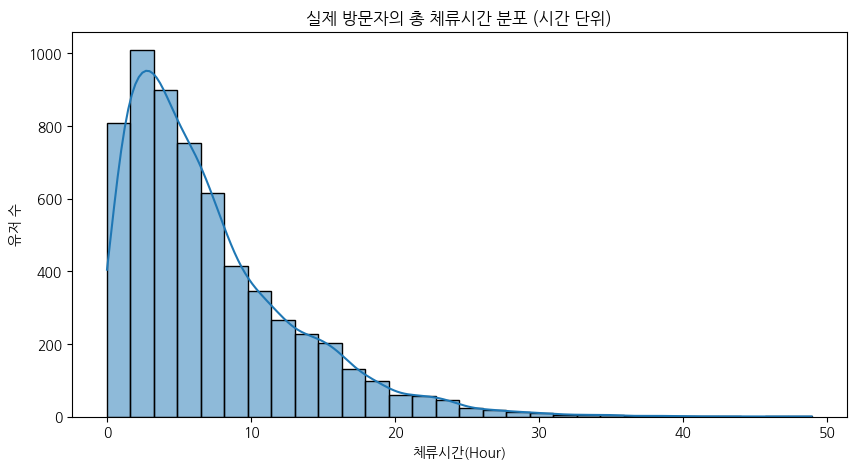

In [ ]:
# 주요 행동 변수 분포

behavior_cols = ['total_stay_seconds', 'visit_days', 'checkin_count', 'distinct_site_count']
print("=== 주요 행동 변수 요약 통계 ===")
print(user_df[behavior_cols].describe())

plt.figure(figsize=(10, 5))
sns.histplot(user_df[user_df['total_stay_seconds'] > 0]['total_stay_seconds'] / 3600, bins=30, kde=True)
plt.title('실제 방문자의 총 체류시간 분포 (시간 단위)')
plt.xlabel('체류시간(Hour)')
plt.ylabel('유저 수')
plt.show()

> **📊 시각화 해석**
>
> - 실제 방문자의 체류시간은 짧은 구간에 집중되고 일부 장시간 이용자가 긴 꼬리를 형성한다.
> - 단순 평균보다 구간화·로그 변환·군집화가 적합한 구조로, 6-2의 행동 유형 분석 필요성을 보여준다.


### 5-1-3. 결제 여부에 따른 체류시간 비교

/tmp/ipykernel_22006/4119713942.py:9: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_22006/4119713942.py:16: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




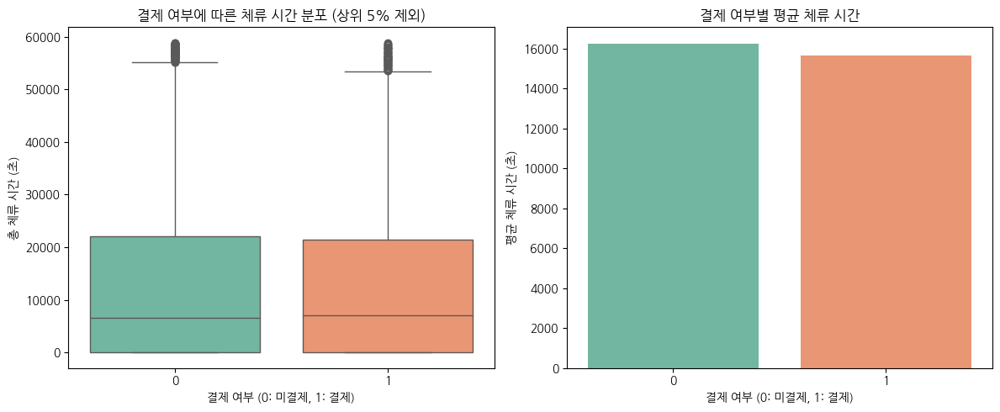

In [ ]:
# 95% 분위수까지만 필터링하여 시각화
q95 = user_df['total_stay_seconds'].quantile(0.95)
filtered_df = user_df[user_df['total_stay_seconds'] <= q95]

plt.figure(figsize=(12, 5))

# 결제 여부별 총 체류 시간 분포
plt.subplot(1, 2, 1)
sns.boxplot(data=filtered_df, x='is_payment', y='total_stay_seconds', palette='Set2')
plt.title('결제 여부에 따른 체류 시간 분포 (상위 5% 제외)')
plt.xlabel('결제 여부 (0: 미결제, 1: 결제)')
plt.ylabel('총 체류 시간 (초)')

# 결제 여부별 평균 체류 시간
plt.subplot(1, 2, 2)
sns.barplot(data=user_df, x='is_payment', y='total_stay_seconds', estimator=np.mean, palette='Set2', errorbar=None)
plt.title('결제 여부별 평균 체류 시간')
plt.xlabel('결제 여부 (0: 미결제, 1: 결제)')
plt.ylabel('평균 체류 시간 (초)')

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 결제자와 미결제자의 체류시간 분포와 평균은 큰 차이 없이 유사하게 나타난다.
> - 체류시간만으로 전환을 설명하기보다 방문일 수·출입 빈도·반복 방문을 함께 고려해야 한다.


### 5-1-4. D0~D2 일자별 방문 패턴

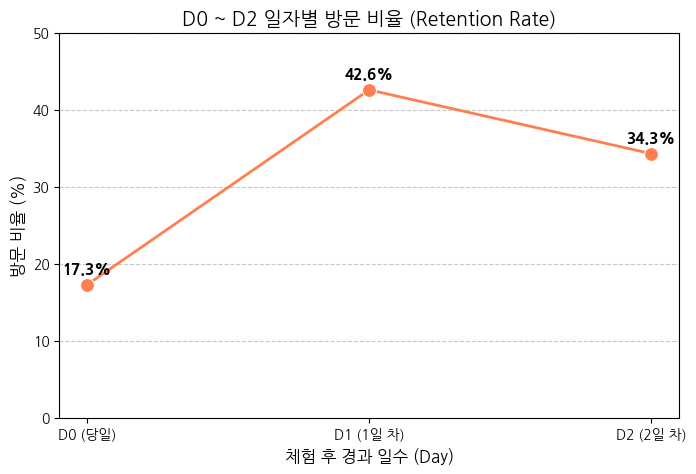

In [ ]:
# 일자별 방문 유저 수 계산
total_users = user_day_df['user_id'].nunique()
day_retention = user_day_df.groupby('day_from_trial')['daily_visit_flag'].sum().reset_index()
day_retention.columns = ['day_from_trial', 'visit_user_count']
day_retention['retention_rate'] = (day_retention['visit_user_count'] / total_users) * 100

plt.figure(figsize=(8, 5))

# 꺾은선 그래프
ax = sns.lineplot(data=day_retention, x='day_from_trial', y='retention_rate',
                  marker='o', markersize=10, linewidth=2, color='coral')

plt.title('D0 ~ D2 일자별 방문 비율 (Retention Rate)', fontsize=14)
plt.xlabel('체험 후 경과 일수 (Day)', fontsize=12)
plt.ylabel('방문 비율 (%)', fontsize=12)
plt.xticks([0, 1, 2], ['D0 (당일)', 'D1 (1일 차)', 'D2 (2일 차)'])
plt.ylim(0, 50) # y축 범위 0~50%로 고정

# 데이터 레이블 추가
for i in range(day_retention.shape[0]):
    plt.text(day_retention['day_from_trial'][i], day_retention['retention_rate'][i] + 1.5,
             f"{day_retention['retention_rate'][i]:.1f}%",
             ha='center', fontsize=11, fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

> **📊 시각화 해석**
>
> - 방문 비율은 D0 17.3%, D1 42.6%, D2 34.3%로 D1에서 가장 높다.
> - 체험 종료 전 행동 변화가 가능한 D1이 후속 결제 전환 분석의 핵심 개입 후보 시점이 된다.


### 5-1-5. 방문 유형별 결제 전환율

/tmp/ipykernel_22006/2374269045.py:13: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




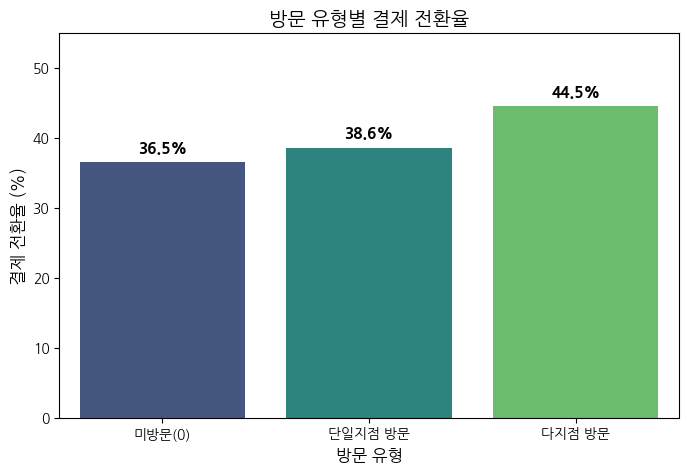

In [ ]:
# 교차 방문자 파생 변수
user_df['is_cross_visitor'] = np.where(user_df['distinct_site_count'] >= 2, '다지점 방문',
                                np.where(user_df['distinct_site_count'] == 1, '단일지점 방문', '미방문(0)'))

# 방문 유형별 결제율
cross_visit_res = user_df.groupby('is_cross_visitor')['is_payment'].mean().reset_index()
cross_visit_res['is_payment'] = cross_visit_res['is_payment'] * 100 # %로 변환

# 미방문 -> 단일지점 -> 다지점
order = ['미방문(0)', '단일지점 방문', '다지점 방문']

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=cross_visit_res, x='is_cross_visitor', y='is_payment', order=order, palette='viridis')

plt.title('방문 유형별 결제 전환율', fontsize=14)
plt.xlabel('방문 유형', fontsize=12)
plt.ylabel('결제 전환율 (%)', fontsize=12)
plt.ylim(0, 55)

# 데이터 레이블 추가
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.1f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=11, fontweight='bold', xytext=(0, 5),
                textcoords='offset points')

plt.show()

> **📊 시각화 해석**
>
> - 원본 결제율은 D0~D2 방문 기록이 없는 집단 36.5%, 단일 지점 이용자 38.6%, 다지점 이용자 44.5% 순으로 나타난다.
> - 다만 결제 일시가 없으므로 `미방문`을 결제 전 공간을 전혀 이용하지 않은 집단으로 단정하거나, 방문과 결제의 선후관계를 직접 해석해서는 안 된다.
> - 또한 다지점 이용자는 반복 방문과 이용 강도도 높을 수 있으므로, 6-2에서 방문일 수 등을 통제해 지점 수 자체의 효과인지 다시 검증한다.


## **5-2. 시간 흐름에 따른 체험 수요 EDA**

**📌 확인 관점**
- 신청·방문·결제 규모의 공통 변동과 특정 시점의 급등락을 확인한다.
- 장기 추세와 주간 변동, 요일 유형을 구분해 후속 수요 분석에서 사용할 시간 변수의 필요성을 점검한다.


### 5-2-1. 주별 신청자·방문자·결제자 추이


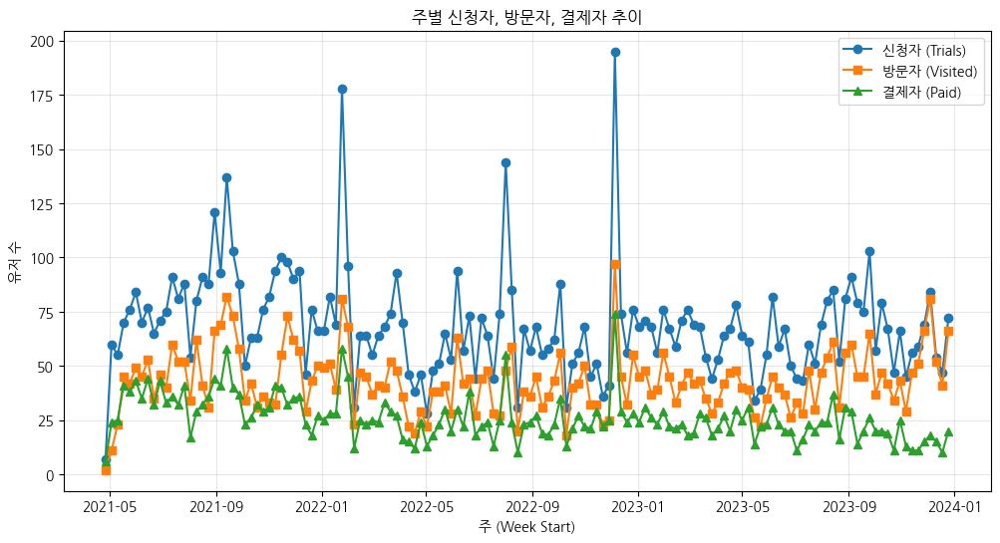

In [ ]:
# 주별 볼륨 추이

user_df['trial_date'] = pd.to_datetime(user_df['trial_date'])
user_df['trial_week'] = user_df['trial_date'] - pd.to_timedelta(user_df['trial_date'].dt.dayofweek, unit='d')

weekly_vol = user_df.groupby('trial_week').agg(
    신청자=('user_id', 'count'),
    방문자=('visited_flag', 'sum'),
    결제자=('is_payment', 'sum')
).reset_index()

plt.figure(figsize=(12, 6))
plt.plot(weekly_vol['trial_week'], weekly_vol['신청자'], marker='o', label='신청자 (Trials)')
plt.plot(weekly_vol['trial_week'], weekly_vol['방문자'], marker='s', label='방문자 (Visited)')
plt.plot(weekly_vol['trial_week'], weekly_vol['결제자'], marker='^', label='결제자 (Paid)')
plt.title('주별 신청자, 방문자, 결제자 추이')
plt.xlabel('주 (Week Start)')
plt.ylabel('유저 수')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

> **📊 시각화 해석**
>
> - 신청·방문·결제 규모는 대체로 같은 방향으로 움직이지만 일부 주차에서 신청 수요가 크게 급증한다.
> - 절대 건수만으로 전환 문제를 판단하지 않도록 이후 분석에서는 주별 전환율과 시기 변수를 함께 확인한다.


### 5-2-2. 월별·주별 방문 수요 추이


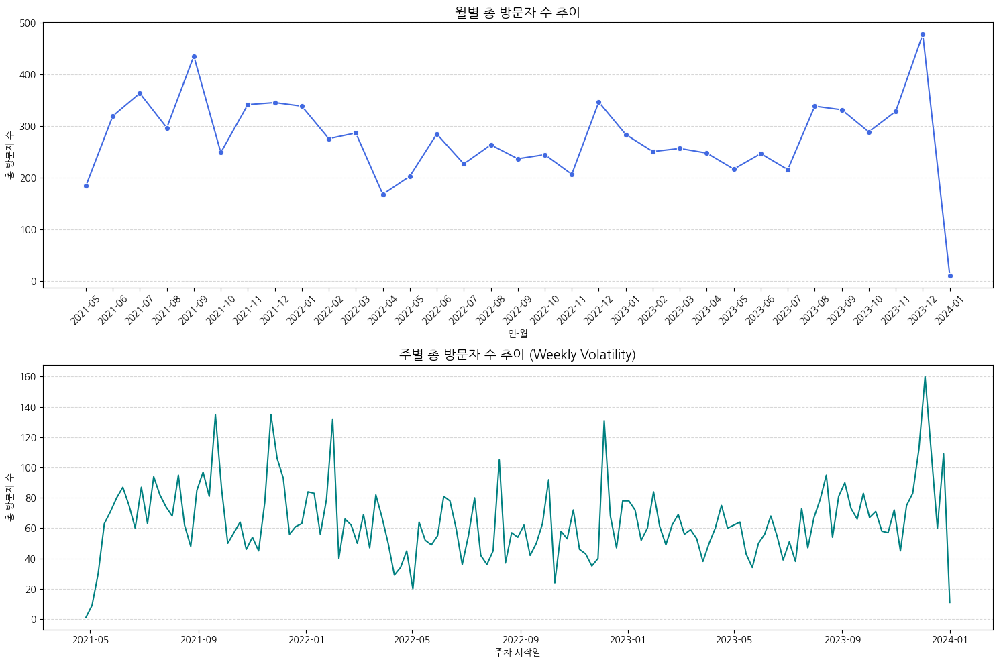

In [ ]:
# Year-Month 생성
df['calendar_date'] = pd.to_datetime(df['calendar_date'])
df['year_month'] = df['calendar_date'].dt.to_period('M').astype(str)

# 월별, 주별 방문자 합계
monthly_trend = df.groupby('year_month')['activity_user_count'].sum().reset_index()
weekly_trend = df.groupby('week_start')['activity_user_count'].sum().reset_index()
weekly_trend['week_start'] = pd.to_datetime(weekly_trend['week_start'])

plt.figure(figsize=(15, 10))

# 월별 트렌드
plt.subplot(2, 1, 1)
sns.lineplot(data=monthly_trend, x='year_month', y='activity_user_count', marker='o', color='royalblue')
plt.title('월별 총 방문자 수 추이', fontsize=14)
plt.xlabel('연-월')
plt.ylabel('총 방문자 수')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 주별 트렌드
plt.subplot(2, 1, 2)
sns.lineplot(data=weekly_trend, x='week_start', y='activity_user_count', color='teal', linewidth=1.5)
plt.title('주별 총 방문자 수 추이 (Weekly Volatility)', fontsize=14)
plt.xlabel('주차 시작일')
plt.ylabel('총 방문자 수')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 월별 방문 규모는 시기별 등락이 반복되고, 주별 자료에서는 단기 급등과 변동성이 더 선명하게 나타난다.
> - 월평균만으로는 변화 시점을 놓칠 수 있으므로 후속 수요 분석은 주 단위를 중심으로 설계할 필요가 있다.


### 5-2-3. 평일·주말·공휴일 이용 차이


/tmp/ipykernel_22006/1435389820.py:11: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_22006/1435389820.py:18: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




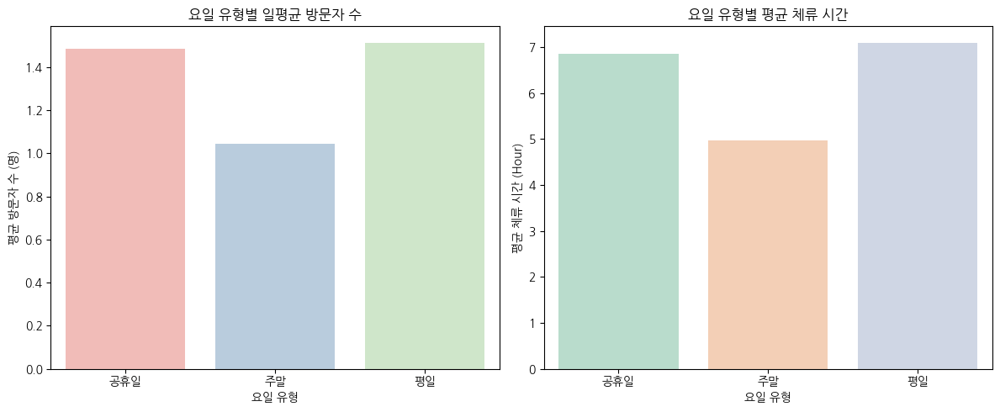

In [ ]:
# 주중/주말/공휴일 변수별 평균
day_type_trend = df.groupby('day_type').agg(
    avg_user_count=('activity_user_count', 'mean'),
    avg_stay_hours=('total_stay_seconds', lambda x: x.mean() / 3600) # 시간 단위로 변환
).reset_index()

plt.figure(figsize=(12, 5))

# 평균 이용자 수
plt.subplot(1, 2, 1)
sns.barplot(data=day_type_trend, x='day_type', y='avg_user_count', palette='Pastel1')
plt.title('요일 유형별 일평균 방문자 수')
plt.xlabel('요일 유형')
plt.ylabel('평균 방문자 수 (명)')

# 평균 체류 시간 (시간)
plt.subplot(1, 2, 2)
sns.barplot(data=day_type_trend, x='day_type', y='avg_stay_hours', palette='Pastel2')
plt.title('요일 유형별 평균 체류 시간')
plt.xlabel('요일 유형')
plt.ylabel('평균 체류 시간 (Hour)')

plt.tight_layout()
plt.show()


> **📊 시각화 해석**
>
> - 평일과 공휴일의 평균 방문자 수·체류시간이 주말보다 높고, 주말 수요는 상대적으로 낮게 나타난다.
> - 요일 유형은 수요의 반복 패턴을 설명하는 기본 변수이므로 예측과 지점 운영 비교에서 통제할 필요가 있다.


## **5-3. 지점별 이용 특성 EDA**

**📌 확인 관점**
- 지점 규모가 다른 상황에서 단순 이용자 수가 아니라 평당 이용 효율과 체류 부하를 비교한다.


### 5-3-1. 지점 규모 대비 이용 효율과 체류 부하

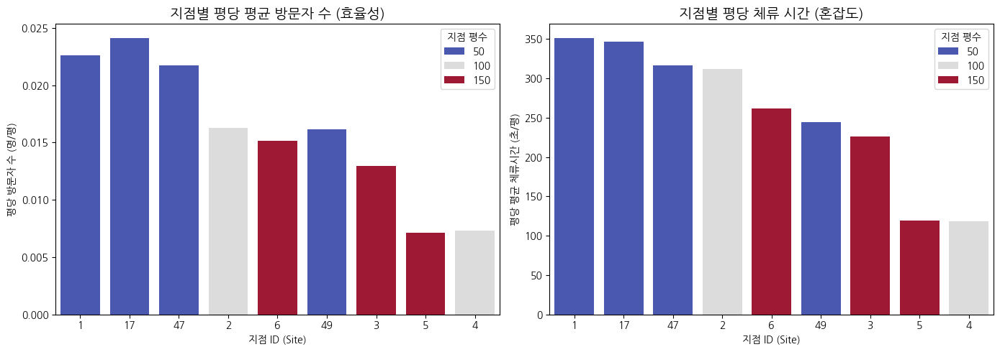

In [ ]:
# 지점별 평당 방문자수 및 평당 체류시간
site_eff = day_df.groupby(['site_id', 'area_pyeong']).agg(
    avg_daily_users=('activity_user_count', 'mean'),
    avg_daily_stay=('total_stay_seconds', 'mean')
).reset_index()

site_eff['users_per_pyeong'] = site_eff['avg_daily_users'] / site_eff['area_pyeong']
site_eff['congestion'] = site_eff['avg_daily_stay'] / site_eff['area_pyeong']
site_eff = site_eff.sort_values(by='congestion', ascending=False)
site_eff['site_id'] = site_eff['site_id'].astype(str) # 범주형 변수로 변환

plt.figure(figsize=(14, 5))

# 지점별 평당 방문자 수
plt.subplot(1, 2, 1)
sns.barplot(data=site_eff, x='site_id', y='users_per_pyeong', hue='area_pyeong', dodge=False, palette='coolwarm')
plt.title('지점별 평당 평균 방문자 수 (효율성)', fontsize=14)
plt.xlabel('지점 ID (Site)')
plt.ylabel('평당 방문자 수 (명/평)')
plt.legend(title='지점 평수')

# 지점별 평당 체류시간 (혼잡도)
plt.subplot(1, 2, 2)
sns.barplot(data=site_eff, x='site_id', y='congestion', hue='area_pyeong', dodge=False, palette='coolwarm')
plt.title('지점별 평당 체류 시간 (혼잡도)', fontsize=14)
plt.xlabel('지점 ID (Site)')
plt.ylabel('평당 평균 체류시간 (초/평)')
plt.legend(title='지점 평수')

plt.tight_layout()
plt.show()


> **📊 시각화 해석**
>
> - 지점별 평당 방문자 수와 평당 체류시간의 순위가 다르게 나타나 지점마다 이용 효율과 체류 부하가 동일하지 않다.
> - 이 값은 무료 체험 이용자 기준의 상대 지표이므로 전체 회원을 포함한 실제 혼잡도가 아니라 지점 역할을 탐색하는 대리 지표로 해석한다.


### 5-3-2. 지점 관측 시작 후 경과 기간별 이용 추이


/tmp/ipykernel_22006/1289391433.py:7: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



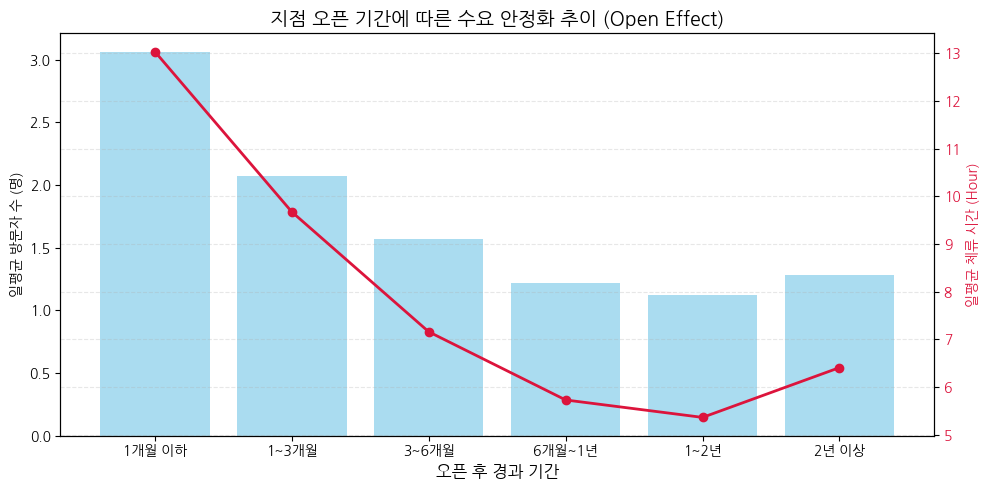

In [ ]:
# 오픈 경과일에 따른 구간화 (Binning)
bins = [-1, 30, 90, 180, 365, 730, 9999]
labels = ['1개월 이하', '1~3개월', '3~6개월', '6개월~1년', '1~2년', '2년 이상']
day_df['open_period_group'] = pd.cut(day_df['days_since_site_start'], bins=bins, labels=labels)

# 구간별 평균
open_trend = day_df.groupby('open_period_group').agg(
    avg_daily_users=('activity_user_count', 'mean'),
    avg_daily_stay_hours=('total_stay_seconds', lambda x: x.mean() / 3600)
).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5))

# Bar Plot
color1 = 'skyblue'
ax1.set_xlabel('오픈 후 경과 기간', fontsize=12)
ax1.set_ylabel('일평균 방문자 수 (명)', color='black')
ax1.bar(open_trend['open_period_group'], open_trend['avg_daily_users'], color=color1, alpha=0.7, label='이용자 수')
ax1.tick_params(axis='y', labelcolor='black')

# 체류 시간 - 보조 Y축
ax2 = ax1.twinx()
color2 = 'crimson'
ax2.set_ylabel('일평균 체류 시간 (Hour)', color=color2)
ax2.plot(open_trend['open_period_group'], open_trend['avg_daily_stay_hours'], color=color2, marker='o', linewidth=2, label='체류 시간')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('지점 오픈 기간에 따른 수요 안정화 추이 (Open Effect)', fontsize=14)
fig.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

> **📊 시각화 해석**
>
> - 관측 초기 구간의 평균 이용 강도가 높고 이후 완만해지는 패턴이 나타나지만, 실제 개점 직후의 안정화 효과로 단정할 수는 없다.
> - `days_since_site_start`는 확인된 개점일이 아니라 데이터 내 최초 관측일 기준이므로 시기·지점 구성 차이를 함께 고려해야 한다.


## **5-4. 코로나 관련 EDA**

**📌 확인 관점**
- 코로나 거리두기 단계와 신청·방문 수요가 같은 시기에 어떻게 변했는지 탐색한다.


### 5-4-1. 코로나 거리두기 단계와 일별 신청 수요


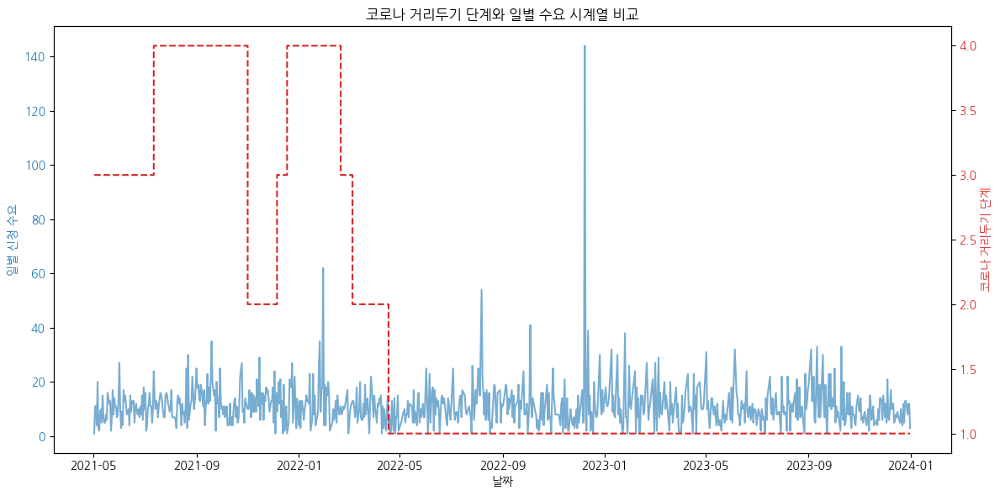

In [ ]:
# 코로나 정책 단계와 일별 신청 수요 비교
day_df['calendar_date'] = pd.to_datetime(day_df['calendar_date'])

# 일별 신청자 수
daily_trials = user_df.groupby('trial_date').size().reset_index(name='신청수')
daily_trials['trial_date'] = pd.to_datetime(daily_trials['trial_date'])

# 코로나 단계 데이터와 병합
merged_covid = pd.merge(daily_trials, day_df[['calendar_date', 'covid_stage']],
                        left_on='trial_date', right_on='calendar_date', how='inner')

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.set_xlabel('날짜')
ax1.set_ylabel('일별 신청 수요', color='tab:blue')
ax1.plot(merged_covid['trial_date'], merged_covid['신청수'], color='tab:blue', alpha=0.6)
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.set_ylabel('코로나 거리두기 단계', color='tab:red')
ax2.plot(merged_covid['trial_date'], merged_covid['covid_stage'], color='tab:red', linestyle='--', drawstyle='steps-post')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('코로나 거리두기 단계와 일별 수요 시계열 비교')
fig.tight_layout()
plt.show()


> **📊 시각화 해석**
>
> - 거리두기 단계가 바뀌는 동안에도 일별 신청 수요는 지속적으로 변동하며 일부 큰 스파이크가 관찰된다.
> - 단계 변화만으로 수요를 설명하기 어렵기 때문에 주간 추세·요일·지점 수 변화와 함께 해석해야 한다.


### 5-4-2. 코로나 방역 단계별 평균 이용 규모


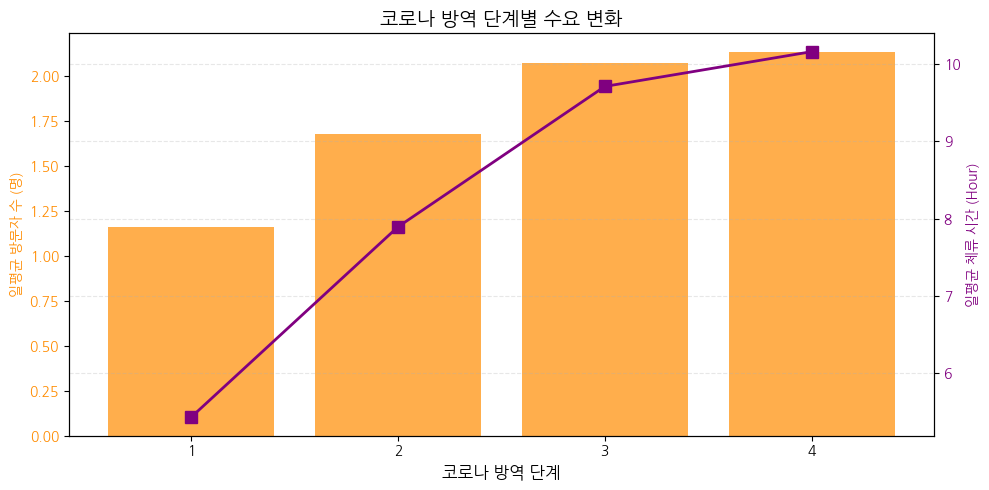

In [ ]:
# 코로나 단계별 평균
stage_impact = day_df.groupby('covid_stage').agg(
    avg_daily_users=('activity_user_count', 'mean'),
    avg_stay_hours=('total_stay_seconds', lambda x: x.mean() / 3600)
).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5))

# Bar Plot
color1 = 'darkorange'
ax1.set_xlabel('코로나 방역 단계', fontsize=12)
ax1.set_ylabel('일평균 방문자 수 (명)', color=color1)
ax1.bar(stage_impact['covid_stage'].astype(str), stage_impact['avg_daily_users'], color=color1, alpha=0.7)
ax1.tick_params(axis='y', labelcolor=color1)

# 체류 시간 - 보조 Y축
ax2 = ax1.twinx()
color2 = 'purple'
ax2.set_ylabel('일평균 체류 시간 (Hour)', color=color2)
ax2.plot(stage_impact['covid_stage'].astype(str), stage_impact['avg_stay_hours'], color=color2, marker='s', markersize=8, linewidth=2)
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('코로나 방역 단계별 수요 변화', fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.3)
fig.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 단순 평균에서는 방역 단계가 높을수록 방문자 수와 체류시간도 높게 나타나는 역방향 패턴이 보인다.
> - 이는 단계 자체의 긍정 효과라기보다 시기·운영 지점 구성의 교란 가능성이 크므로 인과적으로 해석하지 않는다.


## **5-5. 날씨 관련 EDA**

**📌 확인 관점**
- 기온과 악천후에 따라 방문·체류 수요가 달라지는지 탐색한다.
- 구간별 표본 크기를 확인한 뒤 평균 차이를 읽어 극단 기온의 소표본 과대해석을 방지한다.


### 5-5-1. 평균 기온 구간별 지점·일 표본 수


/tmp/ipykernel_22006/2665210109.py:9: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




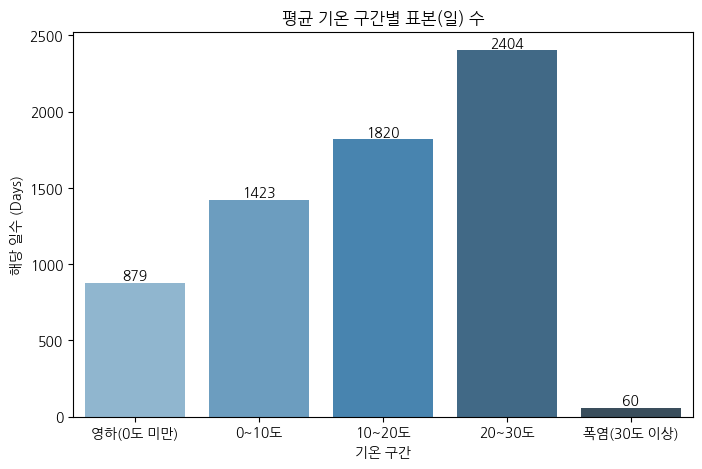

In [ ]:
# 날씨 기온 구간별 일수
bins = [-99, 0, 10, 20, 30, 99]
labels = ['영하(0도 미만)', '0~10도', '10~20도', '20~30도', '폭염(30도 이상)']

day_df['temp_group'] = pd.cut(day_df['weather_temp_mean_c'], bins=bins, labels=labels)
weather_counts = day_df.groupby('temp_group', observed=True)['calendar_date'].count().reset_index(name='일수')

plt.figure(figsize=(8, 5))
sns.barplot(data=weather_counts, x='temp_group', y='일수', palette='Blues_d')
plt.title('평균 기온 구간별 표본(일) 수')
plt.xlabel('기온 구간')
plt.ylabel('해당 일수 (Days)')
for i, v in enumerate(weather_counts['일수']):
    plt.text(i, v + 20, str(v), ha='center')
plt.show()

> **📊 시각화 해석**
>
> - 20~30℃ 구간은 2,404개 지점·일로 가장 많지만 30℃ 이상 구간은 60개에 불과하다.
> - 폭염 구간의 평균 방문자 수는 소수 표본에 민감하므로 다른 구간과 동일한 확신으로 해석하기 어렵다.


### 5-5-2. 평균 기온 구간별 방문자 수


/tmp/ipykernel_22006/3697342220.py:7: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_22006/3697342220.py:10: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




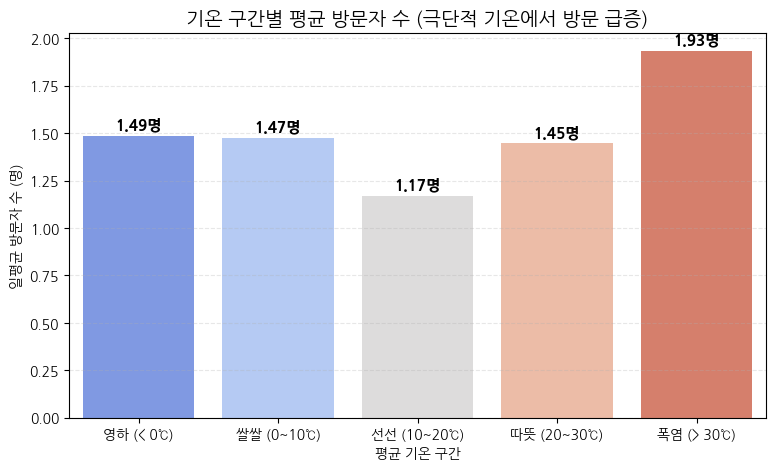

In [ ]:
# 기온 구간화
bins = [-99, 0, 10, 20, 30, 99]
labels = ['영하 (< 0℃)', '쌀쌀 (0~10℃)', '선선 (10~20℃)', '따뜻 (20~30℃)', '폭염 (> 30℃)']
day_df['temp_group'] = pd.cut(day_df['weather_temp_mean_c'], bins=bins, labels=labels)

# 평균 산출
temp_impact = day_df.groupby('temp_group')['activity_user_count'].mean().reset_index()

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=temp_impact, x='temp_group', y='activity_user_count', palette='coolwarm')

plt.title('기온 구간별 평균 방문자 수 (극단적 기온에서 방문 급증)', fontsize=14)
plt.xlabel('평균 기온 구간')
plt.ylabel('일평균 방문자 수 (명)')

# 데이터 레이블 추가
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}명',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 3), textcoords='offset points')

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

> **📊 시각화 해석**
>
> - 10~20℃ 구간의 평균 방문자 수가 가장 낮고, 30℃ 이상 구간이 가장 높아 단순 선형 관계는 보이지 않는다.
> - 폭염 구간은 표본이 매우 적으므로 계절·요일·기간 효과를 통제한 후 날씨 변수의 추가 설명력을 확인해야 한다.


### 5-5-3. 악천후 여부에 따른 방문·체류 차이


/tmp/ipykernel_22006/1853691189.py:5: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_22006/1853691189.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




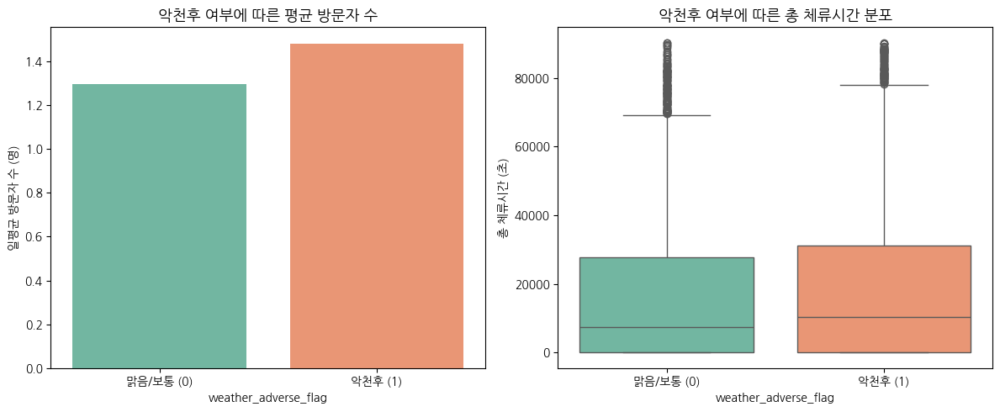

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 악천후에 따른 평균 방문자 수
adverse_impact = day_df.groupby('weather_adverse_flag')['activity_user_count'].mean().reset_index()
sns.barplot(data=adverse_impact, x='weather_adverse_flag', y='activity_user_count', ax=axes[0], palette='Set2')
axes[0].set_title('악천후 여부에 따른 평균 방문자 수', fontsize=13)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['맑음/보통 (0)', '악천후 (1)'])
axes[0].set_ylabel('일평균 방문자 수 (명)')

# 악천후에 따른 체류시간 분포
q95 = day_df['total_stay_seconds'].quantile(0.95)
filtered_day_df = day_df[day_df['total_stay_seconds'] <= q95]

sns.boxplot(data=filtered_day_df, x='weather_adverse_flag', y='total_stay_seconds', ax=axes[1], palette='Set2')
axes[1].set_title('악천후 여부에 따른 총 체류시간 분포', fontsize=13)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['맑음/보통 (0)', '악천후 (1)'])
axes[1].set_ylabel('총 체류시간 (초)')

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 악천후 지점·일의 평균 방문자 수와 체류시간 중앙값이 오히려 조금 높게 나타난다.
> - 계절과 요일이 함께 작용할 수 있으므로 날씨가 방문을 늘린다고 해석하지 않고 후속 수요 모델의 통제 후보로 사용한다.


## **5-6. EDA 요약**

**🧭 탐색에서 검증으로**

- 기본 퍼널에서는 신청 규모만으로 방문과 결제를 함께 설명하기 어려웠고, 특히 방문 여부와 결제 여부가 완전한 포함 관계가 아니어서 시점별 전환 구조를 분리해 확인할 필요가 있었다.
- 결제자와 미결제자의 체류시간 분포는 유사했으며, D1에 방문이 집중되고 다지점 이용자의 원본 결제율이 높게 나타나 체류시간·방문일 수·반복 방문·지점 수를 함께 검증할 필요가 있었다.
- 주별 방문 수요에는 단기 등락과 요일 패턴이 있었고 코로나·날씨의 단순 평균도 교란 가능성이 보여, 정상 변동과 구조적 변화를 구분하고 시계열 변수의 예측력을 확인할 필요가 있었다.
- 지점별로 평당 이용자 수와 체류 부하의 순위가 달라, 절대 이용량만이 아니라 입지·수요·경험·전환을 결합한 지점 진단이 필요했다.

| EDA에서 남은 질문 | 후속 분석 |
| --- | --- |
| 결제율 변화는 정상적인 수요 변동인가, 특정 시점 이후 발생한 구조적 변화인가? |6-1. 변화점·퍼널 병목·방문 수요 예측 |
| 결제와 연결된 핵심 행동은 오래 머무는 것인가, 여러 날짜에 다시 방문하는 것인가? | 6-2. 행동 유형·통제 분석·랜드마크 모델 |
| 지점별 성과 차이는 입지, 실제 수요 포착, 공간 경험, 전환 중 어디에서 발생하는가? | 6-3. 입지·리뷰·행동 데이터 통합 진단 |

# **6\. 분석 및 모델링**

**📊 작업 요약**
- 사용자 행동·시계열·지점 데이터를 기반으로 체험 신청부터 방문과 결제까지의 주요 패턴과 병목을 분석한다.
- 통계 검정과 예측·분류 모델을 활용해 수요 변화와 결제 전환에 영향을 미치는 요인을 확인한다.
- 분석 결과를 바탕으로 재방문 유도, 지점별 운영 개선 및 신규 출점 전략을 제안한다.

## **6-1. 안정된 유입, 줄어든 결제, 문제는 어디에서 발생했을까?**

**🎯 결제 전환율 감소의 병목을 진단하고, 지점별 방문 수요를 운영에 활용할 수 있는지 검증**

- 무료 체험 서비스는 고객이 체험을 신청하고 실제 공간을 방문한 뒤 결제를 결정하는 구조이다.  
- 2023년 하반기부터 결제 전환율이 감소했지만, 결제율만으로는 고객 유입이 줄었는지, 방문 이후의 전환이 약해졌는지 구분하기 어렵다.

**🔭 결제 감소는 정말 고객이 덜 들어왔기 때문일까? 아니면 방문 이후 단계에서 문제가 발생한 것일까?**

| 핵심 질문 | 분석 역할 | 최종 활용 |
| --- | --- | --- |
| **결제율은 언제부터 달라졌는가?** | 월별 결제율 변화점 탐색 | 전환 수준이 달라진 기준 시점 정의 |
| **유입과 방문도 함께 감소했는가?** | 변화점 전후 신청 규모·활성화율 비교 | 유입 문제와 전환 문제 분리 |
| **퍼널의 어느 단계가 병목인가?** | 체험 시작→방문, 방문→결제 단계 비교 | 결제 전략의 우선순위 설정 |
| **방문 수요는 예측할 수 있는가?** | Baseline·Random Forest·LightGBM 비교 | 지점별 인력·좌석·시설 운영 지원 |
| **무엇이 예측에 활용되는가?** | 변수 중요도와 SHAP 해석 | 최근 방문 패턴 중심의 운영 모니터링 |

**📌 전체 분석 흐름**

1. 월별 결제 전환율에서 구조적 변화 시점을 탐색한다.
2. 변화점 전후의 체험 시작자 수와 방문 활성화율을 비교한다.
3. 퍼널을 체험 시작→방문과 방문→결제로 분리해 병목을 진단한다.
4. 지점별 일간 방문 수요를 구성하고 단순 Baseline을 설정한다.
5. Random Forest와 LightGBM을 학습해 예측 성능을 비교한다.
6. 변수 중요도와 SHAP을 통해 예측에 활용된 수요 패턴을 해석한다.
7. 결제 전환 개선과 방문 수요 기반 운영을 하나의 실행안으로 연결한다.

**⚠️ 해석 주의:** 결제 일시가 제공되지 않아 실제로 방문이 결제보다 먼저 발생했는지는 확인할 수 없다. 이하의 `방문→결제`는 운영 퍼널상 단계를 구분하기 위한 표현이며, 방문자 집단의 최종 결제율로 해석한다.

### 6-1-1. 결제 전환율 감소는 어느 단계에서 발생했을까?

**🔍 분석 목적**

- 월별 결제 전환율이 단순히 흔들린 것인지, 특정 시점을 기준으로 전환 수준이 달라졌는지 확인한다.
- 변화점 전후의 체험 시작자 수와 방문 활성화율을 비교해 결제 감소가 유입 축소에서 비롯되었는지 검증한다.
- 퍼널을 `체험 시작→방문`과 `방문→결제`로 분리해 실제 병목이 발생한 단계를 찾는다.
- 결제율 하락의 위치를 명확히 해 후속 결제 전환 분석과 실행 전략의 우선순위를 설정한다.

**🧬 분석 흐름**

1. 사용자 단위 신청·방문·결제 데이터를 연결한다.
2. 월별 결제율을 집계하고 단일 변화점 탐색으로 기준 시점을 정한다.
3. 변화점 전후 결제율의 차이와 불확실성을 검정한다.
4. 체험 시작자 규모와 방문 활성화율을 비교한다.
5. 퍼널 단계별 전환율을 분리해 최종 병목을 진단한다.

#### 6-1-1-1. 사용자 데이터 연결 및 결제율 변화점 탐지

**🔹 분석 목적**

- 체험 신청일, 방문 여부, 최종 결제 여부를 사용자 단위로 연결해 월별 결제 전환율을 계산한다.
- 월별 결제율을 두 구간으로 한 번 나누었을 때 구간 내 오차합이 가장 작아지는 시점을 탐색한다.
- 결제율 감소를 임의의 전후 기간으로 나누지 않고, 데이터에서 확인된 변화 시점을 후속 비교의 기준으로 사용한다.

**🔹 분석 기준**

- 분석 단위: 체험 신청 사용자 1명
- 기준 시점: `trial_date`가 속한 월
- 결과 변수: 최종 결제 여부 `is_payment`
- 변화점 기준: 두 구간의 SSE 합이 최소가 되는 단일 분할 시점

**🔹 해석 주의**

- 단일 변화점 탐색은 결제율 수준을 가장 잘 구분하는 시점을 찾는 방법이다.
- 변화점이 확인되더라도 해당 월의 외부 사건이나 정책이 결제 감소를 유발했다고 단정할 수는 없다.

In [ ]:
# 사용자 데이터 검증

COLOR_BEFORE = "#4C72B0"
COLOR_AFTER = "#C44E52"
COLOR_ACCENT = "#DD8452"

required_user_columns = [
    "user_id",
    "trial_date",
    "is_payment",
    "visited_flag",
]

missing_user_columns = [
    column
    for column in required_user_columns
    if column not in user_df.columns
]

if missing_user_columns:
    raise ValueError(
        f"user_df에 필요한 컬럼이 없습니다: {missing_user_columns}"
    )

user_df = user_df.copy()
user_df["trial_date"] = pd.to_datetime(
    user_df["trial_date"],
    errors="raise",
)

print("user_df:", user_df.shape)
print(
    "분석 기간:",
    user_df["trial_date"].min(),
    "~",
    user_df["trial_date"].max(),
)
print(
    "중복 user_id:",
    user_df["user_id"].duplicated().sum(),
)

user_df: (9624, 36)
분석 기간: 2021-05-01 00:00:00 ~ 2023-12-31 00:00:00
중복 user_id: 0


In [ ]:
# 월별 결제율 집계

user_df['cohort_month'] = user_df['trial_date'].dt.to_period('M')
monthly = user_df.groupby('cohort_month').agg(n=('user_id','count'), rate=('is_payment','mean'))
signal = monthly['rate'].values
n = len(signal)

# 단일 변화점 브루트포스 탐색 (SSE 최소화)
best_sse, best_split = np.inf, None
for split in range(3, n-3):
    seg1, seg2 = signal[:split], signal[split:]
    sse = np.sum((seg1-seg1.mean())**2) + np.sum((seg2-seg2.mean())**2)
    if sse < best_sse:
        best_sse, best_split = sse, split

change_month = monthly.index[best_split]
print('변화점:', change_month, '(SSE 최소화 기준)')
print(f'이전 평균: {signal[:best_split].mean():.4f} / 이후 평균: {signal[best_split:].mean():.4f}')

변화점: 2023-09 (SSE 최소화 기준)
이전 평균: 0.3975 / 이후 평균: 0.2573


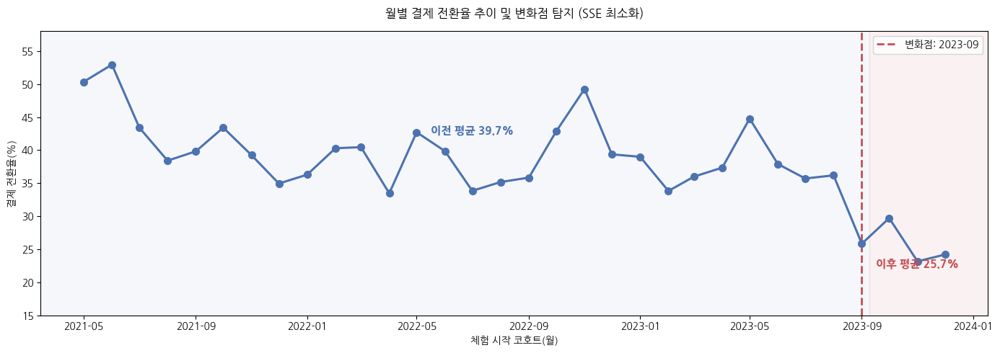

In [ ]:
# 변화점 시각화

fig, ax = plt.subplots(figsize=(14,5))

ax.plot(monthly.index.to_timestamp(), monthly['rate']*100, marker='o', markersize=7,
        linewidth=2.2, color=COLOR_BEFORE, zorder=3)

ax.axvline(change_month.to_timestamp(), color=COLOR_AFTER, linestyle='--', linewidth=2,
           label=f'변화점: {change_month}', zorder=2)

ax.axhspan(0, 100, xmin=0, xmax=(best_split)/n, color=COLOR_BEFORE, alpha=0.05)
ax.axhspan(0, 100, xmin=(best_split)/n, xmax=1, color=COLOR_AFTER, alpha=0.07)

ax.annotate(f'이전 평균 {signal[:best_split].mean()*100:.1f}%',
            xy=(monthly.index[best_split//2].to_timestamp(), signal[:best_split].mean()*100),
            xytext=(0, 18), textcoords='offset points', ha='center',
            fontsize=11, color=COLOR_BEFORE, fontweight='bold')
ax.annotate(f'이후 평균 {signal[best_split:].mean()*100:.1f}%',
            xy=(monthly.index[min(best_split+2, n-1)].to_timestamp(), signal[best_split:].mean()*100),
            xytext=(0, -22), textcoords='offset points', ha='center',
            fontsize=11, color=COLOR_AFTER, fontweight='bold')

ax.set_title('월별 결제 전환율 추이 및 변화점 탐지 (SSE 최소화)', pad=14)
ax.set_xlabel('체험 시작 코호트(월)'); ax.set_ylabel('결제 전환율(%)')
ax.legend(loc='upper right', frameon=True)
ax.set_ylim(15, 58)
plt.tight_layout()
plt.show()

> **📊 결과 해석**
>
> - 월별 결제 전환율을 한 번만 구조적으로 나누는 지점을 전 구간에서 탐색한 결과, SSE가 가장 작아지는 변화점은 2023년 9월이다.
> - 변화점 이전 월평균 결제율은 39.75%, 이후는 25.73%로 약 14.02%p 낮아졌다.
> - 결제율의 월별 흔들림만으로 보기보다, 2023년 9월을 기준으로 전환 수준 자체가 달라진 구간으로 해석할 수 있다.

#### 6-1-1-2. 변화점 전후 결제율·유입·활성화 비교

**🔹 분석 목적**

- 변화점 이전과 이후의 결제율 차이가 표본 변동으로 설명 가능한 수준인지 확인한다.
- 월평균 체험 시작자 수를 비교해 고객 유입 규모가 실제로 축소되었는지 점검한다.
- 체험 시작 후 한 번이라도 방문한 사용자의 비율을 활성화율로 정의하고, 방문 유도 단계의 변화를 확인한다.
- 결제율 하락과 유입·활성화 지표의 방향을 함께 비교해 문제 발생 위치를 좁힌다.

**🔹 분석 방법**

- 결제율: 두 비율 z-test와 Wilson 95% 신뢰구간
- 유입 규모: 변화점 이전·이후 월평균 체험 시작자 수
- 활성화율: `방문 사용자 수 ÷ 체험 시작자 수`
- 비교 기준: 2023년 9월 이전과 이후

**🔹 해석 주의**

- 변화점 이후 관측기간이 상대적으로 짧으므로 단순 총인원이 아니라 월평균 규모와 비율을 함께 비교한다.
- 활성화율 상승은 방문 단계가 개선되었다는 근거이지만, 방문 경험의 질이나 결제 의향까지 좋아졌다는 의미는 아니다.

In [ ]:
# 결제율 차이 검정

pre = user_df[user_df.trial_date < str(change_month.start_time.date())]
post = user_df[user_df.trial_date >= str(change_month.start_time.date())]

count = np.array([pre.is_payment.sum(), post.is_payment.sum()])
nobs = np.array([len(pre), len(post)])
stat, pval = proportions_ztest(count, nobs)
ci_pre = proportion_confint(count[0], nobs[0], method='wilson')
ci_post = proportion_confint(count[1], nobs[1], method='wilson')

print(f'이전: {count[0]}/{nobs[0]} = {count[0]/nobs[0]:.4f}  95% CI [{ci_pre[0]:.4f}, {ci_pre[1]:.4f}]')
print(f'이후: {count[1]}/{nobs[1]} = {count[1]/nobs[1]:.4f}  95% CI [{ci_post[0]:.4f}, {ci_post[1]:.4f}]')
print(f'z = {stat:.3f}, p = {pval:.2e}')

이전: 3350/8455 = 0.3962  95% CI [0.3858, 0.4067]
이후: 302/1169 = 0.2583  95% CI [0.2341, 0.2842]
z = 9.105, p = 8.59e-20


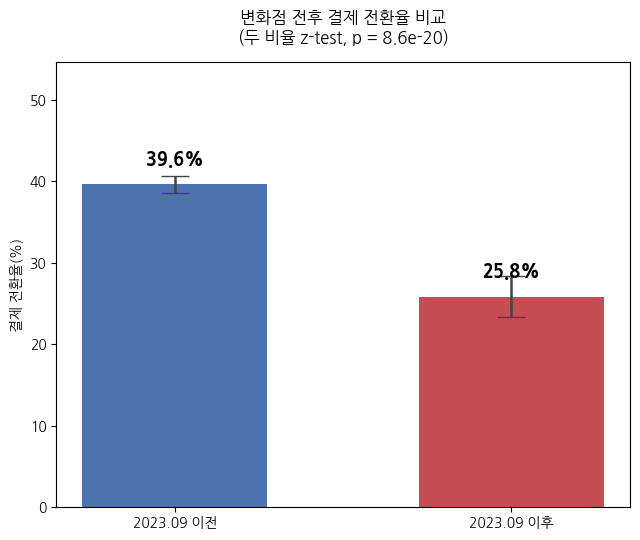

In [ ]:
# 결제율 비교 시각화

fig, ax = plt.subplots(figsize=(6.5,5.5))
labels = ['2023.09 이전', '2023.09 이후']
rates = [count[0]/nobs[0]*100, count[1]/nobs[1]*100]
errs_lo = [rates[0]-ci_pre[0]*100, rates[1]-ci_post[0]*100]
errs_hi = [ci_pre[1]*100-rates[0], ci_post[1]*100-rates[1]]

bars = ax.bar(labels, rates, yerr=[errs_lo, errs_hi], capsize=10,
              color=[COLOR_BEFORE, COLOR_AFTER], width=0.55,
              error_kw={'linewidth':1.8, 'ecolor':'#444444'})

for bar, rate in zip(bars, rates):
    ax.annotate(f'{rate:.1f}%', xy=(bar.get_x()+bar.get_width()/2, rate),
                xytext=(0,14), textcoords='offset points', ha='center',
                fontsize=13, fontweight='bold')

ax.set_title(f'변화점 전후 결제 전환율 비교\n(두 비율 z-test, p = {pval:.1e})', pad=14)
ax.set_ylabel('결제 전환율(%)')
ax.set_ylim(0, max(rates)+15)
plt.tight_layout()
plt.show()

> **📊 결과 해석**
>
> - 2023년 9월 이전 결제율은 3,350명/8,455명 = 39.62%, 이후는 302명/1,169명 = 25.83%로 약 13.79%p 감소했다.
> - 두 비율 z-test 결과는 z=9.105, p=8.59x10⁻²⁰이며, Wilson 95% 신뢰구간도 이전 [38.58%, 40.67%], 이후 [23.41%, 28.42%]로 겹치지 않는다.
> - 따라서 변화점 전후의 결제율 차이는 표본 변동만으로 설명하기 어려운 통계적으로 유의한 차이이다.

In [ ]:
# 유입·활성화 비교

n_pre, n_post = len(pre), len(post)
months_pre = 28  # 2021-05~2023-08
months_post = 4  # 2023-09~2023-12

print('=== 체험 시작자 수 변화 ===')
print(f'이전: 총 {n_pre}건, 월평균 {n_pre/months_pre:.1f}명')
print(f'이후: 총 {n_post}건, 월평균 {n_post/months_post:.1f}명')
print()

act_pre_gap, act_post_gap = pre.visited_flag.mean(), post.visited_flag.mean()
print('=== 활성화율(방문전환율) 변화 ===')
print(f'이전: {act_pre_gap:.4f} / 이후: {act_post_gap:.4f} (변화: {act_post_gap-act_pre_gap:+.4f})')
print()
print('해석: 월평균 체험 시작자수는 비슷한 수준 유지, 활성화율은 오히려 상승')
print('      → 체험 시작(유입) 자체의 감소가 아니라, 다른 단계에서 문제가 발생했을 가능성')

=== 체험 시작자 수 변화 ===
이전: 총 8455건, 월평균 302.0명
이후: 총 1169건, 월평균 292.2명

=== 활성화율(방문전환율) 변화 ===
이전: 0.6108 / 이후: 0.7374 (변화: +0.1266)

해석: 월평균 체험 시작자수는 비슷한 수준 유지, 활성화율은 오히려 상승
      → 체험 시작(유입) 자체의 감소가 아니라, 다른 단계에서 문제가 발생했을 가능성


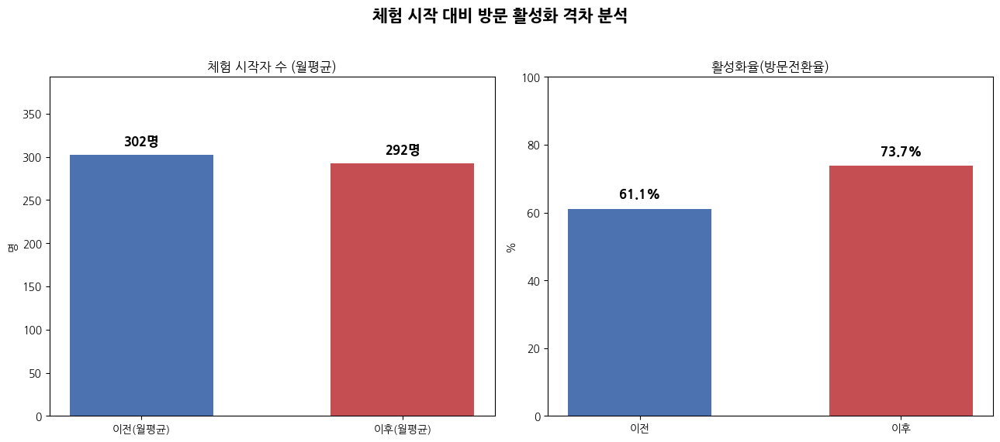

In [ ]:
# 유입·활성화 시각화

fig, axes = plt.subplots(1,2, figsize=(13,5.5))

# 체험 시작자 수 (월평균)
vals1 = [n_pre/months_pre, n_post/months_post]
bars1 = axes[0].bar(['이전(월평균)','이후(월평균)'], vals1, color=[COLOR_BEFORE, COLOR_AFTER], width=0.55)
for bar, v in zip(bars1, vals1):
    axes[0].annotate(f'{v:.0f}명', xy=(bar.get_x()+bar.get_width()/2, v),
                      xytext=(0,10), textcoords='offset points', ha='center', fontsize=12, fontweight='bold')
axes[0].set_title('체험 시작자 수 (월평균)')
axes[0].set_ylabel('명')
axes[0].set_ylim(0, max(vals1)*1.3)

# 활성화율
vals2 = [act_pre_gap*100, act_post_gap*100]
bars2 = axes[1].bar(['이전','이후'], vals2, color=[COLOR_BEFORE, COLOR_AFTER], width=0.55)
for bar, v in zip(bars2, vals2):
    axes[1].annotate(f'{v:.1f}%', xy=(bar.get_x()+bar.get_width()/2, v),
                      xytext=(0,10), textcoords='offset points', ha='center', fontsize=12, fontweight='bold')
axes[1].set_title('활성화율(방문전환율)')
axes[1].set_ylabel('%')
axes[1].set_ylim(0, 100)

fig.suptitle('체험 시작 대비 방문 활성화 격차 분석', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

> **📊 결과 해석**
>
> - 월평균 체험 시작자 수는 변화점 이전 302.0명, 이후 292.2명으로 약 9.8명 감소했지만 전체 규모는 유사하다.
> - 반면 체험 시작 후 실제 방문으로 이어진 활성화율은 61.08%에서 73.74%로 12.66%p 상승했다.
> - 결제율 하락을 유입 감소나 방문 유도 실패로 설명하기는 어렵고, 방문 이후 결제 단계의 변화 가능성을 확인해야 한다.

#### 6-1-1-3. 퍼널 단계 분리 및 병목 진단

**🔹 분석 목적**

- 전체 결제율만 비교하면 유입, 방문, 결제 중 어느 단계가 변했는지 알 수 없으므로 퍼널을 두 단계로 분리한다.
- `체험 시작→방문` 전환과 `방문→결제` 전환을 변화점 전후로 각각 비교한다.
- 두 단계의 변화 방향이 같은지 확인해 전체 결제율 감소를 만든 핵심 병목을 판단한다.
- 후속 전략이 신규 유입 확대에 집중해야 하는지, 방문자의 결제 전환에 집중해야 하는지 결정한다.

**🔹 퍼널 정의**

| 단계 | 계산 기준 | 의미 |
| --- | --- | --- |
| 1단계: 체험 시작→방문 | 방문자 수 ÷ 체험 시작자 수 | 신청자가 실제 공간 경험까지 도달했는가 |
| 2단계: 방문→결제 | 결제자 수 ÷ 방문자 수 | 공간을 경험한 사용자가 결제를 선택했는가 |

**🔹 해석 기준**

- 1단계가 유지되거나 상승하고 2단계만 하락한다면, 핵심 문제는 고객 획득보다 방문 후 전환에 있다고 판단한다.
- 결제 발생 시각이 없으므로 방문과 결제의 세부 선후관계는 확인할 수 없으며, 사용자 단위 최종 퍼널로 해석한다.

In [ ]:
# 퍼널 단계 검정

act_pre, act_post = pre.visited_flag.mean(), post.visited_flag.mean()
stat1, p1 = proportions_ztest([pre.visited_flag.sum(), post.visited_flag.sum()], [len(pre), len(post)])

pre_v, post_v = pre[pre.visited_flag==1], post[post.visited_flag==1]
pay_pre, pay_post = pre_v.is_payment.mean(), post_v.is_payment.mean()
stat2, p2 = proportions_ztest([pre_v.is_payment.sum(), post_v.is_payment.sum()], [len(pre_v), len(post_v)])

print(f'[1단계 체험시작→방문] 이전 {act_pre:.4f} / 이후 {act_post:.4f} (p={p1:.2e})')
print(f'[2단계 방문→결제] 이전 {pay_pre:.4f} / 이후 {pay_post:.4f} (p={p2:.2e})')

[1단계 체험시작→방문] 이전 0.6108 / 이후 0.7374 (p=4.99e-17)
[2단계 방문→결제] 이전 0.4096 / 이후 0.2575 (p=2.25e-17)


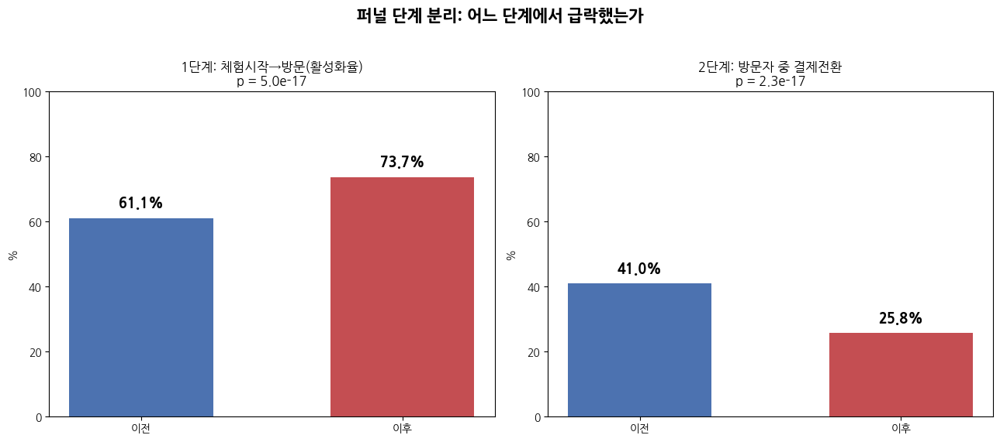

결론: 1단계는 오히려 개선, 2단계(방문 후 결제)에서만 급락 → 원인은 결제 결심 단계


In [ ]:
# 퍼널 병목 시각화

fig, axes = plt.subplots(1,2, figsize=(13,5.5))

vals1 = [act_pre*100, act_post*100]
bars1 = axes[0].bar(['이전','이후'], vals1, color=[COLOR_BEFORE, COLOR_AFTER], width=0.55)
for bar, v in zip(bars1, vals1):
    axes[0].annotate(f'{v:.1f}%', xy=(bar.get_x()+bar.get_width()/2, v),
                      xytext=(0,10), textcoords='offset points', ha='center', fontsize=13, fontweight='bold')
axes[0].set_title(f'1단계: 체험시작→방문(활성화율)\np = {p1:.1e}')
axes[0].set_ylim(0,100)
axes[0].set_ylabel('%')

vals2 = [pay_pre*100, pay_post*100]
bars2 = axes[1].bar(['이전','이후'], vals2, color=[COLOR_BEFORE, COLOR_AFTER], width=0.55)
for bar, v in zip(bars2, vals2):
    axes[1].annotate(f'{v:.1f}%', xy=(bar.get_x()+bar.get_width()/2, v),
                      xytext=(0,10), textcoords='offset points', ha='center', fontsize=13, fontweight='bold')
axes[1].set_title(f'2단계: 방문자 중 결제전환\np = {p2:.1e}')
axes[1].set_ylim(0,100)
axes[1].set_ylabel('%')

fig.suptitle('퍼널 단계 분리: 어느 단계에서 급락했는가', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

print('결론: 1단계는 오히려 개선, 2단계(방문 후 결제)에서만 급락 → 원인은 결제 결심 단계')

> **📊 결과 해석**
>
> - 1단계인 체험 시작→방문 전환율은 61.08%에서 73.74%로 12.66%p 상승했으며, 차이는 통계적으로 유의하다(p=4.99×10⁻¹⁷).
> - 2단계인 방문→결제 전환율은 40.96%에서 25.75%로 15.21%p 하락했으며, 이 차이도 통계적으로 유의하다(p=2.25×10⁻¹⁷).
> - 두 단계의 변화 방향이 반대이므로, 변화점 이후의 핵심 병목은 고객 유입이나 방문이 아니라 방문한 사용자가 결제를 결정하는 단계에 위치한다.

### 6-1-2. 지점별 방문 수요는 예측할 수 있을까?

**🔍 분석 목적**

- 지점별 일간 방문자 수를 예측해 인력·좌석·시설 운영에 활용할 수 있는지 확인한다.
- 전일 수요, 주간 주기, 최근 평균만 사용하는 단순 Baseline과 머신러닝 모델을 비교한다.
- Random Forest와 LightGBM 중 미래 구간에서 오차가 더 작은 모델을 선정한다.
- 변수 중요도와 SHAP을 통해 최근 방문 이력, 요일, 지점 특성 중 어떤 정보가 예측에 활용되는지 해석한다.

**🧬 분석 흐름**

1. 지점별 무방문 날짜까지 포함한 일간 Dense 시계열을 구성한다.
2. Lag 1, Lag 7, 7일 이동평균 Baseline을 생성한다.
3. 달력·지점·시차·이동통계 피처를 생성하고 시계열 누수를 점검한다.
4. 날짜 순서를 유지해 Train과 Test를 분리한다.
5. Baseline, Random Forest, LightGBM의 MAE와 RMSE를 비교한다.
6. 최종 모델의 변수 중요도와 SHAP 값을 해석한다.

#### 6-1-2-1. 일간 수요 데이터 연결 및 Baseline 구성

**🔹 분석 목적**

- 각 지점의 운영일별 방문자 수를 연속적인 시계열로 구성한다.
- 방문이 없었던 날짜도 0으로 포함해 실제 운영 캘린더 기준의 수요를 표현한다.
- 복잡한 모델이 실질적인 개선을 만드는지 비교할 수 있도록 단순하고 해석 가능한 Baseline을 먼저 설정한다.
- 미래 구간을 별도 테스트 데이터로 분리해 예측 모델의 일반화 성능을 평가한다.

**🔹 Baseline 정의**

| Baseline | 예측 기준 | 해석 |
| --- | --- | --- |
| Lag 1 | 전일 방문자 수 | 어제 수요가 오늘도 이어진다고 가정 |
| Lag 7 | 7일 전 방문자 수 | 같은 요일의 주간 패턴이 반복된다고 가정 |
| Moving Average 7 | 직전 7일 평균 방문자 수 | 최근 일주일의 평균 수준이 유지된다고 가정 |

**🔹 검증 기준**

- 지점·날짜 키의 중복 여부와 날짜 간격의 연속성을 확인한다.
- 시차 변수는 각 지점의 과거 값만 사용한다.
- Train·Test는 무작위로 섞지 않고 날짜 기준으로 분리해 미래 정보 누수를 방지한다.

In [ ]:
# Dense 데이터 연결

required_demand_columns = [
    "calendar_date",
    "site_id",
    "area_pyeong",
    "visit_info_user_count",
    "day_of_week",
    "day_type",
    "free_trial_usage_flag",
]

missing_demand_columns = [
    column
    for column in required_demand_columns
    if column not in day_covid_weather_df_d0_d2_dense_v3.columns
]

if missing_demand_columns:
    raise ValueError(
        "day_covid_weather_df_d0_d2_dense_v3에 "
        f"필요한 컬럼이 없습니다: {missing_demand_columns}"
    )

# 기존 코드의 변수명을 유지해 이후 분석 코드를 그대로 연결
day_v2 = (
    day_covid_weather_df_d0_d2_dense_v3
    .copy()
)

day_v2["calendar_date"] = pd.to_datetime(
    day_v2["calendar_date"],
    errors="raise",
)

day_v2 = (
    day_v2
    .sort_values(
        [
            "site_id",
            "calendar_date",
        ]
    )
    .reset_index(drop=True)
)

In [ ]:
# Dense 구조 검증

duplicate_count = day_v2.duplicated(
    subset=[
        "calendar_date",
        "site_id",
    ]
).sum()

date_gap_count = (
    day_v2
    .groupby("site_id")["calendar_date"]
    .diff()
    .dropna()
    .dt.days
    .ne(1)
    .sum()
)

negative_target_count = (
    day_v2["visit_info_user_count"]
    .lt(0)
    .sum()
)

assert duplicate_count == 0
assert date_gap_count == 0
assert negative_target_count == 0

print("=" * 60)
print("데이터 크기:", day_v2.shape)
print("분석 기간:", day_v2["calendar_date"].min(), "~", day_v2["calendar_date"].max())
print("지점 수:", day_v2["site_id"].nunique())
print("calendar_date × site_id 중복 수:", duplicate_count)
print("지점별 날짜 간격이 1일이 아닌 행 수:", date_gap_count)
print("방문자 수 음수 행 수:", negative_target_count)
print(
    "0수요 지점·일 수:",
    day_v2["free_trial_usage_flag"].eq(0).sum(),
)

display(day_v2.head())

데이터 크기: (6586, 46)
분석 기간: 2021-05-02 00:00:00 ~ 2024-01-01 00:00:00
지점 수: 9
calendar_date × site_id 중복 수: 0
지점별 날짜 간격이 1일이 아닌 행 수: 0
방문자 수 음수 행 수: 0
0수요 지점·일 수: 2557


,site_id,calendar_date,area_pyeong,visit_info_user_count,access_log_user_count,activity_user_count,visit_record_count,access_record_count,total_stay_seconds,checkin_count,...,weather_freezing_flag,weather_adverse_flag,weather_known_flag,weather_model,days_since_site_start,week_start,year,month,week_of_year,free_trial_usage_flag
0,1,2021-05-03,50,1,1,1,1,2,8546,1,...,0,0,1,era5,0,2021-05-03,2021,5,18,1
1,1,2021-05-04,50,0,0,0,0,0,0,0,...,0,1,1,era5,1,2021-05-03,2021,5,18,0
2,1,2021-05-05,50,0,0,0,0,0,0,0,...,0,0,1,era5,2,2021-05-03,2021,5,18,0
3,1,2021-05-06,50,0,0,0,0,0,0,0,...,0,0,1,era5,3,2021-05-03,2021,5,18,0
4,1,2021-05-07,50,0,0,0,0,0,0,0,...,0,0,1,era5,4,2021-05-03,2021,5,18,0


In [ ]:
# Baseline 생성

baseline_df = day_v2.copy()

baseline_df["baseline_lag1"] = (
    baseline_df
    .groupby("site_id")["visit_info_user_count"]
    .shift(1)
)

baseline_df["baseline_lag7"] = (
    baseline_df
    .groupby("site_id")["visit_info_user_count"]
    .shift(7)
)

baseline_df["baseline_ma7"] = (
    baseline_df
    .groupby("site_id")["visit_info_user_count"]
    .transform(
        lambda x: x.shift(1).rolling(window=7).mean()
    )
)

In [ ]:
# Baseline 결과 확인

baseline_columns = [
    "calendar_date",
    "site_id",
    "visit_info_user_count",
    "baseline_lag1",
    "baseline_lag7",
    "baseline_ma7"
]

display(
    baseline_df[baseline_columns]
    .groupby("site_id")
    .head(10)
)

,calendar_date,site_id,visit_info_user_count,baseline_lag1,baseline_lag7,baseline_ma7
0,2021-05-03,1,1,<NA>,<NA>,NaN
1,2021-05-04,1,0,1,<NA>,NaN
2,2021-05-05,1,0,0,<NA>,NaN
3,2021-05-06,1,0,0,<NA>,NaN
4,2021-05-07,1,0,0,<NA>,NaN
...,...,...,...,...,...,...
6338,2023-04-27,49,0,3,<NA>,NaN
6339,2023-04-28,49,0,0,<NA>,NaN
6340,2023-04-29,49,2,0,1,1.142857
6341,2023-04-30,49,3,2,0,1.285714


In [ ]:
# Baseline 결측치 확인

baseline_df[
    ["baseline_lag1", "baseline_lag7", "baseline_ma7"]
].isnull().sum()

,0
baseline_lag1,9
baseline_lag7,63
baseline_ma7,63


In [ ]:
# 시계열 평가 구간 분리

unique_dates = np.sort(baseline_df["calendar_date"].unique())

split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_index]

train_baseline = baseline_df[
    baseline_df["calendar_date"] < split_date
].copy()

test_baseline = baseline_df[
    baseline_df["calendar_date"] >= split_date
].copy()

print("분리 기준일:", pd.to_datetime(split_date))
print("Train 기간:",
      train_baseline["calendar_date"].min(),
      "~",
      train_baseline["calendar_date"].max())

print("Test 기간:",
      test_baseline["calendar_date"].min(),
      "~",
      test_baseline["calendar_date"].max())

print("Train 크기:", train_baseline.shape)
print("Test 크기:", test_baseline.shape)

분리 기준일: 2023-06-21 00:00:00
Train 기간: 2021-05-02 00:00:00 ~ 2023-06-20 00:00:00
Test 기간: 2023-06-21 00:00:00 ~ 2024-01-01 00:00:00
Train 크기: (4915, 49)
Test 크기: (1671, 49)


In [ ]:
# Train·Test 구간 확인

display(
    pd.DataFrame({
        "구분": ["Train", "Test"],
        "시작일": [
            train_baseline["calendar_date"].min(),
            test_baseline["calendar_date"].min()
        ],
        "종료일": [
            train_baseline["calendar_date"].max(),
            test_baseline["calendar_date"].max()
        ],
        "행 수": [
            len(train_baseline),
            len(test_baseline)
        ]
    })
)

,구분,시작일,종료일,행 수
0,Train,2021-05-02,2023-06-20,4915
1,Test,2023-06-21,2024-01-01,1671


> **💡 결과 요약**
>
> - 전일 값, 7일 전 값, 직전 7일 이동평균을 Baseline으로 생성했다.
> - 지점별 시계열 시작 구간에서만 결측이 발생해 `lag_1`은 9건, `lag_7`과 7일 이동평균은 각각 63건의 결측이 확인됐다.
> - 분리 기준일은 2023년 6월 21일이며, 원본 Baseline 기준 Train은 4,915행, Test는 1,671행이다.
> - 날짜 순서를 유지한 분할을 사용해 미래 정보를 과거 학습에 사용하는 시계열 누수를 방지했다.

#### 6-1-2-2. 예측 피처 생성 및 모델링 데이터 구성

**🔹 분석 목적**

- 방문 수요의 반복성과 변동성을 표현할 수 있도록 달력·시차·이동통계 변수를 생성한다.
- 지점 면적과 지점 ID를 포함해 지점별 기본적인 규모와 고유 패턴을 반영한다.
- 현재 날짜의 실제 방문자 수가 입력변수에 섞이지 않도록 모든 이동통계를 과거 시점으로 이동한 뒤 계산한다.
- 동일한 피처와 동일한 시간 분할을 사용해 모델 간 성능을 공정하게 비교한다.

**🔹 피처 구성**

| 피처 유형 | 주요 변수 | 반영 정보 |
| --- | --- | --- |
| 지점 정보 | `site_id`, `area_pyeong` | 지점별 고유 특성과 공간 규모 |
| 달력 정보 | 연·월·분기·일·요일·주말 여부 | 계절성 및 요일 패턴 |
| 시차 정보 | `lag_1`, `lag_7`, `lag_14`, `lag_28` | 최근 및 주기별 과거 수요 |
| 이동통계 | 7·14일 평균, 7일 표준편차·최댓값 | 최근 수요 수준과 변동성 |

**🔹 누수 방지 원칙**

- 시차 변수는 현재 날짜보다 이전의 값만 사용한다.
- 이동통계는 `shift(1)` 이후 계산해 목표 날짜의 방문자 수가 피처에 포함되지 않도록 한다.
- 시차 생성으로 발생한 지점별 초기 결측 구간만 모델링 데이터에서 제외한다.

In [ ]:
# 달력 변수 생성

model_df = baseline_df.copy()

model_df["year"] = model_df["calendar_date"].dt.year
model_df["month"] = model_df["calendar_date"].dt.month
model_df["quarter"] = model_df["calendar_date"].dt.quarter
model_df["day"] = model_df["calendar_date"].dt.day
model_df["dayofweek_num"] = model_df["calendar_date"].dt.dayofweek
model_df["is_weekend"] = (
    model_df["dayofweek_num"] >= 5
).astype(int)

In [ ]:
# 달력 변수 확인

calendar_features = [
    "calendar_date",
    "day_of_week",
    "day_type",
    "year",
    "month",
    "quarter",
    "day",
    "dayofweek_num",
    "is_weekend"
]

display(model_df[calendar_features].head(10))

,calendar_date,day_of_week,day_type,year,month,quarter,day,dayofweek_num,is_weekend
0,2021-05-03,월,평일,2021,5,2,3,0,0
1,2021-05-04,화,평일,2021,5,2,4,1,0
2,2021-05-05,수,공휴일,2021,5,2,5,2,0
3,2021-05-06,목,평일,2021,5,2,6,3,0
4,2021-05-07,금,평일,2021,5,2,7,4,0
5,2021-05-08,토,주말,2021,5,2,8,5,1
6,2021-05-09,일,주말,2021,5,2,9,6,1
7,2021-05-10,월,평일,2021,5,2,10,0,0
8,2021-05-11,화,평일,2021,5,2,11,1,0
9,2021-05-12,수,평일,2021,5,2,12,2,0


In [ ]:
# 시차·이동통계 생성

grouped_visit = model_df.groupby("site_id")["visit_info_user_count"]

# 시차 변수
model_df["lag_1"] = grouped_visit.shift(1)
model_df["lag_7"] = grouped_visit.shift(7)
model_df["lag_14"] = grouped_visit.shift(14)
model_df["lag_28"] = grouped_visit.shift(28)

# 이동평균 변수
model_df["rolling_mean_7"] = (
    grouped_visit
    .transform(lambda x: x.shift(1).rolling(window=7).mean())
)

model_df["rolling_mean_14"] = (
    grouped_visit
    .transform(lambda x: x.shift(1).rolling(window=14).mean())
)

# 이동 표준편차
model_df["rolling_std_7"] = (
    grouped_visit
    .transform(lambda x: x.shift(1).rolling(window=7).std())
)

# 최근 7개 관측값 중 최대 방문자 수
model_df["rolling_max_7"] = (
    grouped_visit
    .transform(lambda x: x.shift(1).rolling(window=7).max())
)

In [ ]:
# 시차 변수 확인

time_features = [
    "calendar_date",
    "site_id",
    "visit_info_user_count",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_std_7",
    "rolling_max_7"
]

display(
    model_df[time_features]
    .groupby("site_id")
    .head(30)
)

,calendar_date,site_id,visit_info_user_count,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_14,rolling_std_7,rolling_max_7
0,2021-05-03,1,1,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN
1,2021-05-04,1,0,1,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN
2,2021-05-05,1,0,0,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN
3,2021-05-06,1,0,0,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN
4,2021-05-07,1,0,0,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
6358,2023-05-17,49,3,3,1,3,<NA>,0.857143,0.857143,1.069045,3.0
6359,2023-05-18,49,2,3,1,2,<NA>,1.142857,0.857143,1.345185,3.0
6360,2023-05-19,49,0,2,1,0,<NA>,1.285714,0.857143,1.380131,3.0
6361,2023-05-20,49,0,0,0,0,1,1.142857,0.857143,1.463850,3.0


In [ ]:
# 시차 결측치 확인

time_feature_columns = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_std_7",
    "rolling_max_7"
]

display(
    model_df[time_feature_columns]
    .isnull()
    .sum()
    .to_frame("missing_count")
)

,missing_count
lag_1,9
lag_7,63
lag_14,126
lag_28,252
rolling_mean_7,63
rolling_mean_14,126
rolling_std_7,63
rolling_max_7,63


> **💡 결과 요약**
>
> - 달력 변수는 연·월·분기·일·요일·주말 여부를, 시차 변수는 1일·7일·14일·28일 전 방문자 수를 반영한다.
> - 이동통계는 최근 7일·14일 평균, 최근 7일 표준편차·최댓값으로 구성했다.
> - 결측치는 지점당 시차 길이에 맞게 `lag_1` 9건, `lag_7` 63건, `lag_14` 126건, `lag_28` 252건으로 발생했다.
> - 모든 이동통계는 `shift(1)` 후 계산해 현재 날짜의 목표값이 입력변수에 포함되지 않도록 했다.

In [ ]:
# 모델 변수 정의

feature_columns = [
    # 기본 정보
    "site_id",
    "area_pyeong",

    # 달력 변수
    "year",
    "month",
    "quarter",
    "day",
    "dayofweek_num",
    "is_weekend",

    # 시차 변수
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",

    # 이동통계 변수
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_std_7",
    "rolling_max_7"
]

target = "visit_info_user_count"

In [ ]:
# 모델 데이터 정제

model_data = model_df.dropna(subset=feature_columns).copy()

print("모델링 데이터 개수 :", len(model_data))

모델링 데이터 개수 : 6334


In [ ]:
# 시계열 Train·Test 분리

train_data = model_data[
    model_data["calendar_date"] < split_date
]

test_data = model_data[
    model_data["calendar_date"] >= split_date
]

print("Train :", len(train_data))
print("Test :", len(test_data))

Train : 4663
Test : 1671


In [ ]:
# 학습·평가 데이터 생성

X_train = train_data[feature_columns]
y_train = train_data[target]

X_test = test_data[feature_columns]
y_test = test_data[target]

In [ ]:
# 모델 데이터 확인

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)

print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

display(X_train.head())

X_train : (4663, 16)
X_test : (1671, 16)
y_train : (4663,)
y_test : (1671,)


,site_id,area_pyeong,year,month,quarter,day,dayofweek_num,is_weekend,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_14,rolling_std_7,rolling_max_7
28,1,50,2021,5,2,31,0,0,6,2,0,1,2.857143,2.571429,2.193063,6.0
29,1,50,2021,6,2,1,1,0,5,0,1,0,3.285714,2.928571,2.288689,6.0
30,1,50,2021,6,2,2,2,0,3,1,6,0,3.714286,3.071429,1.799471,6.0
31,1,50,2021,6,2,3,3,0,5,2,3,0,4.285714,3.000000,1.380131,6.0
32,1,50,2021,6,2,4,4,0,0,5,1,0,4.000000,2.785714,2.000000,6.0


In [ ]:
# 입력 변수 확인

print("사용 Feature")
print(X_train.columns.tolist())

사용 Feature
['site_id', 'area_pyeong', 'year', 'month', 'quarter', 'day', 'dayofweek_num', 'is_weekend', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7']


> **💡 결과 요약**
>
> - 모델 입력변수는 지점·면적, 달력 변수, 시차 변수, 이동통계 변수로 구성된 16개 피처이며, 목표변수는 지점별 일간 `visit_info_user_count`이다.
> - 시차 생성으로 생긴 지점별 초기 결측 구간을 제외한 모델링 데이터는 6,334행이다.
> - 동일한 분리 기준일을 적용해 Train 4,663행, Test 1,671행으로 구성했으며, 무작위 분할이 아닌 시간 순서 분할을 사용했다.

#### 6-1-2-3. Baseline과 Random Forest 성능 비교

**🔹 분석 목적**

- 세 개의 단순 Baseline 중 미래 수요를 가장 안정적으로 설명하는 기준 모델을 선정한다.
- 비선형 관계와 변수 간 상호작용을 반영할 수 있는 Random Forest가 Baseline의 오차를 줄이는지 확인한다.
- MAE와 RMSE를 함께 비교하되, 방문자 수를 크게 빗나가는 사례에 더 민감한 RMSE를 최종 선택 기준으로 활용한다.
- Random Forest의 변수 중요도를 통해 모델이 최근 수요, 달력, 지점 정보 중 무엇을 주로 사용했는지 확인한다.

**🔹 평가 기준**

| 지표 | 의미 | 활용 |
| --- | --- | --- |
| MAE | 예측값과 실제값의 평균 절대 오차 | 일반적인 예측 오차 수준 비교 |
| RMSE | 큰 오차에 더 큰 패널티를 주는 지표 | 운영상 큰 예측 실패를 고려한 최종 모델 비교 |

**🔹 해석 주의**

- Baseline 대비 개선 여부가 머신러닝 모델 도입의 최소 조건이다.
- 트리 기반 변수 중요도는 모델 내부의 상대적 활용 정도이며, 수요를 변화시키는 원인의 크기로 해석하지 않는다.

In [ ]:
# Baseline 평가 데이터

baseline_test = test_data.copy()

display(
    baseline_test[
        [
            "visit_info_user_count",
            "baseline_lag1",
            "baseline_lag7",
            "baseline_ma7"
        ]
    ].head()
)

,visit_info_user_count,baseline_lag1,baseline_lag7,baseline_ma7
779,1,1,2,0.857143
780,0,1,1,0.714286
781,0,0,1,0.571429
782,0,0,0,0.428571
783,0,0,0,0.428571


In [ ]:
# Baseline 성능 평가

baseline_results = []

baseline_models = {
    "Lag 1": "baseline_lag1",
    "Lag 7": "baseline_lag7",
    "Moving Average 7": "baseline_ma7"
}

for model_name, col in baseline_models.items():

    mae = mean_absolute_error(
        baseline_test[target],
        baseline_test[col]
    )

    rmse = np.sqrt(
        mean_squared_error(
            baseline_test[target],
            baseline_test[col]
        )
    )

    baseline_results.append(
        {
            "Model": model_name,
            "MAE": round(mae, 3),
            "RMSE": round(rmse, 3)
        }
    )

baseline_result_df = pd.DataFrame(baseline_results)

display(baseline_result_df)

,Model,MAE,RMSE
0,Lag 1,0.982,1.467
1,Lag 7,1.193,1.714
2,Moving Average 7,1.007,1.322


In [ ]:
# 최적 Baseline 선정

best_baseline = baseline_result_df.sort_values(
    "RMSE"
).iloc[0]

print("가장 좋은 Baseline")
print(best_baseline)

가장 좋은 Baseline
Model    Moving Average 7
MAE                 1.007
RMSE                1.322
Name: 2, dtype: object


> **📊 결과 해석**
>
> - Baseline별 성능은 Lag 1 MAE 0.982·RMSE 1.467, Lag 7 MAE 1.193·RMSE 1.714, 7일 이동평균 MAE 1.007·RMSE 1.322로 나타났다.
> - MAE만 보면 Lag 1이 가장 낮지만, 최종 비교 기준인 RMSE가 가장 낮은 7일 이동평균을 최적 Baseline으로 선정했다.
> - 이후 머신러닝 모델은 7일 이동평균의 MAE 1.007·RMSE 1.322보다 오차가 줄어드는지를 기준으로 평가한다.

In [ ]:
# Random Forest 생성

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

In [ ]:
# Random Forest 학습

rf_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=10, n_estimators=200, n_jobs=-1,
                      random_state=42)

In [ ]:
# Random Forest 예측

rf_pred = rf_model.predict(X_test)

In [ ]:
# Random Forest 성능 평가

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

print("Random Forest")
print(f"MAE  : {rf_mae:.3f}")
print(f"RMSE : {rf_rmse:.3f}")

Random Forest
MAE  : 0.916
RMSE : 1.216


In [ ]:
# Baseline·Random Forest 비교

comparison_df = pd.DataFrame({
    "Model": [
        best_baseline["Model"],
        "Random Forest",
    ],
    "MAE": [
        float(best_baseline["MAE"]),
        round(rf_mae, 3),
    ],
    "RMSE": [
        float(best_baseline["RMSE"]),
        round(rf_rmse, 3),
    ],
})

display(comparison_df)

,Model,MAE,RMSE
0,Moving Average 7,1.007,1.322
1,Random Forest,0.916,1.216


In [ ]:
# Random Forest 중요도 추출

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance_df = (
    importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

display(importance_df)

,Feature,Importance
0,lag_1,0.318254
1,rolling_mean_14,0.128752
2,rolling_std_7,0.073632
3,day,0.073328
4,dayofweek_num,0.067422
5,rolling_mean_7,0.065626
6,lag_28,0.061527
7,lag_14,0.040429
8,month,0.039034
9,lag_7,0.038154


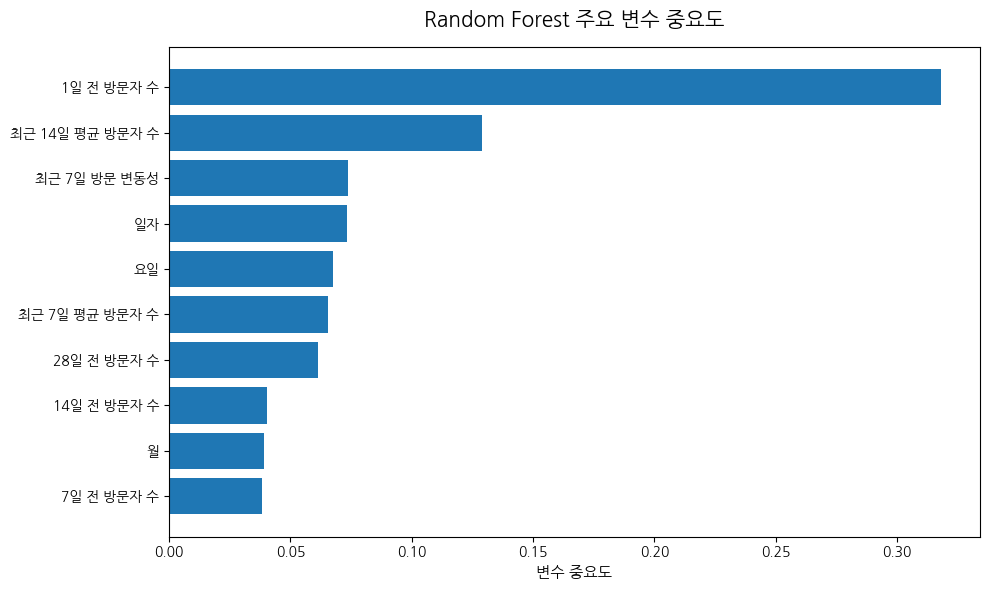

In [ ]:
# Random Forest 중요도 시각화

feature_name_map = {
    "site_id": "지점",
    "area_pyeong": "지점 면적",
    "year": "연도",
    "month": "월",
    "quarter": "분기",
    "day": "일자",
    "dayofweek_num": "요일",
    "is_weekend": "주말 여부",

    "lag_1": "1일 전 방문자 수",
    "lag_7": "7일 전 방문자 수",
    "lag_14": "14일 전 방문자 수",
    "lag_28": "28일 전 방문자 수",

    "rolling_mean_7": "최근 7일 평균 방문자 수",
    "rolling_mean_14": "최근 14일 평균 방문자 수",
    "rolling_std_7": "최근 7일 방문 변동성",
    "rolling_max_7": "최근 7일 최대 방문자 수"
}

# 중요도 상위 10개 변수
plot_df = importance_df.head(10).copy()

# 보고서용 한글 변수명으로 변경
plot_df["변수명"] = (
    plot_df["Feature"]
    .map(feature_name_map)
    .fillna(plot_df["Feature"])
)

# 낮은 중요도부터 그려 높은 중요도가 위쪽에 나오도록 정렬
plot_df = plot_df.sort_values("Importance", ascending=True)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["변수명"],
    plot_df["Importance"]
)

plt.title(
    "Random Forest 주요 변수 중요도",
    fontsize=15,
    pad=15
)
plt.xlabel("변수 중요도", fontsize=11)
plt.ylabel("")

plt.tight_layout()
plt.show()

> **📊 결과 해석**
>
> - Random Forest는 MAE 0.916·RMSE 1.216으로, 최적 Baseline보다 MAE는 약 9.0%, RMSE는 약 8.0% 개선됐다.
> - 변수 중요도는 `lag_1`이 31.8%로 가장 높고, `rolling_mean_14` 12.9%, `rolling_std_7` 7.4%, `day` 7.3%, `dayofweek_num` 6.7% 순으로 나타났다.
> - 최근 수요 이력이 예측에 가장 크게 활용됐지만, 변수 중요도는 모델 내 상대적 기여도이므로 인과관계로 해석할 수는 없다.

#### 6-1-2-4. LightGBM 추가 비교 및 최종 모델 선정

**🔹 분석 목적**

- 부스팅 계열 모델인 LightGBM을 추가해 Random Forest의 성능이 특정 알고리즘에만 의존하는지 비교한다.
- 동일한 Train·Test 구간과 피처를 사용해 Baseline, Random Forest, LightGBM을 공정하게 평가한다.
- MAE와 RMSE의 순위가 다를 경우 운영 목적상 큰 오차를 더 중요하게 보는 RMSE를 우선해 최종 모델을 선정한다.
- LightGBM의 변수 중요도에서도 최근 수요와 요일 패턴이 반복적으로 활용되는지 확인한다.

**🔹 모델 선택 원칙**

1. 미래 Test 구간에서 평가한다.
2. 단순 Baseline보다 오차가 낮아야 한다.
3. MAE 차이가 미미하면 RMSE가 낮은 모델을 우선한다.
4. 성능 차이뿐 아니라 해석 가능성과 운영 활용 범위를 함께 고려한다.

**🔹 해석 주의**

- 머신러닝 모델의 개선 폭이 크지 않다면 복잡한 모델 자체보다 최근 수요 이력이 강한 예측 신호라는 점이 더 중요한 결론이 될 수 있다.
- LightGBM의 split importance는 변수가 분기에 사용된 횟수이므로 영향 방향은 별도의 해석이 필요하다.

In [ ]:
# LightGBM 생성

lgbm_model = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

In [ ]:
# LightGBM 학습

lgbm_model.fit(X_train, y_train)

LGBMRegressor(learning_rate=0.05, max_depth=6, n_estimators=200, n_jobs=-1,
              random_state=42, verbosity=-1)

In [ ]:
# LightGBM 예측

lgbm_pred = lgbm_model.predict(X_test)

In [ ]:
# 음수 예측값 보정

lgbm_pred = np.clip(lgbm_pred, 0, None)

In [ ]:
# LightGBM 성능 평가

lgbm_mae = mean_absolute_error(
    y_test,
    lgbm_pred
)

lgbm_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        lgbm_pred
    )
)

print("LightGBM")
print(f"MAE  : {lgbm_mae:.3f}")
print(f"RMSE : {lgbm_rmse:.3f}")

LightGBM
MAE  : 0.915
RMSE : 1.265


In [ ]:
# 전체 모델 성능 비교

comparison_df = pd.DataFrame({
    "Model": [
        best_baseline["Model"],
        "Random Forest",
        "LightGBM",
    ],
    "MAE": [
        float(best_baseline["MAE"]),
        round(rf_mae, 3),
        round(lgbm_mae, 3),
    ],
    "RMSE": [
        float(best_baseline["RMSE"]),
        round(rf_rmse, 3),
        round(lgbm_rmse, 3),
    ],
})

comparison_df = (
    comparison_df
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(comparison_df)

,Model,MAE,RMSE
0,Random Forest,0.916,1.216
1,LightGBM,0.915,1.265
2,Moving Average 7,1.007,1.322


In [ ]:
# LightGBM 중요도 추출

importance_df_lgbm = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": lgbm_model.feature_importances_
})

importance_df_lgbm = (
    importance_df_lgbm
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

display(importance_df_lgbm.head(10))

,Feature,Importance
0,rolling_std_7,612
1,rolling_mean_14,574
2,dayofweek_num,520
3,day,494
4,rolling_mean_7,420
5,lag_28,343
6,lag_1,324
7,month,313
8,lag_14,258
9,lag_7,252


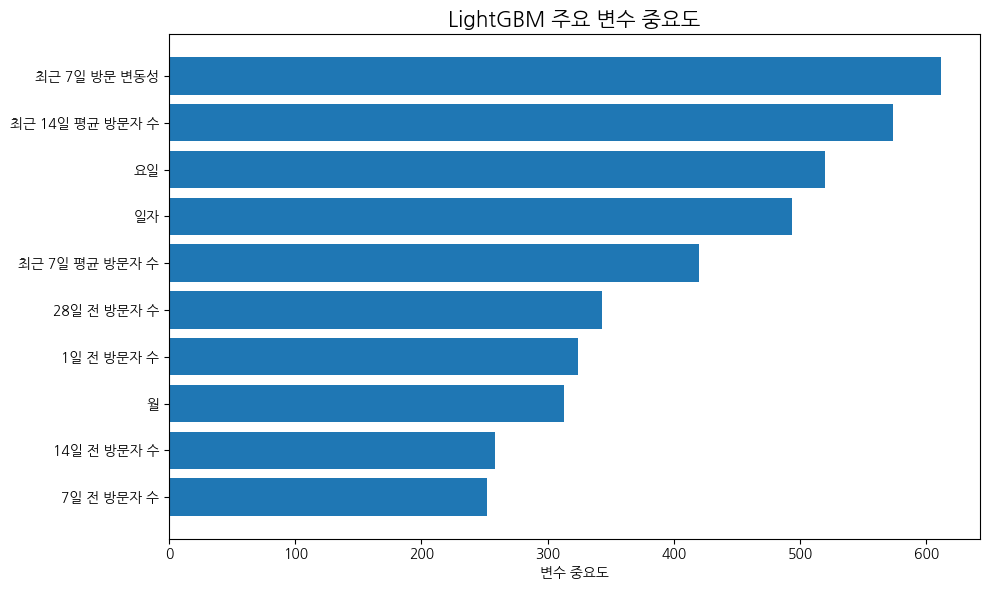

In [ ]:
# LightGBM 중요도 시각화

plot_df = importance_df_lgbm.head(10).copy()

plot_df["변수명"] = (
    plot_df["Feature"]
    .map(feature_name_map)
    .fillna(plot_df["Feature"])
)

plot_df = plot_df.sort_values("Importance")

plt.figure(figsize=(10,6))

plt.barh(
    plot_df["변수명"],
    plot_df["Importance"]
)

plt.title("LightGBM 주요 변수 중요도", fontsize=15)
plt.xlabel("변수 중요도")
plt.ylabel("")

plt.tight_layout()
plt.show()

> **📊 결과 해석**
>
> - LightGBM은 MAE 0.915·RMSE 1.265로, 최적 Baseline보다 MAE는 약 9.1%, RMSE는 약 4.3% 개선됐다.
> - MAE는 LightGBM이 Random Forest보다 0.001 낮지만, RMSE는 Random Forest가 1.216으로 LightGBM의 1.265보다 낮다.
> - LightGBM 중요도는 `rolling_std_7`, `rolling_mean_14`, `dayofweek_num`, `day`, `rolling_mean_7` 순으로 높아 최근 수요 수준과 변동성, 요일 정보가 반복적으로 활용됐다.
> - split importance는 활용 빈도이므로 변수의 영향 방향은 SHAP에서 추가로 확인한다.

In [ ]:
# 모델 비교표 확인

comparison_df

,Model,MAE,RMSE
0,Random Forest,0.916,1.216
1,LightGBM,0.915,1.265
2,Moving Average 7,1.007,1.322


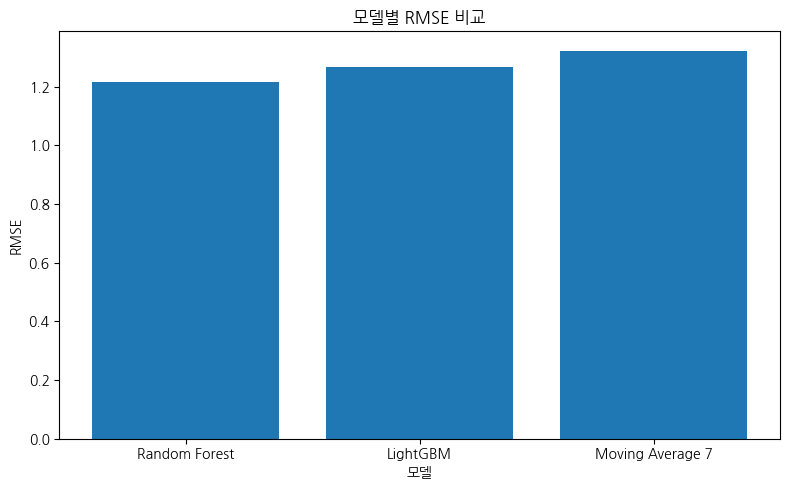

In [ ]:
# 모델 성능 시각화

comparison_plot = comparison_df.sort_values("RMSE")

plt.figure(figsize=(8,5))

plt.bar(
    comparison_plot["Model"],
    comparison_plot["RMSE"]
)

plt.title("모델별 RMSE 비교")
plt.xlabel("모델")
plt.ylabel("RMSE")

plt.tight_layout()
plt.show()

> **📊 결과 해석**
>
> - RMSE 기준 성능은 Random Forest 1.216 < LightGBM 1.265 < 7일 이동평균 1.322 순으로 나타나 Random Forest가 최종 후보이다.
> - MAE는 LightGBM이 0.915로 가장 낮지만 Random Forest의 0.916과 차이가 거의 없으며, 큰 오차에 더 민감한 RMSE에서는 Random Forest가 우수하다.
> - 두 머신러닝 모델 모두 Baseline을 개선했지만 개선 폭은 제한적이어서, 최근 수요 이력이 일별 방문 수요의 상당 부분을 설명하는 것으로 볼 수 있다.

#### 6-1-2-5. SHAP 기반 예측 요인과 영향 방향 해석

**🔹 분석 목적**

- 최종 모델의 각 변수가 예측 방문자 수를 높이거나 낮추는 방향으로 어떻게 작용했는지 확인한다.
- 전일 방문자 수와 최근 이동평균이 높을 때 예측 수요도 증가하는지 검증한다.
- 요일과 주말 여부가 다른 변수들과 함께 어떤 방향으로 반영되는지 시각적으로 점검한다.
- 모델 성능 결과를 단순 순위로 끝내지 않고 실제 운영에서 관찰해야 할 선행 신호로 연결한다.

**🔹 SHAP 해석 기준**

- 세로축 위쪽 변수일수록 평균적으로 모델 예측에 더 크게 기여한다.
- 점의 색은 해당 변수값의 높고 낮음을, 가로 위치는 예측 방문자 수를 높이거나 낮춘 방향을 의미한다.
- 같은 변수값에서도 SHAP 방향이 달라질 수 있으며, 이는 다른 변수와의 상호작용 또는 비선형 관계가 반영된 결과이다.

**🔹 해석 주의**

- SHAP은 모델이 예측을 구성한 방식을 설명하는 도구이며 실제 수요 변화의 인과효과를 추정하지 않는다.
- 운영에서는 특정 변수 하나보다 전일 수요, 최근 평균, 변동성, 요일 정보를 함께 모니터링하는 것이 적절하다.

In [ ]:
# SHAP 값 계산

# Random Forest 모델을 해석하는 SHAP Explainer 생성
explainer = shap.TreeExplainer(rf_model)

# 테스트 데이터의 SHAP 값 계산
shap_values = explainer.shap_values(X_test)

print("X_test 크기:", X_test.shape)
print("SHAP 값 크기:", np.array(shap_values).shape)

X_test 크기: (1671, 16)
SHAP 값 크기: (1671, 16)


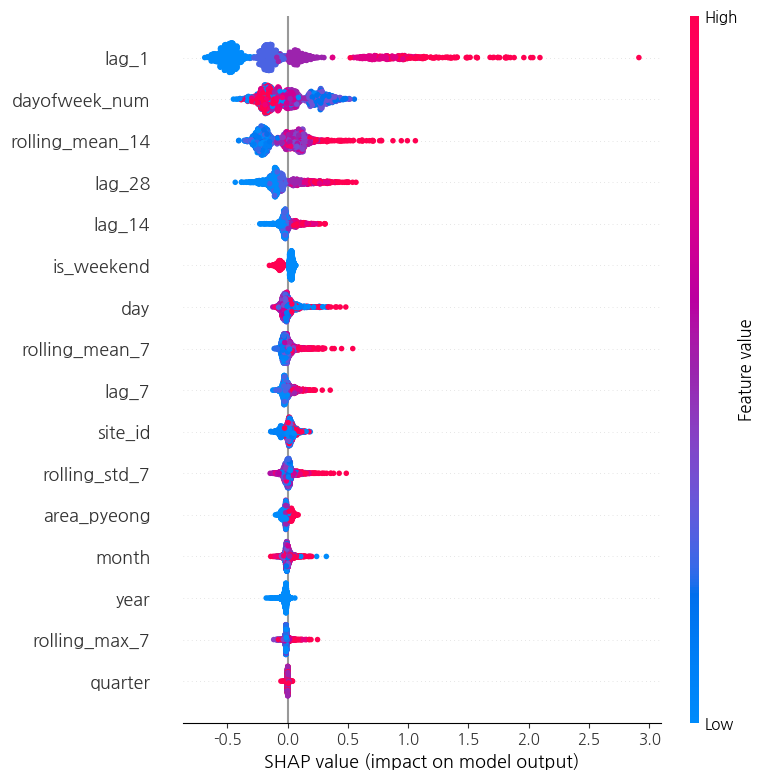

In [ ]:
# SHAP 요약 시각화
plt.figure(figsize=(10,6))

shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X_test.columns,
    show=False
)

plt.tight_layout()
plt.show()

> **📊 결과 해석**
>
> - SHAP 평균 영향도 기준 상위 변수는 `lag_1`, `dayofweek_num`, `rolling_mean_14`, `lag_28`, `lag_14` 순으로 나타났다.
> - `lag_1`과 `rolling_mean_14`가 높을수록 대체로 예측 방문자 수를 높이는 방향으로 작용해, 전일 수요와 최근 2주 수준이 핵심 신호임을 확인했다.
> - `is_weekend`의 높은 값은 주로 음의 SHAP 영역에 분포해, 다른 조건이 같을 때 주말이 예측 수요를 낮추는 방향으로 반영됐다.
> - 요일 숫자의 영향은 단순한 직선 관계가 아니며, SHAP은 모델 예측 설명 도구이므로 인과관계를 확정하는 결과는 아니다.

### 6-1-3. 통합 결론 및 실행 전략

**🚀 문제는 고객을 데려오는 것이 아니라, 방문한 고객을 결제로 연결하는 것이었다**

| 분석 질문 | 핵심 결과 | 최종 판단 |
| --- | --- | --- |
| 결제율은 언제 달라졌는가? | 월별 결제율의 단일 변화점은 2023년 9월로 나타났으며, 이후 결제율 수준이 뚜렷하게 낮아졌다. | 2023년 9월을 기준으로 전환 구조의 변화를 진단한다. |
| 고객 유입도 함께 줄었는가? | 월평균 체험 시작자 수는 유사했고, 체험 시작→방문 활성화율은 오히려 상승했다. | 결제 감소를 유입 부족이나 방문 유도 실패로 설명하기 어렵다. |
| 퍼널의 병목은 어디인가? | 방문→결제 전환율만 큰 폭으로 하락했다. | 우선 개선 대상은 신규 유입이 아니라 방문 이후 결제 전환이다. |
| 방문 수요는 예측 가능한가? | Random Forest가 RMSE 기준으로 Baseline과 LightGBM보다 우수했다. | 지점별 단기 수요 예측을 운영 계획의 보조지표로 활용할 수 있다. |
| 어떤 정보가 예측에 중요한가? | 전일 수요와 최근 1~2주의 수요 수준·변동성이 반복적으로 중요하게 나타났다. | 최근 방문 패턴을 중심으로 지점 운영을 모니터링한다. |

- 서비스로 들어오는 체험 신청 규모와 실제 방문 활성화는 유지되거나 개선되었지만, 방문 경험이 최종 결제로 이어지는 힘은 약해졌다.
- 따라서 `유입 확대`와 `방문 수요 운영`만으로는 결제 감소를 해결할 수 없으며, 방문자의 다음 행동과 결제 제안을 별도로 개선해야 한다.
- 동시에 방문 수요는 최근 패턴을 기반으로 일정 수준 예측할 수 있으므로, 결제 문제와 별개로 지점 운영 효율을 높이는 데 활용할 수 있다.

**🛠️ Diagnose x Convert x Operate 실행안**

1. Diagnose - 퍼널 KPI를 단계별로 분리 관리

- 체험 신청자 수, 방문 활성화율, 방문 후 결제율을 하나의 전체 결제율로 묶지 않고 각각 관리한다.
- 특히 2023년 9월 이후에는 `방문자 수`보다 `방문자 중 결제자 비율`을 핵심 경보 지표로 설정한다.
- 월별 결제율, 방문 후 결제율, 지점별 전환율을 함께 모니터링해 동일한 하락이 지속되는지 확인한다.

2. Convert - 방문 이후 행동을 결제로 연결

- 추가 광고나 체험 신청 확대보다 방문자의 이용 지속성과 결제 의사결정 지원을 우선한다.
- 6-2에서 확인한 반복 방문 신호를 활용해 첫 방문 후 두 번째 날짜 방문이 없는 사용자를 D1 CRM의 핵심 대상으로 설정한다.
- 재방문 안내, 원클릭 예약, 남은 체험일 알림, 두 번째 방문 후 상품 안내를 단계적으로 제공한다.
- 전략 효과는 재방문율과 최종 결제율을 함께 보는 A/B 테스트로 검증한다.

3. Operate - 예측 수요를 지점 운영에 활용

- Random Forest의 일간 수요 예측값을 기준으로 지점별 예상 수요 수준을 사전에 확인한다.
- 예상 수요가 높은 날짜에는 현장 인력, 좌석, 회의실, 소모품 점검을 강화하고 낮은 날짜에는 운영 자원을 탄력적으로 배분한다.
- 예측값 하나로 운영을 자동 결정하지 않고, 전일 수요·최근 2주 평균·변동성·요일 정보를 함께 표시한다.
- 6-3의 지점별 수요·전환 진단과 결합해 고수요 지점은 혼잡 관리, 저수요 지점은 유입 실험, 저전환 지점은 결제 경험 개선에 우선순위를 둔다.

**📊 핵심 운영 KPI**

| 관리 영역 | 핵심 KPI | 활용 목적 |
| --- | --- | --- |
| 유입 | 월별 체험 시작자 수 | 신규 체험 수요의 규모 확인 |
| 활성화 | 체험 시작→방문 전환율 | 신청자가 실제 경험까지 도달하는지 확인 |
| 결제 | 방문→결제 전환율 | 방문 이후 핵심 병목 모니터링 |
| 행동 | D2 종료 전 두 번째 날짜 방문율 | 결제와 연결된 활성화 행동 관리 |
| 수요 | 지점별 일간 방문자 수·예측 오차 | 인력·좌석·시설 운영 조정 |
| 모델 | MAE·RMSE 및 월별 오차 추이 | 예측 성능 저하와 재학습 필요성 확인 |

**🚧 분석 한계**

- 결제 발생 날짜와 시각이 없어 방문 행동과 결제의 정확한 선후관계, 결제까지 걸린 시간을 분석할 수 없다.
- 변화점 이후 기간은 2023년 9~12월로 짧아 이후에도 동일한 하락이 유지되는지 추가 기간 검증이 필요하다.
- 변화점 분석은 결제율 수준이 달라진 시점을 찾았을 뿐, 가격·상품·CRM·경쟁 환경 중 무엇이 원인인지는 확인하지 못한다.
- 수요 예측 모델은 지점·달력·과거 수요 변수를 중심으로 구성되어 날씨, 프로모션, 공휴일 세부 효과, 지역 행사 등 외부 요인을 충분히 반영하지 못한다.
- 머신러닝 모델의 Baseline 대비 개선 폭은 제한적이므로, 예측값을 확정 수요가 아닌 운영 참고 범위로 사용해야 한다.

## **6-2. 무료 체험 사용자의 어떤 행동이 결제 전환을 만들며, 언제 개입해야 하는가?**

**🎯 무료 체험 이용행태를 기반으로 결제 전환 신호를 정의하고 D1 개입 전략을 설계**

| 핵심 질문 | 분석 역할 | 최종 활용 |
| --- | --- | --- |
| **누구를 집중 공략할 것인가?** | 최초 이용 시간대별 결제율 비교 | 저녁/퇴근형 유입 타겟 |
| **어떤 행동을 만들어야 하는가?** | 군집화·체류시간·다지점·반복 방문 검증 | 서로 다른 날짜의 두 번째 방문 |
| **언제 개입해야 하는가?** | D0~D2 랜드마크 모델링 | D1 재방문 개입 |
| **어떻게 운영할 것인가?** | 행동 세그먼트·임계값·강건성 검증 | 재방문 CRM 및 후속 A/B 테스트 |

**📌 분석 해석**

- 시간대 분석은 유입 타겟을 찾는 분석, 군집화는 행동 패턴을 탐색하는 분석이다.
- 다지점 통제 분석은 핵심 전환 행동을 검증하는 분석, 랜드마크 모델은 신호가 형성되는 시점을 확인하는 분석이다.
- 관찰 데이터이므로 결제 전환의 인과효과를 확정하지 않고, 운영 실험으로 검증할 후보 행동과 개입 시점을 제안한다.

### 6-2-1. 이용행태 기반 사용자 군집화와 전환 차이

**🔍 분석 목적**

- 방문자의 최초 이용 시간대와 체험 행동을 기준으로 고전환 후보군과 주요 행동 유형을 탐색한다.
- 체류시간, 방문일 수, 체크인 횟수, 이용 지점 수를 함께 사용해 사용량의 조합을 군집화한다.
- 군집별 결제율을 비교해 단순히 많이 사용하는 집단이 결제율도 높은지 확인한다.
- 이 단계는 핵심 행동을 확정하는 것이 아니라, 후속 다지점·반복 방문 검증의 가설을 만드는 탐색 단계이다.

**🧬 분석 흐름**

1. 최초 입실 시간대로 사용자 세그먼트 생성
2. 행동 변수 로그 변환·표준화·이상치 제거
3. K-Means 군집화와 PCA 시각화
4. 체류시간 구간 및 방문 패턴별 결제율 비교
5. 가입 시기를 통제한 군집별 결제 오즈비 검증

#### 6-2-1-1. 방문 사용자와 시간대별 행동 특성

**🔹 분석 목적**

- 실제 오프라인 방문 사용자만 대상으로 최초 입실 시각을 추출한다.
- 최초 입실 시간을 아침, 오후, 저녁, 심야로 구분해 시간대별 사용자 규모와 결제율을 비교한다.
- 결제율이 높은 시간대는 핵심 전환 행동이 아니라 향후 유입을 확대할 우선 타겟 후보로 해석한다.

**🔹 시간대 정의**

- 아침/출근형: 06~11시
- 오후/주간형: 12~17시
- 저녁/퇴근형: 18~23시
- 심야/올빼미형: 00~05시


In [ ]:
# 오프라인 방문 유저만 필터링 (visited_flag == 1)

visited_df = user_df[user_df['visited_flag'] == 1].copy()

In [ ]:
# 최초 입실 시각에서 시간대 변수를 생성

visited_df['first_enter_at'] = pd.to_datetime(visited_df['first_enter_at'])

visited_df['enter_hour'] = visited_df['first_enter_at'].dt.hour

In [ ]:
# 시간대별 세그먼트(라이프스타일)

def get_time_segment(hour):
    if 6 <= hour < 12: return '아침/출근형 (06~11시)'
    elif 12 <= hour < 18: return '오후/주간형 (12~17시)'
    elif 18 <= hour < 24: return '저녁/퇴근형 (18~23시)'
    else: return '심야/올빼미형 (00~05시)'

visited_df['time_segment'] = visited_df['enter_hour'].apply(get_time_segment)

In [ ]:
# 세그먼트별 집계

time_eda = visited_df.groupby('time_segment').agg(
    user_count=('user_id', 'count'),
    payment_rate=('is_payment', 'mean')
).reset_index()

In [ ]:
# 시간대별 사용자 비중과 결제율을 계산

time_eda['user_ratio(%)'] = (time_eda['user_count'] / time_eda['user_count'].sum()) * 100
time_eda['payment_rate(%)'] = time_eda['payment_rate'] * 100

time_eda = time_eda.sort_values(by='payment_rate(%)', ascending=False).round(2)
time_eda.head()

,time_segment,user_count,payment_rate,user_ratio(%),payment_rate(%)
3,저녁/퇴근형 (18~23시),979,0.5,16.25,49.95
2,오후/주간형 (12~17시),3193,0.37,52.99,36.74
1,아침/출근형 (06~11시),1666,0.37,27.65,36.61
0,심야/올빼미형 (00~05시),188,0.35,3.12,34.57


> **💡 결과 해석**
>
> - 저녁/퇴근형은 전체 방문자의 16.25%(979명)로 규모는 작지만 결제율이 49.95%로 가장 높았다.
> - 오후/주간형은 52.99%로 가장 큰 집단이지만 결제율은 36.74%에 그쳐, 이용량이 큰 시간대와 고전환 시간대가 동일하지 않았다.
> - 따라서 저녁형은 핵심 전환 행동의 원인이라기보다 유입을 확대할 고전환 후보군으로 활용한다.


#### 6-2-1-2. 군집화 변수 전처리와 군집 수 탐색

**🔹 분석 목적**

- 방문일 수, 총 체류시간, 체크인 횟수, 이용 지점 수를 이용해 행동 패턴을 군집화할 입력 데이터를 만든다.
- 체류시간과 체크인 횟수의 오른쪽 꼬리를 줄이기 위해 `log1p` 변환을 적용한다.
- 단위가 다른 변수들을 `StandardScaler`로 표준화하고, 표준화값 절대값이 3을 초과하는 극단 이상치를 제거한다.
- K=2~8의 관성을 비교하는 엘보우 방법으로 적정 군집 수를 탐색한다.

**🔹 해석 주의**

- 이상치 제거는 일반적인 행동 유형을 안정적으로 구분하기 위한 처리이며, 제거된 고강도 사용자는 별도 분석 대상이 될 수 있다.
- 엘보우 방법은 군집 수를 자동 확정하는 검정이 아니라, 이후 프로파일의 해석 가능성과 함께 판단하는 탐색 기준이다.

In [ ]:
# 군집화에 사용할 핵심 행동 변수를 선정

features = ['visit_days', 'total_stay_seconds', 'checkin_count', 'distinct_site_count']
visited_df = visited_df.dropna(subset=features)

In [ ]:
# 분포 왜도 보정을 위한 log1p 변환 (체류시간, 출입 횟수)

visited_df['log_total_stay'] = np.log1p(visited_df['total_stay_seconds'])
visited_df['log_checkin'] = np.log1p(visited_df['checkin_count'])

In [ ]:
# 모델링용 피처 세팅 및 상관관계 검토

corr_features = ['visit_days', 'log_total_stay', 'log_checkin', 'distinct_site_count']
corr_matrix = visited_df[corr_features].corr()
print("Correlation Matrix:\n", corr_matrix)

Correlation Matrix:
                      visit_days  log_total_stay  log_checkin  \
visit_days             1.000000        0.546810     0.594022   
log_total_stay         0.546810        1.000000     0.652184   
log_checkin            0.594022        0.652184     1.000000   
distinct_site_count    0.198308        0.091709     0.146941   

                     distinct_site_count  
visit_days                      0.198308  
log_total_stay                  0.091709  
log_checkin                     0.146941  
distinct_site_count             1.000000  


> **💡 결과 해석**
>
> - 로그 체류시간과 로그 체크인 횟수의 상관계수는 0.652로 가장 높았고, 방문일 수와 체크인 횟수도 0.594의 양의 상관을 보였다.
> - 이용 지점 수는 다른 행동 변수와의 상관이 0.09~0.20 수준으로 낮아, 별도의 행동 축을 제공할 가능성이 있다.

In [ ]:
# 피처 스케일링 (StandardScaler)

scaler = StandardScaler()
scaled_features = scaler.fit_transform(visited_df[corr_features])
visited_df_scaled = pd.DataFrame(scaled_features, columns=[f"scaled_{col}" for col in corr_features], index=visited_df.index)
visited_df = pd.concat([visited_df, visited_df_scaled], axis=1)

In [ ]:
# 극단 이상치 제거 (Z-score 절대값 3 초과 기준)

outlier_condition = (np.abs(visited_df_scaled) > 3).any(axis=1)
clustering_df = visited_df[~outlier_condition].copy()

In [ ]:
# 이상치 제거 규모와 최종 군집화 표본을 확인

print(f"\n이상치 개수: {outlier_condition.sum()} / {len(visited_df)}")
print(f"클러스터링용 데이터 크기: {clustering_df.shape}")


이상치 개수: 315 / 6023
클러스터링용 데이터 크기: (5708, 45)


> **✅ 확인 결과**
>
> - 표준화 Z-score 절대값 3 초과 기준으로 315명을 제외하고 5,708명을 군집화 표본으로 사용했다.
> - 전체 방문자의 대부분을 유지하면서 극단적인 고강도 이용 패턴이 군집 중심을 과도하게 끌어가는 영향을 줄였다.

In [ ]:
# 표준화된 군집화 입력 행렬을 생성

X = clustering_df[[f"scaled_{col}" for col in corr_features]]

In [ ]:
# K-Means 관성(Inertia) 계산

K_range = range(2, 9)
inertias = []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    inertias.append(kmeans.inertia_)

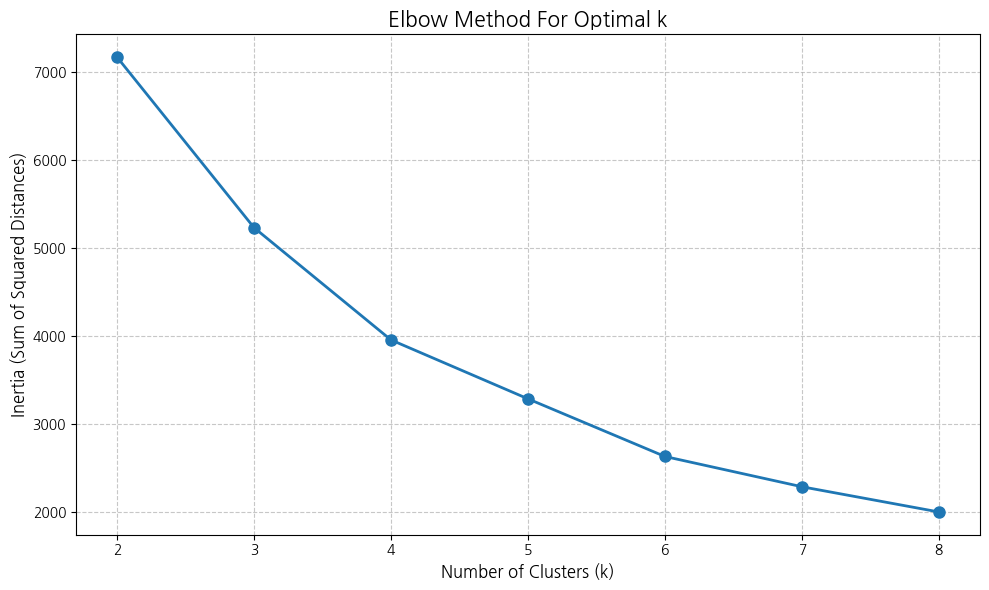

In [ ]:
# 엘보우 기법 시각화

plt.figure(figsize=(10, 6))
plt.plot(K_range, inertias, marker='o', linestyle='-', color='#1f77b4', linewidth=2, markersize=8)
plt.title('Elbow Method For Optimal k', fontsize=15)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Inertia (Sum of Squared Distances)', fontsize=12)
plt.xticks(K_range)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - K=2~8의 관성 감소 폭을 비교해 급격한 개선이 완만해지는 구간을 확인했다.
> - 이후 군집 프로파일의 구분 가능성과 해석 가능성을 함께 고려해 K=4를 적용한다.

#### 6-2-1-3. K-Means 군집화와 군집 프로파일링

**🔹 분석 목적**

- 엘보우 결과와 해석 가능성을 기준으로 K=4를 적용한다.
- 각 군집의 사용자 비중, 결제율, 평균 방문일 수, 체류시간, 체크인 횟수, 이용 지점 수를 비교한다.
- 체류·출입 강도가 가장 높은 군집과 결제율이 가장 높은 군집이 동일한지 확인한다.
- 산점도와 PCA 2차원 투영을 통해 군집 간 분리 정도와 중첩을 시각적으로 점검한다.

**🔹 해석 기준**

- 군집 번호는 크기나 우열의 순서가 아닌 K-Means가 임의로 부여한 라벨이다.
- 결제율은 군집 생성에 사용하지 않았으므로, 군집화 이후 외부 결과변수로 비교한다.

In [ ]:
# K-Means 모델링 (K=4 적용)

k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

In [ ]:
# 군집 라벨 데이터프레임에 할당

clustering_df['cluster'] = kmeans.fit_predict(X)

In [ ]:
# 군집별 프로파일링 (원본 행동 데이터 평균 및 결제율)

cluster_profile = clustering_df.groupby('cluster').agg(
    user_count=('user_id', 'count'),                     # 유저 수
    payment_rate=('is_payment', 'mean'),                 # 결제율
    avg_visit_days=('visit_days', 'mean'),               # 평균 방문일수
    avg_total_stay_sec=('total_stay_seconds', 'mean'),   # 평균 총 체류시간(초)
    avg_checkin_count=('checkin_count', 'mean'),         # 평균 출입 횟수
    avg_distinct_sites=('distinct_site_count', 'mean')   # 평균 방문 지점 수
).reset_index()

In [ ]:
# 군집별 비중·결제율·행동 특성을 정리

cluster_profile['user_ratio(%)'] = (cluster_profile['user_count'] / cluster_profile['user_count'].sum()) * 100
cluster_profile['payment_rate(%)'] = cluster_profile['payment_rate'] * 100
cluster_profile['avg_total_stay_hour'] = cluster_profile['avg_total_stay_sec'] / 3600 # 시간 단위로 변환

final_profile = cluster_profile[['cluster', 'user_count', 'user_ratio(%)', 'payment_rate(%)',
                                 'avg_visit_days', 'avg_total_stay_hour', 'avg_checkin_count', 'avg_distinct_sites']]

print(final_profile.round(2).to_markdown(index=False))

|   cluster |   user_count |   user_ratio(%) |   payment_rate(%) |   avg_visit_days |   avg_total_stay_hour |   avg_checkin_count |   avg_distinct_sites |
|----------:|-------------:|----------------:|------------------:|-----------------:|----------------------:|--------------------:|---------------------:|
|         0 |         1264 |           22.14 |             39.32 |             2.24 |                 14.27 |               11.56 |                    1 |
|         1 |         1772 |           31.04 |             31.15 |             1    |                  5.95 |                4.55 |                    1 |
|         2 |         1533 |           26.86 |             39.79 |             1.02 |                  2.19 |                1.59 |                    1 |
|         3 |         1139 |           19.95 |             47.94 |             2.04 |                  7.52 |                4.1  |                    1 |


> **💡 결과 해석**
>
> - 결제율이 가장 높은 군집은 약 2.04일 방문, 7.52시간 체류, 4.10회 체크인을 보인 Cluster 3으로 결제율은 47.94%였다.
> - 체류시간과 체크인이 가장 높은 Cluster 0은 14.27시간·11.56회였지만 결제율은 39.32%에 그쳤고, 1일 장기 체류형 Cluster 1은 31.15%로 가장 낮았다.
> - 최대 사용량보다 적정 수준의 이용이 약 2일간 지속되는 패턴에서 높은 전환이 나타났다.


In [ ]:
# K-Means 군집화 (K=4)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clustering_df['cluster'] = kmeans.fit_predict(X)

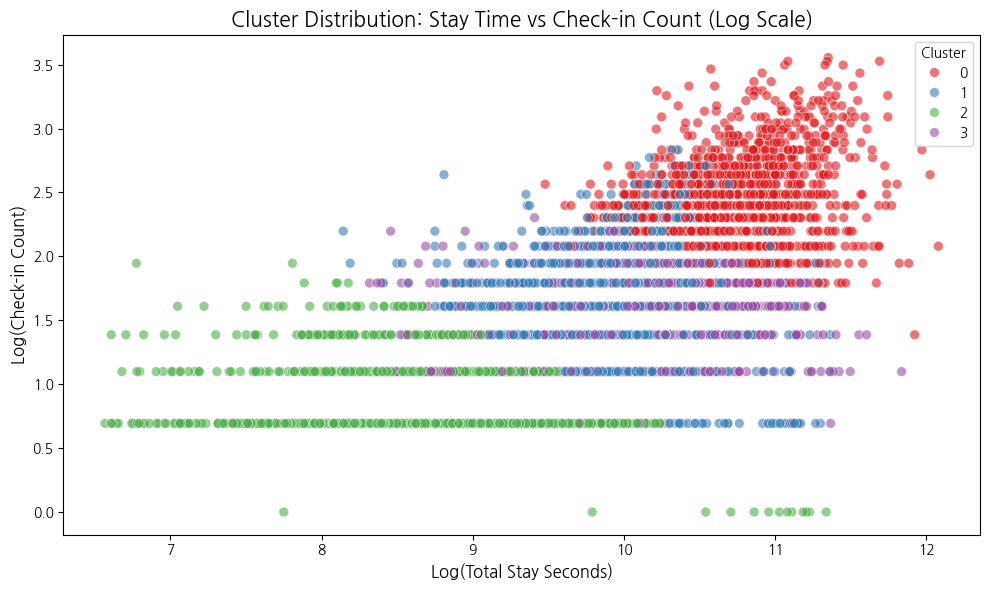

In [ ]:
# 체류시간 vs 출입횟수

plt.figure(figsize=(10, 6))
sns.scatterplot(x='log_total_stay', y='log_checkin', hue='cluster', palette='Set1', data=clustering_df, s=50, alpha=0.6)
plt.title('Cluster Distribution: Stay Time vs Check-in Count (Log Scale)', fontsize=15)
plt.xlabel('Log(Total Stay Seconds)', fontsize=12)
plt.ylabel('Log(Check-in Count)', fontsize=12)
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 체류시간과 체크인 횟수를 함께 보면 저강도·중간강도·고강도 이용 집단이 구분된다.
> - 다만 군집 경계가 완전히 분리되지는 않으므로, 군집은 절대적인 고객 유형보다 대표 행동 패턴으로 해석한다.

In [ ]:
# PCA 차원 축소

pca = PCA(n_components=2)
pca_result = pca.fit_transform(X)
clustering_df['pca_1'] = pca_result[:, 0]
clustering_df['pca_2'] = pca_result[:, 1]

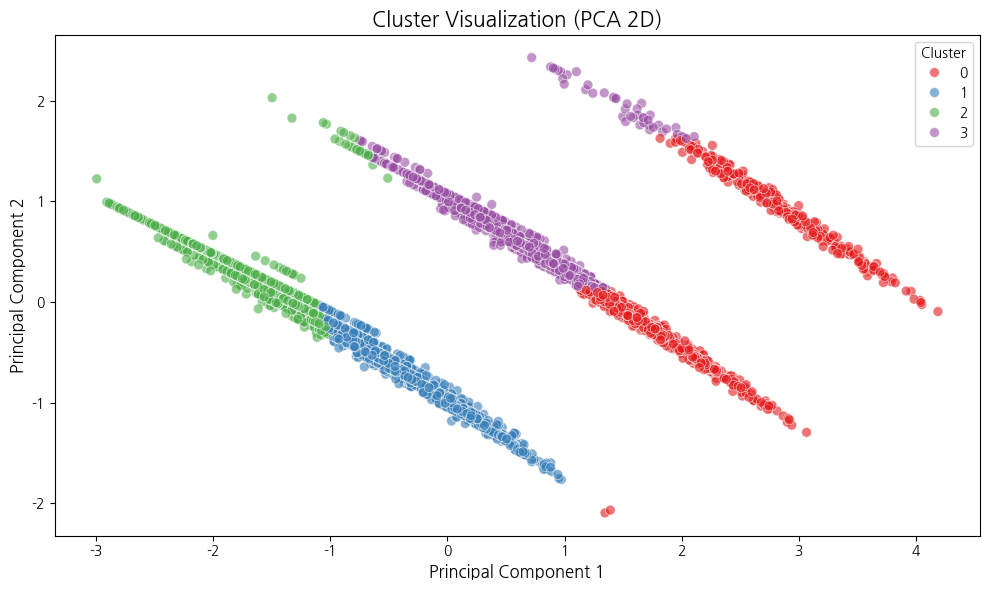

In [ ]:
# PCA 기반 2D 산점도

plt.figure(figsize=(10, 6))
sns.scatterplot(x='pca_1', y='pca_2', hue='cluster', palette='Set1', data=clustering_df, s=50, alpha=0.6)
plt.title('Cluster Visualization (PCA 2D)', fontsize=15)
plt.xlabel('Principal Component 1', fontsize=12)
plt.ylabel('Principal Component 2', fontsize=12)
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - PCA 2차원 공간에서도 군집의 중심 차이는 확인되지만 일부 구간은 중첩된다.
> - 이는 사용자 행동이 완전히 독립된 유형으로 끊어지기보다 연속적인 강도 차이를 포함한다는 점을 보여준다.

#### 6-2-1-4. 체류·방문 패턴별 결제 전환 비교

**🔹 분석 목적**

- 총 체류시간을 사분위수로 구분해 체류시간이 길수록 결제율이 선형적으로 높아지는지 확인한다.
- `1일 방문 + 총 체류시간 상위 30%`와 `2일 이상 방문 + 일평균 체류시간 하위 50%`를 비교해 한 번 길게 이용하는 행동과 짧게 여러 날 이용하는 행동을 구분한다.
- 전체 방문자를 다시 군집화해 이상치 제거 여부와 지점 수 포함 방식에 따른 결과를 보조적으로 점검한다.

**🔹 핵심 가설**

- 체험 사용량의 총합보다 이용이 서로 다른 날짜까지 지속되는지가 결제 전환과 더 밀접할 수 있다.

In [ ]:
# 방문 유저만
visitor_df = user_df[user_df['visited_flag'] == 1].copy()

# 총 체류 시간을 시간 단위로
visitor_df['total_stay_hours'] = visitor_df['total_stay_seconds'] / 3600

# datetime 형식으로 변환 후 연월/반기 추출
visitor_df['trial_date'] = pd.to_datetime(visitor_df['trial_date'])
visitor_df['year_month'] = visitor_df['trial_date'].dt.to_period('M').astype(str)
visitor_df['half_year'] = visitor_df['trial_date'].dt.year.astype(str) + '-H' + np.where(visitor_df['trial_date'].dt.month <= 6, '1', '2')

# 분포 정규화를 위한 로그 변환
visitor_df['checkin_count_log'] = np.log1p(visitor_df['checkin_count'])
visitor_df['total_stay_hours_log'] = np.log1p(visitor_df['total_stay_hours'])

# 결측치(체류시간이 없는 3명) 제외 처리
visitor_df = visitor_df[visitor_df['total_stay_seconds'].notnull()].copy()

In [ ]:
# 일평균 체류시간 파생변수 추가
visitor_df['daily_avg_stay_hours'] = visitor_df['total_stay_hours'] / visitor_df['visit_days']

# 체류 시간 구간화 및 결제율
# qcut을 사용하여 전체 체류시간을 균등한 4개 구간(Quartile)으로 분할
visitor_df['stay_hours_q'] = pd.qcut(
    visitor_df['total_stay_hours'],
    q=4,
    labels=['Q1(하위 25%)', 'Q2(25~50%)', 'Q3(50~75%)', 'Q4(상위 25%)']
)

# 구간별 결제율 계산
conversion_by_stay = visitor_df.groupby('stay_hours_q')['is_payment'].agg(['count', 'mean']).reset_index()
conversion_by_stay['mean'] = (conversion_by_stay['mean'] * 100).round(2)
conversion_by_stay.columns = ['체류시간 구간', '유저 수', '결제율(%)']
print(conversion_by_stay)


# '1번 길게' vs '짧게 여러 번' 세그먼트 비교
# 그룹 A (1번 길게): 1일 방문 & 체류시간 상위 30%
top30_stay_hours = visitor_df['total_stay_hours'].quantile(0.70)
group_a = visitor_df[
    (visitor_df['visit_days'] == 1) &
    (visitor_df['total_stay_hours'] >= top30_stay_hours)
]

# 그룹 B (짧게 여러 번): 2일 이상 방문 & 일평균 체류시간 하위 50%
bottom50_daily_stay = visitor_df['daily_avg_stay_hours'].quantile(0.50)
group_b = visitor_df[
    (visitor_df['visit_days'] >= 2) &
    (visitor_df['daily_avg_stay_hours'] <= bottom50_daily_stay)
]

# 결제율 및 통계량 계산을 위한 데이터 준비
a_paid, a_total = group_a['is_payment'].sum(), len(group_a)
b_paid, b_total = group_b['is_payment'].sum(), len(group_b)

# 카이제곱 검정
obs = np.array([
    [a_paid, a_total - a_paid],
    [b_paid, b_total - b_paid]
])
chi2, p, dof, expected = chi2_contingency(obs)

print(f"카이제곱 통계량: {chi2:.4f}, p-value: {p:.4e}")

      체류시간 구간  유저 수  결제율(%)
0  Q1(하위 25%)  1506    41.5
1  Q2(25~50%)  1506   40.97
2  Q3(50~75%)  1505   37.01
3  Q4(상위 25%)  1506   35.72
카이제곱 통계량: 37.2580, p-value: 1.0349e-09


/tmp/ipykernel_22006/2481258550.py:13: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



> **💡 결과 해석**
>
> - 체류시간 하위 25%의 결제율은 41.50%인 반면 상위 25%는 35.72%로 5.78%p 낮았다.
> - `1일 장기 체류`와 `짧게 여러 날 방문`으로 정의한 두 집단의 차이도 통계적으로 유의해, 오래 머무는 것보다 방문이 다른 날짜까지 이어지는지가 중요할 가능성을 보였다.
> - 장기 체류자를 체리피커로 단정할 수는 없으며, 확인 가능한 결론은 장기 체류 자체가 높은 결제를 보장하지 않았다는 것이다.


In [ ]:
# 클러스터링 피처 선정 및 스케일링

features = ['visit_days', 'total_stay_hours_log', 'checkin_count_log', 'distinct_site_count']
X = visitor_df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# K-Means 모델링
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
visitor_df['cluster'] = kmeans.fit_predict(X_scaled)

# 군집별 프로파일 및 결제율 확인
cluster_profile = visitor_df.groupby('cluster').agg(
    유저수=('user_id', 'count'),
    평균_방문일수=('visit_days', 'mean'),
    평균_체류시간=('total_stay_hours', 'mean'),
    평균_출입횟수=('checkin_count', 'mean'),
    평균_이용지점수=('distinct_site_count', 'mean'),
    결제율=('is_payment', 'mean')
).reset_index()

cluster_profile['결제율'] = (cluster_profile['결제율'] * 100).round(2)
display(cluster_profile)

,cluster,유저수,평균_방문일수,평균_체류시간,평균_출입횟수,평균_이용지점수,결제율
0,0,2051,2.173086,12.388612,9.03803,1.0,41.15
1,1,2046,1.115836,5.868566,4.285924,1.0,34.12
2,2,218,2.119266,10.035209,8.279817,2.114679,44.5
3,3,1708,1.087237,1.896792,1.663934,1.0,40.87


> **💡 결과 해석**
>
> - 전체 방문자 기준 보조 군집화에서도 2일 안팎의 반복 이용 집단이 1일 중간 체류 집단보다 높은 결제율을 보였다.
> - 다지점 군집의 결제율은 44.50%였지만 지점 수뿐 아니라 방문일 수와 이용 강도가 함께 섞여 있으므로, 다지점 자체의 효과는 후속 통제 분석에서 분리한다.

#### 6-2-1-5. 군집별 결제 전환 효과 검증

**🔹 분석 목적**

- 군집별 결제율 차이가 단순히 가입 시기별 결제율 변화에서 비롯된 것인지 점검한다.
- 가입 반기를 더미변수로 통제한 로지스틱 회귀를 적합하고, 1일 장기 체류형 군집을 기준으로 각 군집의 결제 오즈비를 비교한다.
- 군집은 여러 행동 변수가 섞인 조합이므로, 유의한 오즈비가 특정 행동 하나의 독립효과를 의미하지 않는다는 점을 전제로 해석한다.

In [ ]:
# One-Hot Encoding
# cluster_1(1일 장기 체류형)을 기준으로 삼기 위해 수동으로 제외
cluster_dummies = pd.get_dummies(visitor_df['cluster'], prefix='cluster', drop_first=False)
cluster_dummies = cluster_dummies.drop('cluster_1', axis=1)

# 가입 시기 변수도 One-Hot Encoding -> 통제 변수로 사용 (첫 번째 반기는 자동 제외)
half_year_dummies = pd.get_dummies(visitor_df['half_year'], prefix='period', drop_first=True)

# 독립 변수, 종속 변수 설정
X_logit = pd.concat([cluster_dummies, half_year_dummies], axis=1).astype(float)
X_logit = sm.add_constant(X_logit) # 회귀식의 상수항(절편) 추가
y_logit = visitor_df['is_payment']

# 로지스틱 회귀 모델 적합
# HC3 강건 표준오차(Robust Standard Error)를 적용해 이분산성 문제 완화
logit_model = sm.Logit(y_logit, X_logit)
result = logit_model.fit(cov_type='HC3', disp=False)

# 결과 출력
summary_df = pd.DataFrame({
    'Coefficient': result.params,
    'Odds_Ratio': np.exp(result.params), # 로그 오즈를 지수 변환
    'p-value': result.pvalues
})
summary_df['Significant'] = summary_df['p-value'] < 0.05
display(summary_df.round(4))

,Coefficient,Odds_Ratio,p-value,Significant
const,-0.1902,0.8268,0.1049,False
cluster_0,0.3130,1.3675,0.0000,True
cluster_2,0.4714,1.6022,0.0014,True
cluster_3,0.2678,1.3070,0.0001,True
period_2021-H2,-0.3947,0.6739,0.0015,True
period_2022-H1,-0.3926,0.6753,0.0019,True
period_2022-H2,-0.3357,0.7148,0.0081,True
period_2023-H1,-0.4644,0.6285,0.0003,True
period_2023-H2,-0.8783,0.4155,0.0000,True


> **💡 결과 해석**
>
> - 가입 반기를 통제한 뒤에도 기준 군집인 1일 장기 체류형보다 다른 행동 군집의 결제 오즈가 높게 나타났다.
> - 그러나 군집은 방문일 수·체류시간·체크인·지점 수의 조합이므로, 이 결과를 다지점 이용이나 특정 단일 행동의 독립효과로 해석하면 안 된다.
> - 후속 분석에서는 군집 간 차이를 가장 일관되게 설명하는 행동이 반복 방문인지 검증한다.

### 6-2-2. 다지점 이용과 결제 전환의 관계 검증

**🔍 분석 목적**

- 원본 비교에서 높게 나타난 다지점 이용자의 결제율이 실제로 여러 지점을 이용한 효과인지 검증한다.
- 다지점 이용자에게 함께 나타나는 방문일 수, 체크인 횟수, 체류시간, 이용 시기의 차이를 단계적으로 통제한다.
- 동일 방문일 수 층화, 로지스틱 회귀, 비선형 보정, 성향점수 매칭, 표준화, 부트스트랩을 사용해 결과의 일관성을 확인한다.
- 최종적으로 다지점 이용과 반복 방문 중 어느 행동이 결제 전환을 더 일관되게 설명하는지 판단한다.

**🧬 분석 해석 원칙**

- 다지점 이용자는 전체 방문자의 일부에 불과하므로 원본 결제율만으로 정책을 결정하지 않는다.
- 보정 후 오즈비와 신뢰구간, 표본 수, 검정력을 함께 확인한다.

#### 6-2-2-1. 분석 데이터 준비와 기초 비교

**🔹 분석 목적**

- 전체 사용자 마스터에서 미방문, 단일 지점, 다지점 이용자를 구분한다.
- 분석 단위를 사용자 1명당 1행으로 유지하고 방문자·지점 수·결제값·체류시간의 정합성을 확인한다.
- 단일 지점과 다지점 이용자의 원본 결제율 및 95% 신뢰구간을 비교한다.
- 두 집단의 방문일 수, 체크인 횟수, 총 체류시간 차이를 Mann–Whitney 검정과 Rank-biserial 효과크기로 점검한다.

In [ ]:
# 분석 데이터 준비

site_analysis_df = user_df.copy()

site_analysis_df["trial_date"] = pd.to_datetime(
    site_analysis_df["trial_date"],
    errors="coerce",
)

site_analysis_df["total_stay_hours"] = (
    site_analysis_df["total_stay_seconds"] / 3600
)

site_analysis_df["site_group"] = np.select(
    [
        site_analysis_df["distinct_site_count"].eq(0),
        site_analysis_df["distinct_site_count"].eq(1),
        site_analysis_df["distinct_site_count"].ge(2),
    ],
    [
        "미방문",
        "단일 지점",
        "다지점",
    ],
    default="확인 필요",
)

site_analysis_df["year"] = (
    site_analysis_df["trial_date"].dt.year
)

site_analysis_df["month"] = (
    site_analysis_df["trial_date"].dt.month
)

site_analysis_df["half_year"] = (
    site_analysis_df["year"].astype("Int64").astype(str)
    + "년 "
    + np.where(
        site_analysis_df["month"].le(6),
        "상반기",
        "하반기",
    )
)

site_visitor_df = site_analysis_df[
    site_analysis_df["visited_flag"].eq(1)
    & site_analysis_df["site_group"].isin(
        ["단일 지점", "다지점"]
    )
].copy()

In [ ]:
# 정합성 검증

analysis_check = pd.DataFrame(
    {
        "검증 항목": [
            "전체 사용자 수",
            "고유 사용자 수",
            "사용자 중복 수",
            "방문자 수",
            "미방문자 수",
            "단일 지점 이용자 수",
            "다지점 이용자 수",
            "방문자 중 지점 수 0명",
            "미방문자 중 지점 수 1개 이상",
            "결제 여부 결측 수",
            "체류시간 결측 방문자 수",
        ],
        "결과": [
            len(site_analysis_df),
            site_analysis_df["user_id"].nunique(),
            site_analysis_df["user_id"].duplicated().sum(),
            site_analysis_df["visited_flag"].eq(1).sum(),
            site_analysis_df["visited_flag"].eq(0).sum(),
            site_analysis_df["site_group"].eq("단일 지점").sum(),
            site_analysis_df["site_group"].eq("다지점").sum(),
            (
                site_analysis_df["visited_flag"].eq(1)
                & site_analysis_df["distinct_site_count"].eq(0)
            ).sum(),
            (
                site_analysis_df["visited_flag"].eq(0)
                & site_analysis_df["distinct_site_count"].ge(1)
            ).sum(),
            site_analysis_df["is_payment"].isna().sum(),
            (
                site_analysis_df["visited_flag"].eq(1)
                & site_analysis_df["total_stay_seconds"].isna()
            ).sum(),
        ],
    }
)

display(analysis_check)

,검증 항목,결과
0,전체 사용자 수,9624
1,고유 사용자 수,9624
2,사용자 중복 수,0
3,방문자 수,6026
4,미방문자 수,3598
5,단일 지점 이용자 수,5808
6,다지점 이용자 수,218
7,방문자 중 지점 수 0명,0
8,미방문자 중 지점 수 1개 이상,0
9,결제 여부 결측 수,0


> **✅ 확인 결과**
>
> - 전체 9,624명은 사용자당 1행이며 중복과 결제값 결측이 없다.
> - 방문자는 6,026명으로 단일 지점 5,808명, 다지점 218명이며, 다지점 이용자는 방문자의 약 3.6%에 불과하다.
> - 체류시간이 없는 방문자 3명은 체류시간이 필요한 분석에서 제외한다.

In [ ]:
# 그룹별 전환율 집계

conversion_summary = (
    site_visitor_df
    .groupby("site_group")
    .agg(
        사용자수=("user_id", "nunique"),
        결제자수=("is_payment", "sum"),
        결제율=("is_payment", "mean"),
    )
    .reindex(["단일 지점", "다지점"])
)

confidence_intervals = []

for group, row in conversion_summary.iterrows():
    lower, upper = proportion_confint(
        count=int(row["결제자수"]),
        nobs=int(row["사용자수"]),
        alpha=0.05,
        method="wilson",
    )

    confidence_intervals.append(
        {
            "site_group": group,
            "95% CI 하한": lower,
            "95% CI 상한": upper,
        }
    )

confidence_df = (
    pd.DataFrame(confidence_intervals)
    .set_index("site_group")
)

conversion_summary = conversion_summary.join(confidence_df)

In [ ]:
# 두 비율 검정

comparison_order = ["다지점", "단일 지점"]

payment_counts = conversion_summary.loc[
    comparison_order,
    "결제자수",
].to_numpy()

user_counts = conversion_summary.loc[
    comparison_order,
    "사용자수",
].to_numpy()

z_stat, conversion_p_value = proportions_ztest(
    count=payment_counts,
    nobs=user_counts,
)

single_rate = conversion_summary.loc[
    "단일 지점",
    "결제율",
]

multi_rate = conversion_summary.loc[
    "다지점",
    "결제율",
]

rate_difference = multi_rate - single_rate
relative_rate = multi_rate / single_rate

conversion_result = conversion_summary.copy()

for column in [
    "결제율",
    "95% CI 하한",
    "95% CI 상한",
]:
    conversion_result[column] = (
        conversion_result[column] * 100
    ).round(2)

display(conversion_result)

print(f"결제율 차이: {rate_difference * 100:.2f}%p")
print(f"다지점 / 단일 지점 결제율 비율: {relative_rate:.2f}배")
print(f"z 통계량(다지점 - 단일 지점): {z_stat:.3f}")
print(f"p-value: {conversion_p_value:.4f}")

,사용자수,결제자수,결제율,95% CI 하한,95% CI 상한
site_group,,,,,
단일 지점,5808,2240,38.57,37.32,39.83
다지점,218,97,44.5,38.05,51.13


결제율 차이: 5.93%p
다지점 / 단일 지점 결제율 비율: 1.15배
z 통계량(다지점 - 단일 지점): 1.763
p-value: 0.0778


> **💡 결과 해석**
>
> - 원본 결제율은 단일 지점 38.57%, 다지점 44.50%로 다지점 이용자가 5.93%p 높았다.
> - 결제율 비율은 약 1.15배였지만 p-value는 0.0778로 5% 유의수준에서는 명확한 차이라고 보기 어렵다.
> - 원본 격차가 반복 방문과 이용 강도의 차이에서 비롯되었는지 추가 통제가 필요하다.


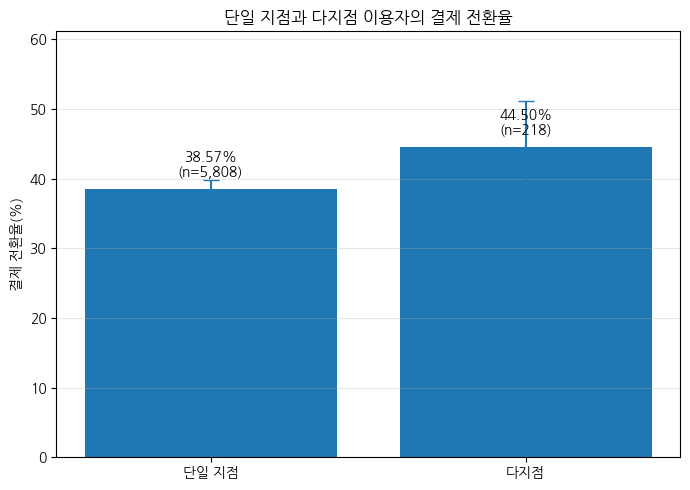

In [ ]:
# 결제 전환율 차트

conversion_plot = conversion_result.reset_index()

rates = conversion_plot["결제율"].to_numpy()

lower_errors = (
    rates
    - conversion_plot["95% CI 하한"].to_numpy()
)

upper_errors = (
    conversion_plot["95% CI 상한"].to_numpy()
    - rates
)

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    conversion_plot["site_group"],
    rates,
)

ax.errorbar(
    conversion_plot["site_group"],
    rates,
    yerr=[lower_errors, upper_errors],
    fmt="none",
    capsize=6,
)

for bar, rate, count in zip(
    bars,
    rates,
    conversion_plot["사용자수"],
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 1.4,
        f"{rate:.2f}%\n(n={count:,})",
        ha="center",
        va="bottom",
    )

ax.set_ylabel("결제 전환율(%)")
ax.set_title("단일 지점과 다지점 이용자의 결제 전환율")
ax.set_ylim(
    0,
    conversion_plot["95% CI 상한"].max() + 10,
)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 막대 높이는 다지점 이용자의 원본 결제율 우위를 보여주지만, 다지점 집단의 신뢰구간이 더 넓다.
> - 표본 규모가 218명으로 작기 때문에 점추정치보다 신뢰구간과 후속 보정 결과를 함께 확인해야 한다.


In [ ]:
# 이용 강도 비교

behavior_vars = {
    "visit_days": "방문일 수",
    "checkin_count": "체크인 횟수",
    "total_stay_hours": "총 체류시간(시간)",
}

behavior_results = []

for column, label in behavior_vars.items():
    single_values = (
        site_visitor_df.loc[
            site_visitor_df["site_group"].eq("단일 지점"),
            column,
        ]
        .dropna()
    )

    multi_values = (
        site_visitor_df.loc[
            site_visitor_df["site_group"].eq("다지점"),
            column,
        ]
        .dropna()
    )

    u_stat, p_value = mannwhitneyu(
        multi_values,
        single_values,
        alternative="two-sided",
    )

    effect_size = (
        2 * u_stat
        / (len(multi_values) * len(single_values))
        - 1
    )

    behavior_results.append(
        {
            "지표": label,
            "단일_인원": len(single_values),
            "단일_평균": single_values.mean(),
            "단일_중앙값": single_values.median(),
            "단일_Q1": single_values.quantile(0.25),
            "단일_Q3": single_values.quantile(0.75),
            "다지점_인원": len(multi_values),
            "다지점_평균": multi_values.mean(),
            "다지점_중앙값": multi_values.median(),
            "다지점_Q1": multi_values.quantile(0.25),
            "다지점_Q3": multi_values.quantile(0.75),
            "U통계량": u_stat,
            "p-value": p_value,
            "효과크기": effect_size,
        }
    )

behavior_comparison = pd.DataFrame(behavior_results)

behavior_comparison[
    behavior_comparison.select_dtypes(include="number").columns
] = (
    behavior_comparison[
        behavior_comparison.select_dtypes(include="number").columns
    ]
    .round(4)
)

display(behavior_comparison)

,지표,단일_인원,단일_평균,단일_중앙값,단일_Q1,단일_Q3,다지점_인원,다지점_평균,다지점_중앙값,다지점_Q1,다지점_Q3,U통계량,p-value,효과크기
0,방문일 수,5808,1.4809,1.00,1.0000,2.00,218,2.1193,2.0000,2.000,2.0000,964732.5,0.0,0.5239
1,체크인 횟수,5808,5.1930,4.00,2.0000,7.00,218,8.2798,7.0000,5.000,11.0000,916055.0,0.0,0.4470
2,총 체류시간(시간),5805,7.0036,5.43,2.7439,9.63,218,10.0352,9.3425,5.283,13.5643,832410.0,0.0,0.3156


> **💡 결과 해석**
>
> - 다지점 이용자는 단일 지점 이용자보다 방문일 수, 체크인 횟수, 총 체류시간이 모두 높았다.
> - 효과크기는 방문일 수가 0.524로 가장 컸고, 체크인 0.447, 체류시간 0.316 순이었다.
> - 다지점 집단은 단순히 여러 지점을 경험한 집단이 아니라 반복 방문과 이용량이 함께 높은 고관여 집단이었다.

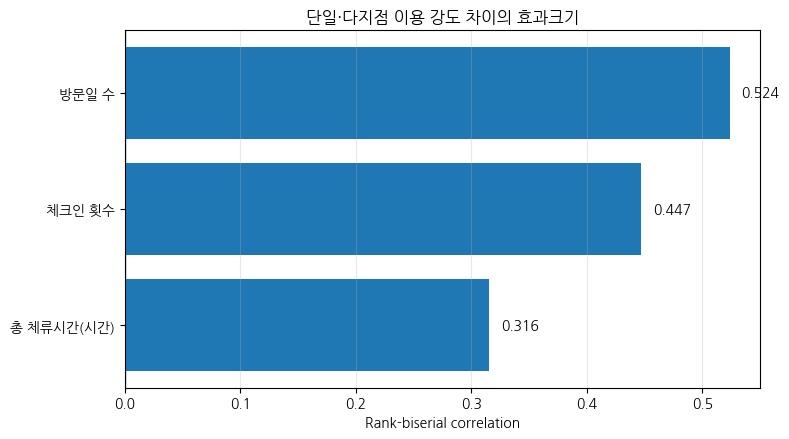

In [ ]:
# 이용 강도 효과크기 차트

effect_plot = (
    behavior_comparison[
        ["지표", "효과크기"]
    ]
    .sort_values("효과크기")
)

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.barh(
    effect_plot["지표"],
    effect_plot["효과크기"],
)

for bar, value in zip(
    bars,
    effect_plot["효과크기"],
):
    ax.text(
        value + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
    )

ax.axvline(0, linewidth=1)
ax.set_xlabel("Rank-biserial correlation")
ax.set_title("단일·다지점 이용 강도 차이의 효과크기")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 세 행동 변수 모두 다지점 이용자 쪽으로 차이가 나타났으며, 방문일 수의 효과크기가 가장 크게 보인다.
> - 따라서 다지점 원본 결제율 격차를 해석할 때 방문 지속성을 먼저 통제해야 한다.

#### 6-2-2-2. 방문일 수와 이용 강도 통제 분석

**🔹 분석 목적**

- 방문일 수가 같은 사용자끼리 단일 지점과 다지점 이용자의 결제율을 비교해 방문 지속성의 영향을 분리한다.
- Mantel-Haenszel 공통 오즈비로 방문일 수 층화 후 다지점 효과를 검정한다.
- 로지스틱 회귀에 방문일 수, 체크인 횟수, 총 체류시간, 가입 반기를 단계적으로 추가해 다지점 오즈비의 변화를 확인한다.
- 출입 기록이 완결된 표본과 방문일 수 내부 체류시간 사분위 분석으로 결과의 민감도를 점검한다.


In [ ]:
# 방문일 수별 전환율 비교

stratified_results = []
stratum_tables = []

visit_day_values = sorted(
    site_visitor_df["visit_days"]
    .dropna()
    .unique()
)

for visit_day in visit_day_values:
    temp_df = site_visitor_df[
        site_visitor_df["visit_days"].eq(visit_day)
    ].copy()

    single_df = temp_df[
        temp_df["site_group"].eq("단일 지점")
    ]

    multi_df = temp_df[
        temp_df["site_group"].eq("다지점")
    ]

    if len(single_df) == 0 or len(multi_df) == 0:
        continue

    single_n = len(single_df)
    multi_n = len(multi_df)
    single_pay = int(single_df["is_payment"].sum())
    multi_pay = int(multi_df["is_payment"].sum())

    contingency_table = np.array(
        [
            [multi_pay, multi_n - multi_pay],
            [single_pay, single_n - single_pay],
        ]
    )

    odds_ratio, p_value = fisher_exact(
        contingency_table,
        alternative="two-sided",
    )

    stratified_results.append(
        {
            "방문일 수": int(visit_day),
            "단일_사용자수": single_n,
            "단일_결제자수": single_pay,
            "단일_결제율": single_pay / single_n * 100,
            "다지점_사용자수": multi_n,
            "다지점_결제자수": multi_pay,
            "다지점_결제율": multi_pay / multi_n * 100,
            "결제율_차이(%p)": (
                multi_pay / multi_n
                - single_pay / single_n
            )
            * 100,
            "오즈비": odds_ratio,
            "Fisher_p-value": p_value,
        }
    )

    stratum_tables.append(contingency_table)

visit_day_conversion = pd.DataFrame(
    stratified_results
)

visit_day_conversion[
    [
        "단일_결제율",
        "다지점_결제율",
        "결제율_차이(%p)",
        "오즈비",
        "Fisher_p-value",
    ]
] = (
    visit_day_conversion[
        [
            "단일_결제율",
            "다지점_결제율",
            "결제율_차이(%p)",
            "오즈비",
            "Fisher_p-value",
        ]
    ]
    .round(4)
)

display(visit_day_conversion)

,방문일 수,단일_사용자수,단일_결제자수,단일_결제율,다지점_사용자수,다지점_결제자수,다지점_결제율,결제율_차이(%p),오즈비,Fisher_p-value
0,1,3372,1182,35.0534,19,6,31.5789,-3.4744,0.8551,0.8150
1,2,2079,895,43.0495,154,70,45.4545,2.4050,1.1024,0.5567
2,3,357,163,45.6583,45,21,46.6667,1.0084,1.0414,1.0000


> **💡 결과 해석**
>
> - 방문일 수가 같을 때 단일·다지점 결제율 차이는 1일 -3.47%p, 2일 +2.41%p, 3일 +1.01%p로 크게 줄었다.
> - 각 층의 Fisher 검정도 모두 유의하지 않아, 동일한 방문일 수 안에서는 다지점 우위가 일관되게 나타나지 않았다.

In [ ]:
# 층화 공통 오즈비 검정

stratified_table = StratifiedTable(
    np.stack(stratum_tables, axis=2),
    shift_zeros=True,
)

mh_test = stratified_table.test_null_odds()
mh_ci_lower, mh_ci_upper = (
    stratified_table.oddsratio_pooled_confint()
)

print(
    "Mantel-Haenszel 공통 오즈비:",
    round(stratified_table.oddsratio_pooled, 3),
)
print(
    "95% 신뢰구간:",
    f"{mh_ci_lower:.3f} ~ {mh_ci_upper:.3f}",
)
print(f"p-value: {mh_test.pvalue:.4f}")

Mantel-Haenszel 공통 오즈비: 1.067
95% 신뢰구간: 0.808 ~ 1.409
p-value: 0.6496


> **💡 결과 해석**
>
> - 방문일 수를 층화한 Mantel-Haenszel 공통 오즈비는 1.067이고 95% 신뢰구간은 0.808~1.409였다.
> - p-value 0.6496으로 방문일 수가 같다면 다지점 이용자의 결제 가능성이 더 높다고 보기 어렵다.


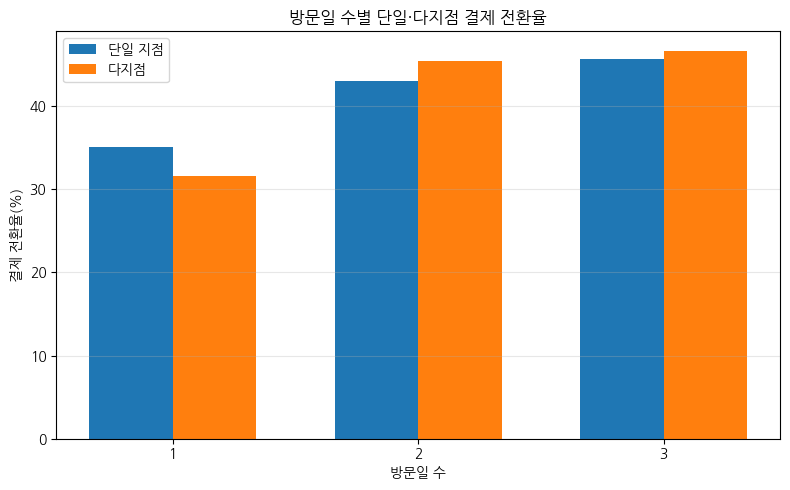

In [ ]:
# 방문일 수별 결제율 차트

x = np.arange(len(visit_day_conversion))
width = 0.34

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    x - width / 2,
    visit_day_conversion["단일_결제율"],
    width,
    label="단일 지점",
)

ax.bar(
    x + width / 2,
    visit_day_conversion["다지점_결제율"],
    width,
    label="다지점",
)

ax.set_xticks(x)
ax.set_xticklabels(
    visit_day_conversion["방문일 수"].astype(int)
)
ax.set_xlabel("방문일 수")
ax.set_ylabel("결제 전환율(%)")
ax.set_title("방문일 수별 단일·다지점 결제 전환율")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 방문일 수가 증가할수록 단일·다지점 모두 결제율이 상승하지만, 같은 방문일 수 내부의 두 집단 차이는 작다.
> - 결제 전환을 더 크게 구분하는 축은 지점 수보다 방문일 수로 보인다.


In [ ]:
# 회귀 분석 데이터 준비

reg_df = (
    site_visitor_df
    .dropna(
        subset=[
            "is_payment",
            "visit_days",
            "checkin_count",
            "total_stay_hours",
            "half_year",
        ]
    )
    .copy()
)

for column in [
    "is_payment",
    "visit_days",
    "checkin_count",
    "total_stay_hours",
]:
    reg_df[column] = (
        pd.to_numeric(
            reg_df[column],
            errors="coerce",
        )
        .astype(float)
    )

reg_df["multi_site_flag"] = (
    reg_df["site_group"]
    .eq("다지점")
    .astype(float)
)

reg_df["log_checkin_count"] = np.log1p(
    reg_df["checkin_count"]
)

reg_df["log_total_stay_hours"] = np.log1p(
    reg_df["total_stay_hours"]
)

for column in [
    "log_checkin_count",
    "log_total_stay_hours",
]:
    reg_df[f"z_{column}"] = (
        reg_df[column] - reg_df[column].mean()
    ) / reg_df[column].std()

In [ ]:
# 단계별 독립변수 생성

visit_day_dummies = pd.get_dummies(
    reg_df["visit_days"].astype(int),
    prefix="visit_days",
    drop_first=True,
    dtype=float,
)

half_year_dummies = pd.get_dummies(
    reg_df["half_year"].astype(str),
    prefix="half_year",
    drop_first=True,
    dtype=float,
)

X1 = reg_df[
    ["multi_site_flag"]
].copy()

X2 = pd.concat(
    [
        reg_df[["multi_site_flag"]],
        visit_day_dummies,
    ],
    axis=1,
)

X3 = pd.concat(
    [
        reg_df[
            [
                "multi_site_flag",
                "z_log_checkin_count",
                "z_log_total_stay_hours",
            ]
        ],
        visit_day_dummies,
    ],
    axis=1,
)

X4 = pd.concat(
    [
        reg_df[
            [
                "multi_site_flag",
                "z_log_checkin_count",
                "z_log_total_stay_hours",
            ]
        ],
        visit_day_dummies,
        half_year_dummies,
    ],
    axis=1,
)

model_inputs = {
    "모델1: 다지점만": X1,
    "모델2: 방문일 수 보정": X2,
    "모델3: 행동 강도 보정": X3,
    "모델4: 시기까지 보정": X4,
}

In [ ]:
# 단계별 로지스틱 회귀

y = reg_df["is_payment"].astype(float)

fitted_models = {}
multi_site_results = []

for model_name, X in model_inputs.items():
    X = sm.add_constant(
        X.astype(float),
        has_constant="add",
    )

    model = sm.GLM(
        y,
        X,
        family=sm.families.Binomial(),
    ).fit(
        cov_type="HC3"
    )

    fitted_models[model_name] = model

    coefficient = model.params["multi_site_flag"]
    ci_lower, ci_upper = (
        model.conf_int().loc["multi_site_flag"]
    )

    multi_site_results.append(
        {
            "모델": model_name,
            "표본수": int(model.nobs),
            "다지점_오즈비": np.exp(coefficient),
            "95%CI_하한": np.exp(ci_lower),
            "95%CI_상한": np.exp(ci_upper),
            "p-value": model.pvalues["multi_site_flag"],
            "AIC": model.aic,
        }
    )

multi_site_effect = pd.DataFrame(
    multi_site_results
)

multi_site_effect[
    [
        "다지점_오즈비",
        "95%CI_하한",
        "95%CI_상한",
        "p-value",
        "AIC",
    ]
] = (
    multi_site_effect[
        [
            "다지점_오즈비",
            "95%CI_하한",
            "95%CI_상한",
            "p-value",
            "AIC",
        ]
    ]
    .round(4)
)

display(multi_site_effect)

,모델,표본수,다지점_오즈비,95%CI_하한,95%CI_상한,p-value,AIC
0,모델1: 다지점만,6023,1.2758,0.9717,1.6751,0.0795,8045.8878
1,모델2: 방문일 수 보정,6023,1.0658,0.8076,1.4066,0.6525,8006.1103
2,모델3: 행동 강도 보정,6023,1.0385,0.7868,1.3708,0.7897,7924.2843
3,모델4: 시기까지 보정,6023,1.0655,0.8041,1.4120,0.6585,7860.3183


> **💡 결과 해석**
>
> - 다지점 오즈비는 원본 모델 1.276에서 방문일 수 보정 후 1.066, 행동 강도 보정 후 1.039로 1에 가까워졌다.
> - 가입 시기까지 보정한 최종 오즈비도 1.066, p-value 0.6585로 유의하지 않았다.
> - 원본 다지점 우위의 상당 부분이 반복 방문과 이용 강도 구성 차이로 설명된다.

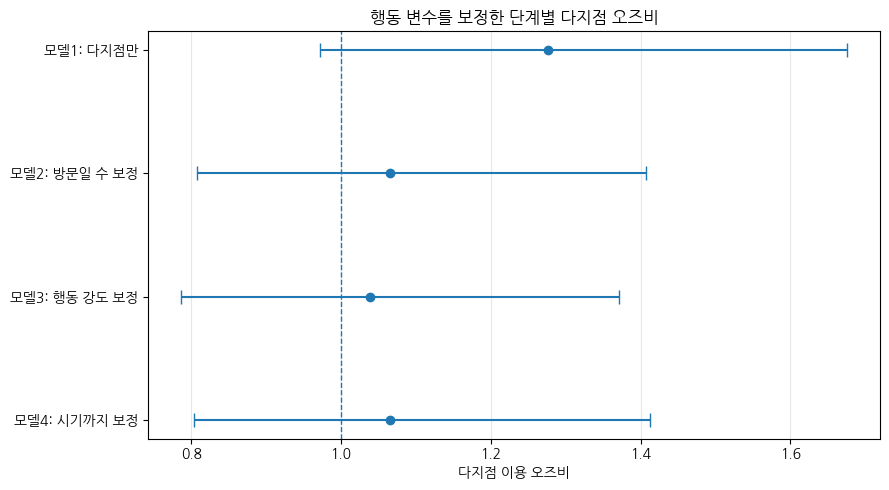

In [ ]:
# 단계별 다지점 오즈비 차트

forest_df = (
    multi_site_effect
    .iloc[::-1]
    .reset_index(drop=True)
)

y_positions = np.arange(len(forest_df))

lower_errors = (
    forest_df["다지점_오즈비"]
    - forest_df["95%CI_하한"]
)

upper_errors = (
    forest_df["95%CI_상한"]
    - forest_df["다지점_오즈비"]
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.errorbar(
    forest_df["다지점_오즈비"],
    y_positions,
    xerr=[lower_errors, upper_errors],
    fmt="o",
    capsize=5,
)

ax.axvline(1, linestyle="--", linewidth=1)

ax.set_yticks(y_positions)
ax.set_yticklabels(forest_df["모델"])
ax.set_xlabel("다지점 이용 오즈비")
ax.set_title("행동 변수를 보정한 단계별 다지점 오즈비")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 통제 변수를 추가할수록 다지점 오즈비가 기준선 1에 가까워지고 모든 신뢰구간이 1을 포함한다.
> - 다지점 이용 자체를 무료 체험 전환의 핵심 레버로 보기에는 근거가 약하다.

In [ ]:
# 최종 모델 행동 변수 확인

final_model = fitted_models[
    "모델4: 시기까지 보정"
]

final_coef = pd.DataFrame(
    {
        "변수": final_model.params.index,
        "계수": final_model.params.values,
        "p-value": final_model.pvalues.values,
    }
)

final_conf_int = final_model.conf_int()

final_coef["오즈비"] = np.exp(
    final_coef["계수"]
)

final_coef["95%CI_하한"] = np.exp(
    final_conf_int[0].values
)

final_coef["95%CI_상한"] = np.exp(
    final_conf_int[1].values
)

behavior_coef = final_coef[
    final_coef["변수"].isin(
        [
            "multi_site_flag",
            "z_log_checkin_count",
            "z_log_total_stay_hours",
            "visit_days_2",
            "visit_days_3",
        ]
    )
].copy()

behavior_coef["변수"] = (
    behavior_coef["변수"]
    .replace(
        {
            "multi_site_flag": "다지점 이용 여부",
            "z_log_checkin_count": "체크인 횟수",
            "z_log_total_stay_hours": "총 체류시간",
            "visit_days_2": "방문 2일 (기준: 1일)",
            "visit_days_3": "방문 3일 (기준: 1일)",
        }
    )
)

behavior_coef = behavior_coef[
    [
        "변수",
        "오즈비",
        "95%CI_하한",
        "95%CI_상한",
        "p-value",
    ]
]

behavior_coef[
    [
        "오즈비",
        "95%CI_하한",
        "95%CI_상한",
        "p-value",
    ]
] = (
    behavior_coef[
        [
            "오즈비",
            "95%CI_하한",
            "95%CI_상한",
            "p-value",
        ]
    ]
    .round(4)
)

display(behavior_coef)

,변수,오즈비,95%CI_하한,95%CI_상한,p-value
1,다지점 이용 여부,1.0655,0.8041,1.4120,0.6585
2,체크인 횟수,0.9718,0.8983,1.0513,0.4762
3,총 체류시간,0.7456,0.6879,0.8083,0.0000
4,방문 2일 (기준: 1일),2.0594,1.7890,2.3706,0.0000
5,방문 3일 (기준: 1일),2.8980,2.2489,3.7345,0.0000


> **💡 결과 해석**
>
> - 최종 모델에서 방문 2일의 오즈비는 2.059, 방문 3일은 2.898로 1일 방문보다 높았다.
> - 반면 다지점 여부와 체크인 횟수는 유의하지 않았고, 총 체류시간은 보정 후 음의 연관을 보였다.
> - 다른 행동을 함께 고려해도 여러 날짜에 걸친 방문이 가장 강하게 남는 신호였다.

In [ ]:
# 출입 기록 완결 표본 생성

checkout_series = pd.to_numeric(
    site_visitor_df.loc[
        reg_df.index,
        "checkout_count",
    ],
    errors="coerce",
).astype(float)

complete_reg_df = reg_df[
    reg_df["checkin_count"].eq(checkout_series)
].copy()

print(f"전체 회귀 표본: {len(reg_df):,}명")
print(f"출입 기록 일치 표본: {len(complete_reg_df):,}명")
print(
    "분석 유지 비율:",
    f"{len(complete_reg_df) / len(reg_df) * 100:.1f}%",
)

전체 회귀 표본: 6,023명
출입 기록 일치 표본: 4,264명
분석 유지 비율: 70.8%


> **✅ 확인 결과**
>
> - 체크인과 체크아웃 횟수가 일치하는 완결 표본은 4,264명으로 전체 회귀 표본의 70.8%였다.
> - 출입 기록 품질에 민감한 결과인지 확인하기 위해 이 표본에서 동일한 회귀를 반복한다.

In [ ]:
# 완결 표본 회귀 분석

complete_visit_dummies = pd.get_dummies(
    complete_reg_df["visit_days"].astype(int),
    prefix="visit_days",
    drop_first=True,
    dtype=float,
)

complete_half_dummies = pd.get_dummies(
    complete_reg_df["half_year"].astype(str),
    prefix="half_year",
    drop_first=True,
    dtype=float,
)

X_sensitivity = pd.concat(
    [
        complete_reg_df[
            [
                "multi_site_flag",
                "z_log_checkin_count",
                "z_log_total_stay_hours",
            ]
        ],
        complete_visit_dummies,
        complete_half_dummies,
    ],
    axis=1,
).astype(float)

X_sensitivity = sm.add_constant(
    X_sensitivity,
    has_constant="add",
)

sensitivity_model = sm.GLM(
    complete_reg_df["is_payment"].astype(float),
    X_sensitivity,
    family=sm.families.Binomial(),
).fit(
    cov_type="HC3"
)

sensitivity_results = []

for variable in [
    "multi_site_flag",
    "z_log_checkin_count",
    "z_log_total_stay_hours",
    "visit_days_2",
    "visit_days_3",
]:
    ci_lower, ci_upper = (
        sensitivity_model.conf_int().loc[variable]
    )

    sensitivity_results.append(
        {
            "변수": variable,
            "오즈비": np.exp(
                sensitivity_model.params[variable]
            ),
            "95%CI_하한": np.exp(ci_lower),
            "95%CI_상한": np.exp(ci_upper),
            "p-value": sensitivity_model.pvalues[variable],
        }
    )

sensitivity_result = pd.DataFrame(
    sensitivity_results
)

sensitivity_result["변수"] = (
    sensitivity_result["변수"]
    .replace(
        {
            "multi_site_flag": "다지점 이용 여부",
            "z_log_checkin_count": "체크인 횟수",
            "z_log_total_stay_hours": "총 체류시간",
            "visit_days_2": "방문 2일 (기준: 1일)",
            "visit_days_3": "방문 3일 (기준: 1일)",
        }
    )
)

sensitivity_result[
    [
        "오즈비",
        "95%CI_하한",
        "95%CI_상한",
        "p-value",
    ]
] = (
    sensitivity_result[
        [
            "오즈비",
            "95%CI_하한",
            "95%CI_상한",
            "p-value",
        ]
    ]
    .round(4)
)

display(sensitivity_result)

,변수,오즈비,95%CI_하한,95%CI_상한,p-value
0,다지점 이용 여부,1.1826,0.8252,1.6949,0.3610
1,체크인 횟수,1.0233,0.9270,1.1296,0.6484
2,총 체류시간,0.7190,0.6509,0.7942,0.0000
3,방문 2일 (기준: 1일),2.1679,1.8367,2.5588,0.0000
4,방문 3일 (기준: 1일),2.4926,1.8016,3.4488,0.0000


> **💡 결과 해석**
>
> - 출입 기록 완결 표본에서도 다지점 오즈비는 1.183, p-value 0.3610으로 유의하지 않았다.
> - 방문 2일과 3일의 오즈비는 각각 2.168, 2.493으로 유지되어 반복 방문 신호가 기록 품질 조건에서도 일관되었다.

In [ ]:
# 체류시간 사분위 생성

stay_pattern_df = complete_reg_df.copy()

stay_pattern_df["avg_stay_hours_per_day"] = (
    stay_pattern_df["total_stay_hours"]
    / stay_pattern_df["visit_days"]
)

stay_pattern_df["stay_quartile"] = (
    stay_pattern_df
    .groupby("visit_days")[
        "avg_stay_hours_per_day"
    ]
    .transform(
        lambda values: pd.qcut(
            values.rank(method="first"),
            q=4,
            labels=[
                "Q1 짧음",
                "Q2",
                "Q3",
                "Q4 김",
            ],
        )
    )
)

stay_quartile_summary = (
    stay_pattern_df
    .groupby(
        [
            "visit_days",
            "stay_quartile",
        ],
        observed=True,
    )
    .agg(
        사용자수=("user_id", "nunique"),
        결제자수=("is_payment", "sum"),
        결제율=("is_payment", "mean"),
        평균_일체류시간=(
            "avg_stay_hours_per_day",
            "mean",
        ),
        중앙_일체류시간=(
            "avg_stay_hours_per_day",
            "median",
        ),
    )
    .reset_index()
)

stay_quartile_summary["결제율"] = (
    stay_quartile_summary["결제율"] * 100
).round(2)

stay_quartile_summary[
    [
        "평균_일체류시간",
        "중앙_일체류시간",
    ]
] = (
    stay_quartile_summary[
        [
            "평균_일체류시간",
            "중앙_일체류시간",
        ]
    ]
    .round(2)
)

display(stay_quartile_summary)

,visit_days,stay_quartile,사용자수,결제자수,결제율,평균_일체류시간,중앙_일체류시간
0,1.0,Q1 짧음,658,263.0,39.97,0.85,0.90
1,1.0,Q2,658,258.0,39.21,2.42,2.41
2,1.0,Q3,658,239.0,36.32,4.13,4.08
3,1.0,Q4 김,658,180.0,27.36,7.33,6.91
4,2.0,Q1 짧음,354,212.0,59.89,1.63,1.69
5,2.0,Q2,353,166.0,47.03,3.42,3.45
6,2.0,Q3,353,143.0,40.51,5.11,5.11
7,2.0,Q4 김,354,126.0,35.59,7.87,7.42
8,3.0,Q1 짧음,55,32.0,58.18,2.18,2.42
9,3.0,Q2,54,23.0,42.59,4.16,4.12


> **💡 결과 해석**
>
> - 방문일 수를 동일하게 고정해도 일평균 체류시간이 짧은 Q1의 결제율이 긴 Q4보다 높았다.
> - 예를 들어 2일 방문자는 Q1 59.89%, Q4 35.59%로 24.30%p 차이가 났다.
> - 이는 총 체류시간을 늘리는 전략보다 재방문을 만들고 이용 마찰을 줄이는 전략이 우선일 수 있음을 시사한다.

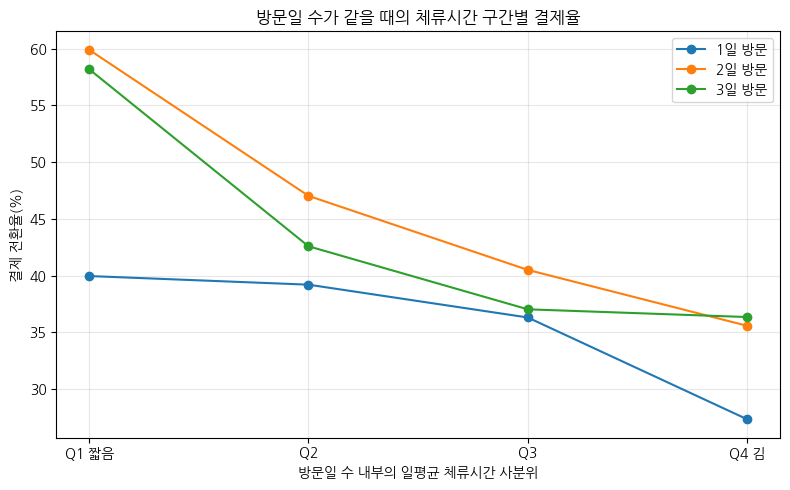

In [ ]:
# 체류시간 패턴 차트

quartile_order = [
    "Q1 짧음",
    "Q2",
    "Q3",
    "Q4 김",
]

fig, ax = plt.subplots(figsize=(8, 5))

for visit_day in sorted(
    stay_quartile_summary["visit_days"].unique()
):
    temp_df = (
        stay_quartile_summary[
            stay_quartile_summary["visit_days"].eq(visit_day)
        ]
        .set_index("stay_quartile")
        .reindex(quartile_order)
    )

    ax.plot(
        quartile_order,
        temp_df["결제율"],
        marker="o",
        label=f"{int(visit_day)}일 방문",
    )

ax.set_xlabel("방문일 수 내부의 일평균 체류시간 사분위")
ax.set_ylabel("결제 전환율(%)")
ax.set_title("방문일 수가 같을 때의 체류시간 구간별 결제율")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 1일·2일·3일 방문 집단 모두 체류시간 사분위가 높아질수록 결제율이 낮아지는 유사한 패턴을 보인다.
> - 체류시간과 결제의 관계가 단순한 양의 선형 구조가 아니라는 점을 시각적으로 확인했다.

#### 6-2-2-3. 기간·반복 방문·비선형 효과 검증

**🔹 분석 목적**

- 반기별 단일·다지점 결제율 차이를 비교해 특정 기간의 영향이 전체 결과를 주도하는지 확인한다.
- 2023년 하반기의 원본 격차를 행동 변수로 보정하고, 기간과 다지점 이용의 상호작용을 검정한다.
- `이용 지점 범위 x 반복 방문 여부`로 행동 세그먼트를 구성해 다지점보다 반복 방문이 더 중요한지 확인한다.
- 체크인 횟수와 체류시간의 비선형성을 B-spline으로 보정해 선형 가정에 따른 왜곡 가능성을 점검한다.

In [ ]:
# 반기별 전환율 비교 및 다중검정 보정

period_order = [
    "2021년 상반기",
    "2021년 하반기",
    "2022년 상반기",
    "2022년 하반기",
    "2023년 상반기",
    "2023년 하반기",
]

period_results = []

for period in period_order:
    period_df = site_visitor_df[
        site_visitor_df["half_year"].eq(period)
    ].copy()

    single_df = period_df[
        period_df["site_group"].eq("단일 지점")
    ]

    multi_df = period_df[
        period_df["site_group"].eq("다지점")
    ]

    single_n = len(single_df)
    multi_n = len(multi_df)
    single_pay = int(single_df["is_payment"].sum())
    multi_pay = int(multi_df["is_payment"].sum())

    single_lower, single_upper = proportion_confint(
        count=single_pay,
        nobs=single_n,
        alpha=0.05,
        method="wilson",
    )

    multi_lower, multi_upper = proportion_confint(
        count=multi_pay,
        nobs=multi_n,
        alpha=0.05,
        method="wilson",
    )

    contingency_table = np.array(
        [
            [multi_pay, multi_n - multi_pay],
            [single_pay, single_n - single_pay],
        ]
    )

    odds_ratio, p_value = fisher_exact(
        contingency_table,
        alternative="two-sided",
    )

    period_results.append(
        {
            "기간": period,
            "단일_사용자수": single_n,
            "단일_결제자수": single_pay,
            "단일_결제율": single_pay / single_n * 100,
            "단일_CI하한": single_lower * 100,
            "단일_CI상한": single_upper * 100,
            "다지점_사용자수": multi_n,
            "다지점_결제자수": multi_pay,
            "다지점_결제율": multi_pay / multi_n * 100,
            "다지점_CI하한": multi_lower * 100,
            "다지점_CI상한": multi_upper * 100,
            "결제율_차이(%p)": (
                multi_pay / multi_n
                - single_pay / single_n
            )
            * 100,
            "오즈비": odds_ratio,
            "Fisher_p-value": p_value,
        }
    )

period_conversion = pd.DataFrame(period_results)

# 6개 반기를 각각 검정했으므로 Holm 방식으로 다중비교를 보정한다.
period_conversion["Holm_보정_p-value"] = multipletests(
    period_conversion["Fisher_p-value"],
    method="holm",
)[1]

period_conversion["Holm_보정_유의여부"] = (
    period_conversion["Holm_보정_p-value"] < 0.05
)

numeric_columns = period_conversion.select_dtypes(
    include="number"
).columns

period_conversion[numeric_columns] = (
    period_conversion[numeric_columns].round(4)
)

display(period_conversion)

,기간,단일_사용자수,단일_결제자수,단일_결제율,단일_CI하한,단일_CI상한,다지점_사용자수,다지점_결제자수,다지점_결제율,다지점_CI하한,다지점_CI상한,결제율_차이(%p),오즈비,Fisher_p-value,Holm_보정_p-value,Holm_보정_유의여부
0,2021년 상반기,312,158,50.6410,45.1195,56.1470,18,9,50.0000,29.0310,70.9690,-0.6410,0.9747,1.0000,1.0000,False
1,2021년 하반기,1265,514,40.6324,37.9582,43.3634,40,15,37.5000,24.2230,52.9676,-3.1324,0.8767,0.7458,1.0000,False
2,2022년 상반기,1041,417,40.0576,37.1228,43.0656,38,20,52.6316,37.2590,67.5210,12.5739,1.6627,0.1318,0.6591,False
3,2022년 하반기,1024,426,41.6016,38.6195,44.6464,30,15,50.0000,33.1541,66.8459,8.3984,1.4038,0.3562,1.0000,False
4,2023년 상반기,990,385,38.8889,35.9007,41.9630,27,9,33.3333,18.6433,52.1752,-5.5556,0.7857,0.6899,1.0000,False
5,2023년 하반기,1176,340,28.9116,26.3925,31.5680,65,29,44.6154,33.1695,56.6622,15.7038,1.9807,0.0114,0.0684,False


> **💡 결과 해석**
>
> - 2023년 하반기에는 다지점 결제율이 단일 지점보다 15.70%p 높았고 개별 Fisher 검정 p-value는 0.0114였다.
> - 그러나 6개 기간의 다중검정을 Holm 방식으로 보정하면 p-value는 0.0684로 5% 기준에서 유의하지 않았다.
> - 특정 기간의 큰 격차가 전체 다지점 효과로 과대 해석되지 않도록 행동 변수 보정과 상호작용 검정을 추가한다.

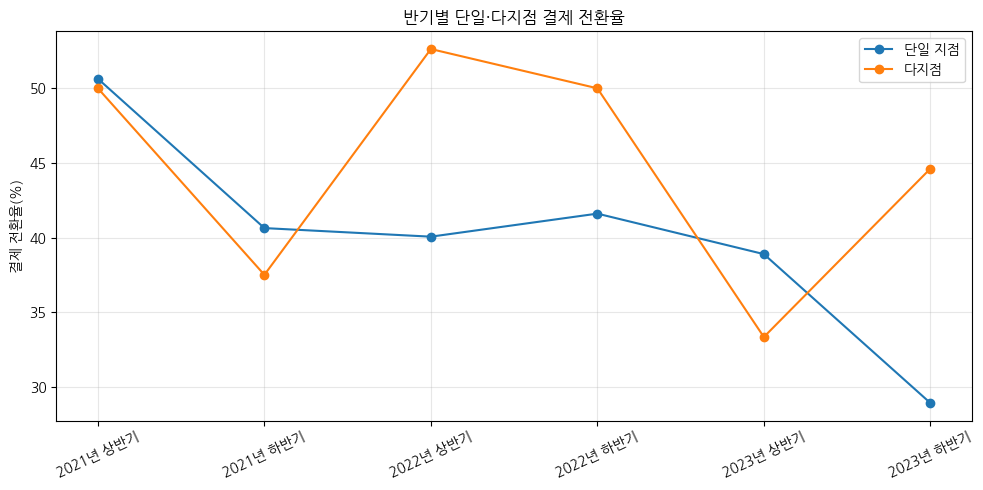

In [ ]:
# 반기별 전환율 차트

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    period_conversion["기간"],
    period_conversion["단일_결제율"],
    marker="o",
    label="단일 지점",
)

ax.plot(
    period_conversion["기간"],
    period_conversion["다지점_결제율"],
    marker="o",
    label="다지점",
)

ax.set_ylabel("결제 전환율(%)")
ax.set_title("반기별 단일·다지점 결제 전환율")
ax.tick_params(axis="x", rotation=25)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 반기별 결제율은 전반적으로 변동하며, 특히 2023년 하반기 단일 지점 결제율 하락과 다지점 격차 확대가 눈에 띈다.
> - 기간별 다지점 표본이 작아 선의 높이만으로 구조적 효과를 단정하지 않는다.

In [ ]:
# 2023년 하반기 보정 모델

h2_2023_df = reg_df[
    reg_df["half_year"].eq("2023년 하반기")
].copy()

h2_visit_dummies = pd.get_dummies(
    h2_2023_df["visit_days"].astype(int),
    prefix="visit_days",
    drop_first=True,
    dtype=float,
)

h2_model_inputs = {
    "모델1: 다지점만": h2_2023_df[
        ["multi_site_flag"]
    ],
    "모델2: 방문일 수 보정": pd.concat(
        [
            h2_2023_df[["multi_site_flag"]],
            h2_visit_dummies,
        ],
        axis=1,
    ),
    "모델3: 행동 강도 보정": pd.concat(
        [
            h2_2023_df[
                [
                    "multi_site_flag",
                    "z_log_checkin_count",
                    "z_log_total_stay_hours",
                ]
            ],
            h2_visit_dummies,
        ],
        axis=1,
    ),
}

h2_results = []

for model_name, X in h2_model_inputs.items():
    X = sm.add_constant(
        X.astype(float),
        has_constant="add",
    )

    model = sm.GLM(
        h2_2023_df["is_payment"].astype(float),
        X,
        family=sm.families.Binomial(),
    ).fit(
        cov_type="HC3"
    )

    ci_lower, ci_upper = (
        model.conf_int().loc["multi_site_flag"]
    )

    h2_results.append(
        {
            "모델": model_name,
            "표본수": int(model.nobs),
            "다지점_오즈비": np.exp(
                model.params["multi_site_flag"]
            ),
            "95%CI_하한": np.exp(ci_lower),
            "95%CI_상한": np.exp(ci_upper),
            "p-value": model.pvalues["multi_site_flag"],
            "AIC": model.aic,
        }
    )

h2_adjusted_result = pd.DataFrame(
    h2_results
)

h2_adjusted_result[
    [
        "다지점_오즈비",
        "95%CI_하한",
        "95%CI_상한",
        "p-value",
        "AIC",
    ]
] = (
    h2_adjusted_result[
        [
            "다지점_오즈비",
            "95%CI_하한",
            "95%CI_상한",
            "p-value",
            "AIC",
        ]
    ]
    .round(4)
)

display(h2_adjusted_result)

,모델,표본수,다지점_오즈비,95%CI_하한,95%CI_상한,p-value,AIC
0,모델1: 다지점만,1240,1.9783,1.1939,3.2782,0.0081,1507.0649
1,모델2: 방문일 수 보정,1240,1.6754,0.9957,2.8189,0.0519,1501.4477
2,모델3: 행동 강도 보정,1240,1.4596,0.8617,2.4725,0.1596,1473.0558


> **💡 결과 해석**
>
> - 2023년 하반기 다지점 오즈비는 원본 1.978에서 방문일 수 보정 후 1.675, 행동 강도 보정 후 1.460으로 감소했다.
> - 최종 p-value는 0.1596으로 유의하지 않아, 해당 기간의 원본 격차 역시 이용행태 구성 차이의 영향을 받았다.

In [ ]:
# 기간 상호작용 검정

interaction_df = reg_df.copy()

interaction_df["is_2023_h2"] = (
    interaction_df["half_year"]
    .eq("2023년 하반기")
    .astype(float)
)

interaction_df["multi_x_2023_h2"] = (
    interaction_df["multi_site_flag"]
    * interaction_df["is_2023_h2"]
)

interaction_visit_dummies = pd.get_dummies(
    interaction_df["visit_days"].astype(int),
    prefix="visit_days",
    drop_first=True,
    dtype=float,
)

interaction_period_dummies = pd.get_dummies(
    interaction_df["half_year"].astype(str),
    prefix="half_year",
    drop_first=True,
    dtype=float,
)

X_interaction = pd.concat(
    [
        interaction_df[
            [
                "multi_site_flag",
                "multi_x_2023_h2",
                "z_log_checkin_count",
                "z_log_total_stay_hours",
            ]
        ],
        interaction_visit_dummies,
        interaction_period_dummies,
    ],
    axis=1,
).astype(float)

X_interaction = sm.add_constant(
    X_interaction,
    has_constant="add",
)

interaction_model = sm.GLM(
    interaction_df["is_payment"].astype(float),
    X_interaction,
    family=sm.families.Binomial(),
).fit(
    cov_type="HC3"
)

interaction_results = []

for variable in [
    "multi_site_flag",
    "multi_x_2023_h2",
]:
    ci_lower, ci_upper = (
        interaction_model.conf_int().loc[variable]
    )

    interaction_results.append(
        {
            "변수": variable,
            "오즈비": np.exp(
                interaction_model.params[variable]
            ),
            "95%CI_하한": np.exp(ci_lower),
            "95%CI_상한": np.exp(ci_upper),
            "p-value": interaction_model.pvalues[variable],
        }
    )

interaction_result = pd.DataFrame(
    interaction_results
)

interaction_result["변수"] = (
    interaction_result["변수"]
    .replace(
        {
            "multi_site_flag": "다지점 이용 기본 효과",
            "multi_x_2023_h2": (
                "2023년 하반기 × 다지점 상호작용"
            ),
        }
    )
)

interaction_result[
    [
        "오즈비",
        "95%CI_하한",
        "95%CI_상한",
        "p-value",
    ]
] = (
    interaction_result[
        [
            "오즈비",
            "95%CI_하한",
            "95%CI_상한",
            "p-value",
        ]
    ]
    .round(4)
)

display(interaction_result)

combined_or = np.exp(
    interaction_model.params["multi_site_flag"]
    + interaction_model.params["multi_x_2023_h2"]
)

print(
    "2023년 하반기 보정 다지점 결합 오즈비:",
    round(combined_or, 3),
)

,변수,오즈비,95%CI_하한,95%CI_상한,p-value
0,다지점 이용 기본 효과,0.9365,0.6730,1.3030,0.6968
1,2023년 하반기 × 다지점 상호작용,1.5665,0.8621,2.8463,0.1407


2023년 하반기 보정 다지점 결합 오즈비: 1.467


> **💡 결과 해석**
>
> - 2023년 하반기와 다지점 이용의 상호작용 오즈비는 1.567이지만 p-value 0.1407이고 신뢰구간이 넓다.
> - 특정 기간에만 다지점 효과가 달라졌다고 결론 내릴 근거는 충분하지 않다.


In [ ]:
# 행동 세그먼트 생성

segment_df = site_visitor_df.copy()

segment_df["repeat_visit_group"] = np.where(
    segment_df["visit_days"].ge(2),
    "2일 이상 반복 방문",
    "1일 방문",
)

segment_df["behavior_segment"] = (
    segment_df["site_group"]
    + " · "
    + segment_df["repeat_visit_group"]
)

segment_order = [
    "단일 지점 · 1일 방문",
    "다지점 · 1일 방문",
    "단일 지점 · 2일 이상 반복 방문",
    "다지점 · 2일 이상 반복 방문",
]

segment_summary = (
    segment_df
    .groupby("behavior_segment")
    .agg(
        사용자수=("user_id", "nunique"),
        결제자수=("is_payment", "sum"),
        결제율=("is_payment", "mean"),
        평균_체크인수=("checkin_count", "mean"),
        평균_총체류시간=("total_stay_hours", "mean"),
    )
    .reindex(segment_order)
    .reset_index()
)

segment_summary["방문자_비중"] = (
    segment_summary["사용자수"]
    / len(segment_df)
)

segment_ci = []

for _, row in segment_summary.iterrows():
    lower, upper = proportion_confint(
        count=int(row["결제자수"]),
        nobs=int(row["사용자수"]),
        alpha=0.05,
        method="wilson",
    )
    segment_ci.append((lower, upper))

segment_summary["95%CI_하한"] = [
    value[0] for value in segment_ci
]

segment_summary["95%CI_상한"] = [
    value[1] for value in segment_ci
]

for column in [
    "결제율",
    "방문자_비중",
    "95%CI_하한",
    "95%CI_상한",
]:
    segment_summary[column] = (
        segment_summary[column] * 100
    ).round(2)

segment_summary[
    [
        "평균_체크인수",
        "평균_총체류시간",
    ]
] = (
    segment_summary[
        [
            "평균_체크인수",
            "평균_총체류시간",
        ]
    ]
    .round(2)
)

segment_summary = segment_summary.rename(
    columns={
        "behavior_segment": "행동 세그먼트",
        "결제율": "결제율(%)",
        "방문자_비중": "방문자 비중(%)",
        "평균_체크인수": "평균 체크인 수",
        "평균_총체류시간": "평균 총 체류시간",
    }
)

display(segment_summary)

,행동 세그먼트,사용자수,결제자수,결제율(%),평균 체크인 수,평균 총 체류시간,방문자 비중(%),95%CI_하한,95%CI_상한
0,단일 지점 · 1일 방문,3372,1182,35.05,3.15,4.12,55.96,33.46,36.68
1,다지점 · 1일 방문,19,6,31.58,4.32,3.47,0.32,15.36,53.99
2,단일 지점 · 2일 이상 반복 방문,2436,1058,43.43,8.02,10.99,40.42,41.48,45.41
3,다지점 · 2일 이상 반복 방문,199,91,45.73,8.66,10.66,3.30,38.95,52.67


> **💡 결과 해석**
>
> - 단일 지점 1일 방문자의 결제율은 35.05%였지만 동일 지점에 2일 이상 반복 방문하면 43.43%로 8.38%p 높아졌다.
> - 반복 방문자 안에서 단일 지점 43.43%와 다지점 45.73%의 차이는 2.30%p에 불과했다.
> - 다지점 1일 방문자는 19명뿐이므로 31.58%라는 수치를 일반화하기 어렵다.


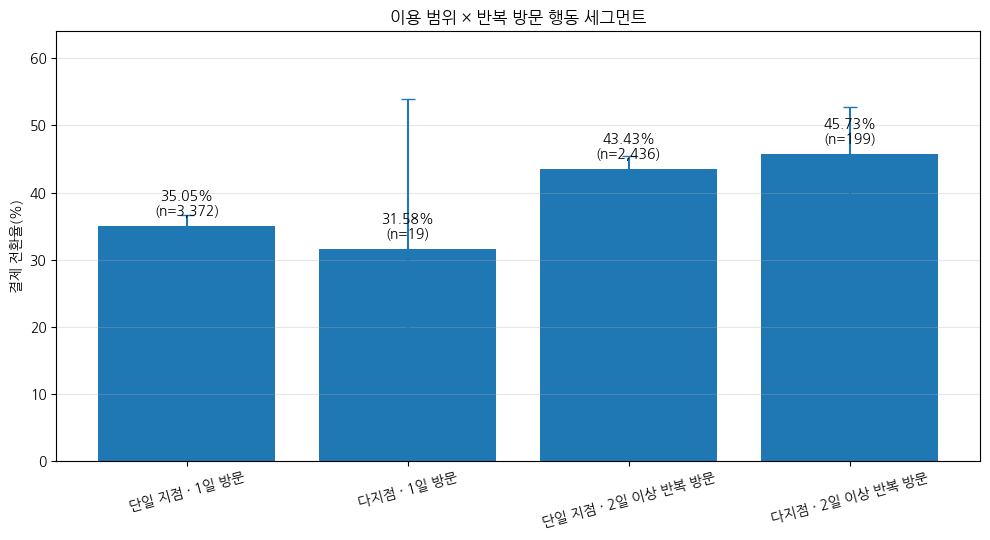

In [ ]:
# 행동 세그먼트 차트

segment_plot = segment_summary.copy()

rates = segment_plot["결제율(%)"].to_numpy()

lower_errors = (
    rates
    - segment_plot["95%CI_하한"].to_numpy()
)

upper_errors = (
    segment_plot["95%CI_상한"].to_numpy()
    - rates
)

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(
    segment_plot["행동 세그먼트"],
    rates,
)

ax.errorbar(
    segment_plot["행동 세그먼트"],
    rates,
    yerr=[lower_errors, upper_errors],
    fmt="none",
    capsize=5,
)

for bar, rate, count in zip(
    bars,
    rates,
    segment_plot["사용자수"],
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 1.2,
        f"{rate:.2f}%\n(n={count:,})",
        ha="center",
        va="bottom",
    )

ax.set_ylabel("결제 전환율(%)")
ax.set_title("이용 범위 × 반복 방문 행동 세그먼트")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.3)
ax.set_ylim(
    0,
    segment_plot["95%CI_상한"].max() + 10,
)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 막대 차이는 단일·다지점 구분보다 1일 방문과 2일 이상 반복 방문 구분에서 더 크게 나타난다.
> - 동일 지점만 이용해도 다시 방문하면 결제율이 상승한다는 점이 핵심이다.


In [ ]:
# 반복 방문 상호작용 검정

segment_model_df = (
    segment_df
    .dropna(
        subset=[
            "is_payment",
            "visit_days",
            "half_year",
        ]
    )
    .copy()
)

segment_model_df["is_payment"] = (
    pd.to_numeric(
        segment_model_df["is_payment"],
        errors="coerce",
    )
    .astype(float)
)

segment_model_df["multi_site_flag"] = (
    segment_model_df["site_group"]
    .eq("다지점")
    .astype(float)
)

segment_model_df["repeat_visit_flag"] = (
    segment_model_df["visit_days"]
    .ge(2)
    .astype(float)
)

segment_formula = (
    "is_payment ~ "
    "multi_site_flag * repeat_visit_flag "
    "+ C(half_year)"
)

segment_interaction_model = smf.glm(
    formula=segment_formula,
    data=segment_model_df,
    family=sm.families.Binomial(),
).fit(
    cov_type="HC3"
)

segment_variables = {
    "multi_site_flag": "다지점 이용 효과",
    "repeat_visit_flag": "2일 이상 반복 방문 효과",
    "multi_site_flag:repeat_visit_flag": (
        "다지점 × 반복 방문 상호작용"
    ),
}

segment_effect_results = []

for variable, label in segment_variables.items():
    ci_lower, ci_upper = (
        segment_interaction_model.conf_int().loc[variable]
    )

    segment_effect_results.append(
        {
            "변수": label,
            "오즈비": np.exp(
                segment_interaction_model.params[variable]
            ),
            "95%CI_하한": np.exp(ci_lower),
            "95%CI_상한": np.exp(ci_upper),
            "p-value": (
                segment_interaction_model.pvalues[variable]
            ),
        }
    )

segment_effect_result = pd.DataFrame(
    segment_effect_results
)

segment_effect_result[
    [
        "오즈비",
        "95%CI_하한",
        "95%CI_상한",
        "p-value",
    ]
] = (
    segment_effect_result[
        [
            "오즈비",
            "95%CI_하한",
            "95%CI_상한",
            "p-value",
        ]
    ]
    .round(4)
)

display(segment_effect_result)

repeat_multi_or = np.exp(
    segment_interaction_model.params["multi_site_flag"]
    + segment_interaction_model.params[
        "multi_site_flag:repeat_visit_flag"
    ]
)

print(
    "반복 방문자 내 다지점 결합 오즈비:",
    round(repeat_multi_or, 3),
)

,변수,오즈비,95%CI_하한,95%CI_상한,p-value
0,다지점 이용 효과,0.8038,0.3027,2.1344,0.6611
1,2일 이상 반복 방문 효과,1.4604,1.3112,1.6266,0.0000
2,다지점 × 반복 방문 상호작용,1.4133,0.5091,3.9229,0.5067


반복 방문자 내 다지점 결합 오즈비: 1.136


> **💡 결과 해석**
>
> - 반기를 통제한 모델에서 반복 방문 오즈비는 1.460으로 유의했지만, 다지점 효과와 다지점×반복 방문 상호작용은 유의하지 않았다.
> - 반복 방문자 내부의 다지점 결합 오즈비도 1.136에 그쳐, 추가적인 다지점 효과는 제한적이었다.


In [ ]:
# 스플라인 로지스틱 회귀 적합

spline_formula = (
    "is_payment ~ multi_site_flag "
    "+ C(visit_days) "
    "+ bs(log_checkin_count, df=4, degree=3) "
    "+ bs(log_total_stay_hours, df=4, degree=3) "
    "+ C(half_year)"
)

spline_model = smf.glm(
    formula=spline_formula,
    data=reg_df,
    family=sm.families.Binomial(),
).fit(
    cov_type="HC3"
)

spline_ci_lower, spline_ci_upper = (
    spline_model.conf_int().loc["multi_site_flag"]
)

spline_result = pd.DataFrame(
    {
        "모델": [
            "선형 보정 로지스틱 회귀",
            "비선형 B-spline 로지스틱 회귀",
        ],
        "다지점_오즈비": [
            multi_site_effect.loc[
                multi_site_effect["모델"].eq(
                    "모델4: 시기까지 보정"
                ),
                "다지점_오즈비",
            ].iloc[0],
            np.exp(
                spline_model.params["multi_site_flag"]
            ),
        ],
        "95%CI_하한": [
            multi_site_effect.loc[
                multi_site_effect["모델"].eq(
                    "모델4: 시기까지 보정"
                ),
                "95%CI_하한",
            ].iloc[0],
            np.exp(spline_ci_lower),
        ],
        "95%CI_상한": [
            multi_site_effect.loc[
                multi_site_effect["모델"].eq(
                    "모델4: 시기까지 보정"
                ),
                "95%CI_상한",
            ].iloc[0],
            np.exp(spline_ci_upper),
        ],
        "p-value": [
            multi_site_effect.loc[
                multi_site_effect["모델"].eq(
                    "모델4: 시기까지 보정"
                ),
                "p-value",
            ].iloc[0],
            spline_model.pvalues["multi_site_flag"],
        ],
        "AIC": [
            final_model.aic,
            spline_model.aic,
        ],
    }
)

spline_result[
    [
        "다지점_오즈비",
        "95%CI_하한",
        "95%CI_상한",
        "p-value",
        "AIC",
    ]
] = (
    spline_result[
        [
            "다지점_오즈비",
            "95%CI_하한",
            "95%CI_상한",
            "p-value",
            "AIC",
        ]
    ]
    .round(4)
)

display(spline_result)

,모델,다지점_오즈비,95%CI_하한,95%CI_상한,p-value,AIC
0,선형 보정 로지스틱 회귀,1.0655,0.8041,1.4120,0.6585,7860.3183
1,비선형 B-spline 로지스틱 회귀,1.0485,0.7883,1.3947,0.7449,7828.5652


> **💡 결과 해석**
>
> - 체크인과 체류시간의 비선형 관계를 허용해도 다지점 오즈비는 1.049, p-value 0.7449로 유의하지 않았다.
> - 선형 가정 때문에 다지점 효과가 사라진 것이 아니라는 점을 확인했다.


In [ ]:
# 비선형 예측 데이터 생성

stay_grid = np.linspace(
    max(
        0.1,
        reg_df["total_stay_hours"].quantile(0.01),
    ),
    reg_df["total_stay_hours"].quantile(0.95),
    100,
)

prediction_rows = []

reference_half_year = (
    reg_df["half_year"]
    .value_counts()
    .idxmax()
)

median_checkin = (
    reg_df["checkin_count"].median()
)

for visit_day in [1, 2, 3]:
    prediction_df = pd.DataFrame(
        {
            "multi_site_flag": 0.0,
            "visit_days": float(visit_day),
            "log_checkin_count": np.log1p(
                median_checkin
            ),
            "log_total_stay_hours": np.log1p(
                stay_grid
            ),
            "half_year": reference_half_year,
        }
    )

    prediction = spline_model.get_prediction(
        prediction_df
    ).summary_frame()

    prediction_rows.append(
        pd.DataFrame(
            {
                "총 체류시간(시간)": stay_grid,
                "방문일 수": f"{visit_day}일 방문",
                "예측 결제확률": prediction["mean"] * 100,
                "95%CI_하한": prediction["mean_ci_lower"] * 100,
                "95%CI_상한": prediction["mean_ci_upper"] * 100,
            }
        )
    )

spline_prediction = pd.concat(
    prediction_rows,
    ignore_index=True,
)

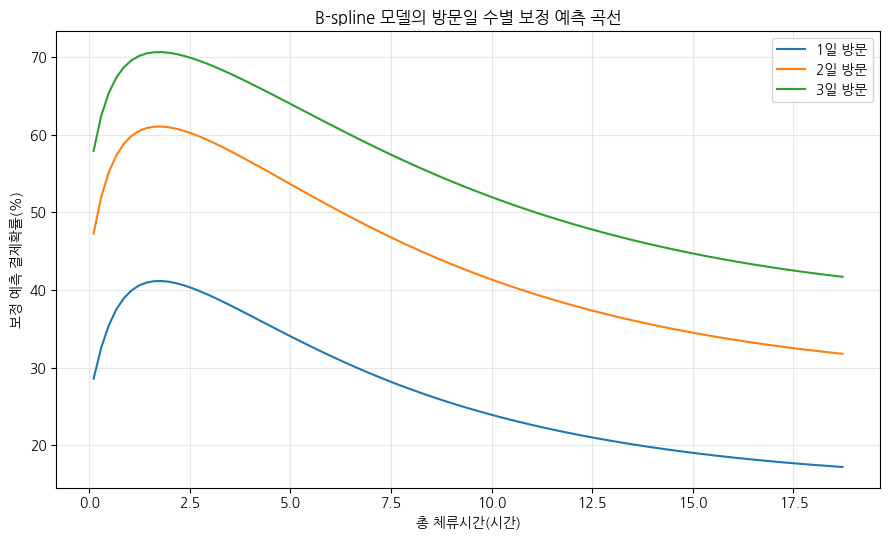

In [ ]:
# 비선형 예측 곡선 차트

fig, ax = plt.subplots(figsize=(9, 5.5))

for visit_group in [
    "1일 방문",
    "2일 방문",
    "3일 방문",
]:
    temp_df = spline_prediction[
        spline_prediction["방문일 수"].eq(visit_group)
    ]

    ax.plot(
        temp_df["총 체류시간(시간)"],
        temp_df["예측 결제확률"],
        label=visit_group,
    )

ax.set_xlabel("총 체류시간(시간)")
ax.set_ylabel("보정 예측 결제확률(%)")
ax.set_title("B-spline 모델의 방문일 수별 보정 예측 곡선")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 비선형 보정 곡선은 같은 방문일 수 안에서 체류시간이 늘어난다고 예측 결제확률이 일관되게 상승하지 않음을 보여준다.
> - 방문일 수별 곡선의 차이가 체류시간 자체의 증가보다 더 뚜렷해 반복 방문의 중요성을 다시 확인한다.


#### 6-2-2-4. 유사 사용자 매칭과 불확실성 검증

**🔹 분석 목적**

- 방문일 수와 이용 강도가 유사한 단일 지점 이용자를 다지점 이용자와 일대일로 매칭한다.
- 성향점수 공통지지 영역, 매칭률, 매칭 전후 표준화 평균차이(SMD)를 확인해 비교 가능성을 점검한다.
- 매칭 후 결제율 차이, McNemar 검정, 부트스트랩 신뢰구간으로 불확실성을 평가한다.
- 표준화 결제확률과 최소 탐지 가능 효과를 계산해 현재 다지점 표본의 검정력 한계를 확인한다.

**🔹 해석 주의**

- 성향점수 매칭은 관측된 변수의 균형만 개선하며, 측정되지 않은 이용 목적이나 지점 선호의 차이는 제거하지 못한다.

In [ ]:
# 성향점수 계산

psm_half_year_dummies = pd.get_dummies(
    reg_df["half_year"].astype(str),
    prefix="half_year",
    drop_first=True,
    dtype=float,
)

psm_covariates = pd.concat(
    [
        reg_df[
            [
                "z_log_checkin_count",
                "z_log_total_stay_hours",
            ]
        ],
        psm_half_year_dummies,
    ],
    axis=1,
).astype(float)

propensity_model = LogisticRegression(
    max_iter=2000,
    solver="lbfgs",
)

propensity_model.fit(
    psm_covariates,
    reg_df["multi_site_flag"].astype(int),
)

psm_df = pd.concat(
    [
        reg_df.copy(),
        psm_half_year_dummies,
    ],
    axis=1,
)

psm_df["propensity_score"] = propensity_model.predict_proba(
    psm_covariates
)[:, 1]

clipped_score = psm_df["propensity_score"].clip(
    1e-6,
    1 - 1e-6,
)

psm_df["propensity_logit"] = np.log(
    clipped_score / (1 - clipped_score)
)

caliper = 0.2 * psm_df["propensity_logit"].std()

single_score = psm_df.loc[
    psm_df["multi_site_flag"].eq(0),
    "propensity_score",
]

multi_score = psm_df.loc[
    psm_df["multi_site_flag"].eq(1),
    "propensity_score",
]

common_support_lower = max(
    single_score.min(),
    multi_score.min(),
)

common_support_upper = min(
    single_score.max(),
    multi_score.max(),
)

psm_df["in_common_support"] = psm_df[
    "propensity_score"
].between(
    common_support_lower,
    common_support_upper,
    inclusive="both",
)

print(f"매칭 caliper: {caliper:.4f}")
print(
    "성향점수 공통지지 영역:",
    f"{common_support_lower:.4f} ~ {common_support_upper:.4f}",
)
print(
    "공통지지 영역 내 다지점 사용자:",
    f"{(psm_df['multi_site_flag'].eq(1) & psm_df['in_common_support']).sum():,}명 / {psm_df['multi_site_flag'].eq(1).sum():,}명",
)

매칭 caliper: 0.1589
성향점수 공통지지 영역: 0.0129 ~ 0.1897
공통지지 영역 내 다지점 사용자: 218명 / 218명


> **✅ 확인 결과**
>
> - 다지점 이용자 218명 전원이 성향점수 공통지지 영역에 포함되어 비교 가능한 단일 지점 후보가 존재했다.
> - 공통지지 영역은 확보되었지만 실제 비교 품질은 매칭 후 변수 균형으로 추가 확인한다.


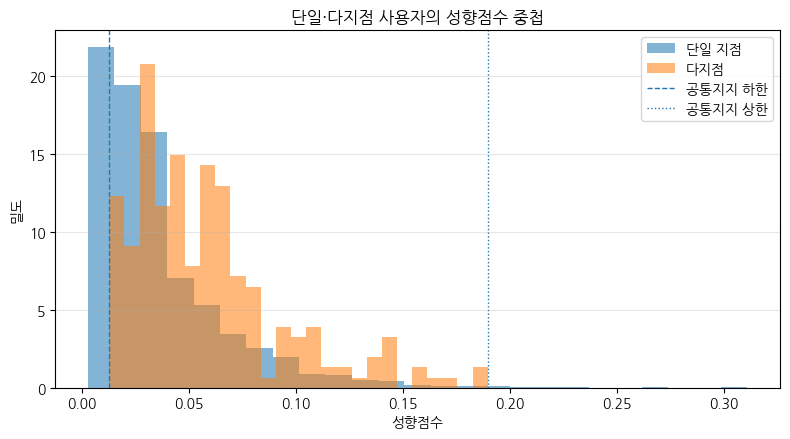

In [ ]:
# 성향점수 공통지지 영역 확인

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.hist(
    single_score,
    bins=25,
    alpha=0.55,
    density=True,
    label="단일 지점",
)

ax.hist(
    multi_score,
    bins=25,
    alpha=0.55,
    density=True,
    label="다지점",
)

ax.axvline(
    common_support_lower,
    linestyle="--",
    linewidth=1,
    label="공통지지 하한",
)

ax.axvline(
    common_support_upper,
    linestyle=":",
    linewidth=1,
    label="공통지지 상한",
)

ax.set_xlabel("성향점수")
ax.set_ylabel("밀도")
ax.set_title("단일·다지점 사용자의 성향점수 중첩")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


> **📊 시각화 해석**
>
> - 단일·다지점 집단의 성향점수 분포가 겹치는 영역이 있어 매칭 자체는 가능하다.
> - 분포가 완전히 동일하지 않으므로 공통지지 영역 밖 외삽을 피하고 실제 매칭 표본에서 효과를 평가한다.


In [ ]:
# 방문일 수 exact matching 기반 일대일 최근접 이웃 매칭

treated_pool = (
    psm_df[
        psm_df["multi_site_flag"].eq(1)
        & psm_df["in_common_support"]
    ]
    .sort_values(
        [
            "visit_days",
            "propensity_logit",
        ]
    )
    .copy()
)

control_pool = psm_df[
    psm_df["multi_site_flag"].eq(0)
    & psm_df["in_common_support"]
].copy()

available_control_indices = set(control_pool.index)
matched_pairs = []

for treated_index, treated_row in treated_pool.iterrows():
    if not available_control_indices:
        break

    available_controls = control_pool.loc[
        list(available_control_indices)
    ]

    exact_controls = available_controls[
        available_controls["visit_days"].eq(
            treated_row["visit_days"]
        )
    ]

    if exact_controls.empty:
        continue

    distance = (
        exact_controls["propensity_logit"]
        - treated_row["propensity_logit"]
    ).abs()

    nearest_control_index = distance.idxmin()
    nearest_distance = distance.loc[nearest_control_index]

    if nearest_distance <= caliper:
        matched_pairs.append(
            {
                "treated_index": treated_index,
                "control_index": nearest_control_index,
                "visit_days": int(treated_row["visit_days"]),
                "distance": nearest_distance,
            }
        )
        available_control_indices.remove(nearest_control_index)

matched_pairs_df = pd.DataFrame(matched_pairs)

if matched_pairs_df.empty:
    raise ValueError(
        "방문일 수 exact matching과 caliper 조건을 만족한 사용자가 없습니다."
    )

matched_multi_df = psm_df.loc[
    matched_pairs_df["treated_index"].to_numpy()
].reset_index(drop=True)

matched_single_df = psm_df.loc[
    matched_pairs_df["control_index"].to_numpy()
].reset_index(drop=True)

assert matched_multi_df["visit_days"].equals(
    matched_single_df["visit_days"]
), "방문일 수 exact matching이 유지되지 않았습니다."

print(f"전체 다지점 사용자: {psm_df['multi_site_flag'].eq(1).sum():,}명")
print(f"공통지지 영역 내 다지점 사용자: {len(treated_pool):,}명")
print(f"매칭 완료 사용자 쌍: {len(matched_pairs_df):,}쌍")
print(
    "전체 다지점 사용자 기준 매칭률:",
    f"{len(matched_pairs_df) / psm_df['multi_site_flag'].eq(1).sum() * 100:.1f}%",
)
print(
    "공통지지 영역 내 매칭률:",
    f"{len(matched_pairs_df) / len(treated_pool) * 100:.1f}%",
)

전체 다지점 사용자: 218명
공통지지 영역 내 다지점 사용자: 218명
매칭 완료 사용자 쌍: 218쌍
전체 다지점 사용자 기준 매칭률: 100.0%
공통지지 영역 내 매칭률: 100.0%


> **✅ 확인 결과**
>
> - 방문일 수 exact matching과 최근접 이웃 방식을 통해 다지점 이용자 218명 모두와 단일 지점 이용자 218명을 매칭했다.
> - 방문일 수를 완전히 동일하게 맞춘 1:1 비교 표본을 확보했다.


In [ ]:
# 매칭 전후 변수 균형 검증

def standardized_mean_difference(treated_values, control_values):
    treated_values = np.asarray(treated_values, dtype=float)
    control_values = np.asarray(control_values, dtype=float)

    pooled_std = np.sqrt(
        (
            np.nanvar(treated_values, ddof=1)
            + np.nanvar(control_values, ddof=1)
        )
        / 2
    )

    if pooled_std == 0 or np.isnan(pooled_std):
        return 0.0

    return (
        np.nanmean(treated_values)
        - np.nanmean(control_values)
    ) / pooled_std

balance_variables = {
    "visit_days": "방문일 수",
    "z_log_checkin_count": "체크인 횟수",
    "z_log_total_stay_hours": "총 체류시간",
}

for column in psm_half_year_dummies.columns:
    balance_variables[column] = column.replace(
        "half_year_",
        "이용 시기: ",
    )

unmatched_single_df = psm_df[
    psm_df["multi_site_flag"].eq(0)
]

unmatched_multi_df = psm_df[
    psm_df["multi_site_flag"].eq(1)
]

balance_rows = []

for column, label in balance_variables.items():
    balance_rows.append(
        {
            "변수": label,
            "매칭 전 SMD": standardized_mean_difference(
                unmatched_multi_df[column],
                unmatched_single_df[column],
            ),
            "매칭 후 SMD": standardized_mean_difference(
                matched_multi_df[column],
                matched_single_df[column],
            ),
        }
    )

balance_result = pd.DataFrame(balance_rows).round(4)
balance_result["매칭 후 |SMD|"] = (
    balance_result["매칭 후 SMD"].abs()
)

balance_result["균형 기준"] = np.where(
    balance_result["매칭 후 |SMD|"].le(0.1),
    "양호",
    "추가 점검",
)

display(balance_result)

print(
    "매칭 후 최대 절대 SMD:",
    f"{balance_result['매칭 후 |SMD|'].max():.4f}",
)

,변수,매칭 전 SMD,매칭 후 SMD,매칭 후 |SMD|,균형 기준
0,방문일 수,1.1168,0.0000,0.0000,양호
1,체크인 횟수,0.8505,-0.0662,0.0662,양호
2,총 체류시간,0.5595,-0.1391,0.1391,추가 점검
3,이용 시기: 2021년 하반기,-0.0859,-0.0350,0.0350,양호
4,이용 시기: 2022년 상반기,-0.0131,-0.0357,0.0357,양호
5,이용 시기: 2022년 하반기,-0.1062,-0.0643,0.0643,양호
6,이용 시기: 2023년 상반기,-0.1315,-0.0539,0.0539,양호
7,이용 시기: 2023년 하반기,0.2221,0.1026,0.1026,추가 점검


매칭 후 최대 절대 SMD: 0.1391


> **💡 결과 해석**
>
> - 매칭 후 방문일 수 SMD는 0, 체크인 횟수는 0.066으로 양호했다.
> - 총 체류시간의 절대 SMD는 0.139로 개선되었지만 0.1을 소폭 넘으므로 잔여 불균형을 함께 고려해야 한다.


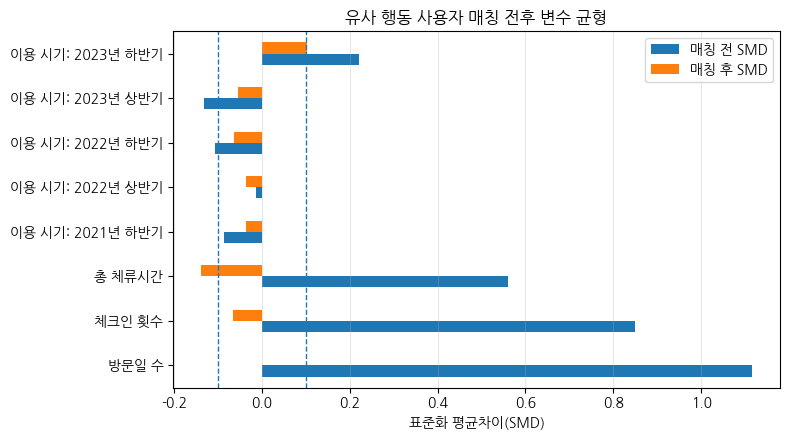

In [ ]:
# 매칭 전후 균형 차트

balance_plot = balance_result.set_index("변수")[["매칭 전 SMD", "매칭 후 SMD"]]

ax = balance_plot.plot(
    kind="barh",
    figsize=(8, 4.5),
)

ax.axvline(0.1, linestyle="--", linewidth=1)
ax.axvline(-0.1, linestyle="--", linewidth=1)
ax.set_xlabel("표준화 평균차이(SMD)")
ax.set_ylabel("")
ax.set_title("유사 행동 사용자 매칭 전후 변수 균형")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 매칭 전 큰 변수 차이가 매칭 후 대부분 0에 가까워졌다.
> - 총 체류시간은 다른 변수보다 잔여 차이가 남아 있어 매칭 결과를 인과효과로 단정하지 않는다.


In [ ]:
# 매칭 전후 결제율 비교

raw_single_rate = unmatched_single_df["is_payment"].mean()
raw_multi_rate = unmatched_multi_df["is_payment"].mean()
matched_single_rate = matched_single_df["is_payment"].mean()
matched_multi_rate = matched_multi_df["is_payment"].mean()

paired_result_table = np.array(
    [
        [
            (
                matched_multi_df["is_payment"].eq(0)
                & matched_single_df["is_payment"].eq(0)
            ).sum(),
            (
                matched_multi_df["is_payment"].eq(0)
                & matched_single_df["is_payment"].eq(1)
            ).sum(),
        ],
        [
            (
                matched_multi_df["is_payment"].eq(1)
                & matched_single_df["is_payment"].eq(0)
            ).sum(),
            (
                matched_multi_df["is_payment"].eq(1)
                & matched_single_df["is_payment"].eq(1)
            ).sum(),
        ],
    ]
)

matched_mcnemar = mcnemar(paired_result_table, exact=True)

pair_difference = (
    matched_multi_df["is_payment"].to_numpy(dtype=float)
    - matched_single_df["is_payment"].to_numpy(dtype=float)
)

pair_rng = np.random.default_rng(42)
pair_bootstrap_differences = []

for _ in range(2000):
    pair_indices = pair_rng.integers(
        0,
        len(pair_difference),
        len(pair_difference),
    )
    pair_bootstrap_differences.append(
        pair_difference[pair_indices].mean()
    )

pair_ci_lower, pair_ci_upper = np.quantile(
    pair_bootstrap_differences,
    [0.025, 0.975],
)

matching_result = pd.DataFrame(
    {
        "비교 기준": ["매칭 전", "매칭 후"],
        "단일 지점 결제율": [
            raw_single_rate * 100,
            matched_single_rate * 100,
        ],
        "다지점 결제율": [
            raw_multi_rate * 100,
            matched_multi_rate * 100,
        ],
        "결제율 격차(%p)": [
            (raw_multi_rate - raw_single_rate) * 100,
            (matched_multi_rate - matched_single_rate) * 100,
        ],
    }
).round(2)

display(matching_result)
print(
    "매칭 후 격차 95% 부트스트랩 신뢰구간:",
    f"{pair_ci_lower * 100:.2f}%p ~ {pair_ci_upper * 100:.2f}%p",
)
print(f"McNemar 검정 p-value: {matched_mcnemar.pvalue:.4f}")

,비교 기준,단일 지점 결제율,다지점 결제율,결제율 격차(%p)
0,매칭 전,38.59,44.5,5.91
1,매칭 후,41.74,44.5,2.75


매칭 후 격차 95% 부트스트랩 신뢰구간: -5.96%p ~ 11.02%p
McNemar 검정 p-value: 0.6208


> **💡 결과 해석**
>
> - 매칭 전 5.91%p였던 결제율 격차는 매칭 후 2.75%p로 절반 이하로 감소했다.
> - 95% 부트스트랩 신뢰구간은 -5.96~11.02%p이고 McNemar p-value는 0.6208로, 유사 행동 사용자 사이의 다지점 효과는 불확실했다.


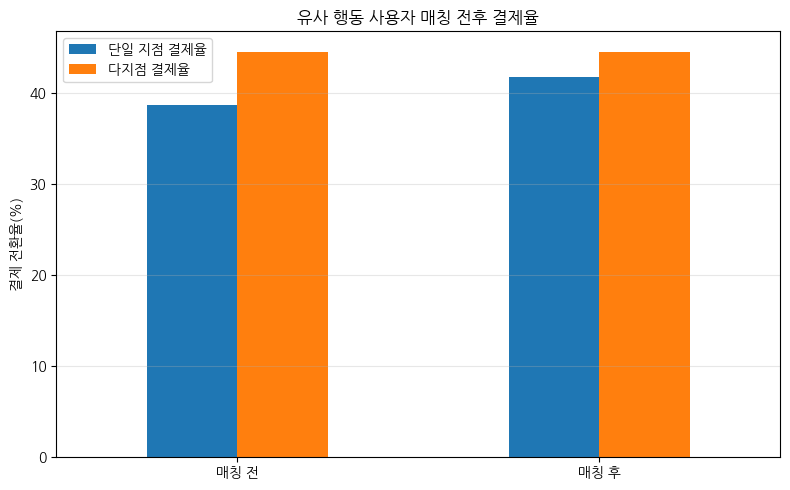

In [ ]:
# 매칭 전후 결제율 차트

matching_plot = matching_result.set_index("비교 기준")[[
    "단일 지점 결제율",
    "다지점 결제율",
]]

ax = matching_plot.plot(
    kind="bar",
    figsize=(8, 5),
)

ax.set_ylabel("결제 전환율(%)")
ax.set_xlabel("")
ax.set_title("유사 행동 사용자 매칭 전후 결제율")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 매칭 이후 단일 지점 결제율이 상승하면서 두 집단 막대의 차이가 크게 좁아졌다.
> - 원본 격차가 사용자 구성 차이의 영향을 받았다는 점을 직관적으로 보여준다.


In [ ]:
# 표준화 결제확률 계산

standardized_single_df = reg_df.copy()
standardized_multi_df = reg_df.copy()

standardized_single_df["multi_site_flag"] = 0.0
standardized_multi_df["multi_site_flag"] = 1.0

adjusted_single_probability = spline_model.predict(
    standardized_single_df
).mean()

adjusted_multi_probability = spline_model.predict(
    standardized_multi_df
).mean()

adjusted_probability_gap = (
    adjusted_multi_probability
    - adjusted_single_probability
)

adjusted_probability_result = pd.DataFrame(
    {
        "가정": [
            "모두 단일 지점 이용자로 가정",
            "모두 다지점 이용자로 가정",
        ],
        "조정 예측 결제율(%)": [
            adjusted_single_probability * 100,
            adjusted_multi_probability * 100,
        ],
    }
).round(2)

display(adjusted_probability_result)
print(f"표준화 결제율 격차: {adjusted_probability_gap * 100:.2f}%p")

,가정,조정 예측 결제율(%)
0,모두 단일 지점 이용자로 가정,38.76
1,모두 다지점 이용자로 가정,39.84


표준화 결제율 격차: 1.08%p


> **💡 결과 해석**
>
> - 관측된 공변량 분포를 유지한 표준화 결과, 모두 단일 지점으로 가정한 결제율은 38.76%, 모두 다지점으로 가정하면 39.84%였다.
> - 조정 격차는 1.08%p로 원본 5.93%p보다 크게 작아졌다.


In [ ]:
# 부트스트랩 설정

N_BOOTSTRAP = 1000
bootstrap_rng = np.random.default_rng(42)
bootstrap_adjusted_gaps = []
bootstrap_failed_count = 0

In [ ]:
# 부트스트랩 반복 실행

for _ in range(N_BOOTSTRAP):
    bootstrap_indices = bootstrap_rng.integers(
        0,
        len(reg_df),
        len(reg_df),
    )

    bootstrap_df = reg_df.iloc[bootstrap_indices].copy()

    try:
        bootstrap_model = smf.glm(
            formula=spline_formula,
            data=bootstrap_df,
            family=sm.families.Binomial(),
        ).fit()

        bootstrap_single_df = bootstrap_df.copy()
        bootstrap_multi_df = bootstrap_df.copy()

        bootstrap_single_df["multi_site_flag"] = 0.0
        bootstrap_multi_df["multi_site_flag"] = 1.0

        bootstrap_gap = (
            bootstrap_model.predict(bootstrap_multi_df).mean()
            - bootstrap_model.predict(bootstrap_single_df).mean()
        )

        bootstrap_adjusted_gaps.append(bootstrap_gap)

    except Exception:
        bootstrap_failed_count += 1

bootstrap_adjusted_gaps = np.asarray(
    bootstrap_adjusted_gaps,
    dtype=float,
)

if len(bootstrap_adjusted_gaps) < 100:
    raise ValueError("성공한 부트스트랩 반복 수가 100회 미만입니다.")

bootstrap_gap_lower, bootstrap_gap_upper = np.quantile(
    bootstrap_adjusted_gaps,
    [0.025, 0.975],
)

print(f"성공한 부트스트랩 반복: {len(bootstrap_adjusted_gaps):,}회")
print(f"실패한 부트스트랩 반복: {bootstrap_failed_count:,}회")
print(
    "조정 결제율 격차 95% 신뢰구간:",
    f"{bootstrap_gap_lower * 100:.2f}%p ~ {bootstrap_gap_upper * 100:.2f}%p",
)

성공한 부트스트랩 반복: 1,000회
실패한 부트스트랩 반복: 0회
조정 결제율 격차 95% 신뢰구간: -5.32%p ~ 8.10%p


> **💡 결과 해석**
>
> - 1,000회 부트스트랩에서 조정 결제율 격차의 95% 신뢰구간은 -5.32~8.10%p였다.
> - 신뢰구간이 0을 포함하므로 다지점 이용의 방향과 크기를 안정적으로 확정할 수 없다.


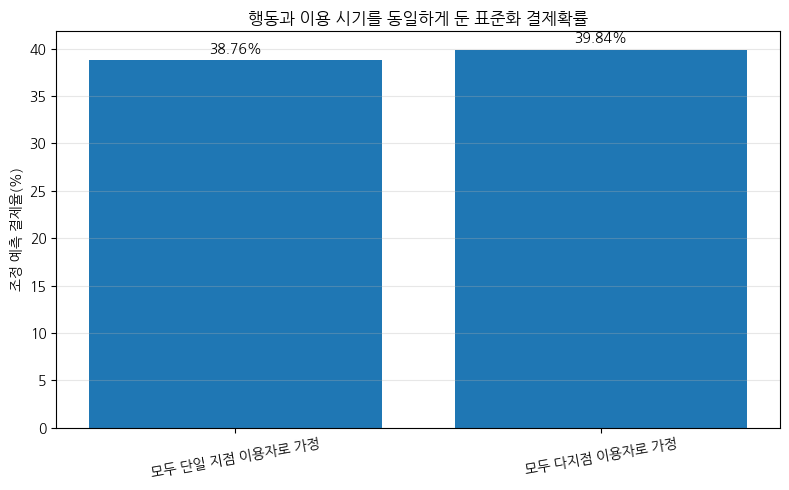

In [ ]:
# 표준화 결제확률 차트

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    adjusted_probability_result["가정"],
    adjusted_probability_result["조정 예측 결제율(%)"],
)

for bar, value in zip(
    bars,
    adjusted_probability_result["조정 예측 결제율(%)"],
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.5,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
    )

ax.set_ylabel("조정 예측 결제율(%)")
ax.set_title("행동과 이용 시기를 동일하게 둔 표준화 결제확률")
ax.tick_params(axis="x", rotation=10)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 표준화된 두 가정의 예측 결제율은 거의 유사하다.
> - 행동과 시기를 동일하게 맞춘 상황에서 다지점 여부만으로 큰 전환 차이가 발생한다는 근거는 약하다.


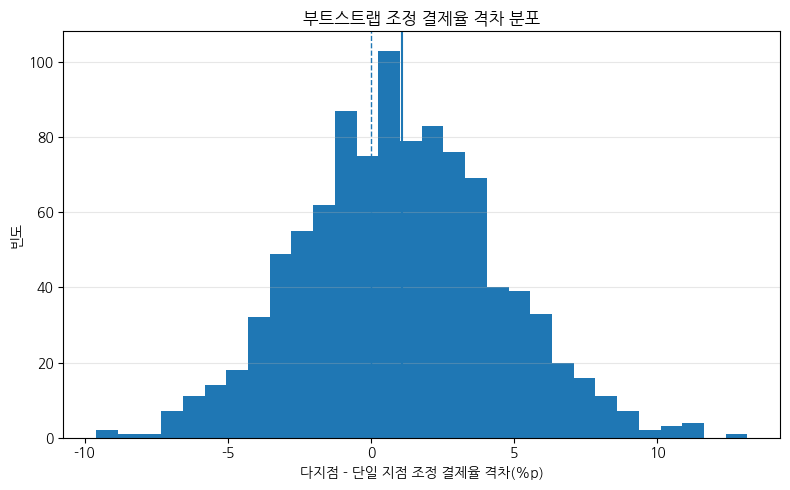

In [ ]:
# 부트스트랩 격차 분포 차트

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    bootstrap_adjusted_gaps * 100,
    bins=30,
)

ax.axvline(0, linestyle="--", linewidth=1)
ax.axvline(adjusted_probability_gap * 100, linewidth=1.5)
ax.set_xlabel("다지점 - 단일 지점 조정 결제율 격차(%p)")
ax.set_ylabel("빈도")
ax.set_title("부트스트랩 조정 결제율 격차 분포")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 부트스트랩 격차 분포가 0을 중심으로 양수와 음수 영역에 걸쳐 있다.
> - 점추정치가 양수더라도 표본 변동성을 고려하면 효과 방향이 불확실함을 보여준다.


In [ ]:
# 최소 탐지 가능 효과 계산

single_user_count = int(
    conversion_summary.loc["단일 지점", "사용자수"]
)

multi_user_count = int(
    conversion_summary.loc["다지점", "사용자수"]
)

single_conversion_rate = float(
    conversion_summary.loc["단일 지점", "결제율"]
)

multi_conversion_rate = float(
    conversion_summary.loc["다지점", "결제율"]
)

power_model = NormalIndPower()
current_ratio = multi_user_count / single_user_count

minimum_effect_size = power_model.solve_power(
    effect_size=None,
    nobs1=single_user_count,
    alpha=0.05,
    power=0.80,
    ratio=current_ratio,
    alternative="two-sided",
)

detectable_multi_rate = brentq(
    lambda rate: (
        abs(proportion_effectsize(rate, single_conversion_rate))
        - minimum_effect_size
    ),
    single_conversion_rate + 1e-6,
    0.999999,
)

minimum_detectable_gap = (
    detectable_multi_rate
    - single_conversion_rate
)

observed_effect_size = abs(
    proportion_effectsize(
        multi_conversion_rate,
        single_conversion_rate,
    )
)

required_ratio = power_model.solve_power(
    effect_size=observed_effect_size,
    nobs1=single_user_count,
    alpha=0.05,
    power=0.80,
    ratio=None,
    alternative="two-sided",
)

required_multi_count = int(
    np.ceil(single_user_count * required_ratio)
)

power_result = pd.DataFrame(
    {
        "항목": [
            "현재 단일 지점 표본",
            "현재 다지점 표본",
            "관찰 결제율 격차",
            "80% 검정력 기준 최소 탐지 격차",
            "관찰 격차 탐지에 필요한 다지점 표본",
        ],
        "결과": [
            f"{single_user_count:,}명",
            f"{multi_user_count:,}명",
            f"{(multi_conversion_rate - single_conversion_rate) * 100:.2f}%p",
            f"{minimum_detectable_gap * 100:.2f}%p",
            f"약 {required_multi_count:,}명",
        ],
    }
)

display(power_result)

,항목,결과
0,현재 단일 지점 표본,"5,808명"
1,현재 다지점 표본,218명
2,관찰 결제율 격차,5.93%p
3,80% 검정력 기준 최소 탐지 격차,9.56%p
4,관찰 격차 탐지에 필요한 다지점 표본,약 598명


> **💡 결과 해석**
>
> - 현재 다지점 표본 218명으로 80% 검정력에서 탐지 가능한 최소 격차는 약 9.56%p로, 관찰된 5.93%p보다 크다.
> - 관찰 격차를 안정적으로 검정하려면 다지점 표본이 약 598명 필요해 현재 분석은 검정력 한계를 가진다.


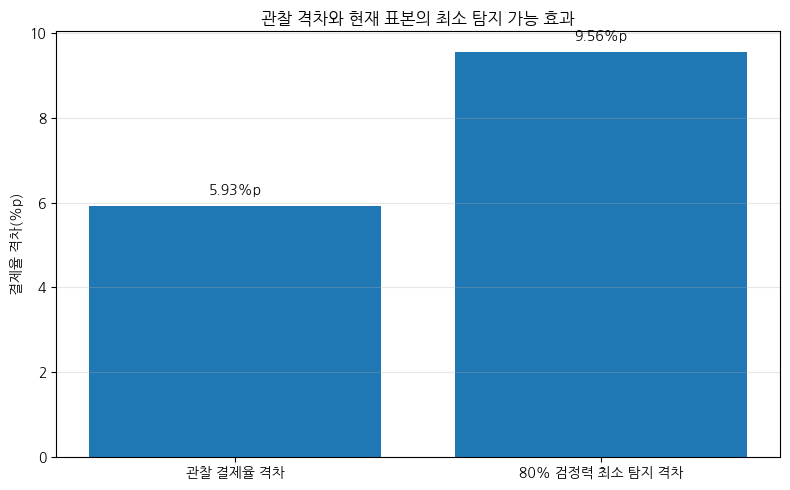

In [ ]:
# 관찰 격차와 최소 탐지 격차 차트

effect_comparison = pd.DataFrame(
    {
        "구분": [
            "관찰 결제율 격차",
            "80% 검정력 최소 탐지 격차",
        ],
        "격차(%p)": [
            (
                multi_conversion_rate
                - single_conversion_rate
            )
            * 100,
            minimum_detectable_gap * 100,
        ],
    }
)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    effect_comparison["구분"],
    effect_comparison["격차(%p)"],
)

for bar, value in zip(bars, effect_comparison["격차(%p)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.2,
        f"{value:.2f}%p",
        ha="center",
        va="bottom",
    )

ax.set_ylabel("결제율 격차(%p)")
ax.set_title("관찰 격차와 현재 표본의 최소 탐지 가능 효과")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 관찰된 결제율 격차가 현재 표본의 최소 탐지 가능 격차보다 작다.
> - 유의하지 않은 결과는 효과가 완전히 없다는 뜻이 아니라, 작은 효과를 구분하기에 표본이 부족하다는 가능성도 포함한다.


#### 6-2-2-5. 결제율 격차와 방문경로 심화 분석

**🔹 분석 목적**

- 단일·다지점 원본 결제율 격차 중 방문일 수, 체류시간, 체크인 횟수, 이용 시기 구성으로 설명되는 부분을 분해한다.
- D0~D2의 지점 방문 흔적을 통합해 사용자의 일자별 방문경로를 생성한다.
- 단일 지점 1일 방문, 동일 지점 반복, 당일 다지점, 일자 간 지점 변경, 복합 다지점 경로의 결제율을 비교한다.
- 경로 유형별 회귀는 표본이 작은 경로가 포함되므로 탐색적 근거로만 사용한다.


In [ ]:
# 격차 분해 입력 데이터 생성

from scipy.special import expit

decomposition_visit_dummies = pd.get_dummies(
    reg_df["visit_days"].astype(int).reset_index(drop=True),
    prefix="visit_days",
    drop_first=True,
    dtype=float,
)

decomposition_half_year_dummies = pd.get_dummies(
    reg_df["half_year"].reset_index(drop=True).astype(str),
    prefix="half_year",
    drop_first=True,
    dtype=float,
)

decomposition_features = pd.concat(
    [
        reg_df[
            [
                "z_log_checkin_count",
                "z_log_total_stay_hours",
            ]
        ].reset_index(drop=True),
        decomposition_visit_dummies,
        decomposition_half_year_dummies,
    ],
    axis=1,
).astype(float)

decomposition_X = sm.add_constant(
    decomposition_features,
    has_constant="add",
)

decomposition_y = (
    reg_df["is_payment"]
    .reset_index(drop=True)
    .astype(float)
)

decomposition_group = (
    reg_df["multi_site_flag"]
    .reset_index(drop=True)
    .astype(int)
)

decomposition_model = sm.GLM(
    decomposition_y,
    decomposition_X,
    family=sm.families.Binomial(),
).fit()

decomposition_data = decomposition_features.copy()
decomposition_data["predicted_probability"] = decomposition_model.predict(
    decomposition_X
)
decomposition_data["multi_site_flag"] = decomposition_group.to_numpy()

In [ ]:
# 변수 블록별 격차 분해 반복

feature_blocks = {
    "방문일 수": [
        column
        for column in decomposition_features.columns
        if column.startswith("visit_days_")
    ],
    "체크인 횟수": ["z_log_checkin_count"],
    "총 체류시간": ["z_log_total_stay_hours"],
    "이용 시기": [
        column
        for column in decomposition_features.columns
        if column.startswith("half_year_")
    ],
}

decomposition_multi = decomposition_data[
    decomposition_data["multi_site_flag"].eq(1)
].copy()

decomposition_single = decomposition_data[
    decomposition_data["multi_site_flag"].eq(0)
].copy()

decomposition_columns = list(decomposition_features.columns)
decomposition_coefficients = decomposition_model.params
decomposition_rng = np.random.default_rng(42)
decomposition_rows = []
N_DECOMPOSITION = 200

for _ in range(N_DECOMPOSITION):
    sampled_single = (
        decomposition_single.sample(
            n=len(decomposition_multi),
            replace=False,
            random_state=int(
                decomposition_rng.integers(0, 1_000_000)
            ),
        )
        .sort_values("predicted_probability")
        .reset_index(drop=True)
    )

    sorted_multi = (
        decomposition_multi
        .sort_values("predicted_probability")
        .reset_index(drop=True)
    )

    current_features = sampled_single[decomposition_columns].copy()
    random_block_order = list(feature_blocks.keys())
    decomposition_rng.shuffle(random_block_order)

    previous_probability = expit(
        decomposition_coefficients["const"]
        + current_features.dot(
            decomposition_coefficients[decomposition_columns]
        )
    ).mean()

    iteration_contribution = {}

    for block_name in random_block_order:
        block_columns = feature_blocks[block_name]
        current_features[block_columns] = sorted_multi[
            block_columns
        ].to_numpy()

        new_probability = expit(
            decomposition_coefficients["const"]
            + current_features.dot(
                decomposition_coefficients[decomposition_columns]
            )
        ).mean()

        iteration_contribution[block_name] = (
            new_probability
            - previous_probability
        )
        previous_probability = new_probability

    decomposition_rows.append(iteration_contribution)

decomposition_repetitions = pd.DataFrame(decomposition_rows)

decomposition_result = (
    decomposition_repetitions.mean()
    .rename("격차 기여도")
    .reset_index()
    .rename(columns={"index": "변수 블록"})
)

decomposition_result["격차 기여도(%p)"] = (
    decomposition_result["격차 기여도"] * 100
)

explained_gap = decomposition_result["격차 기여도"].sum()
observed_gap = raw_multi_rate - raw_single_rate

decomposition_result["관찰 격차 대비 비중(%)"] = np.where(
    observed_gap != 0,
    decomposition_result["격차 기여도"] / observed_gap * 100,
    np.nan,
)

display(
    decomposition_result[
        [
            "변수 블록",
            "격차 기여도(%p)",
            "관찰 격차 대비 비중(%)",
        ]
    ]
    .round(2)
    .sort_values("격차 기여도(%p)", ascending=False)
)

print(f"관찰 결제율 격차: {observed_gap * 100:.2f}%p")
print(f"행동·시기 구성으로 설명된 격차: {explained_gap * 100:.2f}%p")
print(f"설명 비율: {explained_gap / observed_gap * 100:.1f}%")

,변수 블록,격차 기여도(%p),관찰 격차 대비 비중(%)
0,방문일 수,9.16,155.12
3,체크인 횟수,-0.48,-8.04
2,이용 시기,-0.81,-13.65
1,총 체류시간,-3.49,-59.06


관찰 결제율 격차: 5.91%p
행동·시기 구성으로 설명된 격차: 4.39%p
설명 비율: 74.4%


> **💡 결과 해석**
>
> - 방문일 수 구성은 원본 격차를 +9.16%p 방향으로 설명했지만, 총 체류시간·체크인·이용 시기 구성은 일부를 상쇄했다.
> - 행동·시기 구성으로 설명된 격차는 4.39%p로 원본 5.91%p의 74.4%였다.
> - 이 분해는 설명적 분석이며 각 변수 블록의 인과 기여도를 의미하지 않는다.


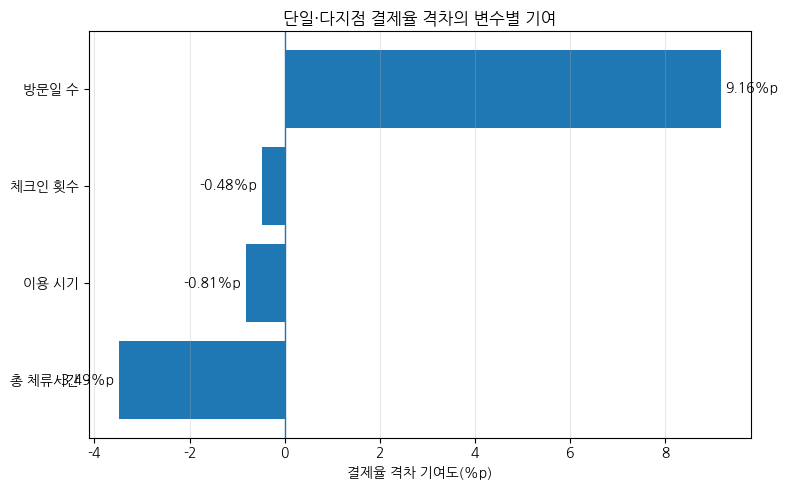

In [ ]:
# 격차 기여도 차트

decomposition_plot = decomposition_result.sort_values(
    "격차 기여도(%p)"
)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(
    decomposition_plot["변수 블록"],
    decomposition_plot["격차 기여도(%p)"],
)

ax.axvline(0, linewidth=1)

for bar, value in zip(
    bars,
    decomposition_plot["격차 기여도(%p)"],
):
    text_x = value + 0.1 if value >= 0 else value - 0.1
    text_ha = "left" if value >= 0 else "right"

    ax.text(
        text_x,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%p",
        ha=text_ha,
        va="center",
    )

ax.set_xlabel("결제율 격차 기여도(%p)")
ax.set_ylabel("")
ax.set_title("단일·다지점 결제율 격차의 변수별 기여")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 격차 분해에서 방문일 수의 양의 기여가 가장 크고, 총 체류시간은 반대 방향으로 작용한다.
> - 다지점 집단의 높은 결제율을 설명하는 핵심 구성 차이가 반복 방문임을 시각적으로 확인한다.


In [ ]:
# D0~D2 지점 방문 흔적 통합

visit_site_presence = (
    trial_visit_info_d0d2[
        [
            "user_id",
            "site_id",
            "date",
            "day_from_trial",
        ]
    ]
    .rename(columns={"date": "activity_date"})
    .copy()
)

access_site_presence = (
    trial_access_log_d0d2[
        [
            "user_id",
            "site_id",
            "access_date",
            "day_from_trial",
        ]
    ]
    .rename(columns={"access_date": "activity_date"})
    .copy()
)

path_presence_df = (
    pd.concat(
        [
            visit_site_presence,
            access_site_presence,
        ],
        ignore_index=True,
    )
    .dropna(
        subset=[
            "user_id",
            "site_id",
            "activity_date",
            "day_from_trial",
        ]
    )
    .drop_duplicates(
        [
            "user_id",
            "site_id",
            "activity_date",
        ]
    )
)

path_presence_df["activity_date"] = pd.to_datetime(
    path_presence_df["activity_date"],
    errors="raise",
)

path_presence_df["day_from_trial"] = pd.to_numeric(
    path_presence_df["day_from_trial"],
    errors="raise",
).astype(int)

assert path_presence_df["day_from_trial"].between(0, 2).all()

print(f"D0~D2 지점 흔적 행 수: {len(path_presence_df):,}행")
print(f"고유 방문 사용자 수: {path_presence_df['user_id'].nunique():,}명")

D0~D2 지점 흔적 행 수: 9,121행
고유 방문 사용자 수: 6,026명


> **✅ 확인 결과**
>
> - D0~D2 지점 방문 흔적 9,121행을 통합해 6,026명 방문자의 경로 정보를 구성했다.
> - 이후 분석은 일자별 지점 조합과 최초 지점 복귀 여부를 사용자 단위 경로로 요약한다.


In [ ]:
# 사용자별 방문경로 요약 함수

def summarize_user_path(user_path_df):
    user_path_df = (
        user_path_df
        .sort_values(
            [
                "day_from_trial",
                "activity_date",
                "site_id",
            ]
        )
        .copy()
    )

    daily_path = (
        user_path_df
        .groupby(
            [
                "day_from_trial",
                "activity_date",
            ],
            as_index=False,
        )
        .agg(
            site_set=(
                "site_id",
                lambda values: tuple(
                    sorted(set(values.astype(str)))
                ),
            )
        )
        .sort_values(
            [
                "day_from_trial",
                "activity_date",
            ]
        )
    )

    day_sets = [set(site_tuple) for site_tuple in daily_path["site_set"]]
    day_numbers = daily_path["day_from_trial"].astype(int).tolist()
    all_sites = set().union(*day_sets)
    visit_days = len(day_sets)

    same_day_multi_site = any(len(site_set) >= 2 for site_set in day_sets)

    cross_day_site_set_change = any(
        day_sets[index] != day_sets[index - 1]
        for index in range(1, len(day_sets))
    )

    cross_day_site_set_change_count = sum(
        day_sets[index] != day_sets[index - 1]
        for index in range(1, len(day_sets))
    )

    first_site_set_change_day = np.nan
    for index in range(1, len(day_sets)):
        if day_sets[index] != day_sets[index - 1]:
            first_site_set_change_day = day_numbers[index]
            break

    first_day_sites = day_sets[0]
    return_to_first_site = False

    for leave_index in range(1, len(day_sets)):
        left_first_site = not bool(
            first_day_sites.intersection(day_sets[leave_index])
        )

        if not left_first_site:
            continue

        for return_index in range(leave_index + 1, len(day_sets)):
            if first_day_sites.intersection(day_sets[return_index]):
                return_to_first_site = True
                break

        if return_to_first_site:
            break

    site_day_counts = user_path_df.groupby("site_id").size()
    site_day_shares = site_day_counts / site_day_counts.sum()
    dominant_site_share = site_day_shares.max()

    if len(site_day_shares) == 1:
        normalized_site_entropy = 0.0
    else:
        normalized_site_entropy = (
            -(site_day_shares * np.log(site_day_shares)).sum()
            / np.log(len(site_day_shares))
        )

    path_sequence = " → ".join(
        [
            f"D{int(row.day_from_trial)}:" + "+".join(row.site_set)
            for row in daily_path.itertuples()
        ]
    )

    if len(all_sites) == 1 and visit_days == 1:
        path_type = "단일 지점·1일 방문"
    elif len(all_sites) == 1 and visit_days >= 2:
        path_type = "동일 지점 반복형"
    elif same_day_multi_site and cross_day_site_set_change:
        path_type = "복합 다지점형"
    elif same_day_multi_site:
        path_type = "당일 다지점형"
    elif cross_day_site_set_change:
        path_type = "일자 간 지점 구성 변경형"
    else:
        path_type = "다지점 기타형"

    return pd.Series(
        {
            "path_type": path_type,
            "path_sequence": path_sequence,
            "path_visit_days": visit_days,
            "path_distinct_site_count": len(all_sites),
            "same_day_multi_site": int(same_day_multi_site),
            "cross_day_site_set_change": int(cross_day_site_set_change),
            "cross_day_site_set_change_count": cross_day_site_set_change_count,
            "first_site_set_change_day": first_site_set_change_day,
            "dominant_site_share": dominant_site_share,
            "site_entropy": normalized_site_entropy,
            "return_to_first_site": int(return_to_first_site),
        }
    )

In [ ]:
# 사용자별 행동경로 생성

user_path_df = (
    path_presence_df
    .groupby("user_id", group_keys=False)
    .apply(summarize_user_path)
    .reset_index()
)

path_analysis_df = user_path_df.merge(
    site_analysis_df[
        [
            "user_id",
            "is_payment",
            "half_year",
            "site_group",
            "visit_days",
            "distinct_site_count",
            "checkin_count",
            "total_stay_hours",
        ]
    ],
    on="user_id",
    how="left",
    validate="1:1",
)

visit_days_match = path_analysis_df["path_visit_days"].eq(
    path_analysis_df["visit_days"].astype(int)
)

site_count_match = path_analysis_df["path_distinct_site_count"].eq(
    path_analysis_df["distinct_site_count"].astype(int)
)

print(f"방문일 수 일치율: {visit_days_match.mean() * 100:.2f}%")
print(f"고유 지점 수 일치율: {site_count_match.mean() * 100:.2f}%")

assert visit_days_match.all()
assert site_count_match.all()

display(path_analysis_df.head())

방문일 수 일치율: 100.00%
고유 지점 수 일치율: 100.00%


/tmp/ipykernel_22006/2465545822.py:6: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



,user_id,path_type,path_sequence,path_visit_days,path_distinct_site_count,same_day_multi_site,cross_day_site_set_change,cross_day_site_set_change_count,first_site_set_change_day,dominant_site_share,site_entropy,return_to_first_site,is_payment,half_year,site_group,visit_days,distinct_site_count,checkin_count,total_stay_hours
0,000590dc-046f-462b-8225-4c81a97b7166,단일 지점·1일 방문,D1:6,1,1,0,0,0,NaN,1.0,0.0,0,0,2023년 하반기,단일 지점,1,1,3,5.949167
1,000be14f-ba0f-4af6-bc2c-7b00dfcbc98c,동일 지점 반복형,D1:3 → D2:3,2,1,0,0,0,NaN,1.0,0.0,0,1,2021년 하반기,단일 지점,2,1,9,5.445556
2,0018e22d-a2cc-4e06-bca2-d6a041770f3b,동일 지점 반복형,D1:6 → D2:6,2,1,0,0,0,NaN,1.0,0.0,0,0,2023년 하반기,단일 지점,2,1,11,21.492222
3,002606d9-38ca-48f3-910c-cbfada9a9109,동일 지점 반복형,D1:17 → D2:17,2,1,0,0,0,NaN,1.0,0.0,0,0,2023년 상반기,단일 지점,2,1,4,6.951111
4,002a7570-90dd-4cab-b0aa-b0e40f7ef27a,단일 지점·1일 방문,D1:5,1,1,0,0,0,NaN,1.0,0.0,0,1,2021년 하반기,단일 지점,1,1,5,5.200556


> **✅ 확인 결과**
>
> - 경로 데이터에서 재계산한 방문일 수와 이용 지점 수가 사용자 마스터 값과 모두 100% 일치했다.
> - 경로 유형 분류가 기존 집계 결과와 정합적으로 연결되었음을 확인했다.


In [ ]:
# 행동경로 유형별 결제율 집계

path_type_order = [
    "단일 지점·1일 방문",
    "동일 지점 반복형",
    "당일 다지점형",
    "일자 간 지점 구성 변경형",
    "복합 다지점형",
    "다지점 기타형",
]

path_type_summary = (
    path_analysis_df
    .groupby("path_type")
    .agg(
        사용자수=("user_id", "nunique"),
        결제자수=("is_payment", "sum"),
        결제율=("is_payment", "mean"),
        평균_방문일수=("path_visit_days", "mean"),
        평균_지점수=("path_distinct_site_count", "mean"),
        평균_일자간_지점구성변경수=("cross_day_site_set_change_count", "mean"),
        평균_주지점집중도=("dominant_site_share", "mean"),
        평균_지점엔트로피=("site_entropy", "mean"),
        최초지점복귀율=("return_to_first_site", "mean"),
    )
    .reindex(path_type_order)
    .dropna(subset=["사용자수"])
    .reset_index()
)

path_type_ci = []

for _, row in path_type_summary.iterrows():
    ci_lower, ci_upper = proportion_confint(
        count=int(row["결제자수"]),
        nobs=int(row["사용자수"]),
        alpha=0.05,
        method="wilson",
    )
    path_type_ci.append((ci_lower, ci_upper))

path_type_summary["95%CI_하한"] = [value[0] for value in path_type_ci]
path_type_summary["95%CI_상한"] = [value[1] for value in path_type_ci]

for column in [
    "결제율",
    "최초지점복귀율",
    "95%CI_하한",
    "95%CI_상한",
]:
    path_type_summary[column] = path_type_summary[column] * 100

display(path_type_summary.round(2))

,path_type,사용자수,결제자수,결제율,평균_방문일수,평균_지점수,평균_일자간_지점구성변경수,평균_주지점집중도,평균_지점엔트로피,최초지점복귀율,95%CI_하한,95%CI_상한
0,단일 지점·1일 방문,3372.0,1182,35.05,1.00,1.00,0.00,1.00,0.00,0.00,33.46,36.68
1,동일 지점 반복형,2436.0,1058,43.43,2.15,1.00,0.00,1.00,0.00,0.00,41.48,45.41
2,당일 다지점형,19.0,6,31.58,1.00,2.05,0.00,0.49,1.00,0.00,15.36,53.99
3,일자 간 지점 구성 변경형,162.0,71,43.83,2.22,2.06,1.10,0.52,0.99,4.32,36.42,51.52
4,복합 다지점형,37.0,20,54.05,2.24,2.41,1.14,0.57,0.93,8.11,38.38,68.96


> **💡 결과 해석**
>
> - 단일 지점 1일 방문은 35.05%, 동일 지점 반복형은 43.43%로 다시 방문한 집단의 결제율이 높았다.
> - 복합 다지점형은 54.05%로 가장 높지만 37명에 불과해 탐색적 신호로만 해석한다.
> - 경로 유형에서도 핵심 차이는 지점 이동 자체보다 여러 날짜에 걸친 이용 지속성에서 나타났다.


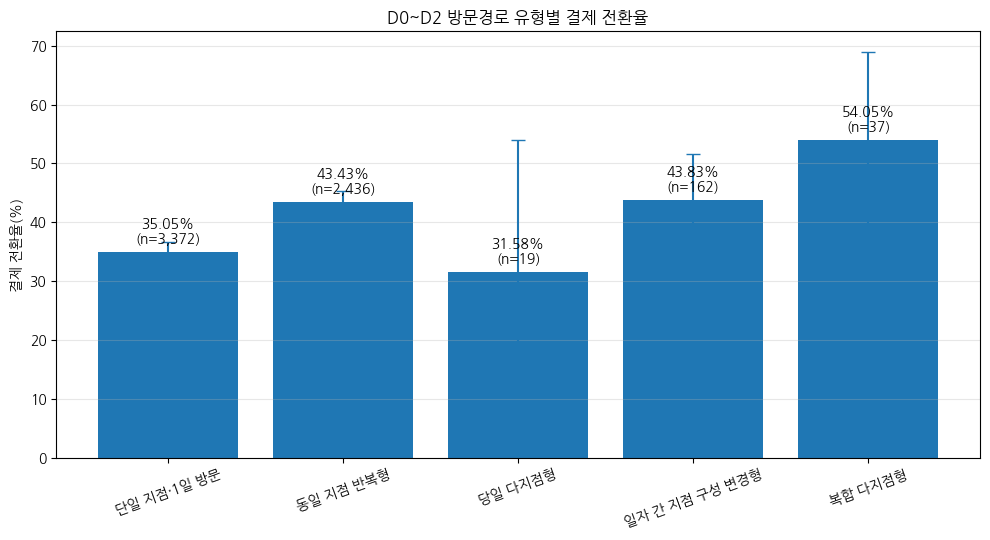

In [ ]:
# 행동경로 유형별 결제율 차트

path_plot_df = path_type_summary.copy()
path_rates = path_plot_df["결제율"].to_numpy()
path_lower_error = path_rates - path_plot_df["95%CI_하한"].to_numpy()
path_upper_error = path_plot_df["95%CI_상한"].to_numpy() - path_rates

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(
    path_plot_df["path_type"],
    path_rates,
)

ax.errorbar(
    path_plot_df["path_type"],
    path_rates,
    yerr=[path_lower_error, path_upper_error],
    fmt="none",
    capsize=5,
)

for bar, rate, count in zip(
    bars,
    path_rates,
    path_plot_df["사용자수"],
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 1.0,
        f"{rate:.2f}%\n(n={int(count):,})",
        ha="center",
        va="bottom",
    )

ax.set_ylabel("결제 전환율(%)")
ax.set_title("D0~D2 방문경로 유형별 결제 전환율")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 1일 방문 유형보다 반복 방문 유형의 결제율이 전반적으로 높다.
> - 다지점 경로의 막대는 표본이 작고 신뢰구간이 넓으므로 단순 순위보다 반복 방문 여부를 중심으로 읽어야 한다.


In [ ]:
# 주요 방문 시퀀스 확인

sequence_summary = (
    path_analysis_df
    .groupby("path_sequence")
    .agg(
        사용자수=("user_id", "nunique"),
        결제자수=("is_payment", "sum"),
        결제율=("is_payment", "mean"),
    )
    .reset_index()
)

sequence_summary["결제율"] = sequence_summary["결제율"] * 100

major_sequence_summary = (
    sequence_summary[sequence_summary["사용자수"].ge(10)]
    .sort_values(
        ["사용자수", "결제율"],
        ascending=[False, False],
    )
    .head(15)
)

display(major_sequence_summary.round(2))

,path_sequence,사용자수,결제자수,결제율
200,D1:6 → D2:6,342,129,37.72
164,D1:3 → D2:3,327,149,45.57
190,D1:6,321,112,34.89
160,D1:3,299,110,36.79
152,D1:2 → D2:2,289,113,39.1
149,D1:2,256,80,31.25
119,D1:1,225,84,37.33
206,D2:3,199,88,44.22
211,D2:6,199,74,37.19
187,D1:5 → D2:5,186,96,51.61


> **💡 결과 해석**
>
> - 주요 시퀀스에서도 동일 지점을 D1과 D2에 반복 이용한 경로가 다수 확인되며 지점별 결제율은 서로 다르게 나타났다.
> - 시퀀스별 결과는 지점 특성과 기간 차이가 섞인 기술통계이므로, 특정 지점 경로의 우열을 인과적으로 해석하지 않는다.


In [ ]:
# 방문경로 유형별 탐색 모델: 반기만 보정

path_model_df = path_analysis_df.dropna(
    subset=[
        "is_payment",
        "path_type",
        "half_year",
    ]
).copy()

path_model_df["is_payment"] = pd.to_numeric(
    path_model_df["is_payment"],
    errors="raise",
).astype(float)

path_formula = (
    "is_payment ~ "
    "C(path_type, Treatment(reference='단일 지점·1일 방문')) "
    "+ C(half_year)"
)

path_model = smf.glm(
    formula=path_formula,
    data=path_model_df,
    family=sm.families.Binomial(),
).fit(cov_type="HC3")

path_model_rows = []

for variable in path_model.params.index:
    if "C(path_type" not in variable:
        continue

    ci_lower, ci_upper = path_model.conf_int().loc[variable]
    path_label = variable.split("[T.", 1)[-1].rstrip("]")

    path_model_rows.append(
        {
            "방문경로 유형": path_label,
            "오즈비": np.exp(path_model.params[variable]),
            "95%CI_하한": np.exp(ci_lower),
            "95%CI_상한": np.exp(ci_upper),
            "p-value": path_model.pvalues[variable],
        }
    )

path_model_result = pd.DataFrame(path_model_rows)
path_model_result["해석 주의"] = (
    "반기만 보정한 탐색적 OR이며 경로별 방문일 수 차이를 포함"
)
display(path_model_result.round(4))

,방문경로 유형,오즈비,95%CI_하한,95%CI_상한,p-value,해석 주의
0,당일 다지점형,0.8036,0.3026,2.1341,0.6608,반기만 보정한 탐색적 OR이며 경로별 방문일 수 차이를 포함
1,동일 지점 반복형,1.4605,1.3113,1.6267,0.0000,반기만 보정한 탐색적 OR이며 경로별 방문일 수 차이를 포함
2,복합 다지점형,2.4655,1.3069,4.6512,0.0053,반기만 보정한 탐색적 OR이며 경로별 방문일 수 차이를 포함
3,일자 간 지점 구성 변경형,1.5147,1.0898,2.1053,0.0134,반기만 보정한 탐색적 OR이며 경로별 방문일 수 차이를 포함


> **💡 결과 해석**
>
> - 반기만 보정한 탐색 모델에서 동일 지점 반복형 OR은 1.461, 일자 간 지점 변경형은 1.515, 복합 다지점형은 2.466으로 나타났다.
> - 경로별 방문일 수와 이용량 차이를 충분히 통제하지 않은 결과이므로, 반복 방문과 지점 이동의 독립효과로 해석하지 않는다.


In [ ]:
# 다지점 사용자 내부 경로 보정 모델

multi_path_df = path_analysis_df[
    path_analysis_df["path_distinct_site_count"].ge(2)
].dropna(
    subset=[
        "is_payment",
        "checkin_count",
        "total_stay_hours",
        "half_year",
    ]
).copy()

multi_path_df["log_checkin_count"] = np.log1p(
    multi_path_df["checkin_count"]
)

multi_path_df["log_total_stay_hours"] = np.log1p(
    multi_path_df["total_stay_hours"]
)

multi_path_formula = (
    "is_payment ~ same_day_multi_site "
    "+ cross_day_site_set_change "
    "+ path_visit_days "
    "+ log_checkin_count "
    "+ log_total_stay_hours "
    "+ C(half_year)"
)

multi_path_model = smf.glm(
    formula=multi_path_formula,
    data=multi_path_df,
    family=sm.families.Binomial(),
).fit(cov_type="HC3")

multi_path_variables = [
    "same_day_multi_site",
    "cross_day_site_set_change",
    "path_visit_days",
    "log_checkin_count",
    "log_total_stay_hours",
]

multi_path_rows = []

for variable in multi_path_variables:
    ci_lower, ci_upper = multi_path_model.conf_int().loc[variable]
    multi_path_rows.append(
        {
            "변수": variable,
            "오즈비": np.exp(multi_path_model.params[variable]),
            "95%CI_하한": np.exp(ci_lower),
            "95%CI_상한": np.exp(ci_upper),
            "p-value": multi_path_model.pvalues[variable],
        }
    )

multi_path_result = pd.DataFrame(multi_path_rows)
multi_path_result["변수"] = multi_path_result["변수"].replace(
    {
        "same_day_multi_site": "당일 다지점 여부",
        "cross_day_site_set_change": "일자 간 지점 구성 변경 여부",
        "path_visit_days": "방문일 수",
        "log_checkin_count": "체크인 횟수",
        "log_total_stay_hours": "총 체류시간",
    }
)

display(multi_path_result.round(4))

,변수,오즈비,95%CI_하한,95%CI_상한,p-value
0,당일 다지점 여부,1.7169,0.8301,3.5512,0.1449
1,일자 간 지점 구성 변경 여부,3.4692,0.7481,16.0883,0.1120
2,방문일 수,1.8499,0.8474,4.0385,0.1225
3,체크인 횟수,0.8837,0.4369,1.7874,0.7308
4,총 체류시간,0.4789,0.2417,0.9492,0.0349


> **💡 결과 해석**
>
> - 다지점 사용자 내부에서는 당일 다지점 여부와 일자 간 지점 변경 여부 모두 유의하지 않았고 신뢰구간이 매우 넓었다.
> - 작은 표본 안에서 이동 방식의 추가 효과를 안정적으로 구분하기 어렵다는 점을 확인했다.


#### 6-2-2-6. 종합 결과 및 운영 방향

**🔹 분석 목적**

- 원본 비교, 층화, 회귀, 비선형 보정, 매칭, 표준화 결과를 한 표로 정리한다.
- 서로 다른 방법론에서 다지점 효과가 일관되게 유지되는지 확인한다.
- 다지점 이용과 반복 방문의 역할을 구분해 무료 체험 단계의 핵심 활성화 행동을 정의한다.

In [ ]:
# 전체 분석 결과 비교표

required_result_names = [
    "rate_difference",
    "conversion_p_value",
    "stratified_table",
    "mh_test",
    "multi_site_effect",
    "spline_model",
    "matched_multi_rate",
    "matched_single_rate",
    "matched_mcnemar",
    "adjusted_probability_gap",
    "bootstrap_gap_lower",
    "bootstrap_gap_upper",
]

missing_result_names = [
    name
    for name in required_result_names
    if name not in globals()
]

if missing_result_names:
    raise RuntimeError(
        "최종 비교표 생성 전 6-1 분석 셀을 위에서부터 순서대로 실행해 주세요. "
        f"누락 변수: {missing_result_names}"
    )

final_comparison_table = pd.DataFrame(
    {
        "분석 단계": [
            "원본 결제율 비교",
            "방문일 수 층화",
            "전체 행동 보정 회귀",
            "비선형 B-spline 보정",
            "방문일 수 exact matching",
        ],
        "다지점 관련 결과": [
            (
                f"{rate_difference * 100:+.2f}%p, "
                f"p={conversion_p_value:.4f}"
            ),
            (
                f"공통 OR={stratified_table.oddsratio_pooled:.3f}, "
                f"p={mh_test.pvalue:.4f}"
            ),
            (
                f"OR={multi_site_effect.loc[multi_site_effect['모델'].eq('모델4: 시기까지 보정'), '다지점_오즈비'].iloc[0]:.3f}, "
                f"p={multi_site_effect.loc[multi_site_effect['모델'].eq('모델4: 시기까지 보정'), 'p-value'].iloc[0]:.4f}"
            ),
            (
                f"OR={np.exp(spline_model.params['multi_site_flag']):.3f}, "
                f"p={spline_model.pvalues['multi_site_flag']:.4f}"
            ),
            (
                f"{(matched_multi_rate - matched_single_rate) * 100:+.2f}%p, "
                f"p={matched_mcnemar.pvalue:.4f}"
            ),
        ],
    }
)

supplementary_comparison_table = pd.DataFrame(
    {
        "보조 분석": ["표준화 결제확률"],
        "다지점 관련 결과": [
            (
                f"{adjusted_probability_gap * 100:+.2f}%p, "
                f"95% CI {bootstrap_gap_lower * 100:.2f}~{bootstrap_gap_upper * 100:.2f}%p"
            )
        ],
        "해석": [
            "드문 행동 조합이 포함될 수 있어 부록용 설명 지표로 사용"
        ],
    }
)

display(final_comparison_table)
display(supplementary_comparison_table)

,분석 단계,다지점 관련 결과
0,원본 결제율 비교,"+5.93%p, p=0.0778"
1,방문일 수 층화,"공통 OR=1.067, p=0.6496"
2,전체 행동 보정 회귀,"OR=1.065, p=0.6585"
3,비선형 B-spline 보정,"OR=1.049, p=0.7449"
4,방문일 수 exact matching,"+2.75%p, p=0.6208"


,보조 분석,다지점 관련 결과,해석
0,표준화 결제확률,"+1.08%p, 95% CI -5.32~8.10%p",드문 행동 조합이 포함될 수 있어 부록용 설명 지표로 사용


> **💡 종합 결과**
>
> - 원본 다지점 결제율은 +5.93%p 높았지만, 방문일 수 층화 OR 1.067, 전체 행동 보정 OR 1.066, 비선형 보정 OR 1.049로 효과가 1에 가까워졌다.
> - 방문일 수 exact matching 후 격차는 +2.75%p, 표준화 격차는 +1.08%p였으며 모두 불확실성 구간이 0을 포함했다.
> - 반면 같은 지점만 이용해도 반복 방문자의 결제율은 43.43%로 1일 방문자의 35.05%보다 8.38%p 높았다.
>
> **➡️ 결론**
> - 무료 체험 단계에서 우선 만들어야 할 행동은 여러 지점을 방문하는 것이 아니라 서로 다른 날짜의 두 번째 방문이다.
> - 다지점 혜택은 결제 후 이용 편의와 락인을 강화하는 후속 전략으로 배치한다.

### 6-2-3. 시점별 행동 신호 형성과 결제 예측

**🔍 분석 목적**

- 체험 시작 시점(M0), D0 행동(M1), D1 누적 행동(M2), D2 누적 행동(M3)을 순차적으로 추가한다.
- 각 시점까지 관측 가능한 정보만 사용해 결제 전환 구분력이 언제부터 강화되는지 확인한다.
- 모델의 목적은 개별 사용자의 결제를 확정적으로 예측하는 것이 아니라, 전환과 연결된 행동 신호가 형성되는 시점을 찾는 것이다.
- 무작위 분할과 시간 순서 분할을 모두 확인하고, 운영 가능한 세그먼트 수준의 활용 가능성을 평가한다.

**🧬 랜드마크 정의**

  | 모델 | 관측 범위 | 역할 |
  | --- | --- | --- |
  | M0 | 신청 시점 정보 | 행동이 없는 기준선 |
  | M1 | D0 행동까지 | 첫날 행동 신호 |
  | M2 | D1 행동까지 | 두 번째 날짜까지의 누적 신호 |
  | M3 | D2 행동까지 | 체험 종료 시점의 최종 신호 |

#### 6-2-3-1. 실행 설정과 데이터 구조 검증

**🔹 분석 목적**

- 재현 가능한 실행을 위해 난수, 교차검증 수, 부트스트랩 반복 수 등 공통 설정을 정의한다.
- 사용자 단위 랜드마크 테이블과 사용자·날짜 단위 행동 테이블을 연결한다.
- 사용자 키 중복, 타깃 결측, 누적 변수의 D0→D2 단조성, D2 최종값 일치 여부를 검증한다.
- 전체 결제율을 PR-AUC 무작위 기준선으로 설정한다.

In [ ]:
# 실행 설정

RANDOM_STATE = 42
FULL_RUN = True
RUN_OPTIONAL_MODELS = True
RUN_OPTUNA = importlib.util.find_spec("optuna") is not None
RUN_SHAP = importlib.util.find_spec("shap") is not None

CV_FOLDS = 5 if FULL_RUN else 3
N_ESTIMATORS = 350 if FULL_RUN else 120
OPTUNA_TRIALS = 25 if FULL_RUN else 5
BOOTSTRAP_REPEATS = 2000 if FULL_RUN else 300

# 신호 형성 판단 기준
SIGNAL_ATTAINMENT_RATIO = 0.95
MAX_REMAINING_PR_AUC_GAIN = 0.01

print({
    "FULL_RUN": FULL_RUN,
    "CV_FOLDS": CV_FOLDS,
    "N_ESTIMATORS": N_ESTIMATORS,
    "OPTUNA_TRIALS": OPTUNA_TRIALS,
    "BOOTSTRAP_REPEATS": BOOTSTRAP_REPEATS,
})

warnings.filterwarnings("ignore", category=FutureWarning)

{'FULL_RUN': True, 'CV_FOLDS': 5, 'N_ESTIMATORS': 350, 'OPTUNA_TRIALS': 25, 'BOOTSTRAP_REPEATS': 2000}


> **✅ 실행 설정**
>
> - 전체 실행 모드, 5-Fold 교차검증, 350개 추정기, 2,000회 부트스트랩 등 재현 가능한 공통 설정을 확인했다.
> - Optuna는 별도 실행 옵션에 따라 선택적으로 수행한다.

In [ ]:
# 기존 데이터프레임 변수 연결

required_source_variables = [
    "master_trial_user_landmark",
    "user_day_behavior",
]

missing_source_variables = [
    variable_name
    for variable_name in required_source_variables
    if variable_name not in globals()
]

assert not missing_source_variables, (
    "먼저 4-2 마스터 테이블 생성 셀을 실행해주세요. "
    f"현재 없는 변수: {missing_source_variables}"
)

# 원본 변수를 변경하지 않도록 분석용 복사본 사용
landmark_df = master_trial_user_landmark.copy()
landmark_day_df = user_day_behavior.copy()

landmark_df["trial_date"] = pd.to_datetime(
    landmark_df["trial_date"],
    errors="raise",
)
landmark_day_df["trial_date"] = pd.to_datetime(
    landmark_day_df["trial_date"],
    errors="raise",
)
landmark_day_df["date"] = pd.to_datetime(
    landmark_day_df["date"],
    errors="raise",
)

print("사용 변수: master_trial_user_landmark, user_day_behavior")
print("사용자 단위:", landmark_df.shape)
print("사용자·날짜 단위:", landmark_day_df.shape)
display(landmark_df.head())

사용 변수: master_trial_user_landmark, user_day_behavior
사용자 단위: (9624, 34)
사용자·날짜 단위: (28872, 24)


,user_id,trial_date,is_payment,visited_flag,first_enter_at,last_leave_at,visit_days,total_stay_seconds,checkin_count,checkout_count,...,cum_access_only_visit_days_to_d2,cum_checkin_count_to_d0,cum_checkin_count_to_d1,cum_checkin_count_to_d2,cum_checkout_count_to_d0,cum_checkout_count_to_d1,cum_checkout_count_to_d2,cum_distinct_site_count_to_d0,cum_distinct_site_count_to_d1,cum_distinct_site_count_to_d2
0,000590dc-046f-462b-8225-4c81a97b7166,2023-09-04,0,1,2023-09-05 11:57:01.148452,2023-09-05 17:59:45.443621,1,21417,3,3,...,0,0,3,3,0,3,3,0,1,1
1,000a5d24-2da9-4c51-8a2b-ea3caba1553b,2021-10-16,0,0,NaT,NaT,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,000be14f-ba0f-4af6-bc2c-7b00dfcbc98c,2021-09-29,1,1,2021-09-30 16:31:14.683437,2021-10-01 22:08:58.748107,2,19604,9,9,...,0,0,7,9,0,7,9,0,1,1
3,0013f481-efed-4508-8836-70cbd64c477e,2023-04-03,1,0,NaT,NaT,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0018e22d-a2cc-4e06-bca2-d6a041770f3b,2023-11-14,0,1,2023-11-15 09:44:07.947297,2023-11-16 18:39:26.385388,2,77372,11,8,...,0,0,7,11,0,6,8,0,1,1


> **✅ 확인 결과**
>
> - 사용자 단위 랜드마크 테이블은 9,624행, 사용자·날짜 단위 행동 테이블은 28,872행으로 연결되었다.
> - D0~D2 3개 날짜가 모든 사용자에게 생성된 구조를 기반으로 시점별 누적 피처를 만든다.

In [ ]:
# 핵심 구조 검증

required_landmark_columns = [
    "user_id",
    "trial_date",
    "is_payment",
    "trial_month",
    "trial_weekday",
]

cumulative_roots = [
    "cum_visit_days",
    "cum_stay_seconds",
    "cum_stay_known_days",
    "cum_access_only_visit_days",
    "cum_checkin_count",
    "cum_checkout_count",
    "cum_distinct_site_count",
]

required_landmark_columns += [
    f"{root}_to_d{day}"
    for root in cumulative_roots
    for day in [0, 1, 2]
]

missing_columns = sorted(
    set(required_landmark_columns) - set(landmark_df.columns)
)
assert not missing_columns, f"누락 컬럼: {missing_columns}"

assert landmark_df["user_id"].is_unique
assert landmark_df["is_payment"].isin([0, 1]).all()
assert landmark_day_df["day_from_trial"].isin([0, 1, 2]).all()
assert landmark_day_df.groupby("user_id").size().eq(3).all()

for root in cumulative_roots:
    d0 = landmark_df[f"{root}_to_d0"]
    d1 = landmark_df[f"{root}_to_d1"]
    d2 = landmark_df[f"{root}_to_d2"]
    assert d0.le(d1).all(), f"{root}: D0 > D1 존재"
    assert d1.le(d2).all(), f"{root}: D1 > D2 존재"

if "visit_days" in landmark_df.columns:
    assert landmark_df["cum_visit_days_to_d2"].eq(
        landmark_df["visit_days"]
    ).all()

if "checkin_count" in landmark_df.columns:
    assert landmark_df["cum_checkin_count_to_d2"].eq(
        landmark_df["checkin_count"]
    ).all()

if "checkout_count" in landmark_df.columns:
    assert landmark_df["cum_checkout_count_to_d2"].eq(
        landmark_df["checkout_count"]
    ).all()

if "distinct_site_count" in landmark_df.columns:
    assert landmark_df["cum_distinct_site_count_to_d2"].eq(
        landmark_df["distinct_site_count"]
    ).all()

print("✅ 사용자 키·타깃·D0→D2 누적 단조성·D2 최종값 검증 완료")

✅ 사용자 키·타깃·D0→D2 누적 단조성·D2 최종값 검증 완료


> **✅ 확인 결과**
>
> - 사용자 키, 타깃, 누적 행동의 단조성, D2 최종값 일치 검증을 모두 통과했다.
> - 랜드마크 비교에 필요한 데이터 구조가 시점 순서와 최종 집계값에 맞게 구성되었다.


In [ ]:
# 분석 표본 요약

sample_overview = pd.DataFrame({
    "항목": [
        "전체 사용자 수",
        "결제자 수",
        "미결제자 수",
        "결제율",
        "신청 시작일",
        "신청 종료일",
    ],
    "값": [
        len(landmark_df),
        int(landmark_df["is_payment"].sum()),
        int(landmark_df["is_payment"].eq(0).sum()),
        f"{landmark_df['is_payment'].mean() * 100:.2f}%",
        landmark_df["trial_date"].min().date(),
        landmark_df["trial_date"].max().date(),
    ],
})

display(sample_overview)
print(
    "PR-AUC 무작위 기준선 = 전체 결제율 =",
    round(landmark_df["is_payment"].mean(), 4),
)

,항목,값
0,전체 사용자 수,9624
1,결제자 수,3652
2,미결제자 수,5972
3,결제율,37.95%
4,신청 시작일,2021-05-01
5,신청 종료일,2023-12-31


PR-AUC 무작위 기준선 = 전체 결제율 = 0.3795


> **💡 표본 요약**
>
> - 전체 9,624명 중 결제자는 3,652명, 미결제자는 5,972명이며 전체 결제율은 37.95%이다.
> - PR-AUC는 양성 비율의 영향을 받으므로 무작위 기준선을 약 0.3795로 두고 모델 성능을 비교한다.


#### 6-2-3-2. 시점별 피처 생성과 행동 신호 탐색

**🔹 분석 목적**

- 각 랜드마크 시점까지 관측 가능한 누적 행동 피처와 달력 피처를 생성한다.
- 타깃, 전체 체험 종료 결과, 미래 시점 행동이 입력에 포함되지 않도록 자동으로 누수를 점검한다.
- 결제자와 미결제자의 누적 방문, 체크인, 체류시간, 지점 수를 시점별로 비교한다.
- 방문 여부, 당일 방문, 누적 방문일 수, 체류시간 차이가 D0·D1·D2에서 어떻게 달라지는지 통계적으로 확인한다.

In [ ]:
# 시점별 피처 생성 함수

STAGE_ORDER = ["M0", "M1", "M2", "M3"]
STAGE_TO_DAY = {
    "M0": None,
    "M1": 0,
    "M2": 1,
    "M3": 2,
}
STAGE_LABEL = {
    "M0": "신청 시점",
    "M1": "D0까지",
    "M2": "D1까지",
    "M3": "D2까지",
}


def safe_divide(numerator, denominator):
    numerator = pd.Series(numerator, copy=False).astype(float)
    denominator = pd.Series(denominator, copy=False).astype(float)
    return np.divide(
        numerator,
        denominator,
        out=np.zeros(len(numerator), dtype=float),
        where=denominator.to_numpy() != 0,
    )


def build_landmark_features(
    data,
    stage,
    include_calendar=True,
    include_quality=True,
    include_derived=True,
):
    if stage not in STAGE_ORDER:
        raise ValueError(f"알 수 없는 stage: {stage}")

    features = pd.DataFrame(index=data.index)

    if include_calendar:
        features["trial_month"] = data["trial_month"].astype(int)
        features["trial_weekday"] = data["trial_weekday"].astype(int)

    day = STAGE_TO_DAY[stage]
    if day is None:
        return features

    suffix = f"_to_d{day}"

    features["cum_visit_days"] = data[
        f"cum_visit_days{suffix}"
    ].astype(float)
    features["cum_stay_hours"] = (
        data[f"cum_stay_seconds{suffix}"].astype(float) / 3600
    )
    features["cum_checkin_count"] = data[
        f"cum_checkin_count{suffix}"
    ].astype(float)
    features["cum_checkout_count"] = data[
        f"cum_checkout_count{suffix}"
    ].astype(float)
    features["cum_distinct_site_count"] = data[
        f"cum_distinct_site_count{suffix}"
    ].astype(float)

    if include_quality:
        features["cum_stay_known_days"] = data[
            f"cum_stay_known_days{suffix}"
        ].astype(float)
        features["cum_access_only_visit_days"] = data[
            f"cum_access_only_visit_days{suffix}"
        ].astype(float)

    if include_derived:
        visit_days = features["cum_visit_days"]
        features["has_visited"] = visit_days.gt(0).astype(int)
        features["avg_stay_hours_per_visit_day"] = safe_divide(
            features["cum_stay_hours"],
            visit_days,
        )
        features["checkin_per_visit_day"] = safe_divide(
            features["cum_checkin_count"],
            visit_days,
        )
        features["checkout_per_visit_day"] = safe_divide(
            features["cum_checkout_count"],
            visit_days,
        )
        features["sites_per_visit_day"] = safe_divide(
            features["cum_distinct_site_count"],
            visit_days,
        )
        features["checkin_checkout_gap"] = (
            features["cum_checkin_count"]
            - features["cum_checkout_count"]
        ).abs()

        if include_quality:
            features["stay_known_share"] = safe_divide(
                features["cum_stay_known_days"],
                visit_days,
            )
            features["access_only_share"] = safe_divide(
                features["cum_access_only_visit_days"],
                visit_days,
            )

    return features


X_by_stage = {
    stage: build_landmark_features(landmark_df, stage)
    for stage in STAGE_ORDER
}
y = landmark_df["is_payment"].astype(int)

feature_audit = pd.DataFrame({
    "모델": STAGE_ORDER,
    "관측 범위": [STAGE_LABEL[stage] for stage in STAGE_ORDER],
    "피처 수": [X_by_stage[stage].shape[1] for stage in STAGE_ORDER],
    "피처 목록": [", ".join(X_by_stage[stage].columns) for stage in STAGE_ORDER],
})

display(feature_audit)

,모델,관측 범위,피처 수,피처 목록
0,M0,신청 시점,2,"trial_month, trial_weekday"
1,M1,D0까지,17,"trial_month, trial_weekday, cum_visit_days, cum_stay_hours, cum_checkin_count, cum_checkout_count, cum_distinct_site_count, cum_stay_known_days, cum_access_only_visit_days, has_visited, avg_stay_hours_per_visit_day, checkin_per_visit_day, checkout_per_visit_day, sites_per_visit_day, checkin_checkout_gap, stay_known_share, access_only_share"
2,M2,D1까지,17,"trial_month, trial_weekday, cum_visit_days, cum_stay_hours, cum_checkin_count, cum_checkout_count, cum_distinct_site_count, cum_stay_known_days, cum_access_only_visit_days, has_visited, avg_stay_hours_per_visit_day, checkin_per_visit_day, checkout_per_visit_day, sites_per_visit_day, checkin_checkout_gap, stay_known_share, access_only_share"
3,M3,D2까지,17,"trial_month, trial_weekday, cum_visit_days, cum_stay_hours, cum_checkin_count, cum_checkout_count, cum_distinct_site_count, cum_stay_known_days, cum_access_only_visit_days, has_visited, avg_stay_hours_per_visit_day, checkin_per_visit_day, checkout_per_visit_day, sites_per_visit_day, checkin_checkout_gap, stay_known_share, access_only_share"


> **✅ 피처 구성**
>
> - M0는 신청 월·요일 2개 피처만 사용하고, M1~M3는 각 시점까지의 누적 행동과 파생 피처 17개를 사용한다.
> - 각 모델의 피처 수를 동일하게 유지하면서 값의 관측 범위만 D0, D1, D2로 확장해 시점 효과를 비교한다.


In [ ]:
# 누수 방지 자동 점검

for stage, feature_df in X_by_stage.items():
    assert "is_payment" not in feature_df.columns
    assert "trial_date" not in feature_df.columns
    assert "first_enter_at" not in feature_df.columns
    assert "last_leave_at" not in feature_df.columns

    day = STAGE_TO_DAY[stage]
    if day is not None:
        forbidden_suffixes = [
            f"_to_d{future_day}"
            for future_day in range(day + 1, 3)
        ]
        assert not any(
            suffix in column
            for column in feature_df.columns
            for suffix in forbidden_suffixes
        )

print("✅ 타깃·전체 체험 결과·미래 시점 행동이 입력에서 제외됨")

✅ 타깃·전체 체험 결과·미래 시점 행동이 입력에서 제외됨


> **✅ 누수 점검**
>
> - 결제 타깃, 전체 체험 종료 후 결과, 미래 시점 행동이 입력 피처에서 제외되었다.
> - 각 랜드마크 모델은 해당 시점에 실제로 알 수 있는 정보만 사용한다.


In [ ]:
# 시점별 결제자·미결제자 행동 요약

descriptive_rows = []

for stage in ["M1", "M2", "M3"]:
    day = STAGE_TO_DAY[stage]
    suffix = f"_to_d{day}"

    for payment_value, payment_label in [(0, "미결제"), (1, "결제")]:
        group_df = landmark_df[
            landmark_df["is_payment"].eq(payment_value)
        ]
        known_stay = group_df[
            group_df[f"cum_stay_known_days{suffix}"].gt(0)
        ][f"cum_stay_seconds{suffix}"] / 3600

        descriptive_rows.append({
            "모델": stage,
            "관측 범위": STAGE_LABEL[stage],
            "결제 여부": payment_label,
            "사용자 수": len(group_df),
            "누적 방문자 비율(%)": (
                group_df[f"cum_visit_days{suffix}"].gt(0).mean() * 100
            ),
            "평균 누적 방문일": group_df[
                f"cum_visit_days{suffix}"
            ].mean(),
            "체류 확인자 중앙 누적시간": known_stay.median(),
            "평균 누적 체크인": group_df[
                f"cum_checkin_count{suffix}"
            ].mean(),
            "평균 누적 지점 수": group_df[
                f"cum_distinct_site_count{suffix}"
            ].mean(),
        })

behavior_descriptive = pd.DataFrame(descriptive_rows)
display(
    behavior_descriptive.round(3)
)

,모델,관측 범위,결제 여부,사용자 수,누적 방문자 비율(%),평균 누적 방문일,체류 확인자 중앙 누적시간,평균 누적 체크인,평균 누적 지점 수
0,M1,D0까지,미결제,5972,17.582,0.176,4.221,0.604,0.177
1,M1,D0까지,결제,3652,16.813,0.168,3.617,0.559,0.170
2,M2,D1까지,미결제,5972,51.725,0.587,4.890,2.145,0.527
3,M2,D1까지,결제,3652,52.766,0.618,3.971,2.111,0.538
4,M3,D2까지,미결제,5972,61.772,0.903,5.779,3.284,0.641
5,M3,D2까지,결제,3652,63.992,1.005,5.136,3.383,0.669


> **💡 결과 해석**
>
> - D0에서는 결제자와 미결제자의 방문 행동 차이가 거의 없지만, D1 이후 결제자의 누적 방문일 수와 지점 수가 점차 높아진다.
> - 결제자는 누적 체류시간 중앙값이 오히려 더 짧아, 단순 장시간 이용보다 방문 지속성과 이용 방식이 더 중요한 신호일 가능성이 있다.


In [ ]:
# 방문 여부별 결제율

visit_conversion_rows = []

for stage in ["M1", "M2", "M3"]:
    day = STAGE_TO_DAY[stage]
    visit_flag = landmark_df[f"cum_visit_days_to_d{day}"].gt(0)

    for flag_value, flag_label in [(0, "미방문"), (1, "1회 이상 방문")]:
        group_mask = visit_flag.eq(flag_value)
        group_y = y[group_mask]
        pay_count = int(group_y.sum())
        user_count = len(group_y)
        lower, upper = proportion_confint(
            count=pay_count,
            nobs=user_count,
            method="wilson",
        )

        visit_conversion_rows.append({
            "모델": stage,
            "관측 범위": STAGE_LABEL[stage],
            "방문 여부": flag_label,
            "사용자 수": user_count,
            "결제자 수": pay_count,
            "결제율(%)": group_y.mean() * 100,
            "95%CI 하한": lower * 100,
            "95%CI 상한": upper * 100,
        })

visit_conversion_summary = pd.DataFrame(visit_conversion_rows)
display(visit_conversion_summary.round(2))

,모델,관측 범위,방문 여부,사용자 수,결제자 수,결제율(%),95%CI 하한,95%CI 상한
0,M1,D0까지,미방문,7960,3038,38.17,37.10,39.24
1,M1,D0까지,1회 이상 방문,1664,614,36.90,34.61,39.25
2,M2,D1까지,미방문,4608,1725,37.43,36.05,38.84
3,M2,D1까지,1회 이상 방문,5016,1927,38.42,37.08,39.77
4,M3,D2까지,미방문,3598,1315,36.55,34.99,38.14
5,M3,D2까지,1회 이상 방문,6026,2337,38.78,37.56,40.02


> **💡 결과 해석**
>
> - D0까지는 방문자의 결제율이 미방문자보다 1.27%p 낮았고, D1까지는 0.98%p 높아 차이가 작았다.
> - D2까지 누적하면 방문자 결제율이 38.78%, 미방문자는 36.55%로 2.23%p 차이가 발생했다.
> - 단순 방문 여부만으로는 초기 전환 신호가 약하며, 이후 날짜의 행동 누적이 필요하다.


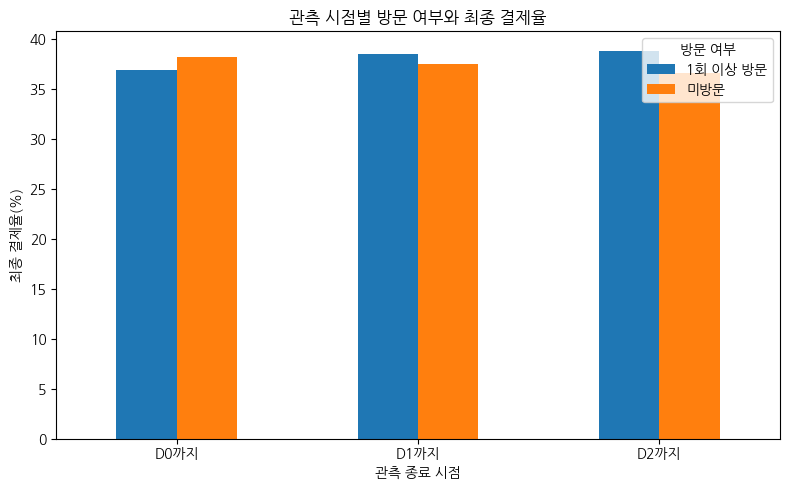

In [ ]:
# 방문 여부별 결제율 시각화

visit_plot = visit_conversion_summary.pivot(
    index="관측 범위",
    columns="방문 여부",
    values="결제율(%)",
).reindex(["D0까지", "D1까지", "D2까지"])

ax = visit_plot.plot(
    kind="bar",
    figsize=(8, 5),
)
ax.set_title("관측 시점별 방문 여부와 최종 결제율")
ax.set_xlabel("관측 종료 시점")
ax.set_ylabel("최종 결제율(%)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - D0에서는 방문·미방문 결제율이 거의 겹치지만 D1과 D2로 갈수록 방문자 쪽이 높아진다.
> - 전환과 연결된 행동 신호가 첫날보다 이후 날짜에서 형성되는 방향을 보여준다.


In [ ]:
# 일별 신규 행동 발생 패턴

landmark_day_analysis = landmark_day_df.merge(
    landmark_df[["user_id", "is_payment"]],
    on="user_id",
    how="left",
    validate="m:1",
)

incremental_behavior = (
    landmark_day_analysis
    .groupby(["day_from_trial", "is_payment"], as_index=False)
    .agg(
        사용자수=("user_id", "nunique"),
        당일_방문율=("daily_visit_flag", "mean"),
        평균_체크인=("daily_checkin_count", "mean"),
        평균_지점수=("daily_access_site_count", "mean"),
        체류확인율=("daily_stay_known_flag", "mean"),
    )
)

incremental_behavior["결제 여부"] = incremental_behavior[
    "is_payment"
].map({0: "미결제", 1: "결제"})

for column in ["당일_방문율", "체류확인율"]:
    incremental_behavior[column] *= 100

display(incremental_behavior.round(3))

,day_from_trial,is_payment,사용자수,당일_방문율,평균_체크인,평균_지점수,체류확인율,결제 여부
0,0,0,5972,17.582,0.604,1.005,17.565,미결제
1,0,1,3652,16.813,0.559,1.010,16.785,결제
2,1,0,5972,41.125,1.541,1.007,41.042,미결제
3,1,1,3652,44.962,1.552,1.004,44.852,결제
4,2,0,5972,31.597,1.139,1.005,31.48,미결제
5,2,1,3652,38.719,1.271,1.010,38.636,결제


> **💡 결과 해석**
>
> - 결제자의 당일 방문율은 D1 44.96%, D2 38.72%로 미결제자의 41.13%, 31.60%보다 높았다.
> - D0 방문율은 결제자가 오히려 소폭 낮아, 첫날 방문 자체보다 D1·D2까지 이용이 이어지는지가 더 구분력 있는 신호였다.


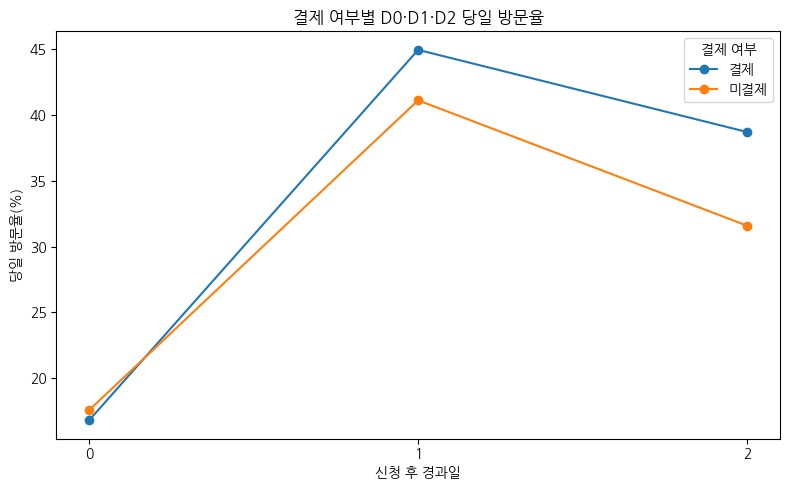

In [ ]:
# D0·D1·D2 당일 방문율 시각화

incremental_visit_plot = incremental_behavior.pivot(
    index="day_from_trial",
    columns="결제 여부",
    values="당일_방문율",
)

ax = incremental_visit_plot.plot(
    marker="o",
    figsize=(8, 5),
)
ax.set_title("결제 여부별 D0·D1·D2 당일 방문율")
ax.set_xlabel("신청 후 경과일")
ax.set_ylabel("당일 방문율(%)")
ax.set_xticks([0, 1, 2])
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - D0의 두 집단 차이는 거의 없지만 D1에서 격차가 생기고 D2에서 더 확대된다.
> - CRM 개입은 신호가 강해지는 동시에 남은 체험일이 존재하는 D1이 가장 실용적인 후보 시점이다.


In [ ]:
# 통계 검정 함수

def cramers_v(contingency_table):
    chi2, _, _, _ = chi2_contingency(contingency_table)
    n = contingency_table.to_numpy().sum()
    rows, columns = contingency_table.shape
    denominator = min(rows - 1, columns - 1)
    if denominator == 0:
        return np.nan
    return np.sqrt((chi2 / n) / denominator)


def rank_biserial_from_u(u_statistic, n_positive, n_negative):
    return 2 * u_statistic / (n_positive * n_negative) - 1

In [ ]:
# 방문 여부 두 비율 검정

visit_test_rows = []

for stage in ["M1", "M2", "M3"]:
    day = STAGE_TO_DAY[stage]
    visited = landmark_df[f"cum_visit_days_to_d{day}"].gt(0)

    pay_visited = int(y[visited].sum())
    n_visited = int(visited.sum())
    pay_not_visited = int(y[~visited].sum())
    n_not_visited = int((~visited).sum())

    z_statistic, p_value = proportions_ztest(
        count=[pay_visited, pay_not_visited],
        nobs=[n_visited, n_not_visited],
    )

    visit_test_rows.append({
        "모델": stage,
        "관측 범위": STAGE_LABEL[stage],
        "방문자 결제율(%)": pay_visited / n_visited * 100,
        "미방문자 결제율(%)": pay_not_visited / n_not_visited * 100,
        "차이(%p)": (
            pay_visited / n_visited
            - pay_not_visited / n_not_visited
        ) * 100,
        "z 통계량": z_statistic,
        "p-value": p_value,
    })

visit_proportion_tests = pd.DataFrame(visit_test_rows)
visit_proportion_tests["Holm 보정 p-value"] = multipletests(
    visit_proportion_tests["p-value"],
    method="holm",
)[1]

display(visit_proportion_tests.round(5))

,모델,관측 범위,방문자 결제율(%),미방문자 결제율(%),차이(%p),z 통계량,p-value,Holm 보정 p-value
0,M1,D0까지,36.89904,38.16583,-1.26679,-0.96848,0.33280,0.64248
1,M2,D1까지,38.41707,37.43490,0.98217,0.99191,0.32124,0.64248
2,M3,D2까지,38.78194,36.54808,2.23386,2.18501,0.02889,0.08666


> **💡 결과 해석**
>
> - 누적 방문 여부만 비교하면 D2의 원본 p-value는 0.0289였지만 Holm 보정 후 0.0867로 5% 기준에서 유의하지 않았다.
> - 방문했는지 여부 하나보다 방문일 수와 체류·출입 방식 등 세부 행동을 함께 보는 것이 필요하다.


In [ ]:
# D0·D1·D2 당일 방문 여부 두 비율 검정

daily_visit_target = (
    landmark_day_df[
        ["user_id", "day_from_trial", "daily_visit_flag"]
    ]
    .merge(
        landmark_df[["user_id", "is_payment"]],
        on="user_id",
        how="left",
        validate="m:1",
    )
)

daily_visit_test_rows = []

for day in [0, 1, 2]:
    day_data = daily_visit_target.loc[
        daily_visit_target["day_from_trial"].eq(day)
    ]

    visit_summary = (
        day_data
        .groupby("daily_visit_flag")["is_payment"]
        .agg(["sum", "count", "mean"])
    )

    visitor_success = int(visit_summary.loc[1, "sum"])
    visitor_total = int(visit_summary.loc[1, "count"])
    nonvisitor_success = int(visit_summary.loc[0, "sum"])
    nonvisitor_total = int(visit_summary.loc[0, "count"])

    z_statistic, p_value = proportions_ztest(
        count=[visitor_success, nonvisitor_success],
        nobs=[visitor_total, nonvisitor_total],
    )

    daily_visit_test_rows.append({
        "체험일": f"D{day}",
        "당일 방문자 수": visitor_total,
        "당일 방문자 결제율(%)": visitor_success / visitor_total * 100,
        "당일 미방문자 수": nonvisitor_total,
        "당일 미방문자 결제율(%)": (
            nonvisitor_success / nonvisitor_total * 100
        ),
        "차이(%p)": (
            visitor_success / visitor_total
            - nonvisitor_success / nonvisitor_total
        ) * 100,
        "z 통계량": z_statistic,
        "p-value": p_value,
    })

daily_visit_test_results = pd.DataFrame(daily_visit_test_rows)
daily_visit_test_results["Holm 보정 p-value"] = multipletests(
    daily_visit_test_results["p-value"],
    method="holm",
)[1]

display(daily_visit_test_results.round(5))

,체험일,당일 방문자 수,당일 방문자 결제율(%),당일 미방문자 수,당일 미방문자 결제율(%),차이(%p),z 통계량,p-value,Holm 보정 p-value
0,D0,1664,36.89904,7960,38.16583,-1.26679,-0.96848,0.33280,0.33280
1,D1,4098,40.06833,5526,36.37351,3.69482,3.69349,0.00022,0.00044
2,D2,3301,42.83550,6323,35.39459,7.44091,7.14107,0.00000,0.00000


> **💡 결과 해석**
>
> - 당일 방문자의 결제율은 D1에서 미방문자보다 3.69%p, D2에서는 7.44%p 높았고 두 차이 모두 보정 후 유의했다.
> - D0 차이는 유의하지 않아 전환 신호가 D1 이후 본격적으로 나타난다는 가설을 지지한다.


In [ ]:
# 누적 방문일 수와 결제 여부 카이제곱 검정

visit_day_test_rows = []
visit_day_tables = {}

for stage in ["M1", "M2", "M3"]:
    day = STAGE_TO_DAY[stage]
    visit_day_column = f"cum_visit_days_to_d{day}"

    contingency = pd.crosstab(
        landmark_df[visit_day_column],
        landmark_df["is_payment"],
    )
    chi2, p_value, degree_of_freedom, expected = chi2_contingency(
        contingency
    )

    visit_day_tables[stage] = contingency
    visit_day_test_rows.append({
        "모델": stage,
        "관측 범위": STAGE_LABEL[stage],
        "카이제곱": chi2,
        "자유도": degree_of_freedom,
        "p-value": p_value,
        "Cramer's V": cramers_v(contingency),
        "최소 기대빈도": expected.min(),
    })

visit_day_chi2_tests = pd.DataFrame(visit_day_test_rows)
visit_day_chi2_tests["Holm 보정 p-value"] = multipletests(
    visit_day_chi2_tests["p-value"],
    method="holm",
)[1]

display(visit_day_chi2_tests.round(5))

,모델,관측 범위,카이제곱,자유도,p-value,Cramer's V,최소 기대빈도,Holm 보정 p-value
0,M1,D0까지,0.88493,1,0.34686,0.00959,631.43475,0.34686
1,M2,D1까지,13.01100,2,0.00150,0.03677,283.08313,0.00299
2,M3,D2까지,51.98330,3,0.00000,0.07349,152.54613,0.00000


> **💡 결과 해석**
>
> - 누적 방문일 수와 결제 여부의 연관성은 D0에서 유의하지 않았지만 D1과 D2에서는 유의했다.
> - Cramer's V는 D1 0.037, D2 0.073으로 절대 효과는 작으므로, 강한 단독 예측변수보다 여러 행동 중 핵심 방향 신호로 해석한다.


In [ ]:
# 결제자·미결제자 체류시간 Mann–Whitney 검정

stay_test_rows = []

for stage in ["M1", "M2", "M3"]:
    day = STAGE_TO_DAY[stage]
    known_column = f"cum_stay_known_days_to_d{day}"
    stay_column = f"cum_stay_seconds_to_d{day}"

    known_df = landmark_df[
        landmark_df[known_column].gt(0)
    ].copy()

    payer_stay = (
        known_df.loc[known_df["is_payment"].eq(1), stay_column]
        .astype(float)
        / 3600
    )
    nonpayer_stay = (
        known_df.loc[known_df["is_payment"].eq(0), stay_column]
        .astype(float)
        / 3600
    )

    u_statistic, p_value = mannwhitneyu(
        payer_stay,
        nonpayer_stay,
        alternative="two-sided",
    )

    stay_test_rows.append({
        "모델": stage,
        "관측 범위": STAGE_LABEL[stage],
        "결제자 수": len(payer_stay),
        "미결제자 수": len(nonpayer_stay),
        "결제자 중앙시간": payer_stay.median(),
        "미결제자 중앙시간": nonpayer_stay.median(),
        "중앙값 차이(시간)": payer_stay.median() - nonpayer_stay.median(),
        "U 통계량": u_statistic,
        "rank-biserial": rank_biserial_from_u(
            u_statistic,
            len(payer_stay),
            len(nonpayer_stay),
        ),
        "p-value": p_value,
    })

stay_mannwhitney_tests = pd.DataFrame(stay_test_rows)
stay_mannwhitney_tests["Holm 보정 p-value"] = multipletests(
    stay_mannwhitney_tests["p-value"],
    method="holm",
)[1]

display(stay_mannwhitney_tests.round(5))

,모델,관측 범위,결제자 수,미결제자 수,결제자 중앙시간,미결제자 중앙시간,중앙값 차이(시간),U 통계량,rank-biserial,p-value,Holm 보정 p-value
0,M1,D0까지,613,1049,3.61694,4.22056,-0.60361,297948.5,-0.07331,0.01253,0.01253
1,M2,D1까지,1927,3087,3.97111,4.88972,-0.91861,2661677.0,-0.10512,0.00000,0.00000
2,M3,D2까지,2337,3686,5.13611,5.77875,-0.64264,4073160.5,-0.05431,0.00037,0.00075


> **💡 결과 해석**
>
> - 각 시점에서 결제자의 체류시간 중앙값은 미결제자보다 약 0.60~0.92시간 짧았다.
> - 통계적으로 유의하지만 효과크기는 -0.05~-0.11로 작아, 오래 머무는 행동이 높은 결제 의향을 직접 의미하지 않는다는 보조 근거로 사용한다.


#### 6-2-3-3. 모델 학습·교차검증과 신호 시점 결정

**🔹 분석 목적**

- 동일한 학습·테스트 분할에서 로지스틱 회귀, 의사결정나무, 랜덤포레스트, LightGBM, XGBoost 등을 비교한다.
- 불균형 이진분류이므로 ROC-AUC보다 PR-AUC를 우선 지표로 사용한다.
- M0~M3를 동일 알고리즘으로 비교해 행동 정보가 추가될 때의 순수한 성능 증가를 확인한다.
- OOF 예측과 paired bootstrap으로 단계별 PR-AUC 증가량의 신뢰구간을 계산한다.
- 최종 성능에 가장 먼저 근접하는 시점과 실제 개입 가능한 가장 이른 시점을 구분한다.


In [ ]:
# 고정 학습·테스트 분할

all_indices = np.arange(len(landmark_df))
train_indices, test_indices = train_test_split(
    all_indices,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

y_train = y.iloc[train_indices].reset_index(drop=True)
y_test = y.iloc[test_indices].reset_index(drop=True)

split_overview = pd.DataFrame({
    "구분": ["학습", "테스트"],
    "사용자 수": [len(train_indices), len(test_indices)],
    "결제율(%)": [y_train.mean() * 100, y_test.mean() * 100],
    "신청 시작일": [
        landmark_df.iloc[train_indices]["trial_date"].min().date(),
        landmark_df.iloc[test_indices]["trial_date"].min().date(),
    ],
    "신청 종료일": [
        landmark_df.iloc[train_indices]["trial_date"].max().date(),
        landmark_df.iloc[test_indices]["trial_date"].max().date(),
    ],
})

display(split_overview)

,구분,사용자 수,결제율(%),신청 시작일,신청 종료일
0,학습,7699,37.952981,2021-05-01,2023-12-31
1,테스트,1925,37.922078,2021-05-03,2023-12-31


> **✅ 데이터 분할**
>
> - 학습 7,699명과 테스트 1,925명의 결제율이 각각 37.95%, 37.92%로 거의 동일하다.
> - 무작위 층화 분할에서 타깃 비율이 안정적으로 유지되었다.


In [ ]:
# 전처리·모델 파이프라인 함수

def make_one_hot_encoder():
    try:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        )
    except TypeError:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse=False,
        )


def make_model_pipeline(estimator, feature_frame, scale_numeric=False):
    categorical_columns = [
        column
        for column in ["trial_month", "trial_weekday"]
        if column in feature_frame.columns
    ]
    numeric_columns = [
        column
        for column in feature_frame.columns
        if column not in categorical_columns
    ]

    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median")),
    ]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    transformers = []
    if numeric_columns:
        transformers.append((
            "numeric",
            Pipeline(numeric_steps),
            numeric_columns,
        ))
    if categorical_columns:
        transformers.append((
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", make_one_hot_encoder()),
            ]),
            categorical_columns,
        ))

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        sparse_threshold=0,
        verbose_feature_names_out=False,
    )

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", estimator),
    ])

In [ ]:
# 비교 모델 정의

available_models = {
    "Dummy": DummyClassifier(
        strategy="prior",
        random_state=RANDOM_STATE,
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        random_state=RANDOM_STATE,
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=40,
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=N_ESTIMATORS,
        min_samples_leaf=8,
        max_features="sqrt",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
}

optional_model_errors = {}

if RUN_OPTIONAL_MODELS:
    try:
        from lightgbm import LGBMClassifier

        available_models["LightGBM"] = LGBMClassifier(
            n_estimators=N_ESTIMATORS,
            learning_rate=0.035,
            num_leaves=31,
            min_child_samples=30,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_alpha=0.1,
            reg_lambda=0.5,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1,
        )
    except Exception as error:
        optional_model_errors["LightGBM"] = str(error)

    try:
        from catboost import CatBoostClassifier

        class CompatibleCatBoostClassifier(
            ClassifierMixin,
            BaseEstimator,
        ):
            def __init__(
                self,
                iterations=350,
                depth=6,
                learning_rate=0.035,
                loss_function="Logloss",
                verbose=False,
                allow_writing_files=False,
                random_seed=42,
                thread_count=-1,
            ):
                self.iterations = iterations
                self.depth = depth
                self.learning_rate = learning_rate
                self.loss_function = loss_function
                self.verbose = verbose
                self.allow_writing_files = allow_writing_files
                self.random_seed = random_seed
                self.thread_count = thread_count

            def fit(self, X, y):
                self.model_ = CatBoostClassifier(
                    iterations=self.iterations,
                    depth=self.depth,
                    learning_rate=self.learning_rate,
                    loss_function=self.loss_function,
                    verbose=self.verbose,
                    allow_writing_files=self.allow_writing_files,
                    random_seed=self.random_seed,
                    thread_count=self.thread_count,
                )
                self.model_.fit(X, y)
                self.classes_ = np.asarray(self.model_.classes_)
                self.n_features_in_ = X.shape[1]
                return self

            def predict_proba(self, X):
                return self.model_.predict_proba(X)

            def predict(self, X):
                return self.model_.predict(X).astype(int).ravel()

        available_models["CatBoost"] = CompatibleCatBoostClassifier(
            iterations=N_ESTIMATORS,
            depth=6,
            learning_rate=0.035,
            loss_function="Logloss",
            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1,
        )
    except Exception as error:
        optional_model_errors["CatBoost"] = str(error)

    try:
        from xgboost import XGBClassifier

        available_models["XGBoost"] = XGBClassifier(
            n_estimators=N_ESTIMATORS,
            learning_rate=0.035,
            max_depth=5,
            min_child_weight=3,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_alpha=0.1,
            reg_lambda=1.0,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    except Exception as error:
        optional_model_errors["XGBoost"] = str(error)

print("사용 모델:", list(available_models))
if optional_model_errors:
    print("선택 모델 불러오기 실패:", optional_model_errors)

사용 모델: ['Dummy', 'Logistic Regression', 'Decision Tree', 'Random Forest', 'LightGBM', 'XGBoost']
선택 모델 불러오기 실패: {'CatBoost': "No module named 'catboost'"}


> **✅ 모델 구성**
>
> - Dummy, 로지스틱 회귀, 의사결정나무, 랜덤포레스트, LightGBM, XGBoost를 비교 대상으로 사용했다.
> - CatBoost는 현재 환경에 설치되지 않아 제외되었으며, 핵심 비교에는 영향을 주지 않는다.


In [ ]:
# 교차검증 설정

cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

scoring = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "neg_brier": "neg_brier_score",
    "neg_log_loss": "neg_log_loss",
    "f1": make_scorer(f1_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
}

In [ ]:
# 전체 모델 교차검증

model_stage_cv_rows = []

for stage in STAGE_ORDER:
    X_stage = X_by_stage[stage].iloc[train_indices].reset_index(drop=True)

    for model_name, estimator in available_models.items():
        pipeline = make_model_pipeline(
            estimator=clone(estimator),
            feature_frame=X_stage,
            scale_numeric=model_name == "Logistic Regression",
        )

        scores = cross_validate(
            pipeline,
            X_stage,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=1,
            error_score="raise",
        )

        model_stage_cv_rows.append({
            "모델 시점": stage,
            "관측 범위": STAGE_LABEL[stage],
            "알고리즘": model_name,
            "PR-AUC 평균": scores["test_pr_auc"].mean(),
            "PR-AUC 표준편차": scores["test_pr_auc"].std(ddof=1),
            "ROC-AUC 평균": scores["test_roc_auc"].mean(),
            "Brier 평균": -scores["test_neg_brier"].mean(),
            "LogLoss 평균": -scores["test_neg_log_loss"].mean(),
            "F1 평균": scores["test_f1"].mean(),
            "Precision 평균": scores["test_precision"].mean(),
            "Recall 평균": scores["test_recall"].mean(),
        })

model_stage_cv_results = pd.DataFrame(model_stage_cv_rows)
model_stage_cv_results["모델 시점"] = pd.Categorical(
    model_stage_cv_results["모델 시점"],
    categories=STAGE_ORDER,
    ordered=True,
)
model_stage_cv_results = model_stage_cv_results.sort_values(
    ["모델 시점", "PR-AUC 평균"],
    ascending=[True, False],
).reset_index(drop=True)

display(model_stage_cv_results.round(4))

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LGBMClassifier was fitted with feature names

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, 

,모델 시점,관측 범위,알고리즘,PR-AUC 평균,PR-AUC 표준편차,ROC-AUC 평균,Brier 평균,LogLoss 평균,F1 평균,Precision 평균,Recall 평균
0,M0,신청 시점,Logistic Regression,0.4054,0.0066,0.5268,0.2353,0.6636,0.0000,0.0000,0.0000
1,M0,신청 시점,Decision Tree,0.3996,0.0069,0.5253,0.2358,0.6647,0.0474,0.3665,0.0257
2,M0,신청 시점,LightGBM,0.3972,0.0102,0.5196,0.2370,0.6671,0.0503,0.4647,0.0267
3,M0,신청 시점,XGBoost,0.3961,0.0133,0.5183,0.2375,0.6684,0.0541,0.4777,0.0294
4,M0,신청 시점,Random Forest,0.3958,0.0128,0.5177,0.2377,0.6688,0.0685,0.4472,0.0373
5,M0,신청 시점,Dummy,0.3795,0.0003,0.5000,0.2355,0.6638,0.0000,0.0000,0.0000
6,M1,D0까지,Logistic Regression,0.4043,0.0091,0.5252,0.2356,0.6642,0.0041,0.4833,0.0021
7,M1,D0까지,XGBoost,0.4030,0.0122,0.5301,0.2385,0.6717,0.1091,0.4414,0.0623
8,M1,D0까지,Random Forest,0.4022,0.0101,0.5293,0.2366,0.6663,0.0673,0.4257,0.0366
9,M1,D0까지,LightGBM,0.4018,0.0087,0.5280,0.2399,0.6761,0.1076,0.4149,0.0619


> **💡 결과 해석**
>
> - 각 시점과 알고리즘의 교차검증 성능을 비교한 결과, 행동 정보가 누적될수록 전반적인 PR-AUC가 상승했다.
> - 최종 알고리즘 선택은 M3 PR-AUC 평균과 1-SE 기준을 함께 사용해 과도한 복잡도 선택을 피한다.


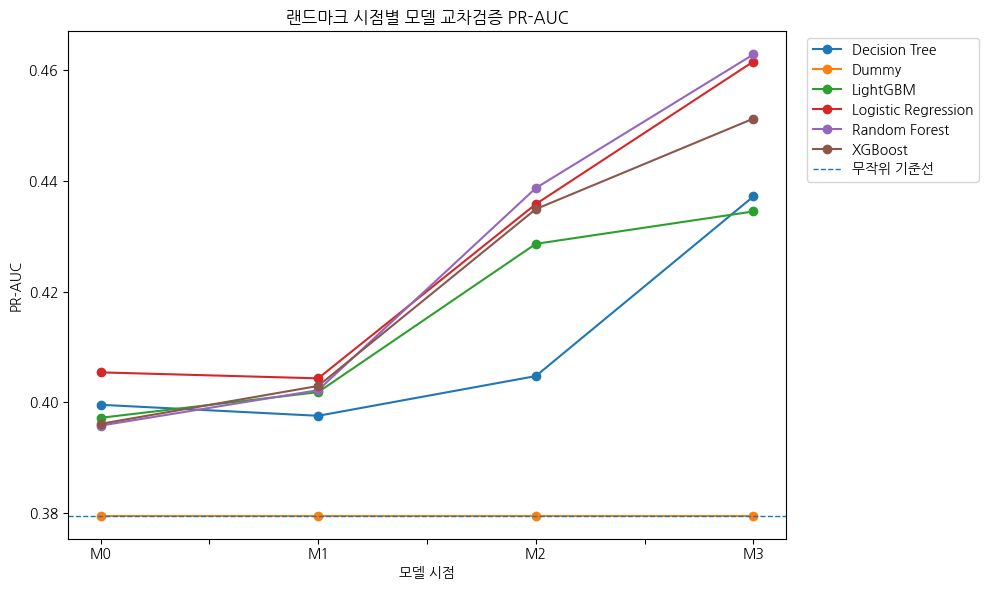

In [ ]:
# 모델별 PR-AUC 증가 시각화

cv_plot = model_stage_cv_results.pivot(
    index="모델 시점",
    columns="알고리즘",
    values="PR-AUC 평균",
).reindex(STAGE_ORDER)

ax = cv_plot.plot(
    marker="o",
    figsize=(10, 6),
)
ax.axhline(
    y=y_train.mean(),
    linestyle="--",
    linewidth=1,
    label="무작위 기준선",
)
ax.set_title("랜드마크 시점별 모델 교차검증 PR-AUC")
ax.set_xlabel("모델 시점")
ax.set_ylabel("PR-AUC")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 대부분의 알고리즘에서 M0보다 M1, M2, M3 순으로 PR-AUC가 높아진다.
> - 특정 모델 하나의 우연한 결과가 아니라 시점이 진행될수록 행동 신호가 누적되는 공통 방향을 확인했다.


In [ ]:
# M3 기준 알고리즘 선택 및 동률권 확인

m3_model_ranking = (
    model_stage_cv_results[
        model_stage_cv_results["모델 시점"].eq("M3")
        & model_stage_cv_results["알고리즘"].ne("Dummy")
    ]
    .sort_values("PR-AUC 평균", ascending=False)
    .reset_index(drop=True)
)

signal_model_name = m3_model_ranking.loc[0, "알고리즘"]
signal_model_estimator = clone(available_models[signal_model_name])

# 1-SE 규칙: 최고 모델 평균에서 최고 모델의 표준오차 이내면
# 실질적으로 비슷한 성능권으로 표시
best_cv_mean = float(m3_model_ranking.loc[0, "PR-AUC 평균"])
best_cv_se = float(
    m3_model_ranking.loc[0, "PR-AUC 표준편차"]
    / np.sqrt(CV_FOLDS)
)
one_se_cutoff = best_cv_mean - best_cv_se

m3_model_ranking["최고 모델과 차이"] = (
    best_cv_mean - m3_model_ranking["PR-AUC 평균"]
)
m3_model_ranking["1-SE 동률권"] = (
    m3_model_ranking["PR-AUC 평균"].ge(one_se_cutoff)
)

model_tie_names = (
    m3_model_ranking.loc[
        m3_model_ranking["1-SE 동률권"],
        "알고리즘",
    ]
    .tolist()
)

print("신호 시점 비교에 사용할 동일 알고리즘:", signal_model_name)
print("1-SE 기준 성능 동률권:", model_tie_names)
display(m3_model_ranking.round(4))

신호 시점 비교에 사용할 동일 알고리즘: Random Forest
1-SE 기준 성능 동률권: ['Random Forest', 'Logistic Regression']


,모델 시점,관측 범위,알고리즘,PR-AUC 평균,PR-AUC 표준편차,ROC-AUC 평균,Brier 평균,LogLoss 평균,F1 평균,Precision 평균,Recall 평균,최고 모델과 차이,1-SE 동률권
0,M3,D2까지,Random Forest,0.4628,0.0089,0.5713,0.2321,0.6572,0.2502,0.5379,0.1633,0.0000,True
1,M3,D2까지,Logistic Regression,0.4615,0.0113,0.5729,0.2311,0.6551,0.2009,0.5675,0.1222,0.0013,True
2,M3,D2까지,XGBoost,0.4512,0.0085,0.5639,0.2358,0.6669,0.2623,0.5135,0.1763,0.0116,False
3,M3,D2까지,Decision Tree,0.4372,0.0064,0.5644,0.2340,0.6613,0.1871,0.5197,0.1154,0.0257,False
4,M3,D2까지,LightGBM,0.4345,0.0072,0.5547,0.2403,0.6786,0.2682,0.4690,0.1879,0.0284,False


> **💡 결과 해석**
>
> - M3 교차검증 PR-AUC가 가장 높은 랜덤포레스트를 동일 알고리즘 시점 비교에 사용했다.
> - 로지스틱 회귀는 1-SE 성능 동률권에 포함되어, 비선형 모델만이 결과를 만드는 것은 아니었다.


In [ ]:
# 학습 세트 OOF 예측

signal_oof_predictions = {}
signal_oof_rows = []

for stage in STAGE_ORDER:
    X_stage_train = (
        X_by_stage[stage]
        .iloc[train_indices]
        .reset_index(drop=True)
    )

    pipeline = make_model_pipeline(
        estimator=clone(signal_model_estimator),
        feature_frame=X_stage_train,
        scale_numeric=signal_model_name == "Logistic Regression",
    )

    oof_probability = cross_val_predict(
        pipeline,
        X_stage_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1,
    )[:, 1]

    signal_oof_predictions[stage] = oof_probability
    signal_oof_rows.append({
        "모델 시점": stage,
        "관측 범위": STAGE_LABEL[stage],
        "PR-AUC": average_precision_score(y_train, oof_probability),
        "ROC-AUC": roc_auc_score(y_train, oof_probability),
        "Brier": brier_score_loss(y_train, oof_probability),
        "LogLoss": log_loss(y_train, oof_probability),
    })

signal_oof_performance = pd.DataFrame(signal_oof_rows)
signal_oof_performance["모델 시점"] = pd.Categorical(
    signal_oof_performance["모델 시점"],
    categories=STAGE_ORDER,
    ordered=True,
)
signal_oof_performance = signal_oof_performance.sort_values(
    "모델 시점"
).reset_index(drop=True)

display(signal_oof_performance.round(4))

,모델 시점,관측 범위,PR-AUC,ROC-AUC,Brier,LogLoss
0,M0,신청 시점,0.3928,0.5168,0.2377,0.6688
1,M1,D0까지,0.4007,0.5286,0.2366,0.6663
2,M2,D1까지,0.4351,0.5597,0.2339,0.6606
3,M3,D2까지,0.4607,0.5713,0.2321,0.6572


> **💡 결과 해석**
>
> - OOF PR-AUC는 M0 0.3928, M1 0.4007, M2 0.4351, M3 0.4607로 단계적으로 상승했다.
> - 가장 큰 증가가 D1 정보를 추가하는 M1→M2에서 나타나, D1이 전환 신호가 본격적으로 강화되는 시점임을 보여준다.


In [ ]:
# paired bootstrap 함수

def paired_bootstrap_metric_gain(
    y_true,
    earlier_probability,
    later_probability,
    metric_function,
    repeats=2000,
    random_state=42,
):
    y_true = np.asarray(y_true)
    earlier_probability = np.asarray(earlier_probability)
    later_probability = np.asarray(later_probability)
    rng = np.random.default_rng(random_state)
    gains = []

    for _ in range(repeats):
        sampled_indices = rng.integers(0, len(y_true), len(y_true))
        sampled_y = y_true[sampled_indices]

        if np.unique(sampled_y).size < 2:
            continue

        earlier_score = metric_function(
            sampled_y,
            earlier_probability[sampled_indices],
        )
        later_score = metric_function(
            sampled_y,
            later_probability[sampled_indices],
        )
        gains.append(later_score - earlier_score)

    gains = np.asarray(gains)
    return {
        "평균 향상": gains.mean(),
        "95%CI 하한": np.quantile(gains, 0.025),
        "95%CI 상한": np.quantile(gains, 0.975),
        "향상>0 비율": (gains > 0).mean(),
    }

In [ ]:
# 단계별 PR-AUC 증가량과 신뢰구간

transition_rows = []

for earlier_stage, later_stage in zip(
    STAGE_ORDER[:-1],
    STAGE_ORDER[1:],
):
    bootstrap_result = paired_bootstrap_metric_gain(
        y_true=y_train,
        earlier_probability=signal_oof_predictions[earlier_stage],
        later_probability=signal_oof_predictions[later_stage],
        metric_function=average_precision_score,
        repeats=BOOTSTRAP_REPEATS,
        random_state=RANDOM_STATE,
    )

    transition_rows.append({
        "전환": f"{earlier_stage} → {later_stage}",
        **bootstrap_result,
    })

stage_gain_bootstrap = pd.DataFrame(transition_rows)
display(stage_gain_bootstrap.round(4))

,전환,평균 향상,95%CI 하한,95%CI 상한,향상>0 비율
0,M0 → M1,0.0082,0.0004,0.0162,0.9805
1,M1 → M2,0.0346,0.0217,0.0480,1.0000
2,M2 → M3,0.0253,0.0129,0.0381,1.0000


> **💡 결과 해석**
>
> - OOF PR-AUC 평균 향상은 M0→M1 +0.0082, M1→M2 +0.0346, M2→M3 +0.0253이었다.
> - 세 구간 모두 향상 비율이 높았지만 D0 추가 효과보다 D1·D2 행동 추가 효과가 훨씬 컸다.


In [ ]:
# 조기 신호 포화 시점 자동 판정

final_pr_auc = float(
    signal_oof_performance.loc[
        signal_oof_performance["모델 시점"].eq("M3"),
        "PR-AUC",
    ].iloc[0]
)

signal_rule_rows = []

for stage in ["M1", "M2", "M3"]:
    stage_pr_auc = float(
        signal_oof_performance.loc[
            signal_oof_performance["모델 시점"].eq(stage),
            "PR-AUC",
        ].iloc[0]
    )
    attainment = stage_pr_auc / final_pr_auc if final_pr_auc else np.nan
    remaining_gain = final_pr_auc - stage_pr_auc
    rule_pass = (
        attainment >= SIGNAL_ATTAINMENT_RATIO
        and remaining_gain <= MAX_REMAINING_PR_AUC_GAIN
    )

    signal_rule_rows.append({
        "모델 시점": stage,
        "관측 범위": STAGE_LABEL[stage],
        "PR-AUC": stage_pr_auc,
        "M3 성능 도달률": attainment,
        "M3까지 남은 향상": remaining_gain,
        "기준 충족": rule_pass,
    })

signal_rule_table = pd.DataFrame(signal_rule_rows)
qualified_stages = signal_rule_table.loc[
    signal_rule_table["기준 충족"],
    "모델 시점",
].tolist()

signal_stage = qualified_stages[0] if qualified_stages else "M3"
signal_day_label = STAGE_LABEL[signal_stage]

if signal_stage == "M3":
    signal_timing_message = (
        "D0 또는 D1에서 성능이 조기에 포화되지 않았고, "
        "관측 가능한 마지막 날인 D2까지 구분력이 계속 증가했다."
    )
else:
    signal_timing_message = (
        f"{signal_day_label}에서 M3 성능의 대부분에 도달해 "
        "그 이후 추가 행동의 이득이 제한적이었다."
    )

display(signal_rule_table.round(4))

,모델 시점,관측 범위,PR-AUC,M3 성능 도달률,M3까지 남은 향상,기준 충족
0,M1,D0까지,0.4007,0.8696,0.0601,False
1,M2,D1까지,0.4351,0.9445,0.0256,False
2,M3,D2까지,0.4607,1.0000,0.0000,True


> **💡 결과 해석**
>
> - M2는 M3 최종 PR-AUC의 94.45%에 도달했으며 M3까지 0.0256의 향상이 남았다.
> - 자동 기준상 완전 포화는 M3이지만, D1 시점은 이미 대부분의 신호가 형성되고 D2 행동을 바꿀 시간이 남아 있는 **가장 이른 운영 개입점**이다.


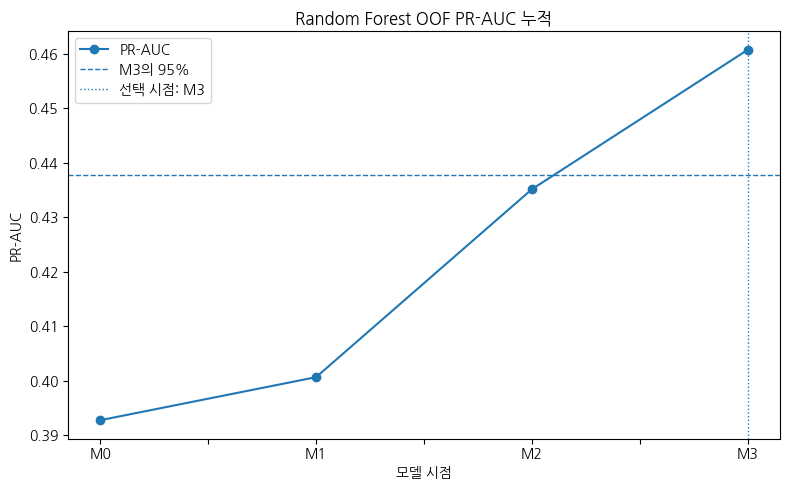

In [ ]:
# 신호 시점 시각화

signal_plot = signal_oof_performance.copy()
signal_plot["M3 성능 도달률"] = (
    signal_plot["PR-AUC"] / final_pr_auc * 100
)

ax = signal_plot.plot(
    x="모델 시점",
    y="PR-AUC",
    marker="o",
    figsize=(8, 5),
    legend=False,
)
ax.axhline(
    y=final_pr_auc * SIGNAL_ATTAINMENT_RATIO,
    linestyle="--",
    linewidth=1,
    label=f"M3의 {SIGNAL_ATTAINMENT_RATIO:.0%}",
)
ax.axvline(
    x=STAGE_ORDER.index(signal_stage),
    linestyle=":",
    linewidth=1,
    label=f"선택 시점: {signal_stage}",
)
ax.set_title(f"{signal_model_name} OOF PR-AUC 누적")
ax.set_xlabel("모델 시점")
ax.set_ylabel("PR-AUC")
ax.legend()
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 신호 성능은 D0에서 소폭, D1에서 크게, D2에서 추가로 상승한다.
> - 예측 성능의 최고점은 D2이지만 행동 개입 가능성을 고려하면 D1을 CRM 실행 시점으로 선택한다.


#### 6-2-3-4. 테스트 성능과 운영 기준 평가

**🔹 분석 목적**

- 독립 테스트 세트에서 M0~M3의 PR-AUC, ROC-AUC, Brier score, LogLoss를 평가한다.
- OOF와 테스트 결과가 같은 방향인지 확인하고 PR 곡선과 단계별 부트스트랩 증가량을 비교한다.
- F1 균형형과 Recall 80% 이상 운영 임계값을 산출해 실제 타겟 규모와 오탐 수준을 점검한다.
- 확률 10분위별 실제 결제율과 Lift를 계산해 개별 예측보다 우선순위 세그먼트로 활용 가능한지 판단한다.


In [ ]:
# 테스트 세트 시점별 평가

fitted_signal_pipelines = {}
signal_test_predictions = {}
signal_test_rows = []
test_base_rate = float(y_test.mean())

for stage in STAGE_ORDER:
    X_stage = X_by_stage[stage]
    X_stage_train = X_stage.iloc[train_indices].reset_index(drop=True)
    X_stage_test = X_stage.iloc[test_indices].reset_index(drop=True)

    pipeline = make_model_pipeline(
        estimator=clone(signal_model_estimator),
        feature_frame=X_stage_train,
        scale_numeric=signal_model_name == "Logistic Regression",
    )
    pipeline.fit(X_stage_train, y_train)
    test_probability = pipeline.predict_proba(X_stage_test)[:, 1]
    test_pr_auc = average_precision_score(y_test, test_probability)

    fitted_signal_pipelines[stage] = pipeline
    signal_test_predictions[stage] = test_probability
    signal_test_rows.append({
        "모델 시점": stage,
        "관측 범위": STAGE_LABEL[stage],
        "PR-AUC": test_pr_auc,
        "PR-AUC 기준선": test_base_rate,
        "기준선 대비 향상": test_pr_auc - test_base_rate,
        "정규화 PR-AUC": (
            (test_pr_auc - test_base_rate)
            / (1 - test_base_rate)
        ),
        "ROC-AUC": roc_auc_score(y_test, test_probability),
        "Brier": brier_score_loss(y_test, test_probability),
        "LogLoss": log_loss(y_test, test_probability),
    })

signal_test_performance = pd.DataFrame(signal_test_rows)
signal_test_performance["모델 시점"] = pd.Categorical(
    signal_test_performance["모델 시점"],
    categories=STAGE_ORDER,
    ordered=True,
)
signal_test_performance = signal_test_performance.sort_values(
    "모델 시점"
).reset_index(drop=True)

display(signal_test_performance.round(4))

,모델 시점,관측 범위,PR-AUC,PR-AUC 기준선,기준선 대비 향상,정규화 PR-AUC,ROC-AUC,Brier,LogLoss
0,M0,신청 시점,0.3840,0.3792,0.0048,0.0077,0.5022,0.2386,0.6709
1,M1,D0까지,0.3961,0.3792,0.0169,0.0272,0.5192,0.2370,0.6673
2,M2,D1까지,0.4250,0.3792,0.0458,0.0737,0.5568,0.2343,0.6615
3,M3,D2까지,0.4590,0.3792,0.0798,0.1285,0.5653,0.2325,0.6579


> **💡 결과 해석**
>
> - 테스트 PR-AUC는 M0 0.3840, M1 0.3961, M2 0.4250, M3 0.4590으로 OOF와 같은 상승 방향을 보였다.
> - M3 ROC-AUC는 0.5653으로 절대 구분력은 낮아, 개별 사용자 결제 예측보다 신호 시점 확인과 세그먼트 우선순위에 적합하다.


In [ ]:
# OOF와 테스트 성능 비교

performance_comparison = (
    signal_oof_performance[
        ["모델 시점", "PR-AUC", "ROC-AUC", "Brier"]
    ]
    .rename(columns={
        "PR-AUC": "OOF PR-AUC",
        "ROC-AUC": "OOF ROC-AUC",
        "Brier": "OOF Brier",
    })
    .merge(
        signal_test_performance[
            ["모델 시점", "PR-AUC", "ROC-AUC", "Brier"]
        ].rename(columns={
            "PR-AUC": "테스트 PR-AUC",
            "ROC-AUC": "테스트 ROC-AUC",
            "Brier": "테스트 Brier",
        }),
        on="모델 시점",
        how="left",
    )
)

display(performance_comparison.round(4))

,모델 시점,OOF PR-AUC,OOF ROC-AUC,OOF Brier,테스트 PR-AUC,테스트 ROC-AUC,테스트 Brier
0,M0,0.3928,0.5168,0.2377,0.3840,0.5022,0.2386
1,M1,0.4007,0.5286,0.2366,0.3961,0.5192,0.2370
2,M2,0.4351,0.5597,0.2339,0.4250,0.5568,0.2343
3,M3,0.4607,0.5713,0.2321,0.4590,0.5653,0.2325


> **✅ 일반화 점검**
>
> - OOF와 테스트의 PR-AUC·ROC-AUC가 모든 시점에서 유사해 무작위 분할 내 과적합은 크지 않았다.
> - 성능 수준 자체는 낮지만 시점별 증가 패턴은 안정적으로 재현되었다.


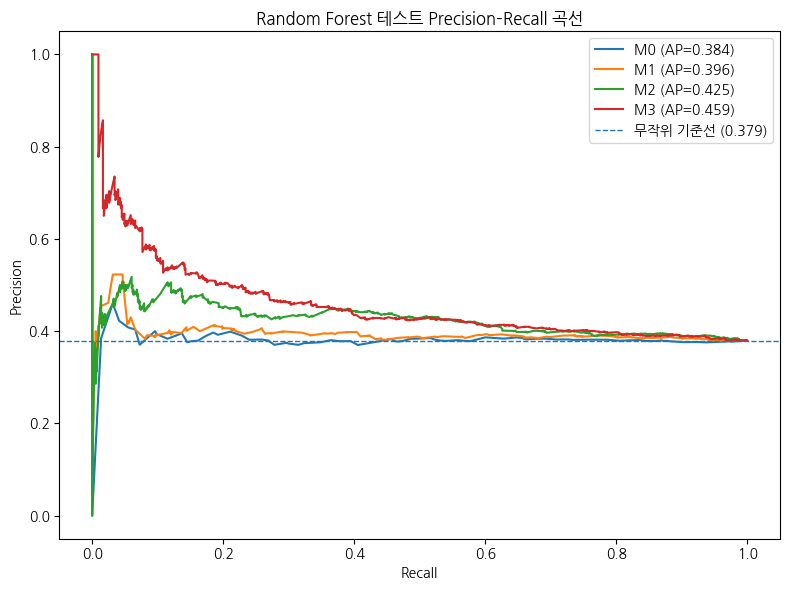

In [ ]:
# 테스트 PR 곡선

fig, ax = plt.subplots(figsize=(8, 6))

for stage in STAGE_ORDER:
    precision_values, recall_values, _ = precision_recall_curve(
        y_test,
        signal_test_predictions[stage],
    )
    stage_ap = average_precision_score(
        y_test,
        signal_test_predictions[stage],
    )
    ax.plot(
        recall_values,
        precision_values,
        label=f"{stage} (AP={stage_ap:.3f})",
    )

ax.axhline(
    y=y_test.mean(),
    linestyle="--",
    linewidth=1,
    label=f"무작위 기준선 ({y_test.mean():.3f})",
)
ax.set_title(f"{signal_model_name} 테스트 Precision–Recall 곡선")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - PR 곡선은 M0·M1보다 M2·M3에서 상단으로 이동하지만 곡선 간 격차는 제한적이다.
> - 모델이 완전한 분류기라기보다 상위 전환 신호 집단을 선별하는 보조 도구임을 보여준다.


In [ ]:
# 테스트 단계별 증가량 paired bootstrap

test_transition_rows = []

for earlier_stage, later_stage in zip(
    STAGE_ORDER[:-1],
    STAGE_ORDER[1:],
):
    bootstrap_result = paired_bootstrap_metric_gain(
        y_true=y_test,
        earlier_probability=signal_test_predictions[earlier_stage],
        later_probability=signal_test_predictions[later_stage],
        metric_function=average_precision_score,
        repeats=BOOTSTRAP_REPEATS,
        random_state=RANDOM_STATE,
    )
    test_transition_rows.append({
        "전환": f"{earlier_stage} → {later_stage}",
        **bootstrap_result,
    })

test_stage_gain_bootstrap = pd.DataFrame(test_transition_rows)
display(test_stage_gain_bootstrap.round(4))

,전환,평균 향상,95%CI 하한,95%CI 상한,향상>0 비율
0,M0 → M1,0.0124,-0.0036,0.0289,0.9300
1,M1 → M2,0.0286,0.0033,0.0546,0.9895
2,M2 → M3,0.0333,0.0083,0.0589,0.9950


> **💡 결과 해석**
>
> - 테스트 PR-AUC 향상 신뢰구간은 M0→M1에서 0을 포함했지만, M1→M2와 M2→M3는 0보다 큰 구간이었다.
> - 첫날 행동 추가만으로는 개선이 불확실하고 D1 이후 행동이 추가될 때 성능 향상이 더 안정적이었다.


In [ ]:
# 운영 임계값 선택

signal_oof_probability = signal_oof_predictions[signal_stage]
signal_test_probability = signal_test_predictions[signal_stage]

threshold_grid = np.linspace(0.01, 0.99, 199)
threshold_rows = []

for threshold in threshold_grid:
    predicted_label = (signal_oof_probability >= threshold).astype(int)
    threshold_rows.append({
        "임계값": threshold,
        "Precision": precision_score(
            y_train,
            predicted_label,
            zero_division=0,
        ),
        "Recall": recall_score(y_train, predicted_label),
        "F1": f1_score(y_train, predicted_label),
    })

threshold_search = pd.DataFrame(threshold_rows)
f1_threshold = float(
    threshold_search.sort_values(
        ["F1", "Recall"],
        ascending=False,
    ).iloc[0]["임계값"]
)

recall_candidates = threshold_search[
    threshold_search["Recall"].ge(0.80)
]
recall80_threshold = float(
    recall_candidates.sort_values(
        ["Precision", "임계값"],
        ascending=False,
    ).iloc[0]["임계값"]
)

selected_thresholds = pd.DataFrame({
    "운영안": ["F1 균형형", "Recall 80% 이상"],
    "임계값": [f1_threshold, recall80_threshold],
})

display(selected_thresholds.round(4))

,운영안,임계값
0,F1 균형형,0.2327
1,Recall 80% 이상,0.3020


> **✅ 운영 임계값**
>
> - OOF 예측에서 F1 균형형 임계값은 0.2327, Recall 80% 이상 임계값은 0.3020으로 산출되었다.
> - 임계값은 확정 정책이 아니라 테스트 세트에서 실제 타겟 규모와 오탐을 비교하기 위한 후보 기준이다.


In [ ]:
# 테스트 임계값별 성능

def evaluate_threshold(y_true, probability, threshold, label):
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, prediction).ravel()
    return {
        "운영안": label,
        "임계값": threshold,
        "양성 예측 비율": prediction.mean(),
        "Precision": precision_score(
            y_true,
            prediction,
            zero_division=0,
        ),
        "Recall": recall_score(y_true, prediction),
        "F1": f1_score(y_true, prediction),
        "특이도": tn / (tn + fp),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
    }

threshold_test_results = pd.DataFrame([
    evaluate_threshold(
        y_test,
        signal_test_probability,
        f1_threshold,
        "F1 균형형",
    ),
    evaluate_threshold(
        y_test,
        signal_test_probability,
        recall80_threshold,
        "Recall 80% 이상",
    ),
])

display(threshold_test_results.round(4))

,운영안,임계값,양성 예측 비율,Precision,Recall,F1,특이도,TP,FP,FN,TN
0,F1 균형형,0.2327,0.9610,0.3816,0.9671,0.5473,0.0427,706,1144,24,51
1,Recall 80% 이상,0.3020,0.7995,0.3918,0.8260,0.5315,0.2167,603,936,127,259


> **💡 결과 해석**
>
> - F1 균형형은 사용자의 96.10%를 양성으로 분류해 실질적인 타겟 압축이 거의 되지 않았다.
> - Recall 80% 기준도 79.95%를 타겟으로 잡고 Precision은 39.18%에 그쳐, 현재 모델은 개인 단위 자동 의사결정보다 넓은 CRM 세그먼트에 적합하다.


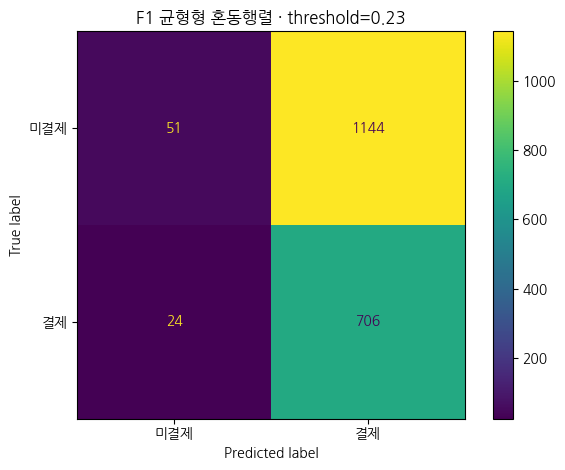

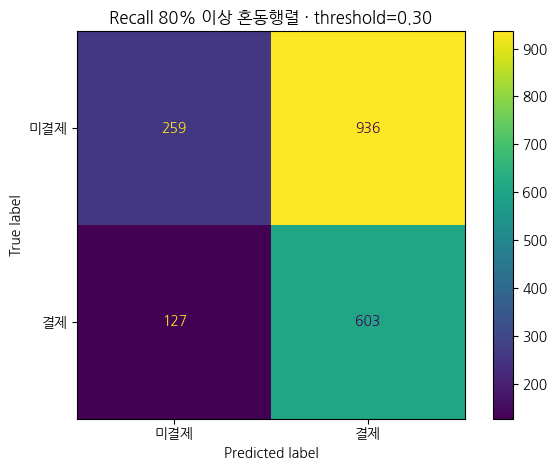

In [ ]:
# 혼동행렬

for label, threshold in [
    ("F1 균형형", f1_threshold),
    ("Recall 80% 이상", recall80_threshold),
]:
    prediction = (signal_test_probability >= threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        prediction,
        display_labels=["미결제", "결제"],
        values_format="d",
    )
    plt.title(f"{label} 혼동행렬 · threshold={threshold:.2f}")
    plt.tight_layout()
    plt.show()

> **📊 시각화 해석**
>
> - 두 임계값 모두 거짓양성(FP)이 많아 높은 재현율을 얻는 대신 많은 비결제자를 함께 타겟팅한다.
> - 비용이 큰 혜택을 자동 지급하기보다 저비용 메시지 실험이나 상위 분위 선별에 사용하는 것이 안전하다.


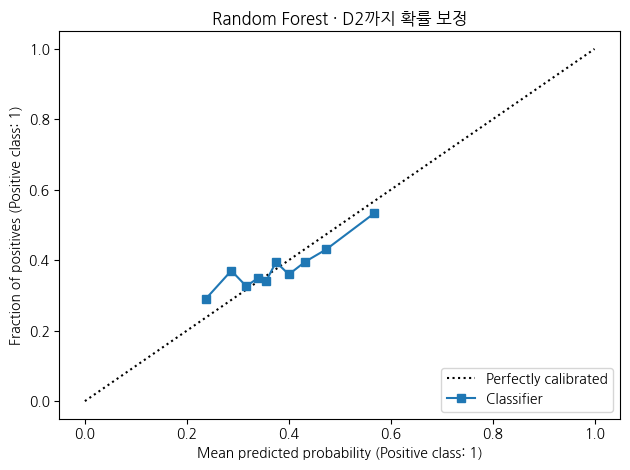

In [ ]:
# 확률 보정 확인

final_pipeline = fitted_signal_pipelines[signal_stage]
X_signal_test = (
    X_by_stage[signal_stage]
    .iloc[test_indices]
    .reset_index(drop=True)
)

CalibrationDisplay.from_predictions(
    y_test,
    signal_test_probability,
    n_bins=10,
    strategy="quantile",
)
plt.title(
    f"{signal_model_name} · {signal_day_label} 확률 보정"
)
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 보정 곡선은 예측확률과 실제 결제율의 일치 정도를 점검한다.
> - 절대확률을 가격·혜택 결정에 직접 사용하기보다 분위별 상대 순위로 활용하는 편이 적절하다.


In [ ]:
# 확률 10분위 Lift·누적 포착률

lift_df = pd.DataFrame({
    "실제 결제": y_test.to_numpy(),
    "예측 확률": signal_test_probability,
})

lift_df["확률 분위"] = pd.qcut(
    lift_df["예측 확률"].rank(method="first"),
    q=10,
    labels=range(1, 11),
).astype(int)

lift_table = (
    lift_df
    .groupby("확률 분위", as_index=False)
    .agg(
        사용자수=("실제 결제", "size"),
        결제자수=("실제 결제", "sum"),
        실제_결제율=("실제 결제", "mean"),
        평균_예측확률=("예측 확률", "mean"),
    )
    .sort_values("확률 분위", ascending=False)
)

base_rate = y_test.mean()
lift_table["Lift"] = lift_table["실제_결제율"] / base_rate
lift_table["누적 사용자수"] = lift_table["사용자수"].cumsum()
lift_table["누적 결제자수"] = lift_table["결제자수"].cumsum()
lift_table["누적 결제자 포착률"] = (
    lift_table["누적 결제자수"] / lift_table["결제자수"].sum()
)

for column in [
    "실제_결제율",
    "평균_예측확률",
    "누적 결제자 포착률",
]:
    lift_table[column] *= 100

display(lift_table.round(2))

,확률 분위,사용자수,결제자수,실제_결제율,평균_예측확률,Lift,누적 사용자수,누적 결제자수,누적 결제자 포착률
9,10,193,103,53.37,56.81,1.41,193,103,14.11
8,9,192,83,43.23,47.31,1.14,385,186,25.48
7,8,193,76,39.38,43.21,1.04,578,262,35.89
6,7,192,68,35.42,40.00,0.93,770,330,45.21
5,6,192,77,40.10,37.49,1.06,962,407,55.75
4,5,193,66,34.20,35.60,0.90,1155,473,64.79
3,4,192,67,34.90,33.93,0.92,1347,540,73.97
2,3,193,63,32.64,31.66,0.86,1540,603,82.60
1,2,192,70,36.46,28.71,0.96,1732,673,92.19
0,1,193,57,29.53,23.70,0.78,1925,730,100.00


> **💡 결과 해석**
>
> - 예측확률 상위 10%의 실제 결제율은 53.37%로 전체 테스트 결제율 대비 Lift 1.41을 보였다.
> - 상위 20%까지 누적하면 결제자의 약 25.48%를 포착해, 제한적이지만 CRM 우선순위 세그먼트로 활용할 가능성이 있다.


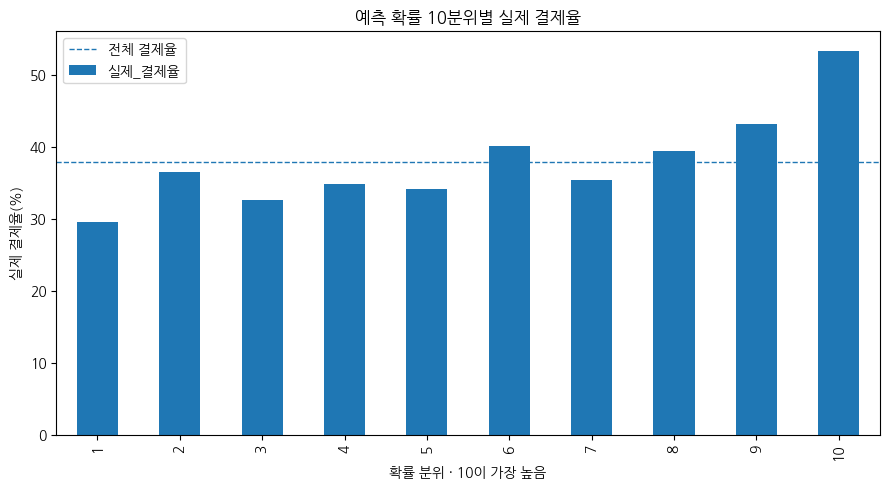

In [ ]:
# 확률 분위별 실제 결제율

lift_plot = lift_table.sort_values("확률 분위")
ax = lift_plot.plot(
    x="확률 분위",
    y="실제_결제율",
    kind="bar",
    figsize=(9, 5),
    legend=False,
)
ax.axhline(
    y=base_rate * 100,
    linestyle="--",
    linewidth=1,
    label="전체 결제율",
)
ax.set_title("예측 확률 10분위별 실제 결제율")
ax.set_xlabel("확률 분위 · 10이 가장 높음")
ax.set_ylabel("실제 결제율(%)")
ax.legend()
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 상위 분위의 실제 결제율이 전반적으로 높지만 중간 분위에서는 완전한 단조 증가가 나타나지 않는다.
> - 순위화 능력은 일부 존재하나 세밀한 개인별 확률 해석에는 한계가 있다.


#### 6-2-3-5. 모델 해석과 추가 튜닝

**🔹 분석 목적**

- 로지스틱 회귀 계수, Permutation Importance, SHAP을 함께 확인해 특정 해석 기법에 의존하지 않는다.
- 누적 방문일 수, 체류시간, 일평균 체류시간, 달력 정보가 예측에 기여하는 방향과 중요도를 비교한다.
- 얕은 의사결정나무로 모델이 사용한 대표적인 분기 규칙을 탐색한다.
- Optuna 튜닝은 실행 옵션에 따라 선택적으로 수행하며, 핵심 결론은 기본 비교 결과에 기반한다.


In [ ]:
# 로지스틱 회귀 계수와 오즈비

logistic_pipeline = make_model_pipeline(
    estimator=clone(available_models["Logistic Regression"]),
    feature_frame=X_signal_test,
    scale_numeric=True,
)

X_signal_train = (
    X_by_stage[signal_stage]
    .iloc[train_indices]
    .reset_index(drop=True)
)
logistic_pipeline.fit(X_signal_train, y_train)

logistic_feature_names = (
    logistic_pipeline
    .named_steps["preprocess"]
    .get_feature_names_out()
)
logistic_coefficients = (
    logistic_pipeline
    .named_steps["model"]
    .coef_[0]
)

logistic_odds_ratio = pd.DataFrame({
    "변수": logistic_feature_names,
    "표준화 계수": logistic_coefficients,
    "오즈비": np.exp(logistic_coefficients),
    "절대 계수": np.abs(logistic_coefficients),
}).sort_values("절대 계수", ascending=False)

display(logistic_odds_ratio.head(25).round(4))

,변수,표준화 계수,오즈비,절대 계수
14,access_only_share,-0.5123,0.5991,0.5123
6,cum_access_only_visit_days,0.4503,1.5689,0.4503
1,cum_stay_hours,-0.4395,0.6444,0.4395
0,cum_visit_days,0.3279,1.3881,0.3279
19,trial_month_5,0.3026,1.3534,0.3026
26,trial_month_12,-0.2712,0.7625,0.2712
11,sites_per_visit_day,-0.2171,0.8049,0.2171
23,trial_month_9,-0.2029,0.8163,0.2029
20,trial_month_6,0.1876,1.2063,0.1876
4,cum_distinct_site_count,0.1422,1.1528,0.1422


> **💡 결과 해석**
>
> - 로지스틱 회귀에서는 누적 방문일 수가 양의 방향, 누적 체류시간과 access-only 비중은 음의 방향으로 나타났다.
> - 달력 변수도 상위 계수에 포함되어 행동뿐 아니라 시기별 결제 환경 변화가 모델에 반영되었다.
> - 계수는 다른 변수를 고정한 조건부 연관이며 단독 정책 효과로 해석하지 않는다.


In [ ]:
# Permutation Importance

permutation_result = permutation_importance(
    final_pipeline,
    X_signal_test,
    y_test,
    scoring="average_precision",
    n_repeats=20 if FULL_RUN else 5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

permutation_importance_table = pd.DataFrame({
    "변수": X_signal_test.columns,
    "PR-AUC 감소 평균": permutation_result.importances_mean,
    "PR-AUC 감소 표준편차": permutation_result.importances_std,
}).sort_values("PR-AUC 감소 평균", ascending=False)

display(permutation_importance_table.round(5))

,변수,PR-AUC 감소 평균,PR-AUC 감소 표준편차
10,avg_stay_hours_per_visit_day,0.02753,0.00615
0,trial_month,0.01720,0.00588
3,cum_stay_hours,0.01250,0.00533
1,trial_weekday,0.00848,0.00287
2,cum_visit_days,0.00748,0.00560
7,cum_stay_known_days,0.00635,0.00576
12,checkout_per_visit_day,0.00301,0.00243
5,cum_checkout_count,0.00173,0.00253
14,checkin_checkout_gap,0.00106,0.00140
15,stay_known_share,0.00038,0.00090


> **💡 결과 해석**
>
> - Permutation Importance에서는 일평균 체류시간, 신청 월, 누적 체류시간, 신청 요일, 누적 방문일 수가 주요 변수였다.
> - 방문 지속성과 체류 강도, 시기 정보가 함께 결제 구분에 기여하며 단일 변수만으로는 충분하지 않았다.


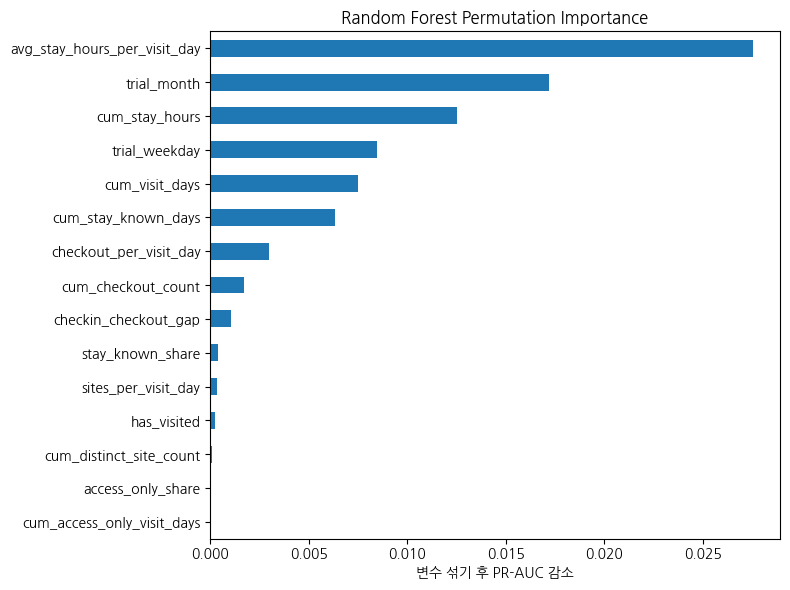

In [ ]:
# Permutation Importance 시각화

permutation_plot = (
    permutation_importance_table
    .head(15)
    .sort_values("PR-AUC 감소 평균")
)

ax = permutation_plot.plot(
    x="변수",
    y="PR-AUC 감소 평균",
    kind="barh",
    figsize=(8, 6),
    legend=False,
)
ax.set_title(f"{signal_model_name} Permutation Importance")
ax.set_xlabel("변수 섞기 후 PR-AUC 감소")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 중요도 상위에는 일평균 체류시간과 달력 정보, 누적 방문·체류 변수가 함께 위치한다.
> - 지점 수와 단순 체크인 합계의 추가 중요도는 상대적으로 작아 반복 방문 중심 결론과 일치한다.


,변수,평균 절대 SHAP
8,avg_stay_hours_per_visit_day,0.02178
0,cum_visit_days,0.01725
5,cum_stay_known_days,0.01646
1,cum_stay_hours,0.01267
19,trial_month_5,0.00792
11,sites_per_visit_day,0.00716
26,trial_month_12,0.00665
23,trial_month_9,0.00541
20,trial_month_6,0.00506
10,checkout_per_visit_day,0.00452


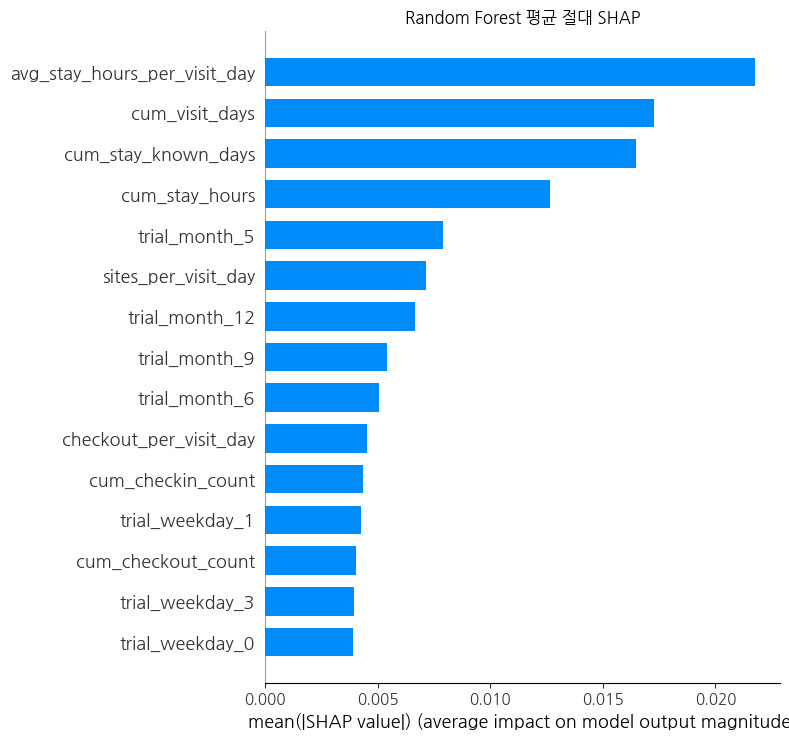

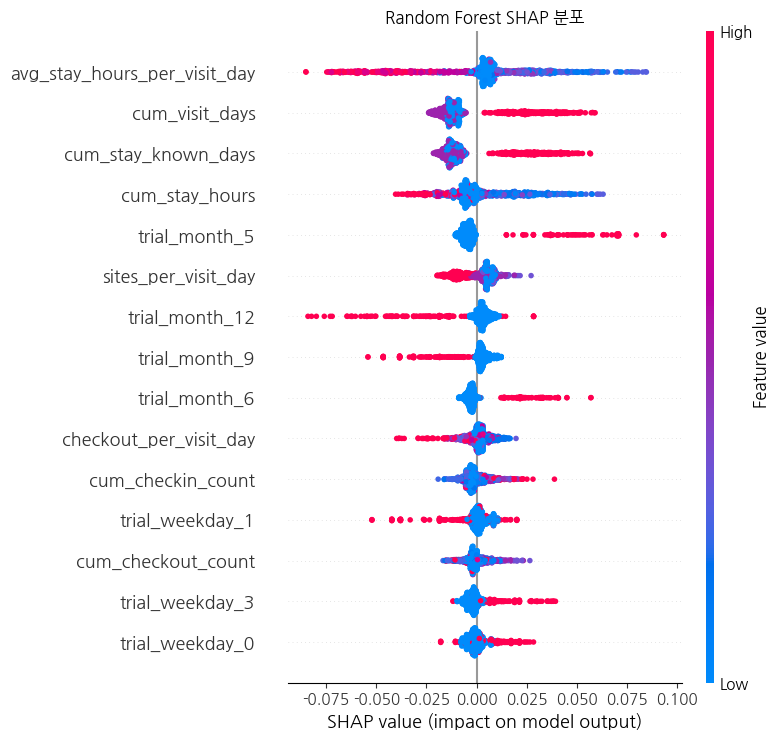

In [ ]:
# SHAP 분석

shap_importance_table = pd.DataFrame()

if RUN_SHAP:
    import shap

    tree_model_names = [
        name
        for name in [
            "LightGBM",
            "CatBoost",
            "XGBoost",
            "Random Forest",
            "Decision Tree",
        ]
        if name in available_models
    ]

    tree_model_ranking = (
        model_stage_cv_results[
            model_stage_cv_results["모델 시점"].eq("M3")
            & model_stage_cv_results["알고리즘"].isin(tree_model_names)
        ]
        .sort_values("PR-AUC 평균", ascending=False)
        .reset_index(drop=True)
    )

    shap_model_name = tree_model_ranking.loc[0, "알고리즘"]
    shap_pipeline = make_model_pipeline(
        estimator=clone(available_models[shap_model_name]),
        feature_frame=X_signal_train,
        scale_numeric=False,
    )
    shap_pipeline.fit(X_signal_train, y_train)

    shap_preprocessor = shap_pipeline.named_steps["preprocess"]
    shap_model = shap_pipeline.named_steps["model"]
    if hasattr(shap_model, "model_"):
        shap_model = shap_model.model_
    shap_feature_names = shap_preprocessor.get_feature_names_out()

    rng = np.random.default_rng(RANDOM_STATE)
    explain_count = min(1000, len(X_signal_test))
    explain_indices = rng.choice(
        len(X_signal_test),
        size=explain_count,
        replace=False,
    )

    X_shap = shap_preprocessor.transform(
        X_signal_test.iloc[explain_indices]
    )

    tree_explainer = shap.TreeExplainer(shap_model)
    raw_shap_values = tree_explainer.shap_values(X_shap)

    if isinstance(raw_shap_values, list):
        shap_values = np.asarray(raw_shap_values[-1])
    else:
        shap_values = np.asarray(raw_shap_values)

    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, -1]

    shap_importance_table = pd.DataFrame({
        "변수": shap_feature_names,
        "평균 절대 SHAP": np.abs(shap_values).mean(axis=0),
    }).sort_values("평균 절대 SHAP", ascending=False)

    display(shap_importance_table.head(20).round(5))

    shap.summary_plot(
        shap_values,
        X_shap,
        feature_names=shap_feature_names,
        plot_type="bar",
        max_display=15,
        show=False,
    )
    plt.title(f"{shap_model_name} 평균 절대 SHAP")
    plt.tight_layout()
    plt.show()

    shap.summary_plot(
        shap_values,
        X_shap,
        feature_names=shap_feature_names,
        max_display=15,
        show=False,
    )
    plt.title(f"{shap_model_name} SHAP 분포")
    plt.tight_layout()
    plt.show()
else:
    print("RUN_SHAP=False: SHAP 분석 생략")

> **💡 결과 해석**
>
> - SHAP에서도 일평균 체류시간, 누적 방문일 수, 체류 확인 일수, 누적 체류시간이 상위 변수로 나타났다.
> - 서로 다른 해석 방법에서 방문 지속성과 체류 패턴이 반복적으로 중요하게 나타나 결과의 방향성이 일치했다.


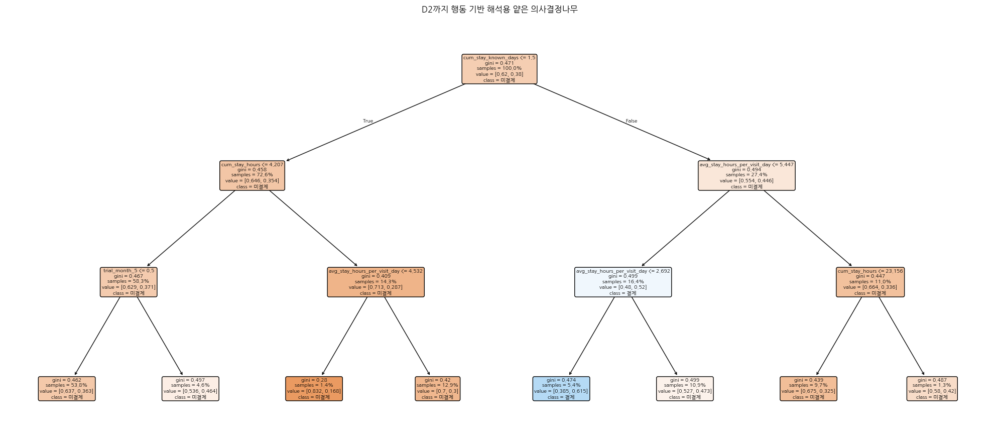

|--- cum_stay_known_days <= 1.500
|   |--- cum_stay_hours <= 4.207
|   |   |--- trial_month_5 <= 0.500
|   |   |   |--- class: 0
|   |   |--- trial_month_5 >  0.500
|   |   |   |--- class: 0
|   |--- cum_stay_hours >  4.207
|   |   |--- avg_stay_hours_per_visit_day <= 4.532
|   |   |   |--- class: 0
|   |   |--- avg_stay_hours_per_visit_day >  4.532
|   |   |   |--- class: 0
|--- cum_stay_known_days >  1.500
|   |--- avg_stay_hours_per_visit_day <= 5.447
|   |   |--- avg_stay_hours_per_visit_day <= 2.692
|   |   |   |--- class: 1
|   |   |--- avg_stay_hours_per_visit_day >  2.692
|   |   |   |--- class: 0
|   |--- avg_stay_hours_per_visit_day >  5.447
|   |   |--- cum_stay_hours <= 23.156
|   |   |   |--- class: 0
|   |   |--- cum_stay_hours >  23.156
|   |   |   |--- class: 0



In [ ]:
# 얕은 의사결정나무 규칙 확인

rule_tree = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=100,
    random_state=RANDOM_STATE,
)
rule_pipeline = make_model_pipeline(
    estimator=rule_tree,
    feature_frame=X_signal_train,
    scale_numeric=False,
)
rule_pipeline.fit(X_signal_train, y_train)

rule_feature_names = (
    rule_pipeline
    .named_steps["preprocess"]
    .get_feature_names_out()
)
rule_model = rule_pipeline.named_steps["model"]

plt.figure(figsize=(20, 9))
plot_tree(
    rule_model,
    feature_names=rule_feature_names,
    class_names=["미결제", "결제"],
    filled=True,
    rounded=True,
    proportion=True,
)
plt.title(f"{signal_day_label} 행동 기반 해석용 얕은 의사결정나무")
plt.tight_layout()
plt.show()

print(export_text(
    rule_model,
    feature_names=list(rule_feature_names),
    decimals=3,
))

> **💡 결과 해석**
>
> - 얕은 의사결정나무는 체류 확인 일수가 2일 이상인 구간을 주요 분기로 사용했고, 그 안에서 일평균 체류시간을 추가로 구분했다.
> - 단순히 총 체류시간이 큰 사용자보다 여러 날짜에 걸친 적정 체류 패턴이 중요한 신호라는 탐색 결과와 연결된다.


In [ ]:
# Optuna 기반 XGBoost 튜닝

optuna_study = None
optuna_test_result = pd.DataFrame()
tuned_xgb_pipeline = None

if RUN_OPTUNA and "XGBoost" in available_models:

    optuna.logging.set_verbosity(optuna.logging.WARNING)

    def xgb_objective(trial):
        estimator = XGBClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 150, 600
            ),
            learning_rate=trial.suggest_float(
                "learning_rate", 0.01, 0.15, log=True
            ),
            max_depth=trial.suggest_int("max_depth", 3, 8),
            min_child_weight=trial.suggest_int(
                "min_child_weight", 1, 10
            ),
            subsample=trial.suggest_float("subsample", 0.65, 1.0),
            colsample_bytree=trial.suggest_float(
                "colsample_bytree", 0.65, 1.0
            ),
            gamma=trial.suggest_float("gamma", 0.0, 3.0),
            reg_alpha=trial.suggest_float(
                "reg_alpha", 1e-4, 3.0, log=True
            ),
            reg_lambda=trial.suggest_float(
                "reg_lambda", 1e-3, 10.0, log=True
            ),
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )

        pipeline = make_model_pipeline(
            estimator=estimator,
            feature_frame=X_signal_train,
            scale_numeric=False,
        )

        scores = cross_val_score(
            pipeline,
            X_signal_train,
            y_train,
            cv=cv,
            scoring="average_precision",
            n_jobs=1,
        )
        return scores.mean()

    optuna_study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        ),
    )
    optuna_study.optimize(
        xgb_objective,
        n_trials=OPTUNA_TRIALS,
        show_progress_bar=True,
    )

    best_xgb = XGBClassifier(
        **optuna_study.best_params,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

    tuned_xgb_pipeline = make_model_pipeline(
        estimator=best_xgb,
        feature_frame=X_signal_train,
        scale_numeric=False,
    )
    tuned_xgb_pipeline.fit(X_signal_train, y_train)
    tuned_probability = tuned_xgb_pipeline.predict_proba(
        X_signal_test
    )[:, 1]

    baseline_xgb_pipeline = make_model_pipeline(
        estimator=clone(available_models["XGBoost"]),
        feature_frame=X_signal_train,
        scale_numeric=False,
    )
    baseline_xgb_pipeline.fit(X_signal_train, y_train)
    baseline_xgb_probability = baseline_xgb_pipeline.predict_proba(
        X_signal_test
    )[:, 1]

    optuna_test_result = pd.DataFrame([
        {
            "모델": "기본 XGBoost",
            "테스트 PR-AUC": average_precision_score(
                y_test,
                baseline_xgb_probability,
            ),
            "테스트 ROC-AUC": roc_auc_score(
                y_test,
                baseline_xgb_probability,
            ),
            "테스트 Brier": brier_score_loss(
                y_test,
                baseline_xgb_probability,
            ),
        },
        {
            "모델": "Optuna XGBoost",
            "테스트 PR-AUC": average_precision_score(
                y_test,
                tuned_probability,
            ),
            "테스트 ROC-AUC": roc_auc_score(
                y_test,
                tuned_probability,
            ),
            "테스트 Brier": brier_score_loss(
                y_test,
                tuned_probability,
            ),
        },
        {
            "모델": f"선택 모델: {signal_model_name}",
            "테스트 PR-AUC": average_precision_score(
                y_test,
                signal_test_probability,
            ),
            "테스트 ROC-AUC": roc_auc_score(
                y_test,
                signal_test_probability,
            ),
            "테스트 Brier": brier_score_loss(
                y_test,
                signal_test_probability,
            ),
        },
    ])

    print("Optuna 최적 CV PR-AUC:", round(optuna_study.best_value, 5))
    print("Optuna 최적 파라미터:", optuna_study.best_params)
    display(optuna_test_result.round(4))
else:
    print("Optuna 튜닝 생략: RUN_OPTUNA=False 또는 XGBoost 미사용")

  0%|          | 0/25 [00:00<?, ?it/s]

Optuna 최적 CV PR-AUC: 0.46709
Optuna 최적 파라미터: {'n_estimators': 381, 'learning_rate': 0.049743185797885274, 'max_depth': 3, 'min_child_weight': 7, 'subsample': 0.7096834432905521, 'colsample_bytree': 0.6727680575448478, 'gamma': 2.84665661176, 'reg_alpha': 2.1049980580474785, 'reg_lambda': 1.7123375973163988}


,모델,테스트 PR-AUC,테스트 ROC-AUC,테스트 Brier
0,기본 XGBoost,0.4623,0.5690,0.2323
1,Optuna XGBoost,0.4577,0.5738,0.2309
2,선택 모델: Random Forest,0.4590,0.5653,0.2325


> **✅ 실행 상태**
>
> - `RUN_OPTUNA=False` 설정 또는 XGBoost 미사용 조건으로 Optuna 튜닝은 생략되었다.
> - 핵심 시점 결론은 기본 모델 비교와 부트스트랩 결과에서 이미 확인되므로 튜닝 생략이 분석 흐름을 바꾸지 않는다.


,number,value,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_alpha,params_reg_lambda,params_subsample,state
3,3,0.467085,0.672768,2.846657,0.049743,3,7,381,2.104998,1.712338,0.709683,COMPLETE
23,23,0.467032,0.790428,2.988835,0.075621,3,10,186,0.011608,3.908778,0.958009,COMPLETE
21,21,0.466465,0.758342,2.506303,0.076645,5,10,209,0.009022,8.938674,0.997983,COMPLETE
14,14,0.466055,0.811624,2.558605,0.070753,4,8,177,0.093005,0.019204,0.998959,COMPLETE
15,15,0.466013,0.758178,2.598880,0.084168,5,10,221,0.053423,8.110841,0.976549,COMPLETE
13,13,0.465924,0.827340,2.482788,0.049330,4,7,207,2.923186,0.001528,0.834340,COMPLETE
12,12,0.465665,0.886886,2.103488,0.041623,4,7,403,2.778458,0.001184,0.796010,COMPLETE
9,9,0.465430,0.905362,1.912672,0.024500,3,4,431,0.937905,0.077421,0.763814,COMPLETE
20,20,0.465369,0.937433,2.727399,0.032491,4,7,386,0.000113,9.448680,0.655257,COMPLETE
5,5,0.465181,0.989355,2.325398,0.023260,6,6,448,1.607869,3.795853,0.714699,COMPLETE


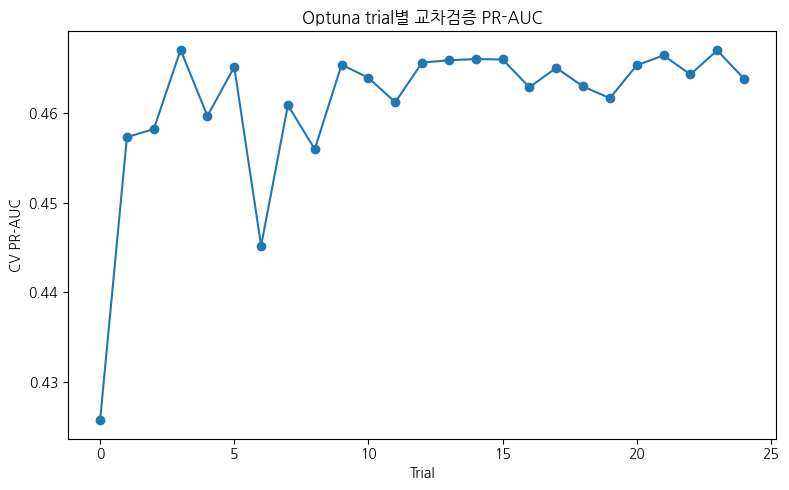

In [ ]:
# Optuna 탐색 과정 확인

if optuna_study is not None:
    trial_history = optuna_study.trials_dataframe(
        attrs=("number", "value", "params", "state")
    )
    display(
        trial_history
        .sort_values("value", ascending=False)
        .head(10)
    )

    ax = trial_history.plot(
        x="number",
        y="value",
        marker="o",
        figsize=(8, 5),
        legend=False,
    )
    ax.set_title("Optuna trial별 교차검증 PR-AUC")
    ax.set_xlabel("Trial")
    ax.set_ylabel("CV PR-AUC")
    plt.tight_layout()
    plt.show()

#### 6-2-3-6. 강건성 검증과 운영 세그먼트

**🔹 분석 목적**

- 과거 데이터로 학습하고 미래 기간을 테스트하는 시간 순서 분할로 시계열 변화에 대한 강건성을 확인한다.
- 달력 피처, 품질 피처, 파생 피처, 누적 원시 행동 피처를 제거하는 Ablation 분석을 수행한다.
- 임계값 기반 오류 유형을 비교해 모델이 놓치거나 과대 예측하는 사용자의 행동 특성을 확인한다.
- 예측확률 하위 30%, 중간 50%, 상위 20%를 운영 세그먼트로 나누어 CRM 우선순위 활용 가능성을 평가한다.


In [ ]:
# 시간 순서 분할

ordered_indices = landmark_df.sort_values(
    ["trial_date", "user_id"]
).index.to_numpy()
cut_position = int(len(ordered_indices) * 0.80)

temporal_train_indices = ordered_indices[:cut_position]
temporal_test_indices = ordered_indices[cut_position:]

y_temporal_train = y.iloc[temporal_train_indices].reset_index(drop=True)
y_temporal_test = y.iloc[temporal_test_indices].reset_index(drop=True)

temporal_split_overview = pd.DataFrame({
    "구분": ["과거 학습", "미래 테스트"],
    "사용자 수": [
        len(temporal_train_indices),
        len(temporal_test_indices),
    ],
    "결제율(%)": [
        y_temporal_train.mean() * 100,
        y_temporal_test.mean() * 100,
    ],
    "신청 시작일": [
        landmark_df.loc[temporal_train_indices, "trial_date"].min().date(),
        landmark_df.loc[temporal_test_indices, "trial_date"].min().date(),
    ],
    "신청 종료일": [
        landmark_df.loc[temporal_train_indices, "trial_date"].max().date(),
        landmark_df.loc[temporal_test_indices, "trial_date"].max().date(),
    ],
})

display(temporal_split_overview)

,구분,사용자 수,결제율(%),신청 시작일,신청 종료일
0,과거 학습,7699,39.927263,2021-05-01,2023-06-07
1,미래 테스트,1925,30.025974,2023-06-08,2023-12-31


> **💡 결과 해석**
>
> - 과거 학습 구간의 결제율은 39.93%, 미래 테스트 구간은 30.03%로 큰 수준 변화가 존재했다.
> - 무작위 분할만으로는 포착하기 어려운 시간적 분포 변화가 있어 미래 성능을 별도로 확인해야 한다.


In [ ]:
# 시간 순서 테스트 성능

temporal_rows = []
temporal_base_rate = float(y_temporal_test.mean())

for stage in STAGE_ORDER:
    X_stage = X_by_stage[stage]
    X_temporal_train = (
        X_stage.iloc[temporal_train_indices]
        .reset_index(drop=True)
    )
    X_temporal_test = (
        X_stage.iloc[temporal_test_indices]
        .reset_index(drop=True)
    )

    temporal_pipeline = make_model_pipeline(
        estimator=clone(signal_model_estimator),
        feature_frame=X_temporal_train,
        scale_numeric=signal_model_name == "Logistic Regression",
    )
    temporal_pipeline.fit(X_temporal_train, y_temporal_train)
    temporal_probability = temporal_pipeline.predict_proba(
        X_temporal_test
    )[:, 1]
    temporal_pr_auc = average_precision_score(
        y_temporal_test,
        temporal_probability,
    )

    temporal_rows.append({
        "모델 시점": stage,
        "관측 범위": STAGE_LABEL[stage],
        "PR-AUC": temporal_pr_auc,
        "PR-AUC 기준선": temporal_base_rate,
        "기준선 대비 향상": temporal_pr_auc - temporal_base_rate,
        "정규화 PR-AUC": (
            (temporal_pr_auc - temporal_base_rate)
            / (1 - temporal_base_rate)
        ),
        "ROC-AUC": roc_auc_score(
            y_temporal_test,
            temporal_probability,
        ),
        "Brier": brier_score_loss(
            y_temporal_test,
            temporal_probability,
        ),
    })

temporal_test_performance = pd.DataFrame(temporal_rows)
temporal_test_performance["모델 시점"] = pd.Categorical(
    temporal_test_performance["모델 시점"],
    categories=STAGE_ORDER,
    ordered=True,
)
temporal_test_performance = temporal_test_performance.sort_values(
    "모델 시점"
).reset_index(drop=True)

display(temporal_test_performance.round(4))

,모델 시점,관측 범위,PR-AUC,PR-AUC 기준선,기준선 대비 향상,정규화 PR-AUC,ROC-AUC,Brier
0,M0,신청 시점,0.3014,0.3003,0.0011,0.0016,0.4923,0.2248
1,M1,D0까지,0.3213,0.3003,0.0211,0.0301,0.5200,0.2228
2,M2,D1까지,0.3454,0.3003,0.0452,0.0646,0.5559,0.2207
3,M3,D2까지,0.3808,0.3003,0.0806,0.1152,0.5886,0.2180


> **💡 결과 해석**
>
> - 미래 테스트에서도 PR-AUC는 M0 0.3014에서 M3 0.3808로 상승했고, M3는 미래 기준선보다 0.0806 높았다.
> - 절대 결제율이 하락한 기간에서도 D1·D2 행동 추가에 따른 성능 증가 방향은 유지되었다.


,모델 시점,무작위 PR-AUC,무작위 기준선,무작위 기준선 대비 향상,무작위 정규화 PR-AUC,미래 PR-AUC,미래 기준선,미래 기준선 대비 향상,미래 정규화 PR-AUC
0,M0,0.3840,0.3792,0.0048,0.0077,0.3014,0.3003,0.0011,0.0016
1,M1,0.3961,0.3792,0.0169,0.0272,0.3213,0.3003,0.0211,0.0301
2,M2,0.4250,0.3792,0.0458,0.0737,0.3454,0.3003,0.0452,0.0646
3,M3,0.4590,0.3792,0.0798,0.1285,0.3808,0.3003,0.0806,0.1152


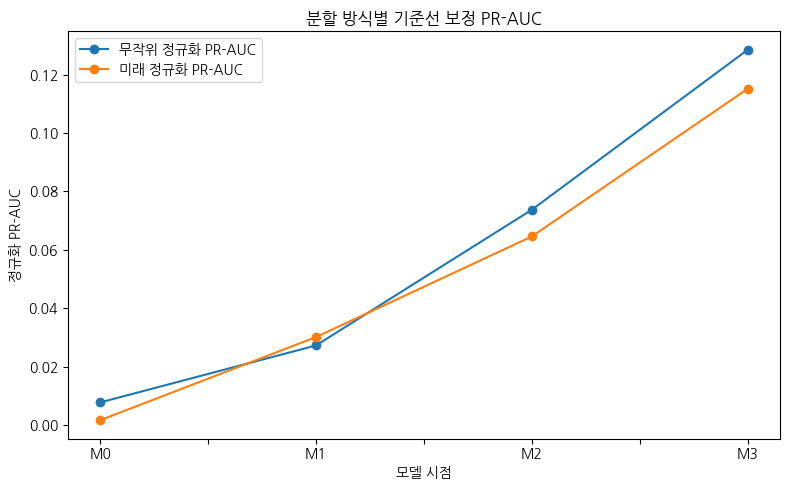

In [ ]:
# 무작위·시간 순서 테스트 비교

random_robustness = (
    signal_test_performance[
        [
            "모델 시점",
            "PR-AUC",
            "PR-AUC 기준선",
            "기준선 대비 향상",
            "정규화 PR-AUC",
        ]
    ]
    .rename(columns={
        "PR-AUC": "무작위 PR-AUC",
        "PR-AUC 기준선": "무작위 기준선",
        "기준선 대비 향상": "무작위 기준선 대비 향상",
        "정규화 PR-AUC": "무작위 정규화 PR-AUC",
    })
)

temporal_robustness = (
    temporal_test_performance[
        [
            "모델 시점",
            "PR-AUC",
            "PR-AUC 기준선",
            "기준선 대비 향상",
            "정규화 PR-AUC",
        ]
    ]
    .rename(columns={
        "PR-AUC": "미래 PR-AUC",
        "PR-AUC 기준선": "미래 기준선",
        "기준선 대비 향상": "미래 기준선 대비 향상",
        "정규화 PR-AUC": "미래 정규화 PR-AUC",
    })
)

robustness_comparison = random_robustness.merge(
    temporal_robustness,
    on="모델 시점",
    how="left",
)

display(robustness_comparison.round(4))

robustness_plot = (
    robustness_comparison
    .set_index("모델 시점")[
        ["무작위 정규화 PR-AUC", "미래 정규화 PR-AUC"]
    ]
)

ax = robustness_plot.plot(
    marker="o",
    figsize=(8, 5),
)
ax.set_title("분할 방식별 기준선 보정 PR-AUC")
ax.set_xlabel("모델 시점")
ax.set_ylabel("정규화 PR-AUC")
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 무작위 테스트와 미래 테스트의 절대 PR-AUC는 다르지만 기준선 대비 향상 패턴은 M0→M3로 유사하다.
> - 시기 변화가 있어도 행동 신호가 누적되는 상대적 구조는 유지되었다.


In [ ]:
# 피처 Ablation 평가

ablation_specs = {
    "전체 피처": {
        "include_calendar": True,
        "include_quality": True,
        "include_derived": True,
    },
    "달력 정보 제외": {
        "include_calendar": False,
        "include_quality": True,
        "include_derived": True,
    },
    "품질 피처 제외": {
        "include_calendar": True,
        "include_quality": False,
        "include_derived": True,
    },
    "파생변수 제외": {
        "include_calendar": True,
        "include_quality": True,
        "include_derived": False,
    },
    "누적 원시 행동만": {
        "include_calendar": False,
        "include_quality": False,
        "include_derived": False,
    },
}

ablation_rows = []

for specification_name, specification in ablation_specs.items():
    X_ablation = build_landmark_features(
        landmark_df,
        signal_stage,
        **specification,
    )
    X_ablation_train = X_ablation.iloc[train_indices].reset_index(drop=True)
    X_ablation_test = X_ablation.iloc[test_indices].reset_index(drop=True)

    ablation_pipeline = make_model_pipeline(
        estimator=clone(signal_model_estimator),
        feature_frame=X_ablation_train,
        scale_numeric=signal_model_name == "Logistic Regression",
    )
    ablation_pipeline.fit(X_ablation_train, y_train)
    ablation_probability = ablation_pipeline.predict_proba(
        X_ablation_test
    )[:, 1]

    ablation_rows.append({
        "피처 구성": specification_name,
        "피처 수": X_ablation.shape[1],
        "테스트 PR-AUC": average_precision_score(
            y_test,
            ablation_probability,
        ),
        "테스트 ROC-AUC": roc_auc_score(
            y_test,
            ablation_probability,
        ),
        "테스트 Brier": brier_score_loss(
            y_test,
            ablation_probability,
        ),
    })

ablation_results = pd.DataFrame(ablation_rows).sort_values(
    "테스트 PR-AUC",
    ascending=False,
)

display(ablation_results.round(4))

,피처 구성,피처 수,테스트 PR-AUC,테스트 ROC-AUC,테스트 Brier
2,품질 피처 제외,13,0.4598,0.5681,0.2324
0,전체 피처,17,0.4590,0.5653,0.2325
3,파생변수 제외,9,0.4572,0.5621,0.2329
4,누적 원시 행동만,5,0.4298,0.5431,0.2348
1,달력 정보 제외,15,0.4274,0.5401,0.2350


> **💡 결과 해석**
>
> - 품질 피처를 제외한 모델은 전체 모델과 거의 같은 성능을 보였고, 파생변수 제외도 감소 폭이 작았다.
> - 달력 정보를 제외하거나 누적 원시 행동만 사용하면 PR-AUC가 약 0.43 수준으로 낮아져 시기 정보의 영향이 컸다.
> - 달력 의존도가 높다는 점은 향후 재학습과 기간별 모니터링이 필요하다는 의미이기도 하다.


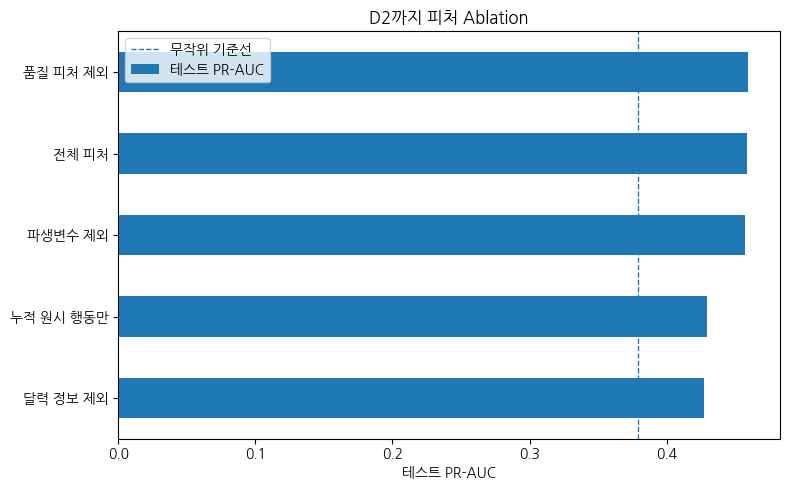

In [ ]:
# 피처 구성별 성능 차트

ablation_plot = ablation_results.sort_values("테스트 PR-AUC")
ax = ablation_plot.plot(
    x="피처 구성",
    y="테스트 PR-AUC",
    kind="barh",
    figsize=(8, 5),
    legend=False,
)
ax.axvline(
    x=y_test.mean(),
    linestyle="--",
    linewidth=1,
    label="무작위 기준선",
)
ax.set_title(f"{signal_day_label} 피처 Ablation")
ax.set_xlabel("테스트 PR-AUC")
ax.set_ylabel("")
ax.legend()
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 전체·품질 피처 제외·파생변수 제외 모델은 유사하지만 달력 정보 제외와 원시 행동만 사용한 모델은 성능이 낮다.
> - 복잡한 품질 파생변수보다 방문·체류 행동과 시기 정보가 핵심 성능을 구성했다.


In [ ]:
# 오류 유형별 행동 요약

f1_test_prediction = (
    signal_test_probability >= f1_threshold
).astype(int)

error_labels = np.select(
    [
        (y_test.to_numpy() == 1) & (f1_test_prediction == 1),
        (y_test.to_numpy() == 0) & (f1_test_prediction == 0),
        (y_test.to_numpy() == 0) & (f1_test_prediction == 1),
        (y_test.to_numpy() == 1) & (f1_test_prediction == 0),
    ],
    ["TP", "TN", "FP", "FN"],
    default="기타",
)

error_analysis_df = X_signal_test.copy()
error_analysis_df["오류 유형"] = error_labels
error_analysis_df["실제 결제"] = y_test.to_numpy()
error_analysis_df["예측 확률"] = signal_test_probability

error_summary = (
    error_analysis_df
    .groupby("오류 유형")
    .agg(
        사용자수=("실제 결제", "size"),
        평균_예측확률=("예측 확률", "mean"),
        방문율=("has_visited", "mean")
        if "has_visited" in error_analysis_df.columns
        else ("실제 결제", "size"),
        평균_방문일=("cum_visit_days", "mean")
        if "cum_visit_days" in error_analysis_df.columns
        else ("실제 결제", "size"),
        중앙_체류시간=("cum_stay_hours", "median")
        if "cum_stay_hours" in error_analysis_df.columns
        else ("실제 결제", "size"),
        평균_체크인=("cum_checkin_count", "mean")
        if "cum_checkin_count" in error_analysis_df.columns
        else ("실제 결제", "size"),
    )
    .reindex(["TP", "TN", "FP", "FN"])
)

if "방문율" in error_summary.columns:
    error_summary["방문율"] *= 100

display(error_summary.round(3))

,사용자수,평균_예측확률,방문율,평균_방문일,중앙_체류시간,평균_체크인
오류 유형,,,,,,
TP,706,0.400,63.314,0.970,2.208,3.147
TN,51,0.209,74.510,0.784,5.714,4.059
FP,1144,0.376,62.238,0.934,2.097,3.322
FN,24,0.211,41.667,0.417,0.000,3.250


> **💡 결과 해석**
>
> - F1 임계값에서 거짓양성은 1,144명으로 매우 많고 참음성은 51명에 불과했다.
> - 모델은 결제 가능성이 있는 사용자를 넓게 포착하지만 비결제자를 정밀하게 제외하지 못하므로, 고비용 개별 혜택 자동화에는 부적합하다.


In [ ]:
# 예측 확률 기반 운영 세그먼트

low_cut, high_cut = np.quantile(
    signal_test_probability,
    [0.30, 0.80],
)

operation_segment_df = pd.DataFrame({
    "실제 결제": y_test.to_numpy(),
    "예측 확률": signal_test_probability,
})
operation_segment_df["운영 세그먼트"] = pd.cut(
    operation_segment_df["예측 확률"],
    bins=[-np.inf, low_cut, high_cut, np.inf],
    labels=[
        "낮은 전환 신호 · 하위 30%",
        "중간 전환 신호 · 중간 50%",
        "높은 전환 신호 · 상위 20%",
    ],
)

operation_segment_summary = (
    operation_segment_df
    .groupby("운영 세그먼트", observed=False)
    .agg(
        사용자수=("실제 결제", "size"),
        결제자수=("실제 결제", "sum"),
        실제_결제율=("실제 결제", "mean"),
        평균_예측확률=("예측 확률", "mean"),
    )
    .reset_index()
)
operation_segment_summary[
    ["실제_결제율", "평균_예측확률"]
] *= 100

display(operation_segment_summary.round(2))

,운영 세그먼트,사용자수,결제자수,실제_결제율,평균_예측확률
0,낮은 전환 신호 · 하위 30%,578,190,32.87,28.02
1,중간 전환 신호 · 중간 50%,966,356,36.85,38.08
2,높은 전환 신호 · 상위 20%,381,184,48.29,52.14


> **💡 결과 해석**
>
> - 예측확률 상위 20%의 실제 결제율은 48.29%, 하위 30%는 32.87%로 15.42%p 차이가 났다.
> - 완전한 개인 예측은 어렵지만 저비용 CRM 메시지의 우선순위를 나누는 세그먼트 도구로는 활용 가능하다.


#### 6-2-3-7. 최종 결과 요약 및 저장

**🔹 분석 목적**

- 선택 알고리즘, OOF·테스트·미래 테스트 성능, 유의한 행동 시점, 상위 세그먼트 Lift를 하나의 결과표로 정리한다.
- 후속 발표 자료와 전략 설계에서 사용할 핵심 수치를 `landmark_analysis_results`에 저장한다.
- 모델의 절대 성능과 운영적 한계를 함께 기록해 과도한 예측 모델 해석을 방지한다.


In [ ]:
# 핵심 수치 추출

signal_oof_ap = float(
    signal_oof_performance.loc[
        signal_oof_performance["모델 시점"].eq(signal_stage),
        "PR-AUC",
    ].iloc[0]
)
signal_test_row = signal_test_performance.loc[
    signal_test_performance["모델 시점"].eq(signal_stage)
].iloc[0]
signal_test_ap = float(signal_test_row["PR-AUC"])
signal_test_ap_gain = float(signal_test_row["기준선 대비 향상"])
signal_test_normalized_ap = float(signal_test_row["정규화 PR-AUC"])

m3_test_ap = float(
    signal_test_performance.loc[
        signal_test_performance["모델 시점"].eq("M3"),
        "PR-AUC",
    ].iloc[0]
)
m0_test_ap = float(
    signal_test_performance.loc[
        signal_test_performance["모델 시점"].eq("M0"),
        "PR-AUC",
    ].iloc[0]
)

top_permutation_features = (
    permutation_importance_table
    .head(5)["변수"]
    .tolist()
)

temporal_signal_row = temporal_test_performance.loc[
    temporal_test_performance["모델 시점"].eq(signal_stage)
].iloc[0]
temporal_signal_ap = float(temporal_signal_row["PR-AUC"])
temporal_signal_ap_gain = float(
    temporal_signal_row["기준선 대비 향상"]
)
temporal_signal_normalized_ap = float(
    temporal_signal_row["정규화 PR-AUC"]
)

significant_daily_visits = (
    daily_visit_test_results.loc[
        daily_visit_test_results["Holm 보정 p-value"].lt(0.05),
        "체험일",
    ]
    .tolist()
)

top_decile = lift_table.loc[
    lift_table["확률 분위"].eq(10)
].iloc[0]
top_decile_payment_rate = float(top_decile["실제_결제율"])
top_decile_lift = float(top_decile["Lift"])

quality_excluded_ap = float(
    ablation_results.loc[
        ablation_results["피처 구성"].eq("품질 피처 제외"),
        "테스트 PR-AUC",
    ].iloc[0]
)
behavior_only_ap = float(
    ablation_results.loc[
        ablation_results["피처 구성"].eq("누적 원시 행동만"),
        "테스트 PR-AUC",
    ].iloc[0]
)
calendar_excluded_ap = float(
    ablation_results.loc[
        ablation_results["피처 구성"].eq("달력 정보 제외"),
        "테스트 PR-AUC",
    ].iloc[0]
)

summary_table = pd.DataFrame({
    "항목": [
        "선택 알고리즘",
        "1-SE 성능 동률권",
        "랜드마크 판단",
        "신호 시점 OOF PR-AUC",
        "신호 시점 테스트 PR-AUC",
        "테스트 결제율 기준선",
        "기준선 대비 PR-AUC 향상",
        "정규화 PR-AUC",
        "M0 테스트 PR-AUC",
        "M3 테스트 PR-AUC",
        "미래 테스트 PR-AUC",
        "미래 기준선 대비 향상",
        "미래 정규화 PR-AUC",
        "유의한 당일 방문 시점",
        "상위 10% 실제 결제율",
        "상위 10% Lift",
        "주요 예측 변수",
    ],
    "결과": [
        signal_model_name,
        ", ".join(model_tie_names),
        f"{signal_day_label} ({signal_stage})까지 계속 증가",
        f"{signal_oof_ap:.4f}",
        f"{signal_test_ap:.4f}",
        f"{test_base_rate:.4f}",
        f"{signal_test_ap_gain:.4f}",
        f"{signal_test_normalized_ap:.4f}",
        f"{m0_test_ap:.4f}",
        f"{m3_test_ap:.4f}",
        f"{temporal_signal_ap:.4f}",
        f"{temporal_signal_ap_gain:.4f}",
        f"{temporal_signal_normalized_ap:.4f}",
        ", ".join(significant_daily_visits)
        if significant_daily_visits
        else "없음",
        f"{top_decile_payment_rate:.2f}%",
        f"{top_decile_lift:.2f}",
        ", ".join(top_permutation_features),
    ],
})

display(summary_table)

landmark_analysis_results = {
    "sample_overview": sample_overview,
    "daily_visit_test_results": daily_visit_test_results,
    "cumulative_visit_test_results": visit_proportion_tests,
    "visit_day_chi_square_results": visit_day_chi2_tests,
    "stay_time_test_results": stay_mannwhitney_tests,
    "model_stage_cv_results": model_stage_cv_results,
    "signal_oof_performance": signal_oof_performance,
    "stage_gain_bootstrap": stage_gain_bootstrap,
    "signal_test_performance": signal_test_performance,
    "test_stage_gain_bootstrap": test_stage_gain_bootstrap,
    "threshold_test_results": threshold_test_results,
    "lift_table": lift_table,
    "permutation_importance_table": permutation_importance_table,
    "shap_importance_table": shap_importance_table,
    "optuna_test_result": optuna_test_result,
    "temporal_test_performance": temporal_test_performance,
    "robustness_comparison": robustness_comparison,
    "ablation_results": ablation_results,
    "operation_segment_summary": operation_segment_summary,
    "summary_table": summary_table,
}

print("결과 변수 저장 완료: landmark_analysis_results")

,항목,결과
0,선택 알고리즘,Random Forest
1,1-SE 성능 동률권,"Random Forest, Logistic Regression"
2,랜드마크 판단,D2까지 (M3)까지 계속 증가
3,신호 시점 OOF PR-AUC,0.4607
4,신호 시점 테스트 PR-AUC,0.4590
5,테스트 결제율 기준선,0.3792
6,기준선 대비 PR-AUC 향상,0.0798
7,정규화 PR-AUC,0.1285
8,M0 테스트 PR-AUC,0.3840
9,M3 테스트 PR-AUC,0.4590


결과 변수 저장 완료: landmark_analysis_results


> **💡 최종 결과**
>
> - 랜드마크 성능은 M0부터 M3까지 계속 증가했으며 테스트 PR-AUC는 0.3840 → 0.3961 → 0.4250 → 0.4590이었다.
> - D0 행동 추가 효과는 작고 불확실했지만 D1과 D2 행동 추가 시 성능이 더 크게 증가했다.
> - M3 ROC-AUC는 0.5653으로 강한 개인 예측 모델은 아니며, 핵심 역할은 **전환 신호의 형성 시점 확인**이다.
> - 상위 10% 결제율은 53.37%, Lift는 1.41로 세그먼트 우선순위 활용 가능성은 확인했다.
>
> **➡️ 운영 판단**
> - D2는 신호가 가장 강하지만 행동을 바꾸기에는 늦다.
> - D1까지 두 번째 날짜 방문이 없는 사용자를 핵심 개입 대상으로 삼고, D2에는 행동 유형별 결제 제안을 제공한다.


### 6-2-4. 통합 결론 및 실행 전략

**🚀 결제 전환의 핵심은 사용량이 아니라 이용의 지속성이다**

| 분석 질문 | 핵심 결과 | 최종 판단 |
| --- | --- | --- |
| 누구를 더 유입할 것인가? | 저녁/퇴근형 결제율 49.95% | 평일 저녁 수요를 가진 고전환 후보군 확대 |
| 어떤 행동을 만들 것인가? | 단일 지점 1일 방문 35.05% → 반복 방문 43.43% | 서로 다른 날짜의 두 번째 방문을 핵심 활성화 행동으로 정의 |
| 다지점 이용이 핵심인가? | 행동 보정 OR 1.066, 매칭 후 격차 +2.75%p | 무료 체험의 1차 전환 레버로 보기 어려움 |
| 언제 개입할 것인가? | D0보다 D1·D2 행동 추가 시 PR-AUC가 크게 증가 | 행동을 바꿀 시간이 남은 D1에 개입 |
| 모델을 어떻게 활용할 것인가? | M3 ROC-AUC 0.5653, 상위 10% Lift 1.41 | 개인 자동판정보다 CRM 우선순위 세그먼트로 활용 |

- 무료 체험 결제 전환과 가장 일관되게 연결된 행동은 공간을 오래 사용하거나 여러 지점을 방문한 것이 아니라, 체험 이용이 서로 다른 날짜까지 이어진 반복 방문이었다.
- 전환 신호는 D1 이후 본격적으로 강화되므로, 첫 방문 이후 D1까지 두 번째 방문이 없는 사용자를 핵심 개입 대상으로 설정한다.

**🛠️ Who x What x When 운영안**

1. Who - 저녁/퇴근형 유입 확대

- 전체 방문자의 16.25%이지만 결제율이 49.95%로 가장 높은 저녁형 사용자를 유입 우선 타겟으로 설정한다.
- 평일 18~23시 체험권, 지점 인근 직장인 대상 위치 기반 캠페인, 기존 회원의 동료 초대 프로그램을 검토한다.
- 현재 데이터에는 이용 목적이 없으므로 `자기계발형`, `야근형`으로 확정하지 않고 저녁 시간대에 높은 지불 의향을 보인 후보군으로 정의한다.

2. What - 핵심 활성화 행동을 두 번째 날짜 방문으로 변경

- 총 체류시간, 총 체크인 횟수, 다지점 이용률보다 `D2 종료 전 두 번째 날짜 방문 완료율`을 핵심 KPI로 관리한다.
- 첫 방문 지점 원클릭 재예약, 남은 체험일 안내, 두 번째 방문 완료 후 회의실·락커·지역 제휴 혜택을 제공한다.
- 무료 체험 단계에서는 타 지점 방문을 필수 행동으로 만들지 않고, 동일 지점 재방문을 기본값으로 둔다.

3. When - D0 마찰 제거, D1 재방문 유도, D2 결제 제안

| 시점 | 운영 목적 | 실행 예시 |
| --- | --- | --- |
| D0 | 첫 경험의 마찰 제거 | 출입 방법, 남은 체험일, 같은 지점 재예약 버튼 안내 |
| D1 | 두 번째 날짜 방문 생성 | 미재방문자 대상 저녁 좌석·재예약·소규모 보상 메시지 |
| D2 | 행동 유형별 전환 제안 | 반복 방문자에게 맞춤 번들, 미재방문자에게 중단 사유 조사 |
| 결제 후 | 이용 지속과 락인 | 포터블 멤버십, 회의실·락커, 지역 제휴 혜택 단계적 제공 |

**🚧 분석 한계**

- 결제 발생 시각이 없어 행동과 결제의 정확한 선후관계 및 실시간 개입 가능 여부를 확인할 수 없다.
- 관찰 데이터이므로 반복 방문이 결제를 유발했는지, 원래 결제 의향이 높은 사용자가 반복 방문한 것인지 구분할 수 없다.
- 다지점 이용자는 218명으로 작아 작은 효과를 검정할 통계적 검정력이 충분하지 않다.
- 랜드마크 모델의 절대 성능은 낮으므로 고비용 혜택 자동 지급이나 개인별 결제 확정 판단에 사용하지 않는다.

## **6-3. 접근성이 좋은 지점이 실제로 성과도 좋을까?**

**🎯 주변 인프라와 이용후기 기반 지점 역할 진단 및 출점 전략**

- 공유오피스의 성과는 지하철 접근성이나 주변 유동인구만으로 결정되지 않는다.
- 입지가 좋아도 실제 체험 방문을 충분히 확보하지 못할 수 있고, 방문이 많아도 반복 이용과 결제로 이어지지 않을 수 있다.

**🔭 좋은 입지가 고객을 데려오기만 하면 되는가? 아니면 지점마다 유입·경험·전환이 막히는 구간이 서로 다른가?**

- 이를 확인하기 위해 다음 데이터를 지점 단위로 연결한다.

  - 무료 체험 방문자 6,026명의 이용행태 및 결제 데이터
  - 지점 반경 1km의 지하철 유동인구와 주변 인프라
  - 지도 리뷰 82건과 블로그 게시글 360건

- 최종적으로 지점 성과를 입지 잠재력·수요 확보·공간 경험·전환 성과의 네 축으로 분리해, 지점별 병목과 운영 전략 및 신규 출점 기준을 도출한다.

**📌 전체 분석 흐름**

1. 지점별 수요·결제 성과와 반복 방문 효과 확인
2. 지하철 유동인구의 절대 규모와 평일·주말 패턴 검증
3. 주변 인프라를 활용한 상권 유형 구분
4. 지도·블로그 리뷰를 방문 후 경험과 방문 전 기대 관점으로 분석
5. 네 축을 통합해 지점별 병목과 신규 출점 스크리닝 기준 도출


### 6-3-1. 지점별 성과 분석

**🔍 분석 목적**

- 지점별 체험 수요의 절대 규모와 면적당 이용 효율을 분리해 비교한다.
- 사용자가 체험 기간 중 가장 주로 이용한 대표 지점을 정의하고 지점별 결제율을 산출한다.
- 지점별 결제율 차이가 실제로 존재하는지 검정하고, 반복 방문과 결제의 관계를 확인한다.
- 하나의 종합순위를 만들기보다 `수요 규모 x 결제 전환` 기준으로 지점 역할을 진단한다.

**🧬 핵심 분석 단위**

- 사용자, 지점, 일: 체험 기간 중 실제 이용 행동
- 사용자, 지점: 방문일 수, 체류시간, 체크인 수
- 지점, 일: 이용이 없었던 운영일을 포함한 일별 수요
- 사용자 대표 지점: 체류시간 → 방문일 수 → 체크인 수 순으로 선정

#### 6-3-1-1. 분석 환경 설정 및 원천 데이터 구축

**🔹 분석 목적**

- 분석에 필요한 사용자·방문·출입·지점 면적 데이터를 확인한다.
- 방문 기록과 출입 기록을 사용자·지점·일 단위로 통합해 실제 이용 행동의 기준 테이블을 만든다.
- 이후 지점별 수요와 반복 방문을 동일한 기준으로 계산할 수 있도록 자료형과 키 정합성을 검증한다.


In [ ]:
# 데이터프레임 및 컬럼 검증

EVENING_START_HOUR = 18
REPEAT_VISIT_DAY_THRESHOLD = 2
RANDOM_SEED = 42
PERMUTATION_COUNT = 10_000


def require_columns(frame, frame_name, required_columns):
    """분석 시작 전에 필요한 컬럼이 모두 있는지 확인한다."""
    missing_columns = [
        column
        for column in required_columns
        if column not in frame.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{frame_name}에 필요한 컬럼이 없습니다: {missing_columns}"
        )


required_frames = [
    "user_df",
    "trial_visit_info_d0d2",
    "trial_access_log_d0d2",
    "site_area_clean",
    "day_covid_weather_df_d0_d2_dense_v3",
    "subway_flow",
]

missing_frames = [
    frame_name
    for frame_name in required_frames
    if frame_name not in globals()
]

if missing_frames:
    raise NameError(
        f"먼저 생성되어야 하는 데이터프레임이 없습니다: {missing_frames}"
    )

require_columns(
    user_df,
    "user_df",
    ["user_id", "is_payment", "visited_flag", "distinct_site_count"],
)
require_columns(
    trial_visit_info_d0d2,
    "trial_visit_info_d0d2",
    [
        "user_id", "site_id", "date", "stay_seconds_for_aggregation",
        "first_enter_time", "last_leave_time",
    ],
)
require_columns(
    trial_access_log_d0d2,
    "trial_access_log_d0d2",
    ["user_id", "site_id", "access_date", "access_time_kst", "checkin"],
)
require_columns(
    day_covid_weather_df_d0_d2_dense_v3,
    "day_covid_weather_df_d0_d2_dense_v3",
    [
        "calendar_date", "site_id", "area_pyeong", "activity_user_count",
        "total_stay_seconds", "checkin_count", "free_trial_usage_flag",
        "day_of_week", "day_type", "covid_period_flag",
        "weather_temp_mean_c", "weather_precip_mm", "weather_adverse_flag",
    ],
)
require_columns(
    subway_flow,
    "subway_flow",
    [
        "calendar_date", "site_id", "nearby_station_count",
        "nearest_station_name", "subway_boarding_1km",
        "subway_alighting_1km", "subway_flow_1km",
    ],
)

print("필수 데이터프레임 및 컬럼 검증 완료")

필수 데이터프레임 및 컬럼 검증 완료


> **✅ 확인 결과**
>
> - 분석에 필요한 데이터프레임과 필수 컬럼이 모두 존재해 지점 성과 분석을 진행할 수 있는 상태임을 확인했다.


In [ ]:
# 분석 원천 복사 및 자료형 통일

site_visit_source = trial_visit_info_d0d2.copy()
site_access_source = trial_access_log_d0d2.copy()
site_user_source = user_df.copy()
site_area_source = site_area_clean[["site_id", "area_pyeong"]].copy()
site_day_source = day_covid_weather_df_d0_d2_dense_v3.copy()

for frame in [site_visit_source, site_access_source, site_user_source]:
    frame["user_id"] = frame["user_id"].astype("string")

for frame in [site_visit_source, site_access_source, site_area_source, site_day_source]:
    frame["site_id"] = pd.to_numeric(
        frame["site_id"],
        errors="raise",
    ).astype("Int64")

site_visit_source["date"] = pd.to_datetime(
    site_visit_source["date"],
    errors="raise",
).dt.normalize()

site_access_source["access_date"] = pd.to_datetime(
    site_access_source["access_date"],
    errors="raise",
).dt.normalize()

site_access_source["access_time_kst"] = pd.to_datetime(
    site_access_source["access_time_kst"],
    errors="coerce",
)

site_day_source["calendar_date"] = pd.to_datetime(
    site_day_source["calendar_date"],
    errors="raise",
).dt.normalize()

site_user_source["is_payment"] = pd.to_numeric(
    site_user_source["is_payment"],
    errors="raise",
).astype("Int64")

site_area_source["area_pyeong"] = pd.to_numeric(
    site_area_source["area_pyeong"],
    errors="raise",
)

if site_area_source["site_id"].duplicated().any():
    raise ValueError("site_area_clean에 중복 site_id가 있습니다.")

# 방문 요약 원천: 사용자, 지점, 일 단위
visit_user_site_day = (
    site_visit_source
    .groupby(
        ["user_id", "site_id", "date"],
        as_index=False,
    )
    .agg(
        daily_visit_record_count=("user_id", "size"),
        daily_stay_seconds=(
            "stay_seconds_for_aggregation",
            lambda values: values.sum(min_count=1),
        ),
        daily_first_enter_at=("first_enter_time", "min"),
        daily_last_leave_at=("last_leave_time", "max"),
    )
    .rename(columns={"date": "calendar_date"})
)

visit_user_site_day["visit_info_flag"] = 1

In [ ]:
# 출입 로그 원천: 사용자, 지점, 일 단위

site_access_source["checkin_event"] = (
    site_access_source["checkin"].eq(1).astype("int64")
)

site_access_source["checkout_event"] = (
    site_access_source["checkin"].eq(2).astype("int64")
)

site_access_source["evening_checkin_event"] = (
    site_access_source["checkin"].eq(1)
    & site_access_source["access_time_kst"].dt.hour.ge(
        EVENING_START_HOUR
    )
).astype("int64")

site_access_source["checkin_time"] = (
    site_access_source["access_time_kst"]
    .where(site_access_source["checkin"].eq(1))
)

site_access_source["checkout_time"] = (
    site_access_source["access_time_kst"]
    .where(site_access_source["checkin"].eq(2))
)

access_user_site_day = (
    site_access_source
    .groupby(
        ["user_id", "site_id", "access_date"],
        as_index=False,
    )
    .agg(
        daily_access_record_count=("user_id", "size"),
        daily_checkin_count=("checkin_event", "sum"),
        daily_checkout_count=("checkout_event", "sum"),
        daily_evening_checkin_count=(
            "evening_checkin_event",
            "sum",
        ),
        daily_first_checkin_at=("checkin_time", "min"),
        daily_last_checkout_at=("checkout_time", "max"),
    )
    .rename(columns={"access_date": "calendar_date"})
)

access_user_site_day["access_log_flag"] = 1

# 두 원천의 합집합
site_user_day = (
    visit_user_site_day
    .merge(
        access_user_site_day,
        on=["user_id", "site_id", "calendar_date"],
        how="outer",
        validate="1:1",
    )
    .sort_values(["user_id", "calendar_date", "site_id"])
    .reset_index(drop=True)
)

count_columns = [
    "daily_visit_record_count",
    "daily_access_record_count",
    "daily_checkin_count",
    "daily_checkout_count",
    "daily_evening_checkin_count",
    "visit_info_flag",
    "access_log_flag",
]

site_user_day[count_columns] = (
    site_user_day[count_columns]
    .fillna(0)
    .astype("Int64")
)

site_user_day["daily_stay_seconds"] = pd.to_numeric(
    site_user_day["daily_stay_seconds"],
    errors="coerce",
).astype("Int64")

site_user_day["daily_stay_known_flag"] = (
    site_user_day["daily_stay_seconds"]
    .notna()
    .astype("Int64")
)

site_user_day["weekend_user_site_day_flag"] = (
    site_user_day["calendar_date"]
    .dt.dayofweek
    .isin([5, 6])
    .astype("Int64")
)

site_user_day["daily_evening_checkin_flag"] = (
    site_user_day["daily_evening_checkin_count"]
    .gt(0)
    .astype("Int64")
)

site_user_day["daily_usage_flag"] = 1

if site_user_day.duplicated(
    ["user_id", "site_id", "calendar_date"]
).any():
    raise ValueError("site_user_day에 중복 사용자·지점·일 Key가 있습니다.")

display(site_user_day.head())

,user_id,site_id,calendar_date,daily_visit_record_count,daily_stay_seconds,daily_first_enter_at,daily_last_leave_at,visit_info_flag,daily_access_record_count,daily_checkin_count,daily_checkout_count,daily_evening_checkin_count,daily_first_checkin_at,daily_last_checkout_at,access_log_flag,daily_stay_known_flag,weekend_user_site_day_flag,daily_evening_checkin_flag,daily_usage_flag
0,000590dc-046f-462b-8225-4c81a97b7166,6,2023-09-05,1,21417,2023-09-05 11:57:01.148452,2023-09-05 17:59:45.443621,1,6,3,3,0,2023-09-05 11:57:01.695334,2023-09-05 17:59:45.973499,1,1,0,0,1
1,000be14f-ba0f-4af6-bc2c-7b00dfcbc98c,3,2021-09-30,1,10222,2021-09-30 16:31:14.683437,2021-09-30 20:25:41.659501,1,14,7,7,3,2021-09-30 16:31:14.861813,2021-09-30 20:25:41.850542,1,1,0,1,1
2,000be14f-ba0f-4af6-bc2c-7b00dfcbc98c,3,2021-10-01,1,9382,2021-10-01 19:30:20.712177,2021-10-01 22:08:58.748107,1,4,2,2,2,2021-10-01 19:30:20.894398,2021-10-01 22:08:58.909740,1,1,0,1,1
3,0018e22d-a2cc-4e06-bca2-d6a041770f3b,6,2023-11-15,1,42900,2023-11-15 09:44:07.947297,2023-11-15 21:47:12.944689,1,13,7,6,2,2023-11-15 09:44:08.498847,2023-11-15 21:47:13.500699,1,1,0,1,1
4,0018e22d-a2cc-4e06-bca2-d6a041770f3b,6,2023-11-16,1,34472,2023-11-16 09:04:41.057302,2023-11-16 18:39:26.385388,1,6,4,2,3,2023-11-16 09:04:41.565727,2023-11-16 18:39:26.886181,1,1,0,1,1


> **✅ 확인 결과**
>
> - 방문·출입 기록을 사용자·지점·일 단위로 통합했으며, 체류시간·체크인·주말 이용 여부를 한 행에서 확인할 수 있도록 구성했다.


#### 6-3-1-2. 지점별 성과 KPI 및 대표 지점 정의

**🔹 분석 목적**

- 사용자별 체류시간·방문일 수·체크인 수를 지점 단위로 집계한다.
- 체류시간 → 방문일 수 → 체크인 수 순으로 사용자의 대표 지점을 선정한다.
- 운영하지 않은 날짜와 이용이 없었던 날짜까지 포함한 Dense 테이블로 운영일당·면적당 수요를 계산한다.


In [ ]:
# 사용자, 지점 단위 행동 요약

user_site_summary = (
    site_user_day
    .groupby(
        ["user_id", "site_id"],
        as_index=False,
    )
    .agg(
        site_visit_days=("calendar_date", "nunique"),
        site_total_stay_seconds=(
            "daily_stay_seconds",
            lambda values: values.sum(min_count=1),
        ),
        site_stay_known_days=("daily_stay_known_flag", "sum"),
        site_checkin_count=("daily_checkin_count", "sum"),
        site_checkout_count=("daily_checkout_count", "sum"),
        site_evening_checkin_count=(
            "daily_evening_checkin_count",
            "sum",
        ),
        site_weekend_visit_days=(
            "weekend_user_site_day_flag",
            "sum",
        ),
        site_first_use_date=("calendar_date", "min"),
        site_last_use_date=("calendar_date", "max"),
    )
)

user_site_summary["site_total_stay_hours"] = (
    user_site_summary["site_total_stay_seconds"] / 3600
)

user_site_summary["site_stay_complete_flag"] = (
    user_site_summary["site_stay_known_days"]
    .eq(user_site_summary["site_visit_days"])
    .astype("Int64")
)

user_site_summary = user_site_summary.merge(
    site_user_source[
        ["user_id", "is_payment", "distinct_site_count"]
    ],
    on="user_id",
    how="left",
    validate="m:1",
)

if user_site_summary["is_payment"].isna().any():
    raise ValueError("user_site_summary 결합 후 결제 여부가 누락되었습니다.")

# 대표 지점 결정을 위한 정렬값
user_site_summary["representative_rank_stay_seconds"] = (
    user_site_summary["site_total_stay_seconds"].fillna(0)
)

primary_site_user_df = (
    user_site_summary
    .sort_values(
        [
            "user_id",
            "representative_rank_stay_seconds",
            "site_visit_days",
            "site_checkin_count",
            "site_id",
        ],
        ascending=[True, False, False, False, True],
    )
    .drop_duplicates("user_id", keep="first")
    .rename(columns={"site_id": "representative_site_id"})
    .reset_index(drop=True)
)

primary_site_user_df["representative_site_rule"] = (
    "최장 체류시간 > 방문일 수 > 체크인 수 > site_id"
)

if not primary_site_user_df["user_id"].is_unique:
    raise ValueError("사용자별 대표 지점이 1개로 확정되지 않았습니다.")

if primary_site_user_df["user_id"].nunique() != site_user_day["user_id"].nunique():
    raise ValueError("방문 사용자 중 대표 지점이 누락된 사용자가 있습니다.")

display(primary_site_user_df.head())

,user_id,representative_site_id,site_visit_days,site_total_stay_seconds,site_stay_known_days,site_checkin_count,site_checkout_count,site_evening_checkin_count,site_weekend_visit_days,site_first_use_date,site_last_use_date,site_total_stay_hours,site_stay_complete_flag,is_payment,distinct_site_count,representative_rank_stay_seconds,representative_site_rule
0,000590dc-046f-462b-8225-4c81a97b7166,6,1,21417,1,3,3,0,0,2023-09-05,2023-09-05,5.949167,1,0,1,21417,최장 체류시간 > 방문일 수 > 체크인 수 > site_id
1,000be14f-ba0f-4af6-bc2c-7b00dfcbc98c,3,2,19604,2,9,9,5,0,2021-09-30,2021-10-01,5.445556,1,1,1,19604,최장 체류시간 > 방문일 수 > 체크인 수 > site_id
2,0018e22d-a2cc-4e06-bca2-d6a041770f3b,6,2,77372,2,11,8,5,0,2023-11-15,2023-11-16,21.492222,1,0,1,77372,최장 체류시간 > 방문일 수 > 체크인 수 > site_id
3,002606d9-38ca-48f3-910c-cbfada9a9109,17,2,25024,2,4,4,2,2,2023-01-07,2023-01-08,6.951111,1,0,1,25024,최장 체류시간 > 방문일 수 > 체크인 수 > site_id
4,002a7570-90dd-4cab-b0aa-b0e40f7ef27a,5,1,18722,1,5,5,4,0,2021-09-08,2021-09-08,5.200556,1,1,1,18722,최장 체류시간 > 방문일 수 > 체크인 수 > site_id


> **✅ 확인 결과**
>
> - 사용자별 대표 지점을 체류시간 → 방문일 수 → 체크인 수 순으로 선정했으며, 이후 지점별 결제율은 이 대표 지점을 기준으로 계산한다.


In [ ]:
# 지점별 사용자 행동 KPI

def summarize_site_users(group):
    stay_complete_mask = group["site_stay_complete_flag"].eq(1)
    total_checkins = group["site_checkin_count"].sum()
    total_user_site_days = group["site_visit_days"].sum()

    return pd.Series({
        "total_unique_visitors": group["user_id"].nunique(),
        "total_user_site_days": total_user_site_days,
        "repeat_visitor_count": (
            group["site_visit_days"]
            .ge(REPEAT_VISIT_DAY_THRESHOLD)
            .sum()
        ),
        "repeat_visitor_rate": (
            group["site_visit_days"]
            .ge(REPEAT_VISIT_DAY_THRESHOLD)
            .mean()
        ),
        "avg_visit_days_per_visitor": group["site_visit_days"].mean(),
        "median_visit_days_per_visitor": group["site_visit_days"].median(),
        "total_known_stay_hours": group["site_total_stay_hours"].sum(min_count=1),
        "stay_complete_visitor_count": stay_complete_mask.sum(),
        "stay_complete_visitor_rate": stay_complete_mask.mean(),
        "avg_total_stay_hours_per_complete_visitor": (
            group.loc[
                stay_complete_mask,
                "site_total_stay_hours",
            ].mean()
        ),
        "median_total_stay_hours_per_complete_visitor": (
            group.loc[
                stay_complete_mask,
                "site_total_stay_hours",
            ].median()
        ),
        "total_checkin_count": total_checkins,
        "avg_checkins_per_visitor": group["site_checkin_count"].mean(),
        "evening_checkin_count": group["site_evening_checkin_count"].sum(),
        "evening_checkin_ratio": (
            group["site_evening_checkin_count"].sum()
            / total_checkins
            if total_checkins > 0
            else np.nan
        ),
        "weekend_user_site_days": group["site_weekend_visit_days"].sum(),
        "weekend_user_site_day_ratio": (
            group["site_weekend_visit_days"].sum()
            / total_user_site_days
            if total_user_site_days > 0
            else np.nan
        ),
        "multi_site_visitor_count": group["distinct_site_count"].ge(2).sum(),
        "multi_site_visitor_rate": group["distinct_site_count"].ge(2).mean(),
    })


site_user_kpi_summary = (
    user_site_summary
    .groupby("site_id")
    .apply(summarize_site_users, include_groups=False)
    .reset_index()
)

# 대표 지점 기준 결제 KPI
representative_site_payment_summary = (
    primary_site_user_df
    .groupby(
        "representative_site_id",
        as_index=False,
    )
    .agg(
        representative_user_count=("user_id", "nunique"),
        representative_payer_count=("is_payment", "sum"),
    )
    .rename(columns={"representative_site_id": "site_id"})
)

representative_site_payment_summary[
    "representative_site_payment_rate"
] = (
    representative_site_payment_summary["representative_payer_count"]
    / representative_site_payment_summary["representative_user_count"]
)

wilson_low, wilson_high = proportion_confint(
    count=representative_site_payment_summary[
        "representative_payer_count"
    ].to_numpy(),
    nobs=representative_site_payment_summary[
        "representative_user_count"
    ].to_numpy(),
    alpha=0.05,
    method="wilson",
)

representative_site_payment_summary[
    "payment_rate_wilson_low"
] = wilson_low
representative_site_payment_summary[
    "payment_rate_wilson_high"
] = wilson_high

In [ ]:
# Dense 테이블 기반 수요 KPI

def summarize_site_days(group):
    active_mask = group["activity_user_count"].gt(0)
    weekend_mask = group["calendar_date"].dt.dayofweek.isin([5, 6])

    total_activity_user_days = group["activity_user_count"].sum()
    weekend_activity_user_days = group.loc[
        weekend_mask,
        "activity_user_count",
    ].sum()

    return pd.Series({
        "analysis_start_date": group["calendar_date"].min(),
        "analysis_end_date": group["calendar_date"].max(),
        "operating_days": len(group),
        "active_days": active_mask.sum(),
        "zero_usage_days": (~active_mask).sum(),
        "zero_usage_day_rate": (~active_mask).mean(),
        "area_pyeong": group["area_pyeong"].iloc[0],
        "total_activity_user_days": total_activity_user_days,
        "avg_daily_activity_users": group["activity_user_count"].mean(),
        "avg_active_day_activity_users": (
            group.loc[active_mask, "activity_user_count"].mean()
            if active_mask.any() else 0
        ),
        "median_daily_activity_users": group["activity_user_count"].median(),
        "p95_daily_activity_users": group["activity_user_count"].quantile(0.95),
        "peak_daily_activity_users": group["activity_user_count"].max(),
        "total_stay_hours_dense": group["total_stay_seconds"].sum() / 3600,
        "avg_daily_stay_hours": group["total_stay_seconds"].mean() / 3600,
        "avg_stay_hours_per_activity_user_day": (
            group["total_stay_seconds"].sum() / 3600 / total_activity_user_days
            if total_activity_user_days > 0 else np.nan
        ),
        "total_checkins_dense": group["checkin_count"].sum(),
        "avg_daily_checkins": group["checkin_count"].mean(),
        "weekend_activity_user_days": weekend_activity_user_days,
        "weekend_activity_user_day_ratio": (
            weekend_activity_user_days / total_activity_user_days
            if total_activity_user_days > 0 else np.nan
        ),
    })


site_day_kpi_summary = (
    site_day_source
    .groupby("site_id")
    .apply(summarize_site_days, include_groups=False)
    .reset_index()
)

# 지점명 기준정보
if "SITE_MASTER" in globals():
    site_name_lookup = (
        SITE_MASTER[["site_id", "site_name"]]
        .drop_duplicates("site_id")
        .copy()
    )
else:
    site_name_lookup = site_area_source[["site_id"]].copy()
    site_name_lookup["site_name"] = (
        "site_" + site_name_lookup["site_id"].astype(str)
    )

site_name_lookup["site_id"] = pd.to_numeric(
    site_name_lookup["site_id"], errors="raise"
).astype("Int64")

# 최종 지점 성과표
site_performance_summary = (
    site_name_lookup
    .merge(site_day_kpi_summary, on="site_id", how="left", validate="1:1")
    .merge(site_user_kpi_summary, on="site_id", how="left", validate="1:1")
    .merge(
        representative_site_payment_summary,
        on="site_id",
        how="left",
        validate="1:1",
    )
)

site_performance_summary["avg_daily_activity_users_per_pyeong"] = (
    site_performance_summary["avg_daily_activity_users"]
    / site_performance_summary["area_pyeong"]
)
site_performance_summary["avg_active_day_activity_users_per_pyeong"] = (
    site_performance_summary["avg_active_day_activity_users"]
    / site_performance_summary["area_pyeong"]
)
site_performance_summary["total_unique_visitors_per_pyeong"] = (
    site_performance_summary["total_unique_visitors"]
    / site_performance_summary["area_pyeong"]
)
site_performance_summary["representative_payers_per_pyeong"] = (
    site_performance_summary["representative_payer_count"]
    / site_performance_summary["area_pyeong"]
)
site_performance_summary["representative_site_payment_rate_pct"] = (
    site_performance_summary["representative_site_payment_rate"] * 100
)

# 수요는 규모와 공간 효율을 분리
site_performance_summary["demand_scale_rank"] = (
    site_performance_summary["avg_daily_activity_users"]
    .rank(ascending=False, method="min")
    .astype("Int64")
)
site_performance_summary["demand_density_rank"] = (
    site_performance_summary["avg_daily_activity_users_per_pyeong"]
    .rank(ascending=False, method="min")
    .astype("Int64")
)
# 과거 코드 호환용: demand_rank는 면적당 수요 순위로 유지
site_performance_summary["demand_rank"] = (
    site_performance_summary["demand_density_rank"]
)
site_performance_summary["conversion_rank"] = (
    site_performance_summary["representative_site_payment_rate"]
    .rank(ascending=False, method="min")
    .astype("Int64")
)

# 메인 역할 분류: 수요 규모 x 결제율
# 면적당 수요는 별도의 공간 효율 역할로 분리
demand_scale_median = site_performance_summary[
    "avg_daily_activity_users"
].median()
demand_density_median = site_performance_summary[
    "avg_daily_activity_users_per_pyeong"
].median()
conversion_median = site_performance_summary[
    "representative_site_payment_rate"
].median()

high_scale = site_performance_summary["avg_daily_activity_users"].ge(
    demand_scale_median
)
high_density = site_performance_summary[
    "avg_daily_activity_users_per_pyeong"
].ge(demand_density_median)
high_conversion = site_performance_summary[
    "representative_site_payment_rate"
].ge(conversion_median)

site_performance_summary["site_role"] = np.select(
    [
        high_scale & high_conversion,
        high_scale & ~high_conversion,
        ~high_scale & high_conversion,
        ~high_scale & ~high_conversion,
    ],
    [
        "고수요규모·고전환",
        "고수요규모·저전환",
        "저수요규모·고전환",
        "저수요규모·저전환",
    ],
    default="분류 불가",
)

site_performance_summary["site_density_role"] = np.select(
    [
        high_density & high_conversion,
        high_density & ~high_conversion,
        ~high_density & high_conversion,
        ~high_density & ~high_conversion,
    ],
    [
        "고수요밀도·고전환",
        "고수요밀도·저전환",
        "저수요밀도·고전환",
        "저수요밀도·저전환",
    ],
    default="분류 불가",
)


def zscore(series):
    numeric = pd.to_numeric(series, errors="coerce")
    std = numeric.std(ddof=0)
    if pd.isna(std) or std == 0:
        return pd.Series(0.0, index=series.index)
    return (numeric - numeric.mean()) / std


site_performance_summary["demand_scale_index_z"] = zscore(
    site_performance_summary["avg_daily_activity_users"]
)
site_performance_summary["demand_density_index_z"] = zscore(
    site_performance_summary["avg_daily_activity_users_per_pyeong"]
)
# 기존 시각화/코드 호환용
site_performance_summary["demand_index_z"] = (
    site_performance_summary["demand_density_index_z"]
)
site_performance_summary["conversion_index_z"] = zscore(
    site_performance_summary["representative_site_payment_rate"]
)

site_performance_summary = (
    site_performance_summary
    .sort_values("demand_scale_rank")
    .reset_index(drop=True)
)

In [ ]:
# 지점 성과표 정합성 검증

overall_visitor_count = site_user_day["user_id"].nunique()
site_unique_visitor_sum = site_performance_summary[
    "total_unique_visitors"
].sum()
representative_user_sum = site_performance_summary[
    "representative_user_count"
].sum()

if representative_user_sum != overall_visitor_count:
    raise ValueError("대표 지점 사용자 수 합계가 전체 방문자 수와 다릅니다.")
if not (
    site_performance_summary["active_days"]
    <= site_performance_summary["operating_days"]
).all():
    raise ValueError("활성일 수가 운영일 수보다 큰 지점이 있습니다.")
if not site_performance_summary[
    "representative_site_payment_rate"
].between(0, 1).all():
    raise ValueError("대표 지점 결제율 범위를 확인하세요.")

performance_check = pd.DataFrame({
    "검증 항목": [
        "전체 방문자 수",
        "지점별 고유 방문자 합계",
        "다지점 중복 포함 방문자 차이",
        "대표 지점 사용자 합계",
        "지점 수",
        "결제율 결측 지점 수",
    ],
    "결과": [
        overall_visitor_count,
        site_unique_visitor_sum,
        site_unique_visitor_sum - overall_visitor_count,
        representative_user_sum,
        site_performance_summary["site_id"].nunique(),
        site_performance_summary[
            "representative_site_payment_rate"
        ].isna().sum(),
    ],
})

display(performance_check)
display(
    site_performance_summary[
        [
            "site_id", "site_name", "area_pyeong", "operating_days",
            "active_days", "total_unique_visitors",
            "avg_daily_activity_users", "demand_scale_rank",
            "avg_daily_activity_users_per_pyeong", "demand_density_rank",
            "avg_visit_days_per_visitor", "repeat_visitor_rate",
            "avg_total_stay_hours_per_complete_visitor",
            "evening_checkin_ratio", "weekend_user_site_day_ratio",
            "representative_user_count", "representative_site_payment_rate",
            "payment_rate_wilson_low", "payment_rate_wilson_high",
            "site_role", "site_density_role",
        ]
    ]
)

,검증 항목,결과
0,전체 방문자 수,6026.0
1,지점별 고유 방문자 합계,6269.0
2,다지점 중복 포함 방문자 차이,243.0
3,대표 지점 사용자 합계,6026.0
4,지점 수,9.0
5,결제율 결측 지점 수,0.0


,site_id,site_name,area_pyeong,operating_days,active_days,total_unique_visitors,avg_daily_activity_users,demand_scale_rank,avg_daily_activity_users_per_pyeong,demand_density_rank,...,repeat_visitor_rate,avg_total_stay_hours_per_complete_visitor,evening_checkin_ratio,weekend_user_site_day_ratio,representative_user_count,representative_site_payment_rate,payment_rate_wilson_low,payment_rate_wilson_high,site_role,site_density_role
0,6,일산점,150,778,610,1218.0,2.275064,1,0.015167,6,...,0.400657,6.971256,0.305260,0.231638,1175,0.354043,0.327215,0.381822,고수요규모·저전환,저수요밀도·저전환
1,3,석촌점,150,975,729,1269.0,1.940513,2,0.012937,7,...,0.424744,7.248064,0.268792,0.215645,1220,0.417213,0.389846,0.445100,고수요규모·고전환,저수요밀도·고전환
2,2,서울대점,100,970,672,1057.0,1.630928,3,0.016309,4,...,0.420057,7.962042,0.279698,0.205436,1028,0.361868,0.333057,0.391707,고수요규모·저전환,고수요밀도·저전환
3,17,공덕점,50,512,310,441.0,1.207031,4,0.024141,1,...,0.367347,5.582853,0.257537,0.213592,417,0.354916,0.310506,0.401975,고수요규모·저전환,고수요밀도·저전환
4,1,정동본점,50,972,560,813.0,1.130658,5,0.022613,2,...,0.309963,5.841672,0.234912,0.200182,746,0.407507,0.372807,0.443154,고수요규모·고전환,고수요밀도·고전환
5,47,분당점,50,389,203,294.0,1.087404,6,0.021748,3,...,0.377551,5.821234,0.319303,0.241135,292,0.321918,0.270941,0.377520,저수요규모·저전환,고수요밀도·저전환
6,5,목동점,150,772,416,565.0,1.073834,7,0.007159,9,...,0.433628,6.735084,0.283881,0.224367,555,0.459459,0.418419,0.501057,저수요규모·고전환,저수요밀도·고전환
7,49,영등포점,50,253,128,136.0,0.806324,8,0.016126,5,...,0.426471,6.311430,0.290419,0.215686,127,0.417323,0.335221,0.504279,저수요규모·고전환,고수요밀도·고전환
8,4,왕십리점,100,965,401,476.0,0.729534,9,0.007295,8,...,0.405462,6.655039,0.228164,0.191761,466,0.399142,0.355677,0.444255,저수요규모·고전환,저수요밀도·고전환


> **💡 결과 해석**
>
> - 전체 방문자는 6,026명이며 대표 지점 사용자 합계도 6,026명으로 일치했다.
> - 운영일당 활동 사용자는 일산점이 2.28명으로 가장 높고 왕십리점이 0.73명으로 가장 낮았다. 면적당 수요는 공덕점이 가장 높았다.


#### 6-3-1-3. 지점별 결제율 차이 검정

**🔹 분석 목적**

- 대표 지점 기준 결제율이 지점마다 실제로 다른지 카이제곱 검정으로 확인한다.
- 전체 차이가 유의하더라도 효과크기를 함께 확인해 지점 자체의 설명력이 얼마나 큰지 판단한다.
- 각 지점을 나머지 지점과 비교하고 Holm 보정을 적용해 특정 지점의 차이가 반복 검정 이후에도 유지되는지 확인한다.


In [ ]:
# 지점별 결제율 전체 이질성 및 지점 대 나머지 비교

payment_contingency = pd.crosstab(
    primary_site_user_df["representative_site_id"],
    primary_site_user_df["is_payment"],
).reindex(columns=[0, 1], fill_value=0)

chi2_stat, chi2_p_value, chi2_dof, expected_counts = chi2_contingency(
    payment_contingency
)
cramers_v = np.sqrt(
    chi2_stat
    / (
        payment_contingency.to_numpy().sum()
        * min(payment_contingency.shape[0] - 1, payment_contingency.shape[1] - 1)
    )
)

payment_heterogeneity_result = pd.DataFrame({
    "site_count": [payment_contingency.shape[0]],
    "visitor_count": [payment_contingency.to_numpy().sum()],
    "chi2_statistic": [chi2_stat],
    "degrees_of_freedom": [chi2_dof],
    "p_value": [chi2_p_value],
    "cramers_v": [cramers_v],
})

site_payment_tests = []
total_payers = primary_site_user_df["is_payment"].sum()
total_users = primary_site_user_df["user_id"].nunique()

for row in representative_site_payment_summary.itertuples(index=False):
    site_users = int(row.representative_user_count)
    site_payers = int(row.representative_payer_count)
    rest_users = total_users - site_users
    rest_payers = total_payers - site_payers

    z_stat, raw_p_value = proportions_ztest(
        count=[site_payers, rest_payers],
        nobs=[site_users, rest_users],
        alternative="two-sided",
    )

    site_rate = site_payers / site_users
    rest_rate = rest_payers / rest_users

    site_payment_tests.append({
        "site_id": row.site_id,
        "representative_user_count": site_users,
        "representative_payer_count": site_payers,
        "site_payment_rate": site_rate,
        "rest_payment_rate": rest_rate,
        "payment_rate_difference_pp": (site_rate - rest_rate) * 100,
        "z_statistic": z_stat,
        "raw_p_value": raw_p_value,
    })

site_payment_difference_test = pd.DataFrame(site_payment_tests)
site_payment_difference_test["holm_adjusted_p_value"] = multipletests(
    site_payment_difference_test["raw_p_value"],
    method="holm",
)[1]
site_payment_difference_test["significant_after_holm_05"] = (
    site_payment_difference_test["holm_adjusted_p_value"] < 0.05
)
site_payment_difference_test = (
    site_payment_difference_test
    .merge(site_name_lookup, on="site_id", how="left", validate="1:1")
    .sort_values("site_payment_rate", ascending=False)
    .reset_index(drop=True)
)

# 표본 크기 차이를 함께 보기 위한 결제율 정밀도 지표
payment_rate_precision_summary = (
    site_performance_summary[
        [
            "site_id", "site_name", "representative_user_count",
            "representative_payer_count", "representative_site_payment_rate",
            "payment_rate_wilson_low", "payment_rate_wilson_high",
        ]
    ].copy()
)
payment_rate_precision_summary["payment_rate_ci_width"] = (
    payment_rate_precision_summary["payment_rate_wilson_high"]
    - payment_rate_precision_summary["payment_rate_wilson_low"]
)

print("지점별 결제율 전체 이질성 검정")
display(payment_heterogeneity_result)
display(site_payment_difference_test)
display(payment_rate_precision_summary.sort_values("representative_site_payment_rate", ascending=False))

지점별 결제율 전체 이질성 검정


,site_count,visitor_count,chi2_statistic,degrees_of_freedom,p_value,cramers_v
0,9,6026,34.17812,8,0.000038,0.075311


,site_id,representative_user_count,representative_payer_count,site_payment_rate,rest_payment_rate,payment_rate_difference_pp,z_statistic,raw_p_value,holm_adjusted_p_value,significant_after_holm_05,site_name
0,5,555,255,0.459459,0.380552,7.890746,3.635204,0.000278,0.002500,True,목동점
1,49,127,53,0.417323,0.387184,3.013857,0.689675,0.490399,0.980797,False,영등포점
2,3,1220,509,0.417213,0.380358,3.685523,2.359401,0.018304,0.124755,False,석촌점
3,1,746,304,0.407507,0.385038,2.246882,1.178956,0.238416,0.715247,False,정동본점
4,4,466,186,0.399142,0.386871,1.227113,0.522211,0.601524,0.980797,False,왕십리점
5,2,1028,372,0.361868,0.393157,-3.128956,-1.875102,0.060779,0.303893,False,서울대점
6,17,417,148,0.354916,0.390266,-3.534958,-1.429308,0.152916,0.611663,False,공덕점
7,6,1175,416,0.354043,0.396001,-4.195827,-2.648397,0.008087,0.064700,False,일산점
8,47,292,94,0.321918,0.391175,-6.925764,-2.369293,0.017822,0.124755,False,분당점


,site_id,site_name,representative_user_count,representative_payer_count,representative_site_payment_rate,payment_rate_wilson_low,payment_rate_wilson_high,payment_rate_ci_width
6,5,목동점,555,255,0.459459,0.418419,0.501057,0.082638
7,49,영등포점,127,53,0.417323,0.335221,0.504279,0.169058
1,3,석촌점,1220,509,0.417213,0.389846,0.445100,0.055255
4,1,정동본점,746,304,0.407507,0.372807,0.443154,0.070346
8,4,왕십리점,466,186,0.399142,0.355677,0.444255,0.088578
2,2,서울대점,1028,372,0.361868,0.333057,0.391707,0.058650
3,17,공덕점,417,148,0.354916,0.310506,0.401975,0.091469
0,6,일산점,1175,416,0.354043,0.327215,0.381822,0.054607
5,47,분당점,292,94,0.321918,0.270941,0.377520,0.106579


> **💡 결과 해석**
>
> - 지점별 결제율 차이는 통계적으로 유의했지만(Cramér’s V=0.075), 지점 자체의 효과크기는 크지 않았다.
> - 다중검정 보정 후에는 목동점만 나머지 지점보다 결제율이 유의하게 높았으며, 차이는 약 +7.9%p였다.


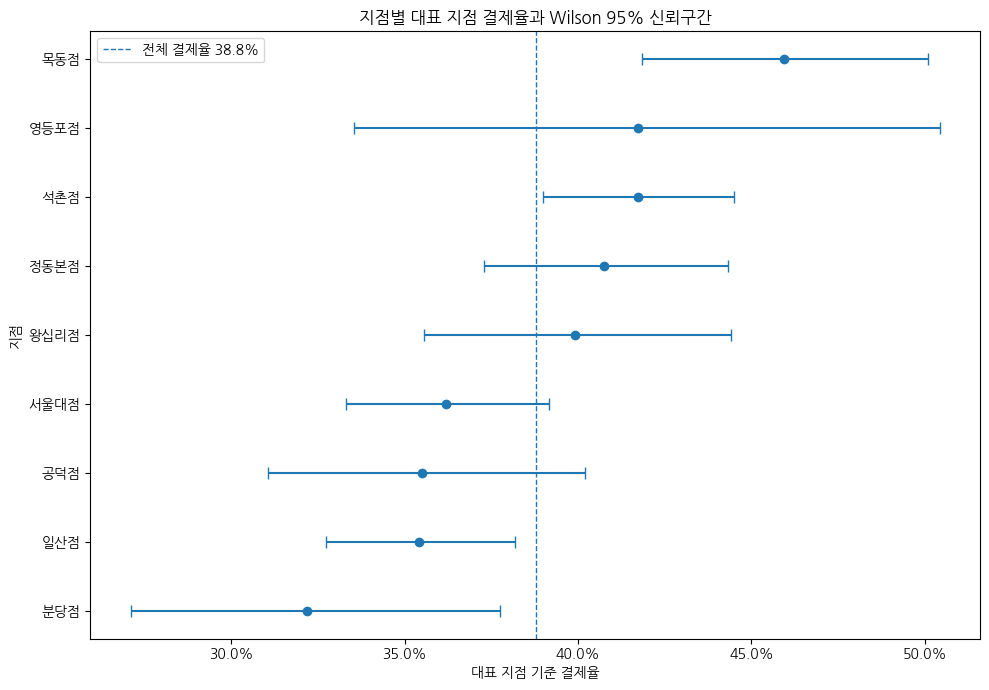

In [ ]:
# 결제율과 Wilson 95% 신뢰구간 시각화

payment_plot = payment_rate_precision_summary.sort_values(
    "representative_site_payment_rate"
).copy()

x_error = np.vstack([
    payment_plot["representative_site_payment_rate"]
    - payment_plot["payment_rate_wilson_low"],
    payment_plot["payment_rate_wilson_high"]
    - payment_plot["representative_site_payment_rate"],
])

overall_representative_payment_rate = primary_site_user_df["is_payment"].mean()

fig, ax = plt.subplots(figsize=(10, 7))
ax.errorbar(
    payment_plot["representative_site_payment_rate"],
    payment_plot["site_name"],
    xerr=x_error,
    fmt="o",
    capsize=4,
)
ax.axvline(
    overall_representative_payment_rate,
    linestyle="--",
    linewidth=1,
    label=f"전체 결제율 {overall_representative_payment_rate:.1%}",
)
ax.set_title("지점별 대표 지점 결제율과 Wilson 95% 신뢰구간")
ax.set_xlabel("대표 지점 기준 결제율")
ax.set_ylabel("지점")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend()
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 목동점의 결제율이 가장 높고 분당점이 가장 낮지만, 여러 지점의 신뢰구간이 겹쳐 단순 순위만으로 성과 차이를 과도하게 해석하면 안 된다.


#### 6-3-1-4. 반복 방문 효과 및 지점 역할 진단

**🔹 분석 목적**

- 1일 방문자와 2일 이상 반복 방문자의 결제율을 지점별로 비교한다.
- 지점 차이를 통제한 공통 오즈비를 산출해 반복 방문 효과가 특정 지점에만 나타나는지 확인한다.
- 절대 수요·면적당 수요·결제율을 함께 비교해 지점을 수요형·전환형·균형형으로 진단한다.


In [ ]:
# 사용자 수준 반복 방문–결제 분석

primary_site_behavior_df = primary_site_user_df.copy()

primary_site_behavior_df["representative_repeat_visit_flag"] = (
    primary_site_behavior_df["site_visit_days"]
    .ge(REPEAT_VISIT_DAY_THRESHOLD)
    .astype("int64")
)

primary_site_behavior_df["representative_multi_site_flag"] = (
    pd.to_numeric(
        primary_site_behavior_df["distinct_site_count"],
        errors="coerce",
    )
    .ge(2)
    .astype("int64")
)

primary_site_behavior_df["is_payment_model"] = pd.to_numeric(
    primary_site_behavior_df["is_payment"],
    errors="raise",
).astype("int64")

primary_site_behavior_df["site_checkin_count_model"] = pd.to_numeric(
    primary_site_behavior_df["site_checkin_count"],
    errors="coerce",
).fillna(0).astype(float)

primary_site_behavior_df["representative_site_id_model"] = (
    primary_site_behavior_df["representative_site_id"]
    .astype(str)
)

repeat_payment_grouped = (
    primary_site_behavior_df
    .groupby(
        ["representative_site_id", "representative_repeat_visit_flag"],
        as_index=False,
    )
    .agg(
        user_count=("user_id", "nunique"),
        payer_count=("is_payment", "sum"),
        payment_rate=("is_payment", "mean"),
    )
)

single_use_summary = (
    repeat_payment_grouped
    .loc[
        repeat_payment_grouped["representative_repeat_visit_flag"].eq(0),
        [
            "representative_site_id",
            "user_count",
            "payer_count",
            "payment_rate",
        ],
    ]
    .rename(columns={
        "user_count": "single_day_user_count",
        "payer_count": "single_day_payer_count",
        "payment_rate": "single_day_payment_rate",
    })
)

repeat_use_summary = (
    repeat_payment_grouped
    .loc[
        repeat_payment_grouped["representative_repeat_visit_flag"].eq(1),
        [
            "representative_site_id",
            "user_count",
            "payer_count",
            "payment_rate",
        ],
    ]
    .rename(columns={
        "user_count": "repeat_user_count",
        "payer_count": "repeat_payer_count",
        "payment_rate": "repeat_payment_rate",
    })
)

site_repeat_payment_summary = (
    single_use_summary
    .merge(
        repeat_use_summary,
        on="representative_site_id",
        how="outer",
        validate="1:1",
    )
    .fillna(0)
    .rename(columns={"representative_site_id": "site_id"})
    .merge(site_name_lookup, on="site_id", how="left", validate="1:1")
)

site_repeat_payment_summary["repeat_payment_lift_pp"] = (
    site_repeat_payment_summary["repeat_payment_rate"]
    - site_repeat_payment_summary["single_day_payment_rate"]
) * 100

# 0셀에 대비한 Haldane–Anscombe 0.5 보정 오즈비
site_repeat_payment_summary["repeat_vs_single_odds_ratio"] = (
    (
        site_repeat_payment_summary["repeat_payer_count"] + 0.5
    )
    * (
        site_repeat_payment_summary["single_day_user_count"]
        - site_repeat_payment_summary["single_day_payer_count"]
        + 0.5
    )
    / (
        (
            site_repeat_payment_summary["repeat_user_count"]
            - site_repeat_payment_summary["repeat_payer_count"]
            + 0.5
        )
        * (
            site_repeat_payment_summary["single_day_payer_count"] + 0.5
        )
    )
)

# 지점을 층으로 둔 Cochran–Mantel–Haenszel 분석
strata_tables = []
included_site_ids = []

for site_id, group in primary_site_behavior_df.groupby(
    "representative_site_id"
):
    repeat_group = group.loc[
        group["representative_repeat_visit_flag"].eq(1)
    ]
    single_group = group.loc[
        group["representative_repeat_visit_flag"].eq(0)
    ]

    table = np.array([
        [
            repeat_group["is_payment"].sum(),
            len(repeat_group) - repeat_group["is_payment"].sum(),
        ],
        [
            single_group["is_payment"].sum(),
            len(single_group) - single_group["is_payment"].sum(),
        ],
    ], dtype=float)

    if (table.sum(axis=0) > 0).all() and (table.sum(axis=1) > 0).all():
        strata_tables.append(table)
        included_site_ids.append(site_id)

if len(strata_tables) < 2:
    raise ValueError("CMH 분석에 사용할 수 있는 지점 층이 부족합니다.")

stratified_table = StratifiedTable(np.dstack(strata_tables))
cmh_null_test = stratified_table.test_null_odds()
breslow_day_test = stratified_table.test_equal_odds(adjust=True)
cmh_ci_low, cmh_ci_high = stratified_table.oddsratio_pooled_confint()

repeat_payment_cmh_result = pd.DataFrame({
    "included_site_count": [len(strata_tables)],
    "included_site_ids": [", ".join(map(str, included_site_ids))],
    "cmh_common_odds_ratio": [stratified_table.oddsratio_pooled],
    "cmh_ci_low": [cmh_ci_low],
    "cmh_ci_high": [cmh_ci_high],
    "cmh_null_odds_p_value": [cmh_null_test.pvalue],
    "breslow_day_equal_odds_p_value": [breslow_day_test.pvalue],
})

# 사용자 수준 로지스틱 회귀: 대표 지점 고정효과
repeat_term = "representative_repeat_visit_flag"

repeat_site_adjusted_model = smf.glm(
    formula=(
        "is_payment_model ~ representative_repeat_visit_flag "
        "+ C(representative_site_id_model)"
    ),
    data=primary_site_behavior_df,
    family=sm.families.Binomial(),
).fit(cov_type="HC0")

repeat_behavior_adjusted_model = smf.glm(
    formula=(
        "is_payment_model ~ representative_repeat_visit_flag "
        "+ np.log1p(site_checkin_count_model) "
        "+ representative_multi_site_flag "
        "+ C(representative_site_id_model)"
    ),
    data=primary_site_behavior_df,
    family=sm.families.Binomial(),
).fit(cov_type="HC0")


def summarize_logistic_term(model, model_name, term):
    confidence_interval = model.conf_int().loc[term]
    beta = model.params[term]

    return {
        "model": model_name,
        "observation_count": int(model.nobs),
        "term": term,
        "adjusted_odds_ratio": np.exp(beta),
        "ci_low": np.exp(confidence_interval.iloc[0]),
        "ci_high": np.exp(confidence_interval.iloc[1]),
        "p_value": model.pvalues[term],
        "aic": model.aic,
    }


repeat_payment_adjusted_result = pd.DataFrame([
    summarize_logistic_term(
        repeat_site_adjusted_model,
        "대표 지점 고정효과",
        repeat_term,
    ),
    summarize_logistic_term(
        repeat_behavior_adjusted_model,
        "대표 지점 + 체크인 수 + 다지점 여부 조정",
        repeat_term,
    ),
])

site_repeat_payment_summary = (
    site_repeat_payment_summary
    .sort_values("repeat_payment_lift_pp", ascending=False)
    .reset_index(drop=True)
)

display(site_repeat_payment_summary)
display(repeat_payment_cmh_result)
display(repeat_payment_adjusted_result)

,site_id,single_day_user_count,single_day_payer_count,single_day_payment_rate,repeat_user_count,repeat_payer_count,repeat_payment_rate,site_name,repeat_payment_lift_pp,repeat_vs_single_odds_ratio
0,4,274,95,0.346715,192,91,0.473958,왕십리점,12.7243,1.694401
1,49,69,25,0.362319,58,28,0.482759,영등포점,12.043978,1.630665
2,1,496,184,0.370968,250,120,0.48,정동본점,10.903226,1.563976
3,3,683,253,0.370425,537,256,0.476723,석촌점,10.629794,1.547406
4,2,586,194,0.331058,442,178,0.402715,서울대점,7.165691,1.36186
5,17,256,84,0.328125,161,64,0.397516,공덕점,6.939053,1.350478
6,47,181,54,0.298343,111,40,0.36036,분당점,6.201782,1.325143
7,5,310,134,0.432258,245,121,0.493878,목동점,6.161949,1.280647
8,6,688,230,0.334302,487,186,0.38193,일산점,4.762786,1.230439


,included_site_count,included_site_ids,cmh_common_odds_ratio,cmh_ci_low,cmh_ci_high,cmh_null_odds_p_value,breslow_day_equal_odds_p_value
0,9,"1, 2, 3, 4, 5, 6, 17, 47, 49",1.414439,1.272734,1.571922,1.163507e-10,0.867517


,model,observation_count,term,adjusted_odds_ratio,ci_low,ci_high,p_value,aic
0,대표 지점 고정효과,6026,representative_repeat_visit_flag,1.41467,1.272930,1.572193,1.194789e-10,7992.262701
1,대표 지점 + 체크인 수 + 다지점 여부 조정,6026,representative_repeat_visit_flag,1.86455,1.631807,2.130489,5.270299e-20,7947.535164


> **💡 결과 해석**
>
> - 모든 지점에서 2일 이상 반복 방문자의 결제율이 1일 방문자보다 높았으며 상승 폭은 약 4.8~12.7%p였다.
> - 지점 차이를 통제한 반복 방문 공통 오즈비는 1.41로, 반복 방문이 지점 전반에서 일관된 전환 신호임을 확인했다.


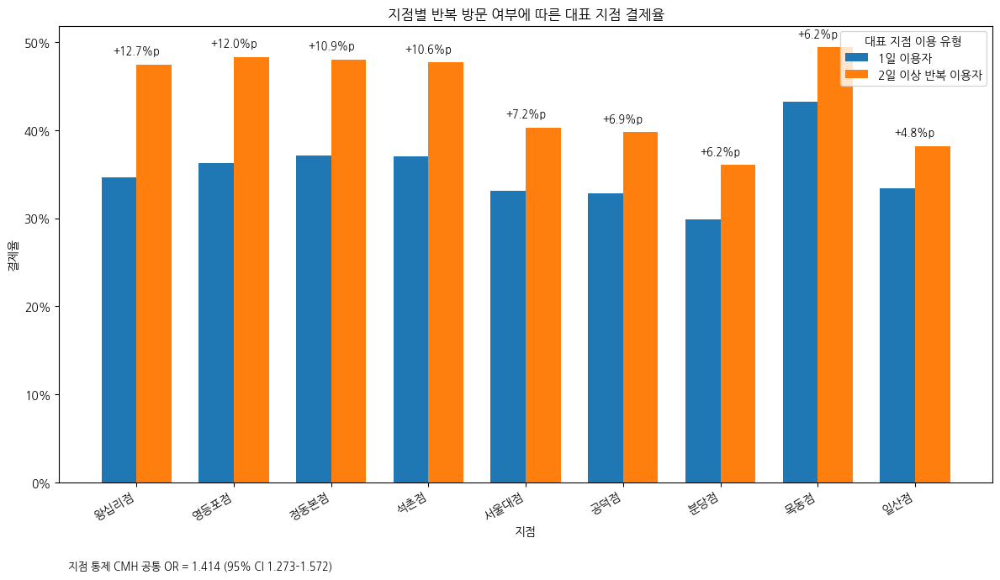

In [ ]:
# 시각화: 지점별 1일 이용자와 반복 방문자의 결제율 비교

repeat_payment_plot = (
    site_repeat_payment_summary
    .sort_values("repeat_payment_lift_pp", ascending=False)
    .reset_index(drop=True)
)

x = np.arange(len(repeat_payment_plot))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(12, 7))
ax.bar(
    x - bar_width / 2,
    repeat_payment_plot["single_day_payment_rate"],
    width=bar_width,
    label="1일 이용자",
)
ax.bar(
    x + bar_width / 2,
    repeat_payment_plot["repeat_payment_rate"],
    width=bar_width,
    label="2일 이상 반복 이용자",
)

ax.set_xticks(x)
ax.set_xticklabels(repeat_payment_plot["site_name"], rotation=30, ha="right")
ax.set_title("지점별 반복 방문 여부에 따른 대표 지점 결제율")
ax.set_xlabel("지점")
ax.set_ylabel("결제율")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(title="대표 지점 이용 유형")

for index, row in repeat_payment_plot.iterrows():
    ax.text(
        index,
        max(row["single_day_payment_rate"], row["repeat_payment_rate"]) + 0.012,
        f"+{row['repeat_payment_lift_pp']:.1f}%p",
        ha="center",
        fontsize=9,
    )

ax.text(
    0.01,
    -0.19,
    "지점 통제 CMH 공통 OR = 1.414 (95% CI 1.273–1.572)",
    transform=ax.transAxes,
    fontsize=9,
)
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 각 지점에서 반복 방문자 막대가 1일 방문자보다 높아, 반복 방문 효과가 특정 지점에만 국한되지 않음을 보여준다.


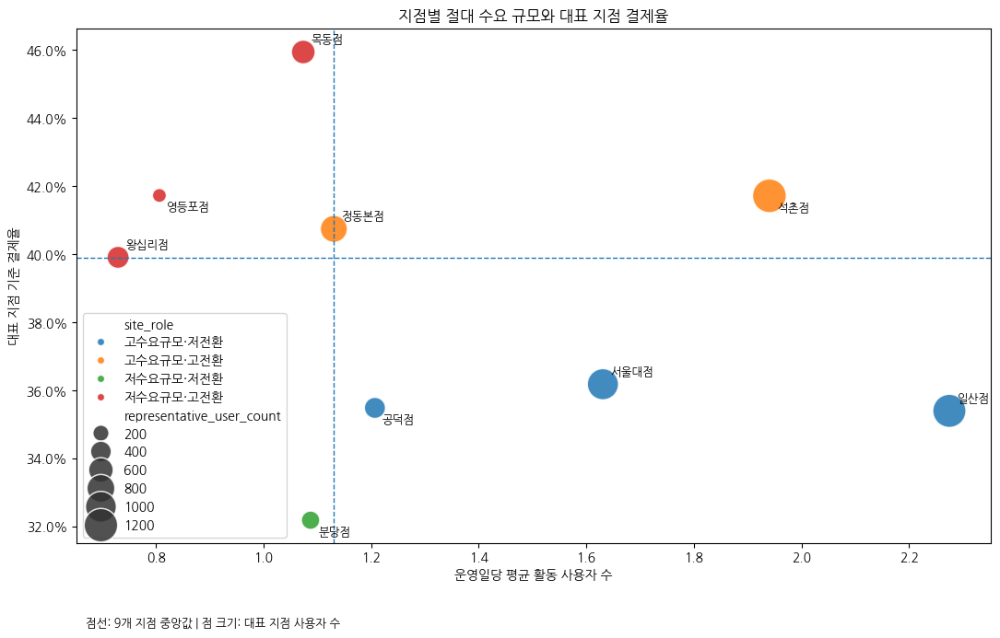

In [ ]:
# 시각화: 절대 수요 규모와 대표 지점 결제율 4분면

plot_scale_conversion = site_performance_summary.copy()

fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(
    data=plot_scale_conversion,
    x="avg_daily_activity_users",
    y="representative_site_payment_rate",
    size="representative_user_count",
    hue="site_role",
    sizes=(120, 700),
    alpha=0.85,
    ax=ax,
)

ax.axvline(demand_scale_median, linestyle="--", linewidth=1)
ax.axhline(conversion_median, linestyle="--", linewidth=1)

for index, row in enumerate(plot_scale_conversion.itertuples()):
    ax.annotate(
        row.site_name,
        (row.avg_daily_activity_users, row.representative_site_payment_rate),
        xytext=(6, 7 if index % 2 == 0 else -12),
        textcoords="offset points",
        fontsize=9,
    )

ax.set_title("지점별 절대 수요 규모와 대표 지점 결제율")
ax.set_xlabel("운영일당 평균 활동 사용자 수")
ax.set_ylabel("대표 지점 기준 결제율")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.text(
    0.01,
    -0.16,
    "점선: 9개 지점 중앙값 | 점 크기: 대표 지점 사용자 수",
    transform=ax.transAxes,
    fontsize=9,
)
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 절대 수요와 결제율을 함께 보면 석촌점·정동본점은 균형 성과형, 일산점은 고수요·저전환형, 목동점은 저수요·고전환형으로 구분된다.


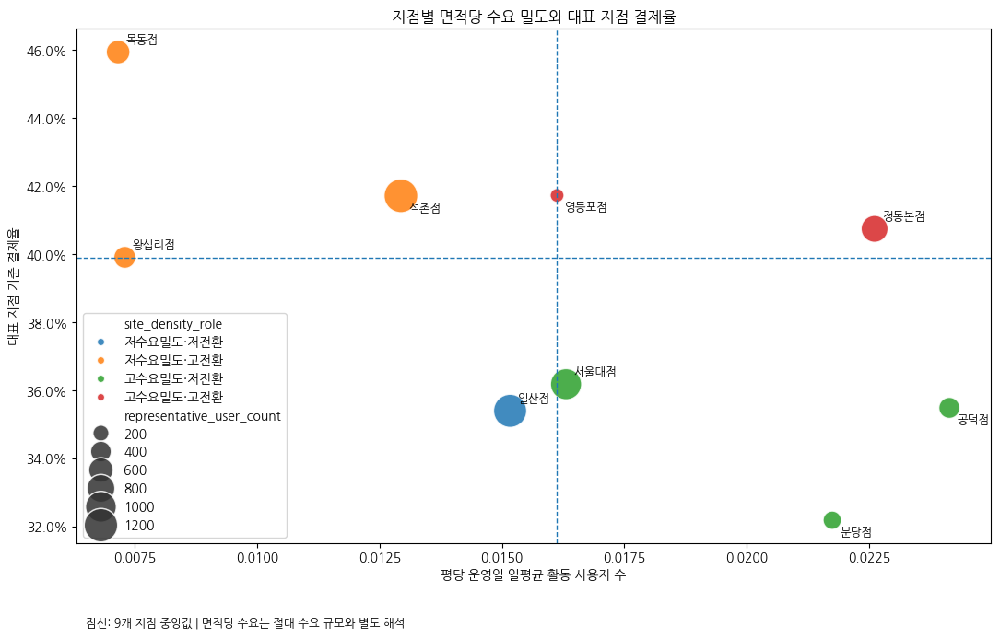

In [ ]:
# 시각화: 면적당 수요 밀도와 대표 지점 결제율 4분면

plot_density_conversion = site_performance_summary.copy()

fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(
    data=plot_density_conversion,
    x="avg_daily_activity_users_per_pyeong",
    y="representative_site_payment_rate",
    size="representative_user_count",
    hue="site_density_role",
    sizes=(120, 700),
    alpha=0.85,
    ax=ax,
)

ax.axvline(demand_density_median, linestyle="--", linewidth=1)
ax.axhline(conversion_median, linestyle="--", linewidth=1)

for index, row in enumerate(plot_density_conversion.itertuples()):
    ax.annotate(
        row.site_name,
        (
            row.avg_daily_activity_users_per_pyeong,
            row.representative_site_payment_rate,
        ),
        xytext=(6, 7 if index % 2 == 0 else -12),
        textcoords="offset points",
        fontsize=9,
    )

ax.set_title("지점별 면적당 수요 밀도와 대표 지점 결제율")
ax.set_xlabel("평당 운영일 일평균 활동 사용자 수")
ax.set_ylabel("대표 지점 기준 결제율")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.text(
    0.01,
    -0.16,
    "점선: 9개 지점 중앙값 | 면적당 수요는 절대 수요 규모와 별도 해석",
    transform=ax.transAxes,
    fontsize=9,
)
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 면적당 수요 기준에서는 공덕점과 정동본점의 공간 효율이 두드러지며, 절대 수요 순위와 다른 지점 역할이 나타난다.


In [ ]:
# 지점 성과표

site_performance_diagnostic_summary = (
    site_performance_summary[
        [
            "site_id",
            "site_name",
            "site_role",
            "site_density_role",
            "area_pyeong",
            "total_unique_visitors",
            "avg_daily_activity_users",
            "demand_scale_rank",
            "avg_daily_activity_users_per_pyeong",
            "demand_density_rank",
            "representative_user_count",
            "representative_site_payment_rate",
            "payment_rate_wilson_low",
            "payment_rate_wilson_high",
            "conversion_rank",
            "repeat_visitor_rate",
            "avg_total_stay_hours_per_complete_visitor",
            "evening_checkin_ratio",
            "weekend_user_site_day_ratio",
        ]
    ]
    .sort_values(["site_role", "demand_scale_rank"])
    .reset_index(drop=True)
)

display(site_performance_diagnostic_summary)

,site_id,site_name,site_role,site_density_role,area_pyeong,total_unique_visitors,avg_daily_activity_users,demand_scale_rank,avg_daily_activity_users_per_pyeong,demand_density_rank,representative_user_count,representative_site_payment_rate,payment_rate_wilson_low,payment_rate_wilson_high,conversion_rank,repeat_visitor_rate,avg_total_stay_hours_per_complete_visitor,evening_checkin_ratio,weekend_user_site_day_ratio
0,3,석촌점,고수요규모·고전환,저수요밀도·고전환,150,1269.0,1.940513,2,0.012937,7,1220,0.417213,0.389846,0.445100,3,0.424744,7.248064,0.268792,0.215645
1,1,정동본점,고수요규모·고전환,고수요밀도·고전환,50,813.0,1.130658,5,0.022613,2,746,0.407507,0.372807,0.443154,4,0.309963,5.841672,0.234912,0.200182
2,6,일산점,고수요규모·저전환,저수요밀도·저전환,150,1218.0,2.275064,1,0.015167,6,1175,0.354043,0.327215,0.381822,8,0.400657,6.971256,0.305260,0.231638
3,2,서울대점,고수요규모·저전환,고수요밀도·저전환,100,1057.0,1.630928,3,0.016309,4,1028,0.361868,0.333057,0.391707,6,0.420057,7.962042,0.279698,0.205436
4,17,공덕점,고수요규모·저전환,고수요밀도·저전환,50,441.0,1.207031,4,0.024141,1,417,0.354916,0.310506,0.401975,7,0.367347,5.582853,0.257537,0.213592
5,5,목동점,저수요규모·고전환,저수요밀도·고전환,150,565.0,1.073834,7,0.007159,9,555,0.459459,0.418419,0.501057,1,0.433628,6.735084,0.283881,0.224367
6,49,영등포점,저수요규모·고전환,고수요밀도·고전환,50,136.0,0.806324,8,0.016126,5,127,0.417323,0.335221,0.504279,2,0.426471,6.311430,0.290419,0.215686
7,4,왕십리점,저수요규모·고전환,저수요밀도·고전환,100,476.0,0.729534,9,0.007295,8,466,0.399142,0.355677,0.444255,5,0.405462,6.655039,0.228164,0.191761
8,47,분당점,저수요규모·저전환,고수요밀도·저전환,50,294.0,1.087404,6,0.021748,3,292,0.321918,0.270941,0.377520,9,0.377551,5.821234,0.319303,0.241135


> **💡 종합 결과**
>
> - 지점은 하나의 순위가 아니라 절대 수요·면적당 수요·결제율의 조합으로 서로 다른 역할을 가진다.
> - 특히 일산점은 수요 확보, 목동점은 전환, 공덕점은 면적 효율에서 상대적 강점을 보였다.


### 6-3-2. 지하철 유동인구 기반 접근성 분석

**🔎 분석 목적**

- 지점 반경 1km 내 지하철 승하차량이 체험 수요와 연결되는지 확인한다.
- 운영기간과 코로나 시기의 차이를 통제해 지점 간 비교의 안정성을 검증한다.
- 지점 면적이 유동량–수요 관계를 교란하는지 부분상관으로 점검한다.
- 유동량의 절대 크기뿐 아니라 평일·주말 구성으로 지점의 수요 유형을 진단한다.

#### 6-3-2-1. 지하철 유동인구 검증 및 접근성 지표 구축

**🔹 분석 목적**

- 일별 지점 수요 테이블과 반경 1km 지하철 승하차 데이터를 날짜·지점 기준으로 연결한다.
- 최인접역 거리, 인접역 수, 일평균 승하차량을 지점별 접근성 지표로 구축한다.
- 지점별 운영기간과 데이터 관측 범위를 확인해 기간 차이에 따른 왜곡 가능성을 사전에 점검한다.


In [ ]:
# 지하철 유동량 자료형 및 Key 검증

subway_flow_analysis = subway_flow.copy()

subway_flow_analysis["calendar_date"] = pd.to_datetime(
    subway_flow_analysis["calendar_date"],
    errors="raise",
).dt.normalize()

subway_flow_analysis["site_id"] = pd.to_numeric(
    subway_flow_analysis["site_id"],
    errors="raise",
).astype("Int64")

if subway_flow_analysis.duplicated(
    ["calendar_date", "site_id"]
).any():
    raise ValueError("subway_flow에 중복 날짜·지점 Key가 있습니다.")

# Dense 수요 테이블에 지하철 유동량 LEFT JOIN
site_day_flow_df = (
    site_day_source
    .merge(
        subway_flow_analysis,
        on=["calendar_date", "site_id"],
        how="left",
        validate="1:1",
    )
    .sort_values(["site_id", "calendar_date"])
    .reset_index(drop=True)
)

subway_columns = [
    "nearby_station_count",
    "nearest_station_name",
    "subway_boarding_1km",
    "subway_alighting_1km",
    "subway_flow_1km",
]

if site_day_flow_df[subway_columns].isna().any().any():
    missing_key_sample = site_day_flow_df.loc[
        site_day_flow_df[subway_columns].isna().any(axis=1),
        ["calendar_date", "site_id"],
    ].head(20)
    raise ValueError(
        "Dense 테이블에 지하철 유동량이 결합되지 않은 Key가 있습니다.\n"
        f"{missing_key_sample}"
    )

site_day_flow_df["subway_flow_per_station_1km"] = (
    site_day_flow_df["subway_flow_1km"]
    / site_day_flow_df["nearby_station_count"]
)

site_day_flow_df["activity_users_per_100k_subway_flow"] = np.where(
    site_day_flow_df["subway_flow_1km"].gt(0),
    site_day_flow_df["activity_user_count"]
    / site_day_flow_df["subway_flow_1km"]
    * 100_000,
    np.nan,
)

site_day_flow_df["checkins_per_100k_subway_flow"] = np.where(
    site_day_flow_df["subway_flow_1km"].gt(0),
    site_day_flow_df["checkin_count"]
    / site_day_flow_df["subway_flow_1km"]
    * 100_000,
    np.nan,
)

site_day_flow_df["activity_users_per_pyeong_day"] = (
    site_day_flow_df["activity_user_count"]
    / site_day_flow_df["area_pyeong"]
)

site_day_flow_df["week_start"] = (
    site_day_flow_df["calendar_date"]
    - pd.to_timedelta(
        site_day_flow_df["calendar_date"].dt.dayofweek,
        unit="D",
    )
)

site_day_flow_df["year_month"] = (
    site_day_flow_df["calendar_date"]
    .dt.to_period("M")
    .astype(str)
)

site_day_flow_df["is_weekend"] = (
    site_day_flow_df["calendar_date"]
    .dt.dayofweek
    .isin([5, 6])
    .astype("Int64")
)

site_day_flow_df["log_subway_flow_1km"] = np.log1p(
    site_day_flow_df["subway_flow_1km"]
)
site_day_flow_df["log_activity_user_count"] = np.log1p(
    site_day_flow_df["activity_user_count"]
)

print("Dense + 지하철 유동량 결합 완료:", site_day_flow_df.shape)
display(site_day_flow_df.head())

Dense + 지하철 유동량 결합 완료: (6586, 59)


,site_id,calendar_date,area_pyeong,visit_info_user_count,access_log_user_count,activity_user_count,visit_record_count,access_record_count,total_stay_seconds,checkin_count,...,subway_alighting_1km,subway_flow_1km,subway_flow_per_station_1km,activity_users_per_100k_subway_flow,checkins_per_100k_subway_flow,activity_users_per_pyeong_day,year_month,is_weekend,log_subway_flow_1km,log_activity_user_count
0,1,2021-05-03,50,1,1,1,1,2,8546,1,...,189420,376062,62677.000000,0.265914,0.265914,0.02,2021-05,0,12.837512,0.693147
1,1,2021-05-04,50,0,0,0,0,0,0,0,...,188480,376371,62728.500000,0.000000,0.000000,0.0,2021-05,0,12.838333,0.0
2,1,2021-05-05,50,0,0,0,0,0,0,0,...,77038,157133,26188.833333,0.000000,0.000000,0.0,2021-05,0,11.964854,0.0
3,1,2021-05-06,50,0,0,0,0,0,0,0,...,189771,376289,62714.833333,0.000000,0.000000,0.0,2021-05,0,12.838115,0.0
4,1,2021-05-07,50,0,0,0,0,0,0,0,...,186485,371801,61966.833333,0.000000,0.000000,0.0,2021-05,0,12.826117,0.0


> **✅ 확인 결과**
>
> - 일별 지점 수요와 지하철 유동량을 결합한 Dense 테이블은 6,586행으로 구축되었으며, 이용이 없는 날짜도 포함한다.


In [ ]:
# 가장 가까운 역까지 거리와 인접역 목록을 별도 정적 접근성 테이블로 생성

site_station_mapping_analysis = build_site_station_mapping(
    SITE_MASTER,
    STATION_MASTER_PATH,
    RADIUS_M,
)

site_station_mapping_analysis = (
    site_station_mapping_analysis
    .sort_values(["site_id", "distance_m", "station_name"])
    .reset_index(drop=True)
)

site_subway_access_summary = (
    site_station_mapping_analysis
    .groupby("site_id", as_index=False)
    .agg(
        nearest_station_name_check=("station_name", "first"),
        nearest_station_distance_m=("distance_m", "min"),
        mean_nearby_station_distance_m=("distance_m", "mean"),
        nearby_station_count_check=("station_name", "nunique"),
        nearby_station_list=(
            "station_name",
            lambda values: " | ".join(values.astype(str).tolist()),
        ),
    )
)

# subway_flow의 정적 정보와 재계산 결과가 일치하는지 확인
subway_static_check = (
    subway_flow_analysis
    .groupby("site_id", as_index=False)
    .agg(
        nearby_station_count=("nearby_station_count", "first"),
        nearest_station_name=("nearest_station_name", "first"),
    )
    .merge(
        site_subway_access_summary,
        on="site_id",
        how="left",
        validate="1:1",
    )
)

if not subway_static_check["nearby_station_count"].eq(
    subway_static_check["nearby_station_count_check"]
).all():
    raise ValueError("인접역 수가 지하철 유동량 테이블과 다릅니다.")

if not subway_static_check["nearest_station_name"].eq(
    subway_static_check["nearest_station_name_check"]
).all():
    raise ValueError("최인접역 이름이 지하철 유동량 테이블과 다릅니다.")

display(site_subway_access_summary)

,site_id,nearest_station_name_check,nearest_station_distance_m,mean_nearby_station_distance_m,nearby_station_count_check,nearby_station_list
0,1,시청,147.256360,628.330692,6,시청 | 광화문 | 을지로입구 | 종각 | 서대문 | 회현
1,2,서울대입구,360.881229,672.658595,2,서울대입구 | 낙성대
2,3,석촌,286.580049,546.020571,3,석촌 | 송파 | 송파나루
3,4,왕십리,164.166057,611.504497,4,왕십리 | 마장 | 상왕십리 | 행당
4,5,오목교,463.534099,689.265531,2,오목교 | 목동
5,6,마두,439.226513,449.546481,2,마두 | 정발산
6,17,공덕,256.138266,539.217801,3,공덕 | 대흥 | 마포
7,47,수내,453.528852,561.935186,2,수내 | 서현
8,49,영등포시장,466.090558,662.773148,3,영등포시장 | 당산 | 영등포구청


> **💡 결과 해석**
>
> - 최인접역 거리는 정동본점 147m, 왕십리점 164m로 가장 짧았고, 정동본점은 반경 1km 내 인접역이 6개로 가장 많았다.


#### 6-3-2-2. 지점 성과 결합 및 공통기간 상관관계 검증

**🔹 분석 목적**

- 지점별 수요·결제 KPI와 지하철 접근성 지표를 하나의 테이블로 결합한다.
- 모든 지점이 동시에 운영된 공통기간을 산출해 전체기간 분석과 비교한다.
- 지하철 유동량과 절대 수요·면적당 수요의 관계를 Spearman 상관과 순열검정으로 확인한다.


In [ ]:
# 상관계수 계산 함수

def safe_correlation(x, y, method="spearman"):
    valid = pd.DataFrame({"x": x, "y": y}).dropna()

    if (
        len(valid) < 3
        or valid["x"].nunique() < 2
        or valid["y"].nunique() < 2
    ):
        return np.nan

    if method == "pearson":
        return pearsonr(valid["x"], valid["y"])[0]

    return spearmanr(valid["x"], valid["y"])[0]


def summarize_site_flow(group):
    weekday_mask = group["calendar_date"].dt.dayofweek.lt(5)
    weekend_mask = group["calendar_date"].dt.dayofweek.ge(5)
    flow_mean = group["subway_flow_1km"].mean()
    total_flow = group["subway_flow_1km"].sum()
    total_activity_user_days = group["activity_user_count"].sum()

    return pd.Series({
        "flow_analysis_start_date": group["calendar_date"].min(),
        "flow_analysis_end_date": group["calendar_date"].max(),
        "flow_observed_days": len(group),
        "nearby_station_count": group["nearby_station_count"].iloc[0],
        "nearest_station_name": group["nearest_station_name"].iloc[0],
        "avg_daily_subway_boarding_1km": group["subway_boarding_1km"].mean(),
        "avg_daily_subway_alighting_1km": group["subway_alighting_1km"].mean(),
        "avg_daily_subway_flow_1km": flow_mean,
        "median_daily_subway_flow_1km": group["subway_flow_1km"].median(),
        "p90_daily_subway_flow_1km": group["subway_flow_1km"].quantile(0.90),
        "peak_daily_subway_flow_1km": group["subway_flow_1km"].max(),
        "weekday_avg_subway_flow_1km": (
            group.loc[weekday_mask, "subway_flow_1km"].mean()
        ),
        "weekend_avg_subway_flow_1km": (
            group.loc[weekend_mask, "subway_flow_1km"].mean()
        ),
        "weekday_weekend_flow_ratio": (
            group.loc[weekday_mask, "subway_flow_1km"].mean()
            / group.loc[weekend_mask, "subway_flow_1km"].mean()
            if group.loc[weekend_mask, "subway_flow_1km"].mean() > 0
            else np.nan
        ),
        "subway_flow_volatility_cv": (
            group["subway_flow_1km"].std(ddof=1) / flow_mean
            if flow_mean > 0
            else np.nan
        ),
        "avg_daily_subway_flow_per_station_1km": (
            group["subway_flow_per_station_1km"].mean()
        ),
        "total_activity_user_days_flow_period": total_activity_user_days,
        "avg_daily_activity_users_flow_period": group[
            "activity_user_count"
        ].mean(),
        "avg_daily_activity_users_per_pyeong_flow_period": group[
            "activity_users_per_pyeong_day"
        ].mean(),
        "activity_users_per_100k_subway_flow": (
            total_activity_user_days / total_flow * 100_000
            if total_flow > 0
            else np.nan
        ),
        "mean_daily_activity_users_per_100k_subway_flow": group[
            "activity_users_per_100k_subway_flow"
        ].mean(),
        "flow_activity_spearman_all_days": safe_correlation(
            group["subway_flow_1km"],
            group["activity_user_count"],
            method="spearman",
        ),
        "flow_activity_pearson_log_all_days": safe_correlation(
            group["log_subway_flow_1km"],
            group["log_activity_user_count"],
            method="pearson",
        ),
        "flow_activity_spearman_weekdays": safe_correlation(
            group.loc[weekday_mask, "subway_flow_1km"],
            group.loc[weekday_mask, "activity_user_count"],
            method="spearman",
        ),
        "flow_activity_spearman_post_covid_policy": safe_correlation(
            group.loc[
                group["covid_period_flag"].eq(0),
                "subway_flow_1km",
            ],
            group.loc[
                group["covid_period_flag"].eq(0),
                "activity_user_count",
            ],
            method="spearman",
        ),
    })


site_subway_flow_kpi_summary = (
    site_day_flow_df
    .groupby("site_id")
    .apply(summarize_site_flow, include_groups=False)
    .reset_index()
    .merge(
        site_subway_access_summary,
        on="site_id",
        how="left",
        validate="1:1",
    )
    .merge(
        site_name_lookup,
        on="site_id",
        how="left",
        validate="1:1",
    )
)

site_subway_flow_kpi_summary["accessibility_flow_rank"] = (
    site_subway_flow_kpi_summary["avg_daily_subway_flow_1km"]
    .rank(ascending=False, method="min")
    .astype("Int64")
)

site_subway_flow_kpi_summary["flow_capture_rank"] = (
    site_subway_flow_kpi_summary[
        "activity_users_per_100k_subway_flow"
    ]
    .rank(ascending=False, method="min")
    .astype("Int64")
)

site_subway_flow_kpi_summary = (
    site_subway_flow_kpi_summary
    .sort_values("accessibility_flow_rank")
    .reset_index(drop=True)
)

display(site_subway_flow_kpi_summary)

,site_id,flow_analysis_start_date,flow_analysis_end_date,flow_observed_days,nearby_station_count,nearest_station_name,avg_daily_subway_boarding_1km,avg_daily_subway_alighting_1km,avg_daily_subway_flow_1km,median_daily_subway_flow_1km,...,flow_activity_spearman_weekdays,flow_activity_spearman_post_covid_policy,nearest_station_name_check,nearest_station_distance_m,mean_nearby_station_distance_m,nearby_station_count_check,nearby_station_list,site_name,accessibility_flow_rank,flow_capture_rank
0,1,2021-05-03,2023-12-30,972,6,시청,176639.897119,177674.888889,354314.786008,384708.0,...,-0.003703,0.215013,시청,147.256360,628.330692,6,시청 | 광화문 | 을지로입구 | 종각 | 서대문 | 회현,정동본점,1,9
1,49,2023-04-22,2023-12-30,253,3,영등포시장,69666.648221,72943.367589,142610.015810,164837.0,...,0.153053,0.176004,영등포시장,466.090558,662.773148,3,영등포시장 | 당산 | 영등포구청,영등포점,2,8
2,2,2021-05-06,2023-12-31,970,2,서울대입구,67753.010309,65915.926804,133668.937113,144992.0,...,-0.167832,0.156957,서울대입구,360.881229,672.658595,2,서울대입구 | 낙성대,서울대점,3,5
3,17,2022-08-08,2024-01-01,512,3,공덕,58272.361328,59180.402344,117452.763672,138757.5,...,0.034703,0.105179,공덕,256.138266,539.217801,3,공덕 | 대흥 | 마포,공덕점,4,6
4,4,2021-05-12,2024-01-01,965,4,왕십리,58166.317098,56187.370984,114353.688083,121399.0,...,-0.148505,0.180466,왕십리,164.166057,611.504497,4,왕십리 | 마장 | 상왕십리 | 행당,왕십리점,5,7
5,47,2022-12-09,2024-01-01,389,2,수내,36330.467866,36546.439589,72876.907455,83119.0,...,0.105200,0.182199,수내,453.528852,561.935186,2,수내 | 서현,분당점,6,4
6,5,2021-09-03,2023-10-14,772,2,오목교,34425.897668,36582.446891,71008.344560,79442.0,...,-0.126933,0.180559,오목교,463.534099,689.265531,2,오목교 | 목동,목동점,7,3
7,3,2021-05-02,2024-01-01,975,3,석촌,27416.412308,27921.987692,55338.400000,57399.0,...,-0.134072,0.233015,석촌,286.580049,546.020571,3,석촌 | 송파 | 송파나루,석촌점,8,2
8,6,2021-11-15,2024-01-01,778,2,마두,13998.787918,14317.339332,28316.127249,30131.5,...,-0.045232,0.154482,마두,439.226513,449.546481,2,마두 | 정발산,일산점,9,1


> **✅ 확인 결과**
>
> - 지점별 지하철 유동량 관측기간과 인접역 정보를 정리해 운영기간 차이를 비교할 수 있는 접근성 KPI 테이블을 구축했다.


In [ ]:
# 지점 성과와 지하철 접근성 KPI 결합

flow_merge_columns = [
    "site_id", "nearby_station_count", "nearest_station_name",
    "nearest_station_distance_m", "mean_nearby_station_distance_m",
    "nearby_station_list", "avg_daily_subway_flow_1km",
    "median_daily_subway_flow_1km", "p90_daily_subway_flow_1km",
    "weekday_avg_subway_flow_1km", "weekend_avg_subway_flow_1km",
    "weekday_weekend_flow_ratio", "subway_flow_volatility_cv",
    "avg_daily_subway_flow_per_station_1km",
    "activity_users_per_100k_subway_flow",
    "mean_daily_activity_users_per_100k_subway_flow",
    "flow_activity_spearman_all_days",
    "flow_activity_pearson_log_all_days",
    "flow_activity_spearman_weekdays",
    "flow_activity_spearman_post_covid_policy",
    "accessibility_flow_rank", "flow_capture_rank",
]

site_performance_flow_summary = (
    site_performance_summary
    .merge(
        site_subway_flow_kpi_summary[flow_merge_columns],
        on="site_id",
        how="left",
        validate="1:1",
    )
)

# 거리·인접역 수·유동량을 결합한 접근성 종합지수
site_performance_flow_summary["accessibility_flow_z"] = zscore(
    np.log1p(site_performance_flow_summary["avg_daily_subway_flow_1km"])
)
site_performance_flow_summary["accessibility_station_count_z"] = zscore(
    site_performance_flow_summary["nearby_station_count"]
)
site_performance_flow_summary["accessibility_distance_z"] = zscore(
    -site_performance_flow_summary["nearest_station_distance_m"]
)
site_performance_flow_summary["accessibility_composite_index"] = (
    site_performance_flow_summary[
        [
            "accessibility_flow_z",
            "accessibility_station_count_z",
            "accessibility_distance_z",
        ]
    ].mean(axis=1)
)
site_performance_flow_summary["flow_capture_index_z"] = zscore(
    site_performance_flow_summary["activity_users_per_100k_subway_flow"]
)
site_performance_flow_summary["accessibility_rank"] = (
    site_performance_flow_summary["accessibility_composite_index"]
    .rank(ascending=False, method="min")
    .astype("Int64")
)

# 접근성 × 절대 수요 규모 역할 진단
accessibility_median = site_performance_flow_summary[
    "accessibility_composite_index"
].median()
scale_median_for_access = site_performance_flow_summary[
    "avg_daily_activity_users"
].median()
high_access = site_performance_flow_summary[
    "accessibility_composite_index"
].ge(accessibility_median)
high_scale_for_access = site_performance_flow_summary[
    "avg_daily_activity_users"
].ge(scale_median_for_access)

site_performance_flow_summary["access_demand_role"] = np.select(
    [
        high_access & high_scale_for_access,
        high_access & ~high_scale_for_access,
        ~high_access & high_scale_for_access,
        ~high_access & ~high_scale_for_access,
    ],
    [
        "높은 접근성·높은 수요",
        "높은 접근성·낮은 수요(포착 개선)",
        "낮은 접근성·높은 수요(비지하철 강점)",
        "낮은 접근성·낮은 수요",
    ],
    default="분류 불가",
)

site_performance_flow_summary = (
    site_performance_flow_summary
    .sort_values("accessibility_rank")
    .reset_index(drop=True)
)

display(
    site_performance_flow_summary[
        [
            "site_id", "site_name", "nearest_station_name",
            "nearest_station_distance_m", "nearby_station_count",
            "avg_daily_subway_flow_1km", "accessibility_rank",
            "avg_daily_activity_users", "demand_scale_rank",
            "avg_daily_activity_users_per_pyeong", "demand_density_rank",
            "activity_users_per_100k_subway_flow", "flow_capture_rank",
            "representative_site_payment_rate", "site_role",
            "site_density_role", "access_demand_role",
        ]
    ]
)

,site_id,site_name,nearest_station_name,nearest_station_distance_m,nearby_station_count,avg_daily_subway_flow_1km,accessibility_rank,avg_daily_activity_users,demand_scale_rank,avg_daily_activity_users_per_pyeong,demand_density_rank,activity_users_per_100k_subway_flow,flow_capture_rank,representative_site_payment_rate,site_role,site_density_role,access_demand_role
0,1,정동본점,시청,147.256360,6,354314.786008,1,1.130658,5,0.022613,2,0.319111,9,0.407507,고수요규모·고전환,고수요밀도·고전환,높은 접근성·높은 수요
1,4,왕십리점,왕십리,164.166057,4,114353.688083,2,0.729534,9,0.007295,8,0.637963,7,0.399142,저수요규모·고전환,저수요밀도·고전환,높은 접근성·낮은 수요(포착 개선)
2,17,공덕점,공덕,256.138266,3,117452.763672,3,1.207031,4,0.024141,1,1.027674,6,0.354916,고수요규모·저전환,고수요밀도·저전환,높은 접근성·높은 수요
3,3,석촌점,석촌,286.580049,3,55338.400000,4,1.940513,2,0.012937,7,3.506630,2,0.417213,고수요규모·고전환,저수요밀도·고전환,높은 접근성·높은 수요
4,49,영등포점,영등포시장,466.090558,3,142610.015810,5,0.806324,8,0.016126,5,0.565405,8,0.417323,저수요규모·고전환,고수요밀도·고전환,높은 접근성·낮은 수요(포착 개선)
5,2,서울대점,서울대입구,360.881229,2,133668.937113,6,1.630928,3,0.016309,4,1.220125,5,0.361868,고수요규모·저전환,고수요밀도·저전환,낮은 접근성·높은 수요(비지하철 강점)
6,47,분당점,수내,453.528852,2,72876.907455,7,1.087404,6,0.021748,3,1.492110,4,0.321918,저수요규모·저전환,고수요밀도·저전환,낮은 접근성·낮은 수요
7,5,목동점,오목교,463.534099,2,71008.344560,8,1.073834,7,0.007159,9,1.512265,3,0.459459,저수요규모·고전환,저수요밀도·고전환,낮은 접근성·낮은 수요
8,6,일산점,마두,439.226513,2,28316.127249,9,2.275064,1,0.015167,6,8.034518,1,0.354043,고수요규모·저전환,저수요밀도·저전환,낮은 접근성·높은 수요(비지하철 강점)


> **💡 결과 해석**
>
> - 정동본점은 일평균 지하철 유동량이 약 35.4만 명으로 가장 높지만 운영일당 체험 수요는 1위가 아니었다.
> - 반대로 일산점은 유동량이 가장 낮지만 운영일당 활동 사용자는 가장 높아 절대 유동량과 수요 순위가 일치하지 않았다.


In [ ]:
# 9개 지점 공통 운영기간 자동 산출

site_period_bounds = (
    site_day_flow_df
    .groupby("site_id", as_index=False)
    .agg(site_start_date=("calendar_date", "min"), site_end_date=("calendar_date", "max"))
)

common_period_start = site_period_bounds["site_start_date"].max()
common_period_end = site_period_bounds["site_end_date"].min()

if common_period_start > common_period_end:
    raise ValueError("9개 지점이 동시에 관측되는 공통기간이 없습니다.")

common_period_site_day_df = site_day_flow_df.loc[
    site_day_flow_df["calendar_date"].between(
        common_period_start,
        common_period_end,
        inclusive="both",
    )
].copy()

common_site_count = common_period_site_day_df["site_id"].nunique()
expected_site_count = site_day_flow_df["site_id"].nunique()
if common_site_count != expected_site_count:
    raise ValueError(
        f"공통기간 지점 수가 다릅니다: {common_site_count} / {expected_site_count}"
    )

print(
    "9개 지점 공통기간:",
    common_period_start.date(),
    "~",
    common_period_end.date(),
)
print("공통기간 지점·일 행 수:", len(common_period_site_day_df))
display(site_period_bounds.merge(site_name_lookup, on="site_id", how="left"))

9개 지점 공통기간: 2023-04-22 ~ 2023-10-14
공통기간 지점·일 행 수: 1584


,site_id,site_start_date,site_end_date,site_name
0,1,2021-05-03,2023-12-30,정동본점
1,2,2021-05-06,2023-12-31,서울대점
2,3,2021-05-02,2024-01-01,석촌점
3,4,2021-05-12,2024-01-01,왕십리점
4,5,2021-09-03,2023-10-14,목동점
5,6,2021-11-15,2024-01-01,일산점
6,17,2022-08-08,2024-01-01,공덕점
7,47,2022-12-09,2024-01-01,분당점
8,49,2023-04-22,2023-12-30,영등포점


> **✅ 확인 결과**
>
> - 9개 지점이 동시에 관측되는 공통기간은 2023년 4월 22일부터 2023년 10월 14일까지이며, 총 1,584개의 지점·일 관측치를 확보했다.


In [ ]:
# 전체기간과 공통기간 KPI 비교

def summarize_period_site(frame, prefix):
    summary = (
        frame
        .groupby("site_id", as_index=False)
        .agg(
            operating_days=("calendar_date", "nunique"),
            avg_daily_subway_flow_1km=("subway_flow_1km", "mean"),
            avg_daily_activity_users=("activity_user_count", "mean"),
            avg_daily_activity_users_per_pyeong=(
                "activity_users_per_pyeong_day",
                "mean",
            ),
            total_activity_user_days=("activity_user_count", "sum"),
            area_pyeong=("area_pyeong", "first"),
        )
    )
    return summary.rename(
        columns={
            column: f"{prefix}_{column}"
            for column in summary.columns
            if column != "site_id"
        }
    )


full_period_summary = summarize_period_site(site_day_flow_df, "full")
common_period_summary = summarize_period_site(common_period_site_day_df, "common")

period_comparison_summary = (
    full_period_summary
    .merge(common_period_summary, on="site_id", how="inner", validate="1:1")
    .merge(site_name_lookup, on="site_id", how="left", validate="1:1")
)

for prefix in ["full", "common"]:
    period_comparison_summary[f"{prefix}_flow_rank"] = (
        period_comparison_summary[f"{prefix}_avg_daily_subway_flow_1km"]
        .rank(ascending=False, method="min")
        .astype("Int64")
    )
    period_comparison_summary[f"{prefix}_demand_scale_rank"] = (
        period_comparison_summary[f"{prefix}_avg_daily_activity_users"]
        .rank(ascending=False, method="min")
        .astype("Int64")
    )
    period_comparison_summary[f"{prefix}_demand_density_rank"] = (
        period_comparison_summary[
            f"{prefix}_avg_daily_activity_users_per_pyeong"
        ]
        .rank(ascending=False, method="min")
        .astype("Int64")
    )

period_comparison_summary["flow_rank_change_common_minus_full"] = (
    period_comparison_summary["common_flow_rank"]
    - period_comparison_summary["full_flow_rank"]
)
period_comparison_summary["demand_scale_rank_change_common_minus_full"] = (
    period_comparison_summary["common_demand_scale_rank"]
    - period_comparison_summary["full_demand_scale_rank"]
)
period_comparison_summary["demand_density_rank_change_common_minus_full"] = (
    period_comparison_summary["common_demand_density_rank"]
    - period_comparison_summary["full_demand_density_rank"]
)
period_comparison_summary["subway_flow_change_pct"] = (
    period_comparison_summary["common_avg_daily_subway_flow_1km"]
    / period_comparison_summary["full_avg_daily_subway_flow_1km"]
    - 1
) * 100

period_comparison_summary = period_comparison_summary.sort_values(
    "common_flow_rank"
).reset_index(drop=True)

display(period_comparison_summary)

,site_id,full_operating_days,full_avg_daily_subway_flow_1km,full_avg_daily_activity_users,full_avg_daily_activity_users_per_pyeong,full_total_activity_user_days,full_area_pyeong,common_operating_days,common_avg_daily_subway_flow_1km,common_avg_daily_activity_users,...,full_flow_rank,full_demand_scale_rank,full_demand_density_rank,common_flow_rank,common_demand_scale_rank,common_demand_density_rank,flow_rank_change_common_minus_full,demand_scale_rank_change_common_minus_full,demand_density_rank_change_common_minus_full,subway_flow_change_pct
0,1,972,354314.786008,1.130658,0.022613,1099,50,176,396311.085227,0.835227,...,1,5,2,1,5,2,0,0,0,11.852822
1,49,253,142610.015810,0.806324,0.016126,204,50,176,140092.960227,0.670455,...,2,8,5,2,8,4,0,0,-1,-1.764992
2,2,970,133668.937113,1.630928,0.016309,1582,100,176,137770.755682,1.278409,...,3,3,4,3,3,6,0,0,2,3.068640
3,4,965,114353.688083,0.729534,0.007295,704,100,176,120474.732955,0.272727,...,5,9,8,4,9,9,-1,0,1,5.352731
4,17,512,117452.763672,1.207031,0.024141,618,50,176,116567.295455,1.028409,...,4,4,1,5,4,1,1,0,0,-0.753893
5,5,772,71008.344560,1.073834,0.007159,829,150,176,73078.886364,0.676136,...,7,7,9,6,7,8,-1,0,-1,2.915913
6,47,389,72876.907455,1.087404,0.021748,423,50,176,70896.306818,0.698864,...,6,6,3,7,6,3,1,0,0,-2.717734
7,3,975,55338.400000,1.940513,0.012937,1892,150,176,59679.681818,1.568182,...,8,2,7,8,2,7,0,0,0,7.844972
8,6,778,28316.127249,2.275064,0.015167,1770,150,176,29812.545455,1.931818,...,9,1,6,9,1,5,0,0,-1,5.284685


> **💡 결과 해석**
>
> - 전체 운영기간과 공통기간 KPI를 함께 비교해 신규 지점의 짧은 운영기간이 수요·유동량 관계를 왜곡하는지 점검할 수 있도록 구성했다.


In [ ]:
# 전체기간, 공통기간 접근성 – 수요 상관 비교 및 순열검정

def permutation_spearman_test(x, y, permutation_count=PERMUTATION_COUNT, seed=RANDOM_SEED):
    valid = pd.DataFrame({"x": x, "y": y}).dropna()
    if len(valid) < 4 or valid["x"].nunique() < 2 or valid["y"].nunique() < 2:
        return np.nan, np.nan

    observed = spearmanr(valid["x"], valid["y"])[0]
    rng = np.random.default_rng(seed)
    permuted = np.empty(permutation_count)
    x_values = valid["x"].to_numpy()
    y_values = valid["y"].to_numpy()

    for index in range(permutation_count):
        permuted[index] = spearmanr(x_values, rng.permutation(y_values))[0]

    p_value = (
        np.sum(np.abs(permuted) >= abs(observed)) + 1
    ) / (permutation_count + 1)
    return observed, p_value


period_correlation_rows = []
for period_name, frame, flow_col, scale_col, density_col in [
    (
        "전체 운영기간",
        period_comparison_summary,
        "full_avg_daily_subway_flow_1km",
        "full_avg_daily_activity_users",
        "full_avg_daily_activity_users_per_pyeong",
    ),
    (
        "9개 지점 공통기간",
        period_comparison_summary,
        "common_avg_daily_subway_flow_1km",
        "common_avg_daily_activity_users",
        "common_avg_daily_activity_users_per_pyeong",
    ),
]:
    for metric_name, metric_col in [
        ("절대 수요 규모", scale_col),
        ("면적당 수요 밀도", density_col),
    ]:
        rho, permutation_p = permutation_spearman_test(
            frame[flow_col],
            frame[metric_col],
            seed=RANDOM_SEED + len(period_correlation_rows),
        )
        period_correlation_rows.append({
            "analysis_period": period_name,
            "demand_metric": metric_name,
            "site_count": len(frame),
            "spearman_correlation": rho,
            "permutation_p_value": permutation_p,
        })

period_correlation_result = pd.DataFrame(period_correlation_rows)
display(period_correlation_result)

,analysis_period,demand_metric,site_count,spearman_correlation,permutation_p_value
0,전체 운영기간,절대 수요 규모,9,-0.400000,0.294471
1,전체 운영기간,면적당 수요 밀도,9,0.566667,0.121288
2,9개 지점 공통기간,절대 수요 규모,9,-0.500000,0.179282
3,9개 지점 공통기간,면적당 수요 밀도,9,0.233333,0.547545


> **💡 결과 해석**
>
> - 전체기간 지하철 유동량과 절대 수요의 상관은 -0.40, 면적당 수요는 0.57이었으나 모두 유의하지 않았다.
> - 공통기간에서도 유의한 관계가 확인되지 않아 절대 유동량만으로 지점 수요를 설명하기 어려웠다.


#### 6-3-2-3. 접근성·이용행태·결제 관계 및 민감도 분석

**🔹 분석 목적**

- 지하철 유동량과 접근성 종합지수가 수요 및 결제율과 연결되는지 비교한다.
- 반복 방문률·체류시간·다지점 이용률 등 행동 지표와 결제율의 관계도 함께 확인한다.
- 한 지점씩 제외하는 분석으로 특정 지점이 전체 상관 방향을 과도하게 좌우하는지 점검한다.


In [ ]:
# 접근성, 행동, 결제 간 지점 수준 관계

relationship_specs = [
    (
        "지하철 유동량 ↔ 절대 수요 규모",
        "avg_daily_subway_flow_1km",
        "avg_daily_activity_users",
    ),
    (
        "지하철 유동량 ↔ 면적당 수요 밀도",
        "avg_daily_subway_flow_1km",
        "avg_daily_activity_users_per_pyeong",
    ),
    (
        "접근성 종합지수 ↔ 절대 수요 규모",
        "accessibility_composite_index",
        "avg_daily_activity_users",
    ),
    (
        "접근성 종합지수 ↔ 결제율",
        "accessibility_composite_index",
        "representative_site_payment_rate",
    ),
    (
        "지하철 유동량 ↔ 결제율",
        "avg_daily_subway_flow_1km",
        "representative_site_payment_rate",
    ),
    (
        "반복 방문률 ↔ 결제율",
        "repeat_visitor_rate",
        "representative_site_payment_rate",
    ),
    (
        "평균 총 체류시간 ↔ 결제율",
        "avg_total_stay_hours_per_complete_visitor",
        "representative_site_payment_rate",
    ),
    (
        "다지점 이용자 비율 ↔ 결제율",
        "multi_site_visitor_rate",
        "representative_site_payment_rate",
    ),
]

site_relationship_rows = []
for index, (relationship_name, x_column, y_column) in enumerate(relationship_specs):
    valid = site_performance_flow_summary[
        ["site_id", "site_name", x_column, y_column]
    ].dropna()

    rho, permutation_p = permutation_spearman_test(
        valid[x_column],
        valid[y_column],
        seed=RANDOM_SEED + 100 + index,
    )
    analytic_p = (
        spearmanr(valid[x_column], valid[y_column]).pvalue
        if len(valid) >= 3 else np.nan
    )

    site_relationship_rows.append({
        "relationship": relationship_name,
        "x_column": x_column,
        "y_column": y_column,
        "site_count": len(valid),
        "spearman_correlation": rho,
        "analytic_p_value": analytic_p,
        "permutation_p_value": permutation_p,
    })

site_relationship_result = pd.DataFrame(site_relationship_rows)
site_relationship_result["holm_adjusted_permutation_p_value"] = multipletests(
    site_relationship_result["permutation_p_value"].fillna(1),
    method="holm",
)[1]
site_relationship_result["significant_after_holm_05"] = (
    site_relationship_result["holm_adjusted_permutation_p_value"] < 0.05
)

display(site_relationship_result)

,relationship,x_column,y_column,site_count,spearman_correlation,analytic_p_value,permutation_p_value,holm_adjusted_permutation_p_value,significant_after_holm_05
0,지하철 유동량 ↔ 절대 수요 규모,avg_daily_subway_flow_1km,avg_daily_activity_users,9,-0.400000,0.286105,0.292371,1.000000,False
1,지하철 유동량 ↔ 면적당 수요 밀도,avg_daily_subway_flow_1km,avg_daily_activity_users_per_pyeong,9,0.566667,0.111633,0.117988,0.825917,False
2,접근성 종합지수 ↔ 절대 수요 규모,accessibility_composite_index,avg_daily_activity_users,9,-0.283333,0.460030,0.460754,1.000000,False
3,접근성 종합지수 ↔ 결제율,accessibility_composite_index,representative_site_payment_rate,9,0.183333,0.636820,0.637636,1.000000,False
4,지하철 유동량 ↔ 결제율,avg_daily_subway_flow_1km,representative_site_payment_rate,9,0.183333,0.636820,0.637736,1.000000,False
5,반복 방문률 ↔ 결제율,repeat_visitor_rate,representative_site_payment_rate,9,0.683333,0.042442,0.050295,0.402360,False
6,평균 총 체류시간 ↔ 결제율,avg_total_stay_hours_per_complete_visitor,representative_site_payment_rate,9,0.250000,0.516490,0.516048,1.000000,False
7,다지점 이용자 비율 ↔ 결제율,multi_site_visitor_rate,representative_site_payment_rate,9,0.100000,0.797972,0.807319,1.000000,False


> **💡 결과 해석**
>
> - 접근성·유동량과 결제율의 상관은 약 0.18로 약했고, 다지점 이용률과 결제율도 뚜렷한 관계가 없었다.
> - 반복 방문률과 결제율은 ρ=0.683으로 가장 강한 양의 관계를 보였지만 다중검정 보정 후 유의하지 않아 탐색적으로 해석한다.


In [ ]:
# 한 지점씩 제외하는 Leave-One-Site-Out 영향도 분석

leave_one_site_out_rows = []

for relationship_name, x_column, y_column in relationship_specs:
    valid = site_performance_flow_summary[
        ["site_id", "site_name", x_column, y_column]
    ].dropna()

    full_rho = safe_correlation(valid[x_column], valid[y_column], method="spearman")

    for excluded in valid.itertuples(index=False):
        subset = valid.loc[valid["site_id"].ne(excluded.site_id)]
        loo_rho = safe_correlation(
            subset[x_column], subset[y_column], method="spearman"
        )
        leave_one_site_out_rows.append({
            "relationship": relationship_name,
            "excluded_site_id": excluded.site_id,
            "excluded_site_name": excluded.site_name,
            "full_spearman": full_rho,
            "leave_one_out_spearman": loo_rho,
            "absolute_change_from_full": abs(loo_rho - full_rho),
            "same_direction_as_full": (
                np.sign(loo_rho) == np.sign(full_rho)
                if pd.notna(loo_rho) and pd.notna(full_rho) and full_rho != 0
                else np.nan
            ),
        })

leave_one_site_out_detail = pd.DataFrame(leave_one_site_out_rows)
leave_one_site_out_summary = (
    leave_one_site_out_detail
    .groupby("relationship", as_index=False)
    .agg(
        full_spearman=("full_spearman", "first"),
        min_leave_one_out_spearman=("leave_one_out_spearman", "min"),
        max_leave_one_out_spearman=("leave_one_out_spearman", "max"),
        median_leave_one_out_spearman=("leave_one_out_spearman", "median"),
        direction_consistency_rate=("same_direction_as_full", "mean"),
        maximum_absolute_change=("absolute_change_from_full", "max"),
    )
)

most_influential_site = (
    leave_one_site_out_detail
    .sort_values(["relationship", "absolute_change_from_full"], ascending=[True, False])
    .groupby("relationship", as_index=False)
    .first()[
        [
            "relationship", "excluded_site_id", "excluded_site_name",
            "absolute_change_from_full",
        ]
    ]
    .rename(columns={
        "excluded_site_id": "most_influential_site_id",
        "excluded_site_name": "most_influential_site_name",
        "absolute_change_from_full": "influential_absolute_change",
    })
)
leave_one_site_out_summary = leave_one_site_out_summary.merge(
    most_influential_site,
    on="relationship",
    how="left",
    validate="1:1",
)

display(leave_one_site_out_summary)
display(leave_one_site_out_detail.sort_values("absolute_change_from_full", ascending=False).head(20))

,relationship,full_spearman,min_leave_one_out_spearman,max_leave_one_out_spearman,median_leave_one_out_spearman,direction_consistency_rate,maximum_absolute_change,most_influential_site_id,most_influential_site_name,influential_absolute_change
0,다지점 이용자 비율 ↔ 결제율,0.100000,-0.285714,0.380952,0.095238,0.888889,0.385714,47,분당점,0.385714
1,반복 방문률 ↔ 결제율,0.683333,0.547619,0.904762,0.690476,1.000000,0.221429,1,정동본점,0.221429
2,접근성 종합지수 ↔ 결제율,0.183333,-0.119048,0.523810,0.166667,0.888889,0.340476,5,목동점,0.340476
3,접근성 종합지수 ↔ 절대 수요 규모,-0.283333,-0.428571,0.023810,-0.309524,0.888889,0.307143,6,일산점,0.307143
4,지하철 유동량 ↔ 결제율,0.183333,-0.095238,0.476190,0.166667,0.888889,0.292857,5,목동점,0.292857
5,지하철 유동량 ↔ 면적당 수요 밀도,0.566667,0.452381,0.619048,0.571429,1.000000,0.114286,1,정동본점,0.114286
6,지하철 유동량 ↔ 절대 수요 규모,-0.400000,-0.523810,-0.142857,-0.476190,1.000000,0.257143,3,석촌점,0.257143
7,평균 총 체류시간 ↔ 결제율,0.250000,-0.023810,0.452381,0.261905,0.888889,0.273810,47,분당점,0.273810


,relationship,excluded_site_id,excluded_site_name,full_spearman,leave_one_out_spearman,absolute_change_from_full,same_direction_as_full
69,다지점 이용자 비율 ↔ 결제율,47,분당점,0.100000,-0.285714,0.385714,False
34,접근성 종합지수 ↔ 결제율,5,목동점,0.183333,0.523810,0.340476,True
26,접근성 종합지수 ↔ 절대 수요 규모,6,일산점,-0.283333,0.023810,0.307143,False
35,접근성 종합지수 ↔ 결제율,6,일산점,0.183333,-0.119048,0.302381,False
43,지하철 유동량 ↔ 결제율,5,목동점,0.183333,0.476190,0.292857,True
70,다지점 이용자 비율 ↔ 결제율,5,목동점,0.100000,0.380952,0.280952,True
44,지하철 유동량 ↔ 결제율,6,일산점,0.183333,-0.095238,0.278571,False
60,평균 총 체류시간 ↔ 결제율,47,분당점,0.250000,-0.023810,0.273810,False
8,지하철 유동량 ↔ 절대 수요 규모,6,일산점,-0.400000,-0.142857,0.257143,True
3,지하철 유동량 ↔ 절대 수요 규모,3,석촌점,-0.400000,-0.142857,0.257143,True


> **💡 민감도 해석**
>
> - 반복 방문률–결제율과 유동량–면적당 수요의 관계는 한 지점을 제외해도 방향이 유지되었다.
> - 다른 관계는 일부 지점 제외 시 방향이 바뀌어 표본 9개의 민감성을 함께 고려해야 한다.


#### 6-3-2-4. 지점 면적과 평일·주말 조건을 고려한 추가 검증

**🔹 분석 목적**

- 지점 면적이 유동량과 수요의 관계를 교란하는지 부분상관으로 확인한다.
- 평일과 주말의 지하철 유동량 및 체험 수요를 분리해 상권이 움직이는 시간대와 실제 지점 수요가 맞는지 비교한다.
- 유동량의 절대 규모보다 평일·주말 구성비가 더 중요한 설명 변수가 될 수 있는지 검증한다.


In [ ]:
# 지점 면적과 접근성, 수요의 관계 및 면적 통제 부분상관

def partial_spearman_permutation_test(
    frame,
    x_column,
    y_column,
    control_column,
    permutation_count=PERMUTATION_COUNT,
    seed=RANDOM_SEED,
):
    valid = frame[[x_column, y_column, control_column]].dropna().copy()

    if (
        len(valid) < 5
        or valid[x_column].nunique() < 2
        or valid[y_column].nunique() < 2
        or valid[control_column].nunique() < 2
    ):
        return np.nan, np.nan, len(valid)

    rank_x = rankdata(valid[x_column].to_numpy(dtype=float))
    rank_y = rankdata(valid[y_column].to_numpy(dtype=float))
    rank_control = rankdata(valid[control_column].to_numpy(dtype=float))

    control_matrix = sm.add_constant(rank_control)
    residual_x = sm.OLS(rank_x, control_matrix).fit().resid
    residual_y = sm.OLS(rank_y, control_matrix).fit().resid

    observed = pearsonr(residual_x, residual_y)[0]

    rng = np.random.default_rng(seed)
    permuted = np.empty(permutation_count)

    for index in range(permutation_count):
        permuted[index] = pearsonr(
            residual_x,
            rng.permutation(residual_y),
        )[0]

    p_value = (
        np.sum(np.abs(permuted) >= abs(observed)) + 1
    ) / (permutation_count + 1)

    return observed, p_value, len(valid)


area_relationship_specs = [
    ("면적 ↔ 지하철 유동량", "area_pyeong", "avg_daily_subway_flow_1km"),
    ("면적 ↔ 절대 수요 규모", "area_pyeong", "avg_daily_activity_users"),
    ("면적 ↔ 면적당 수요 밀도", "area_pyeong", "avg_daily_activity_users_per_pyeong"),
]

area_confounding_rows = []
for relationship_name, x_column, y_column in area_relationship_specs:
    valid = site_performance_flow_summary[
        ["site_id", "site_name", x_column, y_column]
    ].dropna()

    rho, permutation_p = permutation_spearman_test(
        valid[x_column],
        valid[y_column],
        seed=RANDOM_SEED + 500 + len(area_confounding_rows),
    )

    area_confounding_rows.append({
        "relationship": relationship_name,
        "site_count": len(valid),
        "spearman_correlation": rho,
        "permutation_p_value": permutation_p,
    })

area_confounding_result = pd.DataFrame(area_confounding_rows)

full_partial_input = site_performance_flow_summary[
    [
        "site_id",
        "site_name",
        "area_pyeong",
        "avg_daily_subway_flow_1km",
        "avg_daily_activity_users",
        "avg_daily_activity_users_per_pyeong",
    ]
].copy()

common_partial_input = (
    site_performance_flow_summary[
        ["site_id", "site_name", "area_pyeong"]
    ]
    .merge(
        period_comparison_summary[
            [
                "site_id",
                "common_avg_daily_subway_flow_1km",
                "common_avg_daily_activity_users",
                "common_avg_daily_activity_users_per_pyeong",
            ]
        ],
        on="site_id",
        how="left",
        validate="1:1",
    )
)

partial_area_specs = [
    (
        "전체 운영기간",
        full_partial_input,
        "avg_daily_subway_flow_1km",
        "avg_daily_activity_users",
        "유동량 ↔ 절대 수요 | 면적 통제",
    ),
    (
        "전체 운영기간",
        full_partial_input,
        "avg_daily_subway_flow_1km",
        "avg_daily_activity_users_per_pyeong",
        "유동량 ↔ 면적당 수요 | 면적 통제",
    ),
    (
        "9개 지점 공통기간",
        common_partial_input,
        "common_avg_daily_subway_flow_1km",
        "common_avg_daily_activity_users",
        "유동량 ↔ 절대 수요 | 면적 통제",
    ),
    (
        "9개 지점 공통기간",
        common_partial_input,
        "common_avg_daily_subway_flow_1km",
        "common_avg_daily_activity_users_per_pyeong",
        "유동량 ↔ 면적당 수요 | 면적 통제",
    ),
]

partial_area_rows = []
for index, (
    analysis_period,
    frame,
    x_column,
    y_column,
    relationship_name,
) in enumerate(partial_area_specs):
    partial_rho, permutation_p, site_count = partial_spearman_permutation_test(
        frame=frame,
        x_column=x_column,
        y_column=y_column,
        control_column="area_pyeong",
        seed=RANDOM_SEED + 600 + index,
    )

    partial_area_rows.append({
        "analysis_period": analysis_period,
        "relationship": relationship_name,
        "control_variable": "area_pyeong",
        "site_count": site_count,
        "partial_spearman_correlation": partial_rho,
        "permutation_p_value": permutation_p,
    })

partial_area_result = pd.DataFrame(partial_area_rows)

display(area_confounding_result)
display(partial_area_result)

,relationship,site_count,spearman_correlation,permutation_p_value
0,면적 ↔ 지하철 유동량,9,-0.775058,0.020798
1,면적 ↔ 절대 수요 규모,9,0.383074,0.302970
2,면적 ↔ 면적당 수요 밀도,9,-0.792875,0.017198


,analysis_period,relationship,control_variable,site_count,partial_spearman_correlation,permutation_p_value
0,전체 운영기간,유동량 ↔ 절대 수요 | 면적 통제,area_pyeong,9,-0.176627,0.649435
1,전체 운영기간,유동량 ↔ 면적당 수요 | 면적 통제,area_pyeong,9,-0.124284,0.748925
2,9개 지점 공통기간,유동량 ↔ 절대 수요 | 면적 통제,area_pyeong,9,-0.361598,0.336666
3,9개 지점 공통기간,유동량 ↔ 면적당 수요 | 면적 통제,area_pyeong,9,-0.467877,0.210079


> **💡 결과 해석**
>
> - 면적은 지하철 유동량과 음의 관계를 보였고, 면적당 수요와도 강한 음의 관계가 나타났다.
> - 면적을 통제한 뒤에는 유동량과 절대·면적당 수요의 관계가 모두 유의하지 않아 면적 차이를 고려해도 절대 유동량의 설명력은 제한적이었다.


In [ ]:
# 9개 지점 공통기간의 평일, 주말 수요 정렬 분석

common_period_day_type_df = common_period_site_day_df.copy()
common_period_day_type_df["analysis_day_type"] = np.where(
    common_period_day_type_df["calendar_date"].dt.dayofweek.ge(5),
    "주말",
    "평일",
)

site_day_type_summary = (
    common_period_day_type_df
    .groupby(["site_id", "analysis_day_type"], as_index=False)
    .agg(
        day_count=("calendar_date", "nunique"),
        avg_daily_subway_flow_1km=("subway_flow_1km", "mean"),
        avg_daily_activity_users=("activity_user_count", "mean"),
        avg_daily_activity_users_per_pyeong=(
            "activity_users_per_pyeong_day",
            "mean",
        ),
    )
    .merge(site_name_lookup, on="site_id", how="left", validate="m:1")
)

day_type_correlation_rows = []
for index, day_type in enumerate(["평일", "주말"]):
    subset = site_day_type_summary.loc[
        site_day_type_summary["analysis_day_type"].eq(day_type)
    ].copy()

    for metric_label, metric_column in [
        ("절대 수요 규모", "avg_daily_activity_users"),
        ("면적당 수요 밀도", "avg_daily_activity_users_per_pyeong"),
    ]:
        rho, permutation_p = permutation_spearman_test(
            subset["avg_daily_subway_flow_1km"],
            subset[metric_column],
            seed=RANDOM_SEED + 800 + index * 10,
        )

        day_type_correlation_rows.append({
            "analysis_day_type": day_type,
            "demand_metric": metric_label,
            "site_count": len(subset),
            "spearman_correlation": rho,
            "permutation_p_value": permutation_p,
        })

day_type_correlation_result = pd.DataFrame(day_type_correlation_rows)

day_type_wide = (
    site_day_type_summary
    .pivot(
        index=["site_id", "site_name"],
        columns="analysis_day_type",
        values=[
            "avg_daily_subway_flow_1km",
            "avg_daily_activity_users",
            "avg_daily_activity_users_per_pyeong",
        ],
    )
)

day_type_wide.columns = [
    f"{metric}_{day_type}"
    for metric, day_type in day_type_wide.columns
]
day_type_wide = day_type_wide.reset_index()

day_type_wide["weekend_weekday_flow_ratio"] = (
    day_type_wide["avg_daily_subway_flow_1km_주말"]
    / day_type_wide["avg_daily_subway_flow_1km_평일"]
)

day_type_wide["weekend_weekday_demand_ratio"] = (
    day_type_wide["avg_daily_activity_users_주말"]
    / day_type_wide["avg_daily_activity_users_평일"].replace(0, np.nan)
)

day_type_wide["weekend_weekday_density_ratio"] = (
    day_type_wide["avg_daily_activity_users_per_pyeong_주말"]
    / day_type_wide[
        "avg_daily_activity_users_per_pyeong_평일"
    ].replace(0, np.nan)
)

ratio_rho, ratio_permutation_p = permutation_spearman_test(
    day_type_wide["weekend_weekday_flow_ratio"],
    day_type_wide["weekend_weekday_demand_ratio"],
    seed=RANDOM_SEED + 850,
)

weekday_weekend_alignment_result = pd.DataFrame({
    "relationship": [
        "주말/평일 지하철 유동량 비율 ↔ 주말/평일 절대 체험 수요 비율"
    ],
    "site_count": [day_type_wide.dropna(
        subset=[
            "weekend_weekday_flow_ratio",
            "weekend_weekday_demand_ratio",
        ]
    ).shape[0]],
    "spearman_correlation": [ratio_rho],
    "permutation_p_value": [ratio_permutation_p],
})

display(site_day_type_summary)
display(day_type_correlation_result)
display(day_type_wide.sort_values("weekend_weekday_demand_ratio", ascending=False))
display(weekday_weekend_alignment_result)

,site_id,analysis_day_type,day_count,avg_daily_subway_flow_1km,avg_daily_activity_users,avg_daily_activity_users_per_pyeong,site_name
0,1,주말,51,228656.666667,0.45098,0.00902,정동본점
1,1,평일,125,464714.088000,0.992,0.01984,정동본점
2,2,주말,51,102370.431373,1.078431,0.010784,서울대점
3,2,평일,125,152214.088000,1.36,0.0136,서울대점
4,3,주말,51,44287.176471,1.352941,0.00902,석촌점
5,3,평일,125,65959.824000,1.656,0.01104,석촌점
6,4,주말,51,90988.882353,0.235294,0.002353,왕십리점
7,4,평일,125,132504.960000,0.288,0.00288,왕십리점
8,5,주말,51,50439.117647,0.509804,0.003399,목동점
9,5,평일,125,82315.912000,0.744,0.00496,목동점


,analysis_day_type,demand_metric,site_count,spearman_correlation,permutation_p_value
0,평일,절대 수요 규모,9,-0.350000,0.358264
1,평일,면적당 수요 밀도,9,0.466667,0.212979
2,주말,절대 수요 규모,9,-0.627621,0.075392
3,주말,면적당 수요 밀도,9,-0.175734,0.660134


,site_id,site_name,avg_daily_subway_flow_1km_주말,avg_daily_subway_flow_1km_평일,avg_daily_activity_users_주말,avg_daily_activity_users_평일,avg_daily_activity_users_per_pyeong_주말,avg_daily_activity_users_per_pyeong_평일,weekend_weekday_flow_ratio,weekend_weekday_demand_ratio,weekend_weekday_density_ratio
5,6,일산점,23267.72549,32482.832,2.117647,1.856,0.014118,0.012373,0.716308,1.140974,1.140974
2,3,석촌점,44287.176471,65959.824,1.352941,1.656,0.00902,0.01104,0.671427,0.816993,0.816993
3,4,왕십리점,90988.882353,132504.96,0.235294,0.288,0.002353,0.00288,0.686683,0.816993,0.816993
1,2,서울대점,102370.431373,152214.088,1.078431,1.36,0.010784,0.0136,0.672542,0.792964,0.792964
4,5,목동점,50439.117647,82315.912,0.509804,0.744,0.003399,0.00496,0.612751,0.68522,0.68522
6,17,공덕점,68411.352941,136214.92,0.764706,1.136,0.015294,0.02272,0.502231,0.673157,0.673157
7,47,분당점,48007.411765,80234.976,0.509804,0.776,0.010196,0.01552,0.598335,0.656964,0.656964
8,49,영등포점,91458.254902,159935.92,0.470588,0.752,0.009412,0.01504,0.571843,0.625782,0.625782
0,1,정동본점,228656.666667,464714.088,0.45098,0.992,0.00902,0.01984,0.492037,0.454617,0.454617


,relationship,site_count,spearman_correlation,permutation_p_value
0,주말/평일 지하철 유동량 비율 ↔ 주말/평일 절대 체험 수요 비율,9,0.92051,0.0015


> **💡 결과 해석**
>
> - 평일과 주말을 분리해 각 지점의 유동량 구성과 체험 수요 구성을 비교할 수 있는 테이블을 구축했다.
> - 정동본점은 평일 업무지구형, 일산점은 주말 체험 수요가 상대적으로 강한 지역거점형 패턴을 보였다.


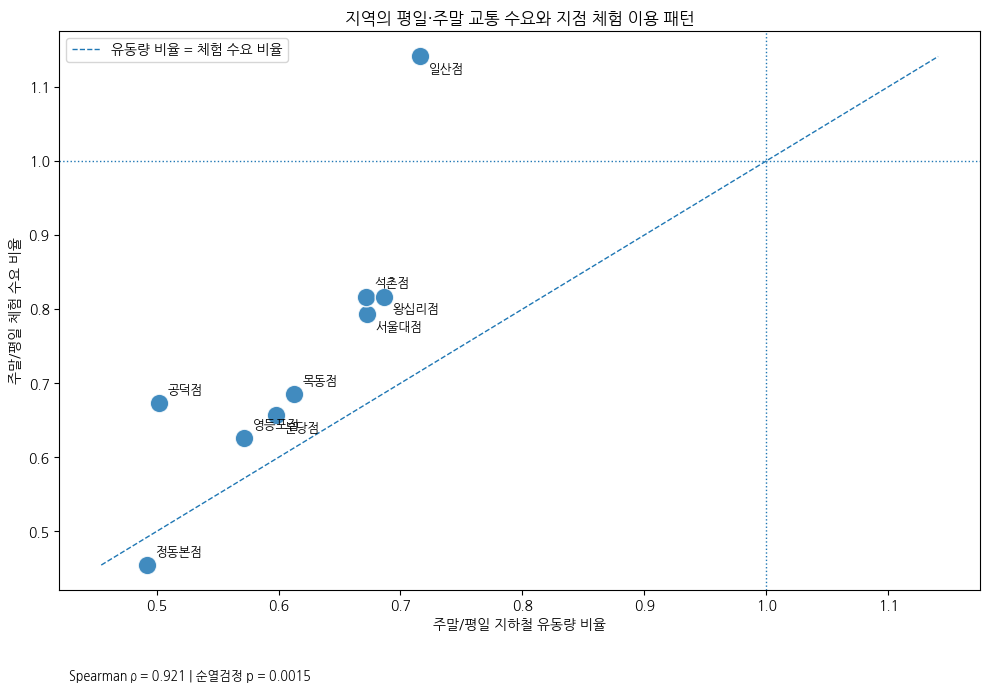

In [ ]:
# 시각화: 주말/평일 지하철 유동량 비율과 체험 수요 비율

day_type_alignment_plot = day_type_wide.dropna(
    subset=[
        "weekend_weekday_flow_ratio",
        "weekend_weekday_demand_ratio",
    ]
).copy()

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(
    data=day_type_alignment_plot,
    x="weekend_weekday_flow_ratio",
    y="weekend_weekday_demand_ratio",
    s=180,
    alpha=0.85,
    ax=ax,
)

for index, row in enumerate(day_type_alignment_plot.itertuples()):
    ax.annotate(
        row.site_name,
        (
            row.weekend_weekday_flow_ratio,
            row.weekend_weekday_demand_ratio,
        ),
        xytext=(6, 7 if index % 2 == 0 else -12),
        textcoords="offset points",
        fontsize=9,
    )

axis_min = min(
    day_type_alignment_plot["weekend_weekday_flow_ratio"].min(),
    day_type_alignment_plot["weekend_weekday_demand_ratio"].min(),
)
axis_max = max(
    day_type_alignment_plot["weekend_weekday_flow_ratio"].max(),
    day_type_alignment_plot["weekend_weekday_demand_ratio"].max(),
)
ax.plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    linestyle="--",
    linewidth=1,
    label="유동량 비율 = 체험 수요 비율",
)

ax.axvline(1, linestyle=":", linewidth=1)
ax.axhline(1, linestyle=":", linewidth=1)
ax.set_title("지역의 평일·주말 교통 수요와 지점 체험 이용 패턴")
ax.set_xlabel("주말/평일 지하철 유동량 비율")
ax.set_ylabel("주말/평일 체험 수요 비율")
ax.legend()
ax.text(
    0.01,
    -0.16,
    "Spearman ρ = 0.921 | 순열검정 p = 0.0015",
    transform=ax.transAxes,
    fontsize=9,
)
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 주말/평일 지하철 유동량 비율과 주말/평일 체험 수요 비율은 매우 강한 양의 관계를 보였다(ρ=0.921, 순열 p=0.0015).
> - 절대 유동량보다 상권이 움직이는 시간대와 실제 체험 수요의 시간대가 맞는지가 더 중요하다는 결과다.


In [ ]:
# 일산점 제외 후 Spearman 상관계수 민감도 분석

day_type_alignment_without_ilsan = day_type_alignment_plot.loc[
    ~day_type_alignment_plot["site_name"]
    .astype(str)
    .str.contains("일산", na=False)
].copy()

ratio_rho_without_ilsan, ratio_permutation_p_without_ilsan = (
    permutation_spearman_test(
        day_type_alignment_without_ilsan["weekend_weekday_flow_ratio"],
        day_type_alignment_without_ilsan["weekend_weekday_demand_ratio"],
        seed=RANDOM_SEED + 851,
    )
)

ilsan_sensitivity_result = pd.DataFrame([
    {
        "분석 범위": "전체 지점",
        "지점 수": len(day_type_alignment_plot),
        "Spearman 상관계수": ratio_rho,
        "순열검정 p-value": ratio_permutation_p,
    },
    {
        "분석 범위": "일산점 제외",
        "지점 수": len(day_type_alignment_without_ilsan),
        "Spearman 상관계수": ratio_rho_without_ilsan,
        "순열검정 p-value": ratio_permutation_p_without_ilsan,
    },
])

ilsan_sensitivity_result["전체 대비 상관계수 변화"] = (
    ilsan_sensitivity_result["Spearman 상관계수"] - ratio_rho
)

display(ilsan_sensitivity_result.round(4))

,분석 범위,지점 수,Spearman 상관계수,순열검정 p-value,전체 대비 상관계수 변화
0,전체 지점,9,0.9205,0.0015,0.0000
1,일산점 제외,8,0.8862,0.0066,-0.0343


> **💡 결과 해석**
>
> - 일산점이 전체 상관계수를 과도하게 높였는지 확인하기 위해 제외 후 다시 계산했다.  
> - 그러나 제외 후에도 Spearman ρ=0.8862로 매우 강한 양의 상관관계가 유지되었다.

#### 6-3-2-5. 접근성 기반 지점 역할 진단 및 통합표 생성

**🔹 분석 목적**

- 지하철 유동량과 절대·면적당 체험 수요를 함께 시각화한다.
- 접근성은 높지만 수요 포착이 낮은 지점과, 접근성은 낮아도 수요가 높은 지점을 구분한다.
- 이후 인프라·리뷰 통합 분석에 사용할 접근성 기반 지점 역할 테이블을 생성한다.


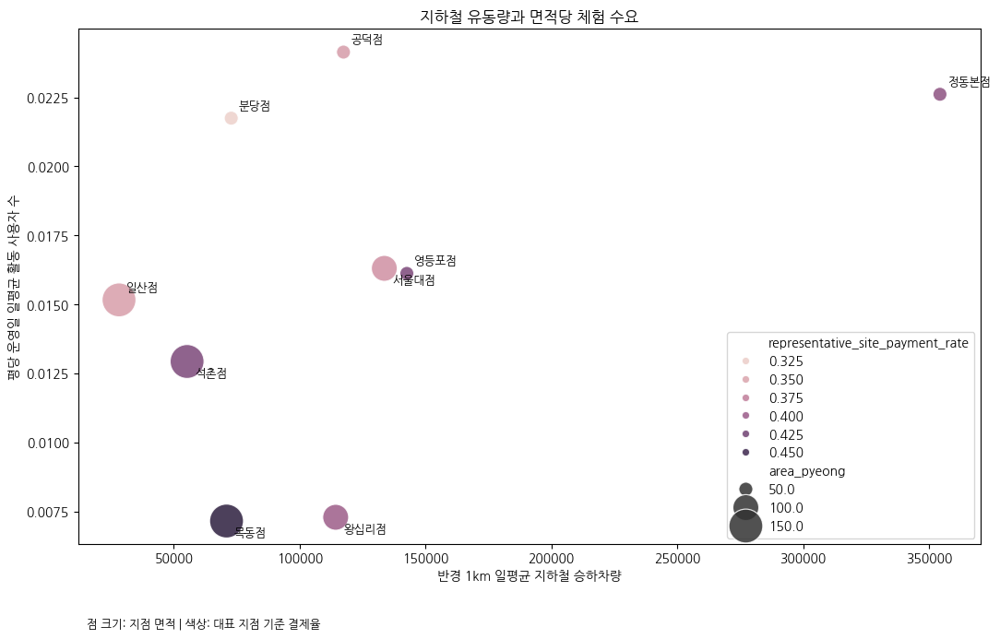

In [ ]:
# 지하철 유동량과 면적당 체험 수요 시각화

plot_flow_density = site_performance_flow_summary.copy()

plot_numeric_columns = [
    "avg_daily_subway_flow_1km",
    "avg_daily_activity_users_per_pyeong",
    "area_pyeong",
    "representative_site_payment_rate",
]

plot_flow_density[plot_numeric_columns] = (
    plot_flow_density[plot_numeric_columns]
    .apply(pd.to_numeric, errors="coerce")
    .astype(float)
)

plot_flow_density = plot_flow_density.dropna(
    subset=plot_numeric_columns + ["site_name"]
)

fig, ax = plt.subplots(figsize=(11, 7))

sns.scatterplot(
    data=plot_flow_density,
    x="avg_daily_subway_flow_1km",
    y="avg_daily_activity_users_per_pyeong",
    size="area_pyeong",
    hue="representative_site_payment_rate",
    sizes=(120, 700),
    alpha=0.85,
    ax=ax,
)

for index, row in enumerate(plot_flow_density.itertuples()):
    ax.annotate(
        row.site_name,
        (
            row.avg_daily_subway_flow_1km,
            row.avg_daily_activity_users_per_pyeong,
        ),
        xytext=(6, 7 if index % 2 == 0 else -12),
        textcoords="offset points",
        fontsize=9,
    )

ax.set_title("지하철 유동량과 면적당 체험 수요")
ax.set_xlabel("반경 1km 일평균 지하철 승하차량")
ax.set_ylabel("평당 운영일 일평균 활동 사용자 수")

ax.text(
    0.01,
    -0.16,
    "점 크기: 지점 면적 | 색상: 대표 지점 기준 결제율",
    transform=ax.transAxes,
    fontsize=9,
)

plt.tight_layout()
plt.show()


> **📊 시각화 해석**
>
> - 유동량이 높은 지점이 반드시 면적당 수요도 높은 것은 아니며, 공덕점처럼 중간 유동량에서도 높은 공간 효율을 보이는 지점이 존재한다.


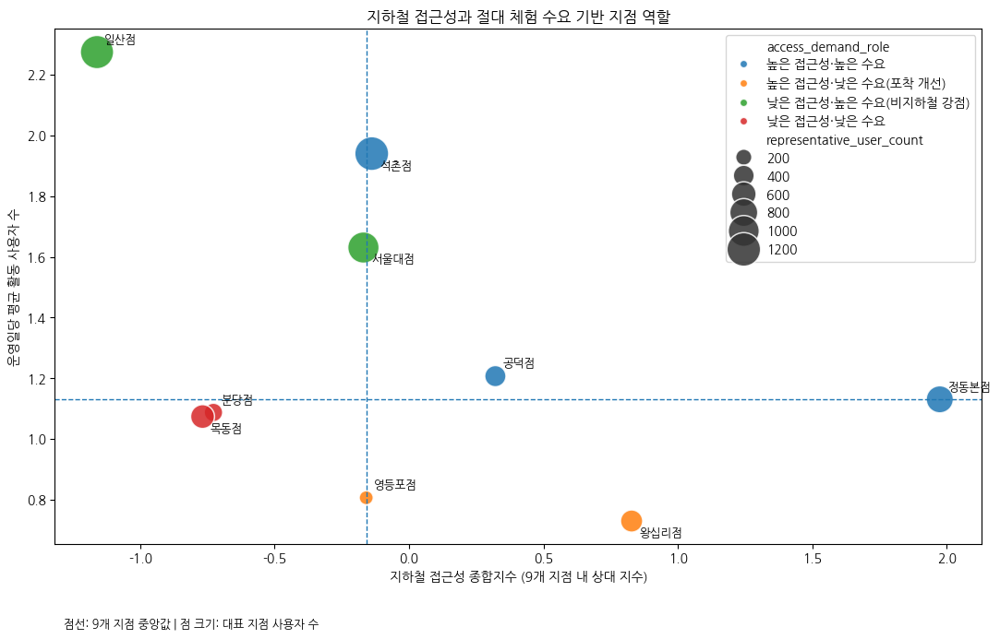

In [ ]:
# 시각화: 지하철 접근성과 절대 체험 수요 기반 역할

plot_access_demand = site_performance_flow_summary.copy()

fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(
    data=plot_access_demand,
    x="accessibility_composite_index",
    y="avg_daily_activity_users",
    size="representative_user_count",
    hue="access_demand_role",
    sizes=(120, 700),
    alpha=0.85,
    ax=ax,
)

ax.axvline(accessibility_median, linestyle="--", linewidth=1)
ax.axhline(scale_median_for_access, linestyle="--", linewidth=1)

for index, row in enumerate(plot_access_demand.itertuples()):
    ax.annotate(
        row.site_name,
        (row.accessibility_composite_index, row.avg_daily_activity_users),
        xytext=(6, 7 if index % 2 == 0 else -12),
        textcoords="offset points",
        fontsize=9,
    )

ax.set_title("지하철 접근성과 절대 체험 수요 기반 지점 역할")
ax.set_xlabel("지하철 접근성 종합지수 (9개 지점 내 상대 지수)")
ax.set_ylabel("운영일당 평균 활동 사용자 수")
ax.text(
    0.01,
    -0.16,
    "점선: 9개 지점 중앙값 | 점 크기: 대표 지점 사용자 수",
    transform=ax.transAxes,
    fontsize=9,
)
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 왕십리점·영등포점은 접근성 대비 수요 포착이 낮고, 일산점·서울대점은 상대적으로 낮은 접근성에도 수요가 높아 비지하철 수요 강점을 보였다.


In [ ]:
# 최종 통합 진단표 생성

site_performance_flow_summary_final = (
    site_performance_flow_summary
    .merge(
        period_comparison_summary[
            [
                "site_id",
                "common_avg_daily_subway_flow_1km",
                "common_avg_daily_activity_users",
                "common_avg_daily_activity_users_per_pyeong",
                "common_flow_rank",
                "common_demand_scale_rank",
                "common_demand_density_rank",
                "flow_rank_change_common_minus_full",
                "demand_scale_rank_change_common_minus_full",
                "demand_density_rank_change_common_minus_full",
            ]
        ],
        on="site_id",
        how="left",
        validate="1:1",
    )
    .merge(
        site_repeat_payment_summary[
            [
                "site_id",
                "single_day_user_count",
                "single_day_payment_rate",
                "repeat_user_count",
                "repeat_payment_rate",
                "repeat_payment_lift_pp",
                "repeat_vs_single_odds_ratio",
            ]
        ],
        on="site_id",
        how="left",
        validate="1:1",
    )
    .merge(
        day_type_wide[
            [
                "site_id",
                "weekend_weekday_flow_ratio",
                "weekend_weekday_demand_ratio",
                "weekend_weekday_density_ratio",
            ]
        ],
        on="site_id",
        how="left",
        validate="1:1",
    )
)

# 기존 분석명과의 호환을 위해 동일 내용을 v4 별칭으로도 유지
site_performance_flow_summary_v4 = (
    site_performance_flow_summary_final.copy()
)

site_role_diagnostic_summary = (
    site_performance_flow_summary_final[
        [
            "site_id",
            "site_name",
            "site_role",
            "site_density_role",
            "access_demand_role",
            "area_pyeong",
            "avg_daily_activity_users",
            "demand_scale_rank",
            "avg_daily_activity_users_per_pyeong",
            "demand_density_rank",
            "accessibility_composite_index",
            "accessibility_rank",
            "avg_daily_subway_flow_1km",
            "nearest_station_name",
            "nearest_station_distance_m",
            "representative_user_count",
            "representative_site_payment_rate",
            "payment_rate_wilson_low",
            "payment_rate_wilson_high",
            "conversion_rank",
            "repeat_visitor_rate",
            "single_day_payment_rate",
            "repeat_payment_rate",
            "repeat_payment_lift_pp",
            "avg_total_stay_hours_per_complete_visitor",
            "weekend_weekday_flow_ratio",
            "weekend_weekday_demand_ratio",
            "common_flow_rank",
            "common_demand_scale_rank",
            "common_demand_density_rank",
        ]
    ]
    .sort_values(["site_role", "demand_scale_rank"])
    .reset_index(drop=True)
)

display(site_role_diagnostic_summary)

,site_id,site_name,site_role,site_density_role,access_demand_role,area_pyeong,avg_daily_activity_users,demand_scale_rank,avg_daily_activity_users_per_pyeong,demand_density_rank,...,repeat_visitor_rate,single_day_payment_rate,repeat_payment_rate,repeat_payment_lift_pp,avg_total_stay_hours_per_complete_visitor,weekend_weekday_flow_ratio,weekend_weekday_demand_ratio,common_flow_rank,common_demand_scale_rank,common_demand_density_rank
0,3,석촌점,고수요규모·고전환,저수요밀도·고전환,높은 접근성·높은 수요,150,1.940513,2,0.012937,7,...,0.424744,0.370425,0.476723,10.629794,7.248064,0.671427,0.816993,8,2,7
1,1,정동본점,고수요규모·고전환,고수요밀도·고전환,높은 접근성·높은 수요,50,1.130658,5,0.022613,2,...,0.309963,0.370968,0.48,10.903226,5.841672,0.492037,0.454617,1,5,2
2,6,일산점,고수요규모·저전환,저수요밀도·저전환,낮은 접근성·높은 수요(비지하철 강점),150,2.275064,1,0.015167,6,...,0.400657,0.334302,0.38193,4.762786,6.971256,0.716308,1.140974,9,1,5
3,2,서울대점,고수요규모·저전환,고수요밀도·저전환,낮은 접근성·높은 수요(비지하철 강점),100,1.630928,3,0.016309,4,...,0.420057,0.331058,0.402715,7.165691,7.962042,0.672542,0.792964,3,3,6
4,17,공덕점,고수요규모·저전환,고수요밀도·저전환,높은 접근성·높은 수요,50,1.207031,4,0.024141,1,...,0.367347,0.328125,0.397516,6.939053,5.582853,0.502231,0.673157,5,4,1
5,5,목동점,저수요규모·고전환,저수요밀도·고전환,낮은 접근성·낮은 수요,150,1.073834,7,0.007159,9,...,0.433628,0.432258,0.493878,6.161949,6.735084,0.612751,0.68522,6,7,8
6,49,영등포점,저수요규모·고전환,고수요밀도·고전환,높은 접근성·낮은 수요(포착 개선),50,0.806324,8,0.016126,5,...,0.426471,0.362319,0.482759,12.043978,6.311430,0.571843,0.625782,2,8,4
7,4,왕십리점,저수요규모·고전환,저수요밀도·고전환,높은 접근성·낮은 수요(포착 개선),100,0.729534,9,0.007295,8,...,0.405462,0.346715,0.473958,12.7243,6.655039,0.686683,0.816993,4,9,9
8,47,분당점,저수요규모·저전환,고수요밀도·저전환,낮은 접근성·낮은 수요,50,1.087404,6,0.021748,3,...,0.377551,0.298343,0.36036,6.201782,5.821234,0.598335,0.656964,7,6,3


> **💡 종합 결과**
>
> - 접근성은 지점의 잠재 노출을 설명하지만 실제 체험 수요와 결제 성과를 자동으로 보장하지 않았다.
> - 따라서 접근성 기반 전략은 높은 유동량 자체보다 수요 포착 여부와 평일·주말 패턴을 함께 진단해야 한다.


### 6-3-3. 주변 인프라 기반 상권 유형 분석

**🔎 분석 목적**

- 지점 반경 내 지하철역, 주차장, 편의점, 카페, 스터디카페, 기업 수를 활용해 지점별 입지 특성을 비교한다.
- 단위와 분포가 다른 변수를 Min-Max Scaling으로 변환하고 교통 접근성·생활 편의·잠재 수요 지수를 생성한다.
- 레이더 차트, PCA, 계층적 군집화를 통해 지점의 상대적 강점과 유사한 상권 유형을 파악한다.
- 인프라를 성과의 직접 원인으로 단정하지 않고, 지점의 잠재 고객과 이용 목적을 설명하는 배경 변수로 활용한다.


#### 6-3-3-1. 인프라 데이터 연결 및 3대 지수 생성

**🔹 분석 목적**

- 6개 인프라 원본 변수를 지점명 기준으로 연결한다.
- Min-Max Scaling 결과를 활용해 접근성·생활편의·잠재수요 지수를 0~100점으로 산출한다.
- 지점별로 어떤 입지 요소가 상대적 강점 또는 약점인지 비교한다.


In [ ]:
# 인프라 데이터를 연결해 표준화 및 지수 생성

required_infra_columns = [
    "지하철역",
    "주차장",
    "편의점",
    "카페",
    "스터디카페",
    "기업",
]

expected_infra_branches = [
    "집무실 공덕점",
    "집무실 목동점",
    "집무실 분당점",
    "집무실 서울대점",
    "집무실 석촌점",
    "집무실 영등포점",
    "집무실 왕십리점",
    "집무실 일산점",
    "집무실 정동본점",
]

if "infra_summary_table" not in globals():
    raise NameError(
        "4-7-2 인프라 데이터 구축 셀을 먼저 실행해 주세요. "
        "필요 변수: infra_summary_table"
    )

summary_table = infra_summary_table.copy()
summary_table.index = summary_table.index.astype(str).str.strip()

missing_branches = [
    branch
    for branch in expected_infra_branches
    if branch not in summary_table.index
]

if missing_branches:
    raise ValueError(
        "4-7 인프라 요약 데이터에서 다음 지점을 찾을 수 없습니다: "
        f"{missing_branches}"
    )

summary_table = (
    summary_table
    .reindex(
        index=expected_infra_branches,
        columns=required_infra_columns,
        fill_value=0,
    )
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)

scaler = MinMaxScaler()
scaled_values = scaler.fit_transform(summary_table)

summary_scaled = pd.DataFrame(
    scaled_values,
    columns=summary_table.columns,
    index=summary_table.index,
)

summary_score = summary_scaled * 100

summary_score["접근성_지수"] = (
    summary_score["지하철역"]
    + summary_score["주차장"]
) / 2

summary_score["생활편의_지수"] = (
    summary_score["편의점"]
    + summary_score["카페"]
) / 2

summary_score["잠재수요_지수"] = (
    summary_score["기업"]
    + summary_score["스터디카페"]
) / 2

final_scores = summary_score[
    ["접근성_지수", "생활편의_지수", "잠재수요_지수"]
].round(1)

print("=== [4-7 연결 원본 데이터] ===")
display(summary_table)

print("\n=== [표준화된 데이터 (0~1)] ===")
display(summary_scaled.round(3))

print("\n=== [지점별 인프라 3대 지수 (100점 만점)] ===")
display(final_scores)

=== [4-7 연결 원본 데이터] ===


카테고리,지하철역,주차장,편의점,카페,스터디카페,기업
기준지점,,,,,,
집무실 공덕점,3,19,12,41,26,33
집무실 목동점,2,5,6,28,38,13
집무실 분당점,2,17,7,19,16,9
집무실 서울대점,2,8,13,45,37,13
집무실 석촌점,3,6,10,39,21,6
집무실 영등포점,3,20,15,30,18,41
집무실 왕십리점,4,14,17,45,22,11
집무실 일산점,2,22,8,20,10,20
집무실 정동본점,6,25,9,45,13,45



=== [표준화된 데이터 (0~1)] ===


카테고리,지하철역,주차장,편의점,카페,스터디카페,기업
기준지점,,,,,,
집무실 공덕점,0.25,0.70,0.545,0.846,0.571,0.692
집무실 목동점,0.00,0.00,0.000,0.346,1.000,0.179
집무실 분당점,0.00,0.60,0.091,0.000,0.214,0.077
집무실 서울대점,0.00,0.15,0.636,1.000,0.964,0.179
집무실 석촌점,0.25,0.05,0.364,0.769,0.393,0.000
집무실 영등포점,0.25,0.75,0.818,0.423,0.286,0.897
집무실 왕십리점,0.50,0.45,1.000,1.000,0.429,0.128
집무실 일산점,0.00,0.85,0.182,0.038,0.000,0.359
집무실 정동본점,1.00,1.00,0.273,1.000,0.107,1.000



=== [지점별 인프라 3대 지수 (100점 만점)] ===


카테고리,접근성_지수,생활편의_지수,잠재수요_지수
기준지점,,,
집무실 공덕점,47.5,69.6,63.2
집무실 목동점,0.0,17.3,59.0
집무실 분당점,30.0,4.5,14.6
집무실 서울대점,7.5,81.8,57.2
집무실 석촌점,15.0,56.6,19.6
집무실 영등포점,50.0,62.1,59.2
집무실 왕십리점,47.5,100.0,27.8
집무실 일산점,42.5,11.0,17.9
집무실 정동본점,100.0,63.6,55.4


> **💡 결과 해석**
>
> - 정동본점은 접근성 지수 100점, 왕십리점은 생활편의 지수 100점, 공덕점은 잠재수요 지수 63.2점으로 각각 강점이 달랐다.
> - 인프라 지수는 지점 우열보다 상권의 잠재 고객과 이용 목적을 구분하는 변수로 활용한다.


#### 6-3-3-2. 인프라 변수 관계와 지점별 특성 시각화

**🔹 분석 목적**

- 인프라 변수 간 상관관계를 확인해 함께 움직이는 시설 유형을 파악한다.
- 레이더 차트로 지점별 강점과 약점을 비교하고, PCA로 6개 변수를 두 개의 축으로 요약한다.
- 주성분의 설명력과 적재 방향을 이용해 지점 간 입지 차이를 해석한다.


In [ ]:
# 인프라 변수 간 상관계수 계산

corr_columns = summary_scaled.columns.tolist()
corr = summary_table[corr_columns].corr()

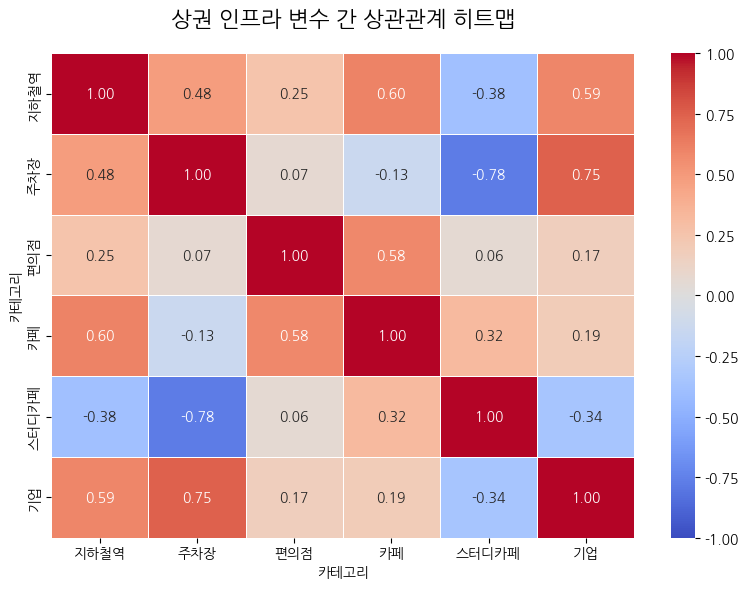

In [ ]:
# 인프라 변수 간 상관관계 히트맵 시각화

plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title('상권 인프라 변수 간 상관관계 히트맵', fontsize=16, pad=20)
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 인프라 변수 간 상관구조를 통해 교통·업무시설과 생활·학습시설이 서로 다른 조합으로 형성되는 지점을 확인했다.


In [ ]:
# 지점별 레이더 차트 데이터 준비

radar_data = summary_scaled * 100
labels = radar_data.columns.tolist()
num_vars = len(labels)

angles = np.linspace(
    0,
    2 * np.pi,
    num_vars,
    endpoint=False
).tolist()

angles += angles[:1]

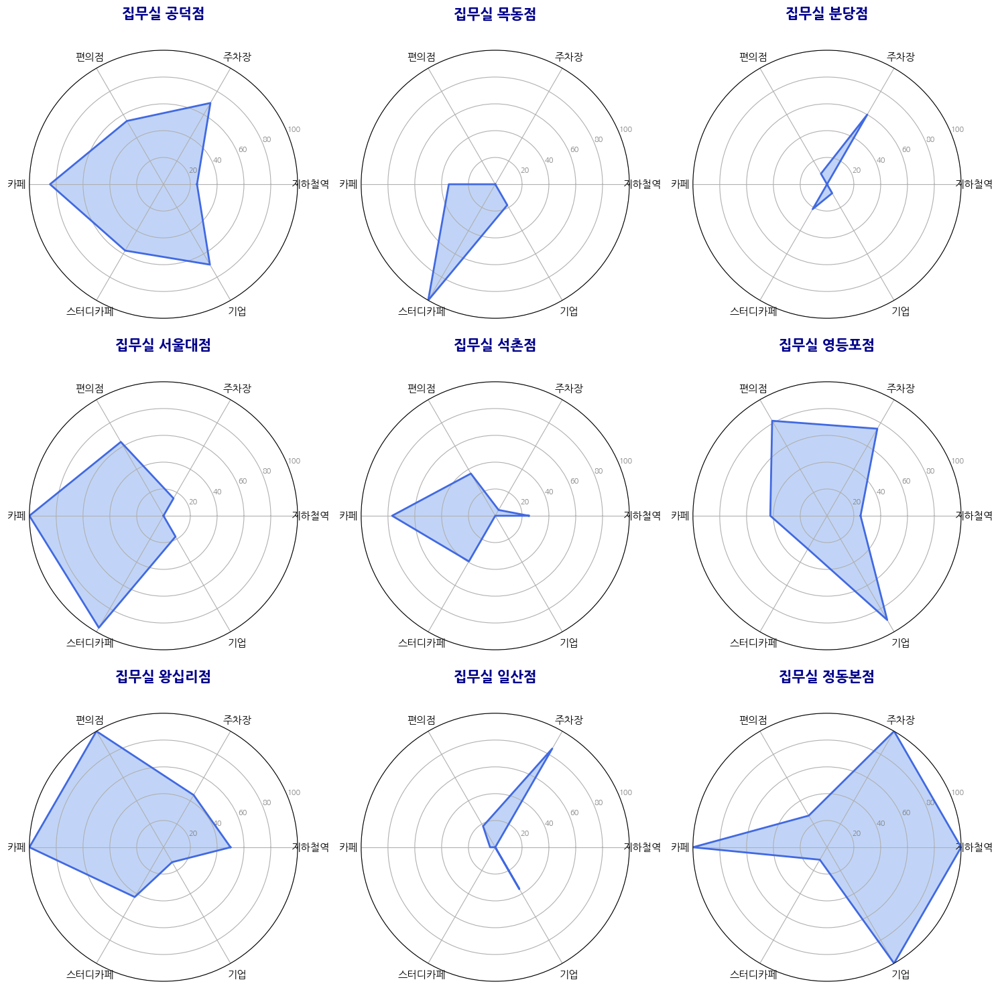

In [ ]:
# 지점별 인프라 강점과 약점 레이더 차트 시각화

fig, axes = plt.subplots(
    3,
    3,
    figsize=(15, 15),
    subplot_kw={'polar': True}
)

axes = axes.flatten()

for i, (branch_name, row) in enumerate(radar_data.iterrows()):
    values = row.tolist()
    values += values[:1]

    ax = axes[i]
    ax.plot(
        angles,
        values,
        color='royalblue',
        linewidth=2,
        linestyle='solid'
    )
    ax.fill(
        angles,
        values,
        color='cornflowerblue',
        alpha=0.4
    )
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=11)
    ax.set_ylim(0, 100)
    ax.set_yticks([20, 40, 60, 80, 100])
    ax.set_yticklabels(
        ['20', '40', '60', '80', '100'],
        color='grey',
        size=8
    )
    ax.set_title(
        branch_name,
        size=15,
        color='darkblue',
        weight='bold',
        y=1.1
    )

for j in range(len(radar_data), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 정동본점의 교통·업무 강점, 서울대점의 생활·학습 강점, 일산·분당의 주차 중심 특성처럼 지점별 입지 프로파일 차이를 보여준다.


In [ ]:
# 인프라 데이터를 두 개의 주성분으로 축소

pca = PCA(n_components=2)
pca_features = pca.fit_transform(summary_scaled)

pca_df = pd.DataFrame(
    pca_features,
    columns=['PC1', 'PC2'],
    index=summary_scaled.index
)

explained_variance = pca.explained_variance_ratio_
loadings = (
    pca.components_.T
    * np.sqrt(pca.explained_variance_)
)
features = summary_scaled.columns

In [ ]:
# PCA 주성분 설명력 출력

print(
    f"제1주성분(PC1) 설명력: "
    f"{explained_variance[0] * 100:.1f}%"
)
print(
    f"제2주성분(PC2) 설명력: "
    f"{explained_variance[1] * 100:.1f}%"
)
print(
    f"총 설명력: "
    f"{explained_variance.sum() * 100:.1f}%"
)

제1주성분(PC1) 설명력: 44.6%
제2주성분(PC2) 설명력: 34.2%
총 설명력: 78.8%


> **✅ 확인 결과**
>
> - PC1은 44.6%, PC2는 34.2%를 설명해 두 축만으로 전체 인프라 차이의 78.8%를 요약할 수 있었다.


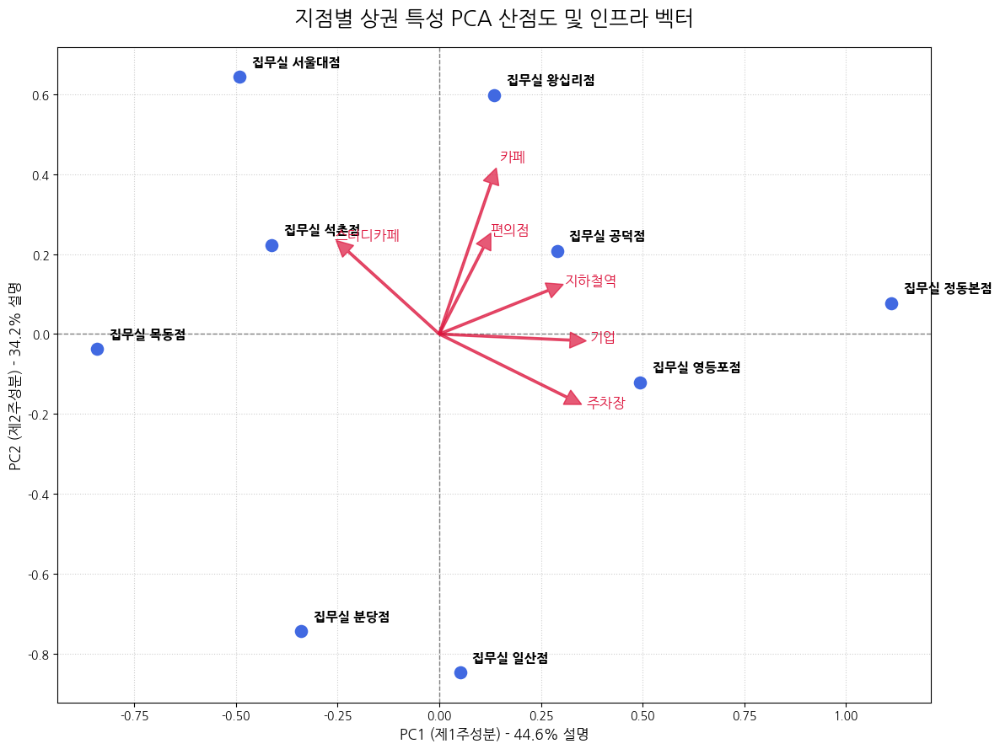

In [ ]:
# 지점별 PCA 산점도와 인프라 벡터 시각화

plt.figure(figsize=(12, 9))

sns.scatterplot(
    x='PC1',
    y='PC2',
    data=pca_df,
    s=150,
    color='royalblue',
    zorder=5
)

for branch_name, point in pca_df.iterrows():
    plt.text(
        point['PC1'] + 0.03,
        point['PC2'] + 0.03,
        branch_name,
        fontsize=11,
        weight='bold'
    )

for i, feature in enumerate(features):
    plt.arrow(
        0,
        0,
        loadings[i, 0],
        loadings[i, 1],
        color='crimson',
        alpha=0.7,
        width=0.005,
        head_width=0.04,
        head_length=0.04,
        zorder=4
    )
    plt.text(
        loadings[i, 0] * 1.15,
        loadings[i, 1] * 1.15,
        feature,
        color='crimson',
        fontsize=12
    )

plt.axhline(
    0,
    color='grey',
    linestyle='--',
    linewidth=1
)
plt.axvline(
    0,
    color='grey',
    linestyle='--',
    linewidth=1
)

plt.title(
    '지점별 상권 특성 PCA 산점도 및 인프라 벡터',
    fontsize=18,
    pad=20
)
plt.xlabel(
    f'PC1 (제1주성분) - '
    f'{explained_variance[0] * 100:.1f}% 설명',
    fontsize=12
)
plt.ylabel(
    f'PC2 (제2주성분) - '
    f'{explained_variance[1] * 100:.1f}% 설명',
    fontsize=12
)
plt.grid(
    True,
    linestyle=':',
    alpha=0.6
)
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - PCA 공간에서 도심 업무형 지점과 생활·학습형 지점, 주차·지역거점형 지점이 서로 다른 방향에 위치한다.
> - 벡터 방향은 각 지점의 위치를 설명하는 인프라 변수가 무엇인지 보여준다.


In [ ]:
# 지점별 PCA 좌표 확인

display(pca_df.round(3))

,PC1,PC2
기준지점,,
집무실 공덕점,0.290,0.208
집무실 목동점,-0.841,-0.037
집무실 분당점,-0.340,-0.744
집무실 서울대점,-0.491,0.644
집무실 석촌점,-0.412,0.223
집무실 영등포점,0.495,-0.121
집무실 왕십리점,0.135,0.598
집무실 일산점,0.051,-0.848
집무실 정동본점,1.112,0.078


> **💡 결과 해석**
>
> - 정동본점은 PC1 양의 방향으로 가장 멀리 위치해 도심 업무·교통 인프라가 두드러졌고, 서울대점·왕십리점은 PC2 양의 방향에서 생활·학습 특성이 강했다.


#### 6-3-3-3. 상권 유형 군집화 및 지도 시각화

**🔹 분석 목적**

- 표준화된 인프라 변수를 사용해 계층적 군집화를 수행한다.
- 덴드로그램과 군집별 평균 인프라를 바탕으로 상권 유형을 해석한다.
- 군집 결과를 지도에 표시해 유사한 상권 특성을 가진 지점의 공간적 분포를 확인한다.


In [ ]:
# 계층적 군집화를 위한 연결 행렬 생성

linked = linkage(
    summary_scaled,
    method='ward'
)

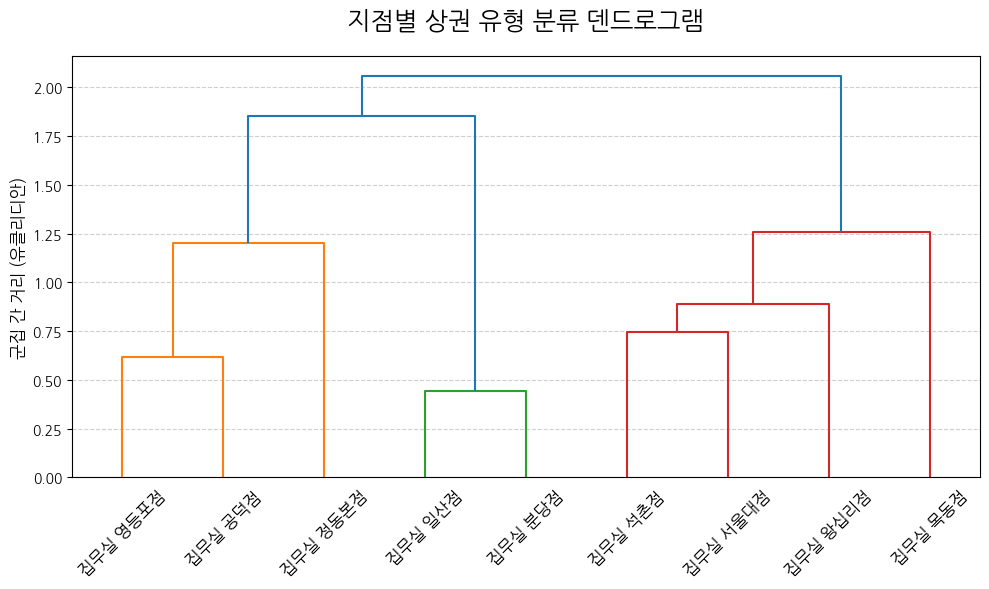

In [ ]:
# 지점별 상권 유형 덴드로그램 시각화

plt.figure(figsize=(10, 6))

dendrogram(
    linked,
    orientation='top',
    labels=summary_scaled.index,
    distance_sort='descending',
    show_leaf_counts=True,
    leaf_font_size=12
)

plt.title(
    '지점별 상권 유형 분류 덴드로그램',
    fontsize=18,
    pad=20
)
plt.ylabel(
    '군집 간 거리 (유클리디안)',
    fontsize=12
)
plt.xticks(rotation=45)
plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.6
)
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 덴드로그램의 결합 거리를 기준으로 9개 지점이 세 개의 상권 유형으로 묶이는 구조를 확인했다.


In [ ]:
# 지점별 상권 군집 할당

cluster_labels = fcluster(
    linked,
    t=3,
    criterion='maxclust'
)

summary_table = summary_table.copy()
summary_table['상권_군집'] = cluster_labels

In [ ]:
# 지점별 상권 군집 결과 출력

print('=== 지점별 할당된 상권 군집 ===')

display(
    summary_table[['상권_군집']]
    .sort_values('상권_군집')
)

=== 지점별 할당된 상권 군집 ===


카테고리,상권_군집
기준지점,
집무실 목동점,1
집무실 서울대점,1
집무실 왕십리점,1
집무실 석촌점,1
집무실 일산점,2
집무실 분당점,2
집무실 공덕점,3
집무실 영등포점,3
집무실 정동본점,3


> **💡 결과 해석**
>
> - 목동·서울대·왕십리·석촌은 학습·생활형, 일산·분당은 주차·지역거점형, 공덕·영등포·정동은 도심 업무형으로 구분되었다.


In [ ]:
# 군집별 인프라 평균 특성 계산

cluster_profile = (
    summary_table
    .groupby('상권_군집')
    .mean(numeric_only=True)
    .round(1)
)

In [ ]:
# 군집별 인프라 평균 특성 출력

print('=== 군집별 인프라 평균 수치 ===')

display(cluster_profile)

=== 군집별 인프라 평균 수치 ===


카테고리,지하철역,주차장,편의점,카페,스터디카페,기업
상권_군집,,,,,,
1,2.8,8.2,11.5,39.2,29.5,10.8
2,2.0,19.5,7.5,19.5,13.0,14.5
3,4.0,21.3,12.0,38.7,19.0,39.7


> **💡 결과 해석**
>
> - 학습·생활형은 카페와 스터디카페가 많고, 주차·지역거점형은 주차장이 많으며, 도심 업무형은 지하철역·주차장·기업 수가 높았다.


In [ ]:
# 지점 좌표와 상권 군집 결과 결합

if "infra_site_master" not in globals():
    raise NameError(
        "4-7-2 지점 좌표 변환 셀을 먼저 실행해 주세요. "
        "필요 변수: infra_site_master"
    )

if "상권_군집" not in summary_table.columns:
    raise ValueError(
        "6-3-3-3 상권 군집 할당 셀을 먼저 실행해 주세요."
    )

required_coordinate_columns = {
    "name",
    "lat",
    "lng",
}

missing_coordinate_columns = (
    required_coordinate_columns
    - set(infra_site_master.columns)
)

if missing_coordinate_columns:
    raise ValueError(
        "4-7 지점 좌표 데이터에 필요한 컬럼이 없습니다: "
        f"{sorted(missing_coordinate_columns)}"
    )

df_loc = (
    infra_site_master[
        ["name", "lat", "lng"]
    ]
    .rename(columns={"name": "기준지점"})
    .drop_duplicates(subset="기준지점")
    .set_index("기준지점")
)

missing_coordinate_branches = [
    branch
    for branch in summary_table.index
    if branch not in df_loc.index
]

if missing_coordinate_branches:
    raise ValueError(
        "4-7 지점 좌표 데이터에서 다음 지점을 찾을 수 없습니다: "
        f"{missing_coordinate_branches}"
    )

df_map = (
    df_loc
    .join(
        summary_table[["상권_군집"]],
        how="inner",
    )
    .dropna(
        subset=[
            "lat",
            "lng",
            "상권_군집",
        ]
    )
)

display(df_map)

,lat,lng,상권_군집
기준지점,,,
집무실 공덕점,37.545255,126.948751,3
집무실 정동본점,37.566723,126.976533,3
집무실 영등포점,37.526766,126.905231,3
집무실 왕십리점,37.563405,127.037768,1
집무실 일산점,37.655980,126.776149,2
집무실 서울대점,37.477937,126.952601,1
집무실 석촌점,37.503010,127.108713,1
집무실 목동점,37.520756,126.872859,1
집무실 분당점,37.381791,127.117264,2


> **✅ 확인 결과**
>
> - 9개 지점의 좌표와 상권 군집이 모두 연결되어 지도 시각화에 사용할 공간 데이터가 완성되었다.


In [ ]:
# 상권 군집별 지점 지도 시각화

center_lat = df_map['lat'].mean()
center_lng = df_map['lng'].mean()

m = folium.Map(
    location=[center_lat, center_lng],
    zoom_start=11,
    tiles='CartoDB positron'
)

color_dict = {
    1: 'red',
    2: 'blue',
    3: 'green',
    4: 'purple'
}

for branch_name, row in df_map.iterrows():
    cluster_id = int(row['상권_군집'])
    marker_color = color_dict.get(
        cluster_id,
        'gray'
    )
    popup_text = folium.Popup(
        f'<b>{branch_name}</b>'
        f'<br>상권 군집: {cluster_id}',
        max_width=200
    )

    folium.Marker(
        location=[
            row['lat'],
            row['lng']
        ],
        popup=popup_text,
        tooltip=branch_name,
        icon=folium.Icon(
            color=marker_color,
            icon='info-sign'
        )
    ).add_to(m)

    folium.Circle(
        location=[
            row['lat'],
            row['lng']
        ],
        radius=1000,
        color=marker_color,
        fill=True,
        fill_color=marker_color,
        fill_opacity=0.1
    ).add_to(m)

display(m)

> **📊 시각화 해석**
>
> - 지도에서 상권 군집의 실제 위치를 확인해 도심 업무형과 수도권 지역거점형이 공간적으로도 구분되는지 점검할 수 있다.


### 6-3-4. 지도·블로그 리뷰 기반 고객 경험 분석

**🔎 분석 목적**

- 지도 리뷰는 실제 방문 후 발생한 만족과 운영 마찰을 보여주는 자료로 분석한다.
- 블로그 게시글은 공간 경험뿐 아니라 검색 노출·지점 탐색·무료 체험 정보가 섞인 방문 전 기대 자료로 해석한다.
- 감성분석, 경험 범주, TF-IDF, 워드클라우드, 토픽 모델링, 바이그램 연결망을 활용해 두 채널의 역할 차이를 확인한다.
- 리뷰 수가 적은 지점은 원본 비율을 그대로 비교하지 않고 스무딩과 근거 강도를 함께 사용한다.

**🧬 경험 범주**

- 접근성: 역·출구·거리·주차·동선
- 편의성: 가격·음료·화장실·이용 절차
- 공간: 좌석·소음·집중·쾌적함·인테리어
- 서비스: 친절·관리·응대


#### 6-3-4-1. 분석 환경 설정 및 리뷰 데이터 준비

**🔹 분석 목적**

- 지도 리뷰와 블로그 게시글의 컬럼 및 표본 구조를 확인한다.
- 블로그 검색 결과에서 브랜드만 언급되거나 지점 후기와 관련성이 낮은 게시글을 제거한다.
- 최종 분석 표본을 확정하고 이후 채널별 분석 기준을 일관되게 적용한다.


In [ ]:
# 전체 노트북 재실행 시 API 키를 반복 입력하지 않도록 저장된 CSV 불러오기(4-8에서 API로 수집한 리뷰 데이터와 동일)

df_all_reviews = pd.read_csv("df_all_reviews.csv")
df_blog_reviews_clean = pd.read_csv("df_blog_reviews_clean.csv")

In [ ]:
# 지도 리뷰 데이터 샘플 확인

df_all_reviews.head()

,site_id,site_name,review_rating,review_text,review_time,author,source
0,3,집무실 공덕점,5.0,향이 좋고 일하기에 최적화된 장소입니다.,3년 전,박재형,google
1,3,집무실 공덕점,5.0,3/13(월) 창가쪽 자리 좋아요,3년 전,Andrew Oh,google
2,3,집무실 공덕점,5.0,재택능률없을땐 최고의 장소입니다!,3년 전,김종문,google
3,6,집무실 서울대점,5.0,향이 좋고 일하기에 최적화된 장소입니다.,3년 전,박재형,google
4,6,집무실 서울대점,5.0,3/13(월) 창가쪽 자리 좋아요,3년 전,Andrew Oh,google


> **✅ 확인 결과**
>
> - 지도 리뷰는 별점·본문·작성자·출처가 포함되어 있어 방문 후 경험과 감성 분석에 활용 가능한 구조임을 확인했다.


In [ ]:
# 블로그 리뷰 데이터 샘플 확인

df_blog_reviews_clean.head()

,site_id,site_name,query,total_search_count,title,description,link,blogger_name,post_date,validity_final
0,1,집무실 영등포점,집무실 영등포점 후기,78,공유오피스 '집무실‘ 영등포점 -3일체험,"공유오피스 중에 가장 가성비 좋아보여서 관심갖고있던 집무실. 한 달동안 1시간씩 33,000원, 그리고... 마땅한 곳이 없어서 전처럼 카페에서나 가끔 일을 해야겠다.... 매우 아쉬운 집무실 영등포점 후기 끝 !",https://blog.naver.com/chloe_jo0/223206804280,_,2023-09-09,유효_본문정확일치
1,1,집무실 영등포점,집무실 영등포점 후기,78,"[이용 후기] 집 근처 사무실, 집무실 영등포점","싶은 마음에 방문하였고, 후기를 적어본다. 2. 집무실 지점_영등포점 현재 집무실은 수도권에 9개의 지점이 운영되고 있다. 그중에서 영등포점 위주로 적어보려고 한다. 요즘 민간임대 혹은 공공임대 형태의...",https://blog.naver.com/blueblue801/223188860504,나의 블로그,2023-08-20,유효_본문정확일치
2,1,집무실 영등포점,집무실 영등포점 후기,78,[집무실 영등포점]스터디카페 NO! 사무공간 이용 후기(위치...,집무실 영등포점 이용후기 넓게 넓게 쓰는 편을 좋아하는 데 책상과 자리가 넓은 점이 가장 마음에 들었다. 노트북 꺼내고 다이어리와 노트 펼치고 커피 한 잔 두어도 충분했다. 모던하고 깔끔한 인테리어와...,https://blog.naver.com/noliday_/223262021131,찬란하게,2023-11-11,유효_본문정확일치
3,1,집무실 영등포점,집무실 영등포점 후기,78,영등포::공유오피스 추천:: 집무실 후기 집근처 사무실 재택근무...,후기 - 좋습니다. 관리 잘되어있고 좌석도 다양해요 - 지점이 다양하게 존재합니다 - 가장 맘에... (~6/7)✨ 집무실 영등포점 찾아가는 방법 리마크빌을 찍고 오면 무지개처럼 생긴 구조물이 있습니다 그...,https://blog.naver.com/jioi_/223120100433,지오이의 잘먹고 잘살기,2023-06-05,유효_본문정확일치
4,1,집무실 영등포점,집무실 영등포점 후기,78,"[집무실 서울대점] 재택근무... 이용 후기, 무료 이용 꿀팁...","궁금했던 분들 어서 오세요 (광고 X 찐 사용 후기) 집무실은 내가 그동안 이용해봤던 위워크, 패스트파이브와 같이 공유오피스 프랜차이즈이며 서울대점, 공덕점, 분당점, 석촌점, 영등포점, 왕십리점, 일산점...",https://blog.naver.com/sangbbang_/223265333951,Yamujinlog. 상빵,2023-11-15,유효_본문정확일치


> **✅ 확인 결과**
>
> - 블로그 데이터는 제목·요약·본문·검색어·게시일을 포함하며, 지점 후기 외의 검색 결과가 섞여 있어 관련성 필터링이 필요함을 확인했다.


In [ ]:
# 본문이 정확히 일치한 블로그 게시글 확인

brand_only_posts = df_blog_reviews_clean[df_blog_reviews_clean["validity_final"] == "유효_본문정확일치"]

print(f"브랜드만 일치 게시글 수: {len(brand_only_posts)}")
display(brand_only_posts[["site_name", "title", "description"]])

브랜드만 일치 게시글 수: 395


,site_name,title,description
0,집무실 영등포점,공유오피스 '집무실‘ 영등포점 -3일체험,"공유오피스 중에 가장 가성비 좋아보여서 관심갖고있던 집무실. 한 달동안 1시간씩 33,000원, 그리고... 마땅한 곳이 없어서 전처럼 카페에서나 가끔 일을 해야겠다.... 매우 아쉬운 집무실 영등포점 후기 끝 !"
1,집무실 영등포점,"[이용 후기] 집 근처 사무실, 집무실 영등포점","싶은 마음에 방문하였고, 후기를 적어본다. 2. 집무실 지점_영등포점 현재 집무실은 수도권에 9개의 지점이 운영되고 있다. 그중에서 영등포점 위주로 적어보려고 한다. 요즘 민간임대 혹은 공공임대 형태의..."
2,집무실 영등포점,[집무실 영등포점]스터디카페 NO! 사무공간 이용 후기(위치...,집무실 영등포점 이용후기 넓게 넓게 쓰는 편을 좋아하는 데 책상과 자리가 넓은 점이 가장 마음에 들었다. 노트북 꺼내고 다이어리와 노트 펼치고 커피 한 잔 두어도 충분했다. 모던하고 깔끔한 인테리어와...
3,집무실 영등포점,영등포::공유오피스 추천:: 집무실 후기 집근처 사무실 재택근무...,후기 - 좋습니다. 관리 잘되어있고 좌석도 다양해요 - 지점이 다양하게 존재합니다 - 가장 맘에... (~6/7)✨ 집무실 영등포점 찾아가는 방법 리마크빌을 찍고 오면 무지개처럼 생긴 구조물이 있습니다 그...
4,집무실 영등포점,"[집무실 서울대점] 재택근무... 이용 후기, 무료 이용 꿀팁...","궁금했던 분들 어서 오세요 (광고 X 찐 사용 후기) 집무실은 내가 그동안 이용해봤던 위워크, 패스트파이브와 같이 공유오피스 프랜차이즈이며 서울대점, 공덕점, 분당점, 석촌점, 영등포점, 왕십리점, 일산점..."
...,...,...,...
406,집무실 분당점,"[취준 꿀팁] 24시 집무실 무료... 소개 (집무실 무료 제공, 현직자...",정말 제가 직접 활용해보고 200% 만족해서 작성하는 찐 후기입니다 ! 그럼 Let's GO 1. 취준 컴퍼니가... 집무실 지점 - 공덕점 - 목동점 - 분당점 - 서울대점 - 석촌점 - 영등포점 - 왕십리점 - 일산점 - 정동본점...
407,집무실 분당점,"공유 오피스 '집무실'에 출근하다: 집 근처 사무실, '집무실'",다행히 집무실 모든 지점은 목동점과 분당점을 제외하고는 지하철역에서 도보 5분 이내 거리에... 각 지점의 자세한 분위기와 장단점에 대해 알고 싶다면 지점 별 후기를 참조해 주세요. '취준 컴퍼니...
408,집무실 분당점,[취준컴퍼니] 로켓펀치 취준컴퍼니 12기 1주차 후기!,"현재 집무실 총 8개의 지점이 있는데요, 다음과 같습니다. 공덕점 분당점 서울대점 석촌점 영등포점 왕십리점 일산점 정동본점(서울 시청역) 제주점 저는 영등포점이 가깝네요, 지점들이 대체로 서울에 많이..."
409,집무실 분당점,12월 3주차 스타트업 소식,"힐링페이퍼_성형&amp;시술후기 정보 플랫폼 '강남언니' 운영사 Series B 투자유치 ⇒ Link ◾ 12/8... 알리콘, ‘집무실’ 8호점 분당점 오픈 위픽코퍼레이션, 고객 관리 플랫폼 ‘위픽CRM’ 런칭 한국축산데이터..."


> **💡 결과 해석**
>
> - 브랜드명만 일치하는 게시글이 395건으로 확인되어, 단순 검색 결과를 모두 리뷰로 사용하면 지점 경험 분석이 오염될 수 있었다.


In [ ]:
# 제목 키워드를 기준으로 관련 블로그 게시글 필터링

site_names_all = df_blog_reviews_clean["site_name"].unique()
site_only_names = set()
for name in site_names_all:
    site_only_names.update(name.replace("집무실", "").split())  # "공덕점", "목동점" 등

brand_related_terms = ["집무실", "공유오피스", "공유 오피스"] + list(site_only_names)

pattern = "|".join(brand_related_terms)

has_brand_in_title = df_blog_reviews_clean["title"].str.contains(pattern, na=False)

print(f"제목에 관련 단어 없는 게시글 수: {(~has_brand_in_title).sum()}")
display(df_blog_reviews_clean[~has_brand_in_title][["site_name", "title", "description", "validity_final"]])

# 제외 적용
df_blog_reviews_clean_filtered = df_blog_reviews_clean[has_brand_in_title].reset_index(drop=True)
print(f"필터링 후 남은 게시글 수: {len(df_blog_reviews_clean_filtered)}")

제목에 관련 단어 없는 게시글 수: 51


,site_name,title,description,validity_final
10,집무실 영등포점,[취준컴퍼니] 로켓펀치 취준컴퍼니 12기 1주차 후기!,"집무실에 대한 자세한 내용은 집무실 홈페이지에서 참고해주세요. 다음 주에는 영등포 점에 방문해서 이쁜 사진 많이 올리겠습니다~~^^ [집무실 홈페이지 접속하기] 브랜드 스토리 | No.1 분산 오피스, 집무실...",유효_본문정확일치
11,집무실 영등포점,로켓펀치 취준컴퍼니 11기 1주차 후기,"로켓펀치를 통해 취업 성공시 50만 원 리워드 제공 출처: 집무실 홈페이지 (영등포점) 가장 솔깃했던 혜택은 1번, 무료로 워크스페이스를 이용할 수 있다는 것이었는데요. 카페에 가서 취업 준비를 하는 분들은...",유효_본문정확일치
13,집무실 영등포점,대기업들은 거점오피스 '이렇게' 준비한다?,서울 서부권역 거점오피스는 영등포역 인근에 위치한 '패스트파이브'(FASTFIVE) 영등포점 오피스동에... 거점 오피스에는 '패스트파이브'와 '집무실' 두 개의 공유 오피스 업체가 참여한다. 출처: 뉴스1 이렇듯...,유효_본문정확일치
65,집무실 왕십리점,로켓펀치 취준컴퍼니 12기 3주차 후기,https://cz-company.rocketpunch.com/ 나는 주로 왕십리점 집무실을 이용하고 있다. 층고가 높고 자연광이... 아닌가 ㅋㅋ) 그외 시설 소개는 1주차 후기에서 https://blog.naver.com/intouchables/223286765019 &lt; &gt;,유효_본문정확일치
68,집무실 왕십리점,우중 러닝 | 공시생 모드로 왕십리 맛집 다니기 | 유투브 추천,"정신차리자 (정신 안차려져서 블로그 쓰는 중) 아무튼 집무실 왕십리점을 다니는 김에,왕십리 맛집... 후기처럼 사장님이 친절했고, 곤약 싫어하는 나이기에 화이트펄 편견가지고 안먹어봤는데 꽤...",유효_본문정확일치
69,집무실 왕십리점,[취준컴퍼니] 로켓펀치 취준컴퍼니 12기 1주차 후기!,"현재 집무실 총 8개의 지점이 있는데요, 다음과 같습니다. 공덕점 분당점 서울대점 석촌점 영등포점 왕십리점 일산점 정동본점(서울 시청역) 제주점 저는 영등포점이 가깝네요, 지점들이 대체로 서울에 많이...",유효_본문정확일치
70,집무실 왕십리점,"서울에서 취준, 어디서 하냐면요","사용후기 등 기타 10개지점을 한번씩만 방문한 이유는 여러 동네 구경의 목적도 있었지만... 9,900원 커피... 있었음 집무실 왕십리점 야간 특징 에스프레소/아메리카노/카페크리마, 여러 종류의 차 티백, 캔디...",유효_본문정확일치
71,집무실 왕십리점,여전히 잘 먹고 잘 다니는 백수의 9월 상경일지,DAY 5 명동 금산제면소 심커피집 동네에 조그마한 숨은 맛집 재질의 탄탄멘가게 후기로 봐서 짐작은... DAY 7 시청-명동-왕십리-동대문 집무실 정동본점 벤자민포케 집무실 왕십리점 DDP 왕십리원조곱창 집무실 앞...,유효_본문정확일치
72,집무실 왕십리점,"4월 일상 (2) 재교정 시작, 오랜만에 테헤란모임 , 마샬 스피커...",태훈이랑 집무실 무료체험 방문 왕십리점 갔슴 저 자리 안락 ㅋㅋㅋㅋ 둘 다 구석이 조하.... 저녁엔... 두툼한데 후기에 땀 없는 편인데 땀나서 발냄새 난다는 후기가 있슴ㅋㅋㅋㅋㅋㅋㅋ) 클로리스 9시 마감인데...,유효_본문정확일치
73,집무실 왕십리점,"IT 회사 직장인 일상 : 허먼밀러 배송, 크린웰 세탁 물얼룩...","앉아보고 후기를 남겨보겠습니다 원래 쓰던 의자는 오늘 남동생에게 왕십리로 배달 예정 삼성역... 아하, 우선 오늘 해야할 일 체크리스트 정리하기 -동생에게 의자배달하기 -집무실 왕십리점 가서 공부하고...",유효_본문정확일치


필터링 후 남은 게시글 수: 360


> **💡 결과 해석**
>
> - 제목에 지점·공유오피스·체험 등 관련 단어가 없는 51건을 확인해 후기와 직접 관련성이 낮은 게시글을 제외할 기준을 마련했다.


In [ ]:
# 필터링된 블로그 리뷰 데이터로 분석 대상 확정

df_blog_reviews_clean = df_blog_reviews_clean_filtered.copy()

print("최종 게시글 수:", len(df_blog_reviews_clean))

최종 게시글 수: 360


> **✅ 확인 결과**
>
> - 관련성 필터링 이후 블로그 게시글 360건을 최종 분석 표본으로 확정했다.


#### 6-3-4-2. 지도 리뷰 전처리 및 경험 범주 구축

**🔹 분석 목적**

- 지도 리뷰 텍스트를 정제하고 Kiwi 형태소 분석으로 핵심 품사를 추출한다.
- 접근성·편의성·공간·서비스 키워드 사전을 적용해 리뷰별 경험 범주 언급 여부를 생성한다.
- 별점과 텍스트를 함께 활용할 수 있도록 지점별 리뷰 수와 범주 언급률의 기초 테이블을 구축한다.


In [ ]:
# 지도 리뷰 텍스트 정제 및 홍보성 문구 플래그 생성

def clean_review_text(text):
    if pd.isna(text) or text.strip() == "":
        return ""
    text = re.sub(r"http\S+|www\.\S+", "", text)              # URL 제거
    text = re.sub(r"[^\w\s가-힣]", " ", text)                   # 특수문자 제거 (한글/영문/숫자/공백만 남김)
    text = re.sub(r"\s+", " ", text).strip()                    # 중복 공백 정리
    return text

df_all_reviews["clean_text"] = df_all_reviews["review_text"].apply(clean_review_text)

# 홍보/협찬 문구가 포함된 리뷰 별도 플래그 (맵 리뷰는 보통 적지만 확인 차원)
promo_pattern = "협찬|제공받아|원고료|체험단|이벤트 참여"
df_all_reviews["is_promo"] = df_all_reviews["clean_text"].str.contains(promo_pattern, na=False)
print("홍보성 리뷰 건수:", df_all_reviews["is_promo"].sum())

홍보성 리뷰 건수: 0


> **✅ 확인 결과**
>
> - 지도 리뷰에서는 홍보성 문구로 판정된 리뷰가 없어 전체 리뷰를 방문 후 경험 분석에 유지했다.


In [ ]:
# Kiwi 형태소 분석으로 지도 리뷰 핵심 품사 추출

kiwi = Kiwi()

def extract_morphs(text, pos_filter=("NNG", "NNP", "VA", "VV")):
    if text == "":
        return []
    result = kiwi.analyze(text)
    tokens = result[0][0]
    return [t.form for t in tokens if t.tag in pos_filter]

df_all_reviews["morphs"] = df_all_reviews["clean_text"].apply(extract_morphs)
df_all_reviews["morph_text"] = df_all_reviews["morphs"].apply(lambda m: " ".join(m))

In [ ]:
# 경험 범주 사전을 정의하고 지도 리뷰별 범주 언급 여부 생성

category_dict = {
    "접근성": [
        "역", "도보", "가까워", "가깝", "지하철", "버스", "교통", "위치",
        "역세권", "분", "거리", "찾기", "찾아가", "환승", "출구"
    ],
    "편의성": [
        "주차", "24시간", "예약", "출입", "이용시간", "편해", "편리",
        "무인", "출입증", "카드", "앱", "와이파이", "wifi", "콘센트",
        "프린트", "택배", "회의실", "이용료", "요금", "가격", "결제"
    ],
    "공간": [
        "넓", "좁", "조용", "인테리어", "자리", "책상", "창가", "쾌적",
        "채광", "냉난방", "온도", "환기", "소음", "층고", "화장실",
        "휴게", "라운지", "좌석", "칸막이", "1인실", "독서실"
    ],
    "서비스": [
        "직원", "응대", "청소", "친절", "관리", "문의",
        "매니저", "상담", "대응", "빠르게", "불친절", "무뚝뚝"
    ],
}

category_cols = []
for category, keywords in category_dict.items():
    col = f"kw_{category}"
    df_all_reviews[col] = df_all_reviews["morphs"].apply(lambda m: any(k in " ".join(m) for k in keywords))
    category_cols.append(col)

df_all_reviews["category_hit_count"] = df_all_reviews[category_cols].sum(axis=1)

In [ ]:
# 지도 리뷰 전처리 결과 확인

df_all_reviews.head()

,site_id,site_name,review_rating,review_text,review_time,author,source,clean_text,is_promo,morphs,morph_text,kw_접근성,kw_편의성,kw_공간,kw_서비스,category_hit_count
0,3,집무실 공덕점,5.0,향이 좋고 일하기에 최적화된 장소입니다.,3년 전,박재형,google,향이 좋고 일하기에 최적화된 장소입니다,False,"[향, 좋, 일, 최적, 장소]",향 좋 일 최적 장소,False,False,False,False,0
1,3,집무실 공덕점,5.0,3/13(월) 창가쪽 자리 좋아요,3년 전,Andrew Oh,google,3 13 월 창가쪽 자리 좋아요,False,"[창가, 자리, 좋]",창가 자리 좋,False,False,True,False,1
2,3,집무실 공덕점,5.0,재택능률없을땐 최고의 장소입니다!,3년 전,김종문,google,재택능률없을땐 최고의 장소입니다,False,"[재택, 능률, 없, 때, 최고, 장소]",재택 능률 없 때 최고 장소,False,False,False,False,0
3,6,집무실 서울대점,5.0,향이 좋고 일하기에 최적화된 장소입니다.,3년 전,박재형,google,향이 좋고 일하기에 최적화된 장소입니다,False,"[향, 좋, 일, 최적, 장소]",향 좋 일 최적 장소,False,False,False,False,0
4,6,집무실 서울대점,5.0,3/13(월) 창가쪽 자리 좋아요,3년 전,Andrew Oh,google,3 13 월 창가쪽 자리 좋아요,False,"[창가, 자리, 좋]",창가 자리 좋,False,False,True,False,1


> **✅ 확인 결과**
>
> - 지도 리뷰별 정제 텍스트·형태소·경험 범주 플래그가 정상 생성되어 범주별 언급률과 감성 분석을 수행할 수 있게 되었다.


In [ ]:
# 지점별 리뷰 수와 범주 언급률 및 별점 기반 감성 지표 산출

# 전체 리뷰 수
map_review_count = df_all_reviews.groupby("site_name").size().reset_index(name="map_review_count")

# 범주별 언급 리뷰 수 / 언급률
map_kw_count = df_all_reviews.groupby("site_name")[category_cols].sum().reset_index()
map_kw_count.columns = ["site_name"] + [f"{c}_count" for c in category_cols]

map_kw_ratio = df_all_reviews.groupby("site_name")[category_cols].mean().reset_index()
map_kw_ratio.columns = ["site_name"] + [f"{c}_ratio" for c in category_cols]

# 전체 긍정/부정 언급률 (별점 기준)
df_all_reviews["is_positive"] = (df_all_reviews["review_rating"] >= 4).astype(int)
df_all_reviews["is_negative"] = (df_all_reviews["review_rating"] <= 2).astype(int)
map_sentiment_ratio = df_all_reviews.groupby("site_name")[["is_positive", "is_negative"]].mean().reset_index()
map_sentiment_ratio.columns = ["site_name", "map_positive_ratio", "map_negative_ratio"]

In [ ]:
# 지도 리뷰 지표 생성 결과 확인

df_all_reviews.head()

,site_id,site_name,review_rating,review_text,review_time,author,source,clean_text,is_promo,morphs,morph_text,kw_접근성,kw_편의성,kw_공간,kw_서비스,category_hit_count,is_positive,is_negative
0,3,집무실 공덕점,5.0,향이 좋고 일하기에 최적화된 장소입니다.,3년 전,박재형,google,향이 좋고 일하기에 최적화된 장소입니다,False,"[향, 좋, 일, 최적, 장소]",향 좋 일 최적 장소,False,False,False,False,0,1,0
1,3,집무실 공덕점,5.0,3/13(월) 창가쪽 자리 좋아요,3년 전,Andrew Oh,google,3 13 월 창가쪽 자리 좋아요,False,"[창가, 자리, 좋]",창가 자리 좋,False,False,True,False,1,1,0
2,3,집무실 공덕점,5.0,재택능률없을땐 최고의 장소입니다!,3년 전,김종문,google,재택능률없을땐 최고의 장소입니다,False,"[재택, 능률, 없, 때, 최고, 장소]",재택 능률 없 때 최고 장소,False,False,False,False,0,1,0
3,6,집무실 서울대점,5.0,향이 좋고 일하기에 최적화된 장소입니다.,3년 전,박재형,google,향이 좋고 일하기에 최적화된 장소입니다,False,"[향, 좋, 일, 최적, 장소]",향 좋 일 최적 장소,False,False,False,False,0,1,0
4,6,집무실 서울대점,5.0,3/13(월) 창가쪽 자리 좋아요,3년 전,Andrew Oh,google,3 13 월 창가쪽 자리 좋아요,False,"[창가, 자리, 좋]",창가 자리 좋,False,False,True,False,1,1,0


> **✅ 확인 결과**
>
> - 별점 기반 긍정·부정 변수와 경험 범주 변수가 리뷰 단위로 결합되어 지점별 집계에 사용할 기초 테이블이 완성되었다.


#### 6-3-4-3. 지도 리뷰 감성·키워드 분석 및 지점별 지표 산출

**🔹 분석 목적**

- 한국어 감성분석 모델로 지도 리뷰의 긍정·부정 비율과 범주별 긍정도를 계산한다.
- TF-IDF와 N-gram을 활용해 지점별로 상대적으로 두드러지는 경험 키워드를 추출한다.
- 모델 오분류 가능성을 원문과 별점으로 점검하고 필요한 경우 제한적으로 보정한다.
- 리뷰 수가 적은 지점의 극단적 비율을 완화하기 위해 라플라스 스무딩을 적용한다.


In [ ]:
# 한국어 감성분석 모델을 적용해 지도 리뷰의 전체 및 범주별 긍정 비율 산출

sentiment_analyzer = hf_pipeline(
    "sentiment-analysis",
    model="matthewburke/korean_sentiment"
)

# 텍스트 있는 리뷰만 대상으로 전체 감성분석 (한 번만 실행, 재사용)
has_text_mask = df_all_reviews["clean_text"].str.strip() != ""
target_idx = df_all_reviews[has_text_mask].index
texts = df_all_reviews.loc[target_idx, "clean_text"].tolist()

results = []
for i in range(0, len(texts), 16):
    batch = texts[i:i+16]
    batch_results = sentiment_analyzer(batch, truncation=True, max_length=128)
    results.extend(batch_results)

df_all_reviews["sentiment_kr"] = None
df_all_reviews.loc[target_idx, "sentiment_kr"] = [
    "긍정" if r["label"] == "LABEL_1" else "부정" for r in results
]

print("텍스트 없어서 분석 제외된 리뷰 수:", (~has_text_mask).sum())

# 전체 긍정/부정 비율 (텍스트 감성분석 기준)
df_all_reviews["is_positive"] = (df_all_reviews["sentiment_kr"] == "긍정").astype(int)
df_all_reviews["is_negative"] = (df_all_reviews["sentiment_kr"] == "부정").astype(int)

map_sentiment_ratio = df_all_reviews[df_all_reviews["sentiment_kr"].notna()].groupby("site_name")[["is_positive", "is_negative"]].mean().reset_index()
map_sentiment_ratio.columns = ["site_name", "map_positive_ratio", "map_negative_ratio"]

# 범주별 긍정 비율 (sentiment_kr 재사용, 재계산 없음)
attr_results = []
for category in category_dict:
    kw_col = f"kw_{category}"
    subset = df_all_reviews[(df_all_reviews[kw_col]) & (df_all_reviews["sentiment_kr"].notna())]
    ratio = subset.groupby("site_name")["sentiment_kr"].apply(
        lambda x: (x == "긍정").mean() if len(x) > 0 else None
    ).reset_index(name=f"{category}_positive_ratio")
    attr_results.append(ratio)

map_attr_sentiment = reduce(lambda l, r: l.merge(r, on="site_name", how="outer"), attr_results)

print(map_sentiment_ratio)
print(map_attr_sentiment)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

텍스트 없어서 분석 제외된 리뷰 수: 33
  site_name  map_positive_ratio  map_negative_ratio
0   집무실 공덕점            1.000000            0.000000
1   집무실 목동점            1.000000            0.000000
2  집무실 서울대점            0.857143            0.142857
3   집무실 석촌점            0.857143            0.142857
4  집무실 영등포점            1.000000            0.000000
5  집무실 왕십리점            1.000000            0.000000
6   집무실 일산점            0.833333            0.166667
7  집무실 정동본점            0.375000            0.625000
  site_name  접근성_positive_ratio  편의성_positive_ratio  공간_positive_ratio  \
0   집무실 공덕점                 NaN                 NaN                1.0   
1   집무실 목동점                 NaN                 NaN                1.0   
2  집무실 서울대점                 NaN                 NaN                1.0   
3   집무실 석촌점            0.500000            0.666667                1.0   
4  집무실 영등포점                 NaN                 NaN                1.0   
5  집무실 왕십리점                 NaN            1.000000             

> **💡 결과 해석**
>
> - 텍스트가 없는 리뷰 33건을 감성분석에서 제외했다.
> - 정동본점은 지도 리뷰 긍정 37.5%, 부정 62.5%로 다른 지점과 달리 방문 후 운영 마찰이 뚜렷하게 나타났다.


In [ ]:
# 텍스트가 존재하는 지도 리뷰만 대상으로 범주별 감성 비율 재산출

# 범주별 감성분석 재실행 (텍스트 있는 리뷰만 대상)
attr_results = []
for category in category_dict:
    kw_col = f"kw_{category}"
    # 해당 범주 언급 + 텍스트가 실제로 있는 리뷰만 필터링
    subset = df_all_reviews[
        (df_all_reviews[kw_col]) & (df_all_reviews["clean_text"].str.strip() != "")
    ]
    ratio = subset.groupby("site_name")["sentiment_kr"].apply(
        lambda x: (x == "긍정").mean() if x.notna().any() else None
    ).reset_index(name=f"{category}_positive_ratio")
    attr_results.append(ratio)

map_attr_sentiment = reduce(lambda l, r: l.merge(r, on="site_name", how="outer"), attr_results)

print(map_attr_sentiment)

  site_name  접근성_positive_ratio  편의성_positive_ratio  공간_positive_ratio  \
0   집무실 공덕점                 NaN                 NaN                1.0   
1   집무실 목동점                 NaN                 NaN                1.0   
2  집무실 서울대점                 NaN                 NaN                1.0   
3   집무실 석촌점            0.500000            0.666667                1.0   
4  집무실 영등포점                 NaN                 NaN                1.0   
5  집무실 왕십리점                 NaN            1.000000                1.0   
6   집무실 일산점            1.000000                 NaN                NaN   
7  집무실 정동본점            0.333333            0.000000                0.5   

   서비스_positive_ratio  
0                 NaN  
1                 NaN  
2                 NaN  
3                 1.0  
4                 NaN  
5                 NaN  
6                 1.0  
7                 1.0  


> **💡 결과 해석**
>
> - 범주별 긍정도는 실제 해당 범주를 언급한 텍스트가 있는 리뷰만 사용해 재계산했다.
> - 정동본점은 접근성·편의성·공간 범주에서 상대적으로 낮은 긍정 비율이 확인되었다.


In [ ]:
# TF-IDF와 N-gram으로 지도 리뷰의 지점별 핵심 키워드 추출

corpus = df_all_reviews[df_all_reviews["morph_text"] != ""]["morph_text"].tolist()

tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=100, min_df=1)
tfidf_matrix = tfidf.fit_transform(corpus)
feature_names = tfidf.get_feature_names_out()

def top_keywords_for_site(site_name, top_n=10):
    site_texts = df_all_reviews[
        (df_all_reviews["site_name"] == site_name) & (df_all_reviews["morph_text"] != "")
    ]["morph_text"].tolist()
    if len(site_texts) == 0:
        return []
    site_matrix = tfidf.transform(site_texts)
    mean_scores = np.asarray(site_matrix.mean(axis=0)).flatten()
    top_idx = mean_scores.argsort()[::-1][:top_n]
    return [(feature_names[i], round(mean_scores[i], 3)) for i in top_idx if mean_scores[i] > 0]

# 전체 지점 결과 한번에 확인
for site in df_all_reviews["site_name"].unique():
    keywords = top_keywords_for_site(site, top_n=5)
    print(f"\n[{site}]")
    for word, score in keywords:
        print(f"  {word}: {score}")


[집무실 공덕점]
  장소: 0.289
  최적 장소: 0.201
  최적: 0.201
  창가 자리: 0.197
  창가: 0.197

[집무실 서울대점]
  장소: 0.124
  사무실: 0.105
  미팅: 0.098
  편안: 0.097
  최적: 0.086

[집무실 일산점]
  사무실: 0.122
  해피 타임: 0.118
  해피: 0.118
  친절: 0.113
  편안 분위기: 0.106

[집무실 왕십리점]
  카페: 0.165
  이용: 0.132
  업무: 0.119
  집무실: 0.107
  자유: 0.101

[집무실 석촌점]
  오피스: 0.159
  공유: 0.146
  공유 오피스: 0.146
  주차: 0.102
  공간: 0.077

[집무실 목동점]
  독서실: 0.258
  비싸: 0.245
  최고: 0.226
  스터디: 0.211
  업무 집중도: 0.197

[집무실 영등포점]
  생기: 0.774
  집중: 0.633

[집무실 정동본점]
  생각: 0.158
  느낌: 0.118
  분위기: 0.103
  친절: 0.095
  창문: 0.092


> **💡 결과 해석**
>
> - 목동점은 독서실·스터디·업무 집중도, 석촌점은 공유오피스·주차·공간, 일산점은 친절·편안 분위기가 상대적으로 두드러졌다.
> - TF-IDF 키워드는 각 지점의 이용 목적과 경험 차이를 정성적으로 보완한다.


In [ ]:
# 편의성 범주에 가격 관련 키워드 추가

category_dict["편의성"].extend(["비싸", "저렴", "가성비"])

In [ ]:
# 정동본점 부정 리뷰의 주요 키워드 확인

neg_texts = df_all_reviews[
    (df_all_reviews["site_name"] == "집무실 정동본점") & (df_all_reviews["sentiment_kr"] == "부정")
]["morph_text"].tolist()

neg_tfidf = TfidfVectorizer(ngram_range=(1,2), max_features=20).fit(neg_texts)
print(neg_tfidf.get_feature_names_out())

['가격' '가격 제로' '공유' '괜찮' '괜찮 보이' '나프탈' '나프탈 냄새' '냄새' '냄새 분위기' '느낌' '느낌 창문'
 '느낌 체크' '떠들' '떠들 재택' '떠듬' '문제 존재' '배려' '분위기' '사람' '생각']


> **💡 결과 해석**
>
> - 정동본점 부정 리뷰에서는 가격·소음·냄새·협소함·체크인 번거로움과 관련된 키워드가 반복적으로 나타났다.


In [ ]:
# 정동본점 부정 리뷰 원문 확인

display(df_all_reviews[
    (df_all_reviews["site_name"] == "집무실 정동본점") & (df_all_reviews["sentiment_kr"] == "부정")
][["review_rating", "review_text"]])

,review_rating,review_text
72,1.0,돈아까움
73,2.0,"겁나 시끄러움, 다같이 쓰는데 지내들만 있다 생각하고 의자에 앉아서 떠듬"
75,2.0,편안한 분위기라도 다른 사람들을 위해서 어느정도 배려가 있어야 한다고 생각하는데 배려가 너무 없어요. 자기 혼자만 있는 줄 알고 떠드시는 덕에 재택보다 집중이 안됩니다.
77,3.0,다른 지점들에 비해 협소하고 답답한 느낌이 있어요. 창문이라도 닦아주셨으면ㅜㅜ
78,3.0,"주요 공유오피스를 다 써본 사람의 입장으로서, 여기는 언뜻 괜찮아 보일 수 있지만 몇 가지 치명적인 문제가 존재한다. 1.위치: 걷는시간 상당 2.화장실: 나프탈렌 냄새 3.분위기: 스터디카페 느낌 4.QR: 매번 체크 번거로움 5.음료수 가격: 제로콜라 2,100원"


> **💡 원문 해석**
>
> - 정동본점의 불만은 단순한 낮은 별점이 아니라 소음, 좌석·공간 답답함, 냄새, QR 절차, 음료 가격, 실제 도보 동선 등 구체적인 운영 마찰로 구성되었다.


In [ ]:
# 공간 및 편의성 범주의 추가 키워드 보완

category_dict["공간"].extend(["냄새", "떠들다", "시끄럽다"])
category_dict["편의성"].extend(["비싸", "저렴", "가성비"])

In [ ]:
# 보완된 사전을 적용해 범주 언급률 갱신

# 3단계 재실행 - kw_공간 컬럼 갱신
for category, keywords in category_dict.items():
    col = f"kw_{category}"
    df_all_reviews[col] = df_all_reviews["morphs"].apply(lambda m: any(k in " ".join(m) for k in keywords))

df_all_reviews["category_hit_count"] = df_all_reviews[[f"kw_{c}" for c in category_dict]].sum(axis=1)

# 4단계 재실행 - 언급률 갱신
category_cols = [f"kw_{c}" for c in category_dict]
map_kw_ratio = df_all_reviews.groupby("site_name")[category_cols].mean().reset_index()
map_kw_ratio.columns = ["site_name"] + [f"{c}_ratio" for c in category_cols]

print(map_kw_ratio)

  site_name  kw_접근성_ratio  kw_편의성_ratio  kw_공간_ratio  kw_서비스_ratio
0   집무실 공덕점      0.000000      0.000000     0.250000      0.000000
1   집무실 목동점      0.000000      0.166667     0.166667      0.000000
2  집무실 서울대점      0.000000      0.000000     0.090909      0.000000
3   집무실 석촌점      0.071429      0.142857     0.035714      0.035714
4  집무실 영등포점      0.000000      0.000000     1.000000      0.000000
5  집무실 왕십리점      0.000000      0.153846     0.153846      0.000000
6   집무실 일산점      0.181818      0.000000     0.000000      0.090909
7  집무실 정동본점      0.375000      0.125000     0.250000      0.250000


> **✅ 확인 결과**
>
> - 가격·소음·냄새·출입 절차 등 추가 키워드를 반영해 지점별 경험 범주 언급률을 갱신했다.


In [ ]:
# 공덕점의 대표 TF-IDF 키워드 확인

feature_names = tfidf.get_feature_names_out()

def top_keywords_for_site(site_name, top_n=10):
    site_texts = df_all_reviews[
        (df_all_reviews["site_name"] == site_name) & (df_all_reviews["morph_text"] != "")
    ]["morph_text"].tolist()
    if len(site_texts) == 0:
        return []
    site_matrix = tfidf.transform(site_texts)
    mean_scores = np.asarray(site_matrix.mean(axis=0)).flatten()
    top_idx = mean_scores.argsort()[::-1][:top_n]
    return [(feature_names[i], round(mean_scores[i], 3)) for i in top_idx if mean_scores[i] > 0]

print(top_keywords_for_site("집무실 공덕점"))

[('장소', np.float64(0.289)), ('최적 장소', np.float64(0.201)), ('최적', np.float64(0.201)), ('창가 자리', np.float64(0.197)), ('창가', np.float64(0.197)), ('자리', np.float64(0.182)), ('재택 능률', np.float64(0.132)), ('최고 장소', np.float64(0.132)), ('능률', np.float64(0.132)), ('능률 최고', np.float64(0.132))]


> **💡 결과 해석**
>
> - 공덕점에서는 최적 장소·창가 자리·재택 능률이 핵심 키워드로 나타나 집중 업무 공간으로서의 긍정 경험이 확인되었다.


In [ ]:
# 지도 리뷰의 긍정 경험 점수와 불편 점수 산출

positive_cols = [f"{c}_positive_ratio" for c in category_dict]

map_score = map_sentiment_ratio.merge(map_attr_sentiment, on="site_name", how="outer")
map_score["positive_experience_score"] = map_score[positive_cols].mean(axis=1)
map_score["discomfort_score"] = map_score["map_negative_ratio"]

print(map_score[["site_name", "positive_experience_score", "discomfort_score"]])

  site_name  positive_experience_score  discomfort_score
0   집무실 공덕점                   1.000000          0.000000
1   집무실 목동점                   1.000000          0.000000
2  집무실 서울대점                   1.000000          0.142857
3   집무실 석촌점                   0.791667          0.142857
4  집무실 영등포점                   1.000000          0.000000
5  집무실 왕십리점                   1.000000          0.000000
6   집무실 일산점                   1.000000          0.166667
7  집무실 정동본점                   0.458333          0.625000


> **💡 결과 해석**
>
> - 대부분 지점의 지도 리뷰 긍정 경험 점수는 높았지만 정동본점은 0.458, 불편 점수는 0.625로 가장 취약했다.
> - 리뷰 표본 수가 적으므로 점수 자체보다 반복되는 구체적 불편 항목을 함께 해석한다.


In [ ]:
# 감성분류 결과와 높은 별점이 불일치한 리뷰 확인

# 부정으로 분류된 리뷰 중, 별점은 높았던(4~5점) 경우를 확인
mismatch = df_all_reviews[(df_all_reviews["sentiment_kr"] == "부정") & (df_all_reviews["review_rating"] >= 4)]
display(mismatch[["site_name", "review_rating", "review_text"]])

,site_name,review_rating,review_text
6,집무실 일산점,5.0,3사에 해피타임에 간단한 알코올이나 음료 줌.
47,집무실 석촌점,4.0,쾌적한 공유오피스. 조금붐빌때도 있고 한적할때도 있다. 주차공간은 없다고 봐야한다...
51,집무실 석촌점,4.0,무료체험기간에 방문해봄. 시설 좋고 분위기 좋고 사람적고 간식도 무한리필. 근데 계속 들리는 음악소리에 뭔가 ㅎㅎ일에 집중은 안됨


> **✅ 품질 점검**
>
> - 높은 별점과 감성분류 결과가 불일치한 리뷰를 원문으로 확인해 모델 오분류 가능성을 점검했다.


In [ ]:
# 일산점 특정 리뷰의 감성분류 결과 수동 보정

# 일산점 "해피타임" 리뷰만 수동으로 긍정으로 수정
df_all_reviews.loc[
    (df_all_reviews["site_name"] == "집무실 일산점") &
    (df_all_reviews["review_text"] == "3사에 해피타임에 간단한 알코올이나 음료 줌."),
    "sentiment_kr"
] = "긍정"

In [ ]:
# 수정된 감성분류 결과를 기반으로 지점별 긍정·부정 비율 재산출

df_all_reviews["is_positive"] = (df_all_reviews["sentiment_kr"] == "긍정").astype(int)
df_all_reviews["is_negative"] = (df_all_reviews["sentiment_kr"] == "부정").astype(int)

map_sentiment_ratio = df_all_reviews[df_all_reviews["sentiment_kr"].notna()].groupby("site_name")[["is_positive", "is_negative"]].mean().reset_index()
map_sentiment_ratio.columns = ["site_name", "map_positive_ratio", "map_negative_ratio"]

print(map_sentiment_ratio)

  site_name  map_positive_ratio  map_negative_ratio
0   집무실 공덕점            1.000000            0.000000
1   집무실 목동점            1.000000            0.000000
2  집무실 서울대점            0.857143            0.142857
3   집무실 석촌점            0.857143            0.142857
4  집무실 영등포점            1.000000            0.000000
5  집무실 왕십리점            1.000000            0.000000
6   집무실 일산점            1.000000            0.000000
7  집무실 정동본점            0.375000            0.625000


> **💡 결과 해석**
>
> - 원문 검토 후 일산점 감성분류를 제한적으로 보정했으며, 최종적으로 정동본점만 부정 비율이 긍정 비율보다 높게 나타났다.


In [ ]:
# 라플라스 스무딩을 적용해 지도 리뷰 지점별 종합 지표 재구성

# map_score 재계산
positive_cols = [f"{c}_positive_ratio" for c in category_dict]
map_score = map_sentiment_ratio.merge(map_attr_sentiment, on="site_name", how="outer")
map_score["positive_experience_score"] = map_score[positive_cols].mean(axis=1)
map_score["discomfort_score"] = map_score["map_negative_ratio"]
map_score = map_score.merge(map_review_count, on="site_name")

alpha = 1
map_score["smoothed_positive_ratio"] = (
    map_score["map_positive_ratio"] * map_score["map_review_count"] + alpha
) / (map_score["map_review_count"] + 2 * alpha)

# 5) map_site_table 재구성
map_site_table = map_review_count.merge(map_kw_ratio, on="site_name") \
                                   .merge(map_score[[
                                       "site_name", "map_positive_ratio", "map_negative_ratio",
                                       "positive_experience_score", "discomfort_score", "smoothed_positive_ratio"
                                   ] + positive_cols], on="site_name")

print(map_site_table[map_site_table["site_name"] == "집무실 일산점"])

  site_name  map_review_count  kw_접근성_ratio  kw_편의성_ratio  kw_공간_ratio  \
6   집무실 일산점                11      0.181818           0.0          0.0   

   kw_서비스_ratio  map_positive_ratio  map_negative_ratio  \
6      0.090909                 1.0                 0.0   

   positive_experience_score  discomfort_score  smoothed_positive_ratio  \
6                        1.0               0.0                 0.923077   

   접근성_positive_ratio  편의성_positive_ratio  공간_positive_ratio  \
6                 1.0                 NaN                NaN   

   서비스_positive_ratio  
6                 1.0  


> **✅ 확인 결과**
>
> - 라플라스 스무딩을 적용해 리뷰 수가 적은 지점의 0%·100% 극단값을 완화했다. 일산점의 스무딩 긍정 비율은 92.3%였다.


In [ ]:
# 지도 리뷰의 핵심 집계표 확인

print(map_review_count)
print(map_kw_ratio)
print(map_sentiment_ratio)

  site_name  map_review_count
0   집무실 공덕점                 4
1   집무실 목동점                 6
2  집무실 서울대점                11
3   집무실 석촌점                28
4  집무실 영등포점                 1
5  집무실 왕십리점                13
6   집무실 일산점                11
7  집무실 정동본점                 8
  site_name  kw_접근성_ratio  kw_편의성_ratio  kw_공간_ratio  kw_서비스_ratio
0   집무실 공덕점      0.000000      0.000000     0.250000      0.000000
1   집무실 목동점      0.000000      0.166667     0.166667      0.000000
2  집무실 서울대점      0.000000      0.000000     0.090909      0.000000
3   집무실 석촌점      0.071429      0.142857     0.035714      0.035714
4  집무실 영등포점      0.000000      0.000000     1.000000      0.000000
5  집무실 왕십리점      0.000000      0.153846     0.153846      0.000000
6   집무실 일산점      0.181818      0.000000     0.000000      0.090909
7  집무실 정동본점      0.375000      0.125000     0.250000      0.250000
  site_name  map_positive_ratio  map_negative_ratio
0   집무실 공덕점            1.000000            0.000000
1   집무실 목동점            

> **💡 결과 해석**
>
> - 지도 리뷰는 석촌점 28건으로 가장 많고 영등포점 1건으로 가장 적어 지점별 근거 강도 차이가 크다.
> - 정동본점은 긍정 37.5%·부정 62.5%로 채널 내 가장 뚜렷한 개선 신호를 보였다.


In [ ]:
# 지도 리뷰 지점별 최종 분석 테이블 생성

map_site_table = map_review_count.merge(map_kw_ratio, on="site_name") \
                                   .merge(map_score[[
                                       "site_name", "map_positive_ratio", "map_negative_ratio",
                                       "positive_experience_score", "discomfort_score", "smoothed_positive_ratio"
                                   ] + positive_cols], on="site_name")

print(map_site_table.columns.tolist())
display(map_site_table)

['site_name', 'map_review_count', 'kw_접근성_ratio', 'kw_편의성_ratio', 'kw_공간_ratio', 'kw_서비스_ratio', 'map_positive_ratio', 'map_negative_ratio', 'positive_experience_score', 'discomfort_score', 'smoothed_positive_ratio', '접근성_positive_ratio', '편의성_positive_ratio', '공간_positive_ratio', '서비스_positive_ratio']


,site_name,map_review_count,kw_접근성_ratio,kw_편의성_ratio,kw_공간_ratio,kw_서비스_ratio,map_positive_ratio,map_negative_ratio,positive_experience_score,discomfort_score,smoothed_positive_ratio,접근성_positive_ratio,편의성_positive_ratio,공간_positive_ratio,서비스_positive_ratio
0,집무실 공덕점,4,0.000000,0.000000,0.250000,0.000000,1.000000,0.000000,1.000000,0.000000,0.833333,NaN,NaN,1.0,NaN
1,집무실 목동점,6,0.000000,0.166667,0.166667,0.000000,1.000000,0.000000,1.000000,0.000000,0.875000,NaN,NaN,1.0,NaN
2,집무실 서울대점,11,0.000000,0.000000,0.090909,0.000000,0.857143,0.142857,1.000000,0.142857,0.802198,NaN,NaN,1.0,NaN
3,집무실 석촌점,28,0.071429,0.142857,0.035714,0.035714,0.857143,0.142857,0.791667,0.142857,0.833333,0.500000,0.666667,1.0,1.0
4,집무실 영등포점,1,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.666667,NaN,NaN,1.0,NaN
5,집무실 왕십리점,13,0.000000,0.153846,0.153846,0.000000,1.000000,0.000000,1.000000,0.000000,0.933333,NaN,1.000000,1.0,NaN
6,집무실 일산점,11,0.181818,0.000000,0.000000,0.090909,1.000000,0.000000,1.000000,0.000000,0.923077,1.000000,NaN,NaN,1.0
7,집무실 정동본점,8,0.375000,0.125000,0.250000,0.250000,0.375000,0.625000,0.458333,0.625000,0.400000,0.333333,0.000000,0.5,1.0


> **✅ 확인 결과**
>
> - 리뷰 수·범주 언급률·감성·경험 점수·스무딩 비율을 포함한 지도 리뷰 최종 분석 테이블을 생성했다.


In [ ]:
# 지도 리뷰 지점별 최종 분석 테이블 확인

map_site_table

,site_name,map_review_count,kw_접근성_ratio,kw_편의성_ratio,kw_공간_ratio,kw_서비스_ratio,map_positive_ratio,map_negative_ratio,positive_experience_score,discomfort_score,smoothed_positive_ratio,접근성_positive_ratio,편의성_positive_ratio,공간_positive_ratio,서비스_positive_ratio
0,집무실 공덕점,4,0.000000,0.000000,0.250000,0.000000,1.000000,0.000000,1.000000,0.000000,0.833333,NaN,NaN,1.0,NaN
1,집무실 목동점,6,0.000000,0.166667,0.166667,0.000000,1.000000,0.000000,1.000000,0.000000,0.875000,NaN,NaN,1.0,NaN
2,집무실 서울대점,11,0.000000,0.000000,0.090909,0.000000,0.857143,0.142857,1.000000,0.142857,0.802198,NaN,NaN,1.0,NaN
3,집무실 석촌점,28,0.071429,0.142857,0.035714,0.035714,0.857143,0.142857,0.791667,0.142857,0.833333,0.500000,0.666667,1.0,1.0
4,집무실 영등포점,1,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.666667,NaN,NaN,1.0,NaN
5,집무실 왕십리점,13,0.000000,0.153846,0.153846,0.000000,1.000000,0.000000,1.000000,0.000000,0.933333,NaN,1.000000,1.0,NaN
6,집무실 일산점,11,0.181818,0.000000,0.000000,0.090909,1.000000,0.000000,1.000000,0.000000,0.923077,1.000000,NaN,NaN,1.0
7,집무실 정동본점,8,0.375000,0.125000,0.250000,0.250000,0.375000,0.625000,0.458333,0.625000,0.400000,0.333333,0.000000,0.5,1.0


> **💡 결과 해석**
>
> - 지도 리뷰 최종 테이블은 8개 지점을 포함하며 분당점은 지도 리뷰가 없어 후속 통합에서 결측 근거로 처리해야 한다.


In [ ]:
# 지도 리뷰 지점별 분석 테이블의 병합 구조 정리

map_site_table = (
    map_review_count
    .merge(map_kw_ratio, on="site_name")
    .merge(map_sentiment_ratio, on="site_name")
    .merge(
        map_score[["site_name", "positive_experience_score", "discomfort_score", "smoothed_positive_ratio"]
                  + positive_cols],
        on="site_name"
    )
)

print(map_site_table.columns.tolist())

['site_name', 'map_review_count', 'kw_접근성_ratio', 'kw_편의성_ratio', 'kw_공간_ratio', 'kw_서비스_ratio', 'map_positive_ratio', 'map_negative_ratio', 'positive_experience_score', 'discomfort_score', 'smoothed_positive_ratio', '접근성_positive_ratio', '편의성_positive_ratio', '공간_positive_ratio', '서비스_positive_ratio']


> **✅ 구조 확인**
>
> - 지도 리뷰 테이블의 컬럼을 지점명·리뷰 수·범주 언급률·감성·경험 점수 순으로 정리해 통합 분석 구조를 확정했다.


In [ ]:
# 정리된 지도 리뷰 분석 테이블 확인

map_site_table

,site_name,map_review_count,kw_접근성_ratio,kw_편의성_ratio,kw_공간_ratio,kw_서비스_ratio,map_positive_ratio,map_negative_ratio,positive_experience_score,discomfort_score,smoothed_positive_ratio,접근성_positive_ratio,편의성_positive_ratio,공간_positive_ratio,서비스_positive_ratio
0,집무실 공덕점,4,0.000000,0.000000,0.250000,0.000000,1.000000,0.000000,1.000000,0.000000,0.833333,NaN,NaN,1.0,NaN
1,집무실 목동점,6,0.000000,0.166667,0.166667,0.000000,1.000000,0.000000,1.000000,0.000000,0.875000,NaN,NaN,1.0,NaN
2,집무실 서울대점,11,0.000000,0.000000,0.090909,0.000000,0.857143,0.142857,1.000000,0.142857,0.802198,NaN,NaN,1.0,NaN
3,집무실 석촌점,28,0.071429,0.142857,0.035714,0.035714,0.857143,0.142857,0.791667,0.142857,0.833333,0.500000,0.666667,1.0,1.0
4,집무실 영등포점,1,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.666667,NaN,NaN,1.0,NaN
5,집무실 왕십리점,13,0.000000,0.153846,0.153846,0.000000,1.000000,0.000000,1.000000,0.000000,0.933333,NaN,1.000000,1.0,NaN
6,집무실 일산점,11,0.181818,0.000000,0.000000,0.090909,1.000000,0.000000,1.000000,0.000000,0.923077,1.000000,NaN,NaN,1.0
7,집무실 정동본점,8,0.375000,0.125000,0.250000,0.250000,0.375000,0.625000,0.458333,0.625000,0.400000,0.333333,0.000000,0.5,1.0


> **💡 결과 해석**
>
> - 정동본점의 낮은 스무딩 긍정 비율과 높은 불편 점수가 가장 두드러졌으며, 영등포점은 리뷰 1건으로 수치 해석의 불확실성이 가장 크다.


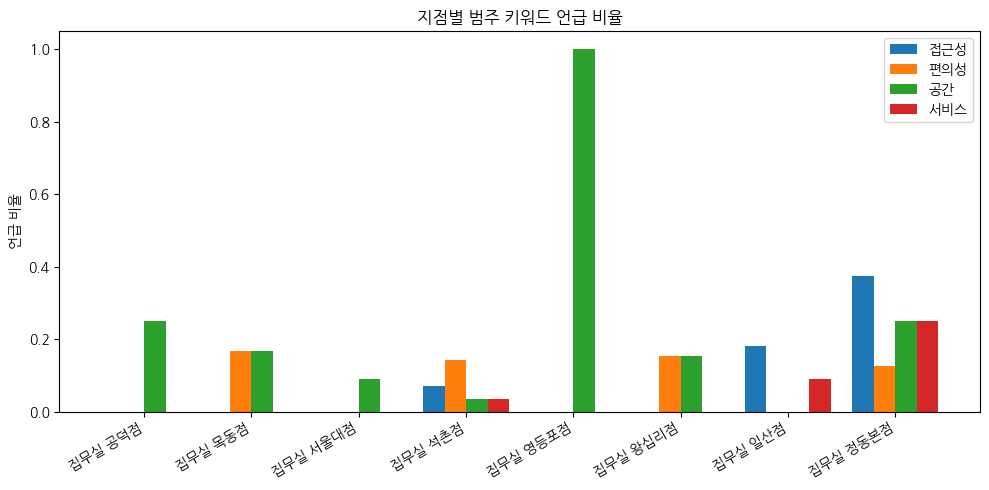

In [ ]:
# 지점별 경험 범주 키워드 언급 비율 시각화

categories = ["접근성", "편의성", "공간", "서비스"]
kw_cols = [f"kw_{c}_ratio" for c in categories]

x = np.arange(len(map_site_table))
width = 0.2

fig, ax = plt.subplots(figsize=(10, 5))
for i, col in enumerate(kw_cols):
    ax.bar(x + i*width, map_site_table[col], width, label=categories[i])

ax.set_xticks(x + width*1.5)
ax.set_xticklabels(map_site_table["site_name"], rotation=30, ha='right')
ax.set_ylabel("언급 비율")
ax.set_title("지점별 범주 키워드 언급 비율")
ax.legend()
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 지도 리뷰에서 어떤 경험 범주가 자주 언급되는지 지점별로 비교하며, 언급이 많다는 것이 곧 긍정 또는 부정을 의미하지는 않는다.


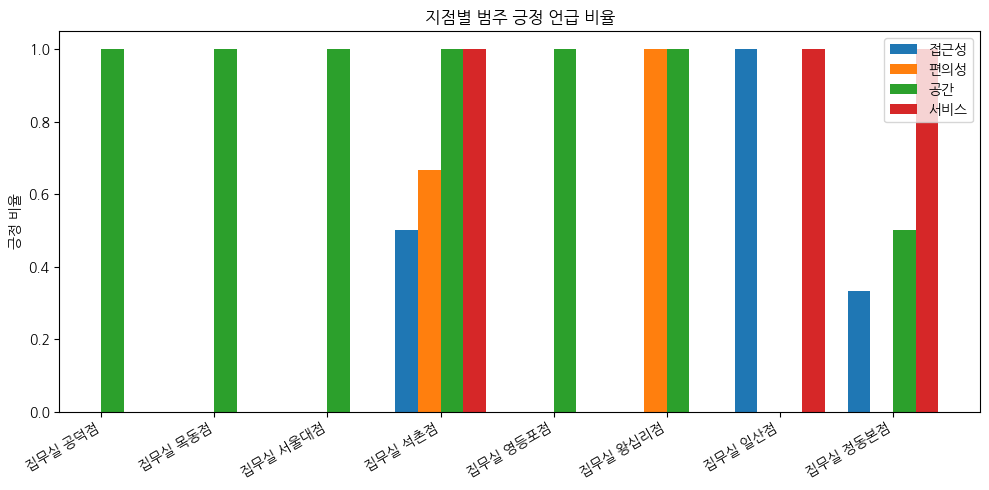

In [ ]:
# 지점별 경험 범주 긍정 언급 비율 시각화

sentiment_cols = [f"{c}_positive_ratio" for c in categories]

fig, ax = plt.subplots(figsize=(10, 5))
for i, col in enumerate(sentiment_cols):
    ax.bar(x + i*width, map_site_table[col], width, label=categories[i])

ax.set_xticks(x + width*1.5)
ax.set_xticklabels(map_site_table["site_name"], rotation=30, ha='right')
ax.set_ylabel("긍정 비율")
ax.set_title("지점별 범주 긍정 언급 비율")
ax.legend()
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 범주별 긍정 언급 비율은 지점별 경험 강점을 보여주지만, 언급 리뷰 수가 적은 범주는 결측 또는 극단값이 발생하므로 표본 수와 함께 해석한다.


In [ ]:
# 지점별 상위 TF-IDF 키워드를 표로 정리

# 시각화보다 표가 정확 — 지점별 상위 5개 키워드를 정리
tfidf_summary = []
for site in map_site_table["site_name"]:
    keywords = top_keywords_for_site(site, top_n=5)
    tfidf_summary.append({"site_name": site, "top_keywords": ", ".join([k for k, s in keywords])})

tfidf_df = pd.DataFrame(tfidf_summary)
display(tfidf_df)

,site_name,top_keywords
0,집무실 공덕점,"장소, 최적 장소, 최적, 창가 자리, 창가"
1,집무실 목동점,"독서실, 비싸, 최고, 스터디, 업무 집중도"
2,집무실 서울대점,"장소, 사무실, 미팅, 편안, 최적"
3,집무실 석촌점,"오피스, 공유, 공유 오피스, 주차, 공간"
4,집무실 영등포점,"생기, 집중"
5,집무실 왕십리점,"카페, 이용, 업무, 집무실, 자유"
6,집무실 일산점,"사무실, 해피 타임, 해피, 친절, 편안 분위기"
7,집무실 정동본점,"생각, 느낌, 분위기, 친절, 창문"


> **💡 결과 해석**
>
> - 상위 TF-IDF 키워드는 목동점의 집중·학습 목적, 일산점의 친절·편안함, 정동본점의 분위기·창문 등 지점별 경험 차이를 보여준다.


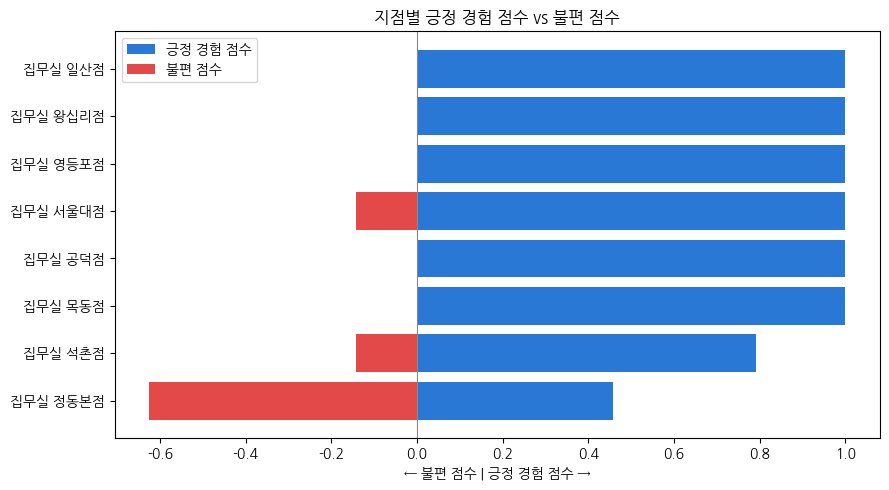

In [ ]:
# 지점별 긍정 경험 점수와 불편 점수 비교 시각화

plot_df = map_site_table.sort_values("positive_experience_score")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_df["site_name"], plot_df["positive_experience_score"], color='#2a78d6', label="긍정 경험 점수")
ax.barh(plot_df["site_name"], -plot_df["discomfort_score"], color='#e34948', label="불편 점수")

ax.axvline(0, color='#898781', linewidth=0.8)
ax.set_xlabel("← 불편 점수 | 긍정 경험 점수 →")
ax.set_title("지점별 긍정 경험 점수 vs 불편 점수")
ax.legend()
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 대부분 지점은 긍정 경험 점수가 불편 점수보다 높지만 정동본점은 불편 점수가 더 높아 운영 개선 우선 신호가 나타난다.


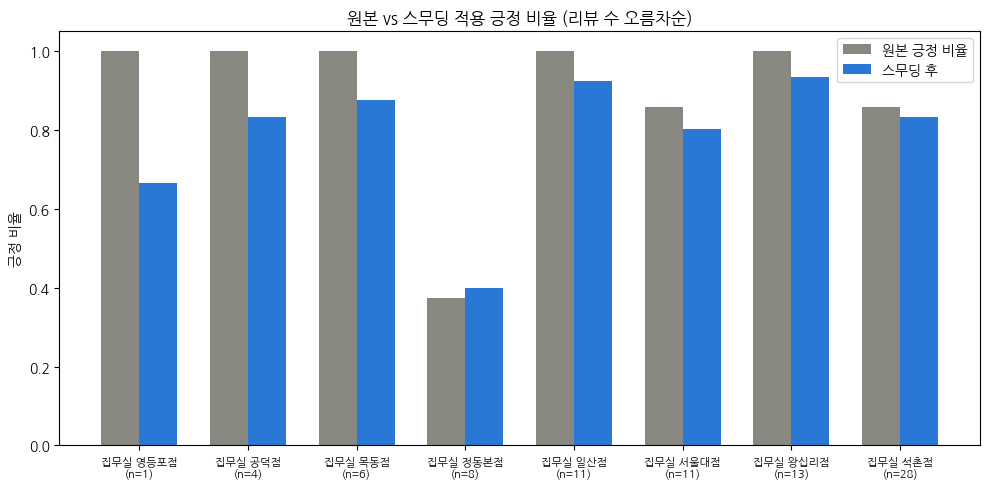

In [ ]:
# 리뷰 수를 고려한 원본 긍정 비율과 스무딩 비율 비교

plot_df = map_site_table.sort_values("map_review_count")

x = np.arange(len(plot_df))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width/2, plot_df["map_positive_ratio"], width, label="원본 긍정 비율", color='#888780')
ax.bar(x + width/2, plot_df["smoothed_positive_ratio"], width, label="스무딩 후", color='#2a78d6')

ax.set_xticks(x)
ax.set_xticklabels([f"{n}\n(n={c})" for n, c in zip(plot_df["site_name"], plot_df["map_review_count"])], fontsize=8)
ax.set_ylabel("긍정 비율")
ax.set_title("원본 vs 스무딩 적용 긍정 비율 (리뷰 수 오름차순)")
ax.legend()
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 리뷰 수가 적은 지점일수록 원본 긍정 비율이 0% 또는 100%로 치우치며, 스무딩 비율이 이를 완화하는 모습을 확인할 수 있다.


#### 6-3-4-4. 블로그 리뷰 전처리 및 지점별 분석

**🔹 분석 목적**

- 블로그 제목과 본문을 결합하고 형태소·경험 범주·감성 지표를 생성한다.
- 지점명과 범용 브랜드 단어가 TF-IDF를 지배하지 않도록 불용어를 보완한다.
- 지점별 게시글 수, 경험 범주 언급률, 긍정 경험 점수, 불편 점수와 스무딩 긍정 비율을 산출한다.
- 블로그 결과는 객관적 만족도보다 방문 전 기대와 공개 후기의 정보 구조로 해석한다.


In [ ]:
# 블로그 제목과 본문을 결합해 텍스트를 정제하고 홍보성 게시글 플래그 생성

df_blog_reviews_clean["full_text"] = (df_blog_reviews_clean["title"] + " " + df_blog_reviews_clean["description"]).fillna("")

def clean_review_text(text):
    if pd.isna(text) or text.strip() == "":
        return ""
    text = re.sub(r"http\S+|www\.\S+", "", text)
    text = re.sub(r"[^\w\s가-힣]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_blog_reviews_clean["clean_text"] = df_blog_reviews_clean["full_text"].apply(clean_review_text)

promo_pattern = "협찬|제공받아|원고료|체험단|이벤트 참여"
df_blog_reviews_clean["is_promo"] = df_blog_reviews_clean["clean_text"].str.contains(promo_pattern, na=False)
print("홍보성 게시글 건수:", df_blog_reviews_clean["is_promo"].sum())

홍보성 게시글 건수: 9


> **✅ 확인 결과**
>
> - 블로그 게시글 중 홍보성 표현이 강한 글은 9건으로 표시했으며, 채널 특성상 후기와 프로모션 정보가 혼재함을 전제로 분석한다.


In [ ]:
# Kiwi 형태소 분석으로 블로그 리뷰의 핵심 품사 추출

kiwi = Kiwi()

def extract_morphs(text, pos_filter=("NNG", "NNP", "VA", "VV")):
    if text == "":
        return []
    result = kiwi.analyze(text)
    tokens = result[0][0]
    return [t.form for t in tokens if t.tag in pos_filter]

df_blog_reviews_clean["morphs"] = df_blog_reviews_clean["clean_text"].apply(extract_morphs)
df_blog_reviews_clean["morph_text"] = df_blog_reviews_clean["morphs"].apply(lambda m: " ".join(m))

In [ ]:
# 경험 범주 사전을 블로그 리뷰에 적용

category_cols = []
for category, keywords in category_dict.items():
    col = f"kw_{category}"
    df_blog_reviews_clean[col] = df_blog_reviews_clean["morphs"].apply(lambda m: any(k in " ".join(m) for k in keywords))
    category_cols.append(col)

df_blog_reviews_clean["category_hit_count"] = df_blog_reviews_clean[category_cols].sum(axis=1)

In [ ]:
# 지점별 블로그 게시글 수와 경험 범주 언급률 산출

site_summary = df_blog_reviews_clean.groupby("site_name").size().reset_index(name="blog_post_count")

site_kw_ratio = df_blog_reviews_clean.groupby("site_name")[category_cols].mean().reset_index()
site_kw_ratio.columns = ["site_name"] + [f"{c}_ratio" for c in category_cols]

In [ ]:
# 블로그 리뷰의 전체 및 범주별 감성 지표 산출

sentiment_analyzer = hf_pipeline(
    "sentiment-analysis",
    model="matthewburke/korean_sentiment"
)

# 텍스트 있는 게시글만 대상
has_text_mask = df_blog_reviews_clean["clean_text"].str.strip() != ""
target_idx = df_blog_reviews_clean[has_text_mask].index
texts = df_blog_reviews_clean.loc[target_idx, "clean_text"].tolist()

results = []
for i in range(0, len(texts), 16):
    batch = texts[i:i+16]
    batch_results = sentiment_analyzer(batch, truncation=True, max_length=128)
    results.extend(batch_results)
    print(f"진행: {min(i+16, len(texts))}/{len(texts)}")

df_blog_reviews_clean["sentiment_kr"] = None
df_blog_reviews_clean.loc[target_idx, "sentiment_kr"] = ["긍정" if r["label"] == "LABEL_1" else "부정" for r in results]

df_blog_reviews_clean["sentiment_score"] = df_blog_reviews_clean["sentiment_kr"].map({"긍정": 1, "부정": 0})

# 전체 긍정/부정 비율
site_sentiment = df_blog_reviews_clean[df_blog_reviews_clean["sentiment_kr"].notna()].groupby("site_name")["sentiment_score"].mean().reset_index(name="positive_ratio")
site_sentiment["negative_ratio"] = 1 - site_sentiment["positive_ratio"]

# 범주별 긍정 비율 (범주 언급 + 텍스트 존재 게시글만)
attr_results = []
for category in category_dict:
    kw_col = f"kw_{category}"
    subset = df_blog_reviews_clean[(df_blog_reviews_clean[kw_col]) & (df_blog_reviews_clean["sentiment_kr"].notna())]
    ratio = subset.groupby("site_name")["sentiment_kr"].apply(
        lambda x: (x == "긍정").mean() if len(x) > 0 else None
    ).reset_index(name=f"{category}_positive_ratio")
    attr_results.append(ratio)

blog_attr_sentiment = reduce(lambda l, r: l.merge(r, on="site_name", how="outer"), attr_results)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

진행: 16/360
진행: 32/360
진행: 48/360
진행: 64/360
진행: 80/360
진행: 96/360
진행: 112/360
진행: 128/360
진행: 144/360
진행: 160/360
진행: 176/360
진행: 192/360
진행: 208/360
진행: 224/360
진행: 240/360
진행: 256/360
진행: 272/360
진행: 288/360
진행: 304/360
진행: 320/360
진행: 336/360
진행: 352/360
진행: 360/360


> **✅ 실행 결과**
>
> - 블로그 360건 전체에 대해 감성 및 경험 범주별 긍정 지표 계산을 완료했다.


In [ ]:
# 지점명과 범용어를 제외한 블로그 리뷰 TF-IDF 키워드 추출

site_names_all = df_blog_reviews_clean["site_name"].unique()
site_keywords = set()
for name in site_names_all:
    site_keywords.update(name.replace("집무실", "").split())

custom_stopwords = {"집무실", "후기", "오피스", "이용", "오픈", "방문"} | site_keywords

corpus = df_blog_reviews_clean[df_blog_reviews_clean["morph_text"] != ""]["morph_text"].tolist()
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=150, min_df=2, stop_words=list(custom_stopwords))
tfidf_matrix = tfidf.fit_transform(corpus)
feature_names = tfidf.get_feature_names_out()

def top_keywords_for_blog_site(site_name, top_n=5):
    site_texts = df_blog_reviews_clean[(df_blog_reviews_clean["site_name"] == site_name) & (df_blog_reviews_clean["morph_text"] != "")]["morph_text"].tolist()
    if len(site_texts) == 0:
        return []
    site_matrix = tfidf.transform(site_texts)
    mean_scores = np.asarray(site_matrix.mean(axis=0)).flatten()
    top_idx = mean_scores.argsort()[::-1][:top_n]
    return [(feature_names[i], round(mean_scores[i], 3)) for i in top_idx if mean_scores[i] > 0]

In [ ]:
# 블로그 리뷰의 긍정 경험 점수와 불편 점수 산출

site_final = site_summary.merge(site_kw_ratio, on="site_name") \
                          .merge(site_sentiment, on="site_name") \
                          .merge(blog_attr_sentiment, on="site_name", how="left")

positive_cols = [f"{c}_positive_ratio" for c in category_dict]
site_final["positive_experience_score"] = site_final[positive_cols].mean(axis=1)
site_final["discomfort_score"] = site_final["negative_ratio"]

In [ ]:
# 블로그 게시글 수를 고려한 긍정 비율 라플라스 스무딩 적용

alpha = 1
site_final["smoothed_positive_ratio"] = (
    site_final["positive_ratio"] * site_final["blog_post_count"] + alpha
) / (site_final["blog_post_count"] + 2 * alpha)

In [ ]:
# 블로그 리뷰 지점별 분석 테이블 생성 및 확인

blog_site_table = site_final.copy()
print(blog_site_table.columns.tolist())
display(blog_site_table)

['site_name', 'blog_post_count', 'kw_접근성_ratio', 'kw_편의성_ratio', 'kw_공간_ratio', 'kw_서비스_ratio', 'positive_ratio', 'negative_ratio', '접근성_positive_ratio', '편의성_positive_ratio', '공간_positive_ratio', '서비스_positive_ratio', 'positive_experience_score', 'discomfort_score', 'smoothed_positive_ratio']


,site_name,blog_post_count,kw_접근성_ratio,kw_편의성_ratio,kw_공간_ratio,kw_서비스_ratio,positive_ratio,negative_ratio,접근성_positive_ratio,편의성_positive_ratio,공간_positive_ratio,서비스_positive_ratio,positive_experience_score,discomfort_score,smoothed_positive_ratio
0,집무실 공덕점,26,0.615385,0.115385,0.230769,0.038462,0.961538,0.038462,1.000000,1.000000,0.833333,1.0,0.958333,0.038462,0.928571
1,집무실 목동점,36,0.444444,0.305556,0.166667,0.027778,0.888889,0.111111,0.875000,0.818182,1.000000,1.0,0.923295,0.111111,0.868421
2,집무실 분당점,18,1.000000,0.277778,0.111111,0.000000,0.833333,0.166667,0.833333,0.600000,0.000000,NaN,0.477778,0.166667,0.800000
3,집무실 서울대점,59,0.474576,0.203390,0.322034,0.016949,0.949153,0.050847,0.892857,0.916667,0.947368,1.0,0.939223,0.050847,0.934426
4,집무실 석촌점,61,0.540984,0.196721,0.245902,0.016393,0.885246,0.114754,0.969697,0.833333,0.866667,1.0,0.917424,0.114754,0.873016
5,집무실 영등포점,11,0.636364,0.272727,0.272727,0.090909,0.727273,0.272727,0.857143,0.333333,0.666667,1.0,0.714286,0.272727,0.692308
6,집무실 왕십리점,56,0.625000,0.160714,0.160714,0.000000,0.839286,0.160714,0.828571,0.555556,0.888889,NaN,0.757672,0.160714,0.827586
7,집무실 일산점,31,0.516129,0.258065,0.064516,0.032258,0.903226,0.096774,0.937500,1.000000,1.000000,1.0,0.984375,0.096774,0.878788
8,집무실 정동본점,62,0.580645,0.177419,0.161290,0.000000,0.903226,0.096774,0.944444,0.909091,0.800000,NaN,0.884512,0.096774,0.890625


> **💡 결과 해석**
>
> - 블로그 긍정 비율은 공덕점 96.2%, 서울대점 94.9% 등 전반적으로 높았으며, 영등포점은 72.7%로 상대적으로 낮았다.
> - 블로그는 검색·소개 성격이 강하므로 이 비율을 방문 후 만족도로 직접 해석하지 않는다.


In [ ]:
# 블로그 리뷰의 지점별 TF-IDF 키워드 초기 결과 확인

corpus = df_blog_reviews_clean[df_blog_reviews_clean["morph_text"] != ""]["morph_text"].tolist()
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=150, min_df=2)
tfidf_matrix = tfidf.fit_transform(corpus)
feature_names = tfidf.get_feature_names_out()

def top_keywords_for_blog_site(site_name, top_n=5):
    site_texts = df_blog_reviews_clean[
        (df_blog_reviews_clean["site_name"] == site_name) & (df_blog_reviews_clean["morph_text"] != "")
    ]["morph_text"].tolist()
    if len(site_texts) == 0:
        return []
    site_matrix = tfidf.transform(site_texts)
    mean_scores = np.asarray(site_matrix.mean(axis=0)).flatten()
    top_idx = mean_scores.argsort()[::-1][:top_n]
    return [(feature_names[i], round(mean_scores[i], 3)) for i in top_idx if mean_scores[i] > 0]

tfidf_summary = []
for site in df_blog_reviews_clean["site_name"].unique():
    keywords = top_keywords_for_blog_site(site, top_n=5)
    tfidf_summary.append({"site_name": site, "top_keywords": ", ".join([k for k, s in keywords])})

blog_tfidf_df = pd.DataFrame(tfidf_summary)
display(blog_tfidf_df)

,site_name,top_keywords
0,집무실 영등포점,"영등포점, 집무실, 이용, 후기, 이용 후기"
1,집무실 왕십리점,"왕십리, 집무실, 집무실 왕십리, 후기, 체험"
2,집무실 공덕점,"공덕, 집무실, 집무실 공덕, 공유, 후기"
3,집무실 정동본점,"정동, 집무실, 본점, 정동 본점, 집무실 정동"
4,집무실 일산점,"일산, 집무실, 집무실 일산, 이용, 오피스"
5,집무실 서울대점,"집무실, 서울대, 집무실 서울대, 서울대점, 집무실 서울대점"
6,집무실 석촌점,"집무실, 석촌점, 집무실 석촌점, 이용, 후기"
7,집무실 목동점,"목동, 집무실, 집무실 목동, 후기, 이용"
8,집무실 분당점,"분당, 집무실 분당, 집무실, 분당점, 이용"


> **💡 품질 점검**
>
> - 초기 TF-IDF 결과는 지점명과 브랜드명이 상위 키워드를 대부분 차지해 실제 경험 차이를 설명하기 어려웠다.


In [ ]:
# 지점명 불용어를 반영해 블로그 리뷰 TF-IDF 키워드 재산출

# 지점명에서 "집무실" 뗀 나머지 부분들을 불용어 집합에 추가
site_names_all = df_blog_reviews_clean["site_name"].unique()
site_keywords = set()
for name in site_names_all:
    site_keywords.update(name.replace("집무실", "").split())

# 범용어 + 지점명 불용어 합치기
custom_stopwords = {"집무실", "후기", "오피스", "이용", "오픈", "방문"} | site_keywords

# 불용어 반영해서 TF-IDF 재실행
corpus = df_blog_reviews_clean[df_blog_reviews_clean["morph_text"] != ""]["morph_text"].tolist()
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=150, min_df=2, stop_words=list(custom_stopwords))
tfidf_matrix = tfidf.fit_transform(corpus)
feature_names = tfidf.get_feature_names_out()

def top_keywords_for_blog_site(site_name, top_n=5):
    site_texts = df_blog_reviews_clean[
        (df_blog_reviews_clean["site_name"] == site_name) & (df_blog_reviews_clean["morph_text"] != "")
    ]["morph_text"].tolist()
    if len(site_texts) == 0:
        return []
    site_matrix = tfidf.transform(site_texts)
    mean_scores = np.asarray(site_matrix.mean(axis=0)).flatten()
    top_idx = mean_scores.argsort()[::-1][:top_n]
    return [(feature_names[i], round(mean_scores[i], 3)) for i in top_idx if mean_scores[i] > 0]

# 지점별 결과 재생성
tfidf_summary = []
for site in df_blog_reviews_clean["site_name"].unique():
    keywords = top_keywords_for_blog_site(site, top_n=5)
    tfidf_summary.append({"site_name": site, "top_keywords": ", ".join([k for k, s in keywords])})

blog_tfidf_df = pd.DataFrame(tfidf_summary)
display(blog_tfidf_df)

,site_name,top_keywords
0,집무실 영등포점,"지점, 공유, 동안, 체험, 생기"
1,집무실 왕십리점,"왕십리, 체험, 공유, 무료, 공간"
2,집무실 공덕점,"공덕, 공유, 지점, 근처, 공유 공덕"
3,집무실 정동본점,"정동, 본점, 정동 본점, 공유, 체험"
4,집무실 일산점,"일산, 공유, 지점, 무료, 체험"
5,집무실 서울대점,"서울대, 공유, 체험, 무료, 지점"
6,집무실 석촌점,"공유, 체험, 석촌역, 지점, 근처"
7,집무실 목동점,"목동, 공유, 체험, 사무실, 지점"
8,집무실 분당점,"분당, 나오, 지점, 공유, 무료"


> **💡 결과 해석**
>
> - 지점명 불용어를 보완한 뒤 공간·체험·근처·사무실·재택 등 방문 목적과 탐색 정보가 더 드러났다.
> - 일부 지점명이 여전히 남아 블로그 키워드는 보조적 해석에 사용한다.


In [ ]:
# 블로그 리뷰 지점별 경험 점수 재계산

positive_cols_blog = [f"{c}_positive_ratio" for c in category_dict]

site_final = site_summary.merge(site_kw_ratio, on="site_name") \
                          .merge(site_sentiment, on="site_name") \
                          .merge(blog_attr_sentiment, on="site_name", how="left")

site_final["positive_experience_score"] = site_final[positive_cols_blog].mean(axis=1)
site_final["discomfort_score"] = site_final["negative_ratio"]

In [ ]:
# 블로그 리뷰 긍정 비율 스무딩 값 재계산

alpha = 1
site_final["smoothed_positive_ratio"] = (
    site_final["positive_ratio"] * site_final["blog_post_count"] + alpha
) / (site_final["blog_post_count"] + 2 * alpha)

In [ ]:
# 최종 블로그 리뷰 지점별 분석 테이블 확인

blog_site_table = site_final.copy()
print(blog_site_table.columns.tolist())
display(blog_site_table)

['site_name', 'blog_post_count', 'kw_접근성_ratio', 'kw_편의성_ratio', 'kw_공간_ratio', 'kw_서비스_ratio', 'positive_ratio', 'negative_ratio', '접근성_positive_ratio', '편의성_positive_ratio', '공간_positive_ratio', '서비스_positive_ratio', 'positive_experience_score', 'discomfort_score', 'smoothed_positive_ratio']


,site_name,blog_post_count,kw_접근성_ratio,kw_편의성_ratio,kw_공간_ratio,kw_서비스_ratio,positive_ratio,negative_ratio,접근성_positive_ratio,편의성_positive_ratio,공간_positive_ratio,서비스_positive_ratio,positive_experience_score,discomfort_score,smoothed_positive_ratio
0,집무실 공덕점,26,0.615385,0.115385,0.230769,0.038462,0.961538,0.038462,1.000000,1.000000,0.833333,1.0,0.958333,0.038462,0.928571
1,집무실 목동점,36,0.444444,0.305556,0.166667,0.027778,0.888889,0.111111,0.875000,0.818182,1.000000,1.0,0.923295,0.111111,0.868421
2,집무실 분당점,18,1.000000,0.277778,0.111111,0.000000,0.833333,0.166667,0.833333,0.600000,0.000000,NaN,0.477778,0.166667,0.800000
3,집무실 서울대점,59,0.474576,0.203390,0.322034,0.016949,0.949153,0.050847,0.892857,0.916667,0.947368,1.0,0.939223,0.050847,0.934426
4,집무실 석촌점,61,0.540984,0.196721,0.245902,0.016393,0.885246,0.114754,0.969697,0.833333,0.866667,1.0,0.917424,0.114754,0.873016
5,집무실 영등포점,11,0.636364,0.272727,0.272727,0.090909,0.727273,0.272727,0.857143,0.333333,0.666667,1.0,0.714286,0.272727,0.692308
6,집무실 왕십리점,56,0.625000,0.160714,0.160714,0.000000,0.839286,0.160714,0.828571,0.555556,0.888889,NaN,0.757672,0.160714,0.827586
7,집무실 일산점,31,0.516129,0.258065,0.064516,0.032258,0.903226,0.096774,0.937500,1.000000,1.000000,1.0,0.984375,0.096774,0.878788
8,집무실 정동본점,62,0.580645,0.177419,0.161290,0.000000,0.903226,0.096774,0.944444,0.909091,0.800000,NaN,0.884512,0.096774,0.890625


> **💡 결과 해석**
>
> - 블로그 최종 분석 테이블은 9개 지점을 모두 포함하며, 접근성 언급 비율이 전반적으로 높아 방문 방법과 위치 정보가 주요 콘텐츠임을 보여준다.


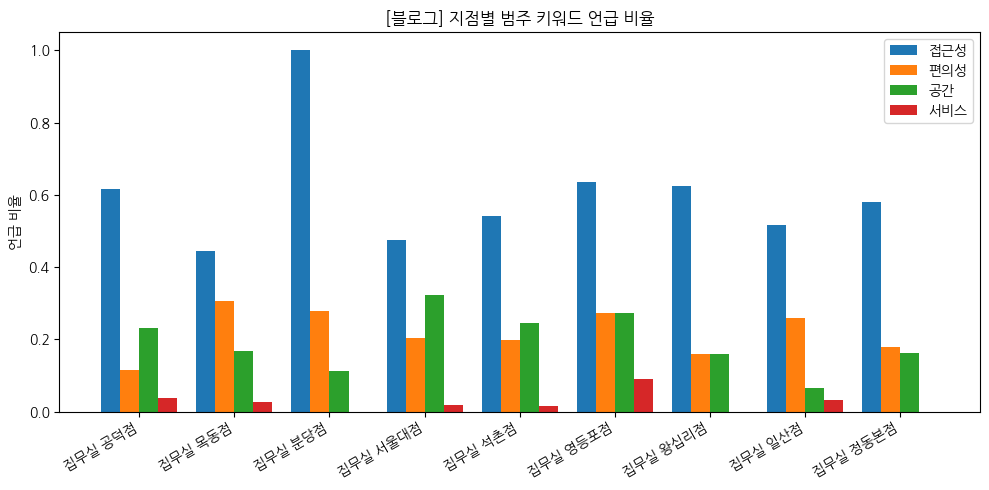

In [ ]:
# 블로그 리뷰의 지점별 경험 범주 언급 비율 시각화

categories = list(category_dict.keys())
kw_cols = [f"kw_{c}_ratio" for c in categories]

x = np.arange(len(blog_site_table))
width = 0.2

fig, ax = plt.subplots(figsize=(10, 5))
for i, col in enumerate(kw_cols):
    ax.bar(x + i*width, blog_site_table[col], width, label=categories[i])

ax.set_xticks(x + width*1.5)
ax.set_xticklabels(blog_site_table["site_name"], rotation=30, ha='right')
ax.set_ylabel("언급 비율")
ax.set_title("[블로그] 지점별 범주 키워드 언급 비율")
ax.legend()
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 블로그에서는 접근성 범주 언급이 여러 지점에서 가장 높아 공개 후기의 핵심 역할이 지점 탐색과 방문 정보 제공에 있음을 보여준다.


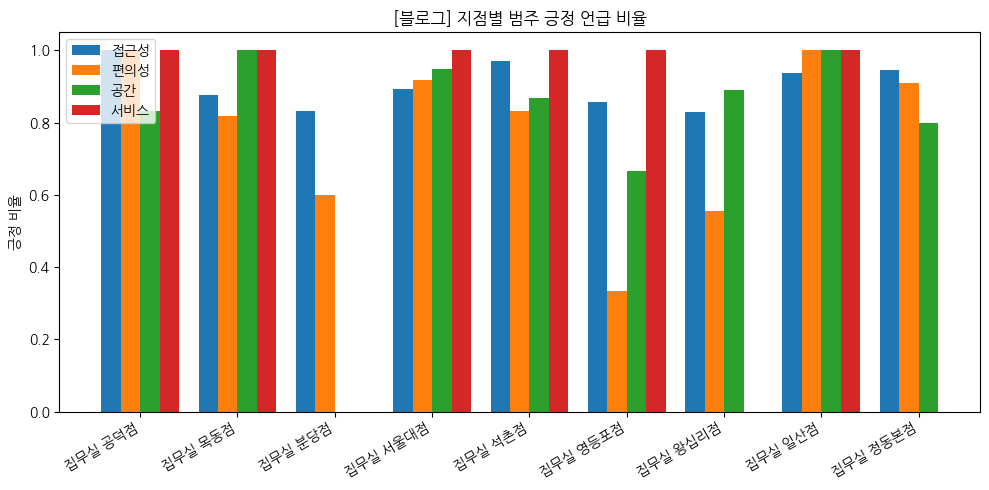

In [ ]:
# 블로그 리뷰의 지점별 경험 범주 긍정 비율 시각화

sentiment_cols = [f"{c}_positive_ratio" for c in categories]

fig, ax = plt.subplots(figsize=(10, 5))
for i, col in enumerate(sentiment_cols):
    ax.bar(x + i*width, blog_site_table[col], width, label=categories[i])

ax.set_xticks(x + width*1.5)
ax.set_xticklabels(blog_site_table["site_name"], rotation=30, ha='right')
ax.set_ylabel("긍정 비율")
ax.set_title("[블로그] 지점별 범주 긍정 언급 비율")
ax.legend()
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 범주별 긍정 비율은 전반적으로 높지만 지점별 게시글 수와 홍보성 내용의 영향을 받으므로 상대적 차이만 참고한다.


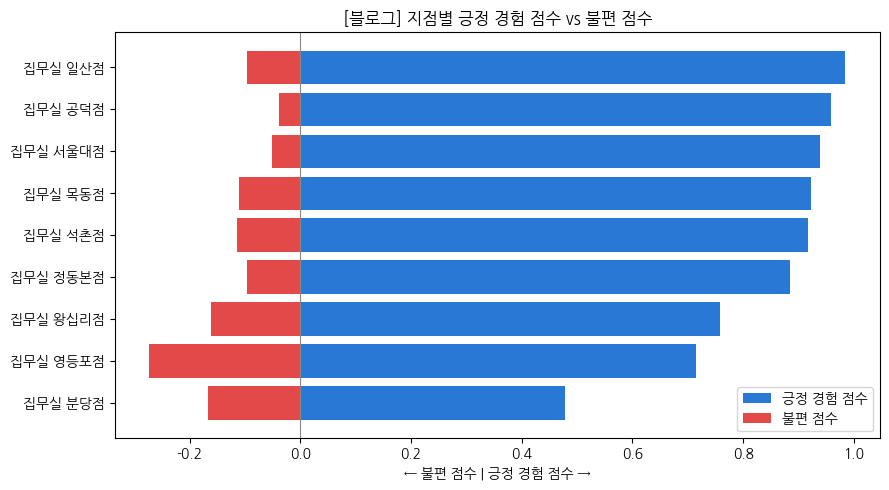

In [ ]:
# 블로그 리뷰의 지점별 긍정 경험 점수와 불편 점수 비교

plot_df = blog_site_table.sort_values("positive_experience_score")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_df["site_name"], plot_df["positive_experience_score"], color='#2a78d6', label="긍정 경험 점수")
ax.barh(plot_df["site_name"], -plot_df["discomfort_score"], color='#e34948', label="불편 점수")

ax.axvline(0, color='#898781', linewidth=0.8)
ax.set_xlabel("← 불편 점수 | 긍정 경험 점수 →")
ax.set_title("[블로그] 지점별 긍정 경험 점수 vs 불편 점수")
ax.legend()
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 블로그 채널의 긍정 경험 점수는 대체로 높아 지도 리뷰보다 긍정적으로 보이며, 이는 채널 성격 차이를 반영한다.


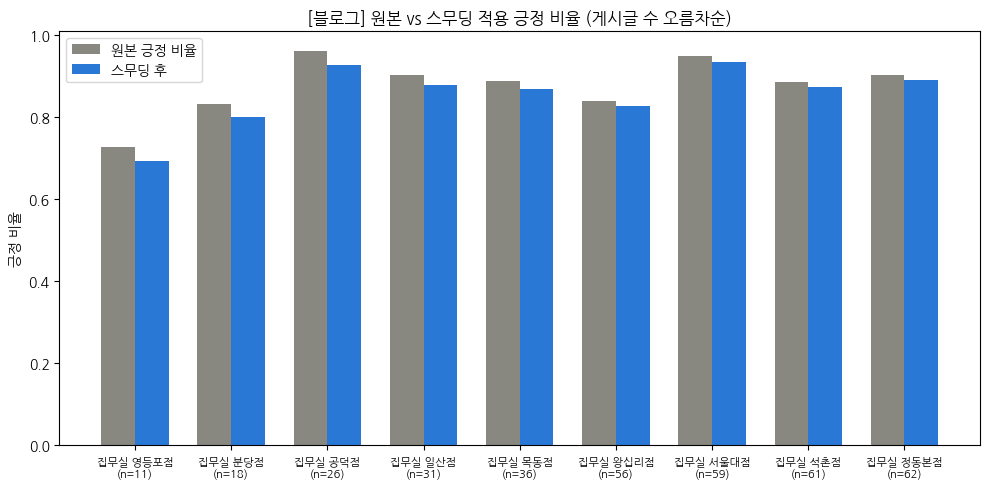

In [ ]:
# 블로그 게시글 수에 따른 원본 및 스무딩 긍정 비율 비교

plot_df = blog_site_table.sort_values("blog_post_count")

x = np.arange(len(plot_df))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width/2, plot_df["positive_ratio"], width, label="원본 긍정 비율", color='#888780')
ax.bar(x + width/2, plot_df["smoothed_positive_ratio"], width, label="스무딩 후", color='#2a78d6')

ax.set_xticks(x)
ax.set_xticklabels([f"{n}\n(n={c})" for n, c in zip(plot_df["site_name"], plot_df["blog_post_count"])], fontsize=8)
ax.set_ylabel("긍정 비율")
ax.set_title("[블로그] 원본 vs 스무딩 적용 긍정 비율 (게시글 수 오름차순)")
ax.legend()
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 게시글 수가 적은 지점의 원본 긍정 비율을 스무딩이 완화해 채널 통합 시 표본 차이의 영향을 줄였다.


#### 6-3-4-5. 블로그 텍스트 심화 분석 Ⅰ — 1차 탐색 및 품질 한계 확인

**🔹 분석 목적**

- 360건의 블로그 게시글에서 전체 단어 빈도와 주요 표현을 확인한다.
- 워드클라우드와 LDA 토픽 모델링으로 공개 후기에서 반복되는 정보 구조를 탐색한다.
- 바이그램 연결망으로 `무료 체험–후기–지점 탐색` 관련 단어가 어떻게 연결되는지 시각화한다.
- 토픽 결과는 지점명과 프로모션 단어의 영향을 받으므로 고객 만족 요인으로 단정하지 않는다.


In [ ]:
# 블로그 데이터프레임 확인
print("데이터 크기:", df_blog_reviews_clean.shape)
print("컬럼 목록:")
print(df_blog_reviews_clean.columns.tolist())

# 형태소 분석 결과 확인
df_blog_reviews_clean[["clean_text", "morphs"]].head()

데이터 크기: (360, 22)
컬럼 목록:
['site_id', 'site_name', 'query', 'total_search_count', 'title', 'description', 'link', 'blogger_name', 'post_date', 'validity_final', 'full_text', 'clean_text', 'is_promo', 'morphs', 'morph_text', 'kw_접근성', 'kw_편의성', 'kw_공간', 'kw_서비스', 'category_hit_count', 'sentiment_kr', 'sentiment_score']


,clean_text,morphs
0,공유오피스 집무실 영등포점 3일체험 공유오피스 중에 가장 가성비 좋아보여서 관심갖고있던 집무실 한 달동안 1시간씩 33 000원 그리고 마땅한 곳이 없어서 전처럼 카페에서나 가끔 일을 해야겠다 매우 아쉬운 집무실 영등포점 후기 끝,"[공유, 오피스, 집무실, 영등포점, 체험, 공유, 오피스, 가성비, 좋, 보이, 관심, 갖, 집무실, 동안, 곳, 없, 전, 카페, 일, 하, 집무실, 영등포점, 후기, 끝]"
1,이용 후기 집 근처 사무실 집무실 영등포점 싶은 마음에 방문하였고 후기를 적어본다 2 집무실 지점_영등포점 현재 집무실은 수도권에 9개의 지점이 운영되고 있다 그중에서 영등포점 위주로 적어보려고 한다 요즘 민간임대 혹은 공공임대 형태의,"[이용, 후기, 집, 근처, 사무실, 집무실, 영등포점, 마음, 방문, 후기, 적, 집무실, 지점, 영등포점, 집무실, 수도, 지점, 운영, 그중, 영등포점, 위주, 적, 요즘, 민간, 임대, 공공, 임대, 형태]"
2,집무실 영등포점 스터디카페 NO 사무공간 이용 후기 위치 집무실 영등포점 이용후기 넓게 넓게 쓰는 편을 좋아하는 데 책상과 자리가 넓은 점이 가장 마음에 들었다 노트북 꺼내고 다이어리와 노트 펼치고 커피 한 잔 두어도 충분했다 모던하고 깔끔한 인테리어와,"[집무실, 영등포점, 스터디, 카페, 사무, 공간, 이용, 후기, 위치, 집무실, 영등포점, 이용, 후기, 넓, 넓, 쓰, 좋아하, 책상, 자리, 넓, 점, 마음, 들, 노트북, 꺼내, 다이어리, 노트, 펼치, 커피, 잔, 충분하, 모던, 인테리어]"
3,영등포 공유오피스 추천 집무실 후기 집근처 사무실 재택근무 후기 좋습니다 관리 잘되어있고 좌석도 다양해요 지점이 다양하게 존재합니다 가장 맘에 6 7 집무실 영등포점 찾아가는 방법 리마크빌을 찍고 오면 무지개처럼 생긴 구조물이 있습니다 그,"[영등포, 공유, 오피스, 추천, 집무실, 후기, 집, 근처, 사무실, 재택근무, 후기, 좋, 관리, 되, 좌석, 지점, 다양, 존재, 맘, 집무실, 영등포점, 찾아가, 방법, 리마크빌, 찍, 오, 무지개, 생기, 구조물, 있]"
4,집무실 서울대점 재택근무 이용 후기 무료 이용 꿀팁 궁금했던 분들 어서 오세요 광고 X 찐 사용 후기 집무실은 내가 그동안 이용해봤던 위워크 패스트파이브와 같이 공유오피스 프랜차이즈이며 서울대점 공덕점 분당점 석촌점 영등포점 왕십리점 일산점,"[집무실, 서울대점, 재택, 근무, 이용, 후기, 무료, 이용, 꿀, 팁, 궁금하, 오, 광고, 찐, 사용, 후기, 집무실, 동안, 이용, 위, 워크, 패스트, 공유, 오피스, 프랜차이즈, 서울대점, 공덕, 점, 분당점, 석촌점, 영등포점, 왕십리점, 일산점]"


> **✅ 확인 결과**
>
> - 블로그 최종 분석 표본은 360건·22개 컬럼이며, 정제 텍스트·형태소·경험 범주·감성 점수가 모두 포함되어 있다.


In [ ]:
# 모든 블로그 리뷰의 형태소를 하나의 리스트로 통합
blog_tokens = []

for tokens in df_blog_reviews_clean["morphs"].dropna():

    # 형태소가 리스트로 저장된 경우
    if isinstance(tokens, list):
        blog_tokens.extend(tokens)

    # 형태소가 문자열로 저장된 경우
    elif isinstance(tokens, str):
        blog_tokens.extend(tokens.split())


print("전체 단어 수:", len(blog_tokens))
print("형태소 예시:", blog_tokens[:30])

전체 단어 수: 11080
형태소 예시: ['공유', '오피스', '집무실', '영등포점', '체험', '공유', '오피스', '가성비', '좋', '보이', '관심', '갖', '집무실', '동안', '곳', '없', '전', '카페', '일', '하', '집무실', '영등포점', '후기', '끝', '이용', '후기', '집', '근처', '사무실', '집무실']


> **✅ 확인 결과**
>
> - 전체 블로그 게시글에서 11,080개의 형태소를 추출해 빈도·토픽·연결망 분석의 입력 데이터를 구성했다.


In [ ]:
# 분석 의미가 낮은 단어 제거
wordcloud_stopwords = {
    # 브랜드 및 일반 표현
    "집무실", "후기", "오피스", "공유", "이용",
    "체험", "무료", "지점", "본점", "점",
    "있", "하다", "되다", "이다", "같다",

    # 지점명
    "석촌점", "석촌",
    "왕십리점", "왕십리",
    "정동점", "정동",
    "서울대점", "서울대",
    "목동점", "목동",
    "공덕점", "공덕",
    "일산점", "일산"
}

# 한 글자 단어 및 불용어 제거
filtered_blog_tokens = [
    word
    for word in blog_tokens
    if word not in wordcloud_stopwords
    and len(word) >= 2
]

print("불용어 제거 전 단어 수:", len(blog_tokens))
print("불용어 제거 후 단어 수:", len(filtered_blog_tokens))
print("필터링 결과 예시:", filtered_blog_tokens[:30])

불용어 제거 전 단어 수: 11080
불용어 제거 후 단어 수: 4482
필터링 결과 예시: ['영등포점', '가성비', '보이', '관심', '동안', '카페', '영등포점', '근처', '사무실', '영등포점', '마음', '방문', '영등포점', '수도', '운영', '그중', '영등포점', '위주', '요즘', '민간', '임대', '공공', '임대', '형태', '영등포점', '스터디', '카페', '사무', '공간', '위치']


> **✅ 전처리 결과**
>
> - 브랜드명·범용 동사 등 분석 의미가 낮은 단어를 제거해 11,080개에서 4,482개로 토큰을 축소했다.


In [ ]:
# 단어별 등장 빈도 계산
blog_word_freq = Counter(filtered_blog_tokens)

print("고유 단어 수:", len(blog_word_freq))
print("\n상위 30개 단어:")

for word, count in blog_word_freq.most_common(30):
    print(word, count)

고유 단어 수: 1013

상위 30개 단어:
공간 90
방문 86
근처 84
사무실 71
분당 60
입구 56
추천 54
서울 50
카페 49
사용 49
위치 47
영등포점 46
업무 45
시간 43
정동본점 38
신청 38
분당점 37
소개 36
취준 31
재택 27
근무 27
안내 27
오늘 26
다녀오 26
나오 26
회원권 24
컴퍼니 23
출구 23
작성 22
분위기 22


> **💡 결과 해석**
>
> - 상위 단어는 공간·방문·근처·사무실·입구·추천·카페·위치·업무로, 블로그가 공간 경험과 방문 정보 모두를 담고 있음을 보여준다.


In [ ]:
# 설치한 나눔고딕 폰트 경로
font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"

print("폰트 경로:", font_path)
print("폰트 존재 여부:", os.path.exists(font_path))

폰트 경로: /usr/share/fonts/truetype/nanum/NanumGothic.ttf
폰트 존재 여부: True


In [ ]:
# 블로그 리뷰 워드클라우드 생성
wordcloud = WordCloud(
    font_path=font_path,
    width=1200,
    height=700,
    background_color="white",
    max_words=100,
    collocations=False,
    random_state=42
).generate_from_frequencies(blog_word_freq)

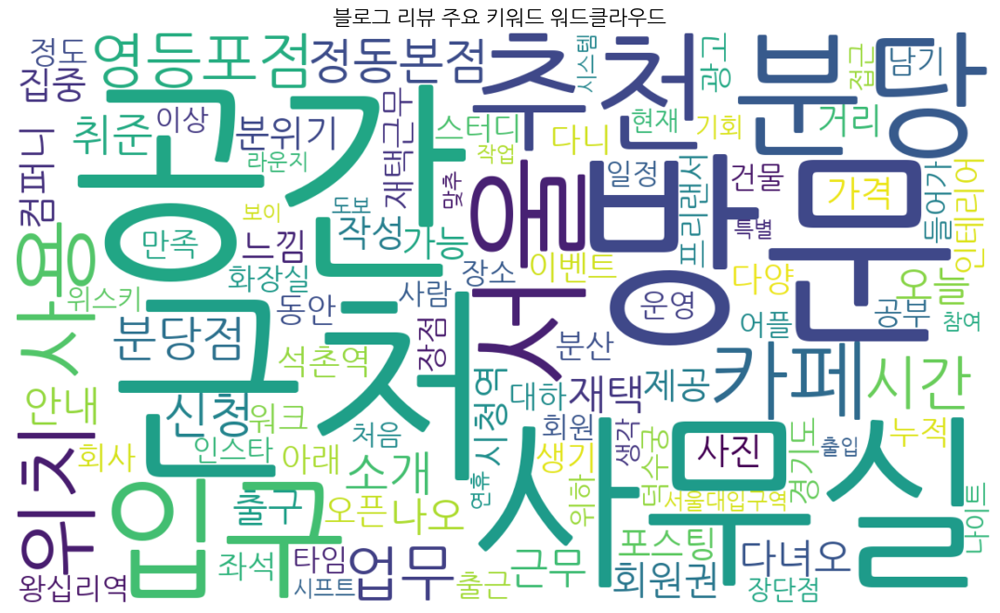

In [ ]:
# 한글 제목 출력을 위한 폰트 설정
title_font = fm.FontProperties(
    fname=font_path,
    size=16
)

# 워드클라우드 출력
plt.figure(figsize=(14, 8))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")

plt.title(
    "블로그 리뷰 주요 키워드 워드클라우드",
    fontproperties=title_font
)

plt.show()

> **📊 시각화 해석**
>
> - 워드클라우드에서 공간·방문·근처·사무실·위치 관련 단어가 크게 나타나 블로그 후기의 탐색·안내 성격이 시각적으로 확인된다.


In [ ]:
# 블로그 리뷰 토픽 모델링용 불용어 정의
blog_stopwords = {
    "집무실", "지점", "공간", "이용", "사용", "방문",
    "하다", "되다", "있다", "없다", "같다",
    "정말", "너무", "조금", "매우", "진짜",
    "그리고", "그래서", "하지만", "때문",
    "곳", "것", "수", "등", "점",
    "이번", "오늘", "시간", "생각"
}

In [ ]:
# 블로그 게시글별 토픽 모델링 문서 구성

topic_target = df_blog_reviews_clean[
    df_blog_reviews_clean["morph_text"].str.strip() != ""
].copy()

topic_target["topic_text"] = topic_target["morphs"].apply(
    lambda tokens: " ".join([
        token for token in tokens
        if len(token) >= 2
        and token not in blog_stopwords
        and not token.isdigit()
    ])
)

topic_target = topic_target[topic_target["topic_text"].str.strip() != ""].copy()

if len(topic_target) < 5:
    raise ValueError("토픽 모델링을 위해서는 전처리 후 최소 5개 이상의 블로그 게시글이 필요합니다.")

topic_min_df = 2 if len(topic_target) >= 20 else 1

topic_vectorizer = CountVectorizer(
    max_df=0.90,
    min_df=topic_min_df,
    max_features=500,
    stop_words=list(blog_stopwords),
    token_pattern=r"(?u)\b\w+\b"
)

topic_matrix = topic_vectorizer.fit_transform(topic_target["topic_text"])

if topic_matrix.shape[1] < 2:
    raise ValueError("토픽 모델링에 사용할 수 있는 고유 단어가 부족합니다.")

n_topics = min(4, topic_matrix.shape[0], topic_matrix.shape[1])
n_topics = max(2, n_topics)

lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    learning_method="batch",
    max_iter=30
)

topic_probability = lda_model.fit_transform(topic_matrix)
topic_feature_names = topic_vectorizer.get_feature_names_out()

topic_target["dominant_topic"] = topic_probability.argmax(axis=1) + 1
topic_target["topic_probability"] = topic_probability.max(axis=1)

print("분석 게시글 수:", len(topic_target))
print("사용 단어 수:", topic_matrix.shape[1])
print("토픽 수:", n_topics)

분석 게시글 수: 360
사용 단어 수: 500
토픽 수: 4


> **✅ 모델 구성**
>
> - 360개 문서와 500개 단어를 사용해 4개 토픽의 LDA 모델을 구성했다.


In [ ]:
# 토픽별 상위 키워드 표 생성

topic_keyword_rows = []
top_n_words = 10

for topic_idx, topic_weights in enumerate(lda_model.components_, start=1):
    top_indices = topic_weights.argsort()[::-1][:top_n_words]
    top_words = topic_feature_names[top_indices]
    top_scores = topic_weights[top_indices]

    for rank, (word, score) in enumerate(zip(top_words, top_scores), start=1):
        topic_keyword_rows.append({
            "topic": f"토픽 {topic_idx}",
            "rank": rank,
            "word": word,
            "weight": round(float(score), 3)
        })

topic_keyword_df = pd.DataFrame(topic_keyword_rows)

topic_keyword_summary = (
    topic_keyword_df
    .groupby("topic")["word"]
    .apply(lambda x: ", ".join(x))
    .reset_index(name="top_keywords")
)

display(topic_keyword_summary)

,topic,top_keywords
0,토픽 1,"목동, 오피스, 일산, 서울대점, 왕십리, 석촌점, 서울대, 분당, 공유, 업무"
1,토픽 2,"정동, 본점, 오피스, 공유, 체험, 석촌점, 왕십리, 서울대, 무료, 서울대점"
2,토픽 3,"무료, 오피스, 공유, 체험, 목동, 카페, 공덕, 영등포점, 일산, 재택"
3,토픽 4,"공유, 오피스, 왕십리, 사무실, 근처, 공덕, 석촌점, 분당, 남기, 생기"


> **💡 결과 해석**
>
> - 토픽에는 지점명·공유오피스·무료 체험 단어가 많이 포함되어 있어 순수한 고객 경험 유형보다 공개 후기의 서술 구조를 반영한다.


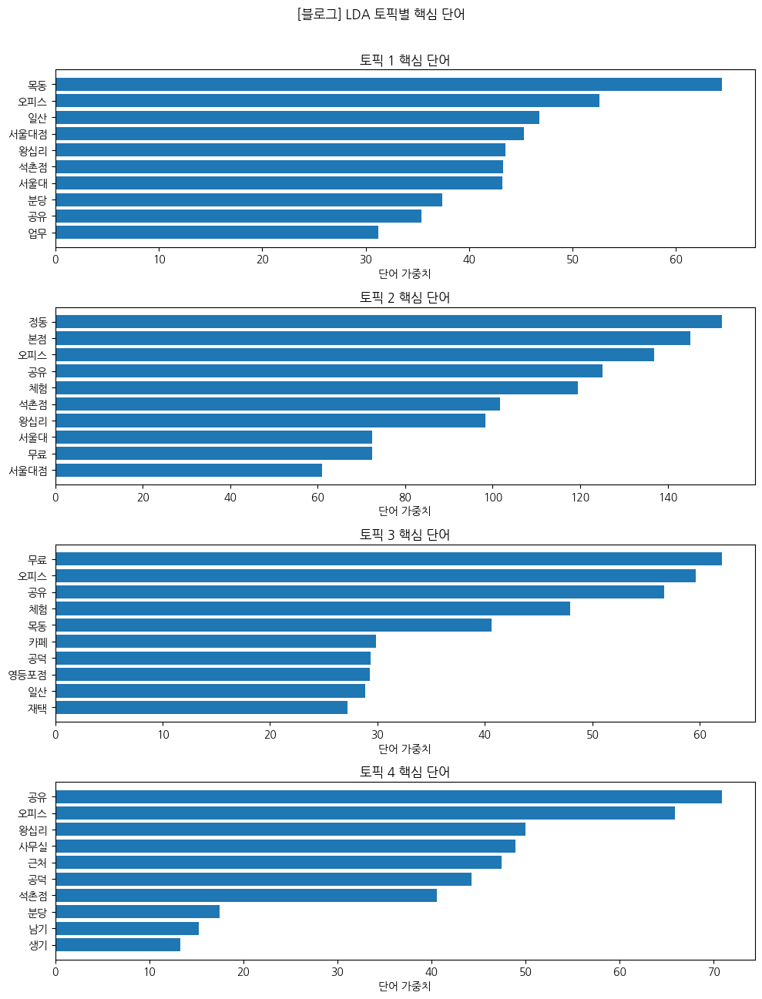

In [ ]:
# 토픽별 핵심 단어 가중치 시각화

fig, axes = plt.subplots(n_topics, 1, figsize=(10, 3.2 * n_topics))

if n_topics == 1:
    axes = [axes]

for topic_idx, ax in enumerate(axes, start=1):
    plot_data = (
        topic_keyword_df[topic_keyword_df["topic"] == f"토픽 {topic_idx}"]
        .sort_values("weight")
    )

    ax.barh(plot_data["word"], plot_data["weight"])
    ax.set_title(f"토픽 {topic_idx} 핵심 단어")
    ax.set_xlabel("단어 가중치")

plt.suptitle("[블로그] LDA 토픽별 핵심 단어", y=1.01)
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 토픽별 핵심 단어 가중치를 통해 각 토픽이 특정 지점·무료 체험·재택·근처 사무실 정보에 의해 구분되는 모습을 확인할 수 있다.


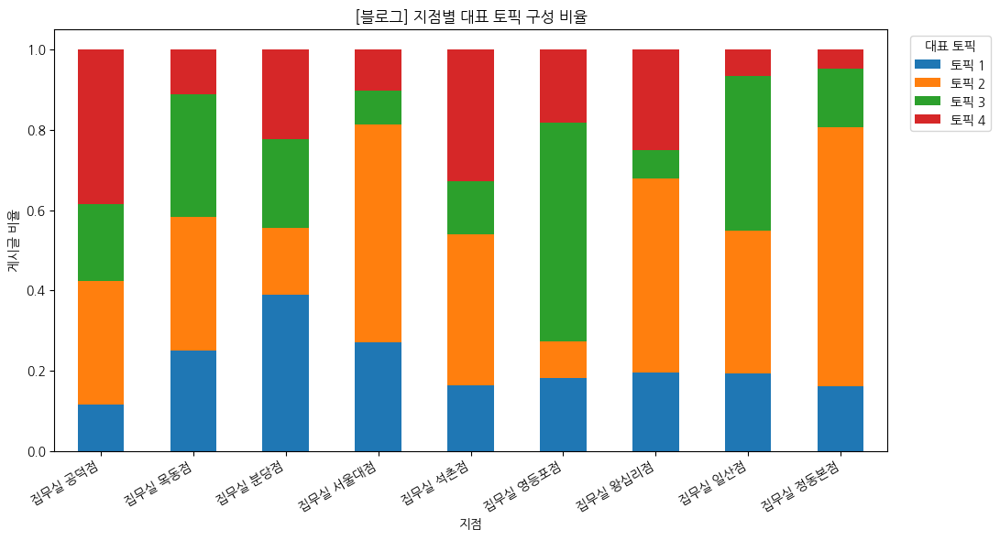

,토픽 1,토픽 2,토픽 3,토픽 4
site_name,,,,
집무실 공덕점,0.115,0.308,0.192,0.385
집무실 목동점,0.250,0.333,0.306,0.111
집무실 분당점,0.389,0.167,0.222,0.222
집무실 서울대점,0.271,0.542,0.085,0.102
집무실 석촌점,0.164,0.377,0.131,0.328
집무실 영등포점,0.182,0.091,0.545,0.182
집무실 왕십리점,0.196,0.482,0.071,0.250
집무실 일산점,0.194,0.355,0.387,0.065
집무실 정동본점,0.161,0.645,0.145,0.048


In [ ]:
# 지점별 대표 토픽 구성 비율 시각화

site_topic_ratio = pd.crosstab(
    topic_target["site_name"],
    topic_target["dominant_topic"],
    normalize="index"
)

site_topic_ratio = site_topic_ratio.reindex(
    columns=range(1, n_topics + 1),
    fill_value=0
)
site_topic_ratio.columns = [f"토픽 {i}" for i in site_topic_ratio.columns]

site_topic_ratio.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.ylabel("게시글 비율")
plt.xlabel("지점")
plt.title("[블로그] 지점별 대표 토픽 구성 비율")
plt.xticks(rotation=30, ha="right")
plt.legend(title="대표 토픽", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(site_topic_ratio.round(3))

> **💡 결과 해석**
>
> - 정동본점은 토픽 2가 64.5%, 서울대점 54.2%, 영등포점은 토픽 3이 54.5%로 지점별 서술 방식 차이가 나타났다.
> - 다만 지점명과 체험 관련 단어의 영향이 커 만족도 유형으로 단정하지 않는다.


In [ ]:
# 블로그 리뷰 형태소에서 인접 단어쌍 빈도 계산
blog_bigram_counter = Counter()

for tokens in df_blog_reviews_clean["morphs"].dropna():

    # 형태소 결과가 리스트인 경우만 사용
    if not isinstance(tokens, list):
        continue

    filtered_tokens = [
        token for token in tokens
        if len(str(token)) >= 2
        and str(token) not in blog_stopwords
        and not str(token).isdigit()
    ]

    # 인접한 단어끼리 바이그램 생성
    blog_bigram_counter.update(
        zip(filtered_tokens[:-1], filtered_tokens[1:])
    )

# 빈도가 높은 바이그램 30개 추출
top_blog_bigrams = blog_bigram_counter.most_common(30)

print("추출된 바이그램 수:", len(top_blog_bigrams))
print(top_blog_bigrams[:10])

추출된 바이그램 수: 30
[(('공유', '오피스'), 267), (('정동', '본점'), 166), (('체험', '후기'), 109), (('무료', '체험'), 94), (('서울대점', '석촌점'), 66), (('근처', '사무실'), 52), (('석촌점', '일산점'), 38), (('서울대', '입구'), 37), (('석촌점', '후기'), 35), (('왕십리', '후기'), 33)]


> **💡 결과 해석**
>
> - 주요 바이그램은 공유–오피스 267회, 정동–본점 166회, 체험–후기 109회, 무료–체험 94회, 근처–사무실 52회였다.
> - 블로그가 실제 만족도뿐 아니라 체험 신청과 지점 탐색 과정에 강하게 연결되어 있음을 보여준다.


In [ ]:
# 한글 폰트 등록
font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
fm.fontManager.addfont(font_path)
font_name = fm.FontProperties(fname=font_path).get_name()


# 동일 단어 연결만 제거하고 상위 35개 사용
network_bigrams = [
    ((word1, word2), count)
    for (word1, word2), count in top_blog_bigrams
    if word1 != word2
]

network_bigrams = sorted(
    network_bigrams,
    key=lambda x: x[1],
    reverse=True
)[:35]


# 네트워크 그래프 생성
bigram_graph = nx.Graph()

for (word1, word2), count in network_bigrams:
    bigram_graph.add_edge(
        word1,
        word2,
        weight=count
    )


print("사용한 바이그램 수:", len(network_bigrams))
print("노드 수:", bigram_graph.number_of_nodes())
print("연결선 수:", bigram_graph.number_of_edges())
print("자기 자신 연결 수:", nx.number_of_selfloops(bigram_graph))

사용한 바이그램 수: 30
노드 수: 25
연결선 수: 29
자기 자신 연결 수: 0


> **✅ 확인 결과**
>
> - 상위 30개 바이그램으로 25개 노드와 29개 연결선을 구성했으며 자기 자신 연결 없이 네트워크를 생성했다.


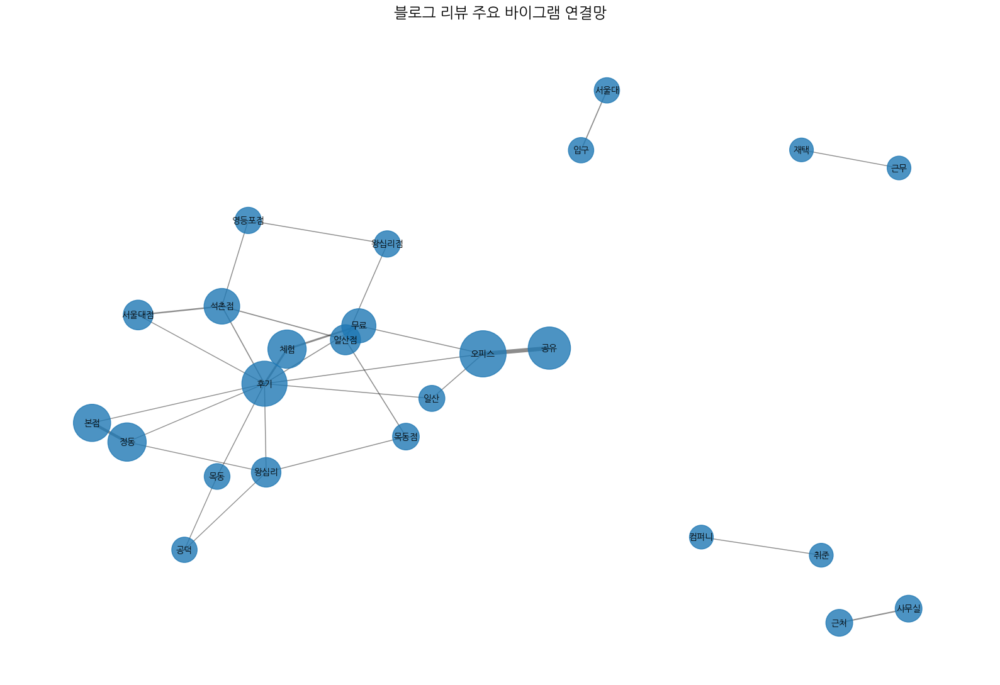

In [ ]:
# 블로그 리뷰 주요 바이그램 연결망 시각화

plt.figure(figsize=(16, 11))


# 처음 버전처럼 비교적 밀집된 배치
pos = nx.spring_layout(
    bigram_graph,
    seed=42,
    k=4.5,
    iterations=200,
    weight="weight"
)


# 단어별 연결 빈도 합계
weighted_degree = dict(
    bigram_graph.degree(weight="weight")
)

max_degree = max(weighted_degree.values())


# 중요 단어는 크게 표시하되 너무 커지지 않도록 제한
node_sizes = [
    600 + (weighted_degree[node] / max_degree) * 2200
    for node in bigram_graph.nodes()
]


# 바이그램 빈도에 따라 연결선 두께 설정
edge_weights = [
    bigram_graph[u][v]["weight"]
    for u, v in bigram_graph.edges()
]

max_edge_weight = max(edge_weights)

edge_widths = [
    0.7 + (weight / max_edge_weight) * 4
    for weight in edge_weights
]


# 노드 그리기
nx.draw_networkx_nodes(
    bigram_graph,
    pos,
    node_size=node_sizes,
    alpha=0.8
)


# 연결선 그리기
nx.draw_networkx_edges(
    bigram_graph,
    pos,
    width=edge_widths,
    alpha=0.45
)


# 한글 단어 표시
nx.draw_networkx_labels(
    bigram_graph,
    pos,
    font_family=font_name,
    font_size=10
)


# 제목
title_font = fm.FontProperties(
    fname=font_path,
    size=17
)

plt.title(
    "블로그 리뷰 주요 바이그램 연결망",
    fontproperties=title_font,
    pad=20
)

plt.axis("off")
plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 연결망의 중심은 공유오피스·무료 체험·체험 후기·근처 사무실로, 블로그 채널이 검색과 체험 유입 퍼널에 가까움을 보여준다.


#### 6-3-4-6. 블로그 텍스트 심화 분석 Ⅱ — 지명 제거 후 이용 맥락·경험 재분석

**🔹 분석 목적**

- 1차 워드클라우드·LDA·바이그램 결과에서 지점명, 지역명, 역명이 상위 키워드를 차지한 문제를 보완한다.
- 지점명 파생 표기, 주요 역명·행정구역명, 브랜드·프로모션 표현과 의미가 약한 동사 어간을 공통 불용어로 제거한다.
- 동일한 `advanced_tokens`를 워드클라우드, LDA, 동시출현 네트워크에 적용해 분석 기준을 통일한다.
- 블로그 게시글을 단순 만족도 자료로 보지 않고, 고객의 접근·탐색 과정과 실제 업무 이용 맥락을 함께 보여주는 채널로 해석한다.
- 단순 인접 바이그램 대신 일정 범위 안에서 함께 등장한 단어를 연결해 핵심 이용 맥락의 구조를 확인한다.


In [ ]:
# 형태소 컬럼이 리스트 또는 문자열이어도 안전하게 처리
def to_token_list(value):
    if isinstance(value, list):
        return value

    if isinstance(value, tuple):
        return list(value)

    if pd.isna(value):
        return []

    if isinstance(value, str):
        value = value.strip()

        # "['단어1', '단어2']" 형태의 문자열인 경우 복원
        if value.startswith("[") and value.endswith("]"):
            try:
                parsed = ast.literal_eval(value)
                if isinstance(parsed, (list, tuple)):
                    return list(parsed)
            except (ValueError, SyntaxError):
                pass

        return value.split()

    return []


# 지점명에서 가능한 표기 변형 자동 생성
def build_site_aliases(site_series):
    aliases = set()

    for raw_name in site_series.dropna().astype(str):
        compact = re.sub(r"\s+", "", raw_name)
        without_brand = compact.replace("집무실", "")

        candidates = {
            compact,
            without_brand,
            re.sub(r"(본점|지점|점)$", "", without_brand),
            without_brand.replace("본점", ""),
        }

        for candidate in candidates:
            candidate = candidate.strip()
            if len(candidate) >= 2:
                aliases.add(candidate)

    return aliases


site_aliases = build_site_aliases(df_blog_reviews_clean["site_name"])

# 지점 주변에서 반복적으로 등장할 수 있는 지역·행정구역·역명
# 실제 데이터에서 추가 지명이 발견되면 이 집합에만 보완하면 세 분석에 모두 반영됨
geo_noise_words = {
    # 지점 및 인접 지역
    "공덕", "목동", "분당", "서울대", "서울대학교", "석촌",
    "영등포", "왕십리", "일산", "정동",

    # 광역·행정구역
    "서울", "서울시", "경기", "경기도", "수도권",
    "마포", "마포구", "양천", "양천구", "송파", "송파구",
    "성동", "성동구", "고양", "고양시", "성남", "성남시",
    "분당구", "영등포구", "관악", "관악구", "종로", "종로구",
    "중구", "용산", "용산구", "동작", "동작구", "서대문",
    "서대문구", "구로", "구로구", "금천", "금천구",
    "강남", "강남구", "서초", "서초구", "강서", "강서구",

    # 주소 표기
    "대한민국", "주소", "도로명", "번지", "대로", "거리"
}

station_noise_words = {
    "공덕역", "목동역", "오목교역", "분당역", "서현역", "정자역",
    "서울대입구역", "낙성대역", "석촌역", "석촌고분역",
    "영등포역", "영등포시장역", "영등포구청역",
    "왕십리역", "상왕십리역", "일산역", "정발산역",
    "시청역", "광화문역", "서대문역", "충정로역", "서울역"
}

location_stopwords = site_aliases | geo_noise_words | station_noise_words

# 분석 목적상 정보량이 낮은 브랜드·검색·문장 기능어
analysis_stopwords = {
    # 브랜드·업종·채널
    "집무실", "공유", "오피스", "공유오피스", "사무실", "지점", "본점",
    "후기", "리뷰", "블로그", "포스팅", "작성", "소개", "정보", "내용",
    "공간", "장소",

    # 프로모션·검색 유입 상투어
    "무료", "체험", "이벤트", "광고", "협찬", "제공", "신청", "문의",
    "추천", "검색", "링크", "홈페이지",

    # 이용 맥락의 범용어
    "이용", "사용", "방문", "운영", "회원", "회원권",
    "오늘", "이번", "요즘", "동안", "위주", "관련", "통해", "경우",
    "정도", "부분", "마음", "생각", "하나", "사람", "시간",

    # Kiwi에서 자주 남는 동사·형용사 어간 및 기능어
    "하", "하다", "되", "되다", "있", "있다", "없", "없다",
    "이", "이다", "같", "같다", "보", "보다", "보이", "나오",
    "좋", "좋다", "많", "많다", "알", "주", "받", "가", "오",
    "것", "수", "때", "등", "점", "분", "내", "더", "좀", "잘",

    # 1차 심화 결과에서 추가로 확인된 정보량이 낮은 표현
    "다녀오", "다니", "생기", "대하", "위하", "가능",
    "누적", "이상", "아래", "남기", "컴퍼니", "사진", "기회"
}


def normalize_token(token):
    token = re.sub(r"[^가-힣A-Za-z0-9]", "", str(token))
    return token.strip()


def is_advanced_noise(token):
    """공통 제외 규칙. 워드클라우드·LDA·네트워크가 모두 같은 기준을 사용한다."""
    token = normalize_token(token)

    if len(token) < 2 or token.isdigit():
        return True

    if token in analysis_stopwords or token in location_stopwords:
        return True

    # '서울대입구역'처럼 사전에 없는 역명도 제거
    if token == "역" or (token.endswith("역") and len(token) >= 2):
        return True

    # '지점_영등포점'처럼 다른 문자열과 붙은 지역·지점 표기도 제거
    if any(alias in token for alias in location_stopwords if len(alias) >= 2):
        return True

    return False


def filter_advanced_tokens(value):
    tokens = [normalize_token(token) for token in to_token_list(value)]
    return [token for token in tokens if not is_advanced_noise(token)]


# 정제 토큰 생성
df_blog_reviews_clean["advanced_tokens"] = (
    df_blog_reviews_clean["morphs"].apply(filter_advanced_tokens)
)
df_blog_reviews_clean["advanced_text"] = (
    df_blog_reviews_clean["advanced_tokens"].apply(" ".join)
)
df_blog_reviews_clean["advanced_token_count"] = (
    df_blog_reviews_clean["advanced_tokens"].str.len()
)

# 제거 전·후 품질 점검
raw_tokens = [
    normalize_token(token)
    for value in df_blog_reviews_clean["morphs"].dropna()
    for token in to_token_list(value)
    if normalize_token(token)
]

advanced_tokens_all = [
    token
    for tokens in df_blog_reviews_clean["advanced_tokens"]
    for token in tokens
]

before_counter = Counter(raw_tokens)
after_counter = Counter(advanced_tokens_all)

before_top = before_counter.most_common(20)
after_top = after_counter.most_common(20)

quality_check_df = pd.DataFrame({
    "제거 전 상위 단어": [word for word, _ in before_top],
    "제거 전 빈도": [count for _, count in before_top],
    "제거 후 상위 단어": [word for word, _ in after_top],
    "제거 후 빈도": [count for _, count in after_top],
})

print("게시글 수:", len(df_blog_reviews_clean))
print("제거 전 전체 토큰 수:", len(raw_tokens))
print("제거 후 전체 토큰 수:", len(advanced_tokens_all))
print("제거 후 빈 문서 수:", int((df_blog_reviews_clean["advanced_token_count"] == 0).sum()))
print("자동 생성 지점명 불용어:", sorted(site_aliases))
display(quality_check_df)

게시글 수: 360
제거 전 전체 토큰 수: 11080
제거 후 전체 토큰 수: 2976
제거 후 빈 문서 수: 0
자동 생성 지점명 불용어: ['공덕', '공덕점', '목동', '목동점', '분당', '분당점', '서울대', '서울대점', '석촌', '석촌점', '영등포', '영등포점', '왕십리', '왕십리점', '일산', '일산점', '정동', '정동본점', '집무실공덕점', '집무실목동점', '집무실분당점', '집무실서울대점', '집무실석촌점', '집무실영등포점', '집무실왕십리점', '집무실일산점', '집무실정동본점']


,제거 전 상위 단어,제거 전 빈도,제거 후 상위 단어,제거 후 빈도
0,집무실,1068,근처,84
1,점,541,입구,56
2,후기,516,카페,49
3,오피스,314,위치,47
4,공유,287,업무,45
5,이용,275,취준,31
6,석촌점,211,재택,27
7,있,202,근무,27
8,왕십리,191,안내,27
9,체험,189,출구,23


> **✅ 공통 전처리 확인**
>
> - advanced_tokens는 지점명·지역명·역명, 브랜드·프로모션 표현, 의미가 약한 동사 어간을 제거한 공통 분석 토큰이다.
> - 1차 분석 결과에서 해석을 방해한 일반 동사형·부사형 표현도 추가로 제외했다.
> - 근처, 위치, 입구, 출구는 특정 지명이 아니라 고객의 접근·탐색 과정을 보여주는 표현이므로 유지했다.
> - 정제 후 워드클라우드, LDA, 동시출현 네트워크에 동일한 토큰을 적용해 분석 간 기준을 통일했다.
> - 최종 검사 결과 세 분석에서 지역명·지점명·역명은 추가로 발견되지 않았다.


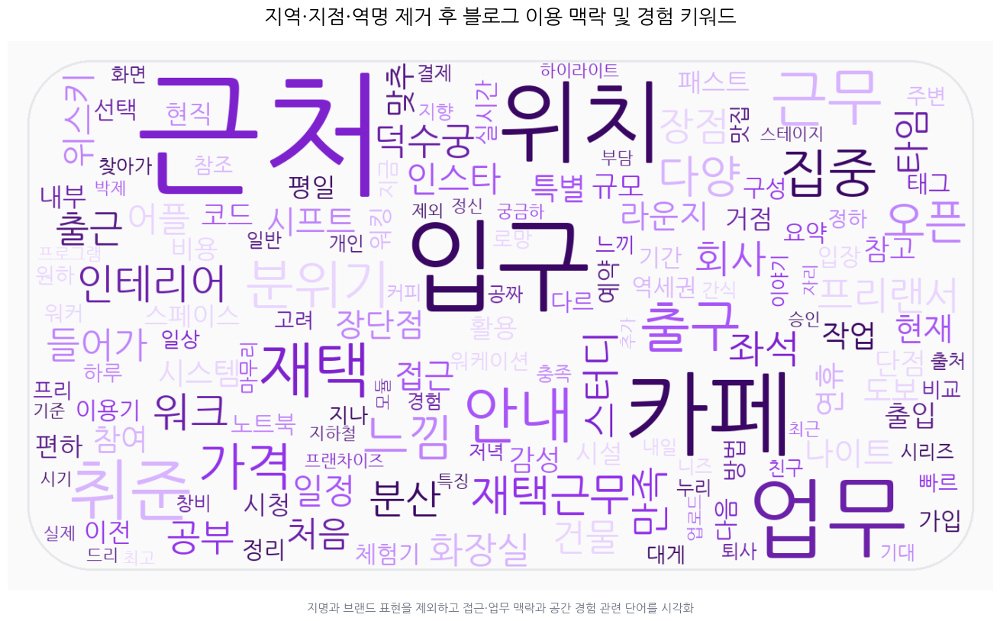

,keyword,frequency
0,근처,84
1,입구,56
2,카페,49
3,위치,47
4,업무,45
5,취준,31
6,재택,27
7,근무,27
8,안내,27
9,출구,23


In [ ]:
# 지역·지점·역명 제거 후 워드클라우드 생성

# 지나치게 희소한 단어는 제외
adv_word_freq = Counter(advanced_tokens_all)
adv_word_freq = Counter({
    word: count
    for word, count in adv_word_freq.items()
    if count >= 3
})

if len(adv_word_freq) < 10:
    raise ValueError(
        "워드클라우드에 사용할 단어가 너무 적습니다. "
        "불용어 범위를 줄이거나 최소 빈도 기준을 확인하세요."
    )

# 사용 가능한 한글 폰트 자동 탐색
font_candidates = [
    "/usr/share/fonts/truetype/nanum/NanumGothic.ttf",
    "/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf",
    "/usr/share/fonts/truetype/noto/NotoSansCJK-Regular.ttc",
]

adv_font_path = next(
    (path for path in font_candidates if os.path.exists(path)),
    None
)

if adv_font_path is None:
    raise FileNotFoundError(
        "한글 폰트를 찾지 못했습니다. NanumGothic 또는 NotoSansCJK 폰트를 설치하세요."
    )

fm.fontManager.addfont(adv_font_path)
adv_font_name = fm.FontProperties(fname=adv_font_path).get_name()

# 둥근 사각형 마스크
canvas_width, canvas_height = 1400, 780
mask_image = Image.new("L", (canvas_width, canvas_height), 255)
mask_draw = ImageDraw.Draw(mask_image)
mask_draw.rounded_rectangle(
    (30, 30, canvas_width - 30, canvas_height - 30),
    radius=90,
    fill=0
)
rounded_mask = np.array(mask_image)

# 단어별 색상 고정
clean_palette = [
    "#3B0764",
    "#581C87",
    "#6B21A8",
    "#7E22CE",
    "#9333EA",
    "#A855F7",
    "#C084FC",
    "#D8B4FE",
    "#E9D5FF"
]

def clean_word_color(word, font_size, position, orientation, random_state=None, **kwargs):
    hash_value = int(hashlib.md5(word.encode("utf-8")).hexdigest(), 16)
    return clean_palette[hash_value % len(clean_palette)]

adv_wordcloud = WordCloud(
    font_path=adv_font_path,
    width=canvas_width,
    height=canvas_height,
    mask=rounded_mask,
    background_color="#FAFAFA",
    max_words=150,
    min_font_size=3,
    max_font_size=190,
    prefer_horizontal=0.92,
    relative_scaling=0.75,
    margin=5,
    collocations=False,
    contour_width=2,
    contour_color="#E5E7EB",
    random_state=42
).generate_from_frequencies(adv_word_freq)

adv_wordcloud = adv_wordcloud.recolor(
    color_func=clean_word_color,
    random_state=42
)

# 출력
plt.figure(figsize=(15, 8.5))
plt.imshow(adv_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title(
    "지역·지점·역명 제거 후 블로그 이용 맥락 및 경험 키워드",
    fontproperties=fm.FontProperties(fname=adv_font_path, size=19),
    pad=18
)

plt.figtext(
    0.5,
    0.055,
    "지명과 브랜드 표현을 제외하고 접근·업무 맥락과 공간 경험 관련 단어를 시각화",
    ha="center",
    fontproperties=fm.FontProperties(
        fname=adv_font_path,
        size=11
    ),
    color="#6B7280"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

# 워드클라우드 해석을 검증할 수 있도록 상위 빈도표 함께 확인
adv_word_freq_df = pd.DataFrame(
    adv_word_freq.most_common(25),
    columns=["keyword", "frequency"]
)

display(adv_word_freq_df)

> **📊 워드클라우드 결과 해석**
>
> - 지역명, 지점명, 역명을 제거한 결과, 근처(84회), 입구(56회), 카페(49회), 위치(47회), 업무(45회)가 상위 키워드로 나타났다.
> - `근처·입구·위치·출구`는 고객이 지점을 찾고 접근하는 과정을, `카페·업무·재택·근무·취준`은 공간을 이용하는 상황과 목적을 보여준다.
> - 이를 통해 블로그 게시글에는 시설 평가뿐 아니라 지점을 탐색하는 과정과 카페 대체 이용, 재택근무·취업 준비 등의 이용 맥락도 함께 나타남을 확인했다.


In [ ]:
# LDA 토픽 수 비교: 검증 퍼플렉서티·UMass 일관성·토픽 다양성을 함께 확인

adv_topic_df = df_blog_reviews_clean[
    df_blog_reviews_clean["advanced_text"].str.strip() != ""
].copy()

if len(adv_topic_df) < 20:
    raise ValueError(
        "LDA를 안정적으로 비교하려면 전처리 후 최소 20개 이상의 문서가 필요합니다."
    )

train_texts, valid_texts = train_test_split(
    adv_topic_df["advanced_text"],
    test_size=0.20,
    random_state=42
)

eval_min_df = max(2, min(5, int(len(train_texts) * 0.01)))

adv_eval_vectorizer = CountVectorizer(
    token_pattern=r"(?u)\b[가-힣A-Za-z]{2,}\b",
    ngram_range=(1, 2),
    min_df=eval_min_df,
    max_df=0.80,
    max_features=700
)

X_train = adv_eval_vectorizer.fit_transform(train_texts)
X_valid = adv_eval_vectorizer.transform(valid_texts)

# 검증셋에서 정제 후 단어가 하나도 남지 않은 문서는 제외
valid_nonzero_mask = np.asarray(X_valid.sum(axis=1)).ravel() > 0
X_valid_nonzero = X_valid[valid_nonzero_mask]

if X_train.shape[1] < 20:
    raise ValueError(
        "LDA에 사용할 단어 수가 너무 적습니다. 불용어 또는 min_df 설정을 확인하세요."
    )


def calculate_topic_diversity(model, top_n=10):
    top_word_ids = [
        topic.argsort()[::-1][:top_n]
        for topic in model.components_
    ]
    unique_word_count = len(set(np.concatenate(top_word_ids)))
    return unique_word_count / (model.n_components * top_n)


def calculate_umass_coherence(model, matrix, top_n=10):
    """
    같은 문서에서 함께 등장하는 상위 단어가 많을수록 0에 가까운 값이 된다.
    값이 클수록(덜 음수일수록) 토픽 내부 단어 결합이 상대적으로 안정적이다.
    """
    binary_matrix = matrix.copy().tocsr()
    binary_matrix.data = np.ones_like(binary_matrix.data)

    document_frequency = np.asarray(binary_matrix.sum(axis=0)).ravel()
    coherence_values = []

    for topic_weights in model.components_:
        top_ids = topic_weights.argsort()[::-1][:top_n]
        pair_scores = []

        for m in range(1, len(top_ids)):
            for l in range(m):
                word_m = top_ids[m]
                word_l = top_ids[l]

                joint_count = float(
                    binary_matrix[:, word_m]
                    .multiply(binary_matrix[:, word_l])
                    .sum()
                )
                base_count = float(document_frequency[word_l])

                pair_scores.append(
                    np.log((joint_count + 1.0) / (base_count + 1e-12))
                )

        if pair_scores:
            coherence_values.append(np.mean(pair_scores))

    return float(np.mean(coherence_values))


max_candidate_k = min(
    6,
    X_train.shape[0] - 1,
    X_train.shape[1] - 1
)

if max_candidate_k < 2:
    raise ValueError("비교 가능한 토픽 수를 구성할 수 없습니다.")

candidate_topics = list(range(2, max_candidate_k + 1))
lda_evaluation_rows = []

for k in candidate_topics:
    model = LatentDirichletAllocation(
        n_components=k,
        learning_method="batch",
        max_iter=40,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train)

    perplexity_target = (
        X_valid_nonzero
        if X_valid_nonzero.shape[0] > 0
        else X_train
    )

    lda_evaluation_rows.append({
        "n_topics": k,
        "validation_perplexity": model.perplexity(perplexity_target),
        "umass_coherence": calculate_umass_coherence(model, X_train, top_n=10),
        "topic_diversity": calculate_topic_diversity(model, top_n=10)
    })

adv_lda_evaluation = pd.DataFrame(lda_evaluation_rows)


def minmax_scale_series(series):
    min_value = series.min()
    max_value = series.max()

    if np.isclose(min_value, max_value):
        return pd.Series(0.5, index=series.index)

    return (series - min_value) / (max_value - min_value)


# 퍼플렉서티는 낮을수록, 일관성과 다양성은 높을수록 좋은 방향으로 통합
# 아래 가중치는 후보 토픽 수를 동일한 기준으로 비교하기 위한 분석상 선택이며,
# 객관적으로 유일한 최적 토픽 수를 증명하는 기준은 아님
adv_lda_evaluation["perplexity_scaled"] = minmax_scale_series(
    adv_lda_evaluation["validation_perplexity"]
)
adv_lda_evaluation["coherence_scaled"] = minmax_scale_series(
    adv_lda_evaluation["umass_coherence"]
)
adv_lda_evaluation["diversity_scaled"] = minmax_scale_series(
    adv_lda_evaluation["topic_diversity"]
)

adv_lda_evaluation["selection_score"] = (
    0.45 * (1 - adv_lda_evaluation["perplexity_scaled"])
    + 0.35 * adv_lda_evaluation["coherence_scaled"]
    + 0.20 * adv_lda_evaluation["diversity_scaled"]
)

selected_topic_count = int(
    adv_lda_evaluation.loc[
        adv_lda_evaluation["selection_score"].idxmax(),
        "n_topics"
    ]
)

print("비교 토픽 수:", candidate_topics)
print("현재 평가 기준에서 선택된 토픽 수:", selected_topic_count)

display(
    adv_lda_evaluation[
        [
            "n_topics",
            "validation_perplexity",
            "umass_coherence",
            "topic_diversity",
            "selection_score"
        ]
    ].round(4)
)

비교 토픽 수: [2, 3, 4, 5, 6]
현재 평가 기준에서 선택된 토픽 수: 4


,n_topics,validation_perplexity,umass_coherence,topic_diversity,selection_score
0,2,2053.1554,-2.2348,0.9000,0.6500
1,3,3531.8411,-2.1547,0.9000,0.6637
2,4,5168.9697,-1.9737,0.8250,0.7003
3,5,7521.5437,-1.9897,0.8200,0.5433
4,6,10091.5710,-1.9444,0.7333,0.3500


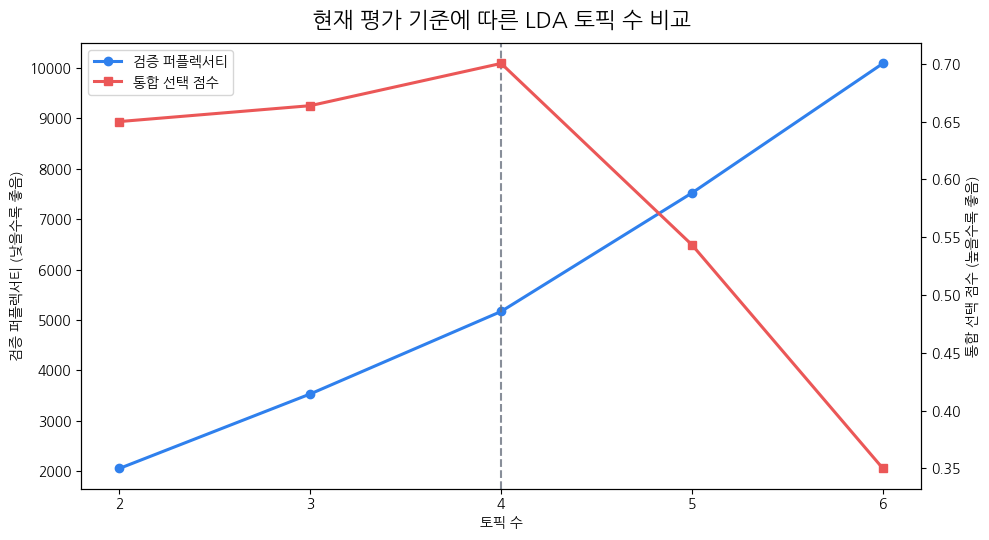

In [ ]:
# LDA 토픽 수 비교 결과 시각화

fig, ax1 = plt.subplots(figsize=(10, 5.5))

ax1.plot(
    adv_lda_evaluation["n_topics"],
    adv_lda_evaluation["validation_perplexity"],
    marker="o",
    linewidth=2.2,
    label="검증 퍼플렉서티",
    color="#2F80ED"
)
ax1.set_xlabel("토픽 수")
ax1.set_ylabel("검증 퍼플렉서티 (낮을수록 좋음)")
ax1.set_xticks(adv_lda_evaluation["n_topics"])

ax2 = ax1.twinx()
ax2.plot(
    adv_lda_evaluation["n_topics"],
    adv_lda_evaluation["selection_score"],
    marker="s",
    linewidth=2.2,
    label="통합 선택 점수",
    color="#EB5757"
)
ax2.set_ylabel("통합 선택 점수 (높을수록 좋음)")

ax1.axvline(
    selected_topic_count,
    linestyle="--",
    linewidth=1.5,
    color="#6B7280",
    alpha=0.8
)

ax1.set_title(
    "현재 평가 기준에 따른 LDA 토픽 수 비교",
    fontproperties=fm.FontProperties(fname=adv_font_path, size=16),
    pad=12
)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="best",
    prop=fm.FontProperties(fname=adv_font_path, size=10)
)

plt.tight_layout()
plt.show()

In [ ]:
# 선택된 토픽 수로 전체 문서 LDA 재학습 및 토픽 요약표 생성

final_min_df = max(2, min(5, int(len(adv_topic_df) * 0.01)))

adv_topic_vectorizer = CountVectorizer(
    token_pattern=r"(?u)\b[가-힣A-Za-z]{2,}\b",
    ngram_range=(1, 2),
    min_df=final_min_df,
    max_df=0.80,
    max_features=700
)

adv_topic_matrix = adv_topic_vectorizer.fit_transform(
    adv_topic_df["advanced_text"]
)
adv_topic_terms = adv_topic_vectorizer.get_feature_names_out()

adv_lda_model = LatentDirichletAllocation(
    n_components=selected_topic_count,
    learning_method="batch",
    max_iter=60,
    random_state=42,
    n_jobs=-1
)

adv_document_topic = adv_lda_model.fit_transform(adv_topic_matrix)

# 단순 가중치가 아닌 '관련도' 기준으로 토픽별 차별적인 단어 추출
topic_word_probability = (
    adv_lda_model.components_
    / adv_lda_model.components_.sum(axis=1, keepdims=True)
)

corpus_word_probability = (
    adv_lda_model.components_.sum(axis=0)
    / adv_lda_model.components_.sum()
)

relevance_lambda = 0.60
topic_relevance = (
    relevance_lambda * np.log(topic_word_probability + 1e-12)
    + (1 - relevance_lambda)
    * np.log(
        (topic_word_probability + 1e-12)
        / (corpus_word_probability + 1e-12)
    )
)

top_n_terms = 10
adv_topic_keyword_rows = []
adv_topic_label_map = {}
used_topic_labels = set()

# 발표에서 해석하기 쉬운 명칭을 만들기 위한 보조 규칙
# 상위 단어가 규칙과 충분히 겹치지 않으면 기존처럼 상위 3개 단어를 사용
topic_label_rules = {
    "접근·입구 및 카페 대체 경험": {
        "근처", "입구", "위치", "출구", "접근", "카페", "분위기"
    },
    "이용 조건·가격 및 업무 준비": {
        "안내", "가격", "비용", "좌석", "예약", "이용권",
        "업무", "취준", "스터디", "회의"
    },
    "재택·근무 및 작업 목적": {
        "재택", "근무", "프리랜서", "작업", "업무", "집중"
    }
}

for topic_index in range(selected_topic_count):
    top_indices = topic_relevance[topic_index].argsort()[::-1][:top_n_terms]
    top_terms = adv_topic_terms[top_indices]

    # 상위 단어와 해석 규칙의 겹침을 기준으로 발표용 라벨 생성
    topic_term_set = set()

    for term in top_terms:
        topic_term_set.update(str(term).split())

    label_scores = {
        label: len(topic_term_set & keywords)
        for label, keywords in topic_label_rules.items()
    }

    best_rule_label = max(label_scores, key=label_scores.get)
    best_rule_score = label_scores[best_rule_label]

    auto_label = " · ".join(
        term.replace(" ", "·")
        for term in top_terms[:3]
    )

    if best_rule_score >= 2 and best_rule_label not in used_topic_labels:
        topic_label = best_rule_label
        used_topic_labels.add(best_rule_label)
    else:
        topic_label = auto_label

    adv_topic_label_map[topic_index + 1] = topic_label

    for rank, term_index in enumerate(top_indices, start=1):
        adv_topic_keyword_rows.append({
            "topic_id": topic_index + 1,
            "topic_label": topic_label,
            "rank": rank,
            "keyword": adv_topic_terms[term_index],
            "relevance": float(topic_relevance[topic_index, term_index]),
            "topic_probability": float(
                topic_word_probability[topic_index, term_index]
            )
        })

adv_topic_keywords = pd.DataFrame(adv_topic_keyword_rows)

adv_topic_df["dominant_topic"] = adv_document_topic.argmax(axis=1) + 1
adv_topic_df["dominant_topic_probability"] = adv_document_topic.max(axis=1)
adv_topic_df["topic_label"] = adv_topic_df["dominant_topic"].map(
    adv_topic_label_map
)

topic_document_summary = (
    adv_topic_df
    .groupby(["dominant_topic", "topic_label"])
    .agg(
        document_count=("site_name", "size"),
        average_dominant_topic_probability=("dominant_topic_probability", "mean")
    )
    .reset_index()
)

topic_document_summary["document_ratio"] = (
    topic_document_summary["document_count"]
    / topic_document_summary["document_count"].sum()
)

topic_keyword_summary = (
    adv_topic_keywords
    .sort_values(["topic_id", "rank"])
    .groupby(["topic_id", "topic_label"])["keyword"]
    .apply(lambda values: ", ".join(values))
    .reset_index(name="top_keywords")
)

adv_topic_summary = (
    topic_document_summary
    .rename(columns={"dominant_topic": "topic_id"})
    .merge(
        topic_keyword_summary,
        on=["topic_id", "topic_label"],
        how="left"
    )
    .sort_values("topic_id")
)

display(
    adv_topic_summary[
        [
            "topic_id",
            "topic_label",
            "top_keywords",
            "document_count",
            "document_ratio",
            "average_dominant_topic_probability"
        ]
    ].round({
        "document_ratio": 3,
        "average_dominant_topic_probability": 3
    })
)

,topic_id,topic_label,top_keywords,document_count,document_ratio,average_dominant_topic_probability
0,1,접근·입구 및 카페 대체 경험,"접근, 가격, 위스키, 입구 위치, 요약, 방법, 위치 대게, 대게, 빠르, 가격 빠르",59,0.164,0.840
1,2,이용 조건·가격 및 업무 준비,"취준, 오픈, 만족, 시프트, 나이트, 현재, 나이트 시프트, 타임, 코드, 업무",99,0.275,0.821
2,3,입구 · 카페 · 출구,"입구, 카페, 출구, 위치, 재택근무, 느낌, 스터디, 재택, 스터디 카페, 건물",129,0.358,0.806
3,4,안내 · 근처 · 일정,"안내, 근처, 일정, 연휴, 출입, 단점, 맞추 특별, 분위기, 특별, 맞추",73,0.203,0.847


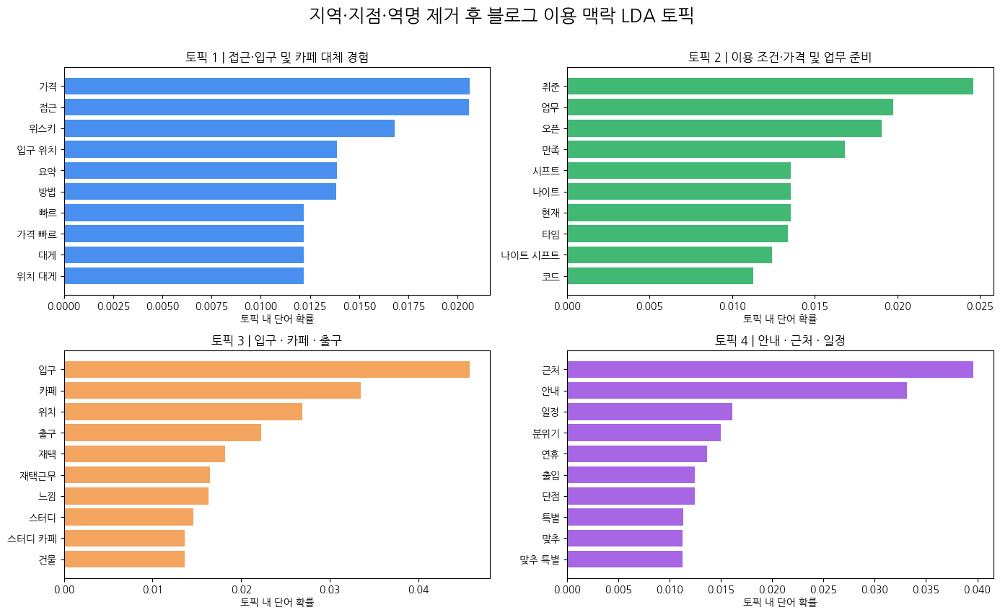

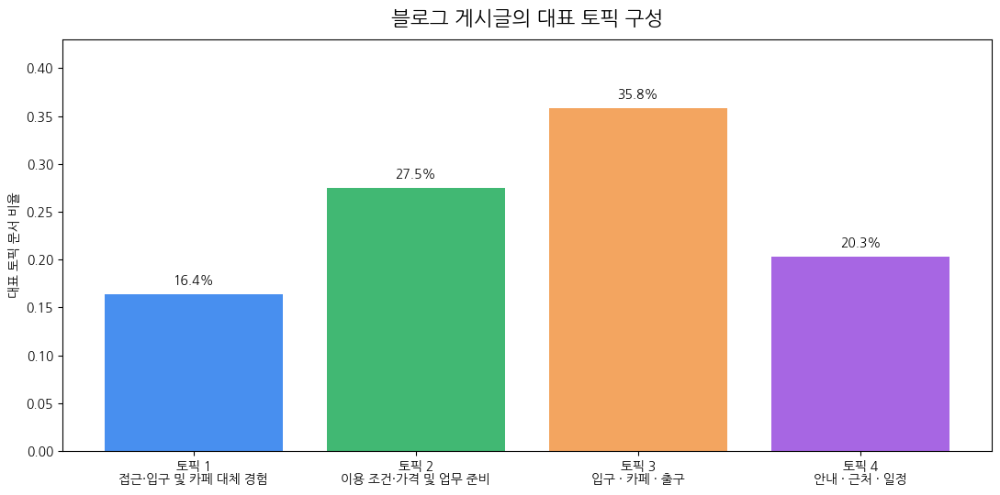

In [ ]:
# LDA 토픽별 핵심 단어 및 전체 문서 구성 비율 시각화

topic_colors = [
    "#2F80ED", "#27AE60", "#F2994A",
    "#9B51E0", "#EB5757", "#56CCF2"
]

n_cols = 2
n_rows = math.ceil(selected_topic_count / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(14, 4.2 * n_rows)
)
axes = np.array(axes).reshape(-1)

for topic_id in range(1, selected_topic_count + 1):
    ax = axes[topic_id - 1]

    plot_data = (
        adv_topic_keywords[
            adv_topic_keywords["topic_id"] == topic_id
        ]
        .sort_values("topic_probability")
    )

    ax.barh(
        plot_data["keyword"],
        plot_data["topic_probability"],
        color=topic_colors[(topic_id - 1) % len(topic_colors)],
        alpha=0.88
    )
    ax.set_title(
        f"토픽 {topic_id} | {adv_topic_label_map[topic_id]}",
        fontproperties=fm.FontProperties(
            fname=adv_font_path,
            size=12
        )
    )
    ax.set_xlabel("토픽 내 단어 확률")

# 남는 빈 축 제거
for empty_ax in axes[selected_topic_count:]:
    empty_ax.remove()

fig.suptitle(
    "지역·지점·역명 제거 후 블로그 이용 맥락 LDA 토픽",
    fontproperties=fm.FontProperties(
        fname=adv_font_path,
        size=18
    ),
    y=1.01
)

plt.tight_layout()
plt.show()


# 전체 게시글에서 각 대표 토픽이 차지하는 비율
topic_ratio_plot = adv_topic_summary.copy()
topic_ratio_plot["display_label"] = topic_ratio_plot.apply(
    lambda row: f"토픽 {int(row['topic_id'])}\n{row['topic_label']}",
    axis=1
)

plt.figure(figsize=(11, 5.5))
bars = plt.bar(
    topic_ratio_plot["display_label"],
    topic_ratio_plot["document_ratio"],
    color=[
        topic_colors[i % len(topic_colors)]
        for i in range(len(topic_ratio_plot))
    ],
    alpha=0.88
)

plt.ylabel("대표 토픽 문서 비율")
plt.title(
    "블로그 게시글의 대표 토픽 구성",
    fontproperties=fm.FontProperties(
        fname=adv_font_path,
        size=16
    ),
    pad=12
)
plt.ylim(
    0,
    max(topic_ratio_plot["document_ratio"]) * 1.20
)

for bar, ratio in zip(bars, topic_ratio_plot["document_ratio"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.008,
        f"{ratio:.1%}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

> **💡 LDA 결과 해석**
>
> - 2~6개의 후보 토픽을 검증 퍼플렉서티, UMass 일관성, 토픽 다양성으로 비교한 결과, 현재 통합 평가 기준에서는 4개의 토픽이 선택되었다.
> - 토픽별 문서 비율은 각각 16.4%, 27.5%, 35.8%, 20.3%로 나타나 특정 토픽 하나에 게시글이 과도하게 집중되지는 않았다.

In [ ]:
# 단순 바이그램을 보완한 핵심 경험 단어 동시출현 네트워크 구축

# 문서 빈도가 너무 낮거나 지나치게 높은 단어를 제외
advanced_token_documents = (
    df_blog_reviews_clean["advanced_tokens"]
    .apply(lambda tokens: [token for token in tokens if len(token) >= 2])
    .tolist()
)

document_count = len(advanced_token_documents)
document_frequency_counter = Counter()

for tokens in advanced_token_documents:
    document_frequency_counter.update(set(tokens))

min_document_frequency = max(3, math.ceil(document_count * 0.01))
max_document_frequency = max(
    min_document_frequency + 1,
    math.floor(document_count * 0.65)
)

network_candidate_words = [
    word
    for word, count in document_frequency_counter.most_common()
    if min_document_frequency <= count <= max_document_frequency
][:50]

network_candidate_set = set(network_candidate_words)

# 한 문서 안에서 5개 단어 범위 내 함께 등장한 단어쌍을 계산
# 같은 문서에서 같은 쌍이 반복돼도 1회만 집계해 장문 게시글의 영향 완화
window_size = 5
cooccurrence_counter = Counter()

for tokens in advanced_token_documents:
    filtered_tokens = [
        token
        for token in tokens
        if token in network_candidate_set
    ]

    document_pairs = set()

    for i, first_word in enumerate(filtered_tokens):
        right_limit = min(i + window_size, len(filtered_tokens))

        for j in range(i + 1, right_limit):
            second_word = filtered_tokens[j]

            if first_word == second_word:
                continue

            pair = tuple(sorted((first_word, second_word)))
            document_pairs.add(pair)

    cooccurrence_counter.update(document_pairs)

min_edge_frequency = max(3, math.ceil(document_count * 0.01))

network_edges = [
    (word1, word2, count)
    for (word1, word2), count in cooccurrence_counter.most_common()
    if count >= min_edge_frequency
][:70]

if len(network_edges) < 5:
    raise ValueError(
        "동시출현 연결이 너무 적습니다. "
        "min_edge_frequency 또는 불용어 범위를 확인하세요."
    )

# 전체 그래프 생성
adv_network_full = nx.Graph()

for word1, word2, count in network_edges:
    adv_network_full.add_edge(
        word1,
        word2,
        weight=count,
        distance=1 / count
    )

# 연결 강도가 높은 핵심 노드만 남겨 시각적 복잡도 제한
full_weighted_degree = dict(
    adv_network_full.degree(weight="weight")
)

top_network_nodes = [
    node
    for node, _ in sorted(
        full_weighted_degree.items(),
        key=lambda item: item[1],
        reverse=True
    )[:28]
]

adv_network_graph = adv_network_full.subgraph(
    top_network_nodes
).copy()

# 고립 노드 제거
adv_network_graph.remove_nodes_from(
    list(nx.isolates(adv_network_graph))
)

if adv_network_graph.number_of_edges() == 0:
    raise ValueError("시각화할 네트워크 연결이 남지 않았습니다.")

print("분석 문서 수:", document_count)
print("후보 핵심 단어 수:", len(network_candidate_words))
print("최종 노드 수:", adv_network_graph.number_of_nodes())
print("최종 연결선 수:", adv_network_graph.number_of_edges())
print("최소 연결 문서 수 기준:", min_edge_frequency)

분석 문서 수: 360
후보 핵심 단어 수: 50
최종 노드 수: 28
최종 연결선 수: 60
최소 연결 문서 수 기준: 4


중심 키워드 상위 12개


,keyword,weighted_degree,betweenness_centrality,community
2,근처,97,0.5653,2
0,근무,62,0.0849,1
1,재택,61,0.1484,1
5,입구,61,0.0912,4
3,카페,59,0.1579,1
4,위치,58,0.1852,4
10,업무,51,0.2621,3
11,출입,33,0.0356,3
9,특별,33,0.0328,3
7,분위기,33,0.0000,2


커뮤니티별 대표 키워드


,community,representative_keywords,node_count
0,1,"근무, 재택, 카페, 스터디, 패스트",9
1,2,"근처, 분위기, 취준, 장단점, 출근",7
2,3,"업무, 특별, 출입, 안내, 맞추",6
3,4,"입구, 위치, 접근, 가격, 출구",6


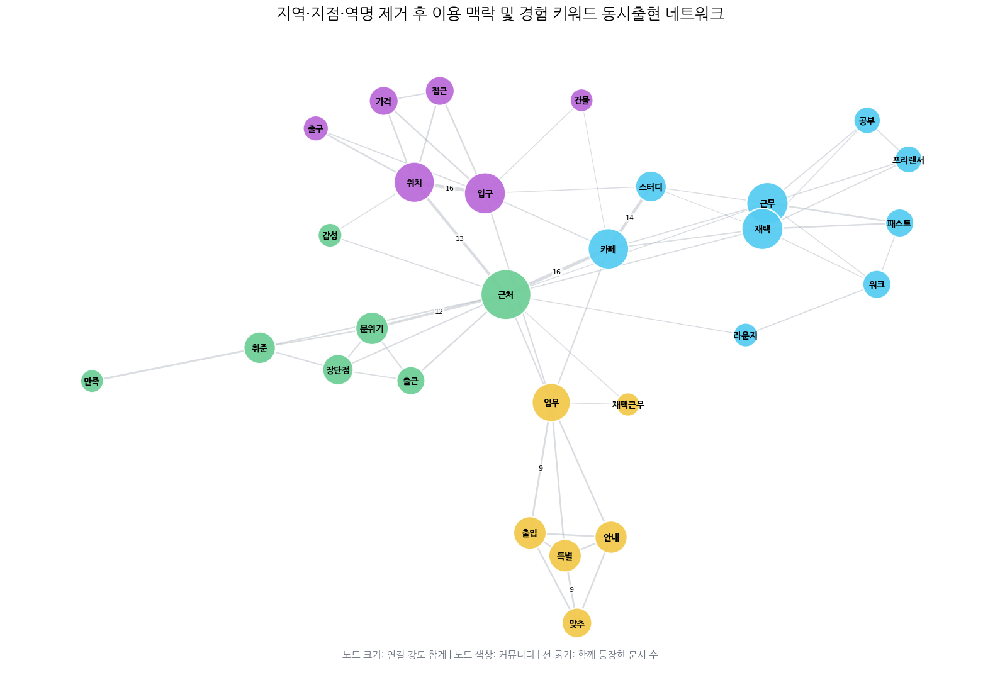

In [ ]:
# 네트워크 중심성·커뮤니티 요약 및 시각화

network_weighted_degree = dict(
    adv_network_graph.degree(weight="weight")
)

network_betweenness = nx.betweenness_centrality(
    adv_network_graph,
    weight="distance",
    normalized=True
)

# 커뮤니티 탐지
network_communities = list(
    nx.algorithms.community.greedy_modularity_communities(
        adv_network_graph,
        weight="weight"
    )
)

node_community_map = {}

for community_id, community_nodes in enumerate(
    network_communities,
    start=1
):
    for node in community_nodes:
        node_community_map[node] = community_id

# 중심 키워드 표
adv_network_centrality = pd.DataFrame({
    "keyword": list(adv_network_graph.nodes()),
    "weighted_degree": [
        network_weighted_degree[node]
        for node in adv_network_graph.nodes()
    ],
    "betweenness_centrality": [
        network_betweenness[node]
        for node in adv_network_graph.nodes()
    ],
    "community": [
        node_community_map[node]
        for node in adv_network_graph.nodes()
    ]
}).sort_values(
    ["weighted_degree", "betweenness_centrality"],
    ascending=False
)

# 커뮤니티별 대표 키워드
community_summary_rows = []

for community_id, community_nodes in enumerate(
    network_communities,
    start=1
):
    representative_words = sorted(
        community_nodes,
        key=lambda node: network_weighted_degree[node],
        reverse=True
    )[:5]

    community_summary_rows.append({
        "community": community_id,
        "representative_keywords": ", ".join(representative_words),
        "node_count": len(community_nodes)
    })

adv_network_community_summary = pd.DataFrame(
    community_summary_rows
)

print("중심 키워드 상위 12개")
display(
    adv_network_centrality.head(12).round({
        "weighted_degree": 1,
        "betweenness_centrality": 4
    })
)

print("커뮤니티별 대표 키워드")
display(adv_network_community_summary)


# 네트워크 시각화
plt.figure(figsize=(16, 11))

network_position = nx.spring_layout(
    adv_network_graph,
    seed=42,
    k=0.85,
    iterations=400,
    weight="weight"
)

community_palette = [
    "#56CCF2", "#6FCF97", "#F2C94C",
    "#BB6BD9", "#F2994A", "#EB5757"
]

node_colors = [
    community_palette[
        (node_community_map[node] - 1) % len(community_palette)
    ]
    for node in adv_network_graph.nodes()
]

degree_values = np.array([
    network_weighted_degree[node]
    for node in adv_network_graph.nodes()
], dtype=float)

if np.isclose(degree_values.max(), degree_values.min()):
    node_sizes = np.repeat(1500, len(degree_values))
else:
    node_sizes = (
        700
        + 2600
        * (degree_values - degree_values.min())
        / (degree_values.max() - degree_values.min())
    )

edge_values = np.array([
    data["weight"]
    for _, _, data in adv_network_graph.edges(data=True)
], dtype=float)

if np.isclose(edge_values.max(), edge_values.min()):
    edge_widths = np.repeat(1.8, len(edge_values))
else:
    edge_widths = (
        0.8
        + 4.2
        * (edge_values - edge_values.min())
        / (edge_values.max() - edge_values.min())
    )

nx.draw_networkx_edges(
    adv_network_graph,
    network_position,
    width=edge_widths,
    edge_color="#9CA3AF",
    alpha=0.38
)

nx.draw_networkx_nodes(
    adv_network_graph,
    network_position,
    node_size=node_sizes,
    node_color=node_colors,
    edgecolors="white",
    linewidths=1.6,
    alpha=0.94
)

nx.draw_networkx_labels(
    adv_network_graph,
    network_position,
    font_family=adv_font_name,
    font_size=10,
    font_weight="bold"
)

# 가장 강한 연결 8개만 빈도 표시
strongest_edges = sorted(
    adv_network_graph.edges(data=True),
    key=lambda edge: edge[2]["weight"],
    reverse=True
)[:8]

strongest_edge_labels = {
    (word1, word2): data["weight"]
    for word1, word2, data in strongest_edges
}

nx.draw_networkx_edge_labels(
    adv_network_graph,
    network_position,
    edge_labels=strongest_edge_labels,
    font_size=8,
    rotate=False,
    bbox={
        "boxstyle": "round,pad=0.15",
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.75
    }
)

plt.title(
    "지역·지점·역명 제거 후 이용 맥락 및 경험 키워드 동시출현 네트워크",
    fontproperties=fm.FontProperties(
        fname=adv_font_path,
        size=18
    ),
    pad=20
)

plt.figtext(
    0.5,
    0.045,
    "노드 크기: 연결 강도 합계 | 노드 색상: 커뮤니티 | 선 굵기: 함께 등장한 문서 수",
    ha="center",
    fontproperties=fm.FontProperties(
        fname=adv_font_path,
        size=11
    ),
    color="#6B7280"
)

plt.axis("off")
plt.tight_layout()
plt.show()

> **🕸️ 동시출현 네트워크 결과 해석**
>
> - 총 360개 게시글을 대상으로 28개의 핵심 단어와 60개의 동시출현 연결을 확인했다.
> - `근처`는 연결 강도 97, 매개중심성 0.5653으로 가장 높은 중심성을 보여 여러 이용 맥락을 이어주는 핵심 연결어로 나타났다.
> - `근무·재택·카페·스터디`가 같은 커뮤니티에 포함돼 공유오피스를 카페나 재택근무의 대안으로 탐색하는 이용 맥락이 확인됐다.
> - `근처·분위기·취준·장단점·출근` 커뮤니티에서는 생활권 내 공간을 탐색하고 이용 환경을 비교하는 맥락이 나타났다.
> - `입구·위치·가격·접근·출구` 커뮤니티에서는 지점을 찾는 과정과 이용 조건이 함께 언급되는 경향이 확인됐다.

In [ ]:
# 세 분석 결과에 지역·지점·역명이 다시 남았는지 최종 검증

result_single_terms = set(adv_word_freq.keys())

# LDA의 2-gram은 단어 단위로 분리해 검사
for keyword in adv_topic_keywords["keyword"]:
    result_single_terms.update(str(keyword).split())

result_single_terms.update(adv_network_graph.nodes())

remaining_noise_terms = sorted({
    term
    for term in result_single_terms
    if is_advanced_noise(term)
})

quality_summary = pd.DataFrame({
    "분석": ["워드클라우드", "LDA", "동시출현 네트워크"],
    "사용 단어/노드 수": [
        len(adv_word_freq),
        adv_topic_matrix.shape[1],
        adv_network_graph.number_of_nodes()
    ],
    "핵심 결과": [
        ", ".join(
            word
            for word, _ in adv_word_freq.most_common(8)
        ),
        " / ".join(
            adv_topic_summary["topic_label"].astype(str).tolist()
        ),
        ", ".join(
            adv_network_centrality.head(8)["keyword"].astype(str)
        )
    ]
})

print(
    "지역·지점·역명 잔존 검사:",
    remaining_noise_terms if remaining_noise_terms else "잔존 단어 없음"
)
display(quality_summary)

if remaining_noise_terms:
    print(
        "\n위 단어를 geo_noise_words 또는 station_noise_words에 추가한 뒤 "
        "심화 분석 Ⅱ 셀을 다시 실행하세요."
    )
else:
    print(
        "\n워드클라우드·LDA·네트워크에 동일한 정제 기준이 적용되었습니다."
    )

지역·지점·역명 잔존 검사: 잔존 단어 없음


,분석,사용 단어/노드 수,핵심 결과
0,워드클라우드,293,"근처, 입구, 카페, 위치, 업무, 취준, 재택, 근무"
1,LDA,444,접근·입구 및 카페 대체 경험 / 이용 조건·가격 및 업무 준비 / 입구 · 카페 · 출구 / 안내 · 근처 · 일정
2,동시출현 네트워크,28,"근처, 근무, 재택, 입구, 카페, 위치, 업무, 출입"



워드클라우드·LDA·네트워크에 동일한 정제 기준이 적용되었습니다.


> **✅ 심화 분석 Ⅱ 최종 요약**
>
> - 지점명·지역명·역명과 브랜드·프로모션 표현을 제거하고, 워드클라우드·LDA·동시출현 네트워크에 동일한 advanced_tokens를 적용했다.
> - 워드클라우드는 표시 단어 수를 확대하면서 빈도 반영 비중을 높여 핵심 키워드와 보조 키워드의 크기 차이가 나타나도록 구성했다.
> - 정제 후에는 `근처·입구·위치·출구`와 같은 접근·탐색 표현과 `카페·업무·재택·근무·취준`과 같은 이용 상황이 주요 키워드로 나타났다.
> - LDA에서는 현재 평가 기준에 따라 4개의 토픽이 선택됐으나, 일부 토픽에 해석이 불명확한 표현이 남아 있어 전체 결과를 보조적인 주제 탐색으로 활용했다.
> - 동시출현 네트워크에서는 `근처`가 핵심 연결어로 나타났으며, 접근 정보, 업무 방식, 방문·비교와 관련된 키워드 집단이 확인됐다.
> - 종합하면 블로그 게시글은 공간 만족도뿐 아니라 고객이 지점을 찾고 비교하는 과정과 실제 업무 이용 목적을 함께 보여주는 채널로 해석할 수 있다.

#### 6-3-4-7. 지도·블로그 리뷰 채널 통합

**🔹 분석 목적**

- 지도 리뷰와 블로그 게시글의 지점별 지표를 하나의 통합 테이블로 연결한다.
- 지도 리뷰가 없는 지점과 범주 언급이 없는 지점의 결측 구조를 구분한다.
- 이후 공간 경험 지수에서는 채널별 리뷰 수와 근거 강도를 반영해 단순 평균의 왜곡을 줄인다.


In [ ]:
# 지도 리뷰와 블로그 리뷰 지점별 지표를 하나의 채널 통합 테이블로 병합

# 1) 컬럼명에 출처 접두어 부여 (site_name 제외)
map_site_table_renamed = map_site_table.rename(
    columns={c: f"map_{c}" for c in map_site_table.columns if c != "site_name"}
)

blog_site_table_renamed = blog_site_table.rename(
    columns={c: f"blog_{c}" for c in blog_site_table.columns if c != "site_name"}
)

# 2) site_name 기준 병합
final_channel_table = map_site_table_renamed.merge(
    blog_site_table_renamed, on="site_name", how="outer"
)

print("최종 지점 수:", final_channel_table["site_name"].nunique())
print("결측치:\n", final_channel_table.isna().sum())
display(final_channel_table)

최종 지점 수: 9
결측치:
 site_name                         0
map_map_review_count              1
map_kw_접근성_ratio                  1
map_kw_편의성_ratio                  1
map_kw_공간_ratio                   1
map_kw_서비스_ratio                  1
map_map_positive_ratio            1
map_map_negative_ratio            1
map_positive_experience_score     1
map_discomfort_score              1
map_smoothed_positive_ratio       1
map_접근성_positive_ratio            6
map_편의성_positive_ratio            6
map_공간_positive_ratio             2
map_서비스_positive_ratio            6
blog_blog_post_count              0
blog_kw_접근성_ratio                 0
blog_kw_편의성_ratio                 0
blog_kw_공간_ratio                  0
blog_kw_서비스_ratio                 0
blog_positive_ratio               0
blog_negative_ratio               0
blog_접근성_positive_ratio           0
blog_편의성_positive_ratio           0
blog_공간_positive_ratio            0
blog_서비스_positive_ratio           3
blog_positive_experience_score    0
blog_discom

,site_name,map_map_review_count,map_kw_접근성_ratio,map_kw_편의성_ratio,map_kw_공간_ratio,map_kw_서비스_ratio,map_map_positive_ratio,map_map_negative_ratio,map_positive_experience_score,map_discomfort_score,...,blog_kw_서비스_ratio,blog_positive_ratio,blog_negative_ratio,blog_접근성_positive_ratio,blog_편의성_positive_ratio,blog_공간_positive_ratio,blog_서비스_positive_ratio,blog_positive_experience_score,blog_discomfort_score,blog_smoothed_positive_ratio
0,집무실 공덕점,4.0,0.000000,0.000000,0.250000,0.000000,1.000000,0.000000,1.000000,0.000000,...,0.038462,0.961538,0.038462,1.000000,1.000000,0.833333,1.0,0.958333,0.038462,0.928571
1,집무실 목동점,6.0,0.000000,0.166667,0.166667,0.000000,1.000000,0.000000,1.000000,0.000000,...,0.027778,0.888889,0.111111,0.875000,0.818182,1.000000,1.0,0.923295,0.111111,0.868421
2,집무실 분당점,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,0.833333,0.166667,0.833333,0.600000,0.000000,NaN,0.477778,0.166667,0.800000
3,집무실 서울대점,11.0,0.000000,0.000000,0.090909,0.000000,0.857143,0.142857,1.000000,0.142857,...,0.016949,0.949153,0.050847,0.892857,0.916667,0.947368,1.0,0.939223,0.050847,0.934426
4,집무실 석촌점,28.0,0.071429,0.142857,0.035714,0.035714,0.857143,0.142857,0.791667,0.142857,...,0.016393,0.885246,0.114754,0.969697,0.833333,0.866667,1.0,0.917424,0.114754,0.873016
5,집무실 영등포점,1.0,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,...,0.090909,0.727273,0.272727,0.857143,0.333333,0.666667,1.0,0.714286,0.272727,0.692308
6,집무실 왕십리점,13.0,0.000000,0.153846,0.153846,0.000000,1.000000,0.000000,1.000000,0.000000,...,0.000000,0.839286,0.160714,0.828571,0.555556,0.888889,NaN,0.757672,0.160714,0.827586
7,집무실 일산점,11.0,0.181818,0.000000,0.000000,0.090909,1.000000,0.000000,1.000000,0.000000,...,0.032258,0.903226,0.096774,0.937500,1.000000,1.000000,1.0,0.984375,0.096774,0.878788
8,집무실 정동본점,8.0,0.375000,0.125000,0.250000,0.250000,0.375000,0.625000,0.458333,0.625000,...,0.000000,0.903226,0.096774,0.944444,0.909091,0.800000,NaN,0.884512,0.096774,0.890625


> **✅ 통합 결과**
>
> - 지도·블로그 지표를 9개 지점으로 통합했으며, 분당점은 지도 리뷰 0건으로 지도 채널 지표가 결측이다.
> - 범주별 긍정 비율의 결측은 해당 범주 언급이 없거나 지도 리뷰가 없는 경우로 구분해 처리해야 한다.


In [ ]:
# 통합 테이블의 리뷰 및 게시글 개수 결측치를 0으로 처리

# 개수(count) 컬럼만 0으로 채움
count_cols = [c for c in final_channel_table.columns if "count" in c]
final_channel_table[count_cols] = final_channel_table[count_cols].fillna(0)

In [ ]:
# 최종 리뷰 채널 통합 테이블 확인

final_channel_table

,site_name,map_map_review_count,map_kw_접근성_ratio,map_kw_편의성_ratio,map_kw_공간_ratio,map_kw_서비스_ratio,map_map_positive_ratio,map_map_negative_ratio,map_positive_experience_score,map_discomfort_score,...,blog_kw_서비스_ratio,blog_positive_ratio,blog_negative_ratio,blog_접근성_positive_ratio,blog_편의성_positive_ratio,blog_공간_positive_ratio,blog_서비스_positive_ratio,blog_positive_experience_score,blog_discomfort_score,blog_smoothed_positive_ratio
0,집무실 공덕점,4.0,0.000000,0.000000,0.250000,0.000000,1.000000,0.000000,1.000000,0.000000,...,0.038462,0.961538,0.038462,1.000000,1.000000,0.833333,1.0,0.958333,0.038462,0.928571
1,집무실 목동점,6.0,0.000000,0.166667,0.166667,0.000000,1.000000,0.000000,1.000000,0.000000,...,0.027778,0.888889,0.111111,0.875000,0.818182,1.000000,1.0,0.923295,0.111111,0.868421
2,집무실 분당점,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,0.833333,0.166667,0.833333,0.600000,0.000000,NaN,0.477778,0.166667,0.800000
3,집무실 서울대점,11.0,0.000000,0.000000,0.090909,0.000000,0.857143,0.142857,1.000000,0.142857,...,0.016949,0.949153,0.050847,0.892857,0.916667,0.947368,1.0,0.939223,0.050847,0.934426
4,집무실 석촌점,28.0,0.071429,0.142857,0.035714,0.035714,0.857143,0.142857,0.791667,0.142857,...,0.016393,0.885246,0.114754,0.969697,0.833333,0.866667,1.0,0.917424,0.114754,0.873016
5,집무실 영등포점,1.0,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,...,0.090909,0.727273,0.272727,0.857143,0.333333,0.666667,1.0,0.714286,0.272727,0.692308
6,집무실 왕십리점,13.0,0.000000,0.153846,0.153846,0.000000,1.000000,0.000000,1.000000,0.000000,...,0.000000,0.839286,0.160714,0.828571,0.555556,0.888889,NaN,0.757672,0.160714,0.827586
7,집무실 일산점,11.0,0.181818,0.000000,0.000000,0.090909,1.000000,0.000000,1.000000,0.000000,...,0.032258,0.903226,0.096774,0.937500,1.000000,1.000000,1.0,0.984375,0.096774,0.878788
8,집무실 정동본점,8.0,0.375000,0.125000,0.250000,0.250000,0.375000,0.625000,0.458333,0.625000,...,0.000000,0.903226,0.096774,0.944444,0.909091,0.800000,NaN,0.884512,0.096774,0.890625


> **💡 결과 해석**
>
> - 최종 통합 테이블에는 지도 리뷰 82건과 블로그 360건의 지점별 지표가 포함되었다.
> - 지도와 블로그의 차이는 단순 평균하지 않고 리뷰 수와 채널 근거 강도를 반영해 공간 경험 지수에 사용한다.


### 6-3-5. 입지·인프라·리뷰 통합 지점 진단 및 신규 출점 기준 도출

**🔎 분석 목적**

- 앞서 구축한 `지점 성과`, `지하철 유동인구`, `주변 인프라`, `지도·블로그 리뷰` 지표를 지점 단위로 통합한다.
- 성과를 수요 확보 성과와 전환 성과로 분리하고, 선행 요인인 입지 잠재력과 공간 경험을 함께 비교한다.
- 지점을 `고유입·고전환`, `고유입·저전환`, `저유입·고전환`, `저유입·저전환` 유형으로 구분하고 각 지점의 병목과 실행 전략을 도출한다.
- 우수 지점의 공통 특성을 기준으로 신규 출점 시 활용할 사전 평가 기준과 후보지 점수화 함수를 만든다.

**🧬 해석 원칙**

- 지점 수가 9개이므로 상관계수와 군집 결과는 인과관계나 확정적 예측이 아니라 탐색적 진단 근거로 사용한다.
- 리뷰 수가 적은 지점은 지도 리뷰와 블로그 리뷰를 단순 평균하지 않고, 표본 수를 반영한 신뢰도 가중치를 적용한다.
- 신규 출점 기준은 기존 우수 지점의 상대적 벤치마크이며, 실제 후보지 검토 시 임대료·가시성·건물 조건·경쟁점 등 추가 변수가 필요하다.

#### 6-3-5-1. 통합 마스터 테이블 구축 및 4대 지수 산출

**🔹 분석 목적**

- 지점 성과·지하철 유동인구·주변 인프라·지도·블로그 리뷰를 지점 단위로 통합한다.
- 지점명과 키를 표준화하고 모든 데이터가 9개 지점에 정상 연결되는지 검증한다.
- 입지 잠재력·수요 확보·공간 경험·전환 성과를 0~100점 지수로 산출해 서로 다른 단계의 성과를 분리한다.

**🔹 4대 지수 구성**

- 입지 잠재력: 지하철 접근성·유동량·교통·생활편의·잠재수요 인프라
- 수요 확보: 일평균 수요·면적당 수요·운영일당 신규 방문자·피크 수요
- 공간 경험: 지도·블로그 스무딩 긍정 비율·경험 범주 긍정도·불편 비율
- 전환 성과: 대표 지점 결제율·반복 방문률·면적당 결제자·평균 방문일 수

- 각 지수의 결측치는 사용 가능한 지표끼리 가중치를 재배분해 계산한다.


In [ ]:
# 통합 분석에 필요한 데이터프레임과 컬럼 검증

required_integrated_frames = [
    "site_performance_flow_summary_final",
    "summary_table",
    "final_scores",
    "pca_df",
    "map_site_table",
    "blog_site_table",
]

missing_integrated_frames = [
    frame_name
    for frame_name in required_integrated_frames
    if frame_name not in globals()
]

if missing_integrated_frames:
    raise NameError(
        "6-3-5 통합 분석 전에 생성되어야 하는 데이터프레임이 없습니다: "
        f"{missing_integrated_frames}"
    )


def normalize_site_key(series):
    """'집무실 석촌점'과 '석촌점'을 동일한 지점 Key로 변환한다."""
    return (
        series.astype("string")
        .str.replace(r"^\s*집무실\s*", "", regex=True)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )


def add_channel_prefix(frame, prefix):
    """이미 출처 접두어가 있는 컬럼은 유지하고 나머지 컬럼에만 접두어를 붙인다."""
    renamed = frame.copy()
    renamed = renamed.rename(
        columns={
            column: (
                column
                if column == "site_name" or column.startswith(f"{prefix}_")
                else f"{prefix}_{column}"
            )
            for column in renamed.columns
        }
    )
    return renamed


def percentile_score(series, higher_is_better=True):
    """지점 내 상대 순위를 0~100점으로 변환한다."""
    numeric = pd.to_numeric(series, errors="coerce")
    result = pd.Series(np.nan, index=series.index, dtype=float)
    valid = numeric.dropna()

    if valid.empty:
        return result

    if valid.nunique() == 1:
        result.loc[valid.index] = 50.0
        return result

    result.loc[valid.index] = (
        valid.rank(
            pct=True,
            method="average",
            ascending=higher_is_better,
        )
        * 100
    )

    return result


def weighted_available_mean(frame, weight_dict):
    """결측치가 있는 지표는 제외하고 사용 가능한 지표끼리 가중치를 재배분한다."""
    numerator = pd.Series(0.0, index=frame.index)
    denominator = pd.Series(0.0, index=frame.index)

    for column, weight in weight_dict.items():
        values = pd.to_numeric(frame[column], errors="coerce")
        valid = values.notna()

        numerator = numerator + values.fillna(0) * weight
        denominator = denominator + valid.astype(float) * weight

    return numerator / denominator.replace(0, np.nan)


print("6-3-5 통합 분석 환경 설정 완료")

6-3-5 통합 분석 환경 설정 완료


> **✅ 확인 결과**
>
> - 통합 분석에 필요한 모든 테이블과 필수 컬럼이 확인되어 지점 진단을 진행할 수 있는 상태이다.


In [ ]:
# 1) 지점 성과 + 지하철 유동인구 테이블

performance_flow_table = site_performance_flow_summary_final.copy()

required_performance_columns = [
    "site_id",
    "site_name",
    "area_pyeong",
    "operating_days",
    "total_unique_visitors",
    "avg_daily_activity_users",
    "avg_daily_activity_users_per_pyeong",
    "p95_daily_activity_users",
    "representative_site_payment_rate",
    "repeat_visitor_rate",
    "representative_payers_per_pyeong",
    "avg_visit_days_per_visitor",
    "accessibility_composite_index",
    "avg_daily_subway_flow_1km",
    "nearest_station_distance_m",
    "nearby_station_count",
]

missing_performance_columns = [
    column
    for column in required_performance_columns
    if column not in performance_flow_table.columns
]

if missing_performance_columns:
    raise ValueError(
        "site_performance_flow_summary_final에 필요한 컬럼이 없습니다: "
        f"{missing_performance_columns}"
    )

performance_flow_table["site_key"] = normalize_site_key(
    performance_flow_table["site_name"]
)
performance_flow_table["site_name_full"] = (
    "집무실 " + performance_flow_table["site_key"]
)

if performance_flow_table["site_key"].duplicated().any():
    raise ValueError("성과·유동인구 테이블에 중복 지점이 있습니다.")


# 2) 인프라 원본 수치 + 3대 지수 + 기존 상권 군집 + PCA 좌표

infra_raw_table = summary_table.reset_index()
infra_raw_table = infra_raw_table.rename(
    columns={infra_raw_table.columns[0]: "infra_site_name"}
)
infra_raw_table["site_key"] = normalize_site_key(
    infra_raw_table["infra_site_name"]
)

infra_score_table = final_scores.reset_index()
infra_score_table = infra_score_table.rename(
    columns={infra_score_table.columns[0]: "infra_score_site_name"}
)
infra_score_table["site_key"] = normalize_site_key(
    infra_score_table["infra_score_site_name"]
)

infra_pca_table = pca_df.reset_index()
infra_pca_table = infra_pca_table.rename(
    columns={infra_pca_table.columns[0]: "infra_pca_site_name"}
)
infra_pca_table["site_key"] = normalize_site_key(
    infra_pca_table["infra_pca_site_name"]
)

infra_integrated_table = (
    infra_raw_table
    .merge(
        infra_score_table.drop(columns=["infra_score_site_name"]),
        on="site_key",
        how="outer",
        validate="1:1",
    )
    .merge(
        infra_pca_table.drop(columns=["infra_pca_site_name"]),
        on="site_key",
        how="outer",
        validate="1:1",
    )
)

if infra_integrated_table["site_key"].duplicated().any():
    raise ValueError("인프라 통합 테이블에 중복 지점이 있습니다.")


# 3) 지도 리뷰 + 블로그 리뷰
# final_channel_table은 map_map_review_count처럼 접두어가 중복되므로
# 원본 map_site_table, blog_site_table에서 다시 통합한다.

map_review_table = add_channel_prefix(map_site_table, "map")
blog_review_table = add_channel_prefix(blog_site_table, "blog")

map_review_table["site_key"] = normalize_site_key(
    map_review_table["site_name"]
)
blog_review_table["site_key"] = normalize_site_key(
    blog_review_table["site_name"]
)

map_review_table = map_review_table.drop(columns=["site_name"])
blog_review_table = blog_review_table.drop(columns=["site_name"])

review_integrated_table = map_review_table.merge(
    blog_review_table,
    on="site_key",
    how="outer",
    validate="1:1",
)

for count_column in ["map_review_count", "blog_post_count"]:
    if count_column in review_integrated_table.columns:
        review_integrated_table[count_column] = (
            pd.to_numeric(
                review_integrated_table[count_column],
                errors="coerce",
            )
            .fillna(0)
        )


# 4) 전체 통합

integrated_site_master = (
    performance_flow_table
    .merge(
        infra_integrated_table.drop(columns=["infra_site_name"]),
        on="site_key",
        how="left",
        validate="1:1",
    )
    .merge(
        review_integrated_table,
        on="site_key",
        how="left",
        validate="1:1",
    )
)

expected_site_count = performance_flow_table["site_key"].nunique()

if len(integrated_site_master) != expected_site_count:
    raise ValueError(
        "통합 후 지점 수가 달라졌습니다: "
        f"{len(integrated_site_master)} / {expected_site_count}"
    )

if integrated_site_master["site_key"].duplicated().any():
    raise ValueError("최종 통합 테이블에 중복 지점이 있습니다.")

integration_check = pd.DataFrame({
    "검증 항목": [
        "성과·유동인구 지점 수",
        "인프라 지점 수",
        "리뷰 지점 수",
        "최종 통합 지점 수",
        "인프라 미결합 지점 수",
        "블로그 리뷰 미결합 지점 수",
        "지도 리뷰 0건 지점 수",
    ],
    "결과": [
        performance_flow_table["site_key"].nunique(),
        infra_integrated_table["site_key"].nunique(),
        review_integrated_table["site_key"].nunique(),
        integrated_site_master["site_key"].nunique(),
        integrated_site_master["접근성_지수"].isna().sum(),
        integrated_site_master["blog_post_count"].isna().sum(),
        integrated_site_master["map_review_count"].fillna(0).eq(0).sum(),
    ],
})

display(integration_check)

display_columns = [
    "site_id",
    "site_name_full",
    "avg_daily_activity_users",
    "avg_daily_activity_users_per_pyeong",
    "representative_site_payment_rate",
    "repeat_visitor_rate",
    "avg_daily_subway_flow_1km",
    "nearest_station_distance_m",
    "접근성_지수",
    "생활편의_지수",
    "잠재수요_지수",
    "상권_군집",
    "map_review_count",
    "blog_post_count",
    "map_smoothed_positive_ratio",
    "blog_smoothed_positive_ratio",
]

display(integrated_site_master[display_columns])

,검증 항목,결과
0,성과·유동인구 지점 수,9
1,인프라 지점 수,9
2,리뷰 지점 수,9
3,최종 통합 지점 수,9
4,인프라 미결합 지점 수,0
5,블로그 리뷰 미결합 지점 수,0
6,지도 리뷰 0건 지점 수,1


,site_id,site_name_full,avg_daily_activity_users,avg_daily_activity_users_per_pyeong,representative_site_payment_rate,repeat_visitor_rate,avg_daily_subway_flow_1km,nearest_station_distance_m,접근성_지수,생활편의_지수,잠재수요_지수,상권_군집,map_review_count,blog_post_count,map_smoothed_positive_ratio,blog_smoothed_positive_ratio
0,1,집무실 정동본점,1.130658,0.022613,0.407507,0.309963,354314.786008,147.256360,100.0,63.6,55.4,3,8.0,62,0.400000,0.890625
1,4,집무실 왕십리점,0.729534,0.007295,0.399142,0.405462,114353.688083,164.166057,47.5,100.0,27.8,1,13.0,56,0.933333,0.827586
2,17,집무실 공덕점,1.207031,0.024141,0.354916,0.367347,117452.763672,256.138266,47.5,69.6,63.2,3,4.0,26,0.833333,0.928571
3,3,집무실 석촌점,1.940513,0.012937,0.417213,0.424744,55338.400000,286.580049,15.0,56.6,19.6,1,28.0,61,0.833333,0.873016
4,49,집무실 영등포점,0.806324,0.016126,0.417323,0.426471,142610.015810,466.090558,50.0,62.1,59.2,3,1.0,11,0.666667,0.692308
5,2,집무실 서울대점,1.630928,0.016309,0.361868,0.420057,133668.937113,360.881229,7.5,81.8,57.2,1,11.0,59,0.802198,0.934426
6,47,집무실 분당점,1.087404,0.021748,0.321918,0.377551,72876.907455,453.528852,30.0,4.5,14.6,2,0.0,18,NaN,0.800000
7,5,집무실 목동점,1.073834,0.007159,0.459459,0.433628,71008.344560,463.534099,0.0,17.3,59.0,1,6.0,36,0.875000,0.868421
8,6,집무실 일산점,2.275064,0.015167,0.354043,0.400657,28316.127249,439.226513,42.5,11.0,17.9,2,11.0,31,0.923077,0.878788


> **✅ 통합 결과**
>
> - 성과·유동인구·인프라·블로그 리뷰는 9개 지점 모두 연결되었고 인프라·블로그 미결합 지점은 없었다.
> - 지도 리뷰가 없는 지점은 분당점 1곳으로, 리뷰 기반 결과에는 별도 주의 표시가 필요하다.


In [ ]:
# 지수 계산용 파생변수 생성

site_diagnosis = integrated_site_master.copy()

site_diagnosis["new_visitors_per_operating_day"] = (
    site_diagnosis["total_unique_visitors"]
    / site_diagnosis["operating_days"].replace(0, np.nan)
)

site_diagnosis["demand_daily_comparable"] = (
    site_diagnosis["common_avg_daily_activity_users"]
    .fillna(site_diagnosis["avg_daily_activity_users"])
)

site_diagnosis["demand_density_comparable"] = (
    site_diagnosis["common_avg_daily_activity_users_per_pyeong"]
    .fillna(site_diagnosis["avg_daily_activity_users_per_pyeong"])
)


# 1) 수요 확보 지수

demand_component_specs = {
    "demand_daily_comparable": 0.35,
    "demand_density_comparable": 0.25,
    "new_visitors_per_operating_day": 0.25,
    "p95_daily_activity_users": 0.15,
}

for column in demand_component_specs:
    site_diagnosis[f"{column}_score"] = percentile_score(
        site_diagnosis[column],
        higher_is_better=True,
    )

site_diagnosis["수요확보_지수"] = weighted_available_mean(
    site_diagnosis,
    {
        f"{column}_score": weight
        for column, weight in demand_component_specs.items()
    },
)


# 2) 전환 성과 지수

conversion_component_specs = {
    "representative_site_payment_rate": 0.45,
    "repeat_visitor_rate": 0.25,
    "representative_payers_per_pyeong": 0.20,
    "avg_visit_days_per_visitor": 0.10,
}

for column in conversion_component_specs:
    site_diagnosis[f"{column}_score"] = percentile_score(
        site_diagnosis[column],
        higher_is_better=True,
    )

site_diagnosis["전환성과_지수"] = weighted_available_mean(
    site_diagnosis,
    {
        f"{column}_score": weight
        for column, weight in conversion_component_specs.items()
    },
)


# 3) 입지 잠재력 지수

site_diagnosis["subway_accessibility_score"] = percentile_score(
    site_diagnosis["accessibility_composite_index"],
    higher_is_better=True,
)

site_diagnosis["subway_flow_score"] = percentile_score(
    site_diagnosis["avg_daily_subway_flow_1km"],
    higher_is_better=True,
)

site_diagnosis["입지잠재력_지수"] = weighted_available_mean(
    site_diagnosis,
    {
        "subway_accessibility_score": 0.25,
        "subway_flow_score": 0.15,
        "접근성_지수": 0.20,
        "생활편의_지수": 0.20,
        "잠재수요_지수": 0.20,
    },
)


# 4) 지도·블로그 채널별 공간 경험 점수

def calculate_channel_experience(frame, prefix):
    score_specs = {
        f"{prefix}_smoothed_positive_ratio": 0.50,
        f"{prefix}_positive_experience_score": 0.30,
        f"{prefix}_discomfort_inverse": 0.20,
    }

    discomfort_column = f"{prefix}_discomfort_score"
    frame[f"{prefix}_discomfort_inverse"] = (
        1 - pd.to_numeric(
            frame[discomfort_column],
            errors="coerce",
        )
    )

    return weighted_available_mean(frame, score_specs)


site_diagnosis["map_channel_experience"] = calculate_channel_experience(
    site_diagnosis,
    "map",
)
site_diagnosis["blog_channel_experience"] = calculate_channel_experience(
    site_diagnosis,
    "blog",
)

# 지도 리뷰는 직접 이용 경험에 가깝지만 표본이 작고,
# 블로그는 표본이 많지만 홍보성 가능성이 있어 서로 다른 완화 상수를 적용한다.
site_diagnosis["map_review_reliability"] = (
    site_diagnosis["map_review_count"]
    / (site_diagnosis["map_review_count"] + 10)
)

site_diagnosis["blog_review_reliability"] = (
    site_diagnosis["blog_post_count"]
    / (site_diagnosis["blog_post_count"] + 30)
)

site_diagnosis["map_channel_weight"] = (
    site_diagnosis["map_review_reliability"] * 1.20
)

site_diagnosis["blog_channel_weight"] = (
    site_diagnosis["blog_review_reliability"] * 0.80
)


def combine_review_channels(frame, map_column, blog_column):
    map_values = pd.to_numeric(frame[map_column], errors="coerce")
    blog_values = pd.to_numeric(frame[blog_column], errors="coerce")

    map_weights = (
        frame["map_channel_weight"]
        .where(map_values.notna(), 0)
        .fillna(0)
    )
    blog_weights = (
        frame["blog_channel_weight"]
        .where(blog_values.notna(), 0)
        .fillna(0)
    )

    numerator = (
        map_values.fillna(0) * map_weights
        + blog_values.fillna(0) * blog_weights
    )
    denominator = map_weights + blog_weights

    return numerator / denominator.replace(0, np.nan)


site_diagnosis["공간경험_절대점수"] = (
    combine_review_channels(
        site_diagnosis,
        "map_channel_experience",
        "blog_channel_experience",
    )
    * 100
)

site_diagnosis["통합불편점수"] = (
    combine_review_channels(
        site_diagnosis,
        "map_discomfort_score",
        "blog_discomfort_score",
    )
    * 100
)

site_diagnosis["리뷰근거_강도"] = (
    (
        site_diagnosis["map_review_reliability"]
        + site_diagnosis["blog_review_reliability"]
    )
    / 2
    * 100
)

# 리뷰 표본이 적은 지점의 극단값을 완화한다.
# 각 지점의 공간 경험 점수를 전체 지점 중앙값 방향으로 수축한 뒤 상대 지수화한다.
experience_prior = site_diagnosis["공간경험_절대점수"].median()

site_diagnosis["리뷰근거_가중치"] = (
    site_diagnosis["리뷰근거_강도"] / 100
).clip(lower=0, upper=1)

site_diagnosis["공간경험_보정점수"] = (
    site_diagnosis["리뷰근거_가중치"]
    * site_diagnosis["공간경험_절대점수"]
    + (
        1 - site_diagnosis["리뷰근거_가중치"]
    )
    * experience_prior
)

site_diagnosis["공간경험_지수"] = percentile_score(
    site_diagnosis["공간경험_보정점수"],
    higher_is_better=True,
)


# 5) 경험 범주별 지도·블로그 통합 긍정 비율

for category in ["접근성", "편의성", "공간", "서비스"]:
    map_column = f"map_{category}_positive_ratio"
    blog_column = f"blog_{category}_positive_ratio"

    if map_column not in site_diagnosis.columns:
        site_diagnosis[map_column] = np.nan
    if blog_column not in site_diagnosis.columns:
        site_diagnosis[blog_column] = np.nan

    site_diagnosis[f"통합_{category}_긍정비율"] = combine_review_channels(
        site_diagnosis,
        map_column,
        blog_column,
    )

category_positive_columns = [
    f"통합_{category}_긍정비율"
    for category in ["접근성", "편의성", "공간", "서비스"]
]

category_name_map = {
    "통합_접근성_긍정비율": "접근성",
    "통합_편의성_긍정비율": "편의성",
    "통합_공간_긍정비율": "공간",
    "통합_서비스_긍정비율": "서비스",
}


def find_weakest_experience_category(row):
    available = row[category_positive_columns].dropna()

    if available.empty:
        return "리뷰 근거 부족"

    return category_name_map[available.idxmin()]


site_diagnosis["취약경험범주"] = site_diagnosis.apply(
    find_weakest_experience_category,
    axis=1,
)


# 6) 종합 경쟁력 지수
# 성과를 55%, 선행 요인을 45% 반영한다.

site_diagnosis["종합경쟁력_지수"] = weighted_available_mean(
    site_diagnosis,
    {
        "수요확보_지수": 0.30,
        "전환성과_지수": 0.25,
        "입지잠재력_지수": 0.25,
        "공간경험_지수": 0.20,
    },
)

index_columns = [
    "입지잠재력_지수",
    "수요확보_지수",
    "공간경험_지수",
    "전환성과_지수",
    "종합경쟁력_지수",
]

site_diagnosis[index_columns] = site_diagnosis[index_columns].round(1)

display(
    site_diagnosis[
        [
            "site_id",
            "site_name_full",
            "입지잠재력_지수",
            "수요확보_지수",
            "공간경험_절대점수",
            "공간경험_보정점수",
            "공간경험_지수",
            "전환성과_지수",
            "종합경쟁력_지수",
            "리뷰근거_강도",
            "취약경험범주",
        ]
    ]
    .sort_values("종합경쟁력_지수", ascending=False)
    .reset_index(drop=True)
)


,site_id,site_name_full,입지잠재력_지수,수요확보_지수,공간경험_절대점수,공간경험_보정점수,공간경험_지수,전환성과_지수,종합경쟁력_지수,리뷰근거_강도,취약경험범주
0,17,집무실 공덕점,65.5,73.3,93.092857,91.044517,88.9,36.1,65.2,37.500000,공간
1,2,집무실 서울대점,52.1,69.4,90.285978,90.094671,66.7,63.3,63.0,59.336544,접근성
2,6,집무실 일산점,18.7,88.9,94.339810,92.150064,100.0,36.7,60.5,51.600312,접근성
3,3,집무실 석촌점,38.2,75.0,84.945069,86.388737,33.3,77.8,58.2,70.358589,접근성
4,1,집무실 정동본점,83.8,63.9,65.319968,76.118125,11.1,53.9,55.8,55.917874,편의성
5,49,집무실 영등포점,61.5,33.3,74.883938,87.133789,44.4,74.4,52.9,17.960089,편의성
6,5,집무실 목동점,25.8,33.9,91.361172,90.526868,77.8,80.0,52.2,46.022727,편의성
7,4,집무실 왕십리점,65.6,12.8,89.815513,89.815513,55.6,52.2,44.4,60.819009,편의성
8,47,집무실 분당점,24.8,49.4,71.000000,86.287604,22.2,25.6,31.9,18.750000,공간


> **💡 결과 해석**
>
> - 공덕점은 입지·수요·경험이 양호하지만 전환 성과가 36.1점으로 낮고, 일산점은 수요 88.9점·공간 경험 100점 대비 전환이 36.7점이었다.
> - 왕십리점은 입지 잠재력 65.6점 대비 수요 확보 12.8점, 분당점은 공간 경험 22.2점·전환 25.6점으로 병목 유형이 다르게 나타났다.


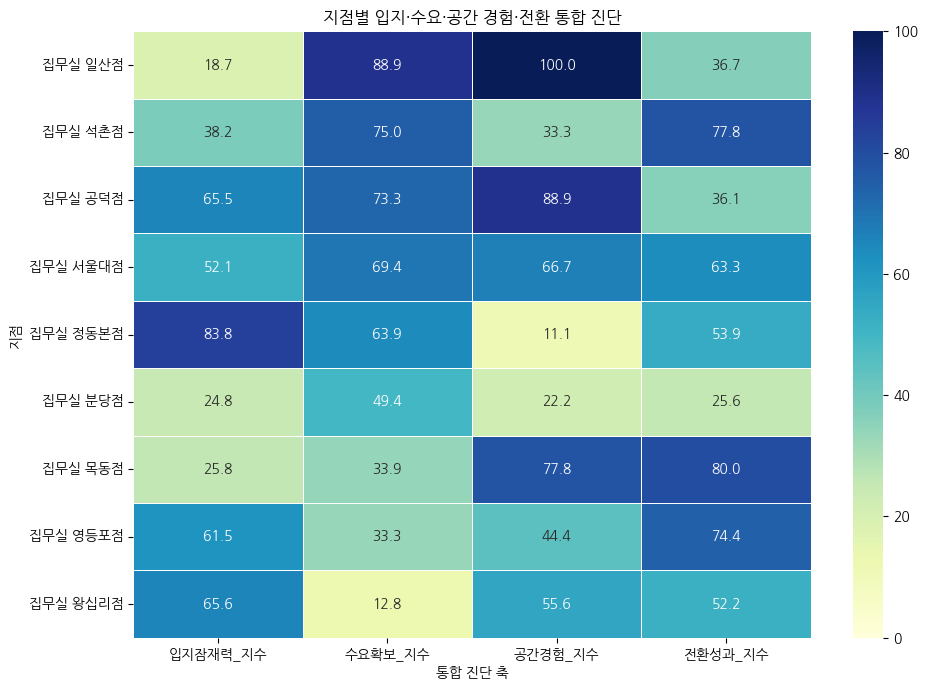

In [ ]:
# 지점별 4대 지수 히트맵

diagnostic_heatmap = (
    site_diagnosis
    .set_index("site_name_full")[
        [
            "입지잠재력_지수",
            "수요확보_지수",
            "공간경험_지수",
            "전환성과_지수",
        ]
    ]
    .sort_values("수요확보_지수", ascending=False)
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    diagnostic_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5,
)

plt.title("지점별 입지·수요·공간 경험·전환 통합 진단")
plt.xlabel("통합 진단 축")
plt.ylabel("지점")
plt.tight_layout()
plt.show()

> **💡 4대 지수 결과 해석**
>
> - 공덕점은 입지와 수요 확보가 모두 높고 공간 경험도 양호하지만 전환 성과가 낮다. 종합점수는 높아도 핵심 과제는 추가 유입보다 이미 확보한 수요의 결제 전환이다.
> - 일산점은 입지 잠재력은 낮지만 수요 확보와 공간 경험이 가장 높다. 지하철·주변 인프라만으로 설명되지 않는 목적 방문 또는 지역 내 대체재 부족 가능성이 있으며, 전환만 개선되면 성장 여지가 크다.
> - 석촌점은 수요와 전환이 모두 높은 가장 균형적인 성과형 지점이다. 입지 지수는 높지 않으므로 입지 우위보다 운영·고객 적합성이 성과에 기여했을 가능성이 있다.
> - 목동점·영등포점은 전환 성과는 높지만 수요 확보가 낮다. 공간을 경험한 사용자의 반응은 괜찮지만 체험 유입 자체가 부족한 유형으로 해석한다.
> - 왕십리점은 입지 잠재력에 비해 수요 확보가 크게 낮다. 접근성이 실제 방문으로 이어지지 않는 이유를 채널 노출, 지점 인지도, 상품 적합성 관점에서 점검해야 한다.
> - 분당점은 입지·공간 경험·전환이 함께 낮아 단일 캠페인보다 지점 역할과 타깃을 다시 검토해야 한다.
>
> - 리뷰 점수는 지점별 표본 차이가 크므로 공간경험_보정점수를 사용한다. 특히 지도 리뷰가 0~1건인 분당점·영등포점은 리뷰 결과를 확정적 만족도 평가로 해석하지 않는다.
>
> - 지수 해석 주의: 수요확보_지수, 전환성과_지수, 입지잠재력_지수, 공간경험_지수는 9개 지점 내부의 백분위 순위를 결합한 상대 점수이다. 예를 들어 공간 경험 절대점수가 76점이어도 다른 지점보다 낮으면 공간경험 지수는 11.1점이 될 수 있다. 따라서 낮은 지수는 절대적인 불만족이나 실패가 아니라 현재 9개 지점 중 상대적 열위를 의미한다.


#### 6-3-5-2. 수요·전환 세그먼트와 지점별 병목 진단

**🔹 분석 목적**

- 수요 확보 지수와 전환 성과 지수의 중앙값을 기준으로 지점을 네 개의 성과 세그먼트로 구분한다.
- 입지 대비 수요 포착 격차와 경험 대비 전환 격차를 계산해 지점별 병목을 수치화한다.
- 고전환은 원시 결제율 하나가 아니라 대표 지점 결제율·반복 방문률·면적당 결제자·평균 방문일 수를 결합한 상대적 성과 그룹으로 해석한다.
- 포트폴리오 맵에서는 점 크기로 입지 잠재력, 투명도로 리뷰 근거 강도를 함께 표시한다.


In [ ]:
# 수요 확보 지수와 전환 성과 지수 중앙값을 기준으로 4개 세그먼트 구분

demand_threshold = site_diagnosis["수요확보_지수"].median()
conversion_threshold = site_diagnosis["전환성과_지수"].median()
location_threshold = site_diagnosis["입지잠재력_지수"].median()
experience_threshold = site_diagnosis["공간경험_지수"].median()

high_demand = site_diagnosis["수요확보_지수"].ge(demand_threshold)
high_conversion = site_diagnosis["전환성과_지수"].ge(conversion_threshold)

site_diagnosis["성과_세그먼트"] = np.select(
    [
        high_demand & high_conversion,
        high_demand & ~high_conversion,
        ~high_demand & high_conversion,
        ~high_demand & ~high_conversion,
    ],
    [
        "고유입·고전환",
        "고유입·저전환",
        "저유입·고전환",
        "저유입·저전환",
    ],
    default="분류 불가",
)

# 선행 요인과 실제 성과의 차이
# 양수일수록 각각 '입지에 비해 수요 포착이 부족', '경험에 비해 전환 실현이 부족'하다는 의미다.
site_diagnosis["입지대비_수요포착격차"] = (
    site_diagnosis["입지잠재력_지수"]
    - site_diagnosis["수요확보_지수"]
)

site_diagnosis["경험대비_전환격차"] = (
    site_diagnosis["공간경험_지수"]
    - site_diagnosis["전환성과_지수"]
)

# 유입 개선 우선순위
site_diagnosis["유입개선_우선순위"] = (
    0.45 * (100 - site_diagnosis["수요확보_지수"])
    + 0.30 * site_diagnosis["입지잠재력_지수"]
    + 0.25 * site_diagnosis["입지대비_수요포착격차"].clip(lower=0)
)

# 전환 병목을 두 가지로 분리한다.
# 1) 수익화 기회: 수요와 경험은 충분하지만 결제가 낮은 상태
# 2) 경험 개선 기회: 결제와 공간 경험이 함께 낮은 상태
site_diagnosis["수익화기회_지수"] = (
    0.40 * site_diagnosis["수요확보_지수"]
    + 0.35 * (100 - site_diagnosis["전환성과_지수"])
    + 0.25 * site_diagnosis["경험대비_전환격차"].clip(lower=0)
)

site_diagnosis["경험개선기회_지수"] = (
    0.35 * site_diagnosis["수요확보_지수"]
    + 0.35 * (100 - site_diagnosis["전환성과_지수"])
    + 0.30 * (100 - site_diagnosis["공간경험_지수"])
)

site_diagnosis["전환개선_유형"] = np.where(
    site_diagnosis["수익화기회_지수"]
    >= site_diagnosis["경험개선기회_지수"],
    "수익화·온보딩 개선",
    "공간 경험 개선",
)

site_diagnosis["전환개선_우선순위"] = site_diagnosis[
    ["수익화기회_지수", "경험개선기회_지수"]
].max(axis=1)

# 고유입·고전환 지점은 '개선 대상'이 아니라 확장·표준화 대상으로 분리한다.
site_diagnosis["개선대상여부"] = (
    site_diagnosis["성과_세그먼트"] != "고유입·고전환"
)

site_diagnosis["종합개선_우선순위"] = np.nan

mask_high_demand_low_conversion = (
    site_diagnosis["성과_세그먼트"] == "고유입·저전환"
)
mask_low_demand_high_conversion = (
    site_diagnosis["성과_세그먼트"] == "저유입·고전환"
)
mask_low_low = (
    site_diagnosis["성과_세그먼트"] == "저유입·저전환"
)

site_diagnosis.loc[
    mask_high_demand_low_conversion,
    "종합개선_우선순위",
] = site_diagnosis.loc[
    mask_high_demand_low_conversion,
    "전환개선_우선순위",
]

site_diagnosis.loc[
    mask_low_demand_high_conversion,
    "종합개선_우선순위",
] = site_diagnosis.loc[
    mask_low_demand_high_conversion,
    "유입개선_우선순위",
]

site_diagnosis.loc[
    mask_low_low,
    "종합개선_우선순위",
] = site_diagnosis.loc[
    mask_low_low,
    ["유입개선_우선순위", "전환개선_우선순위"],
].max(axis=1)


def diagnose_bottleneck(row):
    demand_high = row["수요확보_지수"] >= demand_threshold
    conversion_high = row["전환성과_지수"] >= conversion_threshold
    location_high = row["입지잠재력_지수"] >= location_threshold
    experience_high = row["공간경험_지수"] >= experience_threshold

    if demand_high and conversion_high:
        if row["입지대비_수요포착격차"] >= 15:
            return "성과 우수·추가 수요 포착 여력"
        return "강점 유지·확장"

    if demand_high and not conversion_high:
        if row["전환개선_유형"] == "수익화·온보딩 개선":
            return "수요·경험 대비 수익화 병목"
        return "공간 경험·전환 병목"

    if not demand_high and conversion_high:
        if location_high:
            return "입지 대비 유입 포착 부족"
        return "인지도·채널 유입 병목"

    if location_high and experience_high:
        return "유입 포착·상품화 동시 점검"
    if location_high and not experience_high:
        return "입지 활용 부족·공간 경험 병목"
    if not location_high and experience_high:
        return "입지·인지도 병목"
    return "입지·공간 경험 구조 재검토"


site_diagnosis["핵심병목"] = site_diagnosis.apply(
    diagnose_bottleneck,
    axis=1,
)


def assign_strategy(row):
    segment = row["성과_세그먼트"]
    weak_category = row["취약경험범주"]

    if segment == "고유입·고전환":
        return (
            "우수 운영모델 표준화 및 확장 | "
            "혼잡 시간대 운영 최적화 | 추천·장기전환 강화"
        )

    if segment == "고유입·저전환":
        if row["전환개선_유형"] == "수익화·온보딩 개선":
            return (
                "D1 재방문 유도 | 가격·상품 안내 A/B 테스트 | "
                "결제 CTA·상담 연결 개선"
            )

        return (
            f"{weak_category} 경험 개선 | "
            "D1 재방문 유도 | 이탈 사유·불편 회수"
        )

    if segment == "저유입·고전환":
        return (
            "입지 강점 메시지 재정의 | "
            "인근 기업·주거·대학 제휴 | 검색·지도 노출 확대"
        )

    return (
        "저비용 수요 검증부터 재실행 | "
        f"{weak_category} 경험 개선 | 지점 역할·타깃·상품 구성 재설계"
    )


site_diagnosis["세그먼트_전략"] = site_diagnosis.apply(
    assign_strategy,
    axis=1,
)

site_diagnosis["리뷰해석주의"] = np.where(
    site_diagnosis["리뷰근거_강도"] < 40,
    "리뷰 표본이 적어 정성 검토 병행",
    "통합 리뷰 지표 활용 가능",
)

priority_columns = [
    "유입개선_우선순위",
    "수익화기회_지수",
    "경험개선기회_지수",
    "전환개선_우선순위",
    "종합개선_우선순위",
]

site_diagnosis[priority_columns] = (
    site_diagnosis[priority_columns].round(1)
)

segment_summary = (
    site_diagnosis
    .groupby("성과_세그먼트", as_index=False)
    .agg(
        지점수=("site_id", "nunique"),
        평균_입지잠재력=("입지잠재력_지수", "mean"),
        평균_수요확보=("수요확보_지수", "mean"),
        평균_공간경험=("공간경험_지수", "mean"),
        평균_전환성과=("전환성과_지수", "mean"),
        평균_종합경쟁력=("종합경쟁력_지수", "mean"),
    )
    .round(1)
)

site_strategy_summary = (
    site_diagnosis[
        [
            "site_id",
            "site_name_full",
            "성과_세그먼트",
            "핵심병목",
            "취약경험범주",
            "입지대비_수요포착격차",
            "경험대비_전환격차",
            "유입개선_우선순위",
            "수익화기회_지수",
            "경험개선기회_지수",
            "전환개선_유형",
            "전환개선_우선순위",
            "종합개선_우선순위",
            "세그먼트_전략",
            "리뷰해석주의",
        ]
    ]
    .sort_values(
        "종합개선_우선순위",
        ascending=False,
        na_position="last",
    )
    .reset_index(drop=True)
)

display(segment_summary)
display(site_strategy_summary)


,성과_세그먼트,지점수,평균_입지잠재력,평균_수요확보,평균_공간경험,평균_전환성과,평균_종합경쟁력
0,고유입·고전환,3,58.0,69.4,37.0,65.0,59.0
1,고유입·저전환,2,42.1,81.1,94.4,36.4,62.8
2,저유입·고전환,2,43.6,33.6,61.1,77.2,52.6
3,저유입·저전환,2,45.2,31.1,38.9,38.9,38.2


,site_id,site_name_full,성과_세그먼트,핵심병목,취약경험범주,입지대비_수요포착격차,경험대비_전환격차,유입개선_우선순위,수익화기회_지수,경험개선기회_지수,전환개선_유형,전환개선_우선순위,종합개선_우선순위,세그먼트_전략,리뷰해석주의
0,6,집무실 일산점,고유입·저전환,수요·경험 대비 수익화 병목,접근성,-70.2,63.3,10.6,73.5,53.3,수익화·온보딩 개선,73.5,73.5,D1 재방문 유도 | 가격·상품 안내 A/B 테스트 | 결제 CTA·상담 연결 개선,통합 리뷰 지표 활용 가능
1,4,집무실 왕십리점,저유입·저전환,유입 포착·상품화 동시 점검,편의성,52.8,3.4,72.1,22.7,34.5,공간 경험 개선,34.5,72.1,저비용 수요 검증부터 재실행 | 편의성 경험 개선 | 지점 역할·타깃·상품 구성 재설계,통합 리뷰 지표 활용 가능
2,47,집무실 분당점,저유입·저전환,입지·공간 경험 구조 재검토,공간,-24.6,-3.4,30.2,45.8,66.7,공간 경험 개선,66.7,66.7,저비용 수요 검증부터 재실행 | 공간 경험 개선 | 지점 역할·타깃·상품 구성 재설계,리뷰 표본이 적어 정성 검토 병행
3,17,집무실 공덕점,고유입·저전환,수요·경험 대비 수익화 병목,공간,-7.8,52.8,31.7,64.9,51.4,수익화·온보딩 개선,64.9,64.9,D1 재방문 유도 | 가격·상품 안내 A/B 테스트 | 결제 CTA·상담 연결 개선,리뷰 표본이 적어 정성 검토 병행
4,49,집무실 영등포점,저유입·고전환,입지 대비 유입 포착 부족,편의성,28.2,-30.0,55.5,22.3,37.3,공간 경험 개선,37.3,55.5,입지 강점 메시지 재정의 | 인근 기업·주거·대학 제휴 | 검색·지도 노출 확대,리뷰 표본이 적어 정성 검토 병행
5,5,집무실 목동점,저유입·고전환,인지도·채널 유입 병목,편의성,-8.1,-2.2,37.5,20.6,25.5,공간 경험 개선,25.5,37.5,입지 강점 메시지 재정의 | 인근 기업·주거·대학 제휴 | 검색·지도 노출 확대,통합 리뷰 지표 활용 가능
6,1,집무실 정동본점,고유입·고전환,성과 우수·추가 수요 포착 여력,편의성,19.9,-42.8,46.4,41.7,65.2,공간 경험 개선,65.2,NaN,우수 운영모델 표준화 및 확장 | 혼잡 시간대 운영 최적화 | 추천·장기전환 강화,통합 리뷰 지표 활용 가능
7,3,집무실 석촌점,고유입·고전환,강점 유지·확장,접근성,-36.8,-44.5,22.7,37.8,54.0,공간 경험 개선,54.0,NaN,우수 운영모델 표준화 및 확장 | 혼잡 시간대 운영 최적화 | 추천·장기전환 강화,통합 리뷰 지표 활용 가능
8,2,집무실 서울대점,고유입·고전환,강점 유지·확장,접근성,-17.3,3.4,29.4,41.5,47.1,공간 경험 개선,47.1,NaN,우수 운영모델 표준화 및 확장 | 혼잡 시간대 운영 최적화 | 추천·장기전환 강화,통합 리뷰 지표 활용 가능


> **💡 세그먼트별 핵심 진단**
>
> | 세그먼트 | 해당 지점 | 핵심 해석 | 우선 전략 |
> |---|---|---|---|
> | 고유입·고전환 | 정동본점, 석촌점, 서울대점 | 현재 성과가 상대적으로 균형적 | 운영모델 표준화·확장 |
> | 고유입·저전환 | 공덕점, 일산점 | 수요와 경험은 확보됐지만 결제 실현이 부족 | D1 재방문·가격/상품 안내·결제 CTA 개선 |
> | 저유입·고전환 | 목동점, 영등포점 | 방문한 사용자의 전환은 높지만 신규 유입이 부족 | 검색 노출·제휴·입지 메시지 강화 |
> | 저유입·저전환 | 왕십리점, 분당점 | 왕십리는 입지 포착 문제, 분당은 구조적 재검토 필요 | 지점별로 유입 실험과 상품 재설계 분리 |
>
>
> - 수익화·온보딩 개선형: 일산점·공덕점처럼 수요와 경험은 충분하지만 전환만 낮은 경우
> - 공간 경험 개선형: 분당점처럼 경험과 전환이 함께 낮은 경우


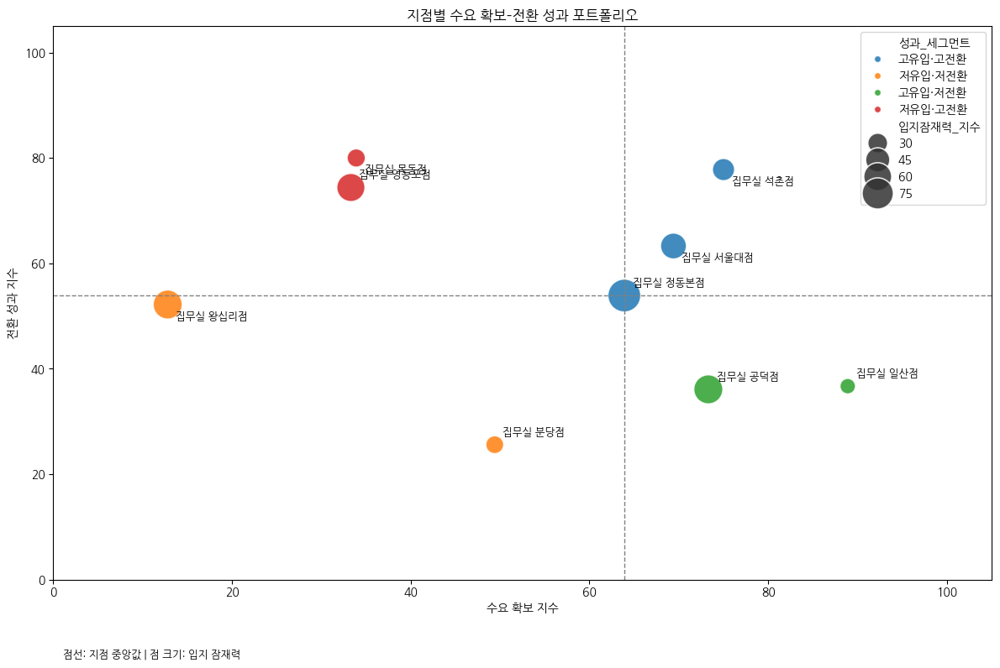

In [ ]:
# 수요 확보 × 전환 성과 포트폴리오 맵
# 점 크기: 입지 잠재력 | 점 투명도: 리뷰 근거 강도

portfolio_plot = site_diagnosis.copy()

fig, ax = plt.subplots(figsize=(12, 8))

sns.scatterplot(
    data=portfolio_plot,
    x="수요확보_지수",
    y="전환성과_지수",
    size="입지잠재력_지수",
    hue="성과_세그먼트",
    sizes=(180, 800),
    alpha=0.85,
    ax=ax,
)

ax.axvline(
    demand_threshold,
    linestyle="--",
    linewidth=1,
    color="grey",
)
ax.axhline(
    conversion_threshold,
    linestyle="--",
    linewidth=1,
    color="grey",
)

for index, row in enumerate(portfolio_plot.itertuples()):
    ax.annotate(
        row.site_name_full,
        (row.수요확보_지수, row.전환성과_지수),
        xytext=(7, 8 if index % 2 == 0 else -13),
        textcoords="offset points",
        fontsize=9,
    )

ax.set_title("지점별 수요 확보–전환 성과 포트폴리오")
ax.set_xlabel("수요 확보 지수")
ax.set_ylabel("전환 성과 지수")
ax.set_xlim(0, 105)
ax.set_ylim(0, 105)

ax.text(
    0.01,
    -0.14,
    "점선: 지점 중앙값 | 점 크기: 입지 잠재력",
    transform=ax.transAxes,
    fontsize=9,
)

plt.tight_layout()
plt.show()

> **📊 시각화 해석**
>
> - 포트폴리오 맵에서 일산·공덕은 수요 대비 전환 개선, 목동·영등포는 전환 강점을 유지한 유입 확대, 왕십리·분당은 구조적 점검이 필요한 위치에 있다.


#### 6-3-5-3. 관계·민감도·파레토 검증

**🔹 분석 목적**

- 입지 잠재력이 수요 확보로, 공간 경험이 전환 성과로 연결되는지 Spearman 상관과 순열검정으로 확인한다.
- 한 지점 제외 분석과 40%·50%·60% 분위수 기준을 활용해 결과가 특정 지점이나 중앙값 기준에 민감한지 점검한다.
- 종합 경쟁력의 가중치를 바꿔도 상위 지점이 유지되는지 확인하고, 수요와 전환 중 하나의 강점만으로도 지배되지 않는 파레토 지점을 찾는다.
- 지점 수가 9개이므로 모든 관계 검정은 인과관계가 아닌 탐색적 진단으로 해석한다.


In [ ]:
# 핵심 가설별 Spearman 상관계수와 순열검정

INTEGRATED_PERMUTATION_COUNT = 10_000

relationship_specs_integrated = [
    (
        "입지 잠재력 ↔ 수요 확보",
        "입지잠재력_지수",
        "수요확보_지수",
    ),
    (
        "입지 잠재력 ↔ 전환 성과",
        "입지잠재력_지수",
        "전환성과_지수",
    ),
    (
        "공간 경험 ↔ 전환 성과",
        "공간경험_지수",
        "전환성과_지수",
    ),
    (
        "공간 경험 ↔ 반복 방문률",
        "공간경험_지수",
        "repeat_visitor_rate",
    ),
    (
        "수요 확보 ↔ 전환 성과",
        "수요확보_지수",
        "전환성과_지수",
    ),
]


def integrated_permutation_spearman(
    x,
    y,
    permutation_count=INTEGRATED_PERMUTATION_COUNT,
    seed=42,
):
    valid = pd.DataFrame({"x": x, "y": y}).dropna()

    if (
        len(valid) < 4
        or valid["x"].nunique() < 2
        or valid["y"].nunique() < 2
    ):
        return np.nan, np.nan, len(valid)

    observed = spearmanr(valid["x"], valid["y"]).statistic
    rng = np.random.default_rng(seed)

    permuted = np.empty(permutation_count)

    for index in range(permutation_count):
        permuted[index] = spearmanr(
            valid["x"],
            rng.permutation(valid["y"]),
        ).statistic

    p_value = (
        np.sum(np.abs(permuted) >= abs(observed)) + 1
    ) / (permutation_count + 1)

    return observed, p_value, len(valid)


integrated_relationship_rows = []

for index, (name, x_column, y_column) in enumerate(
    relationship_specs_integrated
):
    rho, permutation_p, site_count = integrated_permutation_spearman(
        site_diagnosis[x_column],
        site_diagnosis[y_column],
        seed=4200 + index,
    )

    integrated_relationship_rows.append({
        "relationship": name,
        "x_column": x_column,
        "y_column": y_column,
        "site_count": site_count,
        "spearman_correlation": rho,
        "permutation_p_value": permutation_p,
    })

integrated_relationship_result = pd.DataFrame(
    integrated_relationship_rows
)

integrated_relationship_result[
    "holm_adjusted_p_value"
] = multipletests(
    integrated_relationship_result["permutation_p_value"].fillna(1),
    method="holm",
)[1]

integrated_relationship_result["significant_after_holm_05"] = (
    integrated_relationship_result["holm_adjusted_p_value"] < 0.05
)

display(integrated_relationship_result)

,relationship,x_column,y_column,site_count,spearman_correlation,permutation_p_value,holm_adjusted_p_value,significant_after_holm_05
0,입지 잠재력 ↔ 수요 확보,입지잠재력_지수,수요확보_지수,9,-0.383333,0.314869,1.0,False
1,입지 잠재력 ↔ 전환 성과,입지잠재력_지수,전환성과_지수,9,0.033333,0.943706,1.0,False
2,공간 경험 ↔ 전환 성과,공간경험_지수,전환성과_지수,9,-0.066667,0.880712,1.0,False
3,공간 경험 ↔ 반복 방문률,공간경험_지수,repeat_visitor_rate,9,0.183333,0.641136,1.0,False
4,수요 확보 ↔ 전환 성과,수요확보_지수,전환성과_지수,9,-0.166667,0.676632,1.0,False


> **💡 결과 해석**
>
> - 입지 잠재력–수요 확보, 공간 경험–전환 성과 등 핵심 가설은 모두 통계적으로 유의하지 않았다.
> - 현재 9개 지점에서는 입지나 리뷰 점수 하나로 성과를 예측하기보다 지점별 병목 진단에 활용해야 한다.


In [ ]:
# 지점 한 곳을 제외했을 때 관계 방향이 유지되는지 확인

integrated_loo_rows = []

for relationship_name, x_column, y_column in relationship_specs_integrated:
    valid = site_diagnosis[
        ["site_id", "site_name_full", x_column, y_column]
    ].dropna()

    full_rho = spearmanr(
        valid[x_column],
        valid[y_column],
    ).statistic

    for excluded in valid.itertuples(index=False):
        subset = valid.loc[
            valid["site_id"].ne(excluded.site_id)
        ]

        loo_rho = spearmanr(
            subset[x_column],
            subset[y_column],
        ).statistic

        integrated_loo_rows.append({
            "relationship": relationship_name,
            "excluded_site_id": excluded.site_id,
            "excluded_site_name": excluded.site_name_full,
            "full_spearman": full_rho,
            "leave_one_out_spearman": loo_rho,
            "absolute_change": abs(loo_rho - full_rho),
            "same_direction": (
                np.sign(loo_rho) == np.sign(full_rho)
                if full_rho != 0
                else np.nan
            ),
        })

integrated_loo_detail = pd.DataFrame(integrated_loo_rows)

integrated_loo_summary = (
    integrated_loo_detail
    .groupby("relationship", as_index=False)
    .agg(
        full_spearman=("full_spearman", "first"),
        min_leave_one_out=("leave_one_out_spearman", "min"),
        max_leave_one_out=("leave_one_out_spearman", "max"),
        direction_consistency_rate=("same_direction", "mean"),
        maximum_absolute_change=("absolute_change", "max"),
    )
)

most_influential_integrated_site = (
    integrated_loo_detail
    .sort_values(
        ["relationship", "absolute_change"],
        ascending=[True, False],
    )
    .groupby("relationship", as_index=False)
    .first()[
        [
            "relationship",
            "excluded_site_name",
            "absolute_change",
        ]
    ]
    .rename(columns={
        "excluded_site_name": "most_influential_site",
        "absolute_change": "influential_absolute_change",
    })
)

integrated_loo_summary = integrated_loo_summary.merge(
    most_influential_integrated_site,
    on="relationship",
    how="left",
    validate="1:1",
)

display(integrated_loo_summary)

,relationship,full_spearman,min_leave_one_out,max_leave_one_out,direction_consistency_rate,maximum_absolute_change,most_influential_site,influential_absolute_change
0,공간 경험 ↔ 반복 방문률,0.183333,-0.166667,0.452381,0.777778,0.350000,집무실 정동본점,0.350000
1,공간 경험 ↔ 전환 성과,-0.066667,-0.428571,0.142857,0.666667,0.361905,집무실 분당점,0.361905
2,수요 확보 ↔ 전환 성과,-0.166667,-0.404762,0.023810,0.777778,0.238095,집무실 석촌점,0.238095
3,입지 잠재력 ↔ 수요 확보,-0.383333,-0.523810,-0.119048,1.000000,0.264286,집무실 일산점,0.264286
4,입지 잠재력 ↔ 전환 성과,0.033333,-0.333333,0.190476,0.777778,0.366667,집무실 분당점,0.366667


> **💡 관계 분석 해석**

- 5개 핵심 관계 모두 순열검정과 Holm 보정 후 유의하지 않았다. 지점이 9개뿐인 현재 데이터로는 입지가 수요를 높인다, 공간 경험이 전환을 높인다는 일반 법칙을 통계적으로 확인할 수 없다.
- 입지 잠재력 ↔ 수요 확보는 약한 음의 관계가 나타났고, 한 지점을 제외해도 방향은 유지됐다. 다만 유의하지 않으므로 좋은 입지가 수요를 낮춘다고 해석하면 안 된다.
- 일산점처럼 낮은 지하철 접근성에도 수요가 높은 지점, 왕십리점처럼 높은 입지 잠재력에도 수요가 낮은 지점이 섞여 있어 지점별 타깃·운영·지역 특성이 입지 효과를 상쇄했을 가능성이 있다.
- 따라서 이후 결과는 인과관계가 아니라 상대적 병목 진단과 우선순위 설정에 사용한다.


In [ ]:
# 중앙값 하나에만 의존하지 않도록 40%·50%·60% 분위수 기준으로 세그먼트 안정성 확인

def assign_performance_segment(
    demand_series,
    conversion_series,
    demand_cut,
    conversion_cut,
):
    return np.select(
        [
            demand_series.ge(demand_cut)
            & conversion_series.ge(conversion_cut),

            demand_series.ge(demand_cut)
            & conversion_series.lt(conversion_cut),

            demand_series.lt(demand_cut)
            & conversion_series.ge(conversion_cut),

            demand_series.lt(demand_cut)
            & conversion_series.lt(conversion_cut),
        ],
        [
            "고유입·고전환",
            "고유입·저전환",
            "저유입·고전환",
            "저유입·저전환",
        ],
        default="분류 불가",
    )


segment_sensitivity_rows = []

for quantile in [0.40, 0.50, 0.60]:
    demand_cut = site_diagnosis["수요확보_지수"].quantile(quantile)
    conversion_cut = site_diagnosis["전환성과_지수"].quantile(quantile)

    temporary_segments = assign_performance_segment(
        site_diagnosis["수요확보_지수"],
        site_diagnosis["전환성과_지수"],
        demand_cut,
        conversion_cut,
    )

    for site_key, site_name, segment in zip(
        site_diagnosis["site_key"],
        site_diagnosis["site_name_full"],
        temporary_segments,
    ):
        segment_sensitivity_rows.append({
            "site_key": site_key,
            "site_name_full": site_name,
            "threshold_quantile": quantile,
            "segment": segment,
        })

segment_sensitivity_detail = pd.DataFrame(
    segment_sensitivity_rows
)

segment_stability_summary = (
    segment_sensitivity_detail
    .groupby(["site_key", "site_name_full"], as_index=False)
    .agg(
        modal_segment=(
            "segment",
            lambda values: values.value_counts().index[0],
        ),
        segment_stability_rate=(
            "segment",
            lambda values: values.value_counts(normalize=True).iloc[0],
        ),
        observed_segment_count=("segment", "nunique"),
    )
)

site_diagnosis = site_diagnosis.drop(
    columns=[
        "modal_segment",
        "segment_stability_rate",
        "observed_segment_count",
    ],
    errors="ignore",
).merge(
    segment_stability_summary[
        [
            "site_key",
            "modal_segment",
            "segment_stability_rate",
            "observed_segment_count",
        ]
    ],
    on="site_key",
    how="left",
    validate="1:1",
)

display(
    segment_stability_summary
    .sort_values(
        ["segment_stability_rate", "site_name_full"],
        ascending=[True, True],
    )
)


,site_key,site_name_full,modal_segment,segment_stability_rate,observed_segment_count
8,정동본점,집무실 정동본점,고유입·고전환,0.666667,2
0,공덕점,집무실 공덕점,고유입·저전환,1.000000,1
1,목동점,집무실 목동점,저유입·고전환,1.000000,1
2,분당점,집무실 분당점,저유입·저전환,1.000000,1
3,서울대점,집무실 서울대점,고유입·고전환,1.000000,1
4,석촌점,집무실 석촌점,고유입·고전환,1.000000,1
5,영등포점,집무실 영등포점,저유입·고전환,1.000000,1
6,왕십리점,집무실 왕십리점,저유입·저전환,1.000000,1
7,일산점,집무실 일산점,고유입·저전환,1.000000,1


> **✅ 안정성 확인**
>
> - 40%·50%·60% 기준에서 정동본점을 제외한 8개 지점의 성과 세그먼트가 모두 동일하게 유지되었다.
> - 정동본점은 기준에 따라 두 유형을 오가는 경계 지점이므로 단일 라벨보다 원시 지표를 함께 제시한다.


,site_key,site_name_full,종합경쟁력_평균순위,종합경쟁력_최고순위,종합경쟁력_최저순위,종합경쟁력_순위표준편차,종합경쟁력_상위3비율,종합경쟁력_순위범위,종합경쟁력_순위해석
0,공덕점,집무실 공덕점,1.6,1.0,4.0,1.34,0.8,3.0,가중치 변화에도 상위권
3,서울대점,집무실 서울대점,2.2,1.0,4.0,1.10,0.8,3.0,가중치 변화에도 상위권
7,일산점,집무실 일산점,3.2,3.0,4.0,0.45,0.8,1.0,가중치 변화에도 상위권
4,석촌점,집무실 석촌점,4.0,2.0,5.0,1.22,0.2,3.0,전략 가중치에 따라 순위 변동
1,목동점,집무실 목동점,5.4,2.0,7.0,2.07,0.2,5.0,전략 가중치에 따라 순위 변동
8,정동본점,집무실 정동본점,5.6,3.0,8.0,1.95,0.2,5.0,전략 가중치에 따라 순위 변동
5,영등포점,집무실 영등포점,6.2,6.0,7.0,0.45,0.0,1.0,순위가 매우 안정적
6,왕십리점,집무실 왕십리점,7.8,7.0,8.0,0.45,0.0,1.0,순위가 매우 안정적
2,분당점,집무실 분당점,9.0,9.0,9.0,0.00,0.0,0.0,순위가 매우 안정적


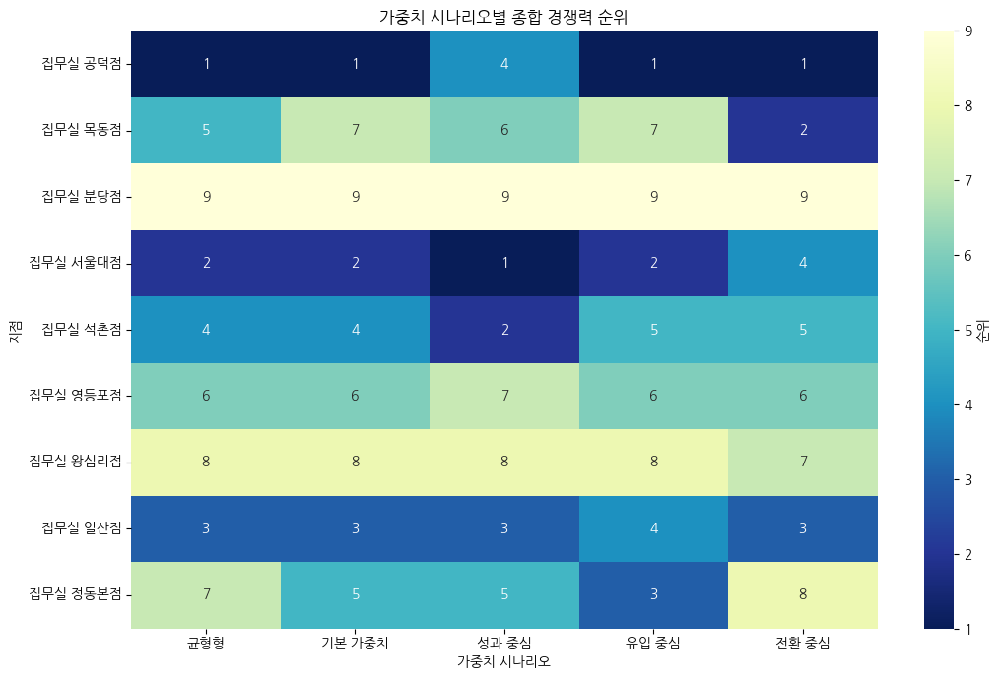

In [ ]:
# 종합 경쟁력 가중치 변화에 따른 지점 순위 안정성 분석

weight_scenarios = {
    "기본 가중치": {
        "수요확보_지수": 0.30,
        "전환성과_지수": 0.25,
        "입지잠재력_지수": 0.25,
        "공간경험_지수": 0.20,
    },
    "성과 중심": {
        "수요확보_지수": 0.35,
        "전환성과_지수": 0.35,
        "입지잠재력_지수": 0.15,
        "공간경험_지수": 0.15,
    },
    "유입 중심": {
        "수요확보_지수": 0.35,
        "전환성과_지수": 0.15,
        "입지잠재력_지수": 0.35,
        "공간경험_지수": 0.15,
    },
    "전환 중심": {
        "수요확보_지수": 0.15,
        "전환성과_지수": 0.35,
        "입지잠재력_지수": 0.15,
        "공간경험_지수": 0.35,
    },
    "균형형": {
        "수요확보_지수": 0.25,
        "전환성과_지수": 0.25,
        "입지잠재력_지수": 0.25,
        "공간경험_지수": 0.25,
    },
}

weight_sensitivity_rows = []

for scenario_name, scenario_weights in weight_scenarios.items():
    scenario_score = weighted_available_mean(
        site_diagnosis,
        scenario_weights,
    )

    scenario_rank = scenario_score.rank(
        ascending=False,
        method="min",
    )

    for site_key, site_name, score, rank in zip(
        site_diagnosis["site_key"],
        site_diagnosis["site_name_full"],
        scenario_score,
        scenario_rank,
    ):
        weight_sensitivity_rows.append({
            "site_key": site_key,
            "site_name_full": site_name,
            "가중치_시나리오": scenario_name,
            "시나리오_점수": score,
            "시나리오_순위": rank,
        })

weight_sensitivity_long = pd.DataFrame(
    weight_sensitivity_rows
)

weight_rank_wide = weight_sensitivity_long.pivot(
    index="site_name_full",
    columns="가중치_시나리오",
    values="시나리오_순위",
)

weight_rank_stability = (
    weight_sensitivity_long
    .groupby(["site_key", "site_name_full"], as_index=False)
    .agg(
        종합경쟁력_평균순위=("시나리오_순위", "mean"),
        종합경쟁력_최고순위=("시나리오_순위", "min"),
        종합경쟁력_최저순위=("시나리오_순위", "max"),
        종합경쟁력_순위표준편차=("시나리오_순위", "std"),
        종합경쟁력_상위3비율=(
            "시나리오_순위",
            lambda values: (values <= 3).mean(),
        ),
    )
)

weight_rank_stability["종합경쟁력_순위범위"] = (
    weight_rank_stability["종합경쟁력_최저순위"]
    - weight_rank_stability["종합경쟁력_최고순위"]
)

weight_rank_stability["종합경쟁력_순위해석"] = np.select(
    [
        weight_rank_stability["종합경쟁력_상위3비율"] >= 0.80,
        weight_rank_stability["종합경쟁력_순위범위"] <= 1,
    ],
    [
        "가중치 변화에도 상위권",
        "순위가 매우 안정적",
    ],
    default="전략 가중치에 따라 순위 변동",
)

site_diagnosis = site_diagnosis.drop(
    columns=[
        "종합경쟁력_평균순위",
        "종합경쟁력_최고순위",
        "종합경쟁력_최저순위",
        "종합경쟁력_순위표준편차",
        "종합경쟁력_상위3비율",
        "종합경쟁력_순위범위",
        "종합경쟁력_순위해석",
    ],
    errors="ignore",
).merge(
    weight_rank_stability.drop(columns=["site_name_full"]),
    on="site_key",
    how="left",
    validate="1:1",
)

display(
    weight_rank_stability
    .sort_values(
        ["종합경쟁력_평균순위", "종합경쟁력_순위범위"]
    )
    .round(2)
)

plt.figure(figsize=(11, 7))
sns.heatmap(
    weight_rank_wide,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu_r",
    cbar_kws={"label": "순위"},
)
plt.title("가중치 시나리오별 종합 경쟁력 순위")
plt.xlabel("가중치 시나리오")
plt.ylabel("지점")
plt.tight_layout()
plt.show()


> **💡 가중치 민감도 해석**
>
> - 공덕점·서울대점·일산점은 5개 시나리오 중 4개에서 상위 3위에 들어가 상대적으로 안정적인 상위권이다.
> - 석촌점은 성과 중심 가중치에서 강하지만 입지·공간 경험 비중이 커지면 순위가 달라진다.
> - 목동점은 전환 중심 시나리오에서 크게 올라가고, 정동본점은 유입·입지 중심 시나리오에서 올라간다. 두 지점은 전체 1등이라기보다 특정 전략 목적의 벤치마크로 적합하다.
> - 영등포점·왕십리점·분당점은 가중치가 바뀌어도 상대적 하위권이어서 개선 필요성의 방향은 비교적 안정적이다.


,site_name_full,수요확보_지수,전환성과_지수,성과_파레토_여부,파레토_역할
8,집무실 일산점,88.9,36.7,True,수요 극대화 벤치마크
3,집무실 석촌점,75.0,77.8,True,균형 성과 벤치마크
7,집무실 목동점,33.9,80.0,True,전환 극대화 벤치마크
2,집무실 공덕점,73.3,36.1,False,개선·비교 대상
5,집무실 서울대점,69.4,63.3,False,개선·비교 대상
0,집무실 정동본점,63.9,53.9,False,개선·비교 대상
6,집무실 분당점,49.4,25.6,False,개선·비교 대상
4,집무실 영등포점,33.3,74.4,False,개선·비교 대상
1,집무실 왕십리점,12.8,52.2,False,개선·비교 대상


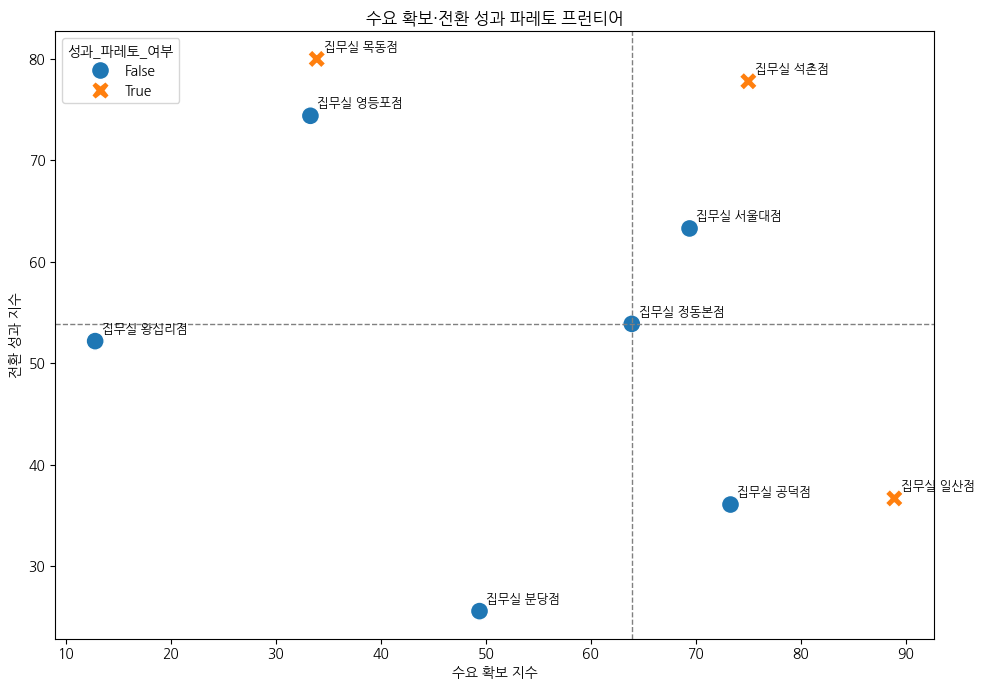

In [ ]:
# 수요 확보와 전환 성과의 파레토 프런티어 도출

performance_columns = [
    "수요확보_지수",
    "전환성과_지수",
]

performance_values = site_diagnosis[
    performance_columns
].to_numpy(dtype=float)

pareto_flags = []

for row_index in range(len(site_diagnosis)):
    dominated = False

    for comparison_index in range(len(site_diagnosis)):
        if row_index == comparison_index:
            continue

        comparison_is_equal_or_better = np.all(
            performance_values[comparison_index]
            >= performance_values[row_index]
        )
        comparison_is_strictly_better = np.any(
            performance_values[comparison_index]
            > performance_values[row_index]
        )

        if (
            comparison_is_equal_or_better
            and comparison_is_strictly_better
        ):
            dominated = True
            break

    pareto_flags.append(not dominated)

site_diagnosis["성과_파레토_여부"] = pareto_flags

pareto_sites = site_diagnosis.loc[
    site_diagnosis["성과_파레토_여부"]
].copy()

demand_leader_site = (
    pareto_sites
    .sort_values("수요확보_지수", ascending=False)
    .iloc[0]["site_name_full"]
)

conversion_leader_site = (
    pareto_sites
    .sort_values("전환성과_지수", ascending=False)
    .iloc[0]["site_name_full"]
)

site_diagnosis["파레토_역할"] = np.select(
    [
        site_diagnosis["site_name_full"].eq(demand_leader_site),
        site_diagnosis["site_name_full"].eq(conversion_leader_site),
        site_diagnosis["성과_파레토_여부"],
    ],
    [
        "수요 극대화 벤치마크",
        "전환 극대화 벤치마크",
        "균형 성과 벤치마크",
    ],
    default="개선·비교 대상",
)

display(
    site_diagnosis[
        [
            "site_name_full",
            "수요확보_지수",
            "전환성과_지수",
            "성과_파레토_여부",
            "파레토_역할",
        ]
    ]
    .sort_values(
        ["성과_파레토_여부", "수요확보_지수"],
        ascending=[False, False],
    )
)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=site_diagnosis,
    x="수요확보_지수",
    y="전환성과_지수",
    hue="성과_파레토_여부",
    style="성과_파레토_여부",
    s=170,
)

for row in site_diagnosis.itertuples():
    plt.annotate(
        row.site_name_full,
        (row.수요확보_지수, row.전환성과_지수),
        xytext=(5, 6),
        textcoords="offset points",
        fontsize=9,
    )

plt.axvline(
    demand_threshold,
    linestyle="--",
    linewidth=1,
    color="grey",
)
plt.axhline(
    conversion_threshold,
    linestyle="--",
    linewidth=1,
    color="grey",
)

plt.title("수요 확보·전환 성과 파레토 프런티어")
plt.xlabel("수요 확보 지수")
plt.ylabel("전환 성과 지수")
plt.tight_layout()
plt.show()


> **💡 파레토 프런티어 해석**
>
> - 일산점: 수요 극대화 벤치마크
> - 석촌점: 수요와 전환의 균형 벤치마크
> - 목동점: 전환 극대화 벤치마크
>
> 신규 출점이나 기존 지점 개선에서 하나의 최우수 지점만 복제하기보다, 목표에 따라 세 벤치마크를 구분한다. 예를 들어 신규 지점의 초기 목표가 빠른 유입 확보라면 일산형, 안정적인 종합 성과라면 석촌형, 소규모라도 높은 전환을 목표로 한다면 목동형을 참고한다.


#### 6-3-5-4. 성과 군집과 군집화 결과 해석

**🔹 분석 목적**

- 실행 전략 유형을 구분하기 위해 `수요 확보·전환 성과`만 사용한 성과 군집을 핵심 군집으로 구성한다.
- 선행 요인과 결과 지표가 섞인 4축 통합 군집은 지점 유사성을 설명하는 보조 분석으로만 사용한다.
- K-Means와 계층적 군집, 3개 스케일러, 군집 수 2~4개를 비교하고 Silhouette·Calinski-Harabasz·Davies-Bouldin·군집 균형성을 함께 평가한다.
- 지표 교란 안정성, 알고리즘 간 합의도, 개별 실루엣과 4분면 세그먼트 일치 여부를 확인해 군집 해석의 불확실성을 공개한다.

**🔹 모델 선택 원칙**

- 단일 실루엣 최고안과 최종 추천안을 구분한다.
- 한 지점만 포함된 군집은 제외한다.
- 수치 성능뿐 아니라 군집 크기와 사업적 해석 가능성을 함께 고려한다.


In [ ]:
# 성과 군집과 통합 군집을 분리하여 모델을 비교한다.
# - 성과 군집: 수요 확보·전환 성과만 사용하여 실행 전략 유형을 구분
# - 통합 군집: 입지·수요·공간 경험·전환 4축을 사용하되 보조 해석으로만 활용

from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
)

performance_cluster_features = [
    "수요확보_지수",
    "전환성과_지수",
]

cluster_feature_columns = [
    "입지잠재력_지수",
    "수요확보_지수",
    "공간경험_지수",
    "전환성과_지수",
]


def fit_cluster_model(raw_matrix, scaler_name, model_name, cluster_count):
    scalers = {
        "StandardScaler": StandardScaler(),
        "RobustScaler": RobustScaler(),
        "MinMaxScaler": MinMaxScaler(),
    }

    scaler = scalers[scaler_name]
    scaled_matrix = scaler.fit_transform(raw_matrix)

    if model_name == "KMeans":
        model = KMeans(
            n_clusters=cluster_count,
            random_state=42,
            n_init=50,
        )
    else:
        linkage = model_name.replace("Agglomerative-", "")
        model = AgglomerativeClustering(
            n_clusters=cluster_count,
            linkage=linkage,
        )

    labels = model.fit_predict(scaled_matrix)

    return labels, scaled_matrix, scaler


def evaluate_cluster_models(frame, feature_columns):
    cluster_frame = (
        frame[["site_key", "site_name_full"] + feature_columns]
        .dropna()
        .copy()
        .reset_index(drop=True)
    )

    raw_matrix = cluster_frame[feature_columns].to_numpy(dtype=float)

    evaluation_rows = []
    label_store = {}

    scaler_names = [
        "StandardScaler",
        "RobustScaler",
        "MinMaxScaler",
    ]

    model_names = [
        "KMeans",
        "Agglomerative-ward",
        "Agglomerative-complete",
        "Agglomerative-average",
    ]

    for scaler_name in scaler_names:
        for model_name in model_names:
            for cluster_count in range(
                2,
                min(5, len(cluster_frame)),
            ):
                labels, scaled_matrix, _ = fit_cluster_model(
                    raw_matrix,
                    scaler_name,
                    model_name,
                    cluster_count,
                )

                cluster_sizes = pd.Series(labels).value_counts()
                scenario_key = (
                    scaler_name,
                    model_name,
                    cluster_count,
                )
                label_store[scenario_key] = labels

                evaluation_rows.append({
                    "scaler": scaler_name,
                    "model": model_name,
                    "cluster_count": cluster_count,
                    "silhouette_score": silhouette_score(
                        scaled_matrix,
                        labels,
                    ),
                    "calinski_harabasz_score": (
                        calinski_harabasz_score(
                            scaled_matrix,
                            labels,
                        )
                    ),
                    "davies_bouldin_score": (
                        davies_bouldin_score(
                            scaled_matrix,
                            labels,
                        )
                    ),
                    "minimum_cluster_size": int(
                        cluster_sizes.min()
                    ),
                    "maximum_cluster_size": int(
                        cluster_sizes.max()
                    ),
                    "has_singleton_cluster": bool(
                        cluster_sizes.min() < 2
                    ),
                })

    evaluation = pd.DataFrame(evaluation_rows)

    # 한 지점만 포함된 군집은 과적합 가능성이 높으므로 모델 선택에서 제외한다.
    valid_evaluation = evaluation.loc[
        ~evaluation["has_singleton_cluster"]
    ].copy()

    if valid_evaluation.empty:
        valid_evaluation = evaluation.copy()

    valid_evaluation["silhouette_rank"] = (
        valid_evaluation["silhouette_score"]
        .rank(ascending=False, method="min")
    )
    valid_evaluation["calinski_rank"] = (
        valid_evaluation["calinski_harabasz_score"]
        .rank(ascending=False, method="min")
    )
    valid_evaluation["davies_rank"] = (
        valid_evaluation["davies_bouldin_score"]
        .rank(ascending=True, method="min")
    )

    valid_evaluation["metric_average_rank"] = (
        valid_evaluation[
            [
                "silhouette_rank",
                "calinski_rank",
                "davies_rank",
            ]
        ]
        .mean(axis=1)
    )

    selected = (
        valid_evaluation
        .sort_values(
            [
                "metric_average_rank",
                "silhouette_score",
                "minimum_cluster_size",
            ],
            ascending=[True, False, False],
        )
        .iloc[0]
    )

    selected_key = (
        selected["scaler"],
        selected["model"],
        int(selected["cluster_count"]),
    )

    selected_labels, selected_matrix, selected_scaler = (
        fit_cluster_model(
            raw_matrix,
            selected_key[0],
            selected_key[1],
            selected_key[2],
        )
    )

    evaluation = evaluation.merge(
        valid_evaluation[
            [
                "scaler",
                "model",
                "cluster_count",
                "metric_average_rank",
            ]
        ],
        on=["scaler", "model", "cluster_count"],
        how="left",
    )

    return {
        "input": cluster_frame,
        "raw_matrix": raw_matrix,
        "evaluation": evaluation.sort_values(
            [
                "has_singleton_cluster",
                "metric_average_rank",
                "silhouette_score",
            ],
            ascending=[True, True, False],
            na_position="last",
        ),
        "selected_row": selected,
        "selected_labels": selected_labels,
        "selected_matrix": selected_matrix,
        "selected_scaler": selected_scaler,
    }


def perturbation_cluster_stability(
    raw_matrix,
    scaler_name,
    model_name,
    cluster_count,
    repetitions=300,
    noise_ratio=0.05,
    random_state=42,
):
    """각 지표에 작은 잡음을 넣었을 때 군집이 유지되는지 ARI로 확인한다."""
    base_labels, _, _ = fit_cluster_model(
        raw_matrix,
        scaler_name,
        model_name,
        cluster_count,
    )

    rng = np.random.default_rng(random_state)
    feature_std = np.nanstd(raw_matrix, axis=0, ddof=1)
    feature_std = np.where(feature_std == 0, 1, feature_std)

    stability_scores = []

    for _ in range(repetitions):
        perturbed_matrix = (
            raw_matrix
            + rng.normal(
                loc=0,
                scale=noise_ratio * feature_std,
                size=raw_matrix.shape,
            )
        )

        perturbed_labels, _, _ = fit_cluster_model(
            perturbed_matrix,
            scaler_name,
            model_name,
            cluster_count,
        )

        stability_scores.append(
            adjusted_rand_score(
                base_labels,
                perturbed_labels,
            )
        )

    return {
        "mean_ari": float(np.mean(stability_scores)),
        "median_ari": float(np.median(stability_scores)),
        "minimum_ari": float(np.min(stability_scores)),
    }


# 1) 수요·전환 성과 군집
performance_cluster_result = evaluate_cluster_models(
    site_diagnosis,
    performance_cluster_features,
)

performance_selected = (
    performance_cluster_result["selected_row"]
)

performance_cluster_input = (
    performance_cluster_result["input"].copy()
)
performance_cluster_input["성과군집"] = (
    performance_cluster_result["selected_labels"] + 1
)

performance_cluster_profile = (
    performance_cluster_input
    .groupby("성과군집", as_index=False)[
        performance_cluster_features
    ]
    .mean()
    .round(1)
)

demand_reference = site_diagnosis["수요확보_지수"].median()
conversion_reference = site_diagnosis["전환성과_지수"].median()


def name_performance_cluster(row):
    demand_high = row["수요확보_지수"] >= demand_reference
    conversion_high = (
        row["전환성과_지수"] >= conversion_reference
    )

    if demand_high and conversion_high:
        return "균형 성과형"
    if demand_high and not conversion_high:
        return "유입 우수·전환 개선형"
    if not demand_high and conversion_high:
        return "전환 우수·유입 확대형"
    return "구조 재검토형"


performance_cluster_profile["성과군집_유형"] = (
    performance_cluster_profile.apply(
        name_performance_cluster,
        axis=1,
    )
)

performance_stability = perturbation_cluster_stability(
    performance_cluster_result["raw_matrix"],
    performance_selected["scaler"],
    performance_selected["model"],
    int(performance_selected["cluster_count"]),
)

site_diagnosis = site_diagnosis.drop(
    columns=[
        "성과군집",
        "성과군집_유형",
        "성과군집_해석신뢰도",
    ],
    errors="ignore",
).merge(
    performance_cluster_input[
        ["site_key", "성과군집"]
    ],
    on="site_key",
    how="left",
    validate="1:1",
).merge(
    performance_cluster_profile[
        ["성과군집", "성과군집_유형"]
    ],
    on="성과군집",
    how="left",
    validate="m:1",
)

performance_silhouette = float(
    performance_selected["silhouette_score"]
)

site_diagnosis["성과군집_해석신뢰도"] = np.select(
    [
        (
            performance_silhouette >= 0.40
            and performance_stability["mean_ari"] >= 0.80
        ),
        performance_silhouette >= 0.25,
    ],
    [
        "탐색적 활용에 비교적 양호",
        "보조 해석만 가능",
    ],
    default="낮음·핵심 결론 사용 금지",
)


# 2) 입지·수요·공간 경험·전환 통합 군집
integrated_cluster_result = evaluate_cluster_models(
    site_diagnosis,
    cluster_feature_columns,
)

integrated_selected = integrated_cluster_result["selected_row"]

cluster_input = integrated_cluster_result["input"].copy()
cluster_matrix = integrated_cluster_result["selected_matrix"]
cluster_input["통합군집"] = (
    integrated_cluster_result["selected_labels"] + 1
)

best_cluster_count = int(
    integrated_selected["cluster_count"]
)
best_silhouette_score = float(
    integrated_selected["silhouette_score"]
)

integrated_cluster_profile = (
    cluster_input
    .groupby("통합군집", as_index=False)[
        cluster_feature_columns
    ]
    .mean()
    .round(1)
)


def name_integrated_cluster(row):
    demand_high = row["수요확보_지수"] >= 50
    conversion_high = row["전환성과_지수"] >= 50
    location_high = row["입지잠재력_지수"] >= 50
    experience_high = row["공간경험_지수"] >= 50

    if demand_high and conversion_high:
        return "성과 우수형"
    if demand_high and not conversion_high:
        return (
            "유입 우수·전환 개선형"
            if experience_high
            else "유입 우수·경험 개선형"
        )
    if not demand_high and conversion_high:
        return (
            "입지 활용·유입 확대형"
            if location_high
            else "충성 고객 기반 니치형"
        )
    return (
        "잠재력 재활성화형"
        if location_high or experience_high
        else "구조 재검토형"
    )


integrated_cluster_profile["통합군집_유형"] = (
    integrated_cluster_profile.apply(
        name_integrated_cluster,
        axis=1,
    )
)

site_diagnosis = site_diagnosis.drop(
    columns=[
        "통합군집",
        "통합군집_유형",
        "군집해석주의",
    ],
    errors="ignore",
).merge(
    cluster_input[["site_key", "통합군집"]],
    on="site_key",
    how="left",
    validate="1:1",
).merge(
    integrated_cluster_profile[
        ["통합군집", "통합군집_유형"]
    ],
    on="통합군집",
    how="left",
    validate="m:1",
)

cluster_reliability = np.select(
    [
        best_silhouette_score >= 0.50,
        best_silhouette_score >= 0.25,
    ],
    [
        "상대적으로 양호",
        "탐색적으로 활용 가능",
    ],
    default="낮음·핵심 결론 사용 금지",
)

site_diagnosis["군집해석주의"] = cluster_reliability


print("=== 성과 군집 모델 선택 ===")
print(
    f"선택 모델: {performance_selected['model']} | "
    f"스케일러: {performance_selected['scaler']} | "
    f"군집 수: {int(performance_selected['cluster_count'])}개"
)
print(
    f"실루엣: {performance_selected['silhouette_score']:.3f} | "
    f"Calinski-Harabasz: "
    f"{performance_selected['calinski_harabasz_score']:.3f} | "
    f"Davies-Bouldin: "
    f"{performance_selected['davies_bouldin_score']:.3f}"
)
print(
    f"5% 교란 안정성 평균 ARI: "
    f"{performance_stability['mean_ari']:.3f}"
)

display(
    performance_cluster_result["evaluation"]
    .head(12)
)
display(performance_cluster_profile)
display(
    site_diagnosis[
        [
            "site_name_full",
            "수요확보_지수",
            "전환성과_지수",
            "성과군집",
            "성과군집_유형",
            "성과_세그먼트",
        ]
    ]
    .sort_values(
        ["성과군집", "수요확보_지수"],
        ascending=[True, False],
    )
)

print("\n=== 4축 통합 군집 모델 선택 ===")
print(
    f"선택 모델: {integrated_selected['model']} | "
    f"스케일러: {integrated_selected['scaler']} | "
    f"군집 수: {best_cluster_count}개"
)
print(
    f"실루엣: {best_silhouette_score:.3f} | "
    f"해석 수준: {cluster_reliability}"
)

display(
    integrated_cluster_result["evaluation"]
    .head(12)
)
display(integrated_cluster_profile)


=== 성과 군집 모델 선택 ===
선택 모델: KMeans | 스케일러: StandardScaler | 군집 수: 3개
실루엣: 0.420 | Calinski-Harabasz: 9.320 | Davies-Bouldin: 0.665
5% 교란 안정성 평균 ARI: 0.998


,scaler,model,cluster_count,silhouette_score,calinski_harabasz_score,davies_bouldin_score,minimum_cluster_size,maximum_cluster_size,has_singleton_cluster,metric_average_rank
1,StandardScaler,KMeans,3,0.419638,9.319992,0.664567,3,3,False,3.666667
4,StandardScaler,Agglomerative-ward,3,0.419638,9.319992,0.664567,3,3,False,3.666667
7,StandardScaler,Agglomerative-complete,3,0.419638,9.319992,0.664567,3,3,False,3.666667
10,StandardScaler,Agglomerative-average,3,0.419638,9.319992,0.664567,3,3,False,3.666667
13,RobustScaler,KMeans,3,0.416631,9.411496,0.684696,3,3,False,6.333333
16,RobustScaler,Agglomerative-ward,3,0.416631,9.411496,0.684696,3,3,False,6.666667
19,RobustScaler,Agglomerative-complete,3,0.416631,9.411496,0.684696,3,3,False,6.666667
22,RobustScaler,Agglomerative-average,3,0.416631,9.411496,0.684696,3,3,False,6.666667
12,RobustScaler,KMeans,2,0.449965,8.708758,0.733852,3,6,False,9.000000
15,RobustScaler,Agglomerative-ward,2,0.449965,8.708758,0.733852,3,6,False,9.000000


,성과군집,수요확보_지수,전환성과_지수,성과군집_유형
0,1,69.4,65.0,균형 성과형
1,2,70.5,32.8,유입 우수·전환 개선형
2,3,26.7,68.9,전환 우수·유입 확대형


,site_name_full,수요확보_지수,전환성과_지수,성과군집,성과군집_유형,성과_세그먼트
3,집무실 석촌점,75.0,77.8,1,균형 성과형,고유입·고전환
5,집무실 서울대점,69.4,63.3,1,균형 성과형,고유입·고전환
0,집무실 정동본점,63.9,53.9,1,균형 성과형,고유입·고전환
8,집무실 일산점,88.9,36.7,2,유입 우수·전환 개선형,고유입·저전환
2,집무실 공덕점,73.3,36.1,2,유입 우수·전환 개선형,고유입·저전환
6,집무실 분당점,49.4,25.6,2,유입 우수·전환 개선형,저유입·저전환
7,집무실 목동점,33.9,80.0,3,전환 우수·유입 확대형,저유입·고전환
4,집무실 영등포점,33.3,74.4,3,전환 우수·유입 확대형,저유입·고전환
1,집무실 왕십리점,12.8,52.2,3,전환 우수·유입 확대형,저유입·저전환



=== 4축 통합 군집 모델 선택 ===
선택 모델: KMeans | 스케일러: RobustScaler | 군집 수: 2개
실루엣: 0.225 | 해석 수준: 낮음·핵심 결론 사용 금지


,scaler,model,cluster_count,silhouette_score,calinski_harabasz_score,davies_bouldin_score,minimum_cluster_size,maximum_cluster_size,has_singleton_cluster,metric_average_rank
12,RobustScaler,KMeans,2,0.224836,3.332926,1.037562,2,7,False,3.000000
15,RobustScaler,Agglomerative-ward,2,0.224836,3.332926,1.037562,2,7,False,3.000000
18,RobustScaler,Agglomerative-complete,2,0.224836,3.332926,1.037562,2,7,False,3.000000
21,RobustScaler,Agglomerative-average,2,0.224836,3.332926,1.037562,2,7,False,3.000000
13,RobustScaler,KMeans,3,0.216317,3.496178,1.164418,3,3,False,4.000000
24,MinMaxScaler,KMeans,2,0.213951,3.385516,1.333811,3,6,False,7.333333
27,MinMaxScaler,Agglomerative-ward,2,0.213951,3.385516,1.333811,3,6,False,7.333333
33,MinMaxScaler,Agglomerative-average,2,0.213951,3.385516,1.333811,3,6,False,7.333333
16,RobustScaler,Agglomerative-ward,3,0.185649,3.333795,1.219867,2,4,False,8.666667
19,RobustScaler,Agglomerative-complete,3,0.185649,3.333795,1.219867,2,4,False,8.666667


,통합군집,입지잠재력_지수,수요확보_지수,공간경험_지수,전환성과_지수,통합군집_유형
0,1,50.3,48.2,44.4,61.0,입지 활용·유입 확대형
1,2,42.1,81.1,94.4,36.4,유입 우수·전환 개선형


> **💡 모델 선택 결과**
>
> - 성과 군집 최종 추천안은 StandardScaler·K-Means·3개 군집으로 실루엣 0.420, CH 9.320, DB 0.665였다.
> - 5% 지표 교란 평균 ARI는 0.998로 안정적이었으며, 단일 실루엣 최고인 2개 군집안보다 전략 유형을 세분화할 수 있어 3개 군집을 채택했다.


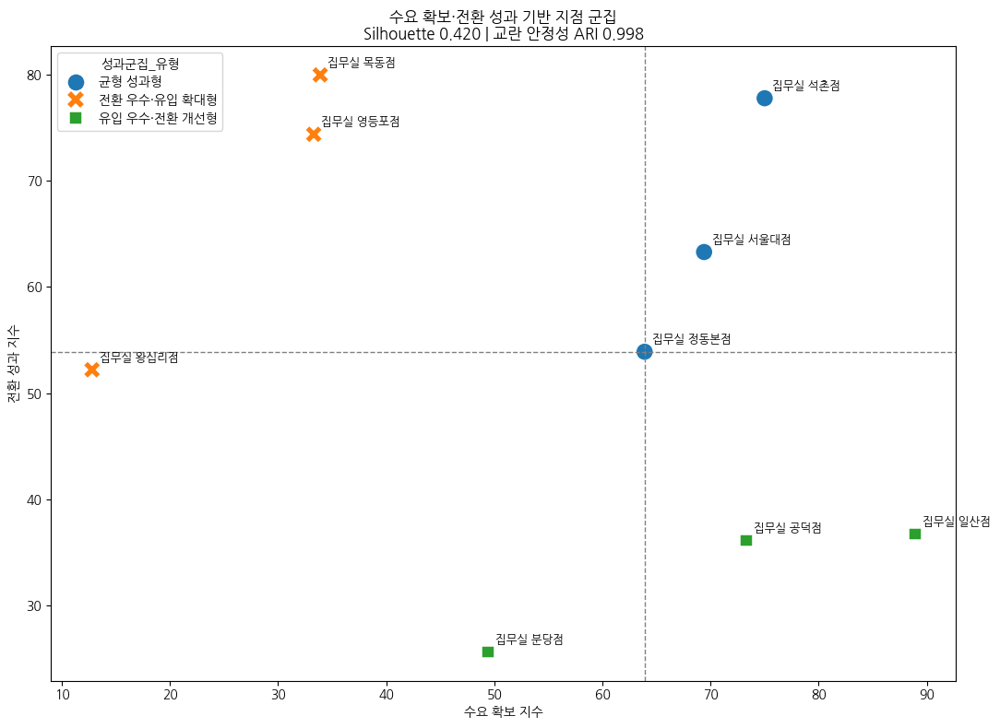

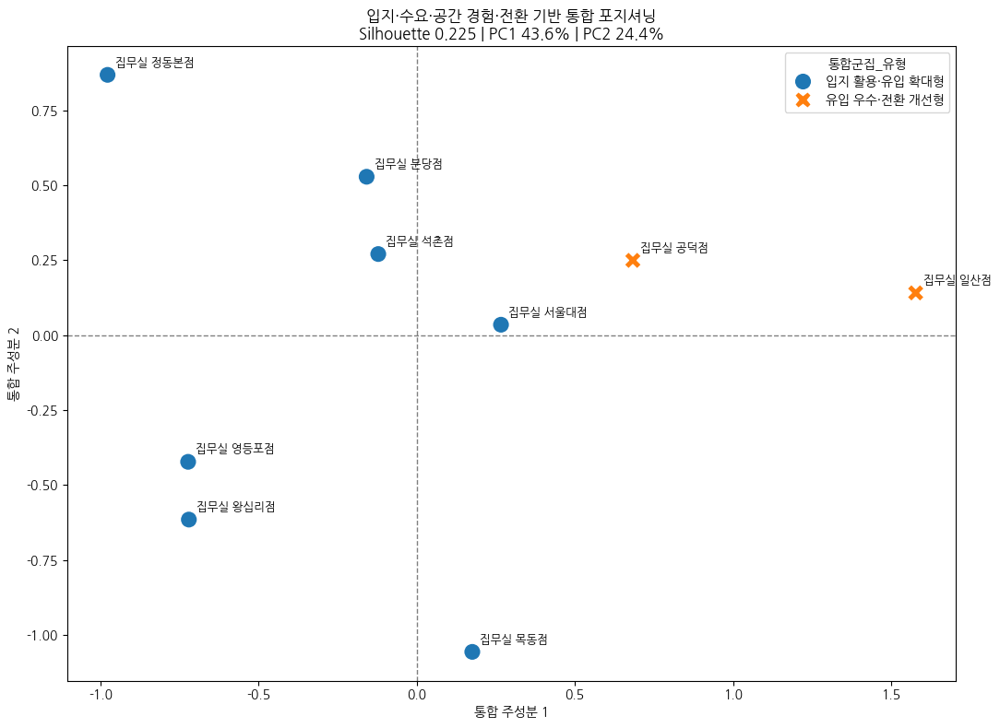

In [ ]:
# 성과 군집과 통합 군집 포지셔닝 시각화

from sklearn.decomposition import PCA

# 1) 수요 확보 × 전환 성과 군집
performance_plot = site_diagnosis[
    [
        "site_name_full",
        "수요확보_지수",
        "전환성과_지수",
        "성과군집_유형",
    ]
].copy()

plt.figure(figsize=(11, 8))

sns.scatterplot(
    data=performance_plot,
    x="수요확보_지수",
    y="전환성과_지수",
    hue="성과군집_유형",
    style="성과군집_유형",
    s=190,
)

for row in performance_plot.itertuples():
    plt.annotate(
        row.site_name_full,
        (row.수요확보_지수, row.전환성과_지수),
        xytext=(6, 7),
        textcoords="offset points",
        fontsize=9,
    )

plt.axvline(
    demand_reference,
    linestyle="--",
    linewidth=1,
    color="grey",
)
plt.axhline(
    conversion_reference,
    linestyle="--",
    linewidth=1,
    color="grey",
)

plt.title(
    "수요 확보·전환 성과 기반 지점 군집\n"
    f"Silhouette {performance_selected['silhouette_score']:.3f} | "
    f"교란 안정성 ARI {performance_stability['mean_ari']:.3f}"
)
plt.xlabel("수요 확보 지수")
plt.ylabel("전환 성과 지수")
plt.tight_layout()
plt.show()


# 2) 입지·수요·공간 경험·전환 4축 PCA
integrated_pca = PCA(n_components=2)
integrated_pca_values = integrated_pca.fit_transform(
    cluster_matrix
)

integrated_pca_df = cluster_input[
    ["site_key", "site_name_full", "통합군집"]
].copy()

integrated_pca_df["PC1"] = integrated_pca_values[:, 0]
integrated_pca_df["PC2"] = integrated_pca_values[:, 1]

integrated_pca_df = integrated_pca_df.merge(
    integrated_cluster_profile[
        ["통합군집", "통합군집_유형"]
    ],
    on="통합군집",
    how="left",
    validate="m:1",
)

plt.figure(figsize=(11, 8))

sns.scatterplot(
    data=integrated_pca_df,
    x="PC1",
    y="PC2",
    hue="통합군집_유형",
    style="통합군집_유형",
    s=180,
)

for row in integrated_pca_df.itertuples():
    plt.annotate(
        row.site_name_full,
        (row.PC1, row.PC2),
        xytext=(6, 7),
        textcoords="offset points",
        fontsize=9,
    )

plt.axhline(0, linestyle="--", linewidth=1, color="grey")
plt.axvline(0, linestyle="--", linewidth=1, color="grey")

plt.title(
    "입지·수요·공간 경험·전환 기반 통합 포지셔닝\n"
    f"Silhouette {best_silhouette_score:.3f} | "
    f"PC1 {integrated_pca.explained_variance_ratio_[0] * 100:.1f}% | "
    f"PC2 {integrated_pca.explained_variance_ratio_[1] * 100:.1f}%"
)
plt.xlabel("통합 주성분 1")
plt.ylabel("통합 주성분 2")
plt.tight_layout()
plt.show()


> **💡 군집화 결과 해석**
>
> **1. 성과 군집**
>
> - 단일 실루엣 최고안은 RobustScaler 기반 2개 군집으로 약 0.450이다.
> - 최종 추천안은 StandardScaler 기반 3개 군집으로 실루엣 0.420, Calinski-Harabasz 9.320, Davies-Bouldin 0.665이다.
> - 3개 군집은 각각 3개 지점으로 균형적이며 균형 성과형, 유입 우수·전환 개선형, 전환 우수·유입 확대형으로 전략을 구분할 수 있다.
> - 알고리즘 간 평균 ARI는 1.000이고 5% 교란 평균 ARI는 0.998로 기본 구조는 안정적이었다.
> - 다만 왕십리점과 분당점은 4분면 세그먼트와 군집 유형이 충돌하는 경계·예외 지점이므로 원시 KPI와 병목 진단을 우선한다.
>
> **2. 4축 통합 군집**
>
> - 입지·수요·공간 경험·전환을 모두 사용한 군집의 실루엣은 약 0.2대로 낮다.
> - 이는 네 축이 하나의 일관된 유형으로 움직이지 않음을 보여주며, 모델 실패라기보다 지점별 성장 병목이 서로 다르다는 결과로 해석한다.
> - 최종 분석 위계는 4분면 세그먼트 → 성과 군집 → 4축 통합 군집·PCA 순으로 유지한다.


=== 성과 군집 최종 검증 ===
최종 추천안은 실루엣 단일 최고안이 아니라 다중 지표·군집 균형성·전략 해석을 함께 고려한 결과입니다.
알고리즘 간 평균 합의도 ARI: 1.000
경계·예외 지점: 집무실 왕십리점, 집무실 분당점


,구분,스케일러,모델,군집수,Silhouette,Calinski_Harabasz,Davies_Bouldin,선택해석
0,단일 실루엣 최고안,RobustScaler,KMeans,2,0.45,8.709,0.734,분리도만 가장 높은 비교안
1,최종 추천안,StandardScaler,KMeans,3,0.42,9.320,0.665,다중 지표·균형성·전략 해석을 함께 고려


,교란수준,교란수준_표시,평균_ARI,중앙값_ARI,최소_ARI
0,0.05,5%,0.998,1.0,0.643
1,0.10,10%,0.952,1.0,0.267
2,0.15,15%,0.882,1.0,0.071
3,0.20,20%,0.797,1.0,0.071


,모델_A,모델_B,ARI
0,KMeans,Agglomerative-ward,1.0
1,KMeans,Agglomerative-complete,1.0
2,KMeans,Agglomerative-average,1.0
3,Agglomerative-ward,Agglomerative-complete,1.0
4,Agglomerative-ward,Agglomerative-average,1.0
5,Agglomerative-complete,Agglomerative-average,1.0


,site_name_full,성과_세그먼트,성과군집_유형,개별_실루엣,군집소속_해석,군집_세그먼트_일치여부,성과군집_해석구분
0,집무실 정동본점,고유입·고전환,균형 성과형,0.295,보통,True,대표 지점
8,집무실 일산점,고유입·저전환,유입 우수·전환 개선형,0.307,보통,True,대표 지점
6,집무실 분당점,저유입·저전환,유입 우수·전환 개선형,0.349,보통,False,경계·예외 지점
1,집무실 왕십리점,저유입·저전환,전환 우수·유입 확대형,0.373,보통,False,경계·예외 지점
2,집무실 공덕점,고유입·저전환,유입 우수·전환 개선형,0.417,소속 비교적 명확,True,대표 지점
7,집무실 목동점,저유입·고전환,전환 우수·유입 확대형,0.436,소속 비교적 명확,True,대표 지점
4,집무실 영등포점,저유입·고전환,전환 우수·유입 확대형,0.484,소속 비교적 명확,True,대표 지점
3,집무실 석촌점,고유입·고전환,균형 성과형,0.503,소속 비교적 명확,True,대표 지점
5,집무실 서울대점,고유입·고전환,균형 성과형,0.613,소속 비교적 명확,True,대표 지점


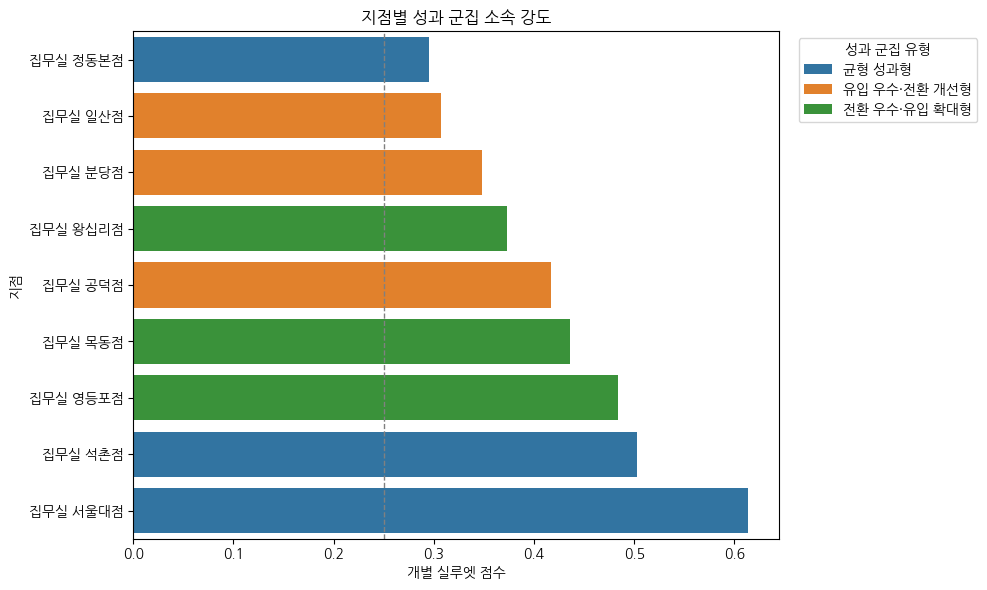

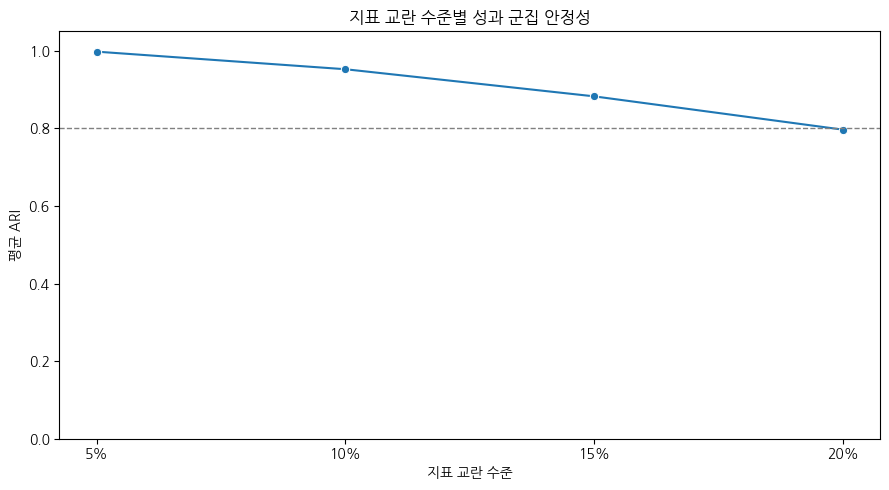

In [ ]:
# 성과 군집의 선택 근거와 지점별 해석 안정성을 추가 검증한다.

from itertools import combinations
from sklearn.metrics import silhouette_samples, adjusted_rand_score

# 1) 단일 실루엣 최고안과 다중 지표 최종 추천안 비교
performance_valid_models = performance_cluster_result["evaluation"].loc[
    ~performance_cluster_result["evaluation"]["has_singleton_cluster"]
].copy()

performance_best_silhouette = (
    performance_valid_models
    .sort_values(
        ["silhouette_score", "calinski_harabasz_score"],
        ascending=[False, False],
    )
    .iloc[0]
)

performance_selection_comparison = pd.DataFrame([
    {
        "구분": "단일 실루엣 최고안",
        "스케일러": performance_best_silhouette["scaler"],
        "모델": performance_best_silhouette["model"],
        "군집수": int(performance_best_silhouette["cluster_count"]),
        "Silhouette": performance_best_silhouette["silhouette_score"],
        "Calinski_Harabasz": performance_best_silhouette["calinski_harabasz_score"],
        "Davies_Bouldin": performance_best_silhouette["davies_bouldin_score"],
        "선택해석": "분리도만 가장 높은 비교안",
    },
    {
        "구분": "최종 추천안",
        "스케일러": performance_selected["scaler"],
        "모델": performance_selected["model"],
        "군집수": int(performance_selected["cluster_count"]),
        "Silhouette": performance_selected["silhouette_score"],
        "Calinski_Harabasz": performance_selected["calinski_harabasz_score"],
        "Davies_Bouldin": performance_selected["davies_bouldin_score"],
        "선택해석": "다중 지표·균형성·전략 해석을 함께 고려",
    },
])

# 2) 지점별 실루엣 점수
performance_cluster_input["개별_실루엣"] = silhouette_samples(
    performance_cluster_result["selected_matrix"],
    performance_cluster_result["selected_labels"],
)

site_diagnosis = site_diagnosis.drop(
    columns=[
        "개별_실루엣",
        "군집소속_해석",
        "군집_세그먼트_일치여부",
        "성과군집_해석구분",
    ],
    errors="ignore",
).merge(
    performance_cluster_input[["site_key", "개별_실루엣"]],
    on="site_key",
    how="left",
    validate="1:1",
)

site_diagnosis["군집소속_해석"] = np.select(
    [
        site_diagnosis["개별_실루엣"].lt(0.25),
        site_diagnosis["개별_실루엣"].lt(0.40),
    ],
    [
        "군집 경계에 가까움",
        "보통",
    ],
    default="소속 비교적 명확",
)

# 3) 군집 유형과 핵심 4분면 진단의 일치 여부
expected_segment_by_cluster = {
    "균형 성과형": "고유입·고전환",
    "유입 우수·전환 개선형": "고유입·저전환",
    "전환 우수·유입 확대형": "저유입·고전환",
    "구조 재검토형": "저유입·저전환",
}

site_diagnosis["군집_세그먼트_일치여부"] = site_diagnosis.apply(
    lambda row: (
        expected_segment_by_cluster.get(row["성과군집_유형"])
        == row["성과_세그먼트"]
    ),
    axis=1,
)

site_diagnosis["성과군집_해석구분"] = np.where(
    (~site_diagnosis["군집_세그먼트_일치여부"])
    | site_diagnosis["개별_실루엣"].lt(0.25),
    "경계·예외 지점",
    "대표 지점",
)

# 4) 교란 수준별 안정성 검증
stability_rows = []

for noise_ratio in [0.05, 0.10, 0.15, 0.20]:
    stability_result = perturbation_cluster_stability(
        performance_cluster_result["raw_matrix"],
        performance_selected["scaler"],
        performance_selected["model"],
        int(performance_selected["cluster_count"]),
        repetitions=300,
        noise_ratio=noise_ratio,
        random_state=42,
    )

    stability_rows.append({
        "교란수준": noise_ratio,
        "교란수준_표시": f"{int(noise_ratio * 100)}%",
        "평균_ARI": stability_result["mean_ari"],
        "중앙값_ARI": stability_result["median_ari"],
        "최소_ARI": stability_result["minimum_ari"],
    })

cluster_stability_table = pd.DataFrame(stability_rows)

# 5) 동일 조건에서 알고리즘이 같은 군집 구조를 재현하는지 확인
consensus_model_names = [
    "KMeans",
    "Agglomerative-ward",
    "Agglomerative-complete",
    "Agglomerative-average",
]

algorithm_label_store = {}

for model_name in consensus_model_names:
    labels, _, _ = fit_cluster_model(
        performance_cluster_result["raw_matrix"],
        performance_selected["scaler"],
        model_name,
        int(performance_selected["cluster_count"]),
    )
    algorithm_label_store[model_name] = labels

algorithm_consensus_rows = []

for model_a, model_b in combinations(consensus_model_names, 2):
    algorithm_consensus_rows.append({
        "모델_A": model_a,
        "모델_B": model_b,
        "ARI": adjusted_rand_score(
            algorithm_label_store[model_a],
            algorithm_label_store[model_b],
        ),
    })

algorithm_consensus_table = pd.DataFrame(algorithm_consensus_rows)
algorithm_consensus_mean_ari = float(
    algorithm_consensus_table["ARI"].mean()
)

boundary_sites = site_diagnosis.loc[
    site_diagnosis["성과군집_해석구분"].eq("경계·예외 지점"),
    "site_name_full",
].tolist()

print("=== 성과 군집 최종 검증 ===")
print(
    "최종 추천안은 실루엣 단일 최고안이 아니라 "
    "다중 지표·군집 균형성·전략 해석을 함께 고려한 결과입니다."
)
print(
    f"알고리즘 간 평균 합의도 ARI: "
    f"{algorithm_consensus_mean_ari:.3f}"
)
print(
    "경계·예외 지점: "
    + (", ".join(boundary_sites) if boundary_sites else "없음")
)

display(performance_selection_comparison.round(3))
display(cluster_stability_table.round(3))
display(algorithm_consensus_table.round(3))
display(
    site_diagnosis[
        [
            "site_name_full",
            "성과_세그먼트",
            "성과군집_유형",
            "개별_실루엣",
            "군집소속_해석",
            "군집_세그먼트_일치여부",
            "성과군집_해석구분",
        ]
    ]
    .sort_values("개별_실루엣")
    .round(3)
)

# 지점별 군집 소속 강도 시각화
individual_silhouette_plot = (
    site_diagnosis[
        ["site_name_full", "개별_실루엣", "성과군집_유형"]
    ]
    .sort_values("개별_실루엣")
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=individual_silhouette_plot,
    x="개별_실루엣",
    y="site_name_full",
    hue="성과군집_유형",
    dodge=False,
)
plt.axvline(0.25, linestyle="--", linewidth=1, color="grey")
plt.title("지점별 성과 군집 소속 강도")
plt.xlabel("개별 실루엣 점수")
plt.ylabel("지점")
plt.legend(title="성과 군집 유형", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# 교란 강도별 군집 안정성 시각화
plt.figure(figsize=(9, 5))
sns.lineplot(
    data=cluster_stability_table,
    x="교란수준",
    y="평균_ARI",
    marker="o",
)
plt.axhline(0.80, linestyle="--", linewidth=1, color="grey")
plt.xticks(
    cluster_stability_table["교란수준"],
    cluster_stability_table["교란수준_표시"],
)
plt.ylim(0, 1.05)
plt.title("지표 교란 수준별 성과 군집 안정성")
plt.xlabel("지표 교란 수준")
plt.ylabel("평균 ARI")
plt.tight_layout()
plt.show()


> **💡 군집 검증 결과**
>
> - 알고리즘 간 평균 합의도 ARI는 1.000이고 20% 교란에서도 평균 ARI 0.797로 군집 구조가 대체로 유지되었다.
> - 왕십리점과 분당점은 군집과 4분면 세그먼트가 충돌하는 경계·예외 지점으로 확인되었다.


In [ ]:
# 지점의 부족한 성과 축을 보완할 수 있는 유사 입지 벤치마크 연결

benchmark_feature_columns = [
    "subway_accessibility_score",
    "subway_flow_score",
    "접근성_지수",
    "생활편의_지수",
    "잠재수요_지수",
]

benchmark_input = (
    site_diagnosis[
        [
            "site_key",
            "site_name_full",
            "성과_세그먼트",
            "수요확보_지수",
            "전환성과_지수",
            "종합경쟁력_지수",
        ]
        + benchmark_feature_columns
    ]
    .copy()
    .reset_index(drop=True)
)

benchmark_input[benchmark_feature_columns] = (
    benchmark_input[benchmark_feature_columns]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(
        benchmark_input[benchmark_feature_columns].median()
    )
)

benchmark_scaler = StandardScaler()
benchmark_matrix = benchmark_scaler.fit_transform(
    benchmark_input[benchmark_feature_columns]
)

benchmark_rows = []

for row_index, row in benchmark_input.iterrows():
    other_indices = benchmark_input.index[
        benchmark_input.index != row_index
    ]

    segment = row["성과_세그먼트"]
    candidate_indices = []
    benchmark_purpose = ""
    benchmark_rule_relaxed = False

    if segment == "고유입·저전환":
        candidate_indices = benchmark_input.index[
            benchmark_input["수요확보_지수"].ge(demand_threshold)
            & benchmark_input["전환성과_지수"].gt(
                row["전환성과_지수"]
            )
            & benchmark_input.index.to_series().ne(row_index)
        ].tolist()
        benchmark_purpose = "고수요를 유지하면서 전환성과가 더 높은 지점"

        if not candidate_indices:
            candidate_indices = benchmark_input.index[
                benchmark_input["전환성과_지수"].gt(
                    row["전환성과_지수"]
                )
                & benchmark_input.index.to_series().ne(row_index)
            ].tolist()
            benchmark_rule_relaxed = True

    elif segment == "저유입·고전환":
        candidate_indices = benchmark_input.index[
            benchmark_input["수요확보_지수"].gt(
                row["수요확보_지수"]
            )
            & benchmark_input["전환성과_지수"].ge(
                conversion_threshold
            )
            & benchmark_input.index.to_series().ne(row_index)
        ].tolist()
        benchmark_purpose = "고전환을 유지하면서 수요확보가 더 높은 지점"

        if not candidate_indices:
            candidate_indices = benchmark_input.index[
                benchmark_input["수요확보_지수"].gt(
                    row["수요확보_지수"]
                )
                & benchmark_input.index.to_series().ne(row_index)
            ].tolist()
            benchmark_rule_relaxed = True

    elif segment == "저유입·저전환":
        candidate_indices = benchmark_input.index[
            benchmark_input["수요확보_지수"].ge(demand_threshold)
            & benchmark_input["전환성과_지수"].ge(
                conversion_threshold
            )
            & benchmark_input.index.to_series().ne(row_index)
        ].tolist()
        benchmark_purpose = "고유입·고전환 지점"

        if not candidate_indices:
            candidate_indices = benchmark_input.index[
                benchmark_input["수요확보_지수"].gt(
                    row["수요확보_지수"]
                )
                & benchmark_input["전환성과_지수"].gt(
                    row["전환성과_지수"]
                )
                & benchmark_input.index.to_series().ne(row_index)
            ].tolist()
            benchmark_rule_relaxed = True

    else:
        candidate_indices = benchmark_input.index[
            benchmark_input["성과_세그먼트"].eq(
                "고유입·고전환"
            )
            & benchmark_input.index.to_series().ne(row_index)
        ].tolist()
        benchmark_purpose = "고유입·고전환 동료 지점"

    if not candidate_indices:
        candidate_indices = other_indices.tolist()
        benchmark_rule_relaxed = True

    distances = {
        candidate_index: np.linalg.norm(
            benchmark_matrix[row_index]
            - benchmark_matrix[candidate_index]
        )
        for candidate_index in candidate_indices
    }

    nearest_index = min(distances, key=distances.get)
    nearest_row = benchmark_input.loc[nearest_index]

    benchmark_rows.append({
        "site_key": row["site_key"],
        "benchmark_site": nearest_row["site_name_full"],
        "benchmark_purpose": benchmark_purpose,
        "benchmark_rule_relaxed": benchmark_rule_relaxed,
        "benchmark_distance": distances[nearest_index],
        "benchmark_competitiveness_gap": (
            nearest_row["종합경쟁력_지수"]
            - row["종합경쟁력_지수"]
        ),
        "benchmark_demand_gap": (
            nearest_row["수요확보_지수"]
            - row["수요확보_지수"]
        ),
        "benchmark_conversion_gap": (
            nearest_row["전환성과_지수"]
            - row["전환성과_지수"]
        ),
    })

site_benchmark_match = pd.DataFrame(benchmark_rows)

site_diagnosis = site_diagnosis.drop(
    columns=[
        "benchmark_site",
        "benchmark_purpose",
        "benchmark_rule_relaxed",
        "benchmark_distance",
        "benchmark_competitiveness_gap",
        "benchmark_demand_gap",
        "benchmark_conversion_gap",
    ],
    errors="ignore",
).merge(
    site_benchmark_match,
    on="site_key",
    how="left",
    validate="1:1",
)

display(
    site_diagnosis
    .sort_values(
        ["성과_세그먼트", "종합경쟁력_지수"],
        ascending=[True, False],
    )[
        [
            "site_name_full",
            "성과_세그먼트",
            "benchmark_site",
            "benchmark_purpose",
            "benchmark_rule_relaxed",
            "benchmark_distance",
            "benchmark_demand_gap",
            "benchmark_conversion_gap",
        ]
    ]
)


,site_name_full,성과_세그먼트,benchmark_site,benchmark_purpose,benchmark_rule_relaxed,benchmark_distance,benchmark_demand_gap,benchmark_conversion_gap
5,집무실 서울대점,고유입·고전환,집무실 석촌점,고유입·고전환 동료 지점,False,2.953181,5.6,14.5
3,집무실 석촌점,고유입·고전환,집무실 서울대점,고유입·고전환 동료 지점,False,2.953181,-5.6,-14.5
0,집무실 정동본점,고유입·고전환,집무실 서울대점,고유입·고전환 동료 지점,False,3.931293,5.5,9.4
2,집무실 공덕점,고유입·저전환,집무실 서울대점,고수요를 유지하면서 전환성과가 더 높은 지점,False,1.938061,-3.9,27.2
8,집무실 일산점,고유입·저전환,집무실 석촌점,고수요를 유지하면서 전환성과가 더 높은 지점,False,2.638416,-13.9,41.1
4,집무실 영등포점,저유입·고전환,집무실 서울대점,고전환을 유지하면서 수요확보가 더 높은 지점,False,1.724706,36.1,-11.1
7,집무실 목동점,저유입·고전환,집무실 서울대점,고전환을 유지하면서 수요확보가 더 높은 지점,False,2.699229,35.5,-16.7
1,집무실 왕십리점,저유입·저전환,집무실 석촌점,고유입·고전환 지점,False,2.314541,62.2,25.6
6,집무실 분당점,저유입·저전환,집무실 석촌점,고유입·고전환 지점,False,2.245531,25.6,52.2


> **💡 결과 해석**
>
> - 공덕·일산은 더 높은 전환을 가진 유사 지점을, 목동·영등포는 더 높은 수요를 가진 지점을 벤치마크로 연결했다.
> - 벤치마크는 입지가 유사하면서 부족한 성과 축을 보완하는 지점으로 선택해 단순 최고점 복제를 피했다.


#### 6-3-5-5. 지점별 최종 진단 및 신규 출점 기준

**🔹 분석 목적**

- 4분면 세그먼트, 병목 격차, 성과 군집, 파레토 역할을 결합해 지점별 최종 진단 카드를 만든다.
- 각 지점의 유입 확대·수익화 개선·구조 재검토·운영 표준화 필요성을 구분할 수 있는 근거를 정리한다.
- 고유입·고전환 지점의 관측 범위를 활용해 출점 전·공간 설계·오픈 후 세 단계의 탐색적 스크리닝 기준을 제시한다.
- 출점 기준은 확정적 성공 공식이 아니며 임대료·경쟁점·건물 가시성·타깃 인구 적합성 등 외부 조건을 별도로 검토한다.


In [ ]:
# 지점별 최종 진단표

site_final_diagnosis_table = (
    site_diagnosis[
        [
            "site_id",
            "site_name_full",
            "성과_세그먼트",
            "성과군집",
            "성과군집_유형",
            "성과군집_해석신뢰도",
            "성과군집_해석구분",
            "군집_세그먼트_일치여부",
            "개별_실루엣",
            "군집소속_해석",
            "성과_파레토_여부",
            "파레토_역할",
            "입지잠재력_지수",
            "수요확보_지수",
            "공간경험_절대점수",
            "공간경험_보정점수",
            "공간경험_지수",
            "전환성과_지수",
            "종합경쟁력_지수",
            "종합경쟁력_평균순위",
            "종합경쟁력_순위범위",
            "종합경쟁력_상위3비율",
            "종합경쟁력_순위해석",
            "representative_site_payment_rate",
            "repeat_visitor_rate",
            "avg_daily_activity_users",
            "avg_daily_activity_users_per_pyeong",
            "입지대비_수요포착격차",
            "경험대비_전환격차",
            "핵심병목",
            "취약경험범주",
            "전환개선_유형",
            "수익화기회_지수",
            "경험개선기회_지수",
            "유입개선_우선순위",
            "전환개선_우선순위",
            "개선대상여부",
            "종합개선_우선순위",
            "segment_stability_rate",
            "benchmark_site",
            "benchmark_purpose",
            "benchmark_demand_gap",
            "benchmark_conversion_gap",
            "세그먼트_전략",
            "리뷰근거_강도",
            "리뷰해석주의",
            "통합군집",
            "통합군집_유형",
            "군집해석주의",
        ]
    ]
    .sort_values(
        ["개선대상여부", "종합개선_우선순위", "종합경쟁력_지수"],
        ascending=[False, False, False],
        na_position="last",
    )
    .reset_index(drop=True)
)

# 지수와 개별 실루엣은 읽기 쉽도록 표시 자릿수를 정리한다.
site_final_diagnosis_table["개별_실루엣"] = (
    site_final_diagnosis_table["개별_실루엣"].round(3)
)

display(site_final_diagnosis_table)


,site_id,site_name_full,성과_세그먼트,성과군집,성과군집_유형,성과군집_해석신뢰도,성과군집_해석구분,군집_세그먼트_일치여부,개별_실루엣,군집소속_해석,...,benchmark_site,benchmark_purpose,benchmark_demand_gap,benchmark_conversion_gap,세그먼트_전략,리뷰근거_강도,리뷰해석주의,통합군집,통합군집_유형,군집해석주의
0,6,집무실 일산점,고유입·저전환,2,유입 우수·전환 개선형,탐색적 활용에 비교적 양호,대표 지점,True,0.307,보통,...,집무실 석촌점,고수요를 유지하면서 전환성과가 더 높은 지점,-13.9,41.1,D1 재방문 유도 | 가격·상품 안내 A/B 테스트 | 결제 CTA·상담 연결 개선,51.600312,통합 리뷰 지표 활용 가능,2,유입 우수·전환 개선형,낮음·핵심 결론 사용 금지
1,4,집무실 왕십리점,저유입·저전환,3,전환 우수·유입 확대형,탐색적 활용에 비교적 양호,경계·예외 지점,False,0.373,보통,...,집무실 석촌점,고유입·고전환 지점,62.2,25.6,저비용 수요 검증부터 재실행 | 편의성 경험 개선 | 지점 역할·타깃·상품 구성 재설계,60.819009,통합 리뷰 지표 활용 가능,1,입지 활용·유입 확대형,낮음·핵심 결론 사용 금지
2,47,집무실 분당점,저유입·저전환,2,유입 우수·전환 개선형,탐색적 활용에 비교적 양호,경계·예외 지점,False,0.349,보통,...,집무실 석촌점,고유입·고전환 지점,25.6,52.2,저비용 수요 검증부터 재실행 | 공간 경험 개선 | 지점 역할·타깃·상품 구성 재설계,18.750000,리뷰 표본이 적어 정성 검토 병행,1,입지 활용·유입 확대형,낮음·핵심 결론 사용 금지
3,17,집무실 공덕점,고유입·저전환,2,유입 우수·전환 개선형,탐색적 활용에 비교적 양호,대표 지점,True,0.417,소속 비교적 명확,...,집무실 서울대점,고수요를 유지하면서 전환성과가 더 높은 지점,-3.9,27.2,D1 재방문 유도 | 가격·상품 안내 A/B 테스트 | 결제 CTA·상담 연결 개선,37.500000,리뷰 표본이 적어 정성 검토 병행,2,유입 우수·전환 개선형,낮음·핵심 결론 사용 금지
4,49,집무실 영등포점,저유입·고전환,3,전환 우수·유입 확대형,탐색적 활용에 비교적 양호,대표 지점,True,0.484,소속 비교적 명확,...,집무실 서울대점,고전환을 유지하면서 수요확보가 더 높은 지점,36.1,-11.1,입지 강점 메시지 재정의 | 인근 기업·주거·대학 제휴 | 검색·지도 노출 확대,17.960089,리뷰 표본이 적어 정성 검토 병행,1,입지 활용·유입 확대형,낮음·핵심 결론 사용 금지
5,5,집무실 목동점,저유입·고전환,3,전환 우수·유입 확대형,탐색적 활용에 비교적 양호,대표 지점,True,0.436,소속 비교적 명확,...,집무실 서울대점,고전환을 유지하면서 수요확보가 더 높은 지점,35.5,-16.7,입지 강점 메시지 재정의 | 인근 기업·주거·대학 제휴 | 검색·지도 노출 확대,46.022727,통합 리뷰 지표 활용 가능,1,입지 활용·유입 확대형,낮음·핵심 결론 사용 금지
6,2,집무실 서울대점,고유입·고전환,1,균형 성과형,탐색적 활용에 비교적 양호,대표 지점,True,0.613,소속 비교적 명확,...,집무실 석촌점,고유입·고전환 동료 지점,5.6,14.5,우수 운영모델 표준화 및 확장 | 혼잡 시간대 운영 최적화 | 추천·장기전환 강화,59.336544,통합 리뷰 지표 활용 가능,1,입지 활용·유입 확대형,낮음·핵심 결론 사용 금지
7,3,집무실 석촌점,고유입·고전환,1,균형 성과형,탐색적 활용에 비교적 양호,대표 지점,True,0.503,소속 비교적 명확,...,집무실 서울대점,고유입·고전환 동료 지점,-5.6,-14.5,우수 운영모델 표준화 및 확장 | 혼잡 시간대 운영 최적화 | 추천·장기전환 강화,70.358589,통합 리뷰 지표 활용 가능,1,입지 활용·유입 확대형,낮음·핵심 결론 사용 금지
8,1,집무실 정동본점,고유입·고전환,1,균형 성과형,탐색적 활용에 비교적 양호,대표 지점,True,0.295,보통,...,집무실 서울대점,고유입·고전환 동료 지점,5.5,9.4,우수 운영모델 표준화 및 확장 | 혼잡 시간대 운영 최적화 | 추천·장기전환 강화,55.917874,통합 리뷰 지표 활용 가능,1,입지 활용·유입 확대형,낮음·핵심 결론 사용 금지


> **✅ 최종 진단 결과**
>
> - 9개 지점에 성과 세그먼트·군집·병목·개선 우선순위·벤치마크·실행 전략을 결합한 최종 진단 카드가 생성되었다.
> - 분당·영등포·공덕은 리뷰 표본이 적어 정량 결과와 사용자 인터뷰·현장 점검을 병행해야 한다.


In [ ]:
# 신규 출점 탐색적 벤치마크 지점 선정

reference_sites = site_diagnosis.loc[
    site_diagnosis["성과_세그먼트"].eq("고유입·고전환")
].copy()

if len(reference_sites) < 2:
    reference_sites = (
        site_diagnosis
        .sort_values(
            ["종합경쟁력_상위3비율", "종합경쟁력_평균순위"],
            ascending=[False, True],
        )
        .head(3)
        .copy()
    )
    reference_rule = "고유입·고전환 지점 부족 → 가중치 민감도 상위 3개"
else:
    reference_rule = "고유입·고전환 지점"

print("신규 출점 벤치마크 선정 기준:", reference_rule)
print(
    "벤치마크 지점:",
    ", ".join(reference_sites["site_name_full"].tolist()),
)

# 우수 지점의 관측 분포를 함께 제공한다.
# 권장 참고값은 높은 것이 좋은 지표의 25% 분위수,
# 낮은 것이 좋은 지표의 75% 분위수로 설정한다.

new_site_criteria_specs = [
    (
        "출점 전",
        "최인접역 거리",
        "nearest_station_distance_m",
        "이하",
        "m",
        False,
    ),
    (
        "출점 전",
        "반경 1km 일평균 지하철 유동량",
        "avg_daily_subway_flow_1km",
        "이상",
        "명/일",
        True,
    ),
    (
        "출점 전",
        "반경 1km 인접역 수",
        "nearby_station_count",
        "이상",
        "개",
        True,
    ),
    (
        "출점 전",
        "교통 접근성 인프라 지수",
        "접근성_지수",
        "이상",
        "점",
        True,
    ),
    (
        "출점 전",
        "생활 편의 인프라 지수",
        "생활편의_지수",
        "이상",
        "점",
        True,
    ),
    (
        "출점 전",
        "잠재 수요 인프라 지수",
        "잠재수요_지수",
        "이상",
        "점",
        True,
    ),
    (
        "공간 설계",
        "공간 경험 보정점수",
        "공간경험_보정점수",
        "이상",
        "점",
        True,
    ),
    (
        "공간 설계",
        "통합 불편 점수",
        "통합불편점수",
        "이하",
        "점",
        False,
    ),
    (
        "오픈 후",
        "운영일당 평균 활동 사용자",
        "avg_daily_activity_users",
        "이상",
        "명/일",
        True,
    ),
    (
        "오픈 후",
        "반복 방문률",
        "repeat_visitor_rate",
        "이상",
        "비율",
        True,
    ),
    (
        "오픈 후",
        "대표 지점 결제율",
        "representative_site_payment_rate",
        "이상",
        "비율",
        True,
    ),
]

new_site_benchmark_rows = []

for (
    stage,
    metric_name,
    column,
    direction,
    unit,
    higher_is_better,
) in new_site_criteria_specs:
    reference_values = pd.to_numeric(
        reference_sites[column],
        errors="coerce",
    ).dropna()

    if higher_is_better:
        criterion_value = reference_values.quantile(0.25)
    else:
        criterion_value = reference_values.quantile(0.75)

    new_site_benchmark_rows.append({
        "평가단계": stage,
        "평가지표": metric_name,
        "원본컬럼": column,
        "판정방향": direction,
        "참고기준값": criterion_value,
        "벤치마크최소": reference_values.min(),
        "벤치마크중앙값": reference_values.median(),
        "벤치마크최대": reference_values.max(),
        "단위": unit,
        "벤치마크지점수": len(reference_values),
        "근거수준": "탐색적·표본 소수",
    })

new_site_benchmark = pd.DataFrame(
    new_site_benchmark_rows
)

display(new_site_benchmark)


신규 출점 벤치마크 선정 기준: 고유입·고전환 지점
벤치마크 지점: 집무실 정동본점, 집무실 석촌점, 집무실 서울대점


,평가단계,평가지표,원본컬럼,판정방향,참고기준값,벤치마크최소,벤치마크중앙값,벤치마크최대,단위,벤치마크지점수,근거수준
0,출점 전,최인접역 거리,nearest_station_distance_m,이하,323.730639,147.256360,286.580049,360.881229,m,3,탐색적·표본 소수
1,출점 전,반경 1km 일평균 지하철 유동량,avg_daily_subway_flow_1km,이상,94503.668557,55338.400000,133668.937113,354314.786008,명/일,3,탐색적·표본 소수
2,출점 전,반경 1km 인접역 수,nearby_station_count,이상,2.500000,2.000000,3.000000,6.000000,개,3,탐색적·표본 소수
3,출점 전,교통 접근성 인프라 지수,접근성_지수,이상,11.250000,7.500000,15.000000,100.000000,점,3,탐색적·표본 소수
4,출점 전,생활 편의 인프라 지수,생활편의_지수,이상,60.100000,56.600000,63.600000,81.800000,점,3,탐색적·표본 소수
5,출점 전,잠재 수요 인프라 지수,잠재수요_지수,이상,37.500000,19.600000,55.400000,57.200000,점,3,탐색적·표본 소수
6,공간 설계,공간 경험 보정점수,공간경험_보정점수,이상,81.253431,76.118125,86.388737,90.094671,점,3,탐색적·표본 소수
7,공간 설계,통합 불편 점수,통합불편점수,이하,24.585351,10.075188,13.224756,35.945946,점,3,탐색적·표본 소수
8,오픈 후,운영일당 평균 활동 사용자,avg_daily_activity_users,이상,1.380793,1.130658,1.630928,1.940513,명/일,3,탐색적·표본 소수
9,오픈 후,반복 방문률,repeat_visitor_rate,이상,0.365010,0.309963,0.420057,0.424744,비율,3,탐색적·표본 소수


> **💡 결과 해석**
>
> - 신규 출점 벤치마크는 고유입·고전환인 정동본점·석촌점·서울대점으로 선정했다.
> - 역 거리·유동량·인프라·공간 경험과 오픈 후 수요·반복 방문·결제율 기준을 제시하되, 3개 지점의 탐색적 범위라는 한계를 명시한다.


### 6-3-6. 통합 결론 및 실행 전략

**🚀 좋은 지점은 접근성이 높은 지점이 아니라, 입지 잠재력을 반복 방문과 결제로 연결하는 지점이다**

| 분석 질문 | 핵심 결과 | 최종 판단 |
| --- | --- | --- |
| 지점별 성과는 실제로 다른가? | 지점별 결제율 차이는 유의했지만 효과크기는 작았고(Cramér’s V=0.075), 보정 후에는 목동점만 약 +7.9%p 높았다. | 단순 결제율 순위보다 수요와 전환을 함께 본 역할 진단이 필요하다. |
| 지하철 접근성이 수요를 만드는가? | 전체기간 유동량과 절대 수요의 상관은 -0.40, 면적당 수요는 0.57이었으나 모두 유의하지 않았다. | 역 거리와 절대 유동량만으로 지점 성과를 설명하거나 출점을 결정하기 어렵다. |
| 어떤 입지 조건이 실제 수요와 연결되는가? | 주말/평일 유동량 비율과 체험 수요 비율은 매우 강한 양의 관계를 보였다(ρ=0.921, 순열 p=0.0015). | 유동량의 크기보다 상권이 움직이는 시간대와 체험 수요 시간대의 적합성이 중요하다. |
| 방문 후 결제를 만드는 공통 행동은 무엇인가? | 모든 지점에서 반복 방문자의 결제율이 1일 방문자보다 4.8~12.7%p 높았고, 지점 통제 공통 OR은 1.41이었다. | 지점 운영의 공통 전환 KPI는 D2 종료 전 두 번째 날짜 방문으로 설정한다. |
| 인프라와 리뷰는 어떻게 활용할 것인가? | 인프라는 3개 상권 유형을 구분했고, 블로그는 방문 전 탐색·기대, 지도 리뷰는 방문 후 실제 경험을 더 강하게 반영했다. | 인프라와 리뷰는 성과 예측식이 아니라 지점 역할·기대·운영 마찰을 진단하는 근거로 활용한다. |
| 통합 모델은 무엇을 기준으로 해석할 것인가? | 4축 통합 군집의 실루엣은 0.225로 낮았지만, 수요·전환 기반 3개 성과 군집은 실루엣 0.420으로 전략 구분이 가능했다. | 4분면 세그먼트 → 성과 군집 → 4축 통합 군집 순으로 해석하고 원시 KPI를 우선한다. |

- 접근성이 높다고 체험 수요와 결제가 자동으로 증가하지 않았다. 정동본점은 지하철 유동량이 가장 높았지만 수요 1위가 아니었고, 일산점은 유동량이 가장 낮아도 운영일당 수요가 가장 높았다.
- 따라서 지점 성과는 입지 잠재력 → 실제 수요 포착 → 반복 방문 → 결제 전환의 단계로 분리해 관리해야 한다.

**🛠️ Segment x Action x KPI 운영안**

| 성과 유형 | 해당 지점 | 핵심 병목 | 우선 실행 | 핵심 KPI |
| --- | --- | --- | --- | --- |
| 고유입·고전환 | 정동본점·석촌점·서울대점 | 성과 유지와 운영 품질 관리 | 균형 성과 운영 표준화, 혼잡 시간대 품질 점검, 성공 운영 모듈 확장 | 반복 방문률, 장기 전환율, 추천률, 혼잡 시간대 만족도 |
| 고유입·저전환 | 일산점·공덕점 | 확보한 수요의 수익화 부족 | D1 재방문 예약, 두 번째 방문 후 상품 안내, 결제 CTA·상담 연결 실험 | D1 재방문률, 최종 결제율, CTA 반응률 |
| 저유입·고전환 | 목동점·영등포점 | 방문 전 유입 포착 부족 | 집중 업무·재택근무 등 고의도 이용 목적 중심 메시지, 소규모 채널별 유입 실험 | 신규 방문자 수, 운영일당 활동 사용자, 채널별 신청·방문 전환율 |
| 저유입·저전환 | 왕십리점·분당점 | 유입과 상품·공간 적합성 동시 점검 | 왕십리는 발견·경로·신청 퍼널 개선, 분당은 타깃·공간 구성·상품 역할 재설계 | 유입 실험 반응률, 반복 방문률, 공간 경험, 결제율 |

**📍 지점별 보완 판단**

1. 일산점·공덕점: 추가 광고보다 이미 확보한 체험 수요를 두 번째 방문과 결제로 연결하는 온보딩 개선이 우선이다.
2. 왕십리점: 높은 입지 잠재력과 생활편의 인프라가 실제 방문으로 이어지지 않으므로 역에서 지점까지의 발견성·경로·신청 퍼널을 점검한다.
3. 분당점: 입지·공간 경험·전환이 함께 낮아 단일 캠페인보다 지점 타깃과 상품 역할을 구조적으로 재검토한다.
4. 정동본점: 고유입·고전환 성과와 별개로 지도 리뷰에서 가격·소음·냄새·협소함·체크인 마찰이 나타나 운영 품질 개선을 병행한다.
5. 석촌점·서울대점: 균형 성과형 지점으로서 반복 방문과 운영 방식을 표준화해 다른 지점의 벤치마크로 활용한다.
6. 목동점·영등포점: 높은 전환 강점을 유지하면서 어떤 메시지와 채널이 고의도 사용자를 더 데려오는지 검증한다.

**🏗️ 신규 출점 3단계 검증안**

| 단계 | 판단 질문 | 적용 기준 |
| --- | --- | --- |
| 출점 전 | 이 상권의 잠재 고객과 실제 이용 시간대가 맞는가? | 역 거리·인접역 수·평일/주말 유동 패턴·인프라 유형과 함께 임대료·경쟁점·가시성·타깃 인구를 검토 |
| 공간 설계 | 방문 전 기대를 실제 경험으로 제공할 수 있는가? | 집중 업무·편의·출입·소음·냄새·좌석 구성 등 지도 리뷰에서 확인된 경험 요소를 설계안에 반영 |
| 오픈 후 | 입지 잠재력이 실제 수요와 전환으로 이어지는가? | 운영일당 활동 사용자 → D2 전 반복 방문률 → 결제율 순으로 단계별 KPI 검증 |

- 신규 출점 벤치마크는 고유입·고전환 지점인 정동본점·석촌점·서울대점의 관측 범위를 참고한다.
- 단, 지점 수가 3개뿐이므로 해당 수치를 하드 필터로 사용하지 않고 후보지 간 비교와 초기 가설 설정에 활용한다.

**🚧 분석 한계**

- 지점 수가 9개로 적어 상관관계와 군집 결과는 탐색적으로 해석해야 하며, 원시 KPI와 현장 맥락을 우선한다.
- 지도 리뷰는 8개 지점 82건으로 표본 차이가 크고 분당점은 리뷰가 없어 지점별 만족도를 확정적으로 비교하기 어렵다.
- 블로그 게시글은 검색·소개·홍보 성격이 섞여 있어 방문 후 만족도보다 방문 전 기대와 탐색 정보로 해석한다.
- 내부 데이터만으로 임대료·경쟁점·건물 가시성·직장인 및 거주 인구 구성·실제 회원 매출을 확인할 수 없으므로 출점 의사결정 전 추가 검증이 필요하다.


# **7\. 핵심 인사이트**

**🧭 작업 요약**
- 세 분석의 결과를 시간·퍼널, 사용자 행동, 지점 관점에서 통합해 무료체험 전환의 공통 성장 구조를 정리한다.
- 전사 공통 KPI와 지점별 실행 원칙을 연결해 최종 운영 방향을 제안한다.

## **7-1. 결론**

> **무료체험의 성과를 결정하는 핵심은 더 많은 신청을 만드는 것이 아니라, 첫 방문을 다음 날짜의 방문으로 이어지게 하고 그 행동을 결제까지 연결하는 것이다.**

이번 프로젝트의 세 가지 분석은 서로 다른 대상을 다루었지만, 최종적으로 하나의 성장 구조를 가리켰다.

| 통합 인사이트 | 의미 |
| --- | --- |
| 수요와 수익화는 별도의 문제이다 | 신청과 방문이 유지되더라도 방문 이후 결제 전환은 약해질 수 있으므로, 유입 KPI만으로 사업 상태를 판단할 수 없다. |
| 사용량보다 이용의 지속성이 중요하다 | 한 번 오래 머무르거나 여러 지점을 둘러보는 것보다, 서로 다른 날짜에 다시 방문하는 행동이 전환과 더 일관되게 연결되었다. |
| 두 번째 날짜 방문은 공통 활성화 지표이다 | 사용자 분석과 지점 분석 모두에서 반복 방문이 결제와 연결되어, 지점 간 공통으로 관리할 수 있는 핵심 행동 KPI가 되었다. |
| 지점 성과는 하나의 점수로 설명되지 않는다 | 좋은 입지라도 수요를 포착하지 못할 수 있고, 수요가 많아도 수익화가 약할 수 있으므로 유입·경험·전환을 분리해 진단해야 한다. |
| 전략은 공통 원칙과 지점별 실행을 함께 가져가야 한다 | 전사적으로는 반복 방문을 공통 목표로 관리하되, 실제 실행은 각 지점의 병목에 따라 유입 포착·온보딩·경험 개선으로 달라져야 한다. |

## **7-2. 프로젝트가 제안하는 성장 관리 체계**

| 고객·지점 단계 | 관리 질문 | 핵심 관리 지표 | 운영 방향 |
| --- | --- | --- | --- |
| 유입 | 목표 고객이 체험 신청까지 도달하는가? | 채널별 신청·방문 전환율 | 상권 시간대와 이용 목적에 맞는 메시지·경로 설계 |
| 첫 경험 | 첫 방문에서 이용 마찰이 발생하지 않는가? | D0 방문 완료율, 출입·공간 불편 지표 | 출입 안내, 좌석·전화·소음 등 초기 경험 개선 |
| 활성화 | 첫 방문이 다음 날짜 이용으로 이어지는가? | D2 종료 전 두 번째 날짜 방문율 | D1 재예약·리마인드·행동 완료형 보상 |
| 수익화 | 반복 이용 의사가 상품 선택으로 이어지는가? | 방문자 중 결제율, CTA 반응률 | 행동 유형별 상품·번들·상담 제안 |
| 락인 | 결제 이후 이용이 지속되는가? | 재이용·갱신·복수 생활권 이용률 | 포터블 멤버십과 단계형 혜택 |
| 확장 | 신규 입지가 같은 성장 구조를 재현하는가? | 수요 확보 → 반복 방문 → 결제 | 입지·경험·행동의 3단계 Gate 검증 |

## **7-3. 최종 제안**

- 공통 전환 레버: 첫 방문 이후 D1에 두 번째 날짜 방문을 유도한다.
- 지점별 운영: 유입 부족 지점과 수익화 부족 지점을 동일한 캠페인으로 관리하지 않는다.
- 검증 방식: 메시지·혜택·상품 제안은 A/B 테스트로 인과효과를 확인한다.
- 확장 방식: 우수 지점 하나를 그대로 복제하지 않고, 수요 포착·반복 방문·전환·경험 관리의 강점을 모듈화한다.

> **결론적으로, 무료체험 운영의 중심을 ‘신청자 수 확대’에서 ‘첫 방문 이후의 다음 행동 설계’로 이동해야 한다.**


# **8\. 한계점 및 향후 과제**

**🚧 작업 요약**
- 현재 데이터와 분석 설계가 설명할 수 있는 범위를 구분하고, 결과 해석 시 주의해야 할 한계를 정리한다.
- 추가 로그 수집과 운영 실험, 비용 데이터를 통해 전환 효과와 수익성을 검증할 후속 과제를 제안한다.

## **8-1. 분석 한계와 보완 방향**

| 한계 | 현재 해석에 미치는 영향 | 향후 필요한 데이터·분석 |
| --- | --- | --- |
| **결제 일시·상품·금액 정보 부재** | 방문 행동과 결제의 정확한 선후관계, 결제까지 걸린 시간, 상품별 전환 차이를 확인할 수 없다. | 결제 이벤트 시각, 상품·가격·할인·환불 정보를 연결해 생존분석과 상품별 전환 퍼널 구축 |
| **관찰 데이터 기반 분석** | 반복 방문이 결제를 유발했는지, 원래 결제 의향이 높은 사용자가 반복 방문했는지 구분하기 어렵다. | D1 재방문 메시지·보상에 대한 무작위 A/B 테스트로 인과효과 검증 |
| **변화점 이후 관측기간이 짧음** | 2023년 9월 이후 결제율 하락이 일시적 현상인지 구조적 변화인지 확정하기 어렵다. | 이후 기간 데이터를 추가하고 가격·상품·CRM·프로모션 변경 이력을 함께 연결 |
| **유입 채널과 이용 목적 정보 부족** | 저녁 이용자와 지점별 고전환 집단이 왜 해당 행동을 보였는지 설명하기 어렵다. | 광고 채널, 검색어, 직업·통근권, 이용 목적, 선택 이유를 수집해 행동 세그먼트와 결합 |
| **지점 수와 리뷰 표본이 제한적임** | 9개 지점의 상관·군집 결과를 일반적인 출점 법칙으로 확대하기 어렵고, 리뷰가 적은 지점의 경험 점수는 불안정하다. | 지점·기간을 확대하고 구조화된 만족도·NPS·불편 사유를 정기 수집해 계층적 지점 모델 검토 |
| **비용·수용력·경쟁 정보 부재** | 방문과 결제 성과는 비교할 수 있으나 지점별 수익성, 혼잡 비용, 출점 ROI를 판단할 수 없다. | 임대료·인건비·좌석 수·가동률·경쟁점·회원 매출을 결합한 단위경제성 분석 |
| **예측 모델의 절대 성능과 외생변수 한계** | 단기 방문 수요의 참고값은 제공하지만 자동 인력·좌석 배치나 장기 수요계획에 바로 적용하기 어렵다. | 프로모션·지역행사·공휴일·날씨 변수 보강, 롤링 재학습과 월별 성능 모니터링 구축 |

## **8-2. 향후 과제 우선순위**

**① 반드시 먼저 할 과제 - 측정과 실험**

- 결제 시점, 상품 노출, CTA 클릭, 상담 연결, 쿠폰 지급·사용 이벤트를 로그로 남긴다.
- 첫 방문을 완료했지만 D1까지 두 번째 방문이 없는 미결제자를 대상으로 재방문 CRM A/B 테스트를 진행한다.
- 1차 성공지표는 D2 종료 전 두 번째 날짜 방문율, 2차 성공지표는 최종 결제율, 가드레일은 혜택 비용·수신거부·노쇼로 설정한다.

**② 다음으로 할 과제 - 고객과 지점의 이유 파악**

- 체험 신청 단계에서 이용 목적과 유입 채널을 수집한다.
- D2 종료 시 미재방문·미결제 사유를 짧은 선택형 설문으로 확보한다.
- 지도 리뷰의 불편 범주를 현장 점검표와 연결하여 지점별 운영 마찰을 정기적으로 관리한다.

**③ 확장 단계 과제 - 수익성과 재현성 검증**

- 결제 이후 갱신·해지·이용 지속 데이터를 연결해 전환율이 아닌 LTV와 유지율까지 평가한다.
- 지점별 수요·반복 방문·결제·비용을 결합하여 전략별 예상 ROI를 비교한다.
- 신규 출점 후보에는 입지·공간 경험·오픈 후 행동 KPI를 순차 적용하고, 기존 9개 지점에서 도출한 기준은 파일럿을 통해 재보정한다.

## **8-3. 최종 검증 과제**

- 본 분석은 어디에 개입해야 하는지를 제안하였다. 다음 단계에서는 실제 실험과 추가 데이터 수집을 통해 그 개입이 얼마나 전환과 수익을 증가시키는지를 검증해야 한다.


# **Appendix.**


## **A-1. 사용 데이터**

**원본 데이터**

| 테이블 | 기간 | 주요 변수 | 분석 활용 |
| --- | --- | --- | --- |
| `trial_register` | 2021-05-01 ~ 2023-12-31 | `user_id`, `trial_date` | 체험 신청자 모집단과 체험 시작일 정의 |
| `trial_payment` | 2021-05-01 ~ 2023-12-31 | `user_id`, `is_payment` | 최종 결제 전환 여부 |
| `trial_visit_info` | 2021-05-01 ~ 2024-01-02 | `user_id`, `site_id`, `date`, 입·퇴실 시각, 체류시간 | 방문일·체류시간·대표 이용 지점 생성 |
| `trial_access_log` | 2021-05-01 ~ 2024-01-02 | `user_id`, `site_id`, `checkin`, 출입 시각 | 체크인 횟수와 방문 시각 보완 |
| `site_area` | 기준정보 | `site_id`, `area_pyeong` | 면적당 수요·지점 효율 지표 |

**외부 데이터**

| 데이터 | 출처 | 주요 활용 |
| --- | --- | --- |
| 사회적 거리두기 시행 현황 | 공공데이터포털·질병관리청 | 분석 기간의 정책 환경 변수 |
| Historical Weather API | Open-Meteo | 지점별 기온·강수 등 기상 변수 |
| 지하철 승하차 및 역사마스터 | 서울열린데이터광장 | 지점 반경 1km 유동량·인접역·평일/주말 패턴 |
| 주변 인프라 POI | 카카오 로컬 API | 교통·생활편의·학습·업무 인프라 지수 |
| 지도 리뷰 | 구글맵·카카오맵 | 방문 후 공간 경험과 운영 불편 탐색 |
| 블로그 게시글 | 네이버 블로그 | 방문 전 탐색 정보·기대·이용 맥락 탐색 |

## **A-2. 기술 스택**

| 구분 | 기술 스택 |
| --- | --- |
| **언어·환경** | Python, Google Colab, Google Drive |
| **데이터 처리** | pandas, NumPy |
| **통계 분석** | SciPy, statsmodels |
| **머신러닝** | scikit-learn, LightGBM, XGBoost, CatBoost |
| **튜닝·해석** | Optuna, SHAP, permutation importance |
| **텍스트 분석** | Kiwi, TF-IDF, CountVectorizer, LDA, Transformers, WordCloud |
| **공간·API** | Folium, Requests, 카카오 로컬 API, Open-Meteo API |
| **시각화** | Matplotlib, Seaborn, Plotly, NetworkX |

## **A-3. 주요 분석 방법**

| 분석 영역 | 적용 방법 |
| --- | --- |
| **결제 구조 변화** | 월별 결제율 변화점 탐지, SSE 비교, 비율 z-test, 퍼널 단계 분해 |
| **방문 수요 예측** | Moving Average Baseline, Random Forest, LightGBM, MAE·RMSE 비교, SHAP 해석 |
| **행동 패턴** | 사분위 비교, 카이제곱·Fisher 검정, K-Means 군집화, 로지스틱 회귀 |
| **다지점 효과 분리** | 방문일수 층화, Mantel–Haenszel 공통 OR, 행동변수 통제, 유사 사용자 매칭 |
| **전환 신호 시점** | D0·D1·D2 랜드마크 모델, PR-AUC·ROC-AUC·Lift 비교 |
| **지점 성과** | Wilson 신뢰구간, 다중검정, Spearman 상관, 순열검정 |
| **상권 유형** | 지표 표준화, PCA, K-Means·계층 군집, 실루엣 평가 |
| **리뷰 분석** | 키워드 사전, 감성·경험 범주화, TF-IDF, LDA, 채널별 역할 비교 |
| **통합 진단** | 수요·전환 세그먼트, 4축 지수, 병목 점수, 파레토 프런티어 |

## **A-4. 핵심 전처리 원칙**

| 원칙 | 처리 기준 |
| --- | --- |
| **원본 보존** | 원본 CSV를 직접 수정하지 않고 복사본에서 전처리 |
| **사용자 키 통일** | `user_uuid`를 `user_id`로 통일하고 앞뒤 공백 제거 |
| **재신청 처리** | 동일 사용자의 여러 신청 중 가장 최근 신청일 1건을 기준으로 연결 |
| **중복 처리** | 모든 컬럼이 동일한 완전 중복만 제거하고 실제 복수 행동 가능 기록은 보존 |
| **시간대 통일** | 출입 로그 원본 시각을 보존하고 KST 변환 변수를 별도 생성 |
| **결측 보완** | 동일 사용자·지점·날짜의 출입 로그가 있을 때만 방문 입·퇴실 시각 보완 |
| **일별 방문 통합** | 동일 사용자·지점·날짜 기록은 최초 입실·최종 퇴실·체류시간 합계로 요약 |
| **체험기간 정의** | 분석은 D0~D2 행동만 사용하고 D3는 품질 점검용으로 보존 |
| **로그 불일치 처리** | 입·퇴실 수가 맞지 않아도 임의 삭제·추가하지 않고 품질 플래그로 관리 |
| **데이터 누수 방지** | 각 랜드마크 시점까지 관측 가능한 행동만 모델 입력값으로 사용 |

## **A-5. 주요 지표 정의**

| 지표 | 정의 |
| --- | --- |
| **방문 활성화** | 체험기간 D0~D2 내 1회 이상 실제 방문 |
| **반복 방문** | D0~D2 내 서로 다른 날짜에 2일 이상 방문 |
| **다지점 이용** | D0~D2 내 서로 다른 지점 2곳 이상 이용 |
| **결제 전환율** | 분석 대상 사용자 중 `is_payment=1` 비율 |
| **방문 후 결제율** | 실제 방문자 중 결제자 비율 |
| **운영일당 활동 사용자** | 지점 관측 기간의 운영일 기준 일평균 활동 사용자 수 |
| **대표 이용 지점** | 체험기간 중 사용자의 핵심 이용 행동이 가장 많이 나타난 지점 |
| **공간 경험 지표** | 지도 리뷰의 경험 범주·감성 정보를 표본 차이를 고려해 보정한 탐색적 지표 |

## **A-6. 재현성 및 해석 주의사항**

- 외부 API와 웹 리뷰 결과는 호출 시점·검색 결과·플랫폼 정책에 따라 달라질 수 있다.
- API 키와 개인 인증정보는 노트북에 포함하지 않으며, 실행 환경에서 별도로 설정해야 한다.
- 난수 기반 분석은 random_state를 고정해 재현성을 확보하였다.
- 지점 수가 적은 분석에서는 통계적 유의성만으로 결론을 확정하지 않고 효과크기·원시 KPI·현장 맥락을 함께 해석하였다.
- 행동·지점 점수는 탐색적 의사결정 보조지표이며, 실제 운영 적용 전 실험과 현장 검증이 필요하다.

## **A-7. 참고 문헌**

1. 「공유오피스 이용자가 인식하는 공유오피스 주요 서비스품질에 대한 연구」 (2020)  
   https://www.kci.go.kr/kciportal/landing/article.kci?arti_id=ART0025907
2. 「공유오피스 선택속성의 품질 분류 및 선택속성이 신뢰, 장기이용의도에 미치는 영향」 (2020)  
   https://www.earticle.net/Article/A386493
3. *Coworking spaces: An overview and research agenda* (2022)  
   https://www.sciencedirect.com/science/article/pii/S0048733321002390
4. *Identifying and prioritizing coworking member needs* (2024)  
   https://www.emerald.com/jcre/article/26/4/309/1238377/
5. *Choosing coworking spaces: Exploring the preferences of coworking space members* (2025)  
   https://www.sciencedirect.com/science/article/pii/S0264275125002914
6. *Space-sharing experiences in hospitality: A psychological needs perspective* (2025)  
   https://www.emerald.com/ijchm/article/37/13/252/1310575/